# noisy_cost_comparison — 物理誤り率を与えたときの、Kobayashi 方式（D4 code switching）と Litinski 方式（15-to-1 蒸留）の資源比較

**問い**：物理誤り率 $p$ と要求される出力誤り $\varepsilon_{\rm target}$ が与えられたとき、論理 $T$ 魔法状態 1 個を作るのに、どちらの方式が少ない時空間体積（物理量子ビット × 時間ステップ）で済むか。

**このノートがすること**（重い計算はしない。数分で終わる）
1. **Kobayashi 方式**：`D4_noisy_simulation.ipynb` の回路レベル・モンテカルロの結果 $\varepsilon_K(d,p)$（非 Clifford 回路を Takada らの方法でシミュレーション）を読み込み、$d$ と $p$ への依存のモデルを当てはめる（不確かさはブートストラップ）。資源は同じ回路から数える。
2. **Litinski 方式**：Litinski（2019）の公開コードの誤り予算（本研究で再実装し、公開値 8 件を再現：`validation.ipynb` N6）を、*A Game of Surface Codes*（GoSC）Sec. 3 の 11-tile 15-to-1 と 176-tile 225-to-1、および Litinski（2019）の最適化された蒸留器に適用する。パッチの論理誤り率 $p_L(d,p)$ は同じ雑音パラメータの表面符号シミュレーションで較正する。
3. 同じ単位（物理量子ビット × 時間ステップ、全ゲート 1 時間ステップ）で比較する。

**比較の非対称性**：Kobayashi 側は切り替えを含む回路全体のモンテカルロ、Litinski 側は「較正した表面符号メモリの誤り率」を入れた解析的な誤り予算モデル（格子手術や蒸留器全体を回路レベルでシミュレーションしたものではない）。どちらにも計上していない費用がある（Kobayashi：FSC → 通常パッチの変換、Litinski：状態注入、両方：古典処理の待ち時間）。比較は「各方式の符号の中で 1 個の $T$ 状態を作る費用」であり、共通の出力パッチへ受け渡す費用までは含まない。

**雑音のシナリオ**：A＝アイドル雑音あり（$p_{\rm idle}=p$）、B＝アイドル雑音なし（Takada らと同じ）。ゲート・初期化・測定の誤りはどちらも $p$。

**結果の位置づけ**：Kobayashi 方式の数値は**本研究で構成した回路・測定スケジュール・復号器**（[KZH] が引用する JIT decoder [Dav] は参照できなかった）での値であり、Kobayashi 方式一般の性能ではない。手法・仮定の詳細は `docs/methods.md`。

In [1]:
# ==== 環境設定（Google Colab / ローカル共通）====
# このノートブックは単独で実行できる（共通コードは下に埋め込まれており、他のファイルを読み込まない）。
# 出力（results/, figures/）はこのランタイムの作業ディレクトリに保存される。Colab ではランタイム終了で
# 消えるので、残したい場合は Google Drive を使う：
#   from google.colab import drive; drive.mount('/content/drive')
#   os.makedirs('/content/drive/MyDrive/D4_vs_MSD', exist_ok=True); os.chdir('/content/drive/MyDrive/D4_vs_MSD')
import os, sys, subprocess, json
IN_COLAB = 'google.colab' in sys.modules
RESULTS, FIGURES = 'results', 'figures'
os.makedirs(RESULTS, exist_ok=True); os.makedirs(FIGURES, exist_ok=True)
SEED = 20261024
print('cwd =', os.getcwd(), '| Colab =', IN_COLAB)

cwd = /home/user/2026-10-24_StudyWithClaude | Colab = False


In [2]:
# ==== 外部ライブラリ（Colab に無いものだけをインストール）====
import importlib.util
for _mod, _pkg in [('stim', 'stim'), ('pymatching', 'pymatching'), ('mpmath', 'mpmath'), ('scipy', 'scipy'),
                   ('sympy', 'sympy'), ('pandas', 'pandas'), ('matplotlib', 'matplotlib')]:
    if importlib.util.find_spec(_mod) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', _pkg], check=True)
import numpy as np, pandas as pd, scipy, stim, pymatching, mpmath
print('numpy', np.__version__, '| scipy', scipy.__version__, '| stim', stim.__version__,
      '| pymatching', pymatching.__version__, '| mpmath', mpmath.__version__)

numpy 2.5.3 | scipy 1.18.1 | stim 1.16.0 | pymatching 2.4.0 | mpmath 1.3.0


In [3]:
# ==== 図のスタイル（明るい背景・細い線・識別は色＋線種＋マーカー）====
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True,
                     'grid.color': '#e4e3df', 'grid.linewidth': 0.8, 'lines.linewidth': 2,
                     'lines.markersize': 7, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 10, 'legend.frameon': False})
C_KOB, C_LIT, C_AUX = '#2a78d6', '#eb6834', '#1baf7a'     # categorical slots 1,2,3 (validated palette)
C_R, C_G, C_B = '#e34948', '#008300', '#2a78d6'            # colours of the r, g, b qubit species

## 共通ライブラリ（埋め込み・関数定義のみ）
Google Colab ではノートブックごとに別のランタイムで実行されるため、他のファイルを読み込まずに済むよう、共通コードをこのノートブックに埋め込んでいる（各ノートの共通コードは同一のソースから自動生成されており、内容は一致する）。
**このセクションは上から順に実行するだけでよく、編集する必要はない**（Colab では見出しの左の三角で折りたためる）。

### 共通ライブラリ（F2 線形代数・ゲート／ガジェット・スケジューラ・Clifford+T 分解・計数ルール R1–R3）

In [4]:
"""common_lib: F2 linear algebra, gate/gadget model, scheduler, decompositions, cost model rules."""
import itertools, math
import numpy as np
from collections import Counter, defaultdict

In [5]:
# ---------------------------------------------------------------- F2 algebra
def f2_rref(M):
    """Row-reduce a uint8 matrix over F2. Returns (R, pivot_cols)."""
    M = (np.array(M, dtype=np.uint8) & 1).copy()
    rows, cols = M.shape
    piv = []
    r = 0
    for c in range(cols):
        if r >= rows:
            break
        nz = np.nonzero(M[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        if p != r:
            M[[r, p]] = M[[p, r]]
        others = np.nonzero(M[:, c])[0]
        others = others[others != r]
        if len(others):
            M[others] ^= M[r]
        piv.append(c)
        r += 1
    return M[:r], piv


def f2_rank(M):
    if len(M) == 0:
        return 0
    return len(f2_rref(M)[1])


def f2_nullspace(M, n=None):
    """Basis (rows) of {x : M x = 0} over F2."""
    M = np.array(M, dtype=np.uint8)
    if M.size == 0:
        return np.eye(n, dtype=np.uint8)
    n = M.shape[1]
    Rm, piv = f2_rref(M)
    free = [c for c in range(n) if c not in set(piv)]
    basis = []
    for f in free:
        v = np.zeros(n, dtype=np.uint8)
        v[f] = 1
        for i, p in enumerate(piv):
            if Rm[i, f]:
                v[p] = 1
        basis.append(v)
    return np.array(basis, dtype=np.uint8).reshape(len(basis), n)


def f2_in_rowspace(Rref, piv, v):
    """Is v in the row space of the RREF matrix Rref (pivots piv)?"""
    v = np.array(v, dtype=np.uint8) & 1
    w = v.copy()
    for i, p in enumerate(piv):
        if w[p]:
            w ^= Rref[i]
    return not w.any()


def f2_solve(A, b):
    """Solve x A = b (x row vector, A rows = generators). Returns x or None."""
    A = np.array(A, dtype=np.uint8)
    m, n = A.shape
    aug = np.concatenate([A, np.eye(m, dtype=np.uint8)], axis=1)
    Rm, piv = f2_rref(aug)
    w = np.concatenate([np.array(b, dtype=np.uint8) & 1, np.zeros(m, dtype=np.uint8)])
    for i, p in enumerate(piv):
        if p >= n:
            break
        if w[p]:
            w ^= Rm[i]
    if w[:n].any():
        return None
    return w[n:]




import itertools
from collections import Counter, defaultdict

ARITY = {'INIT_X': 1, 'INIT_Z': 1, 'MEAS_X': 1, 'MEAS_Z': 1, 'H': 1, 'X': 1, 'Z': 1, 'S': 1, 'SDG': 1,
         'T': 1, 'TDG': 1, 'CNOT': 2, 'CZ': 2, 'CS': 2, 'CSDG': 2, 'CCZ': 3}
NONCLIFFORD = {'T', 'TDG', 'CS', 'CSDG', 'CCZ'}

In [6]:
# ------------------------------------------------------------------ minimum-weight logical (MILP)
def min_weight_odd(Hc, lvec, cols):
    """min |x| over x in F2^cols with Hc x = 0 and lvec . x = 1 (exact MILP, HiGHS)."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    H = np.array(Hc, dtype=float)[:, cols]
    H = H[np.any(H, axis=1)]
    l = np.array(lvec, dtype=float)[cols]
    m, n = H.shape
    # variables: x (n, binary), y (m, integer), z (1, integer)
    nv = n + m + 1
    c = np.concatenate([np.ones(n), np.zeros(m + 1)])
    A1 = np.concatenate([H, -2 * np.eye(m), np.zeros((m, 1))], axis=1)
    A2 = np.concatenate([l[None, :], np.zeros((1, m)), -2 * np.ones((1, 1))], axis=1)
    cons = [LinearConstraint(A1, 0, 0), LinearConstraint(A2, 1, 1)]
    integrality = np.ones(nv)
    ub = np.concatenate([np.ones(n), np.full(m + 1, np.inf)])
    res = milp(c, constraints=cons, integrality=integrality, bounds=Bounds(np.zeros(nv), ub))
    assert res.status == 0, res.message
    x = np.round(res.x[:n]).astype(np.uint8)
    out = np.zeros(len(lvec), dtype=np.uint8)
    out[cols] = x
    return int(x.sum()), out

In [7]:
# ------------------------------------------------------------------ gadgets
def pauli_check_gadget(anc, xq=(), zq=()):
    """Measure X(xq) Z(zq) with ancilla anc (standard CNOT circuit)."""
    g = [('INIT_X', anc)]
    g += [('CNOT', anc, q) for q in sorted(xq)]           # ancilla controls -> X on data
    g += [('CZ', anc, q) for q in sorted(zq)]             # controlled Z on data
    g += [('MEAS_X', anc)]
    return g


def z_check_gadget(anc, zq):
    g = [('INIT_Z', anc)] + [('CNOT', q, anc) for q in sorted(zq)] + [('MEAS_Z', anc)]
    return g


def clifford_x_gadget(anc, parts):
    """Measure a product of X-type Clifford operators S = S_1 S_2 ... with
    S_k = X(s_k) prod CZ(pairs_k): ancilla |+>, controlled-S (= CNOTs from anc and
    CCZ(anc,i,j) for each CZ pair; rightmost factor first), measure X.
    parts: list of (xqubits, czpairs) in operator order S_1 S_2 ..."""
    g = [('INIT_X', anc)]
    for xq, pairs in reversed(parts):
        g += [('CCZ', anc, i, j) for (i, j) in pairs]      # CZ part acts first within S_k
        g += [('CNOT', anc, q) for q in sorted(xq)]
    g += [('MEAS_X', anc)]
    return g

In [8]:
# ------------------------------------------------------------------ scheduling
def asap_layers(gates):
    """Greedy ASAP layering of a gate list respecting qubit order (no reordering of gates that
    share a qubit).  Returns list of layers (lists of gates)."""
    ready = defaultdict(int)
    layers = []
    for gt in gates:
        qs = gt[1:]
        t = max(ready[q] for q in qs)
        while len(layers) <= t:
            layers.append([])
        layers[t].append(gt)
        for q in qs:
            ready[q] = t + 1
    return layers


def gadget_support(gad):
    s = set()
    for gt in gad:
        s |= set(gt[1:])
    return s


def disjoint_groups(gadgets):
    """Greedy colouring: partition gadgets so that gadgets in a group touch disjoint qubits.
    Measurements within a group are then exactly simultaneous and the sequential-group
    schedule is valid for commuting (on the relevant subspace) generators."""
    groups = []          # list of (used_qubits, [gadgets])
    order = sorted(range(len(gadgets)), key=lambda i: -len(gadget_support(gadgets[i])))
    for i in order:
        sup = gadget_support(gadgets[i])
        for used, members in groups:
            if not (used & sup):
                used |= sup
                members.append(gadgets[i])
                break
        else:
            groups.append((set(sup), [gadgets[i]]))
    return [m for _, m in groups]


def layer_duration(layer, dur):
    return max(dur[g[0]] for g in layer)


def circuit_time(layers, dur):
    return sum(layer_duration(l, dur) for l in layers)


def round_schedule(gadgets, dur):
    """Upper-bound schedule of one round: disjoint groups executed sequentially, each group
    ASAP-layered.  Returns dict with depth (layers), time (weighted by dur), groups."""
    groups = disjoint_groups(gadgets)
    depth = 0
    time = 0
    for grp in groups:
        gl = asap_layers([gt for gad in grp for gt in gad])
        depth += len(gl)
        time += circuit_time(gl, dur)
    return {'groups': len(groups), 'depth_ub': depth, 'time_ub': time}


def round_lower_bound(gadgets, dur):
    """Lower bound on the duration of one round: every qubit executes its gates sequentially,
    so time >= max_q sum of durations of gates acting on q."""
    busy = defaultdict(float)
    cnt = defaultdict(int)
    for gad in gadgets:
        for gt in gad:
            for q in gt[1:]:
                busy[q] += dur[gt[0]]
                cnt[q] += 1
    return {'depth_lb': max(cnt.values()), 'time_lb': max(busy.values())}


def gate_counts(gates):
    c = Counter(g[0] for g in gates)
    return dict(c)

In [9]:
# ------------------------------------------------------------------ decompositions
# Explicit Clifford+T decompositions (verified numerically in the validation notebook).
def ccz_to_clifford_t(a, b, c):
    """CCZ with 7 T/T^dag and 6 CNOT (standard Toffoli decomposition, Nielsen & Chuang Fig. 4.9,
    with the target Hadamards removed)."""
    return [('CNOT', b, c), ('TDG', c), ('CNOT', a, c), ('T', c), ('CNOT', b, c), ('TDG', c),
            ('CNOT', a, c), ('T', b), ('T', c), ('CNOT', a, b), ('T', a), ('TDG', b), ('CNOT', a, b)]


def cs_to_clifford_t(a, b):
    """CS = diag(1,1,1,i) = T_a T_b CNOT(a,b) T^dag_b CNOT(a,b)."""
    return [('T', a), ('T', b), ('CNOT', a, b), ('TDG', b), ('CNOT', a, b)]


def csdg_to_clifford_t(a, b):
    return [('TDG', a), ('TDG', b), ('CNOT', a, b), ('T', b), ('CNOT', a, b)]


def decompose(gates):
    out = []
    for g in gates:
        if g[0] == 'CCZ':
            out += ccz_to_clifford_t(*g[1:])
        elif g[0] == 'CS':
            out += cs_to_clifford_t(*g[1:])
        elif g[0] == 'CSDG':
            out += csdg_to_clifford_t(*g[1:])
        else:
            out.append(g)
    return out


DUR_UNIT = {k: 1 for k in ARITY}            # every primitive = 1 time unit (ASSUMPTION, parametrised)

In [10]:
# ------------------------------------------------- commuting-class scheduler
DIAG_GATES = {'CZ', 'CCZ', 'CS', 'CSDG', 'T', 'TDG', 'S', 'SDG', 'Z'}


def gate_roles(gt):
    """Per-qubit role of an entangling/1q unitary: 'Z' (diagonal in Z basis), 'X' (X-type)."""
    name = gt[0]
    if name in DIAG_GATES:
        return {q: 'Z' for q in gt[1:]}
    if name == 'CNOT':
        return {gt[1]: 'Z', gt[2]: 'X'}
    if name == 'X':
        return {gt[1]: 'X'}
    return {q: '?' for q in gt[1:]}      # H, INIT, MEAS: never shared between gadgets


def gadget_roles(gad):
    roles = {}
    for gt in gad:
        for q, r in gate_roles(gt).items():
            if roles.get(q, r) != r:
                roles[q] = '?'
            else:
                roles[q] = r
    return roles


def commuting_classes(gadgets, n_orders=6, seed=0):
    """Best (fewest classes) of several greedy colourings (different gadget orders)."""
    import random
    best = None
    orders = [list(range(len(gadgets)))]
    orders.append(sorted(orders[0], key=lambda i: tuple(sorted(set(gadget_roles(gadgets[i]).values())))))
    rnd = random.Random(seed)
    for _ in range(n_orders):
        o = orders[0][:]
        rnd.shuffle(o)
        orders.append(o)
    for o in orders:
        cl = _commuting_classes_greedy([gadgets[i] for i in o])
        if best is None or len(cl) < len(best):
            best = cl
    return best


def _commuting_classes_greedy(gadgets):
    """Greedy colouring of the gadget conflict graph.  Two gadgets are compatible if on every
    shared qubit both act with the same role ('Z' or 'X'); then all their gates commute and the
    joint circuit is equivalent to measuring them one after another (sufficient condition)."""
    roles = [gadget_roles(g) for g in gadgets]
    classes = []     # list of (role_map, [idx])
    for i, rm in enumerate(roles):
        placed = False
        for cmap, members in classes:
            ok = all(cmap.get(q, r) == r and r != '?' for q, r in rm.items() if q in cmap)
            if ok:
                for q, r in rm.items():
                    cmap[q] = r
                members.append(i)
                placed = True
                break
        if not placed:
            classes.append((dict(rm), [i]))
    return [[gadgets[i] for i in m] for _, m in classes]


def class_layers(gadgets):
    """Layering of one commuting class: init layer, greedy layering of the (mutually commuting)
    entangling gates, measurement layer."""
    inits = [g for gad in gadgets for g in gad if g[0].startswith('INIT')]
    meas = [g for gad in gadgets for g in gad if g[0].startswith('MEAS')]
    body = [g for gad in gadgets for g in gad if not (g[0].startswith('INIT') or g[0].startswith('MEAS'))]
    # greedy: most-constrained gates first
    body = sorted(body, key=lambda g: -len(g))
    layers = []
    busy = []
    for g in body:
        qs = set(g[1:])
        for li, b in enumerate(busy):
            if not (b & qs) and layers[li][0][0] == g[0]:     # keep one gate type per layer
                b |= qs
                layers[li].append(g)
                break
        else:
            busy.append(set(qs))
            layers.append([g])
    return ([inits] if inits else []) + layers + ([meas] if meas else [])


def round_schedule_classes(gadgets, dur):
    classes = commuting_classes(gadgets)
    depth = 0
    time = 0
    for c in classes:
        ls = class_layers(c)
        depth += len(ls)
        time += circuit_time(ls, dur)
    return {'classes': len(classes), 'depth_ub': depth, 'time_ub': time}


import math
from collections import Counter

SOURCE_LIT = 'literature'
SOURCE_COUNT = 'counted (explicit circuit)'
SOURCE_ASSUME = 'assumption (parameter)'
SOURCE_UNRES = 'unresolved (excluded / illustrative)'

DEFAULT_PARAMS = dict(
    kappa0=1.0,      # FSC |+_L> preparation rounds = ceil(kappa0*d)   [ASSUMPTION; Kobayashi: not specified]
    kappa_in=1.0,    # switch-in rounds            = ceil(kappa_in*d)  [ASSUMPTION; Kobayashi: O(d)]
    kappa_out=1.0,   # FSC EC rounds after return  = ceil(kappa_out*d) [ASSUMPTION; Kobayashi: O(d)]
    tau_rounds=1.0,  # Litinski: 1 time step = tau_rounds*d code cycles [LITERATURE: d cycles]
    t_inj_FT=6,      # Litinski App. A (Li's injection): 3 + 3 code cycles, d-independent [LITERATURE]
    t_inj_NL=1,      # noiseless-minimal injection: 1 round [ASSUMPTION]
)


def rounds_for(model, kappa, d):
    if model == 'NL_min':
        return 1
    return int(math.ceil(kappa * d))

In [11]:
# ----------------------------------------------------------------- summaries
def summarize(rows):
    tot = Counter()
    for r in rows:
        for k, v in r['gates'].items():
            tot[k] += v
    peak = max(r['qubits'] for r in rows)
    rounds = sum(r['rounds'] for r in rows)
    tl = sum(r['time_lb'] for r in rows if r['time_lb'] is not None)
    tu = sum(r['time_ub'] for r in rows if r['time_ub'] is not None)
    v_round = sum(r['qubits'] * r['rounds'] for r in rows)
    v_tl = sum(r['qubits'] * r['time_lb'] for r in rows if r['time_lb'] is not None)
    v_tu = sum(r['qubits'] * r['time_ub'] for r in rows if r['time_ub'] is not None)
    nonclif = {k: v for k, v in tot.items() if k in NONCLIFFORD}
    tcount = 7 * tot.get('CCZ', 0) + 3 * (tot.get('CS', 0) + tot.get('CSDG', 0)) + tot.get('T', 0) + tot.get('TDG', 0)
    return dict(peak_qubits=peak, rounds=rounds, time_lb=tl, time_ub=tu, V_qubit_round=v_round,
                V_qubit_time_lb=v_tl, V_qubit_time_ub=v_tu, V_peak_x_rounds_UB=peak * rounds,
                gates=dict(tot), nonclifford=nonclif, T_count_if_decomposed=tcount)


def uncounted_costs(protocol, comparison):
    """Costs that are known to exist but are not included in the totals (listed, never summed as 0)."""
    out = [('classical decoding / control latency', 'both comparisons, both protocols')]
    if protocol == 'Kobayashi_D4':
        out.append(('JIT-decoder classical processing', 'not modelled'))
        if comparison == 'B':
            out.append(('FSC -> standard rotated surface-code patch conversion', 'UNRESOLVED: no protocol constructed'))
    else:
        out.append(('twist-based Z_m (x) Y_0 seam checks between |m> and |0>', 'O(d) measurement qubits, not constructed'))
    return out

In [12]:
# ------------------------------------------------------------------ table helpers
def jsonify_columns(df, cols=('gates', 'nonclifford')):
    """Store dict-valued columns as JSON strings (same format as the saved CSV files)."""
    import json
    for col in cols:
        if col in df.columns:
            df[col] = df[col].apply(lambda g: g if isinstance(g, str) else json.dumps({k: float(v) for k, v in g.items()}))
    return df


def identify_polynomial(values, npts=4):
    """Interpolate a polynomial in d through the first npts points (degree <= npts-1) and report
    whether it reproduces ALL given points exactly.  values: dict d -> integer.  Returns (expr, ok)."""
    import sympy
    x = sympy.Symbol('d')
    ds = sorted(values)
    if len(ds) <= npts:
        return None, False
    p = sympy.interpolate([(dd, int(round(values[dd]))) for dd in ds[:npts]], x)
    ok = all(sympy.nsimplify(p.subs(x, dd) - int(round(values[dd]))) == 0 for dd in ds)
    return sympy.expand(p), ok

### D4 ライブラリ（境界付き D4 符号・transversal $U$・code switching・疎状態シミュレータ・資源モデル）

In [13]:
"""d4_lib: D4 Clifford stabilizer code (Kobayashi-Zhu-Hsin) on the bounded square lattice, transversal U, code switching, resource model."""
import itertools, cmath
import numpy as np
from collections import Counter

R, G, B = 0, 1, 2
CNAME = "rgb"

In [14]:
# ------------------------------------------------- phase-shift operators
class PSOp:
    """Operator  O |x> = (-1)^{f(x)} |x + s>  on n qubits (computational basis x in F2^n).

    f(x) = const + sum_{i in lin} x_i + sum_{(i,j) in quad} x_i x_j   (mod 2), i<j.
    X-type Clifford stabilizers of the D4 code, Pauli X/Z strings and products
    thereof all have this form.  Composition rule (A o B)|x> = A B |x>:
        s = s_A + s_B,   f(x) = f_B(x) + f_A(x + s_B).
    """
    __slots__ = ("s", "lin", "quad", "const")

    def __init__(self, s=frozenset(), lin=frozenset(), quad=frozenset(), const=0):
        self.s = frozenset(s)
        self.lin = frozenset(lin)
        self.quad = frozenset(tuple(sorted(p)) for p in quad)
        self.const = const & 1

    def shifted_phase(self, t):
        """Return (lin, quad, const) of x -> f(x + t)."""
        lin = set(self.lin)
        const = self.const
        for i in self.lin:
            if i in t:
                const ^= 1
        for (i, j) in self.quad:
            ti, tj = i in t, j in t
            if ti and tj:
                const ^= 1
            if tj:
                lin ^= {i}
            if ti:
                lin ^= {j}
        return frozenset(lin), self.quad, const

    def __matmul__(self, other):
        lA, qA, cA = self.shifted_phase(other.s)
        return PSOp(self.s ^ other.s, lA ^ other.lin, qA ^ other.quad, cA ^ other.const)

    def phase_at(self, x):
        """f(x) for x given as a set/frozenset of 1-positions."""
        v = self.const
        for i in self.lin:
            if i in x:
                v ^= 1
        for (i, j) in self.quad:
            if i in x and j in x:
                v ^= 1
        return v

    def apply(self, x):
        """O|x> = sign |x'> ; returns (x', sign_bit)."""
        return frozenset(x) ^ self.s, self.phase_at(x)

    def support(self):
        sup = set(self.s) | set(self.lin)
        for p in self.quad:
            sup |= set(p)
        return sup


def commutator_affine(A, B):
    """A B = (-1)^{g(x)} B A on |x>.  Returns g as (lin, const) -- quadratic terms cancel."""
    AB = A @ B
    BA = B @ A
    assert AB.s == BA.s
    q = AB.quad ^ BA.quad
    assert not q, "commutator has quadratic part (should not happen)"
    return AB.lin ^ BA.lin, AB.const ^ BA.const

In [15]:
# ------------------------------------------------------------- the lattice
class D4Lattice:
    def __init__(self, L):
        assert L >= 1
        self.L = L
        self.edges = []          # (kind, x, y), kind 'h' or 'v'
        self.eidx = {}
        for y in range(L + 1):
            for x in range(L):
                self._add(('h', x, y))
        for x in range(L + 1):
            for y in range(L):
                self._add(('v', x, y))
        self.E = len(self.edges)
        self.n = 3 * self.E
        self.vertices = [(x, y) for y in range(L + 1) for x in range(L + 1)]
        self.plaquettes = [(x, y) for y in range(L) for x in range(L)]

    def _add(self, e):
        self.eidx[e] = len(self.edges)
        self.edges.append(e)

    def q(self, e, c):
        if not isinstance(e, int):
            e = self.eidx[e]
        return 3 * e + c

    # --- geometry --------------------------------------------------------
    def endpoints(self, e):
        k, x, y = self.edges[e] if isinstance(e, int) else e
        return ((x, y), (x + 1, y)) if k == 'h' else ((x, y), (x, y + 1))

    def incident(self, v):
        x, y = v
        out = []
        for e in [('h', x, y), ('h', x - 1, y), ('v', x, y), ('v', x, y - 1)]:
            if e in self.eidx:
                out.append(self.eidx[e])
        return out

    def plaq_edges(self, p):
        """(e01, e13, e02, e23) of plaquette p=(x,y)."""
        x, y = p
        ei = self.eidx
        return ei[('h', x, y)], ei[('v', x + 1, y)], ei[('v', x, y)], ei[('h', x, y + 1)]

    def plaq_boundary(self, p):
        return list(self.plaq_edges(p))

    def has_plaq(self, x, y):
        return 0 <= x < self.L and 0 <= y < self.L

    def boundary_of_edge(self, e):
        k, x, y = self.edges[e]
        L = self.L
        if k == 'v' and x == 0:
            return 'Lr'
        if k == 'h' and y == L:
            return 'Lb'
        if k == 'h' and y == 0:
            return 'Lrb'
        if k == 'v' and x == L:
            return 'Lrb'
        return None

    def boundary_edges(self, name):
        return [e for e in range(self.E) if self.boundary_of_edge(e) == name]

    # --- Z-type checks (rows of H_Z) --------------------------------------
    def z_checks(self, colours=(R, G, B)):
        """List of (label, set_of_qubits) Z-type stabilizer generators.
        Plaquettes for every colour + single-edge boundary conditions (Fig. 4 / eq. (7))."""
        rows = []
        for p in self.plaquettes:
            for c in colours:
                rows.append((('plaq', p, CNAME[c]), {self.q(e, c) for e in self.plaq_boundary(p)}))
        for e in range(self.E):
            bd = self.boundary_of_edge(e)
            if bd == 'Lr' and R in colours:
                rows.append((('bdZ', e, 'r'), {self.q(e, R)}))
            elif bd == 'Lb' and B in colours:
                rows.append((('bdZ', e, 'b'), {self.q(e, B)}))
            elif bd == 'Lrb':
                if R in colours and B in colours:
                    rows.append((('bdZ', e, 'rb'), {self.q(e, R), self.q(e, B)}))
                if G in colours:
                    rows.append((('bdZ', e, 'g'), {self.q(e, G)}))
        return rows

    # --- X-type Clifford stabilizers ----------------------------------------
    def cz_pairs(self, v, c):
        """CZ pairs (qubit, qubit) of the dressing of S^c_{X;v} (SM eq. for S_X, cup products
        evaluated with the hypercube formula; plaquettes outside the lattice are dropped)."""
        x, y = v
        pairs = []
        if c == R:      # int v u e' u e'' : v = vertex 0 of p(x,y);   CZ^{g,b}
            if self.has_plaq(x, y):
                e01, e13, e02, e23 = self.plaq_edges((x, y))
                pairs += [(self.q(e01, G), self.q(e13, B)), (self.q(e02, G), self.q(e23, B))]
        elif c == G:    # int e'' u v u e' : v = vertex 1 of p(x-1,y), vertex 2 of p(x,y-1); CZ^{r,b}
            if self.has_plaq(x - 1, y):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y))
                pairs.append((self.q(e01, R), self.q(e13, B)))
            if self.has_plaq(x, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x, y - 1))
                pairs.append((self.q(e02, R), self.q(e23, B)))
        else:           # int e' u e'' u v : v = vertex 3 of p(x-1,y-1); CZ^{r,g}
            if self.has_plaq(x - 1, y - 1):
                e01, e13, e02, e23 = self.plaq_edges((x - 1, y - 1))
                pairs += [(self.q(e01, R), self.q(e13, G)), (self.q(e02, R), self.q(e23, G))]
        return pairs

    def SX(self, v, c, dressed=True):
        s = {self.q(e, c) for e in self.incident(v)}
        quad = self.cz_pairs(v, c) if dressed else []
        # CZ applied first, then X (S = (prod X)(prod CZ)); X and CZ act on disjoint colours.
        return PSOp(s=s, quad=quad)

    def vertex_x_types(self, v, colours=(R, G, B)):
        """Allowed colour combinations at vertex v: the F2 span of colour sets whose
        X-part commutes with the boundary Z conditions.  Returns a list of colour tuples
        (a basis), derived automatically from the boundary Z checks."""
        bdrows = [rows for (lab, rows) in self.z_checks(colours) if lab[0] == 'bdZ']
        inc = self.incident(v)
        cand = []
        for k in range(1, len(colours) + 1):
            for combo in itertools.combinations(colours, k):
                s = {self.q(e, c) for e in inc for c in combo}
                if all(len(s & rw) % 2 == 0 for rw in bdrows):
                    cand.append(combo)
        # reduce to an F2 basis over colour space, preferring single colours
        basis, vecs = [], []
        for combo in sorted(cand, key=len):
            vec = np.zeros(3, dtype=np.uint8)
            vec[list(combo)] = 1
            if f2_rank(np.array(vecs + [vec])) > len(vecs):
                vecs.append(vec)
                basis.append(combo)
        return basis

    def x_generators(self, colours=(R, G, B), dressed=True):
        """List of (label, PSOp).  At a vertex where only a product of colours is allowed
        (L_rb), the generator is the ordered product S^r S^b (Fig. 4 shows S^r S^b there)."""
        gens = []
        for v in self.vertices:
            for combo in self.vertex_x_types(v, colours):
                op = PSOp()
                for c in combo:
                    op = op @ self.SX(v, c, dressed)
                gens.append((('X', v, ''.join(CNAME[c] for c in combo)), op))
        return gens

    def vec(self, qubits):
        v = np.zeros(self.n, dtype=np.uint8)
        v[list(qubits)] = 1
        return v

In [16]:
# ---------------------------------------------------------- code data
class CodeData:
    """Linear-algebra data of a (D4 or folded-surface) code on a lattice."""

    def __init__(self, lat, colours=(R, G, B), dressed=True):
        self.lat = lat
        self.colours = tuple(colours)
        self.zlabels, zr = zip(*lat.z_checks(colours))
        self.HZ = np.array([lat.vec(r) for r in zr], dtype=np.uint8)
        self.xgens = lat.x_generators(colours, dressed)
        self.S = np.array([lat.vec(op.s) for _, op in self.xgens], dtype=np.uint8)
        self.cols = sorted({lat.q(e, c) for e in range(lat.E) for c in colours})
        self.HZr, self.HZpiv = f2_rref(self.HZ)
        self.Sr, self.Spiv = f2_rref(self.S)
        # logical representatives
        CZ = f2_nullspace(self.HZ[:, self.cols])
        self.t_log = None
        for row in CZ:
            t = np.zeros(lat.n, dtype=np.uint8)
            t[self.cols] = row
            if not f2_in_rowspace(self.Sr, self.Spiv, t):
                self.t_log = t
                break
        KS = f2_nullspace(self.S[:, self.cols])
        self.z_log = None
        for row in KS:
            u = np.zeros(lat.n, dtype=np.uint8)
            u[self.cols] = row
            if not f2_in_rowspace(self.HZr, self.HZpiv, u):
                self.z_log = u
                break
        self.k = len(self.cols) - f2_rank(self.HZ[:, self.cols]) - f2_rank(self.S[:, self.cols])


def distances(cd):
    """(d_Z, d_X_shift) : min weight of a logical Z-type Pauli, and min weight of an
    X-shift lying in C_Z but outside the stabilizer shift span."""
    dz, uz = min_weight_odd(cd.S, cd.t_log, cd.cols)
    dx, tx = min_weight_odd(cd.HZ, cd.z_log, cd.cols)
    return dz, dx, uz, tx

In [17]:
# ------------------------------------------- transversal automorphism U = W V
class DiagPhase:
    """Diagonal unitary |x> -> omega^{w(x)} |x>, omega = exp(i pi/4), w integer mod 8.
    w(x) = sum_k c_k * prod_{i in mono_k} x_i  (monomials of degree <= 2)."""

    def __init__(self, terms=()):
        self.terms = list(terms)   # (coef mod 8, tuple_of_qubits)

    def value(self, x):
        v = 0
        for c, mono in self.terms:
            if all(i in x for i in mono):
                v += c
        return v % 8

    def support(self):
        s = set()
        for _, m in self.terms:
            s |= set(m)
        return s

    def terms_touching(self, qs):
        return DiagPhase([(c, m) for c, m in self.terms if set(m) & qs])


def W_operator(lat, cs_signs=(+1, -1), boundary_T=-1):
    """W of eq. (8):  prod_p CS^{r,b}_{e01,e13} (CS^{r,b}_{e02,e23})^dag  x  prod_{e in bdry_rb} (T^r_e)^dag.
    CS = diag(1,1,1,i) -> omega^{2 x y};  T^dag -> omega^{-x}."""
    terms = []
    for p in lat.plaquettes:
        e01, e13, e02, e23 = lat.plaq_edges(p)
        terms.append(((2 * cs_signs[0]) % 8, (lat.q(e01, R), lat.q(e13, B))))
        terms.append(((2 * cs_signs[1]) % 8, (lat.q(e02, R), lat.q(e23, B))))
    if boundary_T:
        for e in lat.boundary_edges('Lrb'):
            terms.append((boundary_T % 8, (lat.q(e, R),)))
    return DiagPhase(terms)


def V_map(lat, x):
    """V = prod_e CNOT^{(r,g)}_e CNOT^{(b,g)}_e :  x_g <- x_g + x_r + x_b  (set representation)."""
    x = set(x)
    out = set(x)
    for e in range(lat.E):
        qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
        if (qr in x) ^ (qb in x):
            out ^= {qg}
    return frozenset(out)


def V_support_map(lat, qs):
    """Qubits whose values determine (V x) restricted to qs."""
    out = set()
    for q in qs:
        e, c = divmod(q, 3)
        out.add(q)
        if c == G:
            out |= {3 * e + R, 3 * e + B}
    return out


def CZ_basis(cd):
    if not hasattr(cd, '_CZbasis'):
        nb = f2_nullspace(cd.HZ[:, cd.cols])
        full = np.zeros((nb.shape[0], cd.lat.n), dtype=np.uint8)
        full[:, cd.cols] = nb
        cd._CZbasis = full
    return cd._CZbasis


def project_CZ(cd, Q, functionals=()):
    """Exact image of C_Z under x -> (x|_Q, phi_1(x), ..., phi_k(x)) for F2-linear functionals
    phi_j (callables on a set of qubits, evaluated on basis vectors).  Returns a list of
    configurations (frozenset of Q-qubits) or, if functionals are given, (config, bits)."""
    Q = sorted(Q)
    Bs = CZ_basis(cd)
    P = Bs[:, Q]
    if functionals:
        extra = np.array([[phi(frozenset(np.nonzero(b)[0])) for phi in functionals] for b in Bs],
                         dtype=np.uint8).reshape(len(Bs), len(functionals))
        P = np.concatenate([P, extra], axis=1)
    Pr, piv = f2_rref(P)
    k = Pr.shape[0]
    assert k <= 24, f"local projection too large ({k})"
    out = []
    nq = len(Q)
    for bits in itertools.product((0, 1), repeat=k):
        v = np.zeros(P.shape[1], dtype=np.uint8)
        for b, row in zip(bits, Pr):
            if b:
                v ^= row
        cfg = frozenset(Q[i] for i in np.nonzero(v[:nq])[0])
        out.append((cfg, tuple(int(z) for z in v[nq:])) if functionals else cfg)
    return out


def check_conjugation(cd, Wop, gen_op, target_op):
    """Exhaustively check  U S U^dag == S'  on C_Z, where U = W V.
    Returns (ok, n_local_configs)."""
    lat = cd.lat
    As = V_map(lat, gen_op.s)
    if As != target_op.s:
        return False, 0
    # qubits on which the phase difference can depend
    Wt = Wop.terms_touching(set(As))
    Q = set(Wt.support()) | V_support_map(lat, gen_op.support()) | target_op.support() | set(As)
    configs = project_CZ(cd, Q)
    for x in configs:
        # omega^{ w(x+As) - w(x) + 4 f(A x) - 4 f'(x) }   (only W-terms touching As contribute)
        d = Wt.value(x ^ As) - Wt.value(x) + 4 * gen_op.phase_at(V_map(lat, x)) - 4 * target_op.phase_at(x)
        if d % 8:
            return False, len(configs)
    return True, len(configs)


def stabilizer_path_phase(cd, x, target):
    """Given x and target = x + (sum of generator shifts), apply generators to |x> and
    return the accumulated sign bit, i.e. psi(target) = (-1)^bit psi(x) for code states."""
    shifts = cd.S
    delta = cd.lat.vec(set(x) ^ set(target))
    coeff = f2_solve(shifts, delta)
    if coeff is None:
        return None
    bit = 0
    cur = frozenset(x)
    for i in np.nonzero(coeff)[0]:
        op = cd.xgens[i][1]
        cur, b = op.apply(cur)
        bit ^= b
    assert cur == frozenset(target)
    return bit


def logical_phases(cd, Wop):
    """Eigenphases (in units of pi/4) of U on |0_L>, |1_L>, assuming U preserves the code space
    (checked separately).  Uses x0 = 0 and x1 = t_log."""
    lat = cd.lat
    res = []
    for x in [frozenset(), frozenset(np.nonzero(cd.t_log)[0])]:
        Ax = V_map(lat, x)
        bit = stabilizer_path_phase(cd, x, Ax)
        assert bit is not None, "V does not map the coset to itself"
        res.append((Wop.value(Ax) + 4 * bit) % 8)
    return res

In [18]:
# ------------------------------------------- per-configuration protocol phase
def lrb_vertices(lat):
    vs = set()
    for e in lat.boundary_edges('Lrb'):
        vs |= set(lat.endpoints(e))
    return vs


def cprime(lat, a):
    """0-cochain c' with  delta c' = a_r + a_b  and c' = 0 on L_rb vertices (BFS).
    a: set of qubits (configuration of r,b qubits).  Returns dict vertex -> bit.
    Raises if a_r + a_b is not exact relative to L_rb."""
    from collections import deque
    val = {v: 0 for v in lrb_vertices(lat)}
    dq = deque(val)
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            bit = val[u] ^ (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
            if w in val:
                if val[w] != bit:
                    raise ValueError("a_r + a_b not exact")
            else:
                val[w] = bit
                dq.append(w)
    return val


def g_phase_poly(lat, v):
    """CZ^{r,b} pairs of S^g_{X;v}  (f^g_v)."""
    return lat.cz_pairs(v, G)


def protocol_phase(lat, Wop, a, gverts):
    """Phase exponent (mod 8, units of pi/4) acquired by FSC configuration a through
    switch-in (S^g measurement) -> U -> Z^g measurement -> S^g correction -> Pauli frame,
    i.e.  F(a) = w(a) + 4 * sum_v c'_v(a) f^g_v(a)."""
    cp = cprime(lat, a)
    phi = 0
    for v in gverts:
        if cp[v]:
            for (i, j) in g_phase_poly(lat, v):
                if i in a and j in a:
                    phi ^= 1
    return (Wop.value(a) + 4 * phi) % 8


def check_protocol_invariance(lat, fsc, Wop, gverts, gen_op):
    """Exhaustive local proof that F(a + t) = F(a) (mod 8) for all a in C_FSC, t = shift of gen_op."""
    t = frozenset(gen_op.s)
    # c'(t) (linear in a)
    ct = cprime(lat, t)
    N2 = {v for v in gverts if ct[v]}
    N1 = {v for v in gverts if set(q for pr in g_phase_poly(lat, v) for q in pr) & t}
    Wt = Wop.terms_touching(set(t))
    Q = set(Wt.support()) | set(t)
    for v in N1 | N2:
        Q |= {q for pr in g_phase_poly(lat, v) for q in pr}
    # paths from a reference vertex w0 to each w in N1 (BFS on the lattice graph)
    w0 = min(N1 | N2 | {lat.endpoints(next(iter(t)) // 3)[0]})
    paths = {}
    from collections import deque
    prev = {w0: None}
    dq = deque([w0])
    while dq:
        u = dq.popleft()
        for e in lat.incident(u):
            p, q = lat.endpoints(e)
            w = q if p == u else p
            if w not in prev:
                prev[w] = (u, e)
                dq.append(w)
    for w in N1:
        es = []
        cur = w
        while prev[cur] is not None:
            u, e = prev[cur]
            es.append(e)
            cur = u
        paths[w] = es
        Q |= {lat.q(e, c) for e in es for c in (R, B)}
    beta_fn = lambda b: cprime(lat, b)[w0]          # c'_{w0}(a) is F2-linear in a
    configs = project_CZ(fsc, Q, functionals=[beta_fn])
    for a, (beta,) in configs:
        if True:
            cpa = {}
            for w in N1:
                bit = beta
                for e in paths[w]:
                    bit ^= (lat.q(e, R) in a) ^ (lat.q(e, B) in a)
                cpa[w] = bit
            at = a ^ t
            d = Wt.value(at) - Wt.value(a)
            phi = 0
            for w in N1:
                if cpa[w]:
                    for (i, j) in g_phase_poly(lat, w):
                        phi ^= ((i in at) and (j in at)) ^ ((i in a) and (j in a))
            for w in N2:
                for (i, j) in g_phase_poly(lat, w):
                    phi ^= ((i in at) and (j in at))
            if (d + 4 * phi) % 8:
                return False, len(configs)
    return True, len(configs)


OMEGA = cmath.exp(1j * cmath.pi / 4)


class SparseState:
    def __init__(self, amps):
        self.a = {k: v for k, v in amps.items() if abs(v) > 1e-14}

    def norm2(self):
        return sum(abs(v) ** 2 for v in self.a.values())

    def normalize(self):
        n = self.norm2() ** 0.5
        self.a = {k: v / n for k, v in self.a.items()}
        return self

    def apply_psop(self, op):
        out = {}
        for x, v in self.a.items():
            y, b = op.apply(x)
            out[y] = out.get(y, 0) + (-v if b else v)
        return SparseState(out)

    def apply_diag(self, D):
        return SparseState({x: v * OMEGA ** D.value(x) for x, v in self.a.items()})

    def apply_perm(self, f):
        out = {}
        for x, v in self.a.items():
            y = f(x)
            out[y] = out.get(y, 0) + v
        return SparseState(out)

    def project(self, op, sign):
        """(1 + sign*O)/2 |psi>  (unnormalised)."""
        Opsi = self.apply_psop(op).a
        out = {}
        for k in set(self.a) | set(Opsi):
            out[k] = 0.5 * (self.a.get(k, 0) + sign * Opsi.get(k, 0))
        return SparseState(out)

    def expect(self, op):
        Opsi = self.apply_psop(op).a
        return sum(np.conj(self.a.get(k, 0)) * v for k, v in Opsi.items())

    def measure_op(self, op, rng, forced=None):
        """Projective measurement of a Hermitian involution O; returns (outcome bit, state)."""
        p0 = self.project(op, +1)
        n0 = p0.norm2()
        if forced is None:
            bit = 0 if rng.random() < n0 else 1
        else:
            bit = forced
        st = p0 if bit == 0 else self.project(op, -1)
        prob = n0 if bit == 0 else 1 - n0
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def measure_z(self, q, rng, forced=None):
        p1 = sum(abs(v) ** 2 for x, v in self.a.items() if q in x)
        bit = (1 if rng.random() < p1 else 0) if forced is None else forced
        st = SparseState({x: v for x, v in self.a.items() if (q in x) == bool(bit)})
        prob = p1 if bit else 1 - p1
        return bit, st.normalize() if prob > 1e-12 else st, prob

    def overlap(self, other):
        return sum(np.conj(v) * other.a.get(k, 0) for k, v in self.a.items())


def coset_state(cd, rep, phases=True):
    """Code state supported on rep + span(shifts):  psi(rep)=1, psi(x+s_v)=(-1)^{f_v(x)} psi(x)."""
    amps = {frozenset(rep): 1.0}
    # breadth-first application of generators
    frontier = [frozenset(rep)]
    while frontier:
        new = []
        for x in frontier:
            for _, op in cd.xgens:
                y, b = op.apply(x)
                if y not in amps:
                    amps[y] = amps[x] * (-1 if b else 1)
                    new.append(y)
                else:
                    if phases:
                        assert abs(amps[y] - amps[x] * (-1 if b else 1)) < 1e-9, "inconsistent code state"
        frontier = new
    return SparseState(amps).normalize()




def frozen_qubits(lat):
    """Qubits fixed to |0> by single-qubit boundary Z stabilizers (L_r: r, L_b: b, L_rb: g)."""
    fz = set()
    for lab, rows in lat.z_checks():
        if lab[0] == 'bdZ' and len(rows) == 1:
            fz |= rows
    return fz


class D4Protocol:
    def __init__(self, L, prune_frozen=True):
        self.L = L
        self.lat = lat = D4Lattice(L)
        self.frozen = frozen_qubits(lat) if prune_frozen else set()
        self.prune = prune_frozen
        self.d4 = CodeData(lat)
        self.fsc = CodeData(lat, (R, B), dressed=False)
        # ancilla allocation: one ancilla per stabilizer generator label (D4 superset)
        self.anc = {}
        nxt = lat.n
        labels = [lab for lab, _ in self.d4.xgens] + list(self.d4.zlabels)
        labels += [lab for lab, _ in self.fsc.xgens] + list(self.fsc.zlabels)
        for lab in labels:
            key = self._anc_key(lab)
            if key not in self.anc and not self._is_frozen_check(lab):
                self.anc[key] = nxt
                nxt += 1
        self.gverts = [lab[1] for lab, op in self.d4.xgens if lab[2] == 'g']

    @staticmethod
    def _anc_key(lab):
        return lab

    def _is_frozen_check(self, lab):
        return lab[0] == 'bdZ' and lab[2] in ('r', 'b', 'g') and self.prune

    def data_qubits(self, colours):
        return {self.lat.q(e, c) for e in range(self.lat.E) for c in colours} - self.frozen

    # ---------------------------------------------------------- gadgets
    def _keep_pair(self, i, j):
        return i not in self.frozen and j not in self.frozen

    def x_gadget(self, lab, dressed):
        _, v, cols = lab
        parts = []
        for ch in cols:
            c = CNAME.index(ch)
            xq = {self.lat.q(e, c) for e in self.lat.incident(v)} - self.frozen
            pairs = [p for p in self.lat.cz_pairs(v, c) if self._keep_pair(*p)] if dressed else []
            parts.append((xq, pairs))
        return clifford_x_gadget(self.anc[lab], parts)

    def z_gadget(self, lab, rows):
        return z_check_gadget(self.anc[lab], set(rows) - self.frozen)

    def round_gadgets(self, code, which='all'):
        """Gadgets of one stabilizer round.  code: 'D4' or 'FSC'.
        which: 'all' | 'X' | 'Z' | 'g' (D4 S^g only)."""
        cd = self.d4 if code == 'D4' else self.fsc
        dressed = code == 'D4'
        gads = []
        if which in ('all', 'X', 'g'):
            for lab, op in cd.xgens:
                if which == 'g' and lab[2] != 'g':
                    continue
                gads.append(self.x_gadget(lab, dressed))
        if which in ('all', 'Z'):
            for lab, (l2, rows) in zip(cd.zlabels, self.lat.z_checks(cd.colours)):
                if self._is_frozen_check(lab):
                    continue
                gads.append(self.z_gadget(lab, rows))
        return gads

    # ---------------------------------------------------------- transversal U
    def U_gates(self):
        lat, fz = self.lat, self.frozen
        gates = []
        for e in range(lat.E):
            qr, qg, qb = lat.q(e, R), lat.q(e, G), lat.q(e, B)
            for ctrl in (qr, qb):
                if ctrl in fz:
                    continue
                if qg in fz:
                    continue   # L_rb: CNOT(r,g) CNOT(b,g) = identity on Z^r Z^b = +1 (g removed)
                gates.append(('CNOT', ctrl, qg))
        for p in lat.plaquettes:
            e01, e13, e02, e23 = lat.plaq_edges(p)
            for (a, b, name) in [(lat.q(e01, R), lat.q(e13, B), 'CS'), (lat.q(e02, R), lat.q(e23, B), 'CSDG')]:
                if a in fz or b in fz:
                    continue
                gates.append((name, a, b))
        for e in lat.boundary_edges('Lrb'):
            gates.append(('TDG', lat.q(e, R)))
        return gates

    # ---------------------------------------------------------- switch-out
    def switch_out_gates(self, worst_case=True):
        lat = self.lat
        gq = sorted(self.data_qubits((G,)))
        gates = [('MEAS_Z', q) for q in gq]
        cz = []
        for v in self.gverts:
            for p in lat.cz_pairs(v, G):
                if self._keep_pair(*p):
                    cz.append(('CZ',) + tuple(p))
        return gates, cz      # cz: worst-case correction (all vertices in kappa)

    def qubit_sets(self):
        fsc_data = self.data_qubits((R, B))
        d4_data = self.data_qubits((R, G, B))
        fsc_anc = {self.anc[l] for l, _ in self.fsc.xgens} | {self.anc[l] for l in self.fsc.zlabels
                                                              if not self._is_frozen_check(l)}
        d4_anc = {self.anc[l] for l, _ in self.d4.xgens} | {self.anc[l] for l in self.d4.zlabels
                                                            if not self._is_frozen_check(l)}
        return dict(fsc_data=fsc_data, d4_data=d4_data, fsc_anc=fsc_anc, d4_anc=d4_anc)

In [19]:
# ----------------------------------------------------------------- Kobayashi (D4)
class D4CostData:
    """All d-dependent counts of the D4 protocol, computed once per L from explicit circuits."""

    def __init__(self, L, dur=None, decomposed=False):
        dur = dur or DUR_UNIT
        P = D4Protocol(L)
        self.L = L
        qs = P.qubit_sets()
        self.n = {k: len(v) for k, v in qs.items()}
        self.n_total = len(qs['d4_data'] | qs['d4_anc'])
        dec = decompose if decomposed else (lambda g: g)
        gad = {
            'D4': [dec(g) for g in P.round_gadgets('D4')],
            'D4g': [dec(g) for g in P.round_gadgets('D4', 'g')],
            'FSC': P.round_gadgets('FSC'),
        }
        self.round = {}
        for k, g in gad.items():
            ub = round_schedule_classes(g, dur)
            lb = round_lower_bound(g, dur)
            self.round[k] = dict(time_lb=lb['time_lb'], time_ub=ub['time_ub'], depth_lb=lb['depth_lb'],
                                 depth_ub=ub['depth_ub'], classes=ub['classes'],
                                 gates=Counter(gate_counts([x for gg in g for x in gg])),
                                 n_anc=len(g))
        self.n_anc_g = len(gad['D4g'])
        U = dec(P.U_gates())
        Ul = class_layers([U])              # all U gates mutually commute (validated)
        self.U = dict(gates=Counter(gate_counts(U)), time=circuit_time(Ul, dur), depth=len(Ul))
        meas, cz = P.switch_out_gates()
        czl = class_layers([cz]) if cz else []
        ml = [meas]
        self.out = dict(gates_worst=Counter(gate_counts(meas + cz)),
                        gates_expected=Counter({**gate_counts(meas), 'CZ': len(cz) / 2}),
                        time=circuit_time(ml + czl, dur), depth=len(ml) + len(czl))
        self.x_corr = dict(time=dur['X'], gates_worst=Counter({'X': self.n['fsc_data']}))
        self.init = Counter({'INIT_X': self.n['fsc_data'], 'INIT_Z': len(qs['d4_data']) - self.n['fsc_data']})


def d4_stages(cd, model, params=DEFAULT_PARAMS, comparison='A', data_only=False):
    d = cd.L
    n = cd.n
    fsc_q = n['fsc_data'] + (0 if data_only else n['fsc_anc'])
    d4_q = n['d4_data'] + (0 if data_only else n['d4_anc'])
    rows = []

    def add(stage, qubits, rounds, rkey, extra_time, gates, source, note=''):
        rt = cd.round[rkey] if rkey else dict(time_lb=0, time_ub=0)
        rows.append(dict(protocol='Kobayashi_D4', comparison=comparison, model=model, d=d, stage=stage,
                         qubits=qubits, rounds=rounds,
                         time_lb=rounds * rt['time_lb'] + extra_time,
                         time_ub=rounds * rt['time_ub'] + extra_time,
                         gates=dict(gates), source=source, note=note))

    r0 = rounds_for(model, params['kappa0'], d)
    g0 = Counter(cd.init)
    for k, v in cd.round['FSC']['gates'].items():
        g0[k] += v * r0
    g0['X'] += cd.x_corr['gates_worst']['X']
    add('S0 FSC |+_L> preparation', fsc_q, r0, 'FSC', cd.x_corr['time'], g0,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'kappa0*d rounds (not specified in Kobayashi); X-correction worst case counted')
    if model == 'NL_min':
        r1, key = 1, 'D4g'
        q1 = n['d4_data'] + (0 if data_only else cd.n_anc_g)
        note1 = 'noiseless minimum: one round of S^g_X measurements only'
    else:
        r1, key = rounds_for(model, params['kappa_in'], d), 'D4'
        q1 = d4_q
        note1 = 'O(d) rounds of all D4 stabilizers (Kobayashi step 2); kappa_in*d assumed'
    g1 = Counter()
    for k, v in cd.round[key]['gates'].items():
        g1[k] += v * r1
    add('S1 switch-in (gauging) to D4', q1, r1, key, 0, g1,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT, note1)
    add('S2 transversal U = W V (logical T^dag)', n['d4_data'], 0, None, cd.U['time'], cd.U['gates'],
        SOURCE_COUNT, 'constant depth; gates from eq. (8)')
    add('S3 switch-out: Z^g meas + S^g correction', n['d4_data'], 0, None, cd.out['time'],
        cd.out['gates_worst'], SOURCE_COUNT, 'CZ correction counted worst case (expected = half)')
    r4 = 0 if model == 'NL_min' else rounds_for(model, params['kappa_out'], d)
    g4 = Counter()
    for k, v in cd.round['FSC']['gates'].items():
        g4[k] += v * r4
    add('S4 FSC error-correction rounds', fsc_q, r4, 'FSC', 0, g4,
        SOURCE_ASSUME if model == 'FT_ref' else SOURCE_COUNT,
        'O(d) rounds (Kobayashi step 4); kappa_out*d assumed; 0 in the noiseless minimum')
    add('S5 logical X frame: T^dag|+> -> T|+>', 0, 0, None, 0, Counter(), SOURCE_COUNT,
        'Pauli frame update, no physical cost')
    # NOTE (comparison B): the FSC -> standard rotated-patch conversion is UNRESOLVED.  It is deliberately
    # NOT added as a zero-cost stage; it is reported separately by uncounted_costs().
    return rows



def d4_conversion_illustrative(cd, model, params=DEFAULT_PARAMS, data_only=False):
    """ILLUSTRATIVE ONLY: conversion modelled as one lattice-surgery time step (tau) during which the
    FSC plus 2 tiles (target patch + ancilla strip) are active.  Not taken from literature."""
    d = cd.L
    r = rounds_for(model, params['tau_rounds'], d)
    q = cd.n['fsc_data'] + (0 if data_only else cd.n['fsc_anc']) + 2 * (d * d if data_only else 2 * d * d)
    return dict(protocol='Kobayashi_D4', comparison='B_illustrative', model=model, d=d,
                stage='S6 conversion (ILLUSTRATIVE: 1 tau lattice surgery)', qubits=q, rounds=r,
                time_lb=None, time_ub=None, gates={}, source=SOURCE_UNRES,
                note='illustrative assumption, not a validated protocol')

In [20]:
# ---------------------------------------------------------- consistency checks of a code
def code_consistency(cd):
    """Exact F2 checks of a (possibly non-commuting) Clifford stabilizer code on its Z-subspace C_Z:
      shift_in_CZ : every X-type generator preserves C_Z (its X part commutes with all Z checks)
      noncommuting_pairs : generator pairs that do NOT commute on C_Z
      bad_squares : generators with S^2 != 1 on C_Z
      k : number of logical qubits = dim C_Z - rank(shifts)   (generators have independent shifts)"""
    lat = cd.lat
    HZ, S = cd.HZ, cd.S
    res = {}
    res['shift_in_CZ'] = not ((HZ.astype(int) @ S.T.astype(int)) % 2).any()
    supp = [op.support() for _, op in cd.xgens]
    bad = []
    for i in range(len(cd.xgens)):
        for j in range(i + 1, len(cd.xgens)):
            if not (supp[i] & supp[j]):
                continue
            lin, const = commutator_affine(cd.xgens[i][1], cd.xgens[j][1])
            if const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(lin)):
                bad.append((cd.xgens[i][0], cd.xgens[j][0]))
    res['noncommuting_pairs'] = bad
    sq = []
    for lab, op in cd.xgens:
        s2 = op @ op
        if s2.s or s2.quad or s2.const or not f2_in_rowspace(cd.HZr, cd.HZpiv, lat.vec(s2.lin)):
            sq.append(lab)
    res['bad_squares'] = sq
    res['n_qubits'] = len(cd.cols)
    res['dim_CZ'] = len(cd.cols) - f2_rank(HZ[:, cd.cols])
    res['rank_shifts'] = f2_rank(S[:, cd.cols])
    res['n_xgens'] = len(cd.xgens)
    res['k'] = res['dim_CZ'] - res['rank_shifts']
    res['shifts_independent'] = res['rank_shifts'] == res['n_xgens']
    return res


def U_target(lat, lab):
    """Image of generator `lab` under U predicted by SM eq. (permutingstabilizers):
    S^r -> S^r S^g, S^g -> S^g, S^b -> S^g S^b, and (boundary L_rb) S^r S^b -> S^r S^b."""
    _, v, cols = lab
    if cols == 'rb':
        return lat.SX(v, R) @ lat.SX(v, B)
    op = PSOp()
    for ch in cols:
        c = CNAME.index(ch)
        for cc in ([c] if c == G else [c, G]):
            op = op @ lat.SX(v, cc)
    return op

In [21]:
# ---------------------------------------------------------- Knill-Laflamme distance lower bound
def _milp_binary(c_obj, A_eq_mod2, rhs_mod2, extra_ub=None, fixed_zero=()):
    """min c.x over binary x subject to A x = rhs (mod 2) (rows of A_eq_mod2), and optional
    linear constraints extra_ub = [(row, ub), ...] (row.x <= ub).
    Returns (value, x) if an optimum was found, (None, None) only if the problem is proven
    infeasible (scipy status 2).  Any other status (time/iteration limit, unbounded, numerical
    failure) raises RuntimeError, so that a solver failure is never mistaken for "no solution"."""
    from scipy.optimize import milp, LinearConstraint, Bounds
    A = np.array(A_eq_mod2, dtype=float)
    m, n = A.shape
    nv = n + m
    c = np.concatenate([np.asarray(c_obj, float), np.zeros(m)])
    cons = [LinearConstraint(np.concatenate([A, -2 * np.eye(m)], axis=1), rhs_mod2, rhs_mod2)]
    for row, ub in (extra_ub or []):
        cons.append(LinearConstraint(np.concatenate([np.asarray(row, float), np.zeros(m)])[None, :], -np.inf, ub))
    ub_ = np.concatenate([np.ones(n), np.full(m, np.inf)])
    for i in fixed_zero:
        ub_[i] = 0
    res = milp(c, constraints=cons, integrality=np.ones(nv), bounds=Bounds(np.zeros(nv), ub_))
    if res.status == 2:
        return None, None
    if res.status != 0:
        raise RuntimeError(f'MILP solver did not finish (status {res.status}: {res.message})')
    return round(res.fun), np.round(res.x[:n]).astype(np.uint8)


def low_weight_stabilizer_shifts(cd, wmax, frozen=()):
    """Exact enumeration (MILP with no-good cuts) of all t in span(S) with 1 <= |t| <= wmax,
    where span(S) = C_Z  intersect  z_log^perp  (k = 1).  Frozen qubits are excluded
    (an X on a frozen qubit violates its single-qubit Z check, so t would leave C_Z).
    Returns (found, stop) where stop records why the enumeration ended:
    'infeasible' (no further t with 1 <= |t| <= wmax) or 'min weight > wmax'."""
    cols = [c for c in cd.cols if c not in set(frozen)]
    H = np.vstack([cd.HZ[:, cols], cd.z_log[cols][None, :]])
    H = H[np.any(H, axis=1)]
    rhs = np.zeros(len(H))
    n = len(cols)
    cuts = [(np.ones(n), wmax), (-np.ones(n), -1)]
    found = []
    while True:
        val, x = _milp_binary(np.ones(n), H, rhs, extra_ub=cuts)
        if val is None:
            stop = 'infeasible'
            break
        if val > wmax:
            stop = 'min weight > wmax'
            break
        sup = np.nonzero(x)[0]
        t = np.zeros(cd.lat.n, dtype=np.uint8)
        t[[cols[i] for i in sup]] = 1
        found.append(t)
        row = -np.ones(n)
        row[sup] = 1
        cuts.append((row, len(sup) - 1))                  # exclude exactly this vector
    return found, stop


def kl_distance_lower_bound(cd, wmax, frozen=()):
    r"""Rigorous lower-bound argument for the Knill-Laflamme distance of the (non-Pauli) code cd.

    For a Pauli E = X^t Z^u (up to phase):
      * t not in C_Z           -> E maps the code space to an orthogonal space: detectable;
      * t in the logical coset -> |t| >= X-shift distance (checked separately);
      * t in span(S)           -> X^t = S_c F_c with S_c a stabilizer and F_c = (-1)^{f_c} diagonal,
        so P E P = P F_c Z^u P.  Expanding (-1)^{f_c} in Z-type Paulis Z^v with v supported on
        Q_f = supp(f_c), a violation of KL requires some v + u to be a logical Z operator l.
        Hence |E| >= |t| + |u \ t| >= |t| + min_l |l \ (Q_f u t)|  =: LB_t.
    Returns (min over enumerated t of LB_t, ts, details, stop) where stop is the termination
    reason of the enumeration (see low_weight_stabilizer_shifts).  t = 0 is covered by d_Z."""
    lat = cd.lat
    ts, stop = low_weight_stabilizer_shifts(cd, wmax, frozen)
    cols = [c for c in cd.cols if c not in set(frozen)]
    Srows = cd.S[:, cols]
    Srows = Srows[np.any(Srows, axis=1)]
    best, details = None, []
    for t in ts:
        coef = f2_solve(cd.S, t)
        op = PSOp()
        for i in np.nonzero(coef)[0]:
            op = op @ cd.xgens[i][1]
        assert op.s == frozenset(np.nonzero(t)[0])
        Qf = {q for pr in op.quad for q in pr} | set(op.lin) | set(np.nonzero(t)[0])
        cost = np.array([0.0 if c in Qf else 1.0 for c in cols])
        A = np.vstack([Srows, cd.t_log[cols][None, :]])
        rhs = np.concatenate([np.zeros(len(Srows)), [1.0]])
        val, _ = _milp_binary(cost, A, rhs)
        assert val is not None                            # a logical Z always exists
        lb = int(t.sum()) + val
        details.append(dict(weight_t=int(t.sum()), Qf_size=len(Qf), LB=lb))
        best = lb if best is None else min(best, lb)
    return best, ts, details, stop

In [22]:
# ---------------------------------------------------------- full resource tables (used by main + comparison)
def d4_resource_tables(D_LIST, dur=None, params=None, verbose=True):
    """Per-stage and summary tables of the Kobayashi protocol for every d in D_LIST, gate set
    ('primitive' | 'clifford_t'), counting variant (data_only), time model and comparison A/B.
    Returns (stage_df, sum_df, blocks)."""
    import pandas as pd, time
    dur = dur or DUR_UNIT
    params = params or DEFAULT_PARAMS
    records, summaries, blocks = [], [], {}
    for d in D_LIST:
        t0 = time.time()
        for gs in ['primitive', 'clifford_t']:
            cd = D4CostData(d, dur, decomposed=(gs == 'clifford_t'))
            for data_only in [False, True]:
                for model in ['FT_ref', 'NL_min']:
                    for comp in ['A', 'B']:
                        st = d4_stages(cd, model, params, comp, data_only=data_only)
                        for r in st:
                            r.update(gateset=gs, data_only=data_only)
                        records += st
                        s = summarize(st)
                        s.update(protocol='Kobayashi_D4', d=d, model=model, comparison=comp, gateset=gs,
                                 data_only=data_only)
                        summaries.append(s)
            blocks[f'{d}|{gs}'] = dict(d=d, gateset=gs, n=cd.n, n_total=cd.n_total, n_anc_g=cd.n_anc_g,
                                       round={k: {kk: (dict(vv) if isinstance(vv, Counter) else vv) for kk, vv in v.items()}
                                              for k, v in cd.round.items()},
                                       U_time=cd.U['time'], U_gates=dict(cd.U['gates']), out_time=cd.out['time'],
                                       out_gates=dict(cd.out['gates_worst']), xcorr_time=cd.x_corr['time'])
        if verbose:
            print(f'Kobayashi d={d}: {time.time() - t0:.1f}s')
    return jsonify_columns(pd.DataFrame(records)), jsonify_columns(pd.DataFrame(summaries)), blocks

### 雑音付き D4 code switching ライブラリ（回路・雑音モデル・Takada らの Pauli proxy 法による非 Clifford シミュレーション・復号器）

In [23]:
"""noisy_d4_lib: circuit-level noisy simulation of the Kobayashi-Zhu-Hsin D4 code switching protocol.

Non-Clifford simulation method: Clifford-stabilizer simulation with Pauli proxies
(Y. Takada, S. D. Bartlett, D. J. Williamson, arXiv:2609.16929, Algorithm 2 (Sec. VII D) and Sec. VIII).
For every Monte Carlo shot the noisy non-Clifford circuit is mapped to a Clifford circuit (the
"Pauli-proxy circuit") with the same measurement statistics:
  * every diagonal third-level gate D (CCZ of the D4 gadgets, CS / CS^dag / T^dag of U) is removed;
  * the X component e of the sampled Pauli errors and of applied X corrections, propagated forward
    through the Clifford gates of the true circuit, is tracked ("continuing errors"); where e meets
    D the diagonal Clifford gate C_e = D^dag X^e D X^e (a product of S, Z, CZ) is inserted
    (= the controlled Pauli dressing Lambda(D_U(E)) of Takada Fig. 14 / Eq. (165));
  * Z components commute with every diagonal gate and need no propagation.
All Clifford gates, sampled Pauli errors and inserted dressings are executed by stim's TableauSimulator.

Requires (as globals, embedded before this code): numpy as np, stim, common_lib, d4_lib.
"""
import itertools
import zlib
import numpy as np

In [24]:
# ------------------------------------------------------------------ gate algebra
DIAG_THETA = {                     # phase polynomials (units of pi/4) of the diagonal 3rd-level gates
    'CCZ': lambda x: 4 * x[0] * x[1] * x[2],
    'NCCZ': lambda x: 4 * x[0] * x[1] * x[2],      # virtual noiseless CCZ (deferred switch-out correction)
    'CS': lambda x: 2 * x[0] * x[1],
    'CSDG': lambda x: 6 * x[0] * x[1],
    'T': lambda x: x[0],
    'TDG': lambda x: 7 * x[0],
}
NONCLIFF = set(DIAG_THETA)
_DRESS = {}


def diag_clifford_gates(delta, k):
    """delta: dict bits -> phase exponent mod 8 (even).  Returns gates ('S'|'Z'|'SDG', i), ('CZ', i, j)
    (local indices) equal to diag(omega^delta) up to a global phase; asserts the result is exact."""
    c0 = delta[(0,) * k]
    a, gates = [], []
    for i in range(k):
        e = tuple(int(j == i) for j in range(k))
        ai = (delta[e] - c0) % 8
        assert ai % 2 == 0, 'dressing is not Clifford'
        a.append(ai // 2)
        if ai // 2:
            gates.append(({1: 'S', 2: 'Z', 3: 'SDG'}[ai // 2], i))
    b = {}
    for i, j in itertools.combinations(range(k), 2):
        e = tuple(int(m in (i, j)) for m in range(k))
        v = (delta[e] - c0 - 2 * a[i] - 2 * a[j]) % 8
        assert v in (0, 4), 'dressing has a non-Clifford quadratic term'
        b[(i, j)] = v // 4
        if v:
            gates.append(('CZ', i, j))
    for x in itertools.product((0, 1), repeat=k):
        pred = c0 + sum(2 * a[i] * x[i] for i in range(k)) + sum(4 * b[ij] * x[ij[0]] * x[ij[1]] for ij in b)
        assert (pred - delta[x]) % 8 == 0, 'dressing has a cubic term'
    return gates


def dressing(name, e):
    """C_e = D^dag X^e D X^e for diagonal gate `name` and X pattern e (tuple of bits), local indices."""
    key = (name, e)
    if key not in _DRESS:
        th = DIAG_THETA[name]
        k = len(e)
        delta = {x: (th(tuple(xi ^ ei for xi, ei in zip(x, e))) - th(x)) % 8
                 for x in itertools.product((0, 1), repeat=k)}
        _DRESS[key] = diag_clifford_gates(delta, k)
    return _DRESS[key]

In [25]:
# ------------------------------------------------------------------ noise model
class NoiseModel:
    """Standard circuit-level Pauli noise (Takada et al. App. A 2) plus optional idling noise:
    after every k-qubit unitary a k-qubit depolarizing channel (probability p; p_ccz for CCZ, p_nc for
    the gates of U), preparation followed by a flip (p_reset), measurement preceded by a flip (p_meas),
    every idle qubit of a time step depolarized with p_idle."""

    def __init__(self, p, p_meas=None, p_reset=None, p_idle=None, p_ccz=None, p_nc=None):
        self.p = p
        self.p_meas = p if p_meas is None else p_meas
        self.p_reset = p if p_reset is None else p_reset
        self.p_idle = p if p_idle is None else p_idle
        self.p_ccz = p if p_ccz is None else p_ccz
        self.p_nc = p if p_nc is None else p_nc

    def locations(self, ops, idle):
        """Noise locations of one time step: list of (when, kind, qubits, prob), when in {'pre','post'}."""
        loc = []
        for op in ops:
            nm, qs = op[0], op[1:]
            if nm in ('NCCZ', 'MZ0'):
                continue
            if nm == 'FLIPX':
                loc.append(('pre', 'X', qs, self.p_meas))
            elif nm == 'MZ':
                loc.append(('pre', 'X', qs, self.p_meas))
            elif nm == 'MX':
                loc.append(('pre', 'Z', qs, self.p_meas))
            elif nm == 'RZ':
                loc.append(('post', 'X', qs, self.p_reset))
            elif nm == 'RX':
                loc.append(('post', 'Z', qs, self.p_reset))
            elif nm == 'CCZ':
                loc.append(('post', 'D3', qs, self.p_ccz))
            elif nm in ('CS', 'CSDG', 'T', 'TDG'):
                loc.append(('post', 'D%d' % len(qs), qs, self.p_nc))
            else:
                loc.append(('post', 'D%d' % len(qs), qs, self.p))
        for q in idle:
            loc.append(('post', 'D1', (q,), self.p_idle))
        return [l for l in loc if l[3] > 0]


PAULI_CHOICES = {k: [''.join(p) for p in itertools.product('IXYZ', repeat=k) if set(p) != {'I'}]
                 for k in (1, 2, 3)}

In [26]:
# ------------------------------------------------------------------ parallel FSC schedule
_FSC_SCHED = {}


def _fsc_checks(P):
    """[(type 'X'|'Z', ancilla, label, [data qubits])] of one FSC round (frozen qubits removed)."""
    lat, cd = P.lat, P.fsc
    out = []
    for lab, op in cd.xgens:
        _, v, cols = lab
        qs = []
        for ch in cols:
            cc = CNAME.index(ch)
            qs += sorted({lat.q(e, cc) for e in lat.incident(v)} - P.frozen)
        out.append(('X', P.anc[lab], lab, qs))
    for lab, (l2, rows) in zip(cd.zlabels, lat.z_checks(cd.colours)):
        if P._is_frozen_check(lab):
            continue
        out.append(('Z', P.anc[lab], lab, sorted(set(rows) - P.frozen)))
    return out


def _fsc_anneal(P, checks, T, seed, iters):
    """Assign a time slot 0..T-1 to every (check, data qubit) CNOT such that (i) no ancilla and no data qubit
    is used twice in a slot and (ii) for every X check A and Z check B the number of shared qubits on
    which B's CNOT precedes A's is even (so all checks can be measured at the same time).  Start: the
    direction-based order of the bulk (X stars E,N,S,W = 0,1,2,3; Z plaquettes E,S,N,W = 0,1,2,3, one of
    the 16 compatible bulk orders); simulated annealing fixes the boundary (weight-6 X^r X^b and
    weight-2 Z^r Z^b checks of L_rb)."""
    lat = P.lat
    XO, ZO = {'E': 0, 'W': 3, 'N': 1, 'S': 2}, {'S': 1, 'N': 2, 'W': 3, 'E': 0}
    rng = np.random.default_rng(seed)
    var, slot = [], []
    for ci, (typ, anc, lab, qs) in enumerate(checks):
        for q in qs:
            k, x, y = lat.edges[q // 3]
            if typ == 'X':
                d = ('E' if x == lab[1][0] else 'W') if k == 'h' else ('N' if y == lab[1][1] else 'S')
                s0 = XO[d]
            elif lab[0] == 'plaq':
                d = ('S' if y == lab[1][1] else 'N') if k == 'h' else ('W' if x == lab[1][0] else 'E')
                s0 = ZO[d]
            else:
                s0 = 0
            var.append((ci, q)); slot.append(s0)
    slot = np.array(slot)
    by_check, by_qubit = {}, {}
    for i, (ci, q) in enumerate(var):
        by_check.setdefault(ci, []).append(i); by_qubit.setdefault(q, []).append(i)
    pairs = {}
    for q, idx in by_qubit.items():
        xs = [i for i in idx if checks[var[i][0]][0] == 'X']
        zs = [i for i in idx if checks[var[i][0]][0] == 'Z']
        for a_ in xs:
            for b_ in zs:
                pairs.setdefault((var[a_][0], var[b_][0]), []).append((a_, b_))
    pairs = list(pairs.values())
    pv = {}
    for k, pl in enumerate(pairs):
        for a_, b_ in pl:
            pv.setdefault(a_, []).append(k); pv.setdefault(b_, []).append(k)
    bad = lambda k: sum(slot[b_] < slot[a_] for a_, b_ in pairs[k]) % 2
    conf = lambda i: (sum(slot[j] == slot[i] for j in by_check[var[i][0]] if j != i)
                      + sum(slot[j] == slot[i] for j in by_qubit[var[i][1]] if j != i))
    local = lambda i: conf(i) + sum(bad(k) for k in pv.get(i, []))
    total = lambda: sum(conf(i) for i in range(len(var))) // 2 + sum(bad(k) for k in range(len(pairs)))
    cost, temp = total(), 1.0
    for it in range(iters):
        if cost == 0:
            break
        i = int(rng.integers(len(var)))
        if local(i) == 0 and rng.random() < 0.9:
            continue
        old, before = slot[i], local(i)
        slot[i] = rng.integers(T)
        dlt = local(i) - before
        if dlt <= 0 or rng.random() < np.exp(-dlt / temp):
            cost += dlt
        else:
            slot[i] = old
        if it % 20000 == 0:
            cost, temp = total(), max(0.05, temp * 0.85)
    return var, slot, total()


def fsc_memory_circuit(P, sched, basis, rounds, p):
    """stim memory experiment of the FSC with the parallel schedule (validation): data in |+> (X) or |0>
    (Z), `rounds` rounds, final data measurement; observable = logical X (t_log) or a logical Z.  Noise:
    DEPOLARIZE2(p) after every CNOT, flips p on ancilla reset / before measurement / final data."""
    checks, T, layers = sched['checks'], sched['T'], sched['layers']
    data = sorted({q for typ, anc, lab, qs in checks for q in qs})
    idx = {q: i for i, q in enumerate(data)}
    t_log = [int(q) for q in np.nonzero(P.fsc.t_log)[0]]
    Hx = np.array([[1 if q in qs else 0 for q in data] for typ, anc, lab, qs in checks if typ == 'X'], dtype=np.uint8)
    tv = np.array([1 if q in t_log else 0 for q in data], dtype=np.uint8)
    zl = next([data[i] for i in np.nonzero(v)[0]] for v in f2_nullspace(Hx) if int(v.astype(int) @ tv.astype(int)) % 2)
    xa = [anc for typ, anc, lab, qs in checks if typ == 'X']
    za = [anc for typ, anc, lab, qs in checks if typ == 'Z']
    nX, nZ = len(xa), len(za)
    cir = stim.Circuit()
    cir.append('RX' if basis == 'X' else 'R', data)
    for r in range(rounds):
        cir.append('RX', xa); cir.append('R', za)
        if p:
            cir.append('Z_ERROR', xa, p); cir.append('X_ERROR', za, p)
        cir.append('TICK')
        for t in range(T):
            tg = []
            for typ, anc, q in layers[t]:
                tg += [anc, q] if typ == 'X' else [q, anc]
            if tg:
                cir.append('CX', tg)
                if p:
                    cir.append('DEPOLARIZE2', tg, p)
            cir.append('TICK')
        if p:
            cir.append('Z_ERROR', xa, p); cir.append('X_ERROR', za, p)
        cir.append('MX', xa); cir.append('M', za)
        nm = nX + nZ
        for k in range(nX):
            if r:
                cir.append('DETECTOR', [stim.target_rec(-nm + k), stim.target_rec(-2 * nm + k)])
            elif basis == 'X':
                cir.append('DETECTOR', [stim.target_rec(-nm + k)])
        for k in range(nZ):
            if r:
                cir.append('DETECTOR', [stim.target_rec(-nZ + k), stim.target_rec(-nZ - nm + k)])
            elif basis == 'Z':
                cir.append('DETECTOR', [stim.target_rec(-nZ + k)])
    if p:
        cir.append('Z_ERROR' if basis == 'X' else 'X_ERROR', data, p)
    cir.append('MX' if basis == 'X' else 'M', data)
    nd = len(data)
    off = 0 if basis == 'X' else nX
    for k, (anc, qs) in enumerate([(anc, qs) for typ, anc, lab, qs in checks if typ == basis]):
        cir.append('DETECTOR', [stim.target_rec(-nd + idx[q]) for q in qs] + [stim.target_rec(-nd - (nX + nZ) + off + k)])
    cir.append('OBSERVABLE_INCLUDE', [stim.target_rec(-nd + idx[q]) for q in (t_log if basis == 'X' else zl)], 0)
    return cir


def fsc_parallel_schedule(P, T=6, max_seeds=30, iters=3000000):
    """Measure all FSC checks at the same time in T CNOT layers (round = T + 2 time steps; T = 6 is the
    minimum because the X^r X^b checks of L_rb have weight 6; the bulk alone would need 4).  The slot
    assignment is searched (deterministic seeds) and ACCEPTED ONLY IF the stim memory experiments in both
    bases are deterministic without noise and have circuit-level distance >= L (no harmful hook errors).
    Cached per L.  Returns dict(T, checks, layers[t] = [(type, ancilla, data qubit)], seed, distance)."""
    L = P.L
    if L in _FSC_SCHED:
        return _FSC_SCHED[L]
    checks = _fsc_checks(P)
    for seed in range(max_seeds):
        var, slot, cost = _fsc_anneal(P, checks, T, seed, iters)
        if cost:
            continue
        layers = [[] for _ in range(T)]
        for i, (ci, q) in enumerate(var):
            layers[int(slot[i])].append((checks[ci][0], checks[ci][1], q))
        sch = dict(T=T, checks=checks, layers=layers, seed=seed)
        ok, dist = True, {}
        for basis in 'XZ':
            s0 = fsc_memory_circuit(P, sch, basis, 3, 0.0).compile_detector_sampler(seed=1).sample(20, append_observables=True)
            c1 = fsc_memory_circuit(P, sch, basis, max(L, 2), 1e-3)
            dist[basis] = len(c1.detector_error_model(decompose_errors=True).shortest_graphlike_error())
            ok &= (not s0.any()) and dist[basis] >= L
        if ok:
            sch['distance'] = dist
            _FSC_SCHED[L] = sch
            return sch
    raise RuntimeError(f'no valid parallel FSC schedule found for L={L}')

In [27]:
# ------------------------------------------------------------------ the noisy protocol circuit
class D4SwitchingCircuit:
    """Time-step level description of the noisy KZH protocol on the bounded square lattice.

    Blocks (in order):
      ('S0', r)  r = 1..R0   FSC |+_L> preparation: data |+>, rounds of all FSC checks
      ('S1', r)  r = 1..Rin  switch-in: g |0>, rounds of all D4 stabilizers ([KZH] step 2)
      ('U',)                 transversal U = W V ([KZH] eq. (8), step 3)
      ('SO',)                switch-out: Z^g readout ([KZH] step 4; deferred-correction form)
      ('S4', r)  r = 1..Rout FSC rounds after switching back ([KZH] step 4)
      ('FIN',)               one noiseless FSC round (fictitious error correction, Takada Sec. VI D)
    Qubits are re-indexed compactly: data (non-frozen r,g,b) first, then ancillas.
    sequential=True measures the gadgets of a commuting class one after another (validation only)."""

    def __init__(self, L, R0, Rin, Rout, sequential=False, n_pre_u=2, fsc_schedule='classes'):
        self.n_pre_u = n_pre_u
        P = D4Protocol(L)
        lat = P.lat
        self.P, self.lat, self.L = P, lat, L
        self.R0, self.Rin, self.Rout = R0, Rin, Rout
        data = sorted(P.data_qubits((R, G, B)))
        gadgets = {'D4': P.round_gadgets('D4'), 'FSC': P.round_gadgets('FSC')}
        ancs = sorted({g[0][1] for k in gadgets for g in gadgets[k]})
        c = {q: i for i, q in enumerate(data + ancs)}
        self.c = c
        self.nq, self.nd = len(data) + len(ancs), len(data)
        self.data_rb = sorted(c[q] for q in P.data_qubits((R, B)))
        self.data_g = sorted(c[q] for q in P.data_qubits((G,)))
        self.data_all = sorted(c[q] for q in data)
        conv = {'INIT_X': 'RX', 'INIT_Z': 'RZ', 'MEAS_X': 'MX', 'MEAS_Z': 'MZ', 'CNOT': 'CX'}
        cv = lambda g: (conv.get(g[0], g[0]),) + tuple(c[q] for q in g[1:])
        # label of every ancilla, per code
        self.lab_of = {}
        for code, cd in (('D4', P.d4), ('FSC', P.fsc)):
            labs = [l for l, _ in cd.xgens] + [l for l in cd.zlabels if not P._is_frozen_check(l)]
            for l in labs:
                self.lab_of[(code, c[P.anc[l]])] = l

        def round_moments(code, which='all'):
            gl = gadgets[code]
            if which != 'all':
                gl = [g for g in gl if g[0][0] == ('INIT_Z' if which == 'Z' else 'INIT_X')]
            classes = commuting_classes(gl)
            if sequential:
                classes = [[g] for cls in classes for g in cls]
            moms = []
            for cls in classes:
                for layer in class_layers(cls):
                    moms.append([cv(g) for g in layer])
            return moms
        # D4 rounds: Pauli Z checks first, then (after the real-time flux correction) the X-type
        # Clifford stabilizers, so that fluxes detected by the Z checks are removed before they meet CCZs
        if fsc_schedule == 'parallel' and not sequential:
            # all FSC checks at once: ancilla init, 6 CNOT layers (verified order, fsc_parallel_schedule), measure
            fs = fsc_parallel_schedule(P)
            moms = [[('RX' if typ == 'X' else 'RZ', c[anc]) for typ, anc, lab, qs in fs['checks']]]
            for t in range(fs['T']):
                moms.append([('CX', c[anc], c[q]) if typ == 'X' else ('CX', c[q], c[anc])
                             for (typ, anc, q) in fs['layers'][t]])
            moms.append([('MX' if typ == 'X' else 'MZ', c[anc]) for typ, anc, lab, qs in fs['checks']])
            fsc_moms = moms
        else:
            # default: X class then Z class (14 steps).  The verified 8-step parallel schedule gives a larger
            # output error with OUR flux decoder (its phenomenological error model does not represent the
            # hook errors that the interleaving splits across rounds), so it is used only as a sensitivity
            fsc_moms = round_moments('FSC')
        self.round_moms = {'FSC': fsc_moms, 'D4z': round_moments('D4', 'Z'), 'D4x': round_moments('D4', 'X')}
        self.anc = {code: sorted({c[g[0][1]] for g in gadgets[code]}) for code in gadgets}
        self.U_moms = [[cv(g) for g in layer] for layer in class_layers([P.U_gates()])]
        # ---- switch-out data: S^g generators, Gamma (g configuration -> kappa), CZ^{r,b} pairs
        self.gens_g = [(lab, op) for lab, op in P.d4.xgens if lab[2] == 'g']
        gpos = {q: i for i, q in enumerate(self.data_g)}
        Sg = np.zeros((len(self.gens_g), len(self.data_g)), dtype=np.uint8)
        for i, (lab, op) in enumerate(self.gens_g):
            for q in op.s:
                if q in c and c[q] in gpos:
                    Sg[i, gpos[c[q]]] = 1
        self.Sg = Sg
        self.Gamma = left_inverse_T(Sg)
        self.gpairs = [[(c[i], c[j]) for (i, j) in op.quad if i in c and j in c] for lab, op in self.gens_g]
        # physical switch-out correction CZ(Gamma(a_dec)) ([KZH] step 4): the CZ pairs of the selected S^g
        # (pairs occurring an even number of times cancel) are applied in a FIXED schedule: a greedy edge
        # colouring of the union of all pairs; colour l = time step l.  The number of steps does not depend
        # on the outcome (worst case, used for the time count); empty steps are still idle steps.
        allpairs = sorted({tuple(sorted(pr)) for prs in self.gpairs for pr in prs})
        colour, used = {}, {}
        for pr in allpairs:
            k = 0
            while any(k in used.get(q, ()) for q in pr):
                k += 1
            colour[pr] = k
            for q in pr:
                used.setdefault(q, set()).add(k)
        self.so_colour = colour
        self.so_steps = 1 + (max(colour.values()) + 1 if colour else 0)    # g readout + CZ layers
        self.network = [('NCCZ', self.data_g[e], i, j)
                        for v in range(len(self.gens_g)) for e in np.nonzero(self.Gamma[v])[0]
                        for (i, j) in self.gpairs[v]]
        # Pauli-frame strings Z^r Z^b for the S^g eigenvalues (protocol step 5 of the noiseless check V7)
        self.frame_strings = []
        for lab, op in self.gens_g:
            x0, y0 = lab[1]
            qs = [lat.q(lat.eidx[('v', x0, y)], cc) for y in range(y0) for cc in (R, B)]
            self.frame_strings.append(sorted(c[q] for q in qs if q in c))
        # ---- Z checks of the FSC (rb data, frozen checks removed) -> used for the S1 X frame
        self.zchecks = {}
        for code, cd in (('D4', P.d4), ('FSC', P.fsc)):
            rows = []
            for lab, (l2, qs) in zip(cd.zlabels, lat.z_checks(cd.colours)):
                if P._is_frozen_check(lab):
                    continue
                rows.append((lab, sorted(c[q] for q in qs if q in c)))
            self.zchecks[code] = rows
        self.xgens = {}
        for code, cd in (('D4', P.d4), ('FSC', P.fsc)):
            self.xgens[code] = [(lab, sorted(c[q] for q in op.s if q in c),
                                 [(c[i], c[j]) for (i, j) in op.quad if i in c and j in c]) for lab, op in cd.xgens]
        self._logical()
        self.blocks = self._blocks()

    # ------------------------------------------------------------ logical Clifford stabilizer
    def _logical(self):
        """Ideal output = D_F |+_L>_FSC with F(a) = w(a) + 4 sum_v c'_v(a) f^g_v(a) (protocol phase,
        validated in V7/V7b/V8).  Its logical Clifford stabilizer is H = D_F X^t D_F^dag = X^t D_Delta,
        Delta(x) = F(x+t) - F(x) = c0 + sum 2 a_i x_i + sum 4 b_ij x_i x_j (mod 8)."""
        P, lat, c = self.P, self.lat, self.c
        F = {}

        def add(mono, coef):
            m = frozenset(mono)
            if any(q not in c for q in m):
                return                                   # frozen qubits are |0>
            m = frozenset(c[q] for q in m)
            F[m] = (F.get(m, 0) + coef) % 8
        for coef, mono in W_operator(lat).terms:
            add(mono, coef)
        # c'_v(a): path sums along a BFS tree from the L_rb vertices (linear in a)
        from collections import deque
        root = lrb_vertices(lat)
        path = {v: [] for v in root}
        dq = deque(root)
        while dq:
            u = dq.popleft()
            for e in lat.incident(u):
                p, q = lat.endpoints(e)
                w = q if p == u else p
                if w not in path:
                    path[w] = path[u] + [e]
                    dq.append(w)
        for v in P.gverts:
            lin = [lat.q(e, cc) for e in path[v] for cc in (R, B)]
            for (i, j) in lat.cz_pairs(v, G):
                for k in lin:
                    add({k, i, j}, 4)
        self.Fpoly = {m: v for m, v in F.items() if v}
        t = sorted(c[int(q)] for q in np.nonzero(P.fsc.t_log)[0])
        self.t_log = t
        tset = set(t)
        D = {}
        for m, coef in self.Fpoly.items():           # F(x+t): substitute x_i -> 1 - x_i for i in t
            fixed = [q for q in m if q not in tset]
            flip = [q for q in m if q in tset]
            for sub in itertools.product((0, 1), repeat=len(flip)):
                mono = frozenset(fixed + [q for q, s in zip(flip, sub) if s])
                sign = (-1) ** sum(sub)
                D[mono] = (D.get(mono, 0) + coef * sign) % 8
        for m, coef in self.Fpoly.items():
            D[m] = (D.get(m, 0) - coef) % 8
        D = {m: v for m, v in D.items() if v}
        self.Delta_c0 = D.pop(frozenset(), 0)
        self.Delta_a, self.Delta_b = {}, {}
        for m, v in D.items():
            if len(m) == 1:
                assert v % 2 == 0, 'logical stabilizer not Clifford (odd linear term)'
                self.Delta_a[next(iter(m))] = v // 2 % 4
            elif len(m) == 2:
                assert v % 4 == 0, 'logical stabilizer not Clifford (quadratic term)'
                self.Delta_b[tuple(sorted(m))] = v // 4 % 2
            else:
                raise AssertionError('logical stabilizer not Clifford (cubic term)')
        self.Delta_a = {q: a for q, a in self.Delta_a.items() if a}
        self.Delta_b = {ij: b for ij, b in self.Delta_b.items() if b}

    def logical_proxy(self, fx, sign=1):
        """stim.PauliString of the Pauli proxy of the dressed logical stabilizer X^e H X^e
        (e = X frame fx on the data): proxy(X^t D_Delta R_e) = X^t * prod_{a_i=2} Z_i * R_e, where
        R_e = D_Delta^dag X^e D_Delta X^e = phase * Z-string (Takada Secs. VI D, VII B)."""
        n = self.nq
        ps = stim.PauliString(n)
        for q in self.t_log:
            ps[q] = 'X'
        zs = stim.PauliString(n)
        for q, a in self.Delta_a.items():
            if a == 2:
                zs[q] = 'Z'
        R = stim.PauliString(n)
        ph = 1
        for q, a in self.Delta_a.items():
            if fx[q] and a % 2 == 1:
                ph *= 1j ** a
                R *= _single(n, q, 'Z')
            elif fx[q] and a == 2:
                ph *= -1
        for (i, j), b in self.Delta_b.items():
            if fx[i] and fx[j]:
                ph *= -1
                R *= _single(n, i, 'Z') * _single(n, j, 'Z')
            elif fx[i]:
                R *= _single(n, j, 'Z')
            elif fx[j]:
                R *= _single(n, i, 'Z')
        out = ps * zs * R
        return out * complex(ph * sign)

    # ------------------------------------------------------------ blocks
    def _blocks(self):
        B_ = []
        rb, g, alld = self.data_rb, self.data_g, self.data_all
        for r in range(1, self.R0 + 1):
            pre = [[('RX', q) for q in rb]] if r == 1 else []
            B_.append(dict(name=('S0', r), code='FSC', moms=pre + self.round_moms['FSC'], data=rb))
        for r in range(1, self.Rin + 1 + self.n_pre_u):
            pre = [[('RZ', q) for q in g]] if r == 1 else []
            B_.append(dict(name=('S1', r, 'z'), code='D4', moms=pre + self.round_moms['D4z'], data=alld))
            if r <= self.Rin:            # rounds Rin+1.. have only the Z checks (flux checks before U)
                B_.append(dict(name=('S1', r, 'x'), code='D4', moms=self.round_moms['D4x'], data=alld))
        B_.append(dict(name=('U',), code=None, moms=self.U_moms, data=alld))
        B_.append(dict(name=('SO',), code=None,
                       moms=[[('FLIPX', q) for q in g], list(self.network), [('MZ0', q) for q in g]], data=alld))
        for r in range(1, self.Rout + 1):
            B_.append(dict(name=('S4', r), code='FSC', moms=self.round_moms['FSC'], data=rb))
        B_.append(dict(name=('FIN',), code='FSC', moms=self.round_moms['FSC'], data=rb, noiseless=True))
        return B_


def _single(n, q, p):
    s = stim.PauliString(n)
    s[q] = p
    return s


def left_inverse_T(S):
    """Gamma (m x n) over F2 with Gamma @ S^T = I_m, for S (m x n) of full row rank."""
    m, n = S.shape
    A = (S.T % 2).astype(np.uint8)
    M = np.concatenate([A, np.eye(n, dtype=np.uint8)], axis=1)
    r = 0
    for col in range(m):
        nz = np.nonzero(M[r:, col])[0]
        assert len(nz), 'S^T is not of full column rank'
        p = r + nz[0]
        M[[r, p]] = M[[p, r]]
        for rr in range(n):
            if rr != r and M[rr, col]:
                M[rr] ^= M[r]
        r += 1
    Gm = M[:m, m:]
    assert not ((Gm.astype(int) @ A.astype(int)) % 2 - np.eye(m, dtype=int)).any()
    return Gm

In [28]:
# ------------------------------------------------------------------ exact reference (validation only)
class TrueSim:
    """Exact sparse state-vector simulation of the TRUE (non-Clifford) circuit, used to validate the
    Pauli-proxy simulation.  Basis states are uint64 bit masks: data qubits 0..nd-1, ancillas get a
    slot nd+k while they are alive (reset ... measurement)."""
    OMEGA = np.exp(1j * np.pi / 4)

    def __init__(self, nd, keys, amps):
        self.nd = nd
        self.keys = np.asarray(keys, dtype=np.uint64)
        self.amps = np.asarray(amps, dtype=complex)
        self.slot = {}
        self.free = []
        self.nslots = 0

    def bit(self, q):
        if q < self.nd:
            return q
        if q not in self.slot:
            raise KeyError(q)
        return self.slot[q]

    def _alloc(self, q):
        if q < self.nd:
            return q
        if q in self.slot:
            return self.slot[q]
        b = self.free.pop() if self.free else self.nd + self.nslots
        if b == self.nd + self.nslots:
            self.nslots += 1
        self.slot[q] = b
        assert b < 64
        return b

    def _bits(self, b):
        return ((self.keys >> np.uint64(b)) & np.uint64(1)).astype(np.int64)

    def _merge(self):
        u, inv = np.unique(self.keys, return_inverse=True)
        re = np.bincount(inv, weights=self.amps.real, minlength=len(u))
        im = np.bincount(inv, weights=self.amps.imag, minlength=len(u))
        a = re + 1j * im
        keep = np.abs(a) > 1e-12
        self.keys, self.amps = u[keep], a[keep]

    def X(self, q):
        self.keys = self.keys ^ np.uint64(1 << self.bit(q))

    def Z(self, q):
        self.amps = self.amps * (1 - 2 * self._bits(self.bit(q)))

    def Y(self, q):
        self.Z(q)
        self.X(q)
        self.amps = self.amps * 1j

    def H(self, q):
        b = self.bit(q)
        m = np.uint64(1 << b)
        v = self._bits(b)
        k0 = self.keys & ~m
        a = self.amps / np.sqrt(2)
        self.keys = np.concatenate([k0, k0 | m])
        self.amps = np.concatenate([a, a * (1 - 2 * v)])
        self._merge()

    def diag(self, qs, theta):
        bits = [self._bits(self.bit(q)) for q in qs]
        ph = np.array([theta(t) for t in zip(*bits)], dtype=float) if len(self.keys) else np.zeros(0)
        self.amps = self.amps * self.OMEGA ** ph

    def CX(self, c, t):
        vc = self._bits(self.bit(c)).astype(np.uint64)
        self.keys = self.keys ^ (vc << np.uint64(self.bit(t)))

    def measure_z(self, q, forced):
        b = self.bit(q)
        v = self._bits(b)
        p1 = float(np.sum(np.abs(self.amps[v == 1]) ** 2))
        prob = p1 if forced else 1 - p1
        keep = v == forced
        self.keys, self.amps = self.keys[keep], self.amps[keep]
        if prob > 1e-12:
            self.amps = self.amps / np.sqrt(prob)
        return prob

    def release(self, q, outcome):
        if q >= self.nd:
            if outcome:
                self.X(q)
            self.free.append(self.slot.pop(q))

    def reset(self, q, basis, rng):
        b = self._alloc(q)
        if q < self.nd:                      # data reset: measure and flip to |0>
            v = self._bits(b)
            p1 = float(np.sum(np.abs(self.amps[v == 1]) ** 2))
            o = int(rng.random() < p1)
            self.measure_z(q, o)
            if o:
                self.X(q)
        if basis == 'X':
            self.H(q)

    def run_moment(self, mom, errs, outcomes, rng):
        """Execute a time step with the given sampled errors; measurements forced to `outcomes`
        (list in the order of the moment's measurements).  Returns list of probabilities."""
        for when, ps, qs in errs:
            if when == 'pre':
                for pc, q in zip(ps, qs):
                    if pc != 'I':
                        getattr(self, pc)(q)
        probs = []
        k = 0
        for op in mom:
            nm, qs = op[0], op[1:]
            if nm in DIAG_THETA:
                self.diag(qs, DIAG_THETA[nm])
            elif nm == 'CX':
                self.CX(*qs)
            elif nm == 'CZ':
                self.diag(qs, lambda x: 4 * x[0] * x[1])
            elif nm in ('S', 'SDG'):
                self.diag(qs, (lambda x: 2 * x[0]) if nm == 'S' else (lambda x: 6 * x[0]))
            elif nm in ('X', 'Z', 'Y'):
                getattr(self, nm)(qs[0])
            elif nm in ('RX', 'RZ'):
                self.reset(qs[0], nm[1], rng)
            elif nm in ('MX', 'MZ', 'MZ0'):
                q = qs[0]
                if nm == 'MX':
                    self.H(q)
                o = outcomes[k]
                k += 1
                probs.append(self.measure_z(q, o))
                if q >= self.nd:
                    self.release(q, o)
            elif nm == 'FLIPX':
                pass
            else:
                raise ValueError(nm)
        for when, ps, qs in errs:
            if when == 'post':
                for pc, q in zip(ps, qs):
                    if pc != 'I':
                        getattr(self, pc)(q)
        return probs

    def expect_logical(self, circ):
        """<Psi| X^t D_Delta |Psi> on the data qubits (all ancillas released)."""
        assert not self.slot
        x = self.keys
        ph = np.full(len(x), circ.Delta_c0, dtype=float)
        bits = {}
        get = lambda q: bits.setdefault(q, ((x >> np.uint64(q)) & np.uint64(1)).astype(np.int64))
        for q, a in circ.Delta_a.items():
            ph += 2 * a * get(q)
        for (i, j), b in circ.Delta_b.items():
            ph += 4 * b * get(i) * get(j)
        Da = self.amps * self.OMEGA ** ph
        tm = np.uint64(sum(1 << q for q in circ.t_log))
        k2 = x ^ tm
        order = np.argsort(x)
        xs = x[order]
        pos = np.searchsorted(xs, k2)
        pos[pos >= len(xs)] = 0
        hit = xs[pos] == k2
        amp_t = np.zeros(len(x), dtype=complex)
        amp_t[hit] = self.amps[order][pos[hit]]
        return complex(np.sum(np.conj(amp_t) * Da))

In [29]:
# ------------------------------------------------------------------ compiled protocol (fast Monte Carlo)
_KIND = {'X': 0, 'Z': 1, 'D1': 2, 'D2': 3, 'D3': 4}
_STIM1 = {'H': 'H', 'S': 'S', 'SDG': 'S_DAG', 'X': 'X', 'Y': 'Y', 'Z': 'Z'}     # single-qubit Cliffords -> stim


class CompiledMoment:
    __slots__ = ('ops', 'base', 'meas', 'cx_c', 'cx_t', 'resets', 'clears', 'nonc', 'loc_slice')


class CompiledProtocol:
    """Pre-compiled time steps of a D4SwitchingCircuit + flattened noise-location table."""

    def __init__(self, circ, noise):
        self.circ, self.noise = circ, noise
        locs = []
        self.blocks = []
        live = set()
        for blk in circ.blocks:
            moms = []
            for mom in blk['moms']:
                cm = CompiledMoment()
                cm.ops = mom
                lines, meas, cxc, cxt, rs, cl, nc = [], [], [], [], [], [], []
                for op in mom:
                    nm, qs = op[0], op[1:]
                    if nm in NONCLIFF:
                        nc.append((nm, qs))
                    elif nm == 'FLIPX':
                        pass
                    elif nm == 'CX':
                        lines.append('CX %d %d' % qs)
                        cxc.append(qs[0]); cxt.append(qs[1])
                    elif nm == 'CZ':
                        lines.append('CZ %d %d' % qs)
                    elif nm in ('RX', 'RZ'):
                        lines.append(('RX %d' if nm == 'RX' else 'R %d') % qs[0])
                        rs.append(qs[0])
                    elif nm in ('MX', 'MZ', 'MZ0'):
                        lines.append(('MX %d' if nm == 'MX' else 'M %d') % qs[0])
                        meas.append((qs[0], 'X' if nm == 'MX' else 'Z'))
                        if nm == 'MZ0':
                            cl.append(qs[0])
                    else:
                        lines.append('%s %d' % (_STIM1[nm], qs[0]))
                cm.base = stim.Circuit('\n'.join(lines)) if lines else None
                cm.meas = meas
                cm.cx_c, cm.cx_t = np.array(cxc, dtype=np.int64), np.array(cxt, dtype=np.int64)
                cm.resets, cm.clears = np.array(rs, dtype=np.int64), np.array(cl, dtype=np.int64)
                cm.nonc = nc
                touched = {q for op in mom for q in op[1:]}
                idle = [q for q in blk['data'] if q not in touched] + [q for q in live if q not in touched]
                if all(op[0] in ('NCCZ', 'FLIPX') for op in mom):
                    idle = []          # virtual moment of the deferred switch-out (no physical time step)
                ml = [] if blk.get('noiseless') else noise.locations(mom, idle)
                s0 = len(locs)
                locs += ml
                cm.loc_slice = (s0, len(locs))
                for op in mom:
                    if op[0] in ('RX', 'RZ') and op[1] >= circ.nd:
                        live.add(op[1])
                    if op[0] in ('MX', 'MZ'):
                        live.discard(op[1])
                moms.append(cm)
            self.blocks.append(dict(name=blk['name'], code=blk['code'], moms=moms))
        self.loc_when = np.array([0 if l[0] == 'pre' else 1 for l in locs], dtype=np.int8)
        self.loc_kind = np.array([_KIND[l[1]] for l in locs], dtype=np.int8)
        self.loc_p = np.array([l[3] for l in locs])
        self.loc_q = [l[2] for l in locs]
        self.n_loc = len(locs)


class FastShot:
    """One Monte Carlo shot of the Pauli-proxy circuit (same semantics as ProxyRun, compiled)."""
    _G1 = {'S': 's', 'SDG': 's_dag', 'Z': 'z'}

    def __init__(self, comp, rng, forced=None):
        self.comp, self.rng, self.circ = comp, rng, comp.circ
        self.sim = stim.TableauSimulator(seed=int(rng.integers(2 ** 62)))
        self.sim.set_num_qubits(comp.circ.nq)
        self.fx = np.zeros(comp.circ.nq, dtype=np.uint8)
        if forced is not None:                  # {location index: pauli string}
            self.errs = {i: (comp.loc_when[i], ps, comp.loc_q[i]) for i, ps in forced.items()}
            self.n_err = len(forced)
            self.n_dress = 0
            return
        hit = np.nonzero(rng.random(comp.n_loc) < comp.loc_p)[0]
        self.errs = {}
        for i in hit:
            k = comp.loc_kind[i]
            qs = comp.loc_q[i]
            if k == 0:
                ps = 'X'
            elif k == 1:
                ps = 'Z'
            else:
                ch = PAULI_CHOICES[len(qs)]
                ps = ch[rng.integers(len(ch))]
            self.errs[i] = (comp.loc_when[i], ps, qs)
        self.n_err = len(hit)
        self.n_dress = 0

    def _pauli(self, ps, qs):
        sim, fx = self.sim, self.fx
        for pc, q in zip(ps, qs):
            if pc == 'X':
                sim.x(q); fx[q] ^= 1
            elif pc == 'Y':
                sim.y(q); fx[q] ^= 1
            elif pc == 'Z':
                sim.z(q)

    def run_block(self, bi):
        """Run block bi; returns list of (qubit, basis, outcome) of its measurements."""
        blk = self.comp.blocks[bi]
        sim, fx = self.sim, self.fx
        nmeas = 0
        meas = []
        for cm in blk['moms']:
            a, b = cm.loc_slice
            errs = [self.errs[i] for i in range(a, b) if i in self.errs] if b > a and self.errs else []
            for w, ps, qs in errs:
                if w == 0:
                    self._pauli(ps, qs)
            for nm, qs in cm.nonc:
                e = tuple(int(fx[q]) for q in qs)
                if any(e):
                    for gt in dressing(nm, e):
                        if gt[0] == 'CZ':
                            sim.cz(qs[gt[1]], qs[gt[2]])
                        else:
                            getattr(sim, self._G1[gt[0]])(qs[gt[1]])
                        self.n_dress += 1
            if cm.base is not None:
                sim.do_circuit(cm.base)
            if len(cm.cx_c):
                fx[cm.cx_t] ^= fx[cm.cx_c]
            if len(cm.resets):
                fx[cm.resets] = 0
            if len(cm.clears):
                fx[cm.clears] = 0
            for w, ps, qs in errs:
                if w == 1:
                    self._pauli(ps, qs)
            nmeas += len(cm.meas)
            meas += cm.meas
        if not nmeas:
            return []
        rec = sim.current_measurement_record()[-nmeas:]
        return [(q, bb, int(o)) for (q, bb), o in zip(meas, rec)]

    def apply_x(self, qubits):
        for q in qubits:
            self.sim.x(q)
            self.fx[q] ^= 1

    def init_frame(self, zrows, qubits):
        """X frame at the start of the first non-Clifford block (S1).  S0 is a Clifford circuit, so stim's
        state is the true state E|ideal>, |ideal> = FSC|+_L> (all checks +1); the X part of E is any
        solution x of H_Z x = s (s = current Z-check signs): solutions differ by X stabilizers / logical X
        of |ideal>, which act trivially on it, and Algorithm 2 is exact for any such representation."""
        s = []
        for lab, qs in zrows:
            ps = stim.PauliString(self.circ.nq)
            for q in qs:
                ps[q] = 'Z'
            v = self.sim.peek_observable_expectation(ps)
            assert v in (1, -1), 'Z check not deterministic at the end of S0'
            s.append(0 if v == 1 else 1)
        H = np.zeros((len(zrows), len(qubits)), dtype=np.uint8)
        pos = {q: i for i, q in enumerate(qubits)}
        for r, (lab, qs) in enumerate(zrows):
            for q in qs:
                H[r, pos[q]] = 1
        x = f2_solve(H.T, np.array(s, dtype=np.uint8))      # x H^T = s  <=>  H x = s
        assert x is not None
        self.fx[:] = 0
        for i in np.nonzero(x)[0]:
            self.fx[qubits[i]] = 1
        return np.array(s)

    _G = {'CX': 'cx', 'CZ': 'cz', 'S': 's', 'SDG': 's_dag', 'Z': 'z', 'X': 'x', 'Y': 'y'}

    def run_block_lockstep(self, bi, ts, rng):
        """Validation: same as run_block, but op by op, with the exact simulation `ts` (TrueSim) of the
        TRUE non-Clifford circuit run in lockstep with the same errors.  Before every measurement stim's
        peek value (+1/-1 deterministic, 0 random) is compared with the exact probability of the outcome.
        Returns list of (qubit, basis, outcome, peek, exact probability)."""
        blk = self.comp.blocks[bi]
        sim, fx = self.sim, self.fx
        out = []
        for cm in blk['moms']:
            a, b = cm.loc_slice
            errs = [self.errs[i] for i in range(a, b) if i in self.errs]
            terrs = [('pre' if w == 0 else 'post', ps, qs) for w, ps, qs in errs]
            for w, ps, qs in errs:
                if w == 0:
                    self._pauli(ps, qs)
            for nm, qs in cm.nonc:
                e = tuple(int(fx[q]) for q in qs)
                if any(e):
                    for gt in dressing(nm, e):
                        getattr(sim, self._G[gt[0]])(*[qs[i] for i in gt[1:]])
                        self.n_dress += 1
            outs, peeks = [], []
            for op in cm.ops:
                nm, qs = op[0], op[1:]
                if nm in NONCLIFF or nm == 'FLIPX':
                    continue
                if nm in ('RX', 'RZ'):
                    (sim.reset_x if nm == 'RX' else sim.reset_z)(qs[0])
                elif nm in ('MX', 'MZ', 'MZ0'):
                    q = qs[0]
                    if nm == 'MX':
                        peeks.append(sim.peek_x(q)); sim.h(q); o = sim.measure(q); sim.h(q)
                    else:
                        peeks.append(sim.peek_z(q)); o = sim.measure(q)
                    outs.append(int(o))
                else:
                    getattr(sim, self._G[nm])(*qs)
            if len(cm.cx_c):
                fx[cm.cx_t] ^= fx[cm.cx_c]
            if len(cm.resets):
                fx[cm.resets] = 0
            if len(cm.clears):
                fx[cm.clears] = 0
            for w, ps, qs in errs:
                if w == 1:
                    self._pauli(ps, qs)
            probs = ts.run_moment(cm.ops, terrs, outs, rng)
            out += [(q, bb, o, pk, pr) for (q, bb), o, pk, pr in zip(cm.meas, outs, peeks, probs)]
        return out

In [30]:
# ------------------------------------------------------------------ decoders
def _wt(p):
    p = min(max(p, 1e-12), 0.5 - 1e-9)
    return float(np.log((1 - p) / p))


_XFRAC = {0: 1.0, 1: 0.0, 2: 2 / 3, 3: 8 / 15, 4: 32 / 63}       # prob. that a location puts X/Y on a qubit


class FluxDecoder:
    """Real-time ("just-in-time") decoding of the Pauli Z checks (non-Abelian fluxes = X errors).

    [KZH] step 2 pairs the fluxes "in real time ... whenever the observation time of the syndromes is
    comparable to the separation of the syndromes" with the decoder of [Dav] (not accessible here).
    Implementation used in this study (own construction, documented as such): after every round t the
    space-time matching graph of all rounds <= t (with an open time boundary after round t) is decoded
    by minimum-weight perfect matching (PyMatching); the space-like edges whose round is <= t - delay
    are committed and the corresponding X corrections are applied physically at once (feed-forward).
    Before the first non-Clifford block (end of S0) and before U (end of S1) everything is committed.
    The g readout of the switch-out is decoded together with the g fluxes of S1 and gives the
    corrected configuration used for kappa."""

    def __init__(self, comp, delay=0, gauge_w=0.05):
        circ = comp.circ
        self.comp, self.circ, self.delay, self.gauge_w = comp, circ, delay, gauge_w
        zr = {code: circ.zchecks[code] for code in ('D4', 'FSC')}
        g_rows = [(lab, qs) for lab, qs in zr['D4'] if lab[0] == 'plaq' and lab[2] == 'g']
        # flux rounds
        self.fr = []
        for bi, blk in enumerate(comp.blocks):
            nm = blk['name']
            if nm[0] in ('S0', 'S4', 'FIN') or (nm[0] == 'S1' and nm[2] == 'z'):
                self.fr.append(dict(block=bi, name=nm, rows=zr[blk['code']]))
            elif nm[0] == 'SO':
                self.fr.append(dict(block=bi, name=nm, rows=g_rows))
        off = 0
        for k, f in enumerate(self.fr):
            f['off'] = off
            f['idx'] = {lab: off + i for i, (lab, qs) in enumerate(f['rows'])}
            off += len(f['rows'])
        self.n_nodes = off
        # relation for the SO detectors: prod_{q in g-plaq} Z^g Z^r Z^b (pre-V) = sum of D4 rows
        lat, c = circ.lat, circ.c
        inv = {v: k for k, v in c.items()}
        d4rows = zr['D4']
        H = np.zeros((len(d4rows), circ.nq), dtype=np.uint8)
        for i, (lab, qs) in enumerate(d4rows):
            H[i, qs] = 1
        self.so_rel = {}
        for lab, qs in g_rows:
            v = np.zeros(circ.nq, dtype=np.uint8)
            for q in qs:
                e = inv[q] // 3
                for cc in (R, G, B):
                    raw = lat.q(e, cc)
                    if raw in c:
                        v[c[raw]] ^= 1
            sol = f2_solve(H, v)
            assert sol is not None, 'SO relation not in the D4 Z-check span'
            self.so_rel[lab] = [d4rows[i][0] for i in np.nonzero(sol)[0]]
        # rows containing each qubit, per code
        self.rows_of = {code: {} for code in ('D4', 'FSC')}
        for code in ('D4', 'FSC'):
            for lab, qs in zr[code]:
                for q in qs:
                    self.rows_of[code].setdefault(q, []).append(lab)
        self._error_rates()
        self._build()

    def _error_rates(self):
        """Phenomenological edge probabilities estimated from the circuit-level noise locations."""
        comp = self.comp
        self.p_data = []           # per flux round: dict qubit -> prob of X/Y since the previous flux round
        self.p_meas = []           # per flux round: dict label -> prob that the check outcome is flipped
        prev_block = -1
        for f in self.fr:
            blk = comp.blocks[f['block']]
            pd, pa = {}, {}
            for bj in range(prev_block + 1, f['block'] + 1):
                for cm in comp.blocks[bj]['moms']:
                    a, b = cm.loc_slice
                    for i in range(a, b):
                        fr_ = _XFRAC[comp.loc_kind[i]] * comp.loc_p[i]
                        for q in comp.loc_q[i]:
                            if q < self.circ.nd:
                                pd[q] = pd.get(q, 0) + fr_
                            elif bj == f['block']:
                                pa[q] = pa.get(q, 0) + fr_
            prev_block = f['block']
            pm = {}
            if blk['code']:
                for lab, qs in f['rows']:
                    a = self.circ.P.anc[lab]
                    pm[lab] = pa.get(self.circ.c[a], 0)
            self.p_data.append(pd)
            self.p_meas.append(pm)

    def _build(self):
        """Matching graphs M_t for t = 0..len(fr)-1 (rounds <= t, open boundary after t)."""
        self.mt = []
        nfr = len(self.fr)
        for t in range(nfr):
            m = pymatching.Matching()
            look = {}

            def add(u, v, w, info):
                key = (u, v) if v == -1 else (min(u, v), max(u, v))
                if key in look and look[key][0] <= w:
                    return
                look[key] = (w, info)
            for k in range(t + 1):
                f = self.fr[k]
                code = self.comp.blocks[f['block']]['code'] or 'D4'
                rows = f['rows']
                rowset = {lab for lab, _ in rows}
                # space edges: X on a data qubit before round k
                qrows = {}
                for lab, qs in rows:
                    for q in qs:
                        qrows.setdefault(q, []).append(f['idx'][lab])
                for q, nodes in qrows.items():
                    if k == 0:
                        w = self.gauge_w           # random first-round outcomes of S0 (gauge choice)
                    else:
                        w = _wt(self.p_data[k].get(q, 1e-6))
                    if len(nodes) == 2:
                        add(nodes[0], nodes[1], w, ('s', q, k))
                    elif len(nodes) == 1:
                        add(nodes[0], -1, w, ('s', q, k))
                # time edges to the previous occurrence of the same label
                if k > 0:
                    for lab, qs in rows:
                        prev = self._prev(k, lab)
                        if prev is not None:
                            kp, node_p = prev
                            w = _wt(self.p_meas[kp].get(lab, 1e-6))
                            add(node_p, f['idx'][lab], w, ('t', lab, kp))
            # switch-out round: a measurement error of a check of the last D4 Z round enters the reference
            # of the g-readout detectors (hyper-edge with its next detector); represent it by an edge between
            # the two nodes known at this time and fix the stored reference when it is committed ('m')
            if self.fr[t]['name'][0] == 'SO':
                f = self.fr[t]
                kp = t - 1
                for lab, qs in f['rows']:
                    for l2 in self.so_rel[lab]:
                        if l2 != lab and l2 in self.fr[kp]['idx']:
                            add(self.fr[kp]['idx'][l2], f['idx'][lab], _wt(self.p_meas[kp].get(l2, 1e-6)),
                                ('m', l2, kp))
            # open time boundary: nodes whose label is measured again after t
            for k in range(t + 1):
                f = self.fr[k]
                for lab, qs in f['rows']:
                    if self._next(k, lab) is not None and self._next(k, lab) > t and self._latest(k, lab, t):
                        add(f['idx'][lab], -1, _wt(self.p_meas[k].get(lab, 1e-6) + 1e-9), ('f', lab, k))
            for (u, v), (w, info) in look.items():
                if v == -1:
                    m.add_boundary_edge(u, weight=w)
                else:
                    m.add_edge(u, v, weight=w)
            nn = self.fr[t]['off'] + len(self.fr[t]['rows'])
            self.mt.append((m, {k_: v[1] for k_, v in look.items()}, nn))

    def _prev(self, k, lab):
        for kp in range(k - 1, -1, -1):
            if lab in self.fr[kp]['idx']:
                return kp, self.fr[kp]['idx'][lab]
        return None

    def _next(self, k, lab):
        for kn in range(k + 1, len(self.fr)):
            if lab in self.fr[kn]['idx']:
                return kn
        return None

    def _latest(self, k, lab, t):
        """True if round k holds the latest occurrence of lab among rounds <= t."""
        for kk in range(k + 1, t + 1):
            if lab in self.fr[kk]['idx']:
                return False
        return True

    # ---------------------------------------------------------------- per shot
    def start(self):
        self.last = {}
        self.active = set()
        self.k = -1

    def push_round(self, k, outcomes_by_label=None, readout=None):
        """Add the detection events of flux round k.  outcomes_by_label: dict label -> bit (Z checks);
        readout: dict g-qubit -> bit (switch-out)."""
        f = self.fr[k]
        self.k = k
        if f['name'][0] == 'SO':
            par = {}
            for lab, qs in f['rows']:
                v = 0
                for q in qs:
                    v ^= readout[q]
                ref = 0
                for l2 in self.so_rel[lab]:
                    ref ^= self.last.get(l2, 0)
                par[lab] = v
                if v ^ ref:
                    self.active ^= {f['idx'][lab]}
            self.readout = dict(readout)
            return
        for lab, qs in f['rows']:
            m = outcomes_by_label[lab]
            if m ^ self.last.get(lab, 0):
                self.active ^= {f['idx'][lab]}
            self.last[lab] = m

    def decode(self, flush=False, min_age=None):
        """Decode with all rounds <= current; returns list of committed space corrections (qubit, k).
        Commits space-like edges with round k <= t - delay (flush: k <= t - min_age, default all)."""
        t = self.k
        m, look, nn = self.mt[t]
        if not self.active:
            return []
        syn = np.zeros(m.num_detectors, dtype=np.uint8)
        for u in self.active:
            syn[u] = 1
        edges = m.decode_to_edges_array(syn)
        out = []
        for u, v in edges:
            u, v = int(u), int(v)
            key = (u, -1) if v == -1 else ((v, -1) if u == -1 else (min(u, v), max(u, v)))
            info = look[key]
            if info[0] == 'm' and flush:
                self.active ^= {key[0], key[1]}
                self.last[info[1]] = self.last.get(info[1], 0) ^ 1     # it was a measurement error
                continue
            if info[0] != 's':
                continue
            q, k = info[1], info[2]
            lim = (t - (min_age or 0)) if flush else (t - self.delay)
            if k > lim:
                continue
            out.append((q, k))
            if key[1] == -1:
                self.active ^= {key[0]}
            else:
                self.active ^= {key[0], key[1]}
        return out

    def register_correction(self, q, code):
        """A physical X correction on data qubit q: flip the stored reference of every Z check of the
        current code containing q (as if it had been applied before that check was measured)."""
        for lab in self.rows_of[code].get(q, []):
            if lab in self.last:
                self.last[lab] ^= 1


class ChargeDecoder:
    """Decoding of the X-type checks (Abelian charges = Z errors) after the protocol: minimum-weight
    matching on the detector error model of the Pauli-proxy circuit (stim + PyMatching).  The DEM
    describes the Pauli errors of the circuit; the extra randomness produced by non-Abelian dressings
    is not in the model (it is present in the simulated data).  Output: predicted flip of the logical
    observable (proxy of the logical Clifford stabilizer, including the Pauli-frame strings)."""

    def __init__(self, comp, dem_noise=None, aligned=True):
        circ = comp.circ
        self.comp, self.circ = comp, circ
        nz = dem_noise or comp.noise
        # measurement bookkeeping
        meas_lab = []          # per absolute measurement: (block_name, kind, label or qubit)
        blk_meas = []
        for bi, blk in enumerate(comp.blocks):
            ids = []
            for cm in blk['moms']:
                for q, b in cm.meas:
                    if blk['code']:
                        lab = circ.lab_of[(blk['code'], q)]
                        meas_lab.append((blk['name'], b, lab))
                    else:
                        meas_lab.append((blk['name'], 'R', q))
                    ids.append(len(meas_lab) - 1)
            blk_meas.append(ids)
        self.n_meas = len(meas_lab)
        self.blk_meas = blk_meas
        idx = {}
        for i, (bn, b, lab) in enumerate(meas_lab):
            idx[(bn, lab)] = i
        self.meas_idx = idx
        sup = {code: {lab: set(xs) for lab, xs, quad in circ.xgens[code]} for code in ('D4', 'FSC')}
        names = [blk['name'] for blk in comp.blocks]
        S0 = [n for n in names if n[0] == 'S0']
        S1 = [n for n in names if n[0] == 'S1' and n[2] == 'x']
        S4 = [n for n in names if n[0] in ('S4', 'FIN')]
        dets = []
        fscl = [lab for lab, _, _ in circ.xgens['FSC']]
        d4l = [lab for lab, _, _ in circ.xgens['D4']]
        for j, n in enumerate(S0):
            for lab in fscl:
                dets.append([idx[(n, lab)]] + ([idx[(S0[j - 1], lab)]] if j else []))

        def span_solve(target, basis_labels, code):
            M = np.zeros((len(basis_labels), circ.nq), dtype=np.uint8)
            for i, l in enumerate(basis_labels):
                M[i, list(sup[code][l])] = 1
            v = np.zeros(circ.nq, dtype=np.uint8)
            v[list(target)] = 1
            sol = f2_solve(M, v)
            return None if sol is None else [basis_labels[i] for i in np.nonzero(sol)[0]]
        for j, n in enumerate(S1):
            for lab in d4l:
                if j == 0:
                    if not S0:
                        continue
                    combo = span_solve(sup['D4'][lab], fscl, 'FSC')
                    if combo is None:
                        continue                       # S^g: random first outcome (gauging)
                    dets.append([idx[(n, lab)]] + [idx[(S0[-1], l)] for l in combo])
                else:
                    dets.append([idx[(n, lab)], idx[(S1[j - 1], lab)]])
        lat, c = circ.lat, circ.c
        inv = {v: k for k, v in c.items()}
        for j, n in enumerate(S4):
            first = {}
            for lab in fscl:
                if j == 0:
                    tgt = set(sup['FSC'][lab])
                    for q in list(sup['FSC'][lab]):
                        gq = lat.q(inv[q] // 3, G)
                        if gq in c:
                            tgt ^= {c[gq]}
                    combo = span_solve(tgt, d4l, 'D4')
                    assert combo is not None, 'S4 X check not determined by the last D4 round'
                    first[lab] = [idx[(n, lab)]] + [idx[(S1[-1], l)] for l in combo]
                else:
                    dets.append([idx[(n, lab)], idx[(S4[j - 1], lab)]])
            if j == 0:
                # detector basis across the switch-out: aligned=True uses, at a vertex with separate r and
                # b checks, D_r and D_r + D_b (S^g of the last D4 round cancels in D_r + D_b), so that a g
                # charge created during the last D4 round is a graph-like error, but an r charge then has
                # 4 symptoms; aligned=False (D_r, D_b) has the opposite property.  D4Experiment decodes
                # with both and keeps the lower-weight solution (no single basis makes all graph-like)
                for lab, d in first.items():
                    v, col = lab[1], lab[2]
                    if aligned and col == 'b' and ('X', v, 'r') in first:
                        dets.append(sorted(set(d) ^ set(first[('X', v, 'r')])))
                    else:
                        dets.append(d)
        self.dets = dets
        # logical observable: proxy logical (measured by MPP at the end of the DEM circuit) + frame terms
        tset = set(circ.t_log)
        self.cross = [len(set(fs) & tset) % 2 for fs in circ.frame_strings]
        self.obs_meas = [idx[(S1[-1], lab)] for (lab, op), cr in zip(circ.gens_g, self.cross) if cr]
        self._dem_circuit(nz)
        # sparse detector evaluation
        self.det_ptr = np.cumsum([0] + [len(d) for d in dets])
        self.det_idx = np.concatenate([np.array(d, dtype=np.int64) for d in dets])

    def _dem_circuit(self, nz):
        circ, comp = self.circ, self.comp
        lines = []
        for bi, blk in enumerate(comp.blocks):
            noiseless = blk['name'][0] == 'FIN'
            for cm in blk['moms']:
                pre, post = [], []
                touched = {q for op in cm.ops for q in op[1:]}
                a, b = cm.loc_slice
                for i in range(a, b):
                    k, p, qs = comp.loc_kind[i], comp.loc_p[i], comp.loc_q[i]
                    if k == 0:
                        ln = 'X_ERROR(%.12g) %d' % (p, qs[0])
                    elif k == 1:
                        ln = 'Z_ERROR(%.12g) %d' % (p, qs[0])
                    elif k == 2:
                        ln = 'DEPOLARIZE1(%.12g) %d' % (p, qs[0])
                    elif k == 3:
                        ln = 'DEPOLARIZE2(%.12g) %d %d' % (p, qs[0], qs[1])
                    else:
                        ln = 'DEPOLARIZE1(%.12g) %d %d %d' % (p * 48 / 63, *qs)
                    (pre if comp.loc_when[i] == 0 else post).append(ln)
                lines += pre
                if cm.base is not None:
                    lines.append(str(cm.base))
                lines += post
            lines.append('TICK')
        n = circ.nq
        lp = ['X%d' % q for q in circ.t_log if circ.Delta_a.get(q) != 2]
        lp += ['Y%d' % q for q in circ.t_log if circ.Delta_a.get(q) == 2]
        lp += ['Z%d' % q for q, a in circ.Delta_a.items() if a == 2 and q not in set(circ.t_log)]
        lines.append('MPP ' + '*'.join(lp))
        tot = self.n_meas + 1
        for d in self.dets:
            lines.append('DETECTOR ' + ' '.join('rec[%d]' % (i - tot) for i in d))
        lines.append('OBSERVABLE_INCLUDE(0) rec[-1] ' + ' '.join('rec[%d]' % (i - tot) for i in self.obs_meas))
        self.stim_circuit = stim.Circuit('\n'.join(lines))
        dem = self.stim_circuit.detector_error_model(decompose_errors=True, ignore_decomposition_failures=True,
                                                     approximate_disjoint_errors=True)
        self.matching = pymatching.Matching.from_detector_error_model(dem)
        # graph-like components of the DEM (for the flux-informed re-weighting)
        comp = {}
        for ins in dem.flattened():
            if ins.type != 'error':
                continue
            p = ins.args_copy()[0]
            cur_d, cur_o = [], 0
            parts = []
            for t in ins.targets_copy():
                if t.is_separator():
                    parts.append((tuple(sorted(cur_d)), cur_o)); cur_d, cur_o = [], 0
                elif t.is_relative_detector_id():
                    cur_d.append(t.val)
                elif t.is_logical_observable_id():
                    cur_o ^= 1
            parts.append((tuple(sorted(cur_d)), cur_o))
            for key in parts:
                if not key[0] or len(key[0]) > 2:
                    continue
                q0 = comp.get(key, 0.0)
                comp[key] = q0 * (1 - p) + p * (1 - q0)
        keys = list(comp)
        self.comp_keys = keys
        self.comp_index = {k[0]: i for i, k in enumerate(keys)}
        from scipy.sparse import csc_matrix
        rows, cols = [], []
        for j, (dd, o) in enumerate(keys):
            for dtt in dd:
                rows.append(dtt); cols.append(j)
        nd = self.stim_circuit.num_detectors
        self.H = csc_matrix((np.ones(len(rows), dtype=np.uint8), (rows, cols)), shape=(nd, len(keys)))
        self.O = csc_matrix((np.ones(sum(o for _, o in keys), dtype=np.uint8),
                             ([0] * sum(o for _, o in keys), [j for j, (dd, o) in enumerate(keys) if o])),
                            shape=(1, len(keys)))
        self.w0 = np.array([_wt(comp[k]) for k in keys])
        # detectors containing each measurement
        self.dets_of_meas = {}
        for j, d_ in enumerate(self.dets):
            for i in d_:
                self.dets_of_meas.setdefault(i, []).append(j)

    def detectors(self, outcomes):
        o = np.asarray(outcomes, dtype=np.uint8)[self.det_idx]
        return np.bitwise_xor.reduceat(o, self.det_ptr[:-1]) if len(o) else np.zeros(0, np.uint8)

    def flux_erasures(self, flux_events, w_erase=0.1):
        """Flux-informed re-weighting (our construction, following [KZH]'s description of cleaning up the
        Abelian charges after the fluxes have been paired): a flux on qubit q present during the X-type
        round ('S1', r, 'x') randomizes the outcomes of the D4 stabilizers whose CZ dressing contains q and
        leaves Z errors on the CZ partners with probability 1/2.  The corresponding time-like components
        and the space-like components of the partner Z errors get the weight w_erase."""
        circ = self.circ
        if not hasattr(self, '_cz_of'):
            self._cz_of = {}
            for lab, xs, quad in circ.xgens['D4']:
                for (i, j) in quad:
                    self._cz_of.setdefault(i, []).append((lab, j))
                    self._cz_of.setdefault(j, []).append((lab, i))
            self._stars = {}
            for lab, xs, quad in circ.xgens['D4']:
                for q in xs:
                    self._stars.setdefault(q, []).append(lab)
        er = set()
        for q, r in flux_events:
            blk = ('S1', r, 'x')
            nxt = ('S1', r + 1, 'x')
            for lab, partner in self._cz_of.get(q, []):
                m = self.meas_idx.get((blk, lab))
                if m is None:
                    continue
                dd = tuple(sorted(self.dets_of_meas.get(m, [])))
                if 1 <= len(dd) <= 2 and dd in self.comp_index:
                    er.add(self.comp_index[dd])
                # space-like component: Z on the partner flips the two stars containing it
                st = self._stars.get(partner, [])
                for rr in (blk, nxt):
                    ds = []
                    for l2 in st:
                        m2 = self.meas_idx.get((rr, l2))
                        if m2 is not None:
                            ds += [j for j in self.dets_of_meas.get(m2, []) if self.dets[j][0] == m2]
                    dd = tuple(sorted(ds))
                    if 1 <= len(dd) <= 2 and dd in self.comp_index:
                        er.add(self.comp_index[dd])
        return er

    def predict(self, outcomes, erasures=None, w_erase=0.1):
        """Returns (predicted flip of the logical observable, weight of the matching)."""
        det = self.detectors(outcomes)
        if not erasures:
            pred, w = self.matching.decode(det, return_weight=True)
            return int(pred[0]), float(w)
        w = self.w0.copy()
        w[list(erasures)] = w_erase
        m = pymatching.Matching.from_check_matrix(self.H, weights=w, faults_matrix=self.O)
        pred, wt = m.decode(det, return_weight=True)
        return int(pred[0]), float(wt)


class D4Experiment:
    """Noisy KZH protocol + decoders.  run(shots) returns per-shot logical infidelity samples
    (0, 1/2 or 1; Takada Sec. VI D with the infidelity (1 - <H>)/2 of the output) and diagnostics."""

    def __init__(self, L, R0, Rin, Rout, noise, delay=0, pre_u_age=0, n_pre_u=2, flux_informed=True,
                 quiet_window=False, fsc_schedule='classes'):
        self.pre_u_age = pre_u_age
        self.flux_informed = flux_informed
        self.circ = D4SwitchingCircuit(L, R0, Rin, Rout, n_pre_u=n_pre_u, fsc_schedule=fsc_schedule)
        self.comp = CompiledProtocol(self.circ, noise)
        self.noise = noise
        self.flux = FluxDecoder(self.comp, delay=delay)
        self.charges = [ChargeDecoder(self.comp, aligned=a) for a in (True, False)]
        # diagnostic (not a physical model): no noise in the switching window = the last D4 round, the Z
        # rounds before U, U, the switch-out and the first FSC round, where the single faults that our
        # decoders fail to correct are located (validation N5).  Gives an optimistic bound.  The decoders keep
        # the priors of the full noise model (they are built before the window is silenced).
        self.quiet_window = quiet_window
        win = {('S1', Rin, 'z'), ('S1', Rin, 'x'), ('U',), ('SO',), ('S4', 1)}
        win |= {('S1', r, 'z') for r in range(Rin + 1, Rin + 1 + n_pre_u)}
        self.window = win
        if quiet_window:
            for blk in self.comp.blocks:
                if blk['name'] in win:
                    a, b = blk['moms'][0].loc_slice[0], blk['moms'][-1].loc_slice[1]
                    self.comp.loc_p[a:b] = 0.0
        self.gset = set(self.circ.data_g)

    def shot(self, rng, decode=True, forced=None, ts=None, init=None):
        """One Monte Carlo shot.  forced: {location index or dynamic fault id: Pauli string} = single-fault
        injection (all other noise off); dynamic fault ids are ('SOCZ', i, j) (after the physical switch-out
        CZ on i, j, if it is applied in this shot) and ('SOIDLE', layer, q).  ts: TrueSim run in lockstep
        (validation only; then the returned stats contain the lockstep record)."""
        circ, comp, fl = self.circ, self.comp, self.flux
        fstatic = {k: v for k, v in forced.items() if not isinstance(k, tuple)} if forced is not None else None
        fdyn = {k: v for k, v in forced.items() if isinstance(k, tuple)} if forced is not None else None
        sh = FastShot(comp, rng, fstatic)
        if init is not None:
            init(sh)               # validation: prepared initial state (see lockstep_full)
        lock = []
        fl.start()
        outs = []
        kfr = 0
        m_g_last = None
        flux_events = []
        stats = dict(n_err=sh.n_err, n_corr=0)
        names = [b['name'] for b in comp.blocks]
        last_S0 = max([i for i, n in enumerate(names) if n[0] == 'S0'], default=-1)
        last_S1 = max(i for i, n in enumerate(names) if n[0] == 'S1')          # Z-only round before U
        last_S1x = max(i for i, n in enumerate(names) if n[0] == 'S1' and n[2] == 'x')
        for bi, blk in enumerate(comp.blocks):
            nm = blk['name']
            if nm == ('S1', 1, 'z'):
                sh.init_frame(circ.zchecks['FSC'], circ.data_rb)
            if init is not None and nm[0] == 'S0':
                # validation start (lockstep_full): S0 replaced by the prepared state; its (noiseless,
                # ideal) outcomes are all 0
                res = [(q, bb, 0) for cm in comp.blocks[bi]['moms'] for (q, bb) in cm.meas]
            elif ts is None:
                res = sh.run_block(bi)
            else:
                r5 = sh.run_block_lockstep(bi, ts, rng)
                lock += r5
                res = [(q, bb, o) for q, bb, o, pk, pr in r5]
            outs += [o for (_, _, o) in res]
            if bi == last_S1x:
                gl = {circ.lab_of[('D4', q)]: o for (q, b, o) in res if b == 'X'}
                m_g_last = [gl[lab] for lab, _ in circ.gens_g]
            if nm[0] in ('S0', 'S4', 'FIN') or (nm[0] == 'S1' and nm[2] == 'z'):
                code = blk['code']
                zl = {circ.lab_of[(code, q)]: o for (q, b, o) in res if b == 'Z'}
                fl.push_round(kfr, zl)
                kfr += 1
                if decode:
                    flush = bi in (last_S0, last_S1) or nm[0] == 'FIN'
                    # before U: corrections supported only by the newest round stay undecided (decoded
                    # after the switch-out with the S4 / g-readout data)
                    cc = fl.decode(flush=flush, min_age=self.pre_u_age if bi == last_S1 else 0)
                    corr = [q for q, k in cc]
                    if nm[0] == 'S1':
                        # the flux was present during the X-type round preceding this Z round
                        flux_events += [(q, nm[1] - 1) for q in corr if nm[1] >= 2]
                    sh.apply_x(corr)
                    if ts is not None:
                        for q in corr:
                            ts.X(q)
                    for q in corr:
                        fl.register_correction(q, code)
                    stats['n_corr'] += len(corr)
            elif nm[0] == 'SO':
                readout = {q: o for (q, b, o) in res}
                fl.push_round(kfr, readout=readout)
                kfr += 1
                a_dec = dict(readout)
                phys = []
                if decode:
                    for q, k in fl.decode(flush=True):
                        if q in self.gset:
                            a_dec[q] ^= 1
                        else:
                            phys.append(q)
                    for q in phys:
                        fl.register_correction(q, 'FSC')
                    stats['n_corr'] += len(phys)
                stats['so_cz'] = self._switch_out(sh, readout, a_dec, phys, rng, fdyn,
                                                  noisy=forced is None and not self.quiet_window, ts=ts)
        # Pauli frame of the S^g eigenvalues (last S1 round), then the logical Clifford stabilizer
        for v, m in enumerate(m_g_last):
            if m:
                for q in circ.frame_strings[v]:
                    sh.sim.z(q)
                    if ts is not None:
                        ts.Z(q)
        val = sh.sim.peek_observable_expectation(circ.logical_proxy(sh.fx))
        if ts is not None:
            stats['lockstep'] = lock
            stats['H_true'] = ts.expect_logical(circ)
            stats['H_proxy'] = val
        if decode:
            sols = [ch.predict(outs, ch.flux_erasures(flux_events) if self.flux_informed else None)
                    for ch in self.charges]
            flip = min(sols, key=lambda s: s[1])[0]
        else:
            flip = 0
        val = val * (-1) ** flip
        stats['n_dress'] = sh.n_dress
        return (1 - val) / 2, stats

    def _switch_out(self, sh, readout, a_dec, phys, rng, fdyn=None, noisy=True, ts=None):
        """Physical switch-out after the Z^g readout ([KZH] step 4), in the order of the real protocol:
        (1) remove the virtual correction CZ(Gamma(a_raw)) of the deferred-measurement network (noiseless
            Clifford bookkeeping of the simulation, no physical operation);
        (2) the X corrections decided by the flux decoder (applied as a noiseless Pauli layer, like all
            feed-forward X corrections of this simulation);
        (3) the physical CZ(Gamma(a_dec)) in the fixed schedule circ.so_colour: in every layer each CZ is
            followed by DEPOLARIZE2(p) and every other rb data qubit by DEPOLARIZE1(p_idle) (exact Pauli
            propagation through the later layers, because they are applied in order).
        fdyn: forced dynamic faults (single-fault injection).  Returns the number of physical CZs."""
        circ, sim = self.circ, sh.sim
        ar = np.array([readout[q] for q in circ.data_g], dtype=np.uint8)
        ad = np.array([a_dec[q] for q in circ.data_g], dtype=np.uint8)
        kr = (circ.Gamma.astype(int) @ ar) % 2
        kd = (circ.Gamma.astype(int) @ ad) % 2

        def pairs_of(k):
            cnt = {}
            for v in np.nonzero(k)[0]:
                for pr in circ.gpairs[v]:
                    pr = tuple(sorted(pr))
                    cnt[pr] = cnt.get(pr, 0) ^ 1
            return sorted(pr for pr, c in cnt.items() if c)

        def pauli(ps, qs):
            sh._pauli(ps, qs)
            if ts is not None:
                for pc, q in zip(ps, qs):
                    if pc != 'I':
                        getattr(ts, pc)(q)

        def cz(i, j):
            sim.cz(i, j)
            if ts is not None:
                ts.diag((i, j), lambda x: 4 * x[0] * x[1])
        for (i, j) in pairs_of(kr):                       # (1)
            cz(i, j)
        sh.apply_x(phys)                                  # (2)
        if ts is not None:
            for q in phys:
                ts.X(q)
        gates = pairs_of(kd)                              # (3)
        nl = circ.so_steps - 1
        p, pi = self.noise.p, self.noise.p_idle
        for layer in range(nl):
            here = [pr for pr in gates if circ.so_colour[pr] == layer]
            busy = {q for pr in here for q in pr}
            for (i, j) in here:
                cz(i, j)
            for (i, j) in here:
                if noisy and p > 0 and rng.random() < p:
                    pauli(PAULI_CHOICES[2][rng.integers(15)], (i, j))
                if fdyn and ('SOCZ', i, j) in fdyn:
                    pauli(fdyn[('SOCZ', i, j)], (i, j))
            for q in circ.data_rb:
                if q in busy:
                    continue
                if noisy and pi > 0 and rng.random() < pi:
                    pauli('XYZ'[rng.integers(3)], (q,))
                if fdyn and ('SOIDLE', layer, q) in fdyn:
                    pauli(fdyn[('SOIDLE', layer, q)], (q,))
        return len(gates)

    def run(self, shots, rng, decode=True):
        inf = np.zeros(shots)
        st = []
        for s in range(shots):
            inf[s], d = self.shot(rng, decode)
            st.append(d)
        return inf, st

In [31]:
# ------------------------------------------------------------------ applicability of Takada et al.
def equal_up_to_phase(A, B, tol=1e-12):
    """True iff A = e^{i phi} B for one global phase (exact operator comparison, NOT elementwise |.|)."""
    A, B = np.asarray(A, complex), np.asarray(B, complex)
    if A.shape != B.shape:
        return False
    k = np.unravel_index(np.argmax(np.abs(B)), B.shape)
    if abs(B[k]) < tol:
        return bool(np.allclose(A, 0, atol=tol))
    ph = A[k] / B[k]
    return bool(abs(abs(ph) - 1) < 1e-9 and np.allclose(A, ph * B, atol=1e-9))


def takada_conditions(L):
    """Algebraic checks of the sufficient conditions of Takada et al. (Definition 2 and Sec. VIII) for
    the D4 code switching protocol on the L x L lattice.  Returns dict name -> (passed, detail)."""
    P = D4Protocol(L)
    lat, d4, fsc = P.lat, P.d4, P.fsc
    res = {}
    # (a) admissible factorisation: every X-type Clifford stabilizer = X factors x CZ factors with disjoint
    #     supports (transversal, so every effectively measured operator stays Hermitian, Eq. (131))
    bad = 0
    for lab, op in d4.xgens:
        qs = list(op.s) + [q for pr in op.quad for q in pr]
        bad += len(qs) != len(set(qs))
    res['factors transversal (X and CZ factors on disjoint qubits)'] = (bad == 0, '%d generators' % len(d4.xgens))
    # (b) Pauli dressings: X/Y errors on the Clifford factors (CZ; S, CZ in the logical stabilizer; S,
    #     CZ dressings) give weight-1 Z dressings; all dressings commute (Eq. (91))
    I2 = np.eye(2); X = np.array([[0, 1], [1, 0]]); Y = np.array([[0, -1j], [1j, 0]]); Zm = np.diag([1, -1])
    CZm = np.diag([1, 1, 1, -1]); Sm = np.diag([1, 1j])
    ok = True
    for E in (X, Y):
        for k in (0, 1):                                                   # error on either qubit of the CZ
            Ek = np.kron(E, I2) if k == 0 else np.kron(I2, E)
            D = Ek @ CZm @ Ek.conj().T @ CZm.conj().T                          # group commutator [E, CZ]
            ok &= equal_up_to_phase(D, np.kron(I2, Zm) if k == 0 else np.kron(Zm, I2))
        D1 = E @ Sm @ E.conj().T @ Sm.conj().T                                 # [E, S]
        ok &= equal_up_to_phase(D1, Zm)
    for E in (Zm,):                                                        # Z errors commute: no dressing
        ok &= equal_up_to_phase(np.kron(E, I2) @ CZm @ np.kron(E, I2).conj().T @ CZm.conj().T, np.eye(4))
    res['dressings of CZ / S by X, Y are single-qubit Z on the partner / same qubit (exact up to a global '
        'phase); Z errors give no dressing'] = (bool(ok), '')
    # (c) effective commutation: group commutators of measured generators are Z-type Paulis in the
    #     persistent Z-stabilizer span (D4 Z checks), Eq. (58) / Lemma 1
    HZr, HZp = f2_rref(d4.HZ)
    nbad, npair = 0, 0
    for (l1, a), (l2, b) in itertools.combinations(d4.xgens, 2):
        lin, const = commutator_affine(a, b)
        npair += 1
        if lin and not f2_in_rowspace(HZr, HZp, lat.vec(lin)):
            nbad += 1
    res['D4 generators: commutators in the Z-stabilizer span'] = (nbad == 0, '%d pairs' % npair)
    # switch-in: S^g measured on FSC|+_L> (x) |0>_g: commutators with the FSC generators and the logical X
    # must lie in the span of the FSC Z checks and the single-qubit Z^g (current Z stabilizers)
    # The state before switch-in, FSC|+_L> (x) |0>_g, is stabilized by the FSC Z checks, the single-qubit
    # Z^g, and by the D4-dressed X-type operators S^r_v, S^b_v (their CZ^{g,.} dressing acts trivially
    # on |0>_g) and a dressed logical X = X^t D (D diagonal Clifford, also trivial on |0>_g).  Takada
    # Sec. VIII B: the generators may be chosen such that the new measurements (S^g) effectively commute
    # or anticommute with them.  Check this choice:
    zin = [rows for lab, rows in lat.z_checks((R, B))] + [{lat.q(e, G)} for e in range(lat.E)]
    Hin = np.array([lat.vec(r) for r in zin], dtype=np.uint8)
    Hir, Hip = f2_rref(Hin)
    gens_in = [op for lab, op in d4.xgens if lab[2] != 'g']
    nbad = 0
    for lab, op in d4.xgens:
        for g in gens_in:
            lin, const = commutator_affine(op, g)
            if lin and not f2_in_rowspace(Hir, Hip, lat.vec(lin)):
                nbad += 1
    # dressed logical X: find D = prod CZ^{c_k} over the CZ pairs of the D4 generators with
    # [X^t D, S] in the D4 Z-stabilizer span for every X-type generator S (linear system over F2)
    t = set(int(q) for q in np.nonzero(fsc.t_log)[0])
    pairs = sorted({pr for _, op in d4.xgens for pr in op.quad})
    rows_eq = []                          # for each generator: commutator linear part as function of c
    HZr2, HZp2 = f2_rref(d4.HZ)
    # basis of the complement of the Z span to express "lin in span" as linear equations
    Npre = f2_nullspace(d4.HZ)            # vectors orthogonal to the span: lin in span <=> N.lin = 0
    A_cols, b_vec = [], None
    base_list = []
    for lab, op in d4.xgens:
        lin0, _ = commutator_affine(PSOp(s=t), op)
        base_list.append(lat.vec(lin0) if lin0 else np.zeros(lat.n, dtype=np.uint8))
    for pr in pairs:
        col = []
        for lab, op in d4.xgens:
            lin, _ = commutator_affine(PSOp(quad=[pr]), op)
            col.append(lat.vec(lin) if lin else np.zeros(lat.n, dtype=np.uint8))
        A_cols.append(col)
    # equations: N @ (base_v + sum_k c_k col_k,v) = 0 for all v
    eqA = np.array([[int((Npre.astype(int) @ A_cols[k][v].astype(int) % 2)[i]) for k in range(len(pairs))]
                    for v in range(len(d4.xgens)) for i in range(Npre.shape[0])], dtype=np.uint8)
    eqb = np.array([int((Npre.astype(int) @ base_list[v].astype(int) % 2)[i])
                    for v in range(len(d4.xgens)) for i in range(Npre.shape[0])], dtype=np.uint8)
    sol = f2_solve(eqA.T, eqb) if eqA.size else np.zeros(0, dtype=np.uint8)
    logical_ok = sol is not None
    if logical_ok:
        D = [pr for pr, cbit in zip(pairs, sol) if cbit]
        Xbar = PSOp(s=t, quad=D)
        # dressing trivial on |0>_g: every CZ of D touches a g qubit
        triv = all(any(q % 3 == G for q in pr) for pr in D)
        for lab, op in d4.xgens:
            lin, const = commutator_affine(Xbar, op)
            if lin and not f2_in_rowspace(Hir, Hip, lat.vec(lin)):
                nbad += 1
        logical_ok = triv
    res['switch-in: S^g vs dressed generators of FSC|+_L>|0>_g (current Z span), dressed logical X exists'] = (
        nbad == 0 and logical_ok, 'logical dressing with %s CZ pairs' % (len(D) if logical_ok else '-'))
    # (d) primary-support exactness (Definition 1): X supports of the X-type generators (and the logical
    #     X) are linearly independent, so no product of them is a non-Pauli operator without X part
    Ssup = np.vstack([d4.S, d4.t_log[None, :]])
    rk = f2_rank(Ssup[:, d4.cols])
    res['primary-support exactness (independent X supports)'] = (rk == Ssup.shape[0], 'rank %d / %d' % (rk, Ssup.shape[0]))
    # (e) the transversal U and the deferred switch-out network consist of CNOTs and diagonal third-level
    #     gates only (Sec. VIII A, Eq. (178)): Pauli / diagonal-Clifford errors stay of that form
    names = {g[0] for g in P.U_gates()}
    res['U = CNOT + diagonal 3rd-level gates (Sec. VIII A)'] = (names <= {'CNOT', 'CS', 'CSDG', 'TDG'}, str(sorted(names)))
    # (f) logical Clifford stabilizer of the output: Clifford (no cubic / odd terms) and effectively
    #     commuting with every FSC X check (dressing = Z string in the FSC Z span with sign +-1)
    circ = D4SwitchingCircuit(L, 1, 1, 1)
    Hf = np.array([[1 if q in qs else 0 for q in range(circ.nq)] for lab, qs in circ.zchecks['FSC']], dtype=np.uint8)
    Hfr, Hfp = f2_rref(Hf)
    nbad = 0
    for lab, xs, quad in circ.xgens['FSC']:
        fx = np.zeros(circ.nq, dtype=np.uint8)
        fx[xs] = 1
        R_ = circ.logical_proxy(fx) * circ.logical_proxy(np.zeros(circ.nq, dtype=np.uint8))
        zpart = np.array([1 if R_[q] in (2, 3) else 0 for q in range(circ.nq)], dtype=np.uint8)
        xpart = np.array([1 if R_[q] in (1, 2) else 0 for q in range(circ.nq)], dtype=np.uint8)
        if xpart.any() or (zpart.any() and not f2_in_rowspace(Hfr, Hfp, zpart)) or R_.sign.imag != 0:
            nbad += 1
    res['output logical stabilizer: Clifford, effectively commutes with FSC X checks'] = (nbad == 0, '')
    return res


def lockstep_validation(L, Rin, Rout, noise, rng, sequential=False, corr_prob=0.05):
    """Run the Pauli-proxy shot (FastShot) and the exact simulation of the TRUE circuit (TrueSim) in
    lockstep from the start of S1 (initial state E|+_L>_FSC|0>_g with a random Pauli E on the FSC data),
    with the same sampled circuit-level errors and random feed-forward X corrections.  Returns dict with
    the number of measurements, the number of mismatches (deterministic vs random, probability of the
    outcome), and the final <H> from both simulations."""
    circ = D4SwitchingCircuit(L, 0, Rin, Rout, sequential=sequential)
    comp = CompiledProtocol(circ, noise)
    P, c, fsc = circ.P, circ.c, circ.P.fsc
    zero = coset_state(fsc, set())
    one = coset_state(fsc, set(int(q) for q in np.nonzero(fsc.t_log)[0]))
    amps = {}
    for st in (zero, one):
        for k, v in st.a.items():
            amps[k] = amps.get(k, 0) + v / np.sqrt(2)
    keys = [sum(1 << c[q] for q in k) for k in amps]
    ts = TrueSim(circ.nd, keys, list(amps.values()))
    sh = FastShot(comp, rng)
    n = circ.nq
    stabs = []
    for lab, xs, quad in circ.xgens['FSC']:
        ps = stim.PauliString(n)
        for q in xs:
            ps[q] = 'X'
        stabs.append(ps)
    for lab, qs in circ.zchecks['FSC']:
        ps = stim.PauliString(n)
        for q in qs:
            ps[q] = 'Z'
        stabs.append(ps)
    ps = stim.PauliString(n)
    for q in circ.t_log:
        ps[q] = 'X'
    stabs.append(ps)
    for q in range(n):
        if q not in circ.data_rb:
            ps = stim.PauliString(n)
            ps[q] = 'Z'
            stabs.append(ps)
    sh.sim.set_state_from_stabilizers(stabs, allow_redundant=True)
    for q in rng.choice(circ.data_rb, 2, replace=False):
        pc = 'XYZ'[rng.integers(3)]
        getattr(ts, pc)(int(q)); getattr(sh.sim, pc.lower())(int(q))
    sh.init_frame(circ.zchecks['FSC'], circ.data_rb)
    nmeas = nbad = nrand = 0
    m_g = None
    for bi, blk in enumerate(comp.blocks):
        res = sh.run_block_lockstep(bi, ts, rng)
        for q, bb, o, pk, pr in res:
            nmeas += 1
            if pk == 0:
                nrand += 1
                nbad += abs(pr - 0.5) > 1e-9
            else:
                nbad += (o != (0 if pk == 1 else 1)) or abs(pr - 1) > 1e-9
        nm = blk['name']
        if nm[0] == 'S1' and nm[2] == 'x':
            gl = {circ.lab_of[('D4', q)]: o for q, bb, o, pk, pr in res if bb == 'X'}
            m_g = [gl[lab] for lab, _ in circ.gens_g]
        if corr_prob and nm[0] in ('S1', 'S4') and rng.random() < corr_prob * len(blk['moms']):
            q = int(rng.choice(circ.data_rb if nm[0] == 'S4' else circ.data_all))
            sh.apply_x([q]); ts.X(q)
    for v, m in enumerate(m_g):
        if m:
            for q in circ.frame_strings[v]:
                sh.sim.z(q); ts.Z(q)
    true = ts.expect_logical(circ)
    proxy = sh.sim.peek_observable_expectation(circ.logical_proxy(sh.fx))
    return dict(n_meas=nmeas, n_random=nrand, n_mismatch=int(nbad), H_true=true, H_proxy=proxy,
                n_dress=sh.n_dress, agree=bool(nbad == 0 and abs(true - proxy) < 1e-9))


def lockstep_full(L, Rin, Rout, noise, rng, ex=None):
    """Validation of the adaptive protocol AS USED IN PRODUCTION (D4Experiment.shot, from S1 on): real-time
    flux decoding with X corrections, the switch-out with the decoded readout and the physical CZ layers
    with their noise, the Pauli frame and the charge decoder, run in lockstep on the Pauli-proxy circuit
    (stim) and on the exact sparse state vector of the TRUE non-Clifford circuit (TrueSim), with the same
    sampled errors and outcomes.  S0 (a Clifford circuit, simulated exactly by stim alone) is replaced by
    its ideal output E|+_L>_FSC|0>_g with a random 2-qubit Pauli E on the FSC data (noiseless S0 outcomes
    for the decoders; the exact state vector of S0's many parallel ancillas does not fit in memory).  Checks every measurement (proxy
    deterministic <-> exact probability 1, proxy random <-> exact 1/2) and the final <H> before the
    charge-decoder correction."""
    ex = ex or D4Experiment(L, 1, Rin, Rout, noise)
    circ = ex.circ
    P, c, fsc = circ.P, circ.c, circ.P.fsc
    zero = coset_state(fsc, set())
    one = coset_state(fsc, set(int(q) for q in np.nonzero(fsc.t_log)[0]))
    amps = {}
    for st_ in (zero, one):
        for k, v in st_.a.items():
            amps[k] = amps.get(k, 0) + v / np.sqrt(2)
    ts = TrueSim(circ.nd, [sum(1 << c[q] for q in k) for k in amps], list(amps.values()))
    n = circ.nq
    errs = [('XYZ'[rng.integers(3)], int(q)) for q in rng.choice(circ.data_rb, 2, replace=False)]

    def init(sh):
        stabs = []
        for lab, xs, quad in circ.xgens['FSC']:
            ps = stim.PauliString(n)
            for q in xs:
                ps[q] = 'X'
            stabs.append(ps)
        for lab, qs in circ.zchecks['FSC']:
            ps = stim.PauliString(n)
            for q in qs:
                ps[q] = 'Z'
            stabs.append(ps)
        ps = stim.PauliString(n)
        for q in circ.t_log:
            ps[q] = 'X'
        stabs.append(ps)
        for q in range(n):
            if q not in circ.data_rb:
                ps = stim.PauliString(n)
                ps[q] = 'Z'
                stabs.append(ps)
        sh.sim.set_state_from_stabilizers(stabs, allow_redundant=True)
        for pc, q in errs:
            getattr(ts, pc)(q)
            getattr(sh.sim, pc.lower())(q)
    inf, st = ex.shot(rng, ts=ts, init=init)
    nbad = nrand = 0
    for q, bb, o, pk, pr in st['lockstep']:
        if pk == 0:
            nrand += 1
            nbad += abs(pr - 0.5) > 1e-9
        else:
            nbad += (o != (0 if pk == 1 else 1)) or abs(pr - 1) > 1e-9
    ht, hp = complex(st['H_true']), float(st['H_proxy'])
    return dict(n_meas=len(st['lockstep']), n_random=nrand, n_mismatch=int(nbad), H_true=ht.real, H_proxy=hp,
                n_err=st['n_err'], n_corr=st['n_corr'], so_cz=st['so_cz'], infidelity=float(inf),
                agree=bool(nbad == 0 and abs(ht - hp) < 1e-9))


def single_fault_scan(ex, n_sample=None, seeds=2, rng_seed=1, keep_failures=True, only_window=False):
    """Single-fault injection over ALL noise locations of the protocol as simulated: every static
    location of the compiled circuit (gates incl. CCZ / CS / T^dag, resets, measurements, idling) with
    every Pauli of its channel, plus the dynamic switch-out faults (each Pauli after each possible physical
    CZ, idle faults of the CZ layers).  All other noise is off.  Every fault is run with `seeds` different
    measurement-randomness seeds (the outcomes of random measurements, hence the branches, differ); a
    fault 'fails' if any seed gives a nonzero output infidelity.  Not covered: other branches than the
    sampled ones.  only_window: restrict to the faults in the switching window (ex.window).
    Returns dict with the counts, the probability-weighted first-order coefficient
        c1 = sum_f (P(f) / p) * mean_seeds(infidelity)      (eps ~ c1 p for small p, this decoder),
    its split into the switching window (ex.window) and the rest, and (optionally) the failing faults."""
    comp, circ, nz = ex.comp, ex.circ, ex.noise
    p = nz.p
    names = [b['name'] for b in comp.blocks]
    blk_of = np.zeros(comp.n_loc, dtype=int)
    for bi, b in enumerate(comp.blocks):
        for cm in b['moms']:
            a_, b_ = cm.loc_slice
            blk_of[a_:b_] = bi
    faults = []                                   # (fault id, pauli, weight P(f)/p, block name)
    for i in range(comp.n_loc):
        k, qs, pl = comp.loc_kind[i], comp.loc_q[i], comp.loc_p[i]
        if pl == 0:
            continue
        chs = ['X'] if k == 0 else ['Z'] if k == 1 else PAULI_CHOICES[len(qs)]
        for ps in chs:
            faults.append((int(i), ps, pl / p / len(chs), names[blk_of[i]]))
    for pr in circ.so_colour:
        for ps in PAULI_CHOICES[2]:
            faults.append((('SOCZ',) + pr, ps, 1 / 15, ('SO',)))
    if nz.p_idle > 0:
        for layer in range(circ.so_steps - 1):
            for q in circ.data_rb:
                for ps in 'XYZ':
                    faults.append((('SOIDLE', layer, q), ps, nz.p_idle / p / 3, ('SO',)))
    if only_window:                               # exhaustive over the switching window only
        faults = [f for f in faults if f[3] in ex.window]
    r_ = np.random.default_rng(rng_seed)
    n_all = len(faults)
    if n_sample and n_sample < n_all:
        idx = r_.choice(n_all, n_sample, replace=False)
        faults = [faults[j] for j in idx]
        scale = n_all / n_sample                  # unbiased estimate of the full sum
    else:
        scale = 1.0
    c1 = c1_win = 0.0
    nfail = nfail_win = 0
    by_block, fails = {}, []
    for fid, ps, w, bn in faults:
        infs = [ex.shot(np.random.default_rng((rng_seed, s_, zlib.crc32(str(fid).encode()))), forced={fid: ps})[0]
                for s_ in range(seeds)]
        m = float(np.mean(infs))
        c1 += w * m * scale
        inwin = bn in ex.window
        if inwin:
            c1_win += w * m * scale
        if max(infs) > 0:
            nfail += 1
            nfail_win += inwin
            by_block[str(bn)] = by_block.get(str(bn), 0) + 1
            if keep_failures:
                fails.append(dict(fault=str(fid), pauli=ps, block=str(bn), in_window=inwin, infidelities=infs))
    return dict(n_faults_total=n_all, n_tested=len(faults), seeds=seeds, n_fail=nfail, n_fail_window=nfail_win,
                n_fail_outside=nfail - nfail_win, by_block=by_block, c1=c1, c1_window=c1_win,
                c1_outside=c1 - c1_win, failures=fails)


def block_steps(circ, blk):
    """Physical time steps of a block: the switch-out is the g readout plus the fixed CZ-layer schedule
    (its simulation moments FLIPX / NCCZ / MZ0 are a deferred-measurement representation, not time)."""
    return circ.so_steps if blk['name'][0] == 'SO' else len(blk['moms'])

### 雑音付き 15-to-1 ライブラリ（Litinski の誤り予算・密度行列計算・GoSC 配置・表面符号の p_L 較正）

In [32]:
"""msd_noisy_lib: output error and cost of 15-to-1 magic-state distillation under circuit-level noise.

Error model (D. Litinski, "Magic State Distillation: Not as Costly as You Think", Quantum 3, 205 (2019),
and its published resource-estimation code github.com/litinski/magicstates, Apache-2.0; re-implemented
here, the error budgets are transcribed from that code):
  * the distillation circuit acts on 5 logical qubits (surface-code patches) and consists of Z-type
    pi/8 Pauli-product rotations; a faulty rotation is followed by a P_{pi/2}, P_{-pi/4} or P_{pi/4}
    error with probabilities p1, p2, p3 (faulty magic state: p/3 each; lattice-surgery measurement
    errors and errors in the ancilla region add to p1, p2);
  * patches suffer X / Z storage errors with probability 0.5 * p_L(d) per code cycle each;
  * p_L(p, d) = 0.1 (100 p)^((d+1)/2) per patch and code cycle (GoSC Eq. (10)), or a calibration of the
    same form obtained by stim simulations of the rotated surface code under the SAME circuit-level
    noise model as the D4 simulation (`calibrate_surface_code`);
  * the output error is the infidelity of the post-selected output state (exact density-matrix
    calculation, 128-bit arithmetic), the success probability is the post-selection probability.
Protocols:
  * `litinski2019_one_level(p, dx, dz, dm)` and `litinski2019_two_level(...)`: Litinski's optimised
    factories (transcribed; validated against the outputs stored in his notebook);
  * `gosc_15to1(p, d)` and `gosc_225to1(p, d1, d2)`: the A Game of Surface Codes Sec. 3 layouts
    (Fig. 17c: 11 tiles x 11 tau; Fig. 19: 176 tiles x 15 tau) evaluated with the same error model.
    The per-rotation error budget of these layouts is OUR adaptation of Litinski (2019) to the GoSC
    geometry (single distance d, two ancilla tiles per multi-patch measurement) - see `gosc_steps`.
"""
import numpy as np
import itertools
import mpmath
from mpmath import mp

mp.prec = 128


def plog_gosc(p, d):
    """GoSC Eq. (10) / Litinski (2019): logical error per patch per code cycle."""
    return mpmath.mpf('0.1') * (100 * mpmath.mpf(p)) ** (mpmath.mpf(d + 1) / 2)

In [33]:
# ------------------------------------------------------------------ 5-qubit density-matrix engine
class DM5:
    """Density matrix of n (=5) qubits.  backend='ld': numpy extended precision (np.clongdouble, ~19 digits,
    fast; used for the searches); backend='mp': numpy object array of mpmath.mpc (128 bits; used to check
    the transcription against Litinski's published outputs down to 1e-25).  Qubit 1 = most significant bit
    (Litinski's kron ordering)."""

    def __init__(self, n=5, singles=None, backend='ld'):
        self.n, self.backend = n, backend
        N = 2 ** n
        idx = np.arange(N)
        self.bits = [(idx >> (n - 1 - q)) & 1 for q in range(n)]
        if singles is None:
            h = 1 / mpmath.sqrt(2) if backend == 'mp' else np.longdouble(1) / np.sqrt(np.longdouble(2))
            singles = [[h, h]] * n
        if backend == 'mp':
            psi = np.array([mpmath.mpc(1)] * N, dtype=object)
            for q, s in enumerate(singles):
                psi = psi * np.array([mpmath.mpc(s[b]) for b in self.bits[q]], dtype=object)
        else:
            psi = np.ones(N, dtype=np.clongdouble)
            for q, s in enumerate(singles):
                psi = psi * np.array([s[b] for b in self.bits[q]], dtype=np.clongdouble)
        self.rho = np.outer(psi, np.conj(psi))

    def _f(self, x):
        return mpmath.mpf(x) if self.backend == 'mp' else np.longdouble(float(x)) if not isinstance(x, np.longdouble) else x

    def _eig(self, axis):
        s = np.ones(2 ** self.n, dtype=int)
        for q, a in enumerate(axis):
            if a:
                s = s * (1 - 2 * self.bits[q])
        return s

    def rot(self, axis, p1=0, p2=0, p3=0):
        """Z-type Pauli-product rotation exp(i pi/8 P) followed by the faulty-rotation channel of
        Litinski's `apply_rot`: with prob p1 / p2 / p3 the angle is 5pi/8 / -pi/8 / 3pi/8."""
        s = self._eig(axis)
        diff = s[:, None] - s[None, :]            # in {-2, 0, 2}
        if self.backend == 'mp':
            p1, p2, p3 = mpmath.mpf(p1), mpmath.mpf(p2), mpmath.mpf(p3)
            w = [(1 - p1 - p2 - p3, mp.pi / 8), (p1, 5 * mp.pi / 8), (p2, -mp.pi / 8), (p3, 3 * mp.pi / 8)]
            m2 = sum(wk * mpmath.expj(2 * ph) for wk, ph in w)
            M = np.where(diff == 2, m2, np.where(diff == -2, mpmath.conj(m2), mpmath.mpf(1)))
        else:
            p1, p2, p3 = (np.longdouble(float(x)) for x in (p1, p2, p3))
            pi = np.longdouble('3.14159265358979323846264338327950288')
            w = [(1 - p1 - p2 - p3, pi / 8), (p1, 5 * pi / 8), (p2, -pi / 8), (p3, 3 * pi / 8)]
            m2 = sum(wk * (np.cos(2 * ph) + 1j * np.sin(2 * ph)) for wk, ph in w)
            M = np.where(diff == 2, m2, np.where(diff == -2, np.conj(m2), 1)).astype(np.clongdouble)
        self.rho = self.rho * M

    def z_err(self, q, p):
        if p == 0:
            return
        p = mpmath.mpf(p) if self.backend == 'mp' else np.longdouble(float(p))
        sg = (1 - 2 * self.bits[q])
        self.rho = self.rho * np.where(sg[:, None] * sg[None, :] == 1, 1, 1 - 2 * p)

    def x_err(self, q, p):
        if p == 0:
            return
        p = mpmath.mpf(p) if self.backend == 'mp' else np.longdouble(float(p))
        f = np.arange(2 ** self.n) ^ (1 << (self.n - 1 - q))
        self.rho = (1 - p) * self.rho + p * self.rho[np.ix_(f, f)]

    def store(self, px, pz):
        for q in range(self.n):
            self.x_err(q, px[q])
            self.z_err(q, pz[q])

    def postselect_x(self, measured):
        """Project the qubits in `measured` onto |+> (X = +1).  Returns (success probability, normalised
        2x2 density matrix of the remaining qubit)."""
        keep = [q for q in range(self.n) if q not in measured]
        assert len(keep) == 1
        k = keep[0]
        out = np.zeros((2, 2), dtype=self.rho.dtype)
        for a in range(2):
            for b in range(2):
                ia = self.bits[k] == a
                ib = self.bits[k] == b
                out[a, b] = self.rho[np.ix_(ia, ib)].sum() / 2 ** len(measured)
        ps = (out[0, 0] + out[1, 1]).real
        return ps, out / ps


def run_steps(steps, n=5, out_qubit=0, init=None, backend='ld'):
    """Evaluate a protocol given as a list of steps
       ('rot', axis (0/1 tuple), p1, p2, p3)   faulty Z-type pi/8 rotation
       ('store', px (list), pz (list))        X / Z Pauli channels
    on |+>^n; the qubits != out_qubit are measured in X and post-selected on +1.  Returns
    (success probability, output infidelity).  The ideal output is taken from the same circuit without
    errors; the infidelity is evaluated as the population <psi_perp|rho|psi_perp> of the orthogonal
    state (no cancellation in 1 - F)."""
    def go(noisy):
        dm = DM5(n, init, backend)
        for st in steps:
            if st[0] == 'rot':
                dm.rot(st[1], *(st[2:5] if noisy else (0, 0, 0)))
            elif st[0] == 'store' and noisy:
                dm.store(st[1], st[2])
        return dm.postselect_x([q for q in range(n) if q != out_qubit])
    ps0, r0 = go(False)
    # ideal output |psi> from the noiseless (pure) reduced state: rho0 = |psi><psi|
    if backend == 'mp':
        a = mpmath.sqrt(r0[0, 0].real)
        psi = [a, r0[1, 0] / a] if a != 0 else [mpmath.mpc(0), mpmath.mpc(1)]
        perp = [-mpmath.conj(psi[1]), mpmath.conj(psi[0])]
    else:
        a = np.sqrt(r0[0, 0].real)
        psi = [a, r0[1, 0] / a]
        perp = [-np.conj(psi[1]), np.conj(psi[0])]
    ps, r = go(True)
    eps = sum(np.conj(perp[i]) * r[i, j] * perp[j] for i in range(2) for j in range(2)).real
    return ps, eps


def infidelity(rho1, ideal1):
    """1 - <ideal|rho|ideal> for a single-qubit rho (2x2) and an ideal ket."""
    f = sum(np.conj(ideal1[a]) * rho1[a, b] * ideal1[b] for a in range(2) for b in range(2))
    return 1 - f.real

In [34]:
# ------------------------------------------------------------------ Litinski (2019), transcribed
_Z = 1


def _ax(*qs):
    return tuple(int(q in qs) for q in range(5))


def litinski2019_one_level_steps(p, dx, dz, dm, plog=plog_gosc):
    """Error budget of Litinski's (15-to-1)_{dx,dz,dm} (onelevel15to1.py), qubit 1 = output (index 0)."""
    p = mpmath.mpf(p)
    px, pz, pm = plog(p, dx), plog(p, dz), plog(p, dm)
    t = p / 3
    S = []
    single = lambda q: ('rot', _ax(q), t + 0.5 * (dm / dz) * pz * dm, t + 0.5 * dz * pm, t)
    multi = lambda qs, w: ('rot', _ax(*qs), t + 0.5 * pm * dm, t + 0.5 * pm * dm + 0.5 * w * dx / dm * pm, t)
    sx = lambda c0, c: ('store', [c0] + [c] * 4, [0] * 5)
    S += [single(1), single(2), single(3), multi((1, 2, 3), 3 * dz)]
    S += [('store', [0] + [0.5 * (dz / dx) * px * dm] * 3 + [0], [0] + [0.5 * (dx / dz) * pz * dm] * 3 + [0])]
    S += [multi((0, 1, 2), dx + 2 * dz), multi((0, 1, 3), dx + 3 * dz)]
    S += [('store', [0] * 5, [0.5 * ((dx + 2 * dz) + (dx + 3 * dz)) / dx * px * dm, 0, 0, 0, 0])]
    S += [('store', [0.5 * px * dm] + [0.5 * (dz / dx) * px * dm] * 3 + [0],
           [0.5 * px * dm] + [0.5 * (dx / dz) * pz * dm] * 3 + [0])]
    S += [multi((0, 2, 3), dx + 3 * dz), multi((0, 3, 4), dx + 4 * dz), single(4)]
    S += [('store', [0] * 5, [0.5 * ((dx + 3 * dz) + (dx + 4 * dz)) / dx * px * dm, 0, 0, 0, 0])]
    full = lambda a: ('store', [a * px] + [0.5 * (dz / dx) * px * dm] * 4, [a * px] + [0.5 * (dx / dz) * pz * dm] * 4)
    S += [full(0.5 * dm)]
    S += [multi((0, 1, 4), dx + 4 * dz), multi((0, 2, 4), dx + 4 * dz)]
    S += [('store', [0] * 5, [0.5 * ((dx + 4 * dz) + (dx + 4 * dz)) / dx * px * dm, 0, 0, 0, 0])]
    S += [full(0.5 * dm)]
    S += [multi((0, 1, 2, 3, 4), dx + 4 * dz), multi((2, 3, 4), 3 * dz)]
    S += [('store', [0] * 5, [0.5 * (dx + 4 * dz) / dx * px * dm, 0, 0, 0, 0])]
    S += [full(0.5 * (dm + 2 * dx))]
    S += [multi((1, 3, 4), 4 * dz), multi((1, 2, 4), 4 * dz)]
    S += [('store', [0] + [0.5 * (dz / dx) * px * dm] * 4, [0] + [0.5 * (dx / dz) * pz * dm] * 4)]
    return S


def litinski2019_one_level(p, dx, dz, dm, plog=plog_gosc, backend='ld'):
    ps, eps = run_steps(litinski2019_one_level_steps(p, dx, dz, dm, plog), out_qubit=0, backend=backend)
    qubits = 2 * ((dx + 4 * dz) * 3 * dx + 2 * dm)
    cycles = 6 * dm / ps
    return dict(protocol='Litinski2019 (15-to-1)_{%d,%d,%d}' % (dx, dz, dm), eps=float(eps), p_success=float(ps),
                qubits=int(qubits), cycles=float(cycles), volume=float(qubits * cycles), levels=1)


def litinski2019_two_level_steps(p, dx, dz, dm, dx2, dz2, dm2, nl1, plog=plog_gosc, backend='ld'):
    p = mpmath.mpf(p)
    px2, pz2, pm2 = plog(p, dx2), plog(p, dz2), plog(p, dm2)
    ps1, pl1 = run_steps(litinski2019_one_level_steps(p, dx, dz, dm, plog), out_qubit=0, backend=backend)
    ps1, pl1 = mpmath.mpf(float(ps1)) if backend != 'mp' else ps1, mpmath.mpf(float(pl1)) if backend != 'mp' else pl1
    pfail = 1 - ps1
    l1time = max(6 * dm / (mpmath.mpf(nl1) / 2) / (1 - pfail), dm2)
    lmove = 10 * dm2 + mpmath.mpf(nl1) / 4 * (dx + 4 * dz)
    R = lambda qs, w: ('rot', _ax(*qs), pl1 + 0.5 * lmove * pm2,
                       0.5 * lmove * pm2 + 0.5 * w * dx2 / dm2 * pm2, 0)
    st = lambda mask, c0=0: ('store', [c0] + [0.5 * (dz2 / dx2) * px2 * l1time if m else 0 for m in mask],
                             [c0] + [0.5 * (dx2 / dz2) * pz2 * l1time if m else 0 for m in mask])
    zs = lambda v: ('store', [0] * 5, [v, 0, 0, 0, 0])
    a = 0.5 * px2 * l1time
    S = [R((1,), dx2 + dz2 + dm2), R((2,), 3 * dz2 + dm2), st([1, 1, 0, 0]),
         R((3,), dx2 + 3 * dz2 + dm2), R((4,), dz2 + dm2), st([1, 1, 1, 1]),
         R((0, 1, 2), dx2 + 2 * dz2 + dm2), R((1, 2, 3), 4 * dz2 + dm2),
         zs(0.5 * (dx2 + 2 * dz2 + dm2) * dm2 / dx2 * px2), st([1, 1, 1, 1], a),
         R((0, 2, 3), dx2 + 3 * dz2 + dm2), R((0, 1, 3), dx2 + 4 * dz2 + dm2),
         zs(0.5 * ((dx2 + 3 * dz2 + dm2) + (dx2 + 4 * dz2 + dm2)) * dm2 / dx2 * px2), st([1, 1, 1, 1], a),
         R((0, 1, 4), dx2 + 4 * dz2 + dm2), R((0, 3, 4), dx2 + 4 * dz2 + dm2),
         zs(0.5 * 2 * (dx2 + 4 * dz2 + dm2) * dm2 / dx2 * px2), st([1, 1, 1, 1], a),
         R((0, 2, 4), dx2 + 4 * dz2 + dm2), R((0, 1, 2, 3, 4), dx2 + 4 * dz2 + dm2),
         zs(0.5 * 2 * (dx2 + 4 * dz2 + dm2) * dm2 / dx2 * px2), st([1, 1, 1, 1], a),
         R((1, 3, 4), dx2 + 4 * dz2 + dm2), R((2, 3, 4), 3 * dz2 + dm2),
         zs(0.5 * (dx2 + 4 * dz2 + dm2) * dm2 / dx2 * px2), st([1, 1, 1, 1], 0.5 * px2 * (dm2 + 2 * dx2)),
         R((1, 2, 4), 4 * dz2 + dm2), st([1, 1, 0, 1])]
    # note: Litinski's code passes the X/Z storage of qubit 1 only where stated (copied as above)
    return S, ps1, pl1, l1time


def litinski2019_two_level(p, dx, dz, dm, dx2, dz2, dm2, nl1, plog=plog_gosc, backend='ld'):
    S, ps1, pl1, l1time = litinski2019_two_level_steps(p, dx, dz, dm, dx2, dz2, dm2, nl1, plog, backend)
    ps2, eps = run_steps(S, out_qubit=0, backend=backend)
    qubits = 2 * int((dx2 + 4 * dz2) * 3 * dx2 + nl1 * ((dx + 4 * dz) * (3 * dx + dm2 / 2) + 2 * dm)
                     + 20 * dm2 * dm2 + 2 * dx2 * dm2)
    cycles = 7.5 * l1time / ps2
    return dict(protocol='Litinski2019 (15-to-1)x(15-to-1)_{%d,%d,%d;%d,%d,%d;%d}' % (dx, dz, dm, dx2, dz2, dm2, nl1),
                eps=float(eps), p_success=float(ps2), qubits=int(qubits), cycles=float(cycles),
                volume=float(qubits * cycles), levels=2, eps_level1=float(pl1))

In [35]:
# ------------------------------------------------------------------ surface-code p_L calibration (stim)
def noisy_surface_code(d, rounds, basis, p, p_idle=None):
    """Rotated surface-code memory (stim's generated circuit) with the SAME circuit-level noise model and
    time-step convention as the D4 simulation (noisy_d4_lib.NoiseModel / D4SwitchingCircuit rounds):
    X-type ancillas are prepared / measured with RX / MX (no H layers); stim's combined MR is split into a
    measurement step and a reset step, so that one round = reset, 4 CNOT layers, measurement = 6 time
    steps; 2-qubit gates are followed by DEPOLARIZE2(p), resets by a flip, measurements are preceded by a
    flip, and the idle qubits of every time step are depolarized with p_idle."""
    p_idle = p if p_idle is None else p_idle
    base = stim.Circuit.generated('surface_code:rotated_memory_' + basis, distance=d, rounds=rounds).flattened()
    allq, hq = set(), set()
    for ins in base:
        if ins.name in ('R', 'CX', 'M', 'MR', 'H'):
            allq |= {t.value for t in ins.targets_copy()}
        if ins.name == 'H':
            hq |= {t.value for t in ins.targets_copy()}
    out = stim.Circuit()

    def emit(pre, body, post, touched):
        for e in pre:
            out.append(*e)
        for b in body:
            out.append(*b) if isinstance(b, tuple) else out.append(b)
        for e in post:
            out.append(*e)
        idle = sorted(allq - touched)
        if idle and p_idle > 0:
            out.append('DEPOLARIZE1', idle, p_idle)
        out.append('TICK')

    def flush(layer):
        touched, pre, body, post, resets = set(), [], [], [], []
        for ins in layer:
            nm = ins.name
            ts = [t.value for t in ins.targets_copy() if t.is_qubit_target]
            if nm == 'H':
                continue
            if nm in ('R', 'RX'):
                for q in ts:
                    x = q in hq or nm == 'RX'
                    body.append(('RX' if x else 'R', [q]))
                    post.append(('Z_ERROR' if x else 'X_ERROR', [q], p))
            elif nm in ('MR', 'M', 'MX'):
                # one target per instruction keeps stim's measurement-record order
                for q in ts:
                    x = q in hq or nm == 'MX'
                    pre.append(('Z_ERROR' if x else 'X_ERROR', [q], p))
                    body.append(('MX' if x else 'M', [q]))
                    if nm == 'MR':
                        resets.append(q)
            elif nm == 'CX':
                body.append(('CX', ts))
                post.append(('DEPOLARIZE2', ts, p))
            else:
                body.append(ins)
                continue
            touched |= set(ts)
        if not body:
            return                                   # H-only layer: no time step
        emit(pre, body, post, touched)
        if resets:                                   # the reset half of MR: its own time step
            emit([], [('RX' if q in hq else 'R', [q]) for q in resets],
                 [('Z_ERROR' if q in hq else 'X_ERROR', [q], p) for q in resets], set(resets))
    layer = []
    for ins in base:
        if ins.name == 'TICK':
            flush(layer)
            layer = []
        elif ins.name in ('DETECTOR', 'OBSERVABLE_INCLUDE', 'QUBIT_COORDS', 'SHIFT_COORDS'):
            if layer:
                flush(layer)
                layer = []
            out.append(ins)
        else:
            layer.append(ins)
    if layer:
        flush(layer)
    return out


def surface_code_logical_rate(d, p, shots, rounds=None, seed=0):
    """Logical error per round (X + Z memories summed) of the rotated surface code (MWPM)."""
    rounds = rounds or 3 * d
    tot = 0.0
    out = {}
    for basis in ('x', 'z'):
        c = noisy_surface_code(d, rounds, basis, p)
        m = pymatching.Matching.from_detector_error_model(c.detector_error_model(decompose_errors=True))
        det, obs = c.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
        pred = m.decode_batch(det)
        PL = float(np.mean(pred[:, 0] != obs[:, 0]))
        eps = (1 - (1 - 2 * PL) ** (1 / rounds)) / 2 if PL < 0.5 else 0.5
        out[basis] = (PL, eps)
        tot += eps
    return tot, out


def fit_plog(rows):
    """Fit p_L = A (p/p_th)^((d+1)/2) to rows (d, p, p_L) by least squares in log p_L."""
    ds = np.array([r[0] for r in rows], float)
    ps = np.array([r[1] for r in rows], float)
    pl = np.array([r[2] for r in rows], float)
    k = (ds + 1) / 2
    # log pl = log A + k log p - k log pth  -> linear in (log A, log pth)
    A_ = np.stack([np.ones_like(k), -k], axis=1)
    y = np.log(pl) - k * np.log(ps)
    (lA, lpth), *_ = np.linalg.lstsq(A_, y, rcond=None)
    return float(np.exp(lA)), float(np.exp(lpth))


def make_plog(A, pth):
    return lambda p, d: mpmath.mpf(A) * (mpmath.mpf(p) / mpmath.mpf(pth)) ** (mpmath.mpf(d + 1) / 2)

In [36]:
# ------------------------------------------------------------------ GoSC Sec. 3 layouts with the same model
# the 11 rotations of GoSC Fig. 15 (= msd_lib.fig15_rotations(): columns 5..15 of the 15-to-1 matrix,
# qubit indices 0..4 = qubits 1..5; validated in MSD_15to1_validation M1)
GOSC_ROTATIONS = [(2, 3, 4), (1, 3, 4), (1, 2, 4), (1, 2, 3), (0, 3, 4), (0, 2, 4), (0, 2, 3),
                  (0, 1, 4), (0, 1, 3), (0, 1, 2), (0, 1, 2, 3, 4)]


def gosc_15to1_steps(p, d, plog=plog_gosc, p_in=None, anc_tiles=2, in_channel='pauli'):
    """GoSC Fig. 15 / 17c: qubits 1-4 start in |m> (faulty, error p_in), qubit 5 in |+>; the 11 Z-type
    pi/8 rotations of Fig. 15 (msd_lib.fig15_rotations) are auto-corrected pi/8 rotations of 1 tau = d
    code cycles each; qubits 1-4 are measured in X, qubit 5 is the output.
    Error budget per rotation (our adaptation of Litinski 2019 to the single-distance GoSC layout):
      p1 (P_{pi/2})  = e1 + 0.5 p_L d                        (time-like error of the P x Z_m measurement)
      p2 (P_{-pi/4}) = e2 + 0.5 p_L d + 0.5 anc_tiles p_L d   (space-like errors in the ancilla tiles)
      p3 (P_{pi/4})  = e3
    with (e1, e2, e3) = (p_in/3,)*3 for a raw state with a random Pauli error (in_channel='pauli', GoSC
    Sec. 4 assumption) or (p_in, 0, 0) for a distilled input (in_channel='z', Litinski two-level code);
    every data tile suffers X and Z storage errors 0.5 p_L d per tau."""
    p = mpmath.mpf(p)
    p_in = p if p_in is None else mpmath.mpf(p_in)
    pl = plog(p, d)
    e = (p_in / 3,) * 3 if in_channel == 'pauli' else (p_in, 0, 0)
    S = [('rot', _ax(q), *e) for q in range(4)]               # the four |m> states (0 tau)
    st = ('store', [0.5 * pl * d] * 5, [0.5 * pl * d] * 5)
    for qs in GOSC_ROTATIONS:
        S.append(('rot', _ax(*qs), e[0] + 0.5 * pl * d, e[1] + 0.5 * pl * d + 0.5 * anc_tiles * pl * d, e[2]))
        S.append(st)
    return S


def gosc_15to1(p, d, plog=plog_gosc, backend='ld', **kw):
    """Output error and cost of the GoSC 11-tile 15-to-1 block (Fig. 17c): 11 tiles x 11 tau."""
    ps, eps = run_steps(gosc_15to1_steps(p, d, plog, **kw), out_qubit=4, backend=backend)
    qubits = 11 * 2 * d * d                       # 11 tiles, d^2 data + d^2 measurement qubits each
    cycles = 11 * d / ps
    return dict(protocol='GoSC 15-to-1 (11 tiles x 11 tau), d=%d' % d, eps=float(eps), p_success=float(ps),
                qubits=int(qubits), cycles=float(cycles), volume=float(qubits * cycles), levels=1, d=d)


def gosc_225to1(p, d1, d2, plog=plog_gosc, move_tiles=5, backend='ld', level1=None):
    """GoSC Fig. 19 (176 tiles, 15 tau): 11 level-1 15-to-1 blocks (distance d1) feed a level-2 15-to-1
    whose 15 rotations (incl. the 4 single-qubit ones) consume distilled states.  Level-1 output error
    enters as a Z-type (P_{pi/2}) error (Litinski two-level code); moving a level-1 state through the
    blue ancilla of Fig. 19 adds 0.5 * move_tiles * p_L(d2) * d2 (our assumption, move_tiles = 5)."""
    ps1, e1 = level1 if level1 is not None else run_steps(gosc_15to1_steps(p, d1, plog), out_qubit=4, backend=backend)
    ps1, e1 = mpmath.mpf(float(ps1)), mpmath.mpf(float(e1))
    pl2 = plog(mpmath.mpf(p), d2)
    mv = 0.5 * move_tiles * pl2 * d2
    S = []
    st = ('store', [0.5 * pl2 * d2] * 5, [0.5 * pl2 * d2] * 5)
    for q in range(4):
        S.append(('rot', _ax(q), e1 + mv + 0.5 * pl2 * d2, 0.5 * pl2 * d2 + pl2 * d2, 0))
        S.append(st)
    for qs in GOSC_ROTATIONS:
        S.append(('rot', _ax(*qs), e1 + mv + 0.5 * pl2 * d2, 0.5 * pl2 * d2 + pl2 * d2, 0))
        S.append(st)
    ps2, eps = run_steps(S, out_qubit=4, backend=backend)
    qubits = 2 * (121 * d1 * d1 + 55 * d2 * d2)   # 11 level-1 blocks of 11 tiles + 55 level-2 tiles
    # GoSC Sec. 3.5: each of the 15 level-2 steps needs one level-1 output; when the level-1 block fails
    # (probability 1 - ps1) that 225-to-1 step is skipped, so 15 steps take 15 / ps1 steps on average;
    # 1 step = d2 cycles; the whole protocol is repeated 1 / ps2 times on average
    cycles = (15 / ps1) * d2 / ps2
    return dict(protocol='GoSC 225-to-1 (176 tiles x 15 tau), d1=%d, d2=%d' % (d1, d2), eps=float(eps),
                p_success=float(ps2), qubits=int(qubits), cycles=float(cycles), volume=float(qubits * cycles),
                levels=2, d=d2, d1=d1, eps_level1=float(e1))

In [37]:
print('library loaded')

library loaded


## §0. パラメータと入力データ（データの来歴）
* `DATA_MODE`：解析するデータを**明示的に**選ぶ。自動の切り替え（fallback）はしない。
  * `'reference'`（既定）：このノートに埋め込まれた本番データ（リポジトリの `results/` と同一。下の SHA-256 で照合できる）。リポジトリの比較表・図を再現する。
  * `'production'`：`D4_noisy_simulation.ipynb` を `QUICK = False` で実行して得た `results/d4_noisy_mc.csv`, `results/surface_code_plog.csv`。無ければ停止する。
  * `'quick'`：`QUICK = True` の動作確認の結果 `results/*_quick.csv`。無ければ停止する。点数が少ないのでモデルを当てはめられず、§II-2 で停止する（集計の確認まで）。
* Colab ではノートごとに別のランタイムなので、`production` / `quick` を使う場合はシミュレーションのノートで作られた `results/` の 2 つの CSV を、このノートのランタイムの `results/` にアップロードする（または両方のノートで同じ Google Drive のフォルダを作業ディレクトリにする）。
* 入力の SHA-256（先頭 16 桁）、実行 ID（`run_id`）、ショット数を表示し、比較表（`cost_comparison.csv`）の各行にも記録する。
* `P_EVAL`：比較する物理誤り率。`TARGETS`：要求出力誤り。`N_BOOT`：ブートストラップの回数。
* `STEPS_PER_CYCLE`：表面符号 1 ラウンド（code cycle）の時間ステップ数（較正に使った回路と同じ 6：`validation.ipynb` N7）。
* `PLOG_SOURCE`：`'calibrated'`（較正、既定）または `'gosc'`（GoSC 式 (10)：$0.1(100p)^{(d+1)/2}$）。

In [38]:
DATA_MODE = 'reference'
P_EVAL = [1e-4, 2e-4, 3e-4, 5e-4, 1e-3]
TARGETS = [1e-4, 1e-6, 1e-8, 1e-10]
N_BOOT = 200
W_DMIN = 7          # the window term of the main model is fitted on d >= W_DMIN (see II-2)
SCENARIOS = {'A': 'アイドル雑音あり (p_idle = p)', 'B': 'アイドル雑音なし (p_idle = 0)'}
STEPS_PER_CYCLE = 6
PLOG_SOURCE = 'calibrated'
import io, hashlib, platform
EMBED_MC = """run_id,point_id,chunk_id,seed,scenario,window,d,p,p_idle,kappa0,kappa_in,kappa_out,R0,Rin,Rout,shots,sum_infidelity,n_fail,n_half,mean_errors,mean_so_cz,seconds
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.001|pi0.001|k1,1,1",0,2026163183072,A,noisy,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,66.0,68,4,12.255,3.875,1.5377225875854492
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.001|pi0.001|k1,1,1",1,2026163183073,A,noisy,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,68.5,70,3,12.3275,3.94,1.5313091278076172
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.001|pi0.001|k1,1,1",2,2026163183074,A,noisy,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,71.5,74,5,12.565,3.975,1.5226919651031494
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",0,2026169983276,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,17.0,17,0,6.0875,3.95,1.2710158824920654
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.001|pi0.001|k1,1,1",0,2026164883123,A,noisy,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,79.5,82,5,51.41,15.87,5.540079116821289
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",1,2026169983277,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,24.5,25,1,6.02,3.935,1.2758100032806396
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",0,2026166583174,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,14.5,15,1,135.4,36.02,5.144901514053345
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",2,2026169983278,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,22.5,23,1,6.0125,4.16,1.320788860321045
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",3,2026169983279,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,24.5,25,1,6.0425,3.975,1.3042242527008057
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",0,2026168283225,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,12.0,12,0,283.65,64.35,5.222211599349976
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",4,2026169983280,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,15.0,15,0,6.2675,4.05,1.281458854675293
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.001|pi0.001|k1,1,1",1,2026164883124,A,noisy,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,77.5,80,5,51.6,16.105,5.575257062911987
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",5,2026169983281,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,20.0,21,2,6.2575,3.95,1.2612276077270508
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",1,2026166583175,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,19.5,20,1,136.32,35.56,4.880186319351196
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",6,2026169983282,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,27.5,28,1,6.1,3.955,1.3480513095855713
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",1,2026168283226,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.0,9,2,275.25,63.95,4.172830820083618
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",7,2026169983283,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,21.0,22,2,6.125,3.96,1.339890718460083
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",8,2026169983284,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,16.0,16,0,6.0425,4.015,1.2759816646575928
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.001|pi0.001|k1,1,1",2,2026164883125,A,noisy,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,70.5,74,7,51.85,15.84,5.7894837856292725
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0005|pi0.0005|k1,1,1",9,2026169983285,A,noisy,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,31.0,31,0,6.3125,3.95,1.3059585094451904
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",2,2026166583176,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,21.0,22,2,135.03,34.66,5.242340803146362
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",2,2026168283227,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,12.0,12,0,276.8,64.6,3.6747469902038574
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",3,2026166583177,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,19.5,20,1,135.14,35.34,5.167274713516235
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",0,2026171683327,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,10.0,10,0,25.9725,15.71,4.84149956703186
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",3,2026168283228,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,7.5,8,1,283.975,65.55,4.756297826766968
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",0,2026173383378,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.27,36.28,4.3073437213897705
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",4,2026166583178,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,19.0,20,2,134.96,35.62,4.715872764587402
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",4,2026168283229,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,9.0,9,0,276.6,61.95,4.530571699142456
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",1,2026171683328,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,14.0,14,0,25.7025,16.08,5.153991222381592
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",1,2026173383379,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.18,36.18,4.752086877822876
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",5,2026168283230,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.0,8,0,279.65,63.5,3.6693315505981445
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",5,2026166583179,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,18.0,18,0,134.99,34.7,4.25767970085144
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",2,2026173383380,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,66.57,35.5,4.407225131988525
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",2,2026171683329,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,7.0,8,2,25.9125,16.16,5.516976833343506
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",6,2026168283231,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,12.0,12,0,279.525,63.25,5.830655097961426
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",6,2026166583180,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,22.0,23,2,136.14,36.18,6.103670358657837
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",3,2026173383381,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.32,35.46,4.4566123485565186
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",3,2026171683330,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,9.0,10,2,25.4175,16.025,5.625108242034912
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",7,2026168283232,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,13.0,13,0,274.05,64.35,5.590978622436523
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",4,2026173383382,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.39,36.4,5.120877265930176
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",7,2026166583181,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,15.0,15,0,134.2,36.1,5.665293216705322
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",4,2026171683331,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,10.5,11,1,25.8525,16.18,7.038476467132568
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",8,2026168283233,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,6.5,7,1,282.75,62.55,5.746598720550537
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",5,2026173383383,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.64,35.56,5.77265739440918
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",8,2026166583182,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,16.0,16,0,135.41,35.5,5.722125291824341
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",5,2026171683332,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,6.5,7,1,25.63,16.135,6.829804420471191
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",9,2026168283234,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,9.5,10,1,276.575,63.85,5.034642457962036
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",6,2026173383384,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.83,36.06,6.315727233886719
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",9,2026166583183,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,19.5,23,7,132.56,35.72,5.973632574081421
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",10,2026168283235,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.0,8,0,281.35,65.8,5.362236261367798
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",6,2026171683333,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,10.0,10,0,26.2025,15.675,6.912859201431274
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",7,2026173383385,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,68.13,36.04,5.729758024215698
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.001|pi0.001|k1,1,1",10,2026166583184,A,noisy,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,22.0,22,0,136.44,35.9,6.3085618019104
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",11,2026168283236,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,5.5,6,1,281.875,65.15,6.1679394245147705
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",7,2026171683334,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,12.5,13,1,25.6325,16.02,6.399620294570923
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",8,2026173383386,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,66.51,35.34,5.905515670776367
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",12,2026168283237,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,10.5,11,1,283.875,63.15,5.559040307998657
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",9,2026173383387,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,69.18,35.52,5.872063159942627
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",8,2026171683335,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,9.0,9,0,25.8175,15.955,7.7915358543396
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",0,2026175083429,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.675,64.3,6.4611124992370605
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",13,2026168283238,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.0,8,0,281.725,65.05,5.681290864944458
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",10,2026173383388,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.92,36.4,6.00437331199646
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",1,2026175083430,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,143.05,64.8,5.1676695346832275
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",9,2026171683336,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,8.5,9,1,25.6175,16.2,6.9062418937683105
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",14,2026168283239,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,7.5,8,1,280.225,64.5,5.943901062011719
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",11,2026173383389,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.32,35.54,5.922945022583008
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",2,2026175083431,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.2,63.7,5.418157577514648
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",10,2026171683337,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,8.5,9,1,25.655,16.125,6.846204519271851
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",15,2026168283240,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,9.5,10,1,279.125,63.6,5.778578519821167
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",12,2026173383390,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.07,36.4,5.8679890632629395
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",3,2026175083432,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.675,63.8,5.711318731307983
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",11,2026171683338,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,15.0,16,2,25.9275,16.145,7.087356805801392
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",16,2026168283241,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.0,8,0,281.45,64.3,6.914452075958252
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",4,2026175083433,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,142.875,63.75,5.025650978088379
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",13,2026173383391,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,68.89,36.2,6.580229043960571
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",17,2026168283242,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,11.5,12,1,284.1,64.25,5.942944526672363
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",5,2026175083434,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.175,62.8,5.006513833999634
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",12,2026171683339,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,9.0,9,0,25.6975,16.3,7.188217639923096
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",14,2026173383392,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.24,34.62,6.90420126914978
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",6,2026175083435,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,139.475,63.9,5.3380115032196045
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",18,2026168283243,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,10.0,10,0,278.975,62.2,6.088913679122925
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",15,2026173383393,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.3,36.86,5.95054292678833
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",13,2026171683340,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,12.5,14,3,25.48,16.115,8.119739294052124
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",7,2026175083436,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,136.375,63.4,4.9664390087127686
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",19,2026168283244,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,8.5,9,1,276.75,65.25,6.514211416244507
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",16,2026173383394,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,3,2,68.54,36.48,6.271064043045044
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",8,2026175083437,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.35,64.7,4.925583839416504
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",14,2026171683341,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,13.0,14,2,25.6525,15.915,6.406843662261963
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",20,2026168283245,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,6.0,6,0,286.025,64.6,6.534115314483643
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",9,2026175083438,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.75,63.35,3.9231536388397217
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",17,2026173383395,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.03,36.18,6.863428115844727
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",15,2026171683342,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,10.5,11,1,25.9325,15.785,7.108215570449829
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.001|pi0.001|k1,1,1",21,2026168283246,A,noisy,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,7.0,7,0,275.1,64.3,5.554227352142334
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",10,2026175083439,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.0,64.7,5.406904935836792
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",18,2026173383396,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.45,36.62,5.705201148986816
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",0,2026176783480,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.6575,4.005,2.488666296005249
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",16,2026171683343,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,8.5,9,1,25.685,16.43,7.000899314880371
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",1,2026176783481,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.5,10,1,3.74,4.03,2.4452171325683594
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",2,2026176783482,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,3.6825,4.1,2.245702028274536
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",11,2026175083440,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.35,62.15,8.536550521850586
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",19,2026173383397,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.14,35.84,6.227814674377441
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",3,2026176783483,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.6125,3.84,1.6329526901245117
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",4,2026176783484,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.6375,3.915,1.363267183303833
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",17,2026171683344,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,9.0,9,0,25.3175,16.065,6.865784406661987
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",5,2026176783485,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.77,3.925,1.3371179103851318
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",6,2026176783486,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.79,4.095,1.8592405319213867
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",20,2026173383398,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,69.27,36.76,5.675894021987915
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",12,2026175083441,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.625,63.65,6.6295061111450195
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",7,2026176783487,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,3.745,4.02,1.4719092845916748
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",8,2026176783488,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.7325,4.045,1.811206340789795
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",9,2026176783489,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.7125,4.045,1.3071367740631104
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0005|pi0.0005|k1,1,1",18,2026171683345,A,noisy,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,11.5,12,1,25.8325,15.985,7.606397867202759
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",21,2026173383399,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,66.96,36.68,5.0801520347595215
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",10,2026176783490,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,10.5,11,1,3.615,4.065,1.530785083770752
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",13,2026175083442,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.975,64.65,5.667503356933594
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",11,2026176783491,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.7225,3.93,1.2811789512634277
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",12,2026176783492,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,12.0,12,0,3.7925,3.975,1.8426992893218994
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",13,2026176783493,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.7975,3.765,1.4324612617492676
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",14,2026176783494,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.6725,3.915,1.1630780696868896
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",14,2026175083443,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.125,64.65,5.115243434906006
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",22,2026173383400,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,69.42,36.48,6.7343058586120605
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",15,2026176783495,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.6575,4.115,1.3686017990112305
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",0,2026178483531,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.4775,16.2,7.026480674743652
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",16,2026176783496,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.73,4.175,1.8720004558563232
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",17,2026176783497,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,6.0,6,0,3.765,3.935,1.6085944175720215
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",15,2026175083444,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.775,64.8,4.8999433517456055
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",23,2026173383401,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.63,35.6,5.373032093048096
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",18,2026176783498,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.65,3.91,1.6211645603179932
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",1,2026178483532,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.5,3,1,15.6625,15.545,6.253208875656128
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",19,2026176783499,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.645,3.965,2.0665581226348877
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",16,2026175083445,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.325,63.3,4.913069725036621
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",20,2026176783500,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.5675,4.035,1.5403950214385986
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",24,2026173383402,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.65,35.4,5.319575309753418
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",21,2026176783501,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,9,2,3.65,3.965,1.4334208965301514
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",22,2026176783502,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.78,3.755,1.3473834991455078
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",2,2026178483533,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.7725,15.605,6.1154656410217285
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",23,2026176783503,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.63,4.06,1.4536652565002441
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",17,2026175083446,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.8,64.6,5.6862382888793945
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",24,2026176783504,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.7375,4.15,1.743746280670166
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",25,2026176783505,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,6.0,6,0,3.79,3.915,1.3398826122283936
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",25,2026173383403,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.1,35.44,6.662219047546387
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0003|pi0.0003|k1,1,1",26,2026176783506,A,noisy,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,7.5,8,1,3.68,3.82,1.6570155620574951
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",3,2026178483534,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.485,16.01,6.429265260696411
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",18,2026175083447,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.575,64.8,5.249253273010254
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",26,2026173383404,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.84,35.56,6.303169012069702
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",19,2026175083448,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,135.675,63.9,5.326037645339966
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",4,2026178483535,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.4425,15.965,5.93487024307251
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",0,2026180183582,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.9,36.74,5.290034770965576
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",27,2026173383405,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,66.51,35.82,5.9659929275512695
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",20,2026175083449,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.0,62.45,5.138047933578491
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",1,2026180183583,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.96,36.44,4.8042380809783936
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",5,2026178483536,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.5675,15.735,6.748822212219238
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",28,2026173383406,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.47,35.48,4.909540891647339
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",2,2026180183584,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.38,37.7,5.354443550109863
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",21,2026175083450,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.725,65.55,5.881153345108032
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",29,2026173383407,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.98,35.68,4.7414186000823975
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",6,2026178483537,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.505,16.035,6.812041282653809
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",3,2026180183585,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.66,37.7,5.301679372787476
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",22,2026175083451,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.325,63.3,5.793941974639893
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",30,2026173383408,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,69.41,36.86,6.309369802474976
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",7,2026178483538,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.7525,16.27,6.475019931793213
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",4,2026180183586,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.13,35.68,4.092772722244263
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",23,2026175083452,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.4,63.75,5.273538827896118
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",5,2026180183587,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.59,35.54,4.109709978103638
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",8,2026178483539,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,5.0,5,0,15.4775,16.335,6.257674217224121
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",24,2026175083453,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.575,64.2,5.264934778213501
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",31,2026173383409,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,68.14,35.52,7.439680576324463
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",6,2026180183588,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.64,35.92,4.197316646575928
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",9,2026178483540,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.5,4,1,15.5725,15.75,6.38166069984436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",25,2026175083454,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.0,62.1,6.009170770645142
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",32,2026173383410,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.19,35.9,6.118518114089966
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",7,2026180183589,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.57,36.44,5.062719345092773
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",8,2026180183590,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.34,36.78,4.6993865966796875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",26,2026175083455,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.175,62.75,6.009376525878906
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",10,2026178483541,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.68,16.06,6.729228973388672
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",33,2026173383411,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.9,36.62,6.285134315490723
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",9,2026180183591,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.66,35.52,4.652947425842285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",27,2026175083456,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,139.75,64.55,5.604035139083862
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",34,2026173383412,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.5,4,1,68.36,36.92,5.244815349578857
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",11,2026178483542,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.47,15.98,6.855159044265747
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",10,2026180183592,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.5,35.42,4.049428224563599
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",11,2026180183593,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,39.62,35.18,3.736424446105957
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",35,2026173383413,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.74,36.2,5.749802827835083
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",28,2026175083457,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.25,65.5,6.369101285934448
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",12,2026178483543,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.5975,16.025,6.702337026596069
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",12,2026180183594,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.28,36.56,4.713461875915527
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",36,2026173383414,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.5,3,1,67.95,35.8,6.269698143005371
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",29,2026175083458,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,142.6,64.25,6.281850576400757
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",13,2026178483544,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,15.48,16.075,6.462818622589111
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",13,2026180183595,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.28,36.54,4.311887979507446
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",30,2026175083459,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.2,62.9,4.145413160324097
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",37,2026173383415,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.84,35.8,5.617353439331055
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",14,2026180183596,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.33,36.76,5.036555528640747
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",14,2026178483545,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.4425,15.935,6.885770082473755
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",31,2026175083460,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.525,63.7,4.998595476150513
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",38,2026173383416,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,65.54,35.24,6.473911762237549
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",15,2026180183597,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.09,35.62,4.604815721511841
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",32,2026175083461,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.425,63.8,5.19270920753479
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",15,2026178483546,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.7925,16.145,6.646195411682129
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",16,2026180183598,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.68,35.88,4.505852937698364
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",39,2026173383417,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.78,35.34,6.254734754562378
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",33,2026175083462,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.6,66.3,4.690493583679199
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",17,2026180183599,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.03,36.24,4.977092742919922
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",16,2026178483547,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.3125,16.06,6.997338056564331
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",34,2026175083463,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.225,66.4,4.588472604751587
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",40,2026173383418,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,66.48,35.62,6.325936794281006
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",18,2026180183600,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.41,36.16,5.880849838256836
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",35,2026175083464,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,141.875,63.65,5.336328983306885
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",17,2026178483548,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.5,4,1,15.8175,15.915,7.100635051727295
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",41,2026173383419,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.21,35.28,5.622044801712036
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",19,2026180183601,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.28,34.98,5.0071001052856445
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",36,2026175083465,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,136.075,67.05,5.685230731964111
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",42,2026173383420,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.64,36.08,5.595241069793701
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",18,2026178483549,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.565,16.04,6.074828624725342
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",20,2026180183602,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.64,34.44,5.495928049087524
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",37,2026175083466,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.925,63.0,5.470302104949951
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",43,2026173383421,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.2,36.46,5.893805742263794
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",21,2026180183603,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.2,36.5,4.969231128692627
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",19,2026178483550,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.8425,15.81,7.310006856918335
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",38,2026175083467,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.8,62.9,5.24957013130188
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",22,2026180183604,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,39.47,36.02,4.507141590118408
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",44,2026173383422,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,68.27,35.2,6.131228446960449
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",20,2026178483551,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.32,15.61,7.361443042755127
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",39,2026175083468,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.75,64.95,6.341687440872192
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",23,2026180183605,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.79,36.38,4.503028631210327
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",45,2026173383423,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.88,36.5,5.994222402572632
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",24,2026180183606,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.78,36.94,5.040982723236084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",40,2026175083469,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.85,64.65,5.355919599533081
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",21,2026178483552,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.5,5,1,15.6475,16.155,7.8484838008880615
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",46,2026173383424,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.67,37.22,5.283825159072876
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",25,2026180183607,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.26,35.2,4.327928066253662
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",41,2026175083470,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.375,64.05,4.856013774871826
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",47,2026173383425,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.22,36.52,5.889850854873657
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",22,2026178483553,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.245,15.74,6.415515422821045
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",26,2026180183608,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.99,35.52,5.8324949741363525
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",42,2026175083471,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,135.1,62.55,5.408267498016357
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",48,2026173383426,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,65.58,35.66,6.264861106872559
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",27,2026180183609,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.82,35.82,4.440150737762451
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",23,2026178483554,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.18,15.75,7.13424015045166
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",43,2026175083472,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,139.75,64.1,5.278575420379639
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",28,2026180183610,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.24,36.38,4.315822601318359
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",44,2026175083473,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.95,63.3,4.5206685066223145
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",49,2026173383427,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,66.38,35.76,6.379772663116455
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",24,2026178483555,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,6.5,7,1,15.4675,15.915,6.964926719665527
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",29,2026180183611,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.64,35.04,4.614233016967773
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",45,2026175083474,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,136.125,65.8,5.240809679031372
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",50,2026173383428,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.45,35.68,5.3291590213775635
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",30,2026180183612,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.65,37.06,4.896324157714844
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",25,2026178483556,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.1875,16.145,7.498945951461792
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",51,2026173383429,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,66.06,36.38,5.111866235733032
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",46,2026175083475,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.275,64.4,5.632145166397095
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",31,2026180183613,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.55,35.28,4.322305202484131
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",52,2026173383430,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.5,3,1,66.66,35.22,5.188765048980713
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",47,2026175083476,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.225,63.8,5.063676357269287
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",26,2026178483557,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.2225,15.93,6.763791084289551
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",32,2026180183614,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.74,35.92,5.3592071533203125
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",53,2026173383431,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.84,35.54,5.948259353637695
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",48,2026175083477,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.5,61.2,6.659286022186279
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",33,2026180183615,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.1,36.6,5.129253149032593
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",27,2026178483558,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.6775,16.05,7.446696996688843
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",54,2026173383432,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,4.0,4,0,67.99,35.52,5.597643852233887
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",34,2026180183616,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.18,36.64,4.812437534332275
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",49,2026175083478,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.625,64.55,5.830424547195435
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",28,2026178483559,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.685,15.79,6.78132700920105
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",35,2026180183617,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.97,35.76,4.786963701248169
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",55,2026173383433,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.5,3,1,67.9,36.54,6.832361221313477
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",50,2026175083479,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.275,64.45,5.805570125579834
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",29,2026178483560,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,3,2,15.565,15.945,6.334266185760498
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",36,2026180183618,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.59,35.1,4.62238073348999
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",56,2026173383434,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,66.62,35.62,6.0354719161987305
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",51,2026175083480,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.1,65.3,6.050367593765259
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",37,2026180183619,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.44,36.28,5.111669063568115
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",30,2026178483561,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.63,15.94,7.106362819671631
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",57,2026173383435,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.77,35.36,5.899744510650635
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",38,2026180183620,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.49,36.02,4.233459949493408
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",52,2026175083481,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.975,64.95,6.239327430725098
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",31,2026178483562,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.6025,16.195,6.751013517379761
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",39,2026180183621,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.0,35.96,5.06671929359436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",53,2026175083482,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,136.725,64.2,5.120800495147705
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",58,2026173383436,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,68.44,35.3,6.079963445663452
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",40,2026180183622,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.63,36.28,4.89047908782959
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",54,2026175083483,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.3,64.2,5.690518140792847
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",32,2026178483563,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,6.5,7,1,15.64,16.075,7.175255060195923
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",59,2026173383437,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.79,36.3,5.922867059707642
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",41,2026180183623,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.47,35.32,5.249560594558716
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",55,2026175083484,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.25,64.6,4.6605870723724365
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",60,2026173383438,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,68.94,35.64,5.129165887832642
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",33,2026178483564,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,5.0,6,2,15.4175,16.205,7.470778942108154
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",42,2026180183624,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.6,36.72,5.115255355834961
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",56,2026175083485,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.1,63.2,6.826154947280884
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",61,2026173383439,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.44,34.3,6.960203409194946
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",43,2026180183625,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,42.39,35.44,5.210116624832153
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",34,2026178483565,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.5125,16.07,7.346749782562256
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",57,2026175083486,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.6,64.15,5.665233850479126
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",44,2026180183626,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.9,35.48,4.669232130050659
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",62,2026173383440,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,67.82,36.02,6.995525121688843
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",35,2026178483566,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,15.565,15.685,6.841241359710693
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",58,2026175083487,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.725,62.9,5.581126689910889
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",45,2026180183627,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.48,36.0,4.914080858230591
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",63,2026173383441,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,67.38,36.34,5.771646499633789
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",59,2026175083488,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.425,63.45,5.017835855484009
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",36,2026178483567,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,15.735,16.095,6.983708143234253
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",46,2026180183628,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.76,35.6,6.924099683761597
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",64,2026173383442,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.85,36.0,7.013163328170776
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",60,2026175083489,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.2,62.55,6.875021696090698
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",37,2026178483568,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.5,3,1,15.3375,16.125,6.386683940887451
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",47,2026180183629,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.25,35.02,5.096863746643066
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",65,2026173383443,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,3,2,68.97,35.46,7.3971498012542725
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",61,2026175083490,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,138.575,64.65,6.291562557220459
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",48,2026180183630,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.68,35.6,5.27496337890625
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",38,2026178483569,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.6325,16.35,6.987775564193726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",62,2026175083491,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.025,65.5,4.614417552947998
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",66,2026173383444,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.38,35.98,6.153397560119629
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",49,2026180183631,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.97,36.18,5.504667043685913
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",39,2026178483570,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.195,16.09,7.614522457122803
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",63,2026175083492,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.7,62.3,5.2400102615356445
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",50,2026180183632,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.22,37.24,5.156705617904663
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",67,2026173383445,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.71,35.12,7.668741464614868
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",64,2026175083493,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.75,65.4,5.120410919189453
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",40,2026178483571,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.5125,16.105,6.435727834701538
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",51,2026180183633,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.49,35.7,5.055199146270752
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",68,2026173383446,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.5,4,1,67.94,36.22,5.4516777992248535
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",65,2026175083494,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.15,65.25,5.524153709411621
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",52,2026180183634,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.24,36.6,5.0498046875
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",41,2026178483572,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.5,5,1,15.365,16.03,7.25873064994812
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",69,2026173383447,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,66.54,36.22,6.1780173778533936
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",66,2026175083495,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.075,64.55,5.313306570053101
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",53,2026180183635,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.73,36.94,5.177468538284302
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",42,2026178483573,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.3925,16.015,6.433532953262329
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",70,2026173383448,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,66.61,35.14,5.9548094272613525
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",67,2026175083496,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.825,64.65,5.2133073806762695
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",54,2026180183636,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.74,34.4,4.573312282562256
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",43,2026178483574,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.5,3,1,15.9525,16.065,6.743000745773315
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",71,2026173383449,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,65.95,35.96,5.824697017669678
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",55,2026180183637,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.23,37.02,5.674290895462036
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",68,2026175083497,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,137.925,62.7,6.0426623821258545
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",56,2026180183638,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.99,35.44,4.803391456604004
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",72,2026173383450,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.5,4,1,68.32,36.96,5.342702388763428
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",69,2026175083498,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.35,65.0,4.938262701034546
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",44,2026178483575,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.135,15.87,6.805344581604004
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",57,2026180183639,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.76,35.7,4.84581995010376
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",70,2026175083499,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.525,64.2,5.213043451309204
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",73,2026173383451,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.59,36.14,6.120291709899902
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",58,2026180183640,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,41.22,35.4,3.694679021835327
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",45,2026178483576,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,15.725,15.945,8.845250606536865
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",71,2026175083500,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.525,61.95,5.974951267242432
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",74,2026173383452,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,4.0,4,0,67.43,35.82,6.293898344039917
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",59,2026180183641,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.49,37.14,5.281378984451294
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",46,2026178483577,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,5.0,5,0,15.5775,16.18,6.499095678329468
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",72,2026175083501,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.325,65.45,4.769318580627441
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",75,2026173383453,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.17,36.54,5.771519184112549
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",60,2026180183642,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.29,35.22,6.569936990737915
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",73,2026175083502,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.85,61.95,5.921156167984009
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",47,2026178483578,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.3625,16.085,6.219064950942993
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",61,2026180183643,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.45,36.02,3.885944366455078
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",76,2026173383454,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.84,36.3,6.188602685928345
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",74,2026175083503,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.05,64.55,5.719398260116577
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",62,2026180183644,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.83,36.24,5.40839958190918
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",48,2026178483579,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,15.38,15.935,7.542156934738159
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",77,2026173383455,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,67.33,35.48,5.762933254241943
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",75,2026175083504,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,144.625,62.35,5.8527727127075195
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",63,2026180183645,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.61,35.74,5.022342681884766
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",78,2026173383456,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.05,36.46,6.084807634353638
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",49,2026178483580,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.1125,16.11,7.220006465911865
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",64,2026180183646,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.65,36.08,4.720813274383545
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",76,2026175083505,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.125,65.15,5.900308132171631
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",79,2026173383457,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.22,35.72,5.617537260055542
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",50,2026178483581,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,5.0,5,0,15.62,15.83,6.7714927196502686
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",65,2026180183647,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.67,37.06,4.90334677696228
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",77,2026175083506,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.225,63.1,5.080577373504639
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",80,2026173383458,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.22,35.64,6.742903470993042
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",66,2026180183648,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.71,36.56,4.581238269805908
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",78,2026175083507,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.0,63.05,4.663820028305054
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",51,2026178483582,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.8125,16.225,7.856217384338379
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",67,2026180183649,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.34,35.84,4.434386730194092
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",81,2026173383459,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,66.39,36.16,6.00556492805481
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",79,2026175083508,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.425,62.75,6.683476448059082
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",68,2026180183650,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.79,36.12,5.1323254108428955
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",52,2026178483583,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.43,16.055,7.192581415176392
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",82,2026173383460,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,66.29,36.44,5.581658840179443
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",80,2026175083509,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,138.7,64.7,6.4672887325286865
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",69,2026180183651,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.1,35.24,5.001969814300537
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",83,2026173383461,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.5,4,1,67.56,36.02,5.830508470535278
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",53,2026178483584,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.5,3,1,15.175,15.89,7.515768051147461
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",81,2026175083510,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.375,65.6,4.962137460708618
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",70,2026180183652,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.5,3,1,40.79,36.14,4.798464298248291
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",84,2026173383462,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.37,35.64,5.9626147747039795
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",71,2026180183653,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.29,36.34,4.525339365005493
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",82,2026175083511,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.525,66.0,5.314672231674194
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",54,2026178483585,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.5125,15.73,6.803861618041992
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",83,2026175083512,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.875,62.45,4.398658514022827
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",85,2026173383463,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.18,37.16,6.102569341659546
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",72,2026180183654,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.79,36.58,5.706144094467163
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",55,2026178483586,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.395,15.77,5.994558811187744
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",73,2026180183655,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.56,35.96,3.9200518131256104
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",86,2026173383464,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,4.0,4,0,68.48,35.82,4.284504413604736
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",84,2026175083513,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.875,60.7,6.67014741897583
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",74,2026180183656,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.6,35.5,4.179400682449341
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",56,2026178483587,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.405,16.195,7.376237392425537
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",87,2026173383465,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.92,36.76,6.523239374160767
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",85,2026175083514,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.675,63.35,6.6437623500823975
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",75,2026180183657,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.01,35.38,4.377878189086914
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",88,2026173383466,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.66,36.46,5.319906234741211
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",57,2026178483588,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.9625,15.865,7.857161521911621
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",76,2026180183658,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.07,35.9,4.8142266273498535
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",86,2026175083515,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.45,64.9,5.154656171798706
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",77,2026180183659,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.18,36.26,4.318711042404175
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",89,2026173383467,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.04,35.82,6.319126605987549
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",58,2026178483589,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.5,4,1,15.775,15.98,6.82168436050415
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",87,2026175083516,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.5,3,1,141.85,63.95,5.648461818695068
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",78,2026180183660,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.17,36.8,4.807986736297607
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",90,2026173383468,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,66.48,35.3,5.674756765365601
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",88,2026175083517,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.5,61.9,5.879836320877075
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",59,2026178483590,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.52,16.055,6.772260427474976
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",79,2026180183661,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.04,36.0,5.619048118591309
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",91,2026173383469,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.5,4,1,66.34,35.06,6.026008367538452
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",89,2026175083518,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.475,65.3,4.9907848834991455
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",60,2026178483591,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,4,2,15.3425,15.935,7.257019758224487
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",80,2026180183662,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.35,36.06,5.027319669723511
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",90,2026175083519,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.35,65.3,4.691254138946533
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",92,2026173383470,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.64,35.84,5.941915035247803
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",81,2026180183663,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.96,35.54,4.128433704376221
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",91,2026175083520,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,142.575,65.65,5.1390159130096436
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",61,2026178483592,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.4625,15.69,8.272974491119385
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",82,2026180183664,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.42,35.58,5.043011903762817
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",93,2026173383471,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.71,36.24,6.8312389850616455
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",92,2026175083521,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.625,64.2,4.419773817062378
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",83,2026180183665,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.02,35.1,5.227170467376709
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",62,2026178483593,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.515,16.135,6.837669134140015
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",94,2026173383472,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,68.27,35.86,5.6882994174957275
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",93,2026175083522,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,135.825,61.9,5.258895635604858
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",84,2026180183666,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.06,35.42,5.138944864273071
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",95,2026173383473,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.41,35.34,5.968607425689697
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",63,2026178483594,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.7725,16.03,6.840588808059692
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",94,2026175083523,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.825,60.15,6.266872406005859
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",85,2026180183667,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.45,36.14,4.21130633354187
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",96,2026173383474,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.18,35.36,5.7224719524383545
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",95,2026175083524,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,136.075,64.75,5.870980739593506
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",64,2026178483595,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.145,15.95,6.900751829147339
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",86,2026180183668,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,41.32,37.58,5.520079851150513
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",97,2026173383475,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,5.0,5,0,68.65,36.78,5.682109355926514
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",96,2026175083525,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.25,63.15,6.250507593154907
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",87,2026180183669,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.86,35.38,5.885167121887207
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",65,2026178483596,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.5,3,1,15.2075,16.355,6.797013282775879
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",98,2026173383476,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,68.63,35.7,5.988475561141968
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",97,2026175083526,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.125,62.15,5.41402268409729
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",88,2026180183670,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.18,36.38,5.547850847244263
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",66,2026178483597,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.1575,16.045,6.7666425704956055
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",99,2026173383477,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.51,35.7,5.1891725063323975
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",98,2026175083527,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.625,64.3,5.398038387298584
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",89,2026180183671,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.4,35.5,6.140973329544067
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",67,2026178483598,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.685,16.125,5.934605360031128
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",100,2026173383478,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.45,36.5,4.84184718132019
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",99,2026175083528,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.35,61.85,6.006373643875122
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",90,2026180183672,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.34,36.2,5.199066162109375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",101,2026173383479,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.31,35.5,5.082425117492676
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",68,2026178483599,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.39,16.03,6.65899920463562
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",100,2026175083529,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.45,63.8,6.101290464401245
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",91,2026180183673,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.37,36.28,5.631888151168823
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",102,2026173383480,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.69,35.94,5.786001920700073
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",69,2026178483600,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,15.2575,15.945,6.313004493713379
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",101,2026175083530,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.775,63.5,5.39452052116394
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",92,2026180183674,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.44,35.34,5.487369775772095
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",103,2026173383481,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,5.0,5,0,68.06,36.5,6.644824266433716
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",70,2026178483601,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.44,15.765,5.977245569229126
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",93,2026180183675,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.49,35.6,4.4757239818573
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",102,2026175083531,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,3.0,3,0,142.25,66.0,5.848517656326294
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",104,2026173383482,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.09,35.48,6.556089639663696
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",94,2026180183676,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.85,34.96,5.276026010513306
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",103,2026175083532,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.325,64.5,6.754079341888428
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",71,2026178483602,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.2075,16.13,8.610588550567627
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",95,2026180183677,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.48,36.74,5.17195463180542
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",105,2026173383483,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,68.04,36.32,6.52055287361145
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",104,2026175083533,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,144.0,65.65,5.34618067741394
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",72,2026178483603,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.535,15.68,6.2556445598602295
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",96,2026180183678,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.76,35.78,6.291610956192017
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",106,2026173383484,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.98,36.16,5.550309419631958
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",105,2026175083534,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.75,62.65,6.346879482269287
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",73,2026178483604,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.3275,15.905,6.635983943939209
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",97,2026180183679,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.93,36.48,5.059189319610596
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",107,2026173383485,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,67.07,35.68,5.818472385406494
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",106,2026175083535,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.25,64.0,5.053271293640137
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",98,2026180183680,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.41,35.68,4.59578275680542
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",74,2026178483605,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,15.695,16.125,6.79498291015625
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",108,2026173383486,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,3.0,3,0,67.0,36.2,6.417842626571655
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",107,2026175083536,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,136.575,64.9,6.277307987213135
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",99,2026180183681,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.69,35.76,4.838526964187622
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",75,2026178483606,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,15.55,16.365,6.172236442565918
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",109,2026173383487,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,68.09,35.98,6.019193887710571
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",100,2026180183682,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.37,36.46,5.12490701675415
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",108,2026175083537,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.525,65.9,5.6604321002960205
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",110,2026173383488,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.86,36.42,4.772480249404907
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",76,2026178483607,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,3,2,15.5225,16.09,7.1812450885772705
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",101,2026180183683,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.51,35.54,4.916293144226074
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",109,2026175083538,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.5,61.85,6.892406225204468
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",111,2026173383489,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,68.0,35.26,4.916264533996582
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",102,2026180183684,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.39,36.2,4.737585783004761
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",77,2026178483608,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,15.3025,15.78,8.200554847717285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",110,2026175083539,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,140.525,64.6,6.319410085678101
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",112,2026173383490,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,66.42,36.14,5.118808746337891
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",103,2026180183685,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.16,36.16,4.6361610889434814
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",104,2026180183686,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.22,36.92,4.746423721313477
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",113,2026173383491,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.23,35.58,5.314468145370483
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",111,2026175083540,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.9,61.05,6.239145994186401
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",78,2026178483609,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.155,16.015,8.13843846321106
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",105,2026180183687,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.23,36.36,4.7197935581207275
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",114,2026173383492,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,69.09,35.56,5.574669599533081
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",112,2026175083541,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.6,63.55,5.739124536514282
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",106,2026180183688,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.17,36.84,4.428475856781006
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",79,2026178483610,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.295,15.675,7.292402982711792
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",115,2026173383493,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,68.54,36.46,5.78662371635437
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",113,2026175083542,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,141.35,63.25,6.1075522899627686
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",107,2026180183689,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.84,35.96,4.812932252883911
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",116,2026173383494,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,66.84,35.72,5.13447904586792
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",80,2026178483611,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.2075,16.025,7.939878225326538
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",108,2026180183690,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.92,35.48,3.769521474838257
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",114,2026175083543,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.225,65.85,5.866719484329224
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",117,2026173383495,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,67.7,35.52,5.483594655990601
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",109,2026180183691,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.97,35.8,5.095272541046143
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",115,2026175083544,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.8,64.35,4.97446608543396
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",81,2026178483612,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.615,16.04,8.170348882675171
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",118,2026173383496,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,67.34,36.18,5.74534797668457
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",116,2026175083545,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.375,64.4,4.968660593032837
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",110,2026180183692,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.77,35.82,5.5414886474609375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",111,2026180183693,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.11,36.64,4.279481410980225
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",82,2026178483613,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.485,16.13,7.489574432373047
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",119,2026173383497,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,67.62,36.04,5.490894317626953
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",117,2026175083546,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.625,66.1,6.071451187133789
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",112,2026180183694,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.81,35.38,4.55954647064209
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0005|pi0.0005|k1,1,1",120,2026173383498,A,noisy,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,4.0,4,0,66.52,35.86,5.506269931793213
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",83,2026178483614,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.6375,16.245,6.989927530288696
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",118,2026175083547,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.45,64.3,6.108364582061768
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",113,2026180183695,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.45,35.52,4.442755937576294
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",119,2026175083548,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.6,65.0,4.896371364593506
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",114,2026180183696,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.14,35.74,4.807924270629883
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",84,2026178483615,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.3925,15.765,7.488571882247925
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",0,2026181883633,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.875,62.35,6.003671407699585
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",115,2026180183697,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.79,35.68,4.881889820098877
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",120,2026175083549,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.05,65.35,6.0869460105896
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",85,2026178483616,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.465,15.855,6.748027086257935
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",1,2026181883634,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.8,62.75,4.627923250198364
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",121,2026175083550,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,144.475,65.85,5.319221496582031
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",116,2026180183698,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.38,34.72,6.0937395095825195
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",86,2026178483617,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,7.0,7,0,15.67,15.72,6.601047039031982
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",2,2026181883635,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.6,64.0,5.226665019989014
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",122,2026175083551,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.925,63.6,5.053462743759155
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",117,2026180183699,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.26,37.08,5.567137956619263
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",3,2026181883636,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.775,64.1,5.306888818740845
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",87,2026178483618,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.5,4,1,15.665,16.07,6.198413610458374
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",123,2026175083552,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.125,63.45,5.4833714962005615
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",118,2026180183700,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.61,35.98,5.067563533782959
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",4,2026181883637,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.325,66.15,5.173040866851807
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",124,2026175083553,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.75,65.0,5.0629942417144775
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",119,2026180183701,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.14,35.98,5.715902090072632
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",88,2026178483619,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,15.85,15.99,7.328366756439209
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",5,2026181883638,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.775,64.75,4.981526136398315
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",125,2026175083554,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.75,63.15,5.775060415267944
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",120,2026180183702,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.83,35.84,4.634181976318359
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",6,2026181883639,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.225,63.1,4.241032123565674
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",89,2026178483620,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.335,16.09,7.027880907058716
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",121,2026180183703,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.62,36.3,5.117624521255493
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",126,2026175083555,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,137.425,63.45,6.490564584732056
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",7,2026181883640,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.8,65.5,5.550074100494385
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",122,2026180183704,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.33,35.96,3.935270071029663
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",90,2026178483621,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,15.4075,15.575,6.864571809768677
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",127,2026175083556,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.4,63.7,5.1657938957214355
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",8,2026181883641,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.9,63.85,5.366012096405029
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",123,2026180183705,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.6,35.78,5.320953369140625
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",128,2026175083557,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.5,3,1,136.8,63.3,6.001410961151123
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",91,2026178483622,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.5,2,1,15.3925,15.935,7.775861501693726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",9,2026181883642,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,83.45,64.45,4.400701522827148
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",124,2026180183706,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.86,36.3,4.465535879135132
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",10,2026181883643,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.775,63.95,4.5459818840026855
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",125,2026180183707,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.25,36.44,4.166608095169067
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",129,2026175083558,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.475,62.75,6.054229259490967
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",92,2026178483623,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,15.5925,15.72,6.980259418487549
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",126,2026180183708,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.71,35.18,4.389963150024414
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",11,2026181883644,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.825,64.75,5.430522680282593
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",130,2026175083559,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.725,63.65,6.952913522720337
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0003|pi0.0003|k1,1,1",93,2026178483624,A,noisy,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,4.0,4,0,15.62,15.58,6.3019585609436035
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",127,2026180183709,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.17,35.82,3.5377275943756104
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",0,2026183583684,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,6.5,7,1,2.415,4.1,1.2823927402496338
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",12,2026181883645,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.6,65.45,5.377299785614014
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",1,2026183583685,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.5575,3.81,1.7481575012207031
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",128,2026180183710,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.68,36.34,4.184478044509888
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",2,2026183583686,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,7.0,7,0,2.3275,4.0,1.9789836406707764
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",131,2026175083560,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.625,63.9,5.782060146331787
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",13,2026181883646,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.4,64.65,4.016937494277954
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",3,2026183583687,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.485,4.095,1.216667652130127
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",4,2026183583688,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.5,6,1,2.5175,3.905,1.5684535503387451
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",129,2026180183711,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.64,36.16,5.063788890838623
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",5,2026183583689,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.4825,3.905,1.3479411602020264
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",6,2026183583690,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.205,3.965,1.3487815856933594
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",132,2026175083561,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.45,65.6,5.5854127407073975
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",14,2026181883647,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.475,61.35,5.383024454116821
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",7,2026183583691,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.49,4.06,1.7497823238372803
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",130,2026180183712,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.1,36.02,3.7904787063598633
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",8,2026183583692,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.5,5,1,2.4025,3.92,1.6293015480041504
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",133,2026175083562,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.5,64.7,4.86484169960022
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",9,2026183583693,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.4225,3.955,2.1604650020599365
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",15,2026181883648,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.7,63.6,4.577831268310547
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",10,2026183583694,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,6.0,6,0,2.5525,3.97,1.3269052505493164
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",131,2026180183713,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.73,36.8,5.351836204528809
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",11,2026183583695,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5225,4.045,1.7159674167633057
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",12,2026183583696,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,7.0,7,0,2.5075,3.715,1.3180809020996094
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",16,2026181883649,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.175,65.8,4.701434850692749
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",134,2026175083563,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.725,63.3,5.501253128051758
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",13,2026183583697,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.465,4.145,1.370577335357666
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",14,2026183583698,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.3475,4.035,1.264270305633545
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",15,2026183583699,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.45,4.095,1.120457649230957
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",132,2026180183714,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.29,36.06,6.069427490234375
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",17,2026181883650,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.025,64.0,4.399844646453857
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",16,2026183583700,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,1.5,2,1,2.3525,4.02,1.758986234664917
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",135,2026175083564,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.525,62.75,5.959529876708984
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",17,2026183583701,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.5775,4.045,1.465083122253418
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",133,2026180183715,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.24,36.44,4.404357194900513
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",18,2026183583702,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.485,4.05,1.7226552963256836
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",18,2026181883651,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.225,64.95,4.3871848583221436
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",19,2026183583703,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.6,3.86,1.246931791305542
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",20,2026183583704,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.4725,3.96,1.2047061920166016
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",21,2026183583705,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.335,3.785,1.2424654960632324
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",136,2026175083565,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,139.3,64.05,6.443933010101318
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",134,2026180183716,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.55,35.96,4.99846887588501
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",22,2026183583706,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.445,4.085,1.2361433506011963
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",19,2026181883652,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.3,64.25,4.7444987297058105
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",23,2026183583707,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.49,4.06,1.6335227489471436
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",24,2026183583708,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.31,4.005,1.6364660263061523
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",20,2026181883653,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.45,63.45,3.9501001834869385
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",25,2026183583709,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.4225,4.085,1.333798885345459
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",135,2026180183717,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.21,36.84,5.095488548278809
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",137,2026175083566,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.95,66.1,5.856415510177612
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",26,2026183583710,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,9.0,9,0,2.4775,4.03,1.3657827377319336
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",27,2026183583711,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.5,6,1,2.5925,4.0,1.3088157176971436
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",28,2026183583712,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.5275,3.95,1.2370500564575195
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",21,2026181883654,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.875,62.3,4.919465780258179
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",29,2026183583713,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,6.0,6,0,2.4675,4.15,1.4292097091674805
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",136,2026180183718,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.47,36.04,5.492957830429077
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",138,2026175083567,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,139.525,65.85,5.8428053855896
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",30,2026183583714,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,9.0,9,0,2.5475,4.025,1.919910192489624
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",22,2026181883655,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.175,64.15,4.130278825759888
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",31,2026183583715,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.51,4.115,1.7287449836730957
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",137,2026180183719,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.86,36.64,3.409029245376587
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",32,2026183583716,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,7.0,7,0,2.5325,4.06,1.7677483558654785
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",33,2026183583717,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.5925,4.08,1.5350041389465332
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",139,2026175083568,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,135.75,64.85,6.073242425918579
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",23,2026181883656,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,87.9,64.85,4.257474422454834
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",34,2026183583718,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,7.0,7,0,2.3325,4.09,1.0876352787017822
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",138,2026180183720,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.76,36.28,5.067972183227539
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",35,2026183583719,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.4175,3.965,1.3650085926055908
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",36,2026183583720,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5,4.015,1.656986951828003
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",24,2026181883657,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.9,62.85,4.483891725540161
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",37,2026183583721,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.475,3.79,1.1320416927337646
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",140,2026175083569,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,136.075,65.1,5.879986524581909
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",38,2026183583722,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.44,3.82,1.1765332221984863
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",139,2026180183721,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.34,35.3,4.984400510787964
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",39,2026183583723,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,4,2,2.295,4.01,1.1956801414489746
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",40,2026183583724,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.475,4.015,1.5036144256591797
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",25,2026181883658,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.7,62.8,4.960572957992554
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",41,2026183583725,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,1.5,2,1,2.42,3.76,1.5765469074249268
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",140,2026180183722,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,41.29,35.34,4.5355706214904785
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",141,2026175083570,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.45,63.25,5.289842844009399
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",42,2026183583726,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.5425,3.805,1.3729403018951416
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",43,2026183583727,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.355,3.99,1.6829509735107422
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",44,2026183583728,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,5.5,6,1,2.5575,3.945,1.5350086688995361
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",26,2026181883659,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.2,65.85,5.457998514175415
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",142,2026175083571,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.3,63.05,4.826382398605347
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",141,2026180183723,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.42,35.54,5.215342283248901
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",45,2026183583729,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.5,3,1,2.48,4.105,1.619114875793457
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",46,2026183583730,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.34,3.97,1.296180248260498
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",47,2026183583731,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.39,4.095,1.2180991172790527
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",48,2026183583732,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.435,4.09,1.122720718383789
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",27,2026181883660,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.075,64.4,5.460075616836548
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",142,2026180183724,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.25,36.08,5.007373809814453
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",49,2026183583733,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.475,4.06,1.496690273284912
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",143,2026175083572,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.425,64.9,5.875753402709961
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0002|pi0.0002|k1,1,1",50,2026183583734,A,noisy,3,0.0002,0.0002,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5375,3.875,1.416991949081421
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",28,2026181883661,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.675,62.8,4.8783347606658936
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",143,2026180183725,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.54,36.38,5.284860134124756
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",144,2026175083573,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.05,63.35,5.429151296615601
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",29,2026181883662,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.225,63.55,4.903499603271484
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",0,2026185283735,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.39,15.835,7.070281267166138
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",144,2026180183726,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.71,35.8,5.259986877441406
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",145,2026175083574,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.375,64.8,5.58564829826355
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",30,2026181883663,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.8,64.45,4.677157878875732
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",145,2026180183727,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.55,35.76,4.503680467605591
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",1,2026185283736,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.5,3,1,10.29,15.945,6.92068886756897
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",146,2026175083575,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.85,65.0,6.379091024398804
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",146,2026180183728,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.39,36.3,4.177464723587036
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",31,2026181883664,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.5,64.8,5.436481237411499
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",2,2026185283737,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1625,16.285,6.1469621658325195
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",147,2026180183729,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.83,35.96,4.8206257820129395
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",32,2026181883665,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,81.175,65.05,4.799437999725342
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",147,2026175083576,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.85,63.0,6.191486597061157
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",33,2026181883666,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,84.475,65.05,4.307621479034424
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",148,2026180183730,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.89,34.5,4.360772371292114
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",148,2026175083577,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,143.2,66.3,5.645087718963623
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",3,2026185283738,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.1925,16.37,7.463028430938721
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",149,2026180183731,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.4,36.12,4.294670581817627
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",149,2026175083578,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.125,64.8,4.076500177383423
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",34,2026181883667,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.425,65.3,5.691989421844482
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",4,2026185283739,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3375,16.24,6.14774751663208
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",150,2026180183732,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.02,36.08,5.407974004745483
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",35,2026181883668,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.55,61.35,4.537335634231567
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",150,2026175083579,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,139.65,63.4,6.149596929550171
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",36,2026181883669,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.55,63.7,4.415176630020142
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",5,2026185283740,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4325,16.25,6.415459871292114
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",151,2026180183733,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.32,36.4,5.184705972671509
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",151,2026175083580,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.075,65.7,6.1482133865356445
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",152,2026180183734,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.85,36.68,4.690570831298828
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",37,2026181883670,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.9,64.25,5.24919867515564
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",6,2026185283741,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.385,16.045,7.462663650512695
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",152,2026175083581,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.525,62.65,5.454800844192505
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",38,2026181883671,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.175,63.2,4.538029909133911
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",153,2026180183735,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.72,35.86,5.498721122741699
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",153,2026175083582,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.95,63.45,4.975234031677246
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",7,2026185283742,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.5,3,1,10.195,15.905,7.032860279083252
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",39,2026181883672,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.25,63.9,5.109841346740723
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",154,2026180183736,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.24,36.48,4.576740026473999
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",40,2026181883673,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.8,64.25,4.439562559127808
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",154,2026175083583,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.025,63.05,5.712008714675903
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",155,2026180183737,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.89,36.24,5.173173666000366
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",8,2026185283743,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.4225,16.185,6.663461685180664
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",156,2026180183738,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.01,35.96,4.049026727676392
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",41,2026181883674,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.925,63.75,5.885620832443237
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",155,2026175083584,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.625,62.8,6.092260360717773
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",9,2026185283744,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.24,15.995,6.798716306686401
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",157,2026180183739,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.75,35.52,4.829208612442017
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",42,2026181883675,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.275,63.1,5.1442344188690186
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",156,2026175083585,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.5,2,1,142.575,64.55,5.950281620025635
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",158,2026180183740,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.98,36.5,5.0722434520721436
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",10,2026185283745,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.14,15.83,6.457793951034546
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",43,2026181883676,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.75,61.85,4.847462892532349
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",157,2026175083586,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.85,65.85,6.767967700958252
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",159,2026180183741,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.76,36.06,4.9571990966796875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",44,2026181883677,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.25,65.45,4.221158504486084
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",11,2026185283746,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.36,16.155,7.497775316238403
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",158,2026175083587,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,137.75,63.6,5.9107279777526855
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",160,2026180183742,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.29,35.94,5.344785928726196
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",45,2026181883678,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.825,64.0,5.021750450134277
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",161,2026180183743,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.86,36.26,4.350641489028931
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",12,2026185283747,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.19,16.0,7.230273962020874
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",159,2026175083588,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,3.0,3,0,140.95,63.35,5.648680210113525
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",46,2026181883679,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.85,62.0,5.349216938018799
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",162,2026180183744,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.49,36.34,5.316988945007324
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",47,2026181883680,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.35,66.9,4.666398048400879
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",13,2026185283748,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.2625,16.095,6.488511800765991
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",160,2026175083589,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.1,64.8,6.22943902015686
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",163,2026180183745,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.19,35.78,4.806175470352173
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",48,2026181883681,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,86.2,64.1,5.3506739139556885
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",14,2026185283749,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.14,16.1,5.743140697479248
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",161,2026175083590,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,144.45,64.55,5.719505310058594
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",164,2026180183746,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.5,2,1,39.04,35.54,4.7496702671051025
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",49,2026181883682,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.0,64.8,4.674603462219238
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",162,2026175083591,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.825,65.45,6.1624436378479
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",165,2026180183747,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.08,35.02,4.277948379516602
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",50,2026181883683,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.7,61.95,3.8394927978515625
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",15,2026185283750,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.565,15.92,7.372783184051514
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",166,2026180183748,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,38.96,35.36,4.369073867797852
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",51,2026181883684,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,88.125,62.75,4.602659463882446
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",163,2026175083592,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,140.2,64.75,5.777348756790161
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",16,2026185283751,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2375,16.285,6.180041074752808
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",52,2026181883685,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.575,64.05,5.176180601119995
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",167,2026180183749,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.54,35.18,5.907958269119263
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",164,2026175083593,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.5,3,1,138.175,66.9,5.76788067817688
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",17,2026185283752,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.21,16.055,7.030348539352417
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",168,2026180183750,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.36,36.4,4.227124929428101
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",53,2026181883686,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.1,65.15,5.004781246185303
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",165,2026175083594,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.625,63.6,5.628836393356323
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",169,2026180183751,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.39,35.64,4.997375249862671
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",18,2026185283753,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.585,16.0,6.506428480148315
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",54,2026181883687,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.65,63.65,5.600864410400391
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",166,2026175083595,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.1,64.1,6.499607801437378
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",170,2026180183752,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.73,35.08,4.562402725219727
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",55,2026181883688,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.55,62.65,4.085591554641724
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",19,2026185283754,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.595,15.995,7.158339977264404
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",171,2026180183753,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.32,36.76,4.723210573196411
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",167,2026175083596,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.525,61.95,5.957213401794434
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",56,2026181883689,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.775,65.2,4.994040489196777
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",20,2026185283755,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.29,16.29,6.332992315292358
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",172,2026180183754,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.5,3,1,39.29,34.9,5.444929838180542
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",57,2026181883690,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.6,64.35,5.204858779907227
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",168,2026175083597,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,142.175,62.8,5.7401745319366455
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",173,2026180183755,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,42.24,35.6,4.862707853317261
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",21,2026185283756,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.56,15.87,5.814991235733032
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",58,2026181883691,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.575,63.0,5.039007902145386
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",169,2026175083598,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.625,62.95,5.792273044586182
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",59,2026181883692,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.05,65.4,4.362139463424683
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",174,2026180183756,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.31,36.54,6.111349105834961
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",22,2026185283757,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.09,16.14,6.375375032424927
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",170,2026175083599,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.5,2,1,137.1,65.15,5.501485824584961
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",60,2026181883693,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.075,63.5,3.7425146102905273
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",175,2026180183757,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.49,34.5,6.621172904968262
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",61,2026181883694,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.625,62.7,4.325288772583008
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",171,2026175083600,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,143.375,64.3,5.9539265632629395
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",23,2026185283758,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.395,16.23,6.570885896682739
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",176,2026180183758,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.23,36.84,3.668389081954956
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",62,2026181883695,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.325,64.6,5.586500406265259
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",172,2026175083601,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,146.1,66.75,6.37181282043457
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",24,2026185283759,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.345,16.175,6.639108180999756
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",177,2026180183759,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.52,36.14,5.087303876876831
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",63,2026181883696,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.35,64.6,5.386171102523804
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",173,2026175083602,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.3,63.8,5.0062785148620605
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",25,2026185283760,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.28,16.265,6.6921350955963135
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",178,2026180183760,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.0,2,0,39.81,36.14,5.786387920379639
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",174,2026175083603,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.325,64.4,4.033255100250244
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",64,2026181883697,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.325,65.05,5.815914630889893
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",179,2026180183761,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.51,35.36,5.402584791183472
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",175,2026175083604,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,142.15,64.95,4.462284803390503
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",26,2026185283761,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.5675,16.155,6.681777238845825
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",65,2026181883698,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,84.1,62.15,4.58698034286499
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",180,2026180183762,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.16,35.74,4.976996660232544
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",176,2026175083605,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.425,63.75,5.146581649780273
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",66,2026181883699,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.4,64.5,4.571173906326294
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",27,2026185283762,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9625,15.94,7.1892311573028564
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",181,2026180183763,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.87,35.4,4.643357038497925
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",67,2026181883700,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.75,64.45,5.04094672203064
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",177,2026175083606,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,143.6,63.4,6.195852041244507
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",182,2026180183764,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.08,37.34,4.815547466278076
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",28,2026185283763,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3425,16.185,6.478724002838135
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",68,2026181883701,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.65,62.0,4.4355385303497314
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",178,2026175083607,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,4.5,5,1,139.425,64.2,5.386626720428467
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",183,2026180183765,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.7,36.24,4.656534194946289
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",69,2026181883702,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.6,62.8,4.46844744682312
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",29,2026185283764,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2175,16.205,6.939669609069824
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",179,2026175083608,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.175,65.0,5.2617127895355225
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",184,2026180183766,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.19,36.74,4.132855176925659
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",70,2026181883703,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.15,65.05,4.495700836181641
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",185,2026180183767,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.04,34.74,4.420439004898071
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",180,2026175083609,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.925,65.0,5.977792978286743
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",30,2026185283765,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1675,16.075,7.030970573425293
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",71,2026181883704,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,87.4,64.2,4.972793817520142
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",186,2026180183768,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.34,35.92,4.799784183502197
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",72,2026181883705,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.25,65.75,3.956763982772827
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",181,2026175083610,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.7,63.95,6.494000673294067
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",31,2026185283766,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3875,16.28,6.9724061489105225
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",187,2026180183769,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.31,35.18,4.54683780670166
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",73,2026181883706,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.575,65.95,5.20424485206604
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",182,2026175083611,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,141.1,65.5,5.680893182754517
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",32,2026185283767,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.0725,15.98,6.386054992675781
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",188,2026180183770,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.57,35.68,5.632871150970459
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",74,2026181883707,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.775,62.3,4.790042877197266
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",183,2026175083612,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.4,62.65,5.441198825836182
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",189,2026180183771,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.49,35.74,4.918914556503296
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",33,2026185283768,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.055,16.015,6.29063081741333
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",75,2026181883708,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.6,63.5,4.749670743942261
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",190,2026180183772,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.47,36.08,4.646021604537964
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",184,2026175083613,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.225,64.25,7.205764293670654
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",76,2026181883709,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.875,65.85,5.007959604263306
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",34,2026185283769,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.425,15.99,5.752349376678467
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",191,2026180183773,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.78,35.18,5.313134670257568
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",185,2026175083614,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.8,65.9,5.132547616958618
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",77,2026181883710,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.325,64.0,4.895626783370972
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",35,2026185283770,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2225,16.07,6.228990077972412
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",192,2026180183774,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.72,36.6,4.127664804458618
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",186,2026175083615,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,138.325,65.85,5.322726726531982
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",78,2026181883711,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.4,63.25,5.686108589172363
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",36,2026185283771,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.4325,15.75,6.072702884674072
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",193,2026180183775,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.13,35.4,5.709510564804077
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",79,2026181883712,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,87.0,65.0,4.862520933151245
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",187,2026175083616,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.975,65.1,5.414953947067261
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",194,2026180183776,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.41,35.54,4.446924448013306
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",37,2026185283772,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.3525,16.395,7.033123254776001
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",80,2026181883713,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.725,62.55,5.146984100341797
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",188,2026175083617,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,144.05,65.35,5.7485857009887695
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",195,2026180183777,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.7,36.26,4.102370977401733
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",81,2026181883714,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.275,63.45,4.866096258163452
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",38,2026185283773,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.0325,16.06,6.262331962585449
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",196,2026180183778,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.72,34.78,5.277459144592285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",189,2026175083618,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.1,62.0,6.4664695262908936
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",82,2026181883715,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.05,64.2,3.7914559841156006
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",190,2026175083619,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.15,65.6,4.214418888092041
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",197,2026180183779,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.74,36.86,5.688788890838623
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",39,2026185283774,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,3.0,3,0,10.5475,16.08,7.248895883560181
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",83,2026181883716,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.95,64.1,4.365180969238281
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",191,2026175083620,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.825,64.05,5.189313173294067
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",198,2026180183780,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.76,35.18,4.408368110656738
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",84,2026181883717,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.175,64.2,5.196770906448364
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",40,2026185283775,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3225,16.08,6.166610479354858
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",192,2026175083621,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,136.8,63.15,4.826627492904663
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",199,2026180183781,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.77,36.48,5.28574800491333
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",85,2026181883718,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.225,65.1,4.608510255813599
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",41,2026185283776,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.5,3,1,10.2075,15.76,6.9669225215911865
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",193,2026175083622,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.55,62.95,5.4514665603637695
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",86,2026181883719,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,83.975,63.0,4.305864095687866
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",200,2026180183782,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.83,35.76,5.956660270690918
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",194,2026175083623,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.8,64.2,4.750612020492554
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",42,2026185283777,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3175,16.06,6.194853782653809
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",87,2026181883720,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.65,65.55,5.2502052783966064
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",201,2026180183783,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.45,36.84,5.006174564361572
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",88,2026181883721,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.375,62.6,4.1733176708221436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",195,2026175083624,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,140.325,64.4,5.9411094188690186
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",202,2026180183784,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.05,35.14,4.590192556381226
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",43,2026185283778,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.275,16.14,6.765567064285278
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",203,2026180183785,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.4,35.86,4.154517412185669
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",89,2026181883722,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.475,61.8,5.4188010692596436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",196,2026175083625,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,139.375,64.95,5.857341051101685
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",44,2026185283779,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.365,16.11,6.645458221435547
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",204,2026180183786,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.94,35.46,5.391766548156738
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",90,2026181883723,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.7,62.95,5.36454176902771
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",197,2026175083626,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,142.625,63.05,5.580061197280884
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",205,2026180183787,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.0,2,0,40.77,36.54,4.920365810394287
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",91,2026181883724,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.85,63.85,5.31448221206665
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",45,2026185283780,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.165,16.145,7.480858564376831
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",198,2026175083627,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.225,63.75,4.211360692977905
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",206,2026180183788,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.83,36.36,4.60469388961792
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",92,2026181883725,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.925,63.6,5.210865020751953
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",199,2026175083628,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,136.075,65.05,5.766724348068237
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",46,2026185283781,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.5,15.895,6.700718402862549
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",93,2026181883726,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.975,63.75,4.624295473098755
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",207,2026180183789,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.0,2,0,41.06,36.1,5.893430709838867
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",200,2026175083629,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,140.95,62.95,4.629512548446655
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",47,2026185283782,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.405,15.97,6.78159236907959
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",94,2026181883727,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,85.825,63.35,4.204980373382568
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",208,2026180183790,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.92,35.9,4.734976291656494
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",201,2026175083630,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.6,64.25,6.164499044418335
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",95,2026181883728,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.15,63.85,4.547247409820557
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",48,2026185283783,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.34,16.195,5.317841291427612
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",209,2026180183791,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.2,36.6,5.298330783843994
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",202,2026175083631,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.5,2,1,142.325,64.0,6.003442287445068
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",96,2026181883729,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.3,62.2,5.285717964172363
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",210,2026180183792,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.83,36.62,4.658313751220703
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",49,2026185283784,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.195,16.475,7.004725694656372
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",97,2026181883730,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,2.0,2,0,84.35,61.55,4.705466985702515
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",203,2026175083632,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,141.025,63.25,5.7521021366119385
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",211,2026180183793,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.94,36.5,4.583044767379761
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",212,2026180183794,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,2.0,2,0,41.12,36.24,3.8388335704803467
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",50,2026185283785,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2375,15.755,7.346214294433594
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",204,2026175083633,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.6,64.75,4.433852910995483
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",98,2026181883731,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.95,66.05,6.044545412063599
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",213,2026180183795,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.41,36.6,4.283267498016357
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",99,2026181883732,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.525,61.7,3.8768577575683594
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",205,2026175083634,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.95,63.95,6.465675115585327
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",51,2026185283786,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.185,15.875,7.873213052749634
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",214,2026180183796,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.5,35.6,4.302124977111816
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",100,2026181883733,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.45,64.4,6.401875019073486
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",206,2026175083635,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,140.15,63.55,5.344862222671509
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",215,2026180183797,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.92,34.94,3.893677234649658
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",52,2026185283787,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.43,16.025,6.968852758407593
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",101,2026181883734,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.65,64.25,4.479929685592651
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",207,2026175083636,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,138.75,62.3,5.580151796340942
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",216,2026180183798,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.74,35.24,5.509798288345337
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",102,2026181883735,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.825,66.55,4.312575817108154
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",53,2026185283788,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3725,15.515,6.7289345264434814
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",217,2026180183799,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.35,35.02,4.2117533683776855
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",208,2026175083637,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.0,65.3,6.3627119064331055
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",103,2026181883736,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.325,62.55,4.078412294387817
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",218,2026180183800,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.1,35.98,4.881940841674805
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",54,2026185283789,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2325,15.9,6.864043951034546
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",209,2026175083638,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,137.375,63.9,5.722801685333252
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",104,2026181883737,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.425,63.9,5.61065673828125
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",219,2026180183801,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.76,36.6,4.3541460037231445
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",105,2026181883738,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.1,64.8,4.779841184616089
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",55,2026185283790,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,9.98,16.48,6.72310471534729
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",210,2026175083639,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,142.55,64.8,6.277601957321167
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",220,2026180183802,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.77,35.34,4.856250524520874
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",106,2026181883739,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.525,62.35,5.296650409698486
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",56,2026185283791,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.22,15.87,5.955688714981079
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",211,2026175083640,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,133.975,65.75,5.678168773651123
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",221,2026180183803,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.14,36.1,5.445262908935547
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",107,2026181883740,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.55,65.7,4.895872116088867
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",222,2026180183804,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.64,34.8,4.7617785930633545
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",212,2026175083641,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,139.9,65.5,5.962340354919434
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",57,2026185283792,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.3925,15.835,6.459807395935059
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",223,2026180183805,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.71,35.46,3.76505446434021
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",108,2026181883741,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.05,62.2,5.706221580505371
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0005|pi0.0005|k1,1,1",213,2026175083642,A,noisy,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,138.825,65.65,6.349146366119385
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",58,2026185283793,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.36,15.975,6.692916393280029
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",224,2026180183806,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.98,37.02,4.935285329818726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",109,2026181883742,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,82.1,64.25,4.345066547393799
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",225,2026180183807,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.46,36.34,4.7209391593933105
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",0,2026186983786,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.16,36.54,3.8730881214141846
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",59,2026185283794,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4025,16.0,6.6065514087677
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",110,2026181883743,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.5,2,1,83.2,65.1,5.693092346191406
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",111,2026181883744,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,83.775,64.3,4.067205905914307
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",1,2026186983787,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.34,36.24,4.6123948097229
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",226,2026180183808,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.74,36.8,5.471799850463867
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",60,2026185283795,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.175,16.25,7.587115526199341
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",112,2026181883745,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.5,64.25,4.175038576126099
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",227,2026180183809,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.27,36.3,4.765249252319336
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",2,2026186983788,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.87,36.72,5.3151586055755615
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",113,2026181883746,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.0,63.05,4.53583025932312
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",228,2026180183810,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.69,34.68,4.463946104049683
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",61,2026185283796,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.64,15.96,6.799993991851807
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",3,2026186983789,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.77,35.7,5.269557476043701
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",114,2026181883747,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.675,63.4,4.861339569091797
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",229,2026180183811,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,39.73,36.54,5.414726495742798
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",4,2026186983790,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.39,35.52,5.454403638839722
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",62,2026185283797,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.265,15.965,6.453726291656494
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",115,2026181883748,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.375,63.95,4.7731897830963135
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",230,2026180183812,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,41.14,36.88,5.513544082641602
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",5,2026186983791,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.92,36.3,4.982417345046997
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",63,2026185283798,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1475,15.865,6.081623315811157
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",116,2026181883749,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.3,63.45,5.596193075180054
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",231,2026180183813,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.5,2,1,40.87,37.08,4.92003607749939
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",6,2026186983792,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.44,36.08,5.287281513214111
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",64,2026185283799,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.6625,15.89,5.981813907623291
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",117,2026181883750,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.8,63.7,5.334709644317627
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",232,2026180183814,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.4,36.22,5.630239248275757
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",7,2026186983793,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.11,36.54,5.294438600540161
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",118,2026181883751,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.575,62.0,4.4912025928497314
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",65,2026185283800,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3175,15.675,5.945999622344971
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",233,2026180183815,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,41.01,36.24,4.5265891551971436
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",8,2026186983794,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.1,37.34,5.567331314086914
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",119,2026181883752,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.1,65.7,4.852336406707764
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",66,2026185283801,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3325,15.76,5.92566990852356
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",234,2026180183816,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,39.08,36.6,5.593189477920532
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",9,2026186983795,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.45,35.78,5.092450141906738
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",120,2026181883753,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.225,62.25,4.94146203994751
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",10,2026186983796,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.73,36.52,4.323096513748169
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",67,2026185283802,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3675,16.085,6.473325490951538
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",235,2026180183817,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.59,35.72,6.4284350872039795
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",121,2026181883754,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.375,62.9,5.010736703872681
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",236,2026180183818,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.31,37.26,4.723596096038818
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",11,2026186983797,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.23,35.84,5.777763843536377
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",68,2026185283803,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.145,16.265,5.342724800109863
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",122,2026181883755,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,83.3,65.3,5.006282329559326
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",12,2026186983798,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.0,35.74,4.080613613128662
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",123,2026181883756,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.7,64.9,4.301482439041138
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",237,2026180183819,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.72,35.78,5.95449161529541
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",69,2026185283804,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.585,15.505,8.161314249038696
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",124,2026181883757,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.95,62.8,4.257042169570923
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",13,2026186983799,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.11,36.24,5.655130386352539
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",238,2026180183820,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.19,36.26,5.261727571487427
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",125,2026181883758,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.95,62.5,4.405887603759766
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",70,2026185283805,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.27,15.875,6.620942831039429
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",14,2026186983800,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.39,36.52,5.594738245010376
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",239,2026180183821,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.98,35.78,5.219807147979736
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",126,2026181883759,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.525,62.55,4.172861337661743
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",15,2026186983801,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.19,35.34,5.30658745765686
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",71,2026185283806,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.33,16.175,6.201363801956177
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",240,2026180183822,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,41.19,35.72,5.085256814956665
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",127,2026181883760,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.175,64.5,5.534961700439453
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",241,2026180183823,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.34,35.4,4.446301460266113
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",16,2026186983802,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.36,36.52,5.216336727142334
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",72,2026185283807,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.22,16.17,6.795395135879517
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",128,2026181883761,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.1,65.2,5.8781092166900635
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",242,2026180183824,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,40.86,35.26,4.650352239608765
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",17,2026186983803,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.56,36.26,5.468370199203491
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",129,2026181883762,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.275,63.25,4.7341532707214355
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",243,2026180183825,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,40.46,36.36,4.562451601028442
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",73,2026185283808,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3175,15.82,7.280762672424316
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",18,2026186983804,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.23,36.68,5.201371192932129
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",130,2026181883763,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,83.7,61.65,4.540102481842041
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0003|pi0.0003|k1,1,1",244,2026180183826,A,noisy,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,40.55,35.64,4.717208385467529
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",19,2026186983805,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.56,35.34,4.773487091064453
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",74,2026185283809,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,3.0,4,2,10.54,16.045,7.2843334674835205
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",131,2026181883764,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.4,62.8,5.234670877456665
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",20,2026186983806,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.67,35.58,4.798170566558838
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",132,2026181883765,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.0,64.8,4.172673940658569
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",75,2026185283810,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.1525,16.08,6.543581962585449
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",21,2026186983807,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.01,36.66,4.4314188957214355
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",133,2026181883766,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.625,64.3,5.057425022125244
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",0,2026188683837,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,64.45,6.494807004928589
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",22,2026186983808,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.0,36.64,5.017858505249023
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",76,2026185283811,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.54,15.645,6.648010969161987
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",134,2026181883767,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.075,64.65,4.842273712158203
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",23,2026186983809,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.93,35.5,4.0543212890625
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",1,2026188683838,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,63.7,5.788029670715332
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",77,2026185283812,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.39,15.71,6.3636579513549805
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",135,2026181883768,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.15,64.9,5.416925668716431
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",24,2026186983810,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,35.78,4.662752151489258
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",2,2026188683839,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,1.0,1,0,56.925,64.65,4.522008180618286
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",136,2026181883769,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.825,62.75,4.638254880905151
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",78,2026185283813,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.5275,15.955,7.132000923156738
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",25,2026186983811,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.27,35.9,5.322176933288574
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",3,2026188683840,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.3,63.5,4.9723992347717285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",137,2026181883770,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.35,62.45,5.510995388031006
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",4,2026188683841,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,52.95,65.1,4.299413442611694
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",79,2026185283814,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.33,16.04,6.013737916946411
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",26,2026186983812,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.29,35.48,6.157700300216675
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",5,2026188683842,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.875,65.05,4.881377935409546
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",138,2026181883771,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.525,64.7,5.529321193695068
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",80,2026185283815,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.465,16.31,6.189677000045776
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",27,2026186983813,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,35.52,6.20701003074646
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",6,2026188683843,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.4,62.5,4.407606601715088
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",139,2026181883772,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,87.7,65.25,4.261098146438599
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",28,2026186983814,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.59,36.96,5.470746994018555
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",7,2026188683844,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.475,64.1,4.54566764831543
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",140,2026181883773,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.675,63.8,4.535688877105713
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",81,2026185283816,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.4275,15.765,7.098177909851074
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",29,2026186983815,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.23,35.6,4.97501277923584
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",141,2026181883774,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.625,63.05,4.329085826873779
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",8,2026188683845,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.3,61.1,4.619293689727783
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",82,2026185283817,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.155,16.34,6.306963682174683
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",30,2026186983816,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.03,36.04,4.754404067993164
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",142,2026181883775,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.3,63.95,5.055666923522949
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",9,2026188683846,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.975,63.9,5.735930442810059
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",83,2026185283818,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.325,16.22,6.340673923492432
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",31,2026186983817,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.7,36.38,5.1357505321502686
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",143,2026181883776,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.275,64.95,4.913707256317139
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",10,2026188683847,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.65,63.2,5.239217042922974
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",144,2026181883777,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.575,63.5,3.9966647624969482
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",32,2026186983818,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.45,36.52,5.182902574539185
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",84,2026185283819,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.24,15.89,6.713903427124023
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",11,2026188683848,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,64.0,5.712208032608032
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",145,2026181883778,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.075,61.65,4.839453458786011
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",33,2026186983819,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.93,35.44,5.1971516609191895
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",85,2026185283820,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9425,15.765,5.652463674545288
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",146,2026181883779,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.675,63.75,4.0488808155059814
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",12,2026188683849,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.6,61.75,6.623798131942749
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",34,2026186983820,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.13,36.36,4.827876806259155
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",86,2026185283821,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.16,16.175,6.762260675430298
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",147,2026181883780,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.475,65.35,4.907931804656982
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",13,2026188683850,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.875,63.6,4.867041826248169
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",35,2026186983821,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.52,35.72,5.3233959674835205
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",14,2026188683851,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,61.4,4.517169952392578
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",87,2026185283822,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,3.0,3,0,10.4425,15.94,5.570518732070923
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",148,2026181883781,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.075,62.75,5.608237028121948
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",36,2026186983822,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,28.0,35.98,4.84048318862915
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",149,2026181883782,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.3,63.5,4.378251791000366
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",15,2026188683852,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,64.2,5.892736196517944
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",88,2026185283823,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.115,16.245,6.277864456176758
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",37,2026186983823,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.74,36.06,4.361124515533447
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",150,2026181883783,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.55,61.7,4.967984199523926
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",16,2026188683853,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.4,62.25,5.097553014755249
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",38,2026186983824,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.98,36.38,5.22670841217041
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",89,2026185283824,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.28,16.275,6.025508165359497
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",151,2026181883784,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.8,66.1,5.415734767913818
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",17,2026188683854,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.25,63.9,5.245847940444946
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",39,2026186983825,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.46,36.36,4.34402871131897
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",90,2026185283825,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.5275,15.99,7.249495506286621
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",152,2026181883785,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.125,64.95,4.710130929946899
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",40,2026186983826,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.72,35.12,5.030547618865967
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",18,2026188683855,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.85,65.2,5.560432195663452
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",153,2026181883786,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.65,64.05,4.894991636276245
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",91,2026185283826,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.185,15.78,5.989137172698975
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",41,2026186983827,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.05,35.72,5.252028942108154
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",19,2026188683856,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,63.55,4.9173057079315186
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",154,2026181883787,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.35,63.95,5.18287205696106
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",42,2026186983828,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.04,35.68,5.04775071144104
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",20,2026188683857,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.975,63.2,5.546851873397827
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",92,2026185283827,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4425,15.93,6.494681358337402
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",155,2026181883788,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,84.225,62.45,5.285258769989014
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",43,2026186983829,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.89,36.12,4.114154815673828
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",21,2026188683858,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.375,66.55,4.216360330581665
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",93,2026185283828,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2825,16.055,7.349801301956177
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",156,2026181883789,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.0,62.95,4.623629808425903
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",44,2026186983830,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.71,35.4,5.473568439483643
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",22,2026188683859,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.175,62.55,5.214981555938721
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",157,2026181883790,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.775,66.05,4.133430004119873
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",45,2026186983831,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.52,36.94,4.462750196456909
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",94,2026185283829,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4825,15.96,6.692104816436768
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",23,2026188683860,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.65,62.9,5.488034009933472
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",158,2026181883791,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.925,63.25,4.8277482986450195
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",46,2026186983832,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.38,35.66,5.197848081588745
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",24,2026188683861,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.3,64.85,5.541733741760254
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",95,2026185283830,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3375,15.845,7.2478649616241455
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",159,2026181883792,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.65,64.95,4.90435791015625
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",47,2026186983833,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.95,35.82,4.505382299423218
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",25,2026188683862,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.5,64.35,4.798149824142456
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",160,2026181883793,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.925,64.3,4.888105154037476
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",96,2026185283831,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3325,16.1,6.5416789054870605
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",48,2026186983834,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.17,35.44,5.198649883270264
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",26,2026188683863,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.0,64.35,5.696773529052734
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",161,2026181883794,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,87.525,67.25,5.328704833984375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",49,2026186983835,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.88,36.04,4.7710888385772705
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",97,2026185283832,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.3225,16.2,6.40455174446106
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",27,2026188683864,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.475,64.75,5.508696794509888
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",162,2026181883795,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.6,61.15,4.986618757247925
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",50,2026186983836,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.18,36.22,5.337028741836548
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",98,2026185283833,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.175,15.8,6.9734907150268555
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",28,2026188683865,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.2,63.7,5.055148124694824
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",163,2026181883796,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.425,63.55,4.752678394317627
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",51,2026186983837,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.77,35.52,5.340494394302368
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",164,2026181883797,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.775,65.75,4.561404705047607
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",29,2026188683866,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.65,63.2,5.4327614307403564
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",52,2026186983838,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.31,35.82,4.072995185852051
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",99,2026185283834,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.39,16.26,6.532014608383179
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",165,2026181883798,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,82.725,65.05,4.677616119384766
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",30,2026188683867,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.275,62.3,4.821238279342651
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",53,2026186983839,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.9,36.98,5.282480955123901
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",100,2026185283835,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4175,16.28,6.077148914337158
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",166,2026181883799,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.15,64.85,4.344620227813721
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",31,2026188683868,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.0,63.65,5.1130759716033936
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",54,2026186983840,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.32,34.78,5.624271392822266
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",101,2026185283836,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.21,16.055,6.121445655822754
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",167,2026181883800,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.55,61.75,4.963450193405151
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",32,2026188683869,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.4,61.75,4.9793171882629395
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",55,2026186983841,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.48,36.1,3.9018514156341553
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",168,2026181883801,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.525,63.4,5.13877010345459
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",33,2026188683870,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.6,63.15,4.471017122268677
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",102,2026185283837,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.62,15.95,6.726075172424316
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",56,2026186983842,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.37,35.98,4.945263862609863
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",169,2026181883802,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.25,64.45,4.7492029666900635
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",34,2026188683871,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.075,64.0,4.35478401184082
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",57,2026186983843,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.4,35.76,5.30070161819458
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",103,2026185283838,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.61,16.105,7.633157730102539
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",170,2026181883803,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.0,63.9,4.602559328079224
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",35,2026188683872,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.0,65.15,4.800133943557739
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",58,2026186983844,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.12,36.16,5.871248006820679
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",171,2026181883804,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.4,62.75,5.089394569396973
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",36,2026188683873,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.475,62.45,4.897680282592773
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",104,2026185283839,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.23,15.88,6.80684757232666
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",59,2026186983845,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.51,35.48,4.6308510303497314
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",172,2026181883805,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.325,63.35,5.757706165313721
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",37,2026188683874,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,65.75,5.175181150436401
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",60,2026186983846,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.8,36.94,5.007288694381714
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",105,2026185283840,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.5025,16.025,7.979680776596069
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",173,2026181883806,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.775,64.6,4.084111928939819
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",38,2026188683875,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.875,61.8,5.96958327293396
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",61,2026186983847,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.06,36.68,5.399369239807129
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",106,2026185283841,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3825,16.105,5.575445652008057
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",39,2026188683876,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.65,63.5,4.05043888092041
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",174,2026181883807,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.025,61.85,6.005650043487549
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",62,2026186983848,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.64,36.16,4.527188062667847
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",175,2026181883808,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.525,62.3,3.9945199489593506
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",40,2026188683877,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.9,63.55,5.579543352127075
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",107,2026185283842,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.49,16.26,6.437042236328125
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",176,2026181883809,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.9,62.2,3.8395185470581055
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",63,2026186983849,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.98,36.54,5.46185302734375
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",41,2026188683878,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.225,63.15,5.232011795043945
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",108,2026185283843,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2375,15.94,6.552433729171753
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",177,2026181883810,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.175,63.15,5.225362300872803
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",64,2026186983850,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.11,36.5,5.213304758071899
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",42,2026188683879,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.95,63.8,5.202355623245239
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",178,2026181883811,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.475,64.75,4.769357204437256
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",109,2026185283844,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.275,15.78,6.065750598907471
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",65,2026186983851,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.23,35.56,5.208731412887573
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",43,2026188683880,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.95,63.15,4.8682732582092285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",179,2026181883812,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.8,64.9,4.844864130020142
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",66,2026186983852,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.51,36.04,5.926686763763428
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",110,2026185283845,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2375,16.08,7.178311347961426
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",44,2026188683881,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.35,65.6,5.3581764698028564
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",180,2026181883813,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.375,61.0,4.972429037094116
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",67,2026186983853,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.0,35.82,5.359563827514648
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",45,2026188683882,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.925,64.75,4.26218581199646
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",181,2026181883814,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,2.0,2,0,83.725,63.0,4.44588828086853
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",111,2026185283846,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.4,16.05,6.719879388809204
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",46,2026188683883,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.15,64.45,3.9758377075195312
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",68,2026186983854,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.7,36.18,5.414968729019165
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",182,2026181883815,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.625,64.95,4.744444370269775
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",112,2026185283847,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.565,15.675,7.136749982833862
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",69,2026186983855,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.87,35.84,4.898357629776001
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",47,2026188683884,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.725,64.7,5.720923900604248
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",183,2026181883816,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.25,66.7,5.4686784744262695
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",48,2026188683885,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.05,62.3,5.014148712158203
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",70,2026186983856,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.49,36.5,5.505387306213379
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",113,2026185283848,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.24,16.01,7.217705488204956
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",184,2026181883817,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.0,63.2,4.495830535888672
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",49,2026188683886,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.8,63.3,4.753985404968262
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",71,2026186983857,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.23,36.44,4.883168458938599
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",185,2026181883818,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,82.225,64.0,5.2464799880981445
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",114,2026185283849,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.31,15.725,6.27563738822937
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",72,2026186983858,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.4,36.3,4.409964084625244
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",50,2026188683887,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.825,65.3,5.153237342834473
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",186,2026181883819,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.45,61.15,4.957634925842285
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",115,2026185283850,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.12,16.17,5.913600921630859
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",73,2026186983859,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.61,35.44,4.0754289627075195
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",51,2026188683888,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.35,64.25,5.680596828460693
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",187,2026181883820,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.975,64.7,6.087409019470215
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",74,2026186983860,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.51,36.06,4.91819429397583
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",116,2026185283851,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.6925,16.125,5.921064138412476
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",52,2026188683889,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.725,63.6,5.2435243129730225
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",188,2026181883821,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.325,65.95,5.319590091705322
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",75,2026186983861,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.48,37.0,5.0663299560546875
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",117,2026185283852,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8875,16.015,5.920827388763428
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",53,2026188683890,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.7,62.6,5.4937074184417725
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",189,2026181883822,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,84.625,64.6,5.116520166397095
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",76,2026186983862,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.89,35.52,4.652891397476196
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",54,2026188683891,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.1,61.5,4.566391944885254
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",118,2026185283853,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.095,15.95,6.146042108535767
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",77,2026186983863,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.87,35.62,4.458275079727173
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",190,2026181883823,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.2,63.55,5.369873046875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",55,2026188683892,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.05,64.55,4.718012809753418
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",78,2026186983864,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.44,35.26,4.784998178482056
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",191,2026181883824,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.15,64.15,5.10647177696228
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",119,2026185283854,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.38,16.17,7.450040340423584
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",56,2026188683893,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.15,67.25,5.083785533905029
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",79,2026186983865,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.31,34.92,4.950491905212402
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",192,2026181883825,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.675,62.9,4.572710275650024
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",120,2026185283855,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.435,16.25,6.811681747436523
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",57,2026188683894,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.0,65.05,5.496844053268433
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",80,2026186983866,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.01,35.6,5.582477807998657
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",193,2026181883826,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.45,64.15,5.509950637817383
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",58,2026188683895,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.725,63.2,4.86459755897522
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",121,2026185283856,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.375,16.26,6.404582977294922
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",81,2026186983867,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.58,36.94,4.858202934265137
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",194,2026181883827,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.8,61.8,5.047221899032593
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",59,2026188683896,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.175,65.5,4.383372068405151
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",122,2026185283857,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.5,16.135,6.223548412322998
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",82,2026186983868,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.86,35.92,5.474707841873169
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",195,2026181883828,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.375,65.4,5.66235613822937
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",60,2026188683897,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.125,64.85,5.893269062042236
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",83,2026186983869,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.18,36.02,4.11605167388916
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",196,2026181883829,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.85,63.1,5.1362316608428955
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",123,2026185283858,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.44,15.735,6.5079426765441895
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",61,2026188683898,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.775,62.35,5.038960695266724
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",84,2026186983870,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.29,36.46,5.752894878387451
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",197,2026181883830,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,87.225,62.95,4.702138185501099
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",62,2026188683899,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.7,61.95,4.591669797897339
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",124,2026185283859,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.1975,16.25,7.237215518951416
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",198,2026181883831,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.225,64.1,4.310828447341919
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",85,2026186983871,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.81,36.32,5.685067892074585
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",63,2026188683900,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.225,63.4,5.9234230518341064
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",125,2026185283860,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.185,16.11,6.195054292678833
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",199,2026181883832,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.35,61.7,5.416536331176758
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",86,2026186983872,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.78,35.58,5.156888723373413
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",64,2026188683901,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.825,63.9,5.704102039337158
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",200,2026181883833,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.925,64.6,4.110305309295654
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",87,2026186983873,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.6,35.0,4.869728326797485
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",126,2026185283861,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,3.0,3,0,10.175,16.22,7.019773006439209
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",201,2026181883834,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.675,65.25,5.200238943099976
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",65,2026188683902,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.675,64.95,6.560161113739014
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",88,2026186983874,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.48,34.78,5.094782590866089
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",127,2026185283862,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3375,16.355,6.43830132484436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",202,2026181883835,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.625,63.45,5.052170038223267
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",66,2026188683903,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.325,64.1,5.412920713424683
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",89,2026186983875,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.62,35.12,5.8383142948150635
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",203,2026181883836,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.475,62.15,4.528527498245239
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",128,2026185283863,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2925,16.065,7.328664779663086
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",90,2026186983876,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.41,35.58,4.758239507675171
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",67,2026188683904,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.9,64.45,5.587278127670288
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",204,2026181883837,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.125,64.05,4.569084405899048
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",129,2026185283864,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.2175,16.115,5.672708511352539
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",91,2026186983877,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.35,35.9,5.252434015274048
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",68,2026188683905,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.8,62.6,5.68330192565918
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",205,2026181883838,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.75,61.4,6.184360027313232
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",92,2026186983878,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.62,37.44,5.00763463973999
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",130,2026185283865,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.14,15.935,5.34947943687439
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",69,2026188683906,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.6,64.75,5.6814446449279785
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",206,2026181883839,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.3,66.8,4.013357400894165
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",93,2026186983879,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.4,35.96,5.093371152877808
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",70,2026188683907,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.55,64.55,4.000323057174683
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",207,2026181883840,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.5,1,1,83.9,66.55,4.6151978969573975
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",131,2026185283866,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3025,16.235,7.751829147338867
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",94,2026186983880,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.54,35.02,4.4743664264678955
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",71,2026188683908,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.3,63.45,5.250088214874268
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",208,2026181883841,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.275,62.9,4.444752931594849
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",95,2026186983881,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.51,35.82,4.492656230926514
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",72,2026188683909,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.425,63.7,3.6883885860443115
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",132,2026185283867,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.18,15.565,6.8970677852630615
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",209,2026181883842,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.675,64.6,5.478657007217407
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",96,2026186983882,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.88,37.0,4.841686248779297
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",73,2026188683910,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.775,63.35,5.335661172866821
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",210,2026181883843,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.725,63.15,3.895253896713257
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",133,2026185283868,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3325,16.15,6.855245351791382
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",74,2026188683911,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.25,64.8,3.9532382488250732
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",97,2026186983883,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.5,36.38,5.810269832611084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",211,2026181883844,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.95,63.3,4.160537004470825
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",75,2026188683912,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.525,63.3,4.809679985046387
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",134,2026185283869,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.4425,16.005,7.037964344024658
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",98,2026186983884,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.33,35.1,5.08319091796875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",212,2026181883845,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.425,63.55,4.631884574890137
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",213,2026181883846,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.275,64.3,4.415916919708252
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",76,2026188683913,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.95,62.7,6.10660195350647
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",135,2026185283870,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.51,15.675,6.186760902404785
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",99,2026186983885,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.83,37.16,5.114861249923706
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",214,2026181883847,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.375,65.35,4.669298410415649
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",77,2026188683914,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.075,63.3,5.377755880355835
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",100,2026186983886,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.04,36.28,5.522935390472412
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",136,2026185283871,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.41,16.08,6.302788734436035
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",215,2026181883848,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.25,62.5,4.449639558792114
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",78,2026188683915,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.875,64.95,5.040609359741211
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",101,2026186983887,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.38,36.76,5.820109128952026
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",137,2026185283872,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,2,2,10.44,16.425,6.808183670043945
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",216,2026181883849,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,83.3,64.6,5.086838483810425
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",79,2026188683916,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.75,62.55,4.840437650680542
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",102,2026186983888,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.19,36.12,4.838680982589722
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",217,2026181883850,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.875,64.55,4.388522386550903
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",80,2026188683917,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.675,63.6,4.547621011734009
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",138,2026185283873,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.125,15.775,7.163068532943726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",218,2026181883851,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.55,64.75,4.285862684249878
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",103,2026186983889,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.73,35.94,6.53030800819397
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",81,2026188683918,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.825,62.25,5.521088600158691
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",139,2026185283874,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2,16.23,6.5106470584869385
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",219,2026181883852,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.7,65.3,4.468732833862305
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",104,2026186983890,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.09,35.98,5.087538957595825
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",82,2026188683919,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.125,65.45,5.829094171524048
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",220,2026181883853,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.125,64.4,4.932690858840942
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",105,2026186983891,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.3,36.28,4.4633402824401855
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",140,2026185283875,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.5,3,1,10.58,15.82,6.744148254394531
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",83,2026188683920,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.175,63.25,5.5661609172821045
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",221,2026181883854,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.325,64.75,5.026705026626587
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",106,2026186983892,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.36,35.4,4.826236009597778
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",141,2026185283876,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.515,15.975,6.703018426895142
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",222,2026181883855,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.65,62.7,4.378019094467163
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",84,2026188683921,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.475,63.9,5.145648956298828
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",107,2026186983893,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.05,35.52,5.475942373275757
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",223,2026181883856,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.15,62.55,4.1944520473480225
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",85,2026188683922,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.9,64.75,4.914983749389648
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",142,2026185283877,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2875,15.73,7.007986783981323
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",108,2026186983894,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.48,35.7,4.779852390289307
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",224,2026181883857,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.3,65.25,4.770797491073608
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",109,2026186983895,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.1,36.56,4.4502036571502686
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",86,2026188683923,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.625,63.75,5.492781639099121
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",143,2026185283878,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,2,2,10.2725,15.67,6.557544708251953
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",225,2026181883858,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.95,65.9,5.1961829662323
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",110,2026186983896,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.64,34.86,4.734765291213989
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",87,2026188683924,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.775,64.35,5.54857873916626
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",226,2026181883859,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,81.825,65.25,4.555481672286987
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",144,2026185283879,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.085,16.015,6.58433723449707
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",88,2026188683925,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.125,64.2,5.195925951004028
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",111,2026186983897,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.62,36.48,6.338509559631348
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",227,2026181883860,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.775,65.85,4.89228367805481
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",89,2026188683926,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.375,63.8,4.444284439086914
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",145,2026185283880,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.495,15.905,6.978609800338745
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",112,2026186983898,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.12,36.48,4.550467491149902
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",228,2026181883861,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.2,65.65,4.964797496795654
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",113,2026186983899,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.1,36.72,5.096527099609375
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",90,2026188683927,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.2,63.9,5.424709320068359
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",146,2026185283881,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.59,16.015,6.574474096298218
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",229,2026181883862,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.1,63.6,5.161621809005737
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",114,2026186983900,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.95,34.6,4.88463020324707
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",91,2026188683928,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.125,63.35,6.500107526779175
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",230,2026181883863,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.8,64.4,4.7619123458862305
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",147,2026185283882,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.165,16.015,6.431130647659302
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",115,2026186983901,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.44,35.8,5.759369850158691
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",92,2026188683929,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.475,66.4,5.114626407623291
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",231,2026181883864,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.35,64.05,5.222711563110352
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",148,2026185283883,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.955,15.55,6.330337047576904
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",232,2026181883865,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,80.875,65.55,3.6812713146209717
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",116,2026186983902,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,25.97,35.48,5.960924863815308
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",93,2026188683930,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.6,64.45,5.9309892654418945
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",149,2026185283884,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.225,16.28,5.912536382675171
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",233,2026181883866,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.925,65.2,4.657474040985107
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",117,2026186983903,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.36,36.72,5.315860271453857
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",94,2026188683931,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.025,64.15,4.971630334854126
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",234,2026181883867,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.45,64.65,4.184937000274658
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",150,2026185283885,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.6175,16.14,5.972177267074585
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",95,2026188683932,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.725,65.4,4.93538498878479
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",118,2026186983904,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.44,35.9,5.946626901626587
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",235,2026181883868,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.75,64.7,5.089339017868042
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",96,2026188683933,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.125,65.0,4.6344592571258545
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",151,2026185283886,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2375,16.01,6.40363335609436
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",119,2026186983905,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.22,35.74,5.787316799163818
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",236,2026181883869,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.45,64.9,4.6004638671875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",97,2026188683934,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.05,63.4,4.554302930831909
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",152,2026185283887,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.1675,16.14,6.093869924545288
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",120,2026186983906,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.07,36.18,5.173468589782715
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",237,2026181883870,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.2,63.55,4.896530866622925
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",98,2026188683935,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.15,65.5,5.929441690444946
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",121,2026186983907,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.24,35.42,4.776459455490112
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",238,2026181883871,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,82.425,65.55,4.236160755157471
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",153,2026185283888,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.385,15.99,6.72269082069397
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",99,2026188683936,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.325,62.6,5.1531760692596436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",239,2026181883872,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,84.1,63.5,4.6379053592681885
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",122,2026186983908,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.19,35.94,4.9766340255737305
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",154,2026185283889,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.155,15.73,6.0071120262146
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",100,2026188683937,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.575,63.5,5.118086814880371
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",240,2026181883873,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.175,62.75,5.259068489074707
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",123,2026186983909,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.61,34.02,5.66898512840271
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",155,2026185283890,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.285,15.885,6.845086336135864
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",101,2026188683938,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.35,66.85,5.131741762161255
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",241,2026181883874,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.025,66.05,4.78921914100647
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",124,2026186983910,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.21,35.26,4.867891311645508
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",102,2026188683939,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.825,66.25,4.334784030914307
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",242,2026181883875,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,1.0,1,0,85.1,63.05,4.006057262420654
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",125,2026186983911,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.75,35.22,5.584172010421753
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",156,2026185283891,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.43,16.155,7.592418432235718
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",243,2026181883876,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.45,60.85,4.544028043746948
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",103,2026188683940,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.15,64.2,5.408897876739502
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",126,2026186983912,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.88,35.58,4.891742944717407
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",244,2026181883877,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.125,65.0,4.394218444824219
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",157,2026185283892,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.2,16.075,6.987661838531494
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",104,2026188683941,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.85,63.5,4.923663139343262
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",127,2026186983913,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.73,36.24,6.031554222106934
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",245,2026181883878,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.425,62.9,4.843202352523804
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",105,2026188683942,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.95,65.5,6.240556001663208
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",158,2026185283893,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1975,15.895,6.611312389373779
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",128,2026186983914,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.72,36.66,4.386322975158691
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",246,2026181883879,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,85.8,63.3,4.6948864459991455
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",106,2026188683943,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.5,64.6,5.1741721630096436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",247,2026181883880,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,83.95,64.25,4.336004972457886
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",129,2026186983915,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.14,35.8,5.27606725692749
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",159,2026185283894,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2125,16.125,7.097028732299805
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",130,2026186983916,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,26.28,35.34,3.839888334274292
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",107,2026188683944,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.675,64.85,5.082801580429077
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",160,2026185283895,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.5625,16.13,4.974768877029419
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0003|pi0.0003|k1,1,1",248,2026181883881,A,noisy,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,86.75,63.85,6.388567686080933
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",0,2026190383888,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.185,3.935,1.4608871936798096
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",131,2026186983917,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.93,36.82,4.60098123550415
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",108,2026188683945,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.175,63.95,5.16973090171814
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",1,2026190383889,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.165,3.885,1.3949382305145264
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",2,2026190383890,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.225,3.965,1.211578369140625
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",132,2026186983918,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.08,35.04,4.059316396713257
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",3,2026190383891,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.24,4.04,1.8919684886932373
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",161,2026185283896,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2725,15.825,7.090718984603882
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",4,2026190383892,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2025,4.165,1.4464130401611328
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",109,2026188683946,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.125,63.85,6.041927814483643
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",5,2026190383893,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.155,3.97,1.254666805267334
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",6,2026190383894,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.105,3.885,1.2718682289123535
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",133,2026186983919,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.03,36.26,4.634701490402222
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",7,2026190383895,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1875,4.165,1.1787950992584229
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",8,2026190383896,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2075,4.05,1.0692288875579834
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",9,2026190383897,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3125,3.985,1.1455650329589844
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",162,2026185283897,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.265,16.0,7.216591119766235
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",110,2026188683947,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.8,65.25,5.410810470581055
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",10,2026190383898,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.17,3.93,1.534661054611206
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",134,2026186983920,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,26.69,35.3,5.171885967254639
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",11,2026190383899,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.3,3.96,1.4347736835479736
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",12,2026190383900,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.27,4.03,1.624495506286621
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",111,2026188683948,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,1.0,1,0,57.375,63.7,5.055416822433472
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",13,2026190383901,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2375,4.21,1.3025033473968506
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",163,2026185283898,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.32,16.07,6.65935754776001
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",135,2026186983921,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.53,34.7,4.914919853210449
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",14,2026190383902,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.205,4.135,1.4537439346313477
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",15,2026190383903,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1475,4.06,1.5164289474487305
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",16,2026190383904,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.235,4.135,1.0732295513153076
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",112,2026188683949,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.675,64.7,5.549421310424805
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",17,2026190383905,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.125,4.25,1.2674610614776611
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",18,2026190383906,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.26,3.99,1.447685956954956
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",136,2026186983922,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.85,35.76,5.611431837081909
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",164,2026185283899,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.93,16.045,6.0129969120025635
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",19,2026190383907,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2225,3.96,1.5814259052276611
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",20,2026190383908,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.325,3.93,1.259882926940918
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",113,2026188683950,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.325,63.75,4.697581768035889
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",21,2026190383909,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.22,4.05,1.2035033702850342
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",22,2026190383910,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2675,4.03,1.3765199184417725
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",137,2026186983923,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.52,35.22,5.575062990188599
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",23,2026190383911,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.22,4.055,1.2103817462921143
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",165,2026185283900,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.405,16.565,6.725930213928223
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",24,2026190383912,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.24,4.07,1.0228040218353271
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",114,2026188683951,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.4,63.4,4.495840787887573
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",25,2026190383913,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.24,3.925,0.9832286834716797
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",26,2026190383914,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.195,3.935,1.2460911273956299
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",27,2026190383915,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.21,3.89,1.2957375049591064
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",138,2026186983924,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.19,36.14,6.3435914516448975
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",28,2026190383916,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.16,3.92,1.1042289733886719
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",115,2026188683952,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.45,63.75,5.2561962604522705
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",29,2026190383917,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.2575,3.94,0.9625439643859863
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",166,2026185283901,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1525,16.135,7.288668394088745
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",30,2026190383918,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.215,4.195,1.0799906253814697
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",31,2026190383919,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2225,4.005,1.3958914279937744
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",139,2026186983925,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.48,36.42,4.49403977394104
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",32,2026190383920,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.2,3.915,0.9531323909759521
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",33,2026190383921,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1975,4.06,0.9260210990905762
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",34,2026190383922,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.23,3.8,1.1442017555236816
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",116,2026188683953,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.825,66.2,6.090508937835693
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",35,2026190383923,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.3,3.86,1.5325055122375488
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",140,2026186983926,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.48,36.22,4.217184066772461
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",167,2026185283902,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.5,2,1,9.9125,16.0,7.177495956420898
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",36,2026190383924,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.205,3.925,1.7469346523284912
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",37,2026190383925,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.245,4.06,1.105832815170288
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",117,2026188683954,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.525,64.05,4.618607521057129
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",38,2026190383926,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1775,4.13,1.4886090755462646
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",39,2026190383927,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.255,4.015,1.2293965816497803
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",141,2026186983927,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.32,36.86,5.495837926864624
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",40,2026190383928,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3375,4.02,1.2382915019989014
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",168,2026185283903,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.4175,15.83,6.4252965450286865
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",118,2026188683955,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.65,61.6,4.749086380004883
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",41,2026190383929,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.245,4.03,1.692063570022583
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",142,2026186983928,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.68,34.6,4.563526630401611
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",42,2026190383930,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.215,4.01,2.1526918411254883
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",43,2026190383931,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2025,4.03,1.123633623123169
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",169,2026185283904,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1825,15.575,4.897801399230957
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",44,2026190383932,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2275,3.9,1.2981321811676025
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",119,2026188683956,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.35,63.4,5.8350465297698975
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",45,2026190383933,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2625,3.885,1.1112689971923828
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",46,2026190383934,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2825,3.975,0.9493064880371094
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",143,2026186983929,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.59,35.24,5.664940357208252
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",47,2026190383935,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2425,4.07,1.3257362842559814
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",48,2026190383936,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2675,4.085,1.0698440074920654
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",170,2026185283905,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.455,15.995,5.984442472457886
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",49,2026190383937,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.205,3.89,1.276482343673706
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",120,2026188683957,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.6,64.7,5.400868654251099
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",50,2026190383938,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.2225,3.86,1.4186561107635498
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",144,2026186983930,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.15,36.1,5.025871992111206
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",51,2026190383939,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.235,3.87,1.2700562477111816
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",52,2026190383940,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2025,4.01,1.4065511226654053
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",53,2026190383941,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.18,3.96,0.9734210968017578
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",121,2026188683958,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.45,64.75,5.131844997406006
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",171,2026185283906,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.2225,15.855,6.1750099658966064
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",54,2026190383942,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.18,3.855,1.625443696975708
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",55,2026190383943,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1475,3.93,0.9077620506286621
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",145,2026186983931,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.65,36.24,5.7932305335998535
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",56,2026190383944,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.335,3.91,1.333965539932251
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",57,2026190383945,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2625,4.165,1.505826473236084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",122,2026188683959,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.05,63.7,5.758465528488159
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",172,2026185283907,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.0875,16.075,5.897461175918579
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",58,2026190383946,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.19,4.115,1.8463013172149658
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",146,2026186983932,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.01,36.24,5.214568376541138
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",59,2026190383947,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1725,4.025,1.1424329280853271
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",60,2026190383948,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.1675,3.955,1.0179109573364258
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",61,2026190383949,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.305,3.755,1.316300868988037
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",123,2026188683960,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.175,61.95,4.856891393661499
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",62,2026190383950,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.29,4.115,1.3849313259124756
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",63,2026190383951,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.215,3.965,1.0412952899932861
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",147,2026186983933,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.75,36.66,5.023480176925659
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",173,2026185283908,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.38,15.75,7.242035150527954
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",64,2026190383952,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2175,4.035,1.4204001426696777
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",65,2026190383953,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.135,3.97,1.0485010147094727
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",124,2026188683961,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.4,65.0,5.4155237674713135
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",66,2026190383954,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.32,4.03,1.139911413192749
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",67,2026190383955,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.285,3.94,1.5951488018035889
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",148,2026186983934,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.26,36.88,5.263573169708252
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",68,2026190383956,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,4.0,4,0,1.18,4.005,1.8641424179077148
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",125,2026188683962,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.025,64.65,4.38200306892395
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",174,2026185283909,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.3575,15.96,7.5305397510528564
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",69,2026190383957,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1625,4.1,1.3033342361450195
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",70,2026190383958,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.16,3.89,1.487241506576538
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",149,2026186983935,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.39,35.3,4.535232305526733
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",71,2026190383959,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.235,3.91,1.605435848236084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",126,2026188683963,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.775,66.2,4.464454174041748
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",72,2026190383960,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.235,3.985,1.476025104522705
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",73,2026190383961,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.23,3.885,1.7365150451660156
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",150,2026186983936,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.71,35.96,5.639428615570068
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",74,2026190383962,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1925,4.055,0.9706501960754395
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",175,2026185283910,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.2375,15.88,7.526097297668457
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",75,2026190383963,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3075,4.045,1.3055245876312256
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",127,2026188683964,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.725,62.0,5.094917058944702
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",76,2026190383964,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2425,3.905,1.259861707687378
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",77,2026190383965,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1975,3.91,1.0651333332061768
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",78,2026190383966,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.195,3.97,1.3998808860778809
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",128,2026188683965,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,63.05,4.338531494140625
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",79,2026190383967,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2625,3.985,1.1119849681854248
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",151,2026186983937,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.55,35.92,6.299378156661987
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",176,2026185283911,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.4625,15.785,6.3467793464660645
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",80,2026190383968,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1125,4.04,1.515986680984497
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",81,2026190383969,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.205,4.115,1.1348016262054443
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",82,2026190383970,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.33,3.93,1.4392762184143066
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",152,2026186983938,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.51,36.22,5.026300668716431
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",129,2026188683966,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.55,64.25,5.262556076049805
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",83,2026190383971,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1575,4.25,1.5130274295806885
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",177,2026185283912,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,2.0,2,0,10.3175,15.98,6.137490272521973
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",84,2026190383972,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.235,3.895,1.2089252471923828
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",85,2026190383973,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.215,3.955,1.6376855373382568
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",130,2026188683967,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.75,62.85,3.9383537769317627
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",86,2026190383974,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1625,3.885,1.2125084400177002
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",153,2026186983939,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.6,36.9,4.780947208404541
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",87,2026190383975,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1925,3.815,1.4579360485076904
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",88,2026190383976,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3,3.84,1.3393726348876953
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",89,2026190383977,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.175,4.04,0.9509236812591553
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",131,2026188683968,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.175,64.8,4.648726463317871
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",178,2026185283913,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.5675,16.12,7.725024938583374
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",90,2026190383978,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1825,4.065,1.1416704654693604
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",154,2026186983940,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.06,35.6,4.9811015129089355
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",91,2026190383979,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.265,4.115,1.5850963592529297
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",92,2026190383980,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.215,4.115,1.4281182289123535
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",155,2026186983941,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.11,35.28,3.8295159339904785
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",93,2026190383981,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2975,3.79,1.2625255584716797
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",132,2026188683969,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.65,64.35,5.29731011390686
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",94,2026190383982,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.265,3.95,1.4500305652618408
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",179,2026185283914,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.305,15.865,6.792712450027466
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",95,2026190383983,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.27,4.005,1.7435500621795654
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",96,2026190383984,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1275,4.11,1.6108734607696533
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",156,2026186983942,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.2,35.94,5.042738437652588
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",133,2026188683970,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.375,62.9,5.0269386768341064
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",97,2026190383985,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2475,3.985,1.5888392925262451
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",180,2026185283915,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1725,15.95,5.501421213150024
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",98,2026190383986,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,4.5,5,1,1.19,3.935,2.0190556049346924
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",157,2026186983943,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.71,35.18,4.42819881439209
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",99,2026190383987,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,4.0,4,0,1.3125,3.9,1.2901420593261719
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",134,2026188683971,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.225,67.75,5.437688589096069
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",100,2026190383988,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2475,3.895,1.43998122215271
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",101,2026190383989,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1925,3.97,1.4529094696044922
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",102,2026190383990,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.21,4.0,1.1456871032714844
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0002|pi0.0002|k1,1,1",181,2026185283916,A,noisy,5,0.0002,0.0002,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.4775,15.92,6.355081558227539
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",158,2026186983944,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.3,35.78,4.9724671840667725
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",103,2026190383991,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.235,4.065,1.074124813079834
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",104,2026190383992,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.26,4.08,0.925189733505249
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",135,2026188683972,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,60.35,5.358859062194824
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",105,2026190383993,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2325,4.01,1.0952739715576172
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",106,2026190383994,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2525,4.065,1.766890287399292
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",159,2026186983945,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,25.92,36.22,4.5854411125183105
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",107,2026190383995,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.23,4.015,1.1685106754302979
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",108,2026190383996,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.355,4.06,0.9710655212402344
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",136,2026188683973,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.55,62.8,5.027745962142944
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",0,2026192083939,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.065,15.75,6.681628704071045
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",109,2026190383997,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3425,4.045,1.395939588546753
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",110,2026190383998,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1975,4.065,0.9486806392669678
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",160,2026186983946,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.22,34.54,5.161898374557495
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",111,2026190383999,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.235,3.855,0.9369018077850342
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",112,2026190384000,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.325,4.185,1.327754259109497
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",137,2026188683974,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.225,65.05,4.774722099304199
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",113,2026190384001,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.26,4.0,1.777815580368042
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",161,2026186983947,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.88,35.98,3.763547420501709
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",1,2026192083940,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.2425,15.855,6.375381708145142
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",114,2026190384002,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.2525,3.995,1.3423125743865967
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",115,2026190384003,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.24,4.155,1.020637035369873
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",116,2026190384004,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.215,3.985,0.9701955318450928
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",138,2026188683975,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.475,65.8,4.718728065490723
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",117,2026190384005,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.1975,3.98,1.202742576599121
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",118,2026190384006,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2375,4.02,1.237724781036377
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",162,2026186983948,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.09,36.22,5.317445755004883
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",119,2026190384007,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.245,4.155,1.265249252319336
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",2,2026192083941,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.135,16.03,6.480185031890869
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",120,2026190384008,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1375,3.955,1.1934475898742676
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",139,2026188683976,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.675,64.75,5.405674934387207
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",121,2026190384009,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.265,3.905,1.0911023616790771
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",122,2026190384010,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.175,3.96,1.3113408088684082
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",163,2026186983949,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.11,35.58,5.352056980133057
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",123,2026190384011,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2375,4.06,1.5660772323608398
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",3,2026192083942,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.98,16.095,5.670581579208374
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",124,2026190384012,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2925,3.845,1.4355478286743164
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",140,2026188683977,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.475,62.95,4.957343816757202
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",125,2026190384013,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.26,3.835,1.2445297241210938
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",164,2026186983950,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.27,36.3,4.746770143508911
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",126,2026190384014,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.27,4.05,1.3833184242248535
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",127,2026190384015,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2,4.09,0.952125072479248
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",128,2026190384016,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1775,4.025,1.098980188369751
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",4,2026192083943,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.365,16.02,6.004347324371338
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",141,2026188683978,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.75,63.35,5.430635452270508
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",129,2026190384017,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.25,4.25,0.9514510631561279
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",130,2026190384018,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2225,3.96,1.0291473865509033
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",165,2026186983951,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.9,35.32,5.433655500411987
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",131,2026190384019,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.31,4.18,1.4332499504089355
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",132,2026190384020,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2225,4.045,1.5839507579803467
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",133,2026190384021,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.195,3.84,1.1706976890563965
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",5,2026192083944,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.05,15.895,5.614935636520386
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",142,2026188683979,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,65.55,5.8660805225372314
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",134,2026190384022,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1975,3.975,1.0231401920318604
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",166,2026186983952,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.37,35.24,5.004981279373169
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",135,2026190384023,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.22,4.055,1.3088128566741943
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",136,2026190384024,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.22,3.83,1.2601916790008545
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",137,2026190384025,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.26,3.67,1.110156774520874
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",143,2026188683980,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.5,63.15,4.125625133514404
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",138,2026190384026,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.16,3.97,1.2583699226379395
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",6,2026192083945,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2475,16.23,5.9299843311309814
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",139,2026190384027,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.2575,3.865,1.4026050567626953
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",167,2026186983953,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.93,36.0,5.553833961486816
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",140,2026190384028,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.335,3.685,1.3997511863708496
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",144,2026188683981,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.875,63.8,5.470057964324951
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",141,2026190384029,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.3025,3.89,1.591740369796753
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",7,2026192083946,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1075,16.19,5.614460229873657
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",142,2026190384030,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.21,3.98,1.6422255039215088
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",168,2026186983954,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.24,36.08,5.505315065383911
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",143,2026190384031,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.23,4.095,1.2475426197052002
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",144,2026190384032,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.24,4.1,1.5075647830963135
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",145,2026188683982,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.175,63.0,4.779491186141968
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",145,2026190384033,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2725,3.835,1.0096409320831299
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",8,2026192083947,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0925,15.87,5.21059250831604
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",146,2026190384034,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1625,4.075,1.5309367179870605
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",169,2026186983955,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.36,36.08,5.0628502368927
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",147,2026190384035,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.295,4.145,1.2690467834472656
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",148,2026190384036,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2225,3.935,1.1113002300262451
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",146,2026188683983,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.65,64.15,5.666372299194336
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",149,2026190384037,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.24,3.97,1.2807304859161377
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",150,2026190384038,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2925,4.025,1.0509159564971924
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",151,2026190384039,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.23,3.995,1.1214730739593506
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",170,2026186983956,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.09,36.18,5.301572799682617
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",9,2026192083948,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.09,16.14,6.917420864105225
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",152,2026190384040,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.265,3.895,1.196662187576294
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",153,2026190384041,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.22,4.05,0.9332962036132812
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",147,2026188683984,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.125,63.3,4.70058798789978
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",154,2026190384042,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.43,3.98,1.3181638717651367
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",155,2026190384043,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2125,4.15,1.228393316268921
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",10,2026192083949,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.205,16.24,5.134358882904053
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",156,2026190384044,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.175,3.995,1.2772490978240967
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",171,2026186983957,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.68,36.42,6.565676927566528
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",157,2026190384045,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.125,3.91,1.2661831378936768
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",148,2026188683985,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.3,62.65,5.126994609832764
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",158,2026190384046,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2975,3.965,1.7000486850738525
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",159,2026190384047,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.34,4.165,0.98354172706604
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",160,2026190384048,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1825,4.095,1.2287907600402832
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",11,2026192083950,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2725,15.87,5.528353452682495
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",149,2026188683986,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.05,64.3,4.7330098152160645
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",172,2026186983958,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.83,35.28,5.496933698654175
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",161,2026190384049,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.31,4.04,1.4726054668426514
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",162,2026190384050,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.22,3.925,1.0981791019439697
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",163,2026190384051,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.25,4.005,0.9440860748291016
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",164,2026190384052,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2625,3.925,1.2262487411499023
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",165,2026190384053,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.2825,3.76,1.3139503002166748
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",173,2026186983959,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,37.4,5.241090297698975
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",12,2026192083951,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.45,15.955,6.1808435916900635
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",150,2026188683987,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,1.0,1,0,56.1,62.85,5.600934267044067
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",166,2026190384054,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2525,3.955,1.0137245655059814
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",167,2026190384055,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.18,4.065,1.051426887512207
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",168,2026190384056,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2875,3.855,1.0206613540649414
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",169,2026190384057,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.2825,4.04,1.125157117843628
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",174,2026186983960,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.3,35.56,4.558092832565308
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",170,2026190384058,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1725,3.825,1.4320392608642578
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",151,2026188683988,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.475,63.95,5.27478814125061
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",171,2026190384059,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.1725,3.94,1.2431542873382568
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",13,2026192083952,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.17,16.245,6.614335775375366
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",172,2026190384060,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.1875,3.995,0.9229221343994141
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",173,2026190384061,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.28,3.915,1.4735362529754639
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",175,2026186983961,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.53,36.6,5.209412574768066
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",152,2026188683989,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.025,63.35,4.525302410125732
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",174,2026190384062,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.195,4.125,1.4111442565917969
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",175,2026190384063,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.2025,4.035,1.335334300994873
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",14,2026192083953,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.045,16.15,5.579987049102783
production-20261029T150244Z-88b3f1,"A|noisy|d3|p0.0001|pi0.0001|k1,1,1",176,2026190384064,A,noisy,3,0.0001,0.0001,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.2325,3.92,1.085151195526123
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",176,2026186983962,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.65,36.3,5.009761810302734
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",153,2026188683990,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.325,65.75,5.462645530700684
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",15,2026192083954,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1,15.905,5.7487993240356445
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",177,2026186983963,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.93,35.94,5.507539987564087
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",0,2026193783990,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.09,36.0,4.543753385543823
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",154,2026188683991,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.55,64.25,5.251782178878784
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",16,2026192083955,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.4575,16.225,5.535089731216431
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",1,2026193783991,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.9,34.76,4.903523206710815
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",155,2026188683992,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.3,59.5,4.7190892696380615
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",178,2026186983964,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.67,36.42,5.916995525360107
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",156,2026188683993,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.675,62.6,3.8377420902252197
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",179,2026186983965,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.92,35.86,3.673140525817871
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",17,2026192083956,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.105,16.335,7.057028293609619
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",2,2026193783992,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,36.0,5.56619930267334
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",157,2026188683994,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.7,64.0,4.5377655029296875
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",3,2026193783993,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.48,36.32,4.0805299282073975
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",180,2026186983966,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.27,35.26,5.563312530517578
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",18,2026192083957,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.145,15.975,6.513922691345215
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",4,2026193783994,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.51,36.7,4.358309268951416
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",158,2026188683995,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.25,63.3,5.787692308425903
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",181,2026186983967,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,35.5,4.6267924308776855
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",19,2026192083958,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.915,15.87,5.011133193969727
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",5,2026193783995,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.56,35.4,4.428114175796509
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",159,2026188683996,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.95,63.15,5.478971481323242
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",182,2026186983968,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.9,35.52,5.9565863609313965
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",6,2026193783996,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.05,35.64,4.189801216125488
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",20,2026192083959,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.3,16.19,6.89812707901001
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",160,2026188683997,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.825,62.9,4.3896424770355225
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",183,2026186983969,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.42,35.8,5.415140390396118
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",7,2026193783997,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,35.2,4.979214429855347
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",21,2026192083960,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0725,16.215,5.193098545074463
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",161,2026188683998,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.475,64.15,4.970486879348755
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",184,2026186983970,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.76,35.74,5.875680685043335
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",8,2026193783998,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.55,37.62,5.131320953369141
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",162,2026188683999,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.125,64.35,5.100551128387451
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",22,2026192083961,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.23,16.255,5.6946141719818115
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",185,2026186983971,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.13,35.84,4.229411363601685
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",9,2026193783999,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.17,37.32,4.450635671615601
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",163,2026188684000,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,1.0,1,0,56.225,65.15,5.892571926116943
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",23,2026192083962,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1375,16.06,6.208575963973999
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",10,2026193784000,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.33,35.3,3.8232483863830566
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",186,2026186983972,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.76,35.64,5.915593385696411
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",11,2026193784001,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.42,36.24,4.403747320175171
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",24,2026192083963,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.415,16.18,5.335742950439453
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",164,2026188684001,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.4,62.75,6.17284631729126
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",187,2026186983973,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.03,36.16,5.0803937911987305
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",12,2026193784002,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.66,35.34,5.228615045547485
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",165,2026188684002,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.1,63.2,4.643540620803833
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",25,2026192083964,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.015,16.385,5.420256614685059
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",188,2026186983974,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.61,36.4,4.376568794250488
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",166,2026188684003,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.15,65.2,4.612441062927246
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",189,2026186983975,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.25,35.38,5.183101654052734
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",13,2026193784003,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.91,35.74,6.340735197067261
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",26,2026192083965,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.305,16.54,5.489495277404785
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",167,2026188684004,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.8,66.1,5.113661050796509
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",190,2026186983976,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.75,36.54,5.234245538711548
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",14,2026193784004,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.81,35.1,5.293555974960327
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",27,2026192083966,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.255,16.07,5.754877328872681
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",168,2026188684005,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.65,63.95,3.966285228729248
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",15,2026193784005,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.16,36.54,4.392204284667969
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",191,2026186983977,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.79,36.08,5.12357759475708
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",28,2026192083967,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2425,15.9,5.874823093414307
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",169,2026188684006,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.45,61.2,5.233377933502197
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",16,2026193784006,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.27,36.14,4.931984186172485
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",192,2026186983978,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.12,35.4,4.655225515365601
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",29,2026192083968,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.095,16.09,5.586901426315308
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",170,2026188684007,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.275,63.75,4.9277729988098145
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",193,2026186983979,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.3,36.44,4.222810506820679
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",17,2026193784007,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,35.88,5.157756567001343
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",171,2026188684008,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.5,63.4,4.8525941371917725
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",18,2026193784008,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.16,34.78,4.074505805969238
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",30,2026192083969,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.1775,16.46,6.5571136474609375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",194,2026186983980,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.96,35.82,6.284751653671265
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",172,2026188684009,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.05,63.95,4.809723615646362
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",19,2026193784009,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,35.74,4.326660633087158
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",31,2026192083970,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1125,15.82,6.635507106781006
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",195,2026186983981,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.56,35.64,5.905952215194702
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",173,2026188684010,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.75,64.2,4.991746187210083
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",20,2026193784010,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.87,37.32,5.240896463394165
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",32,2026192083971,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2375,16.09,5.303760766983032
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",196,2026186983982,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.59,36.54,5.030165910720825
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",174,2026188684011,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.85,64.45,5.708312034606934
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",21,2026193784011,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,35.72,5.215959548950195
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",197,2026186983983,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.38,36.24,4.997010707855225
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",33,2026192083972,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.2825,15.965,5.632569074630737
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",175,2026188684012,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.575,63.1,4.922497749328613
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",22,2026193784012,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.91,36.42,4.904879093170166
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",198,2026186983984,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.16,35.92,5.913804054260254
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",34,2026192083973,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.105,15.77,5.946606636047363
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",23,2026193784013,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.15,35.7,4.3401079177856445
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",176,2026188684013,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.0,63.2,5.183955669403076
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",199,2026186983985,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.99,36.82,3.986609935760498
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",24,2026193784014,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.91,36.5,4.647264719009399
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",177,2026188684014,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.8,63.8,4.564698219299316
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",35,2026192083974,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.985,16.0,6.546071767807007
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",200,2026186983986,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.45,35.46,5.869548082351685
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",25,2026193784015,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.77,36.2,5.2345380783081055
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",178,2026188684015,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.375,63.8,5.602758169174194
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",36,2026192083975,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2725,15.87,4.818414211273193
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",201,2026186983987,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.64,36.12,4.895737409591675
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",179,2026188684016,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.3,62.8,4.437119245529175
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",26,2026193784016,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.69,37.3,5.202072620391846
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",37,2026192083976,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.01,15.73,6.016404151916504
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",180,2026188684017,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.075,64.85,4.771076917648315
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",27,2026193784017,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.65,35.58,4.747355937957764
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",202,2026186983988,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.35,36.26,5.988887071609497
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",38,2026192083977,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1,16.01,5.753371477127075
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",181,2026188684018,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.55,65.85,4.739674806594849
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",203,2026186983989,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.09,36.28,4.5052876472473145
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",28,2026193784018,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.03,37.1,4.901528358459473
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",39,2026192083978,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1725,15.84,6.082008361816406
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",182,2026188684019,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.225,62.65,4.456688404083252
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",29,2026193784019,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.87,35.16,4.51158332824707
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",204,2026186983990,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.91,36.58,5.704780340194702
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",40,2026192083979,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.205,15.925,4.748843669891357
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",183,2026188684020,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.275,66.2,4.827747583389282
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",30,2026193784020,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.28,36.34,5.591543912887573
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",205,2026186983991,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,27.24,36.42,5.281507968902588
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",41,2026192083980,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.3325,16.105,5.385051965713501
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",31,2026193784021,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.24,35.64,4.472114324569702
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",184,2026188684021,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.275,65.6,5.651849269866943
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",206,2026186983992,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.98,34.6,5.326916217803955
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",32,2026193784022,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.73,35.72,4.686302900314331
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",185,2026188684022,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.65,64.65,5.341235637664795
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",42,2026192083981,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1025,15.675,5.95099663734436
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",207,2026186983993,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.61,36.04,5.281007766723633
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",33,2026193784023,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,35.66,4.503341913223267
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",186,2026188684023,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.975,63.7,4.872806549072266
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",43,2026192083982,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1275,16.48,6.341823577880859
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",208,2026186983994,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.09,35.32,5.188417673110962
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",34,2026193784024,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.39,35.74,4.93945050239563
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",187,2026188684024,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.3,62.65,5.267269849777222
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",44,2026192083983,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2775,15.91,5.397724628448486
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",209,2026186983995,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.75,34.82,5.368840456008911
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",35,2026193784025,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.68,35.22,5.215213298797607
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",188,2026188684025,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.925,66.4,5.6369030475616455
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",45,2026192083984,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.5,2,1,5.1025,15.745,5.094186305999756
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",210,2026186983996,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.32,35.44,5.888080358505249
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",36,2026193784026,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.5,36.74,4.377248287200928
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",189,2026188684026,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.3,65.6,4.408488988876343
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",37,2026193784027,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.92,36.44,4.932558298110962
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",211,2026186983997,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.54,36.6,5.636117935180664
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",46,2026192083985,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1325,16.045,6.850402116775513
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",190,2026188684027,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.95,62.95,4.794636011123657
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",38,2026193784028,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.35,36.6,5.323093891143799
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",212,2026186983998,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.76,37.0,6.048427104949951
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",47,2026192083986,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1575,16.09,5.860135555267334
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",191,2026188684028,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.425,64.1,5.231452703475952
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",39,2026193784029,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.19,36.36,4.199250221252441
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",213,2026186983999,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.8,36.58,5.259727239608765
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",48,2026192083987,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3275,16.09,5.5617454051971436
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",192,2026188684029,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.025,64.55,6.008141756057739
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",40,2026193784030,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.48,36.58,4.739123344421387
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",214,2026186984000,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.19,35.86,4.454684019088745
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",193,2026188684030,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.0,62.75,5.294044017791748
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",49,2026192083988,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.135,16.035,6.368961572647095
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",41,2026193784031,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.75,36.22,4.9799463748931885
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",215,2026186984001,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.12,35.6,5.684001684188843
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",194,2026188684031,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.375,64.1,4.471243619918823
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",42,2026193784032,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.48,36.7,4.624338150024414
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",50,2026192083989,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.325,16.21,6.99006462097168
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",195,2026188684032,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.5,63.3,3.7709238529205322
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",216,2026186984002,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.51,35.96,5.27152156829834
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",43,2026193784033,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.47,35.94,5.573317766189575
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",51,2026192083990,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.125,16.26,5.69273829460144
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",196,2026188684033,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.575,64.2,5.125782251358032
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",217,2026186984003,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.16,35.72,6.150785684585571
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",44,2026193784034,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.54,35.44,4.87877631187439
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",52,2026192083991,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.16,16.18,5.079069137573242
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",197,2026188684034,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.325,64.8,5.670789957046509
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",218,2026186984004,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.28,36.38,5.14468789100647
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",45,2026193784035,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.72,35.4,4.487605571746826
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",53,2026192083992,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.5,2,1,5.1925,16.08,6.000871181488037
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",219,2026186984005,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,26.7,36.62,4.7285637855529785
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",198,2026188684035,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.9,65.55,5.679195165634155
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",46,2026193784036,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.37,35.46,5.128714084625244
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",54,2026192083993,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2725,16.18,5.5071563720703125
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",220,2026186984006,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,1.0,1,0,26.13,36.12,5.185694456100464
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",199,2026188684036,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.05,63.4,5.226485013961792
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",47,2026193784037,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.31,36.86,5.445511817932129
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",200,2026188684037,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.175,66.15,4.358515501022339
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",221,2026186984007,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.76,35.7,4.917122840881348
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",55,2026192083994,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.265,16.045,6.200063228607178
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",48,2026193784038,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.12,35.2,5.00118350982666
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",222,2026186984008,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.05,35.42,4.657241106033325
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",201,2026188684038,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.35,62.45,5.385011672973633
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",49,2026193784039,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.73,35.58,5.1002726554870605
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",56,2026192083995,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.31,15.915,5.833082914352417
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",223,2026186984009,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.72,36.68,4.662572145462036
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",202,2026188684039,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.55,63.7,5.3390960693359375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",50,2026193784040,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,35.6,4.644888639450073
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",57,2026192083996,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.21,15.83,6.497304201126099
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",224,2026186984010,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.16,36.42,4.361236572265625
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",51,2026193784041,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.82,36.18,5.096686124801636
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",203,2026188684040,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.025,62.45,6.031340599060059
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",58,2026192083997,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.31,16.275,5.5149195194244385
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",225,2026186984011,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.87,34.9,5.2001423835754395
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",52,2026193784042,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.0,37.28,5.333201885223389
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",204,2026188684041,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.25,63.6,6.014405250549316
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",59,2026192083998,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2375,16.225,4.433645248413086
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",226,2026186984012,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.72,36.44,4.3913233280181885
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",53,2026193784043,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.56,36.42,5.679443597793579
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",205,2026188684042,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.375,64.25,5.265118598937988
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",60,2026192083999,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.285,16.01,4.731999397277832
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",227,2026186984013,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.86,35.92,5.99963641166687
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",206,2026188684043,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.125,63.8,5.314108610153198
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",61,2026192084000,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.11,15.67,5.260745286941528
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",54,2026193784044,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.38,36.14,5.954049825668335
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",228,2026186984014,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.45,36.7,4.14594030380249
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",207,2026188684044,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.325,62.1,5.137681484222412
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",55,2026193784045,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.3,36.6,5.157429218292236
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",229,2026186984015,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.14,35.92,5.1776580810546875
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",62,2026192084001,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.175,16.26,5.89856743812561
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",56,2026193784046,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.43,36.24,4.855956315994263
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",208,2026188684045,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.2,63.65,5.103350877761841
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",63,2026192084002,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,16.095,5.545545816421509
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",230,2026186984016,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.49,36.2,5.997545003890991
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",57,2026193784047,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,37.26,4.325019359588623
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",231,2026186984017,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.91,34.88,4.13472580909729
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",209,2026188684046,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.5,64.7,5.760817050933838
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",64,2026192084003,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.24,16.11,5.645215034484863
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",58,2026193784048,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.07,36.0,4.944741725921631
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",232,2026186984018,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.46,35.76,4.943613290786743
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",210,2026188684047,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.375,64.15,5.494799375534058
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",65,2026192084004,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.28,16.01,6.436036586761475
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",59,2026193784049,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.55,35.8,5.29250431060791
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",211,2026188684048,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,51.55,64.05,4.173644304275513
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",233,2026186984019,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.49,36.08,5.314420461654663
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",60,2026193784050,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,35.42,4.657413005828857
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",66,2026192084005,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0725,15.645,6.117787837982178
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0002|pi0.0002|k1,1,1",234,2026186984020,A,noisy,7,0.0002,0.0002,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.65,35.06,5.063038110733032
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",212,2026188684049,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.725,64.25,5.501145124435425
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",61,2026193784051,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.79,36.36,4.526848077774048
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",67,2026192084006,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.055,16.04,6.008257150650024
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",213,2026188684050,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.075,62.9,5.228577375411987
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",62,2026193784052,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.06,36.06,4.635606527328491
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",68,2026192084007,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.5,2,1,5.17,15.875,5.929911136627197
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",214,2026188684051,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.8,64.8,5.629947662353516
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",0,2026195484041,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.2,63.95,4.552419662475586
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",63,2026193784053,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.67,36.32,4.917755365371704
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",215,2026188684052,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.3,64.7,4.9577131271362305
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",69,2026192084008,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.235,16.31,6.089273929595947
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",1,2026195484042,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.525,62.4,4.979158163070679
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",64,2026193784054,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.51,35.9,5.348432540893555
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",216,2026188684053,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.05,64.0,5.578861951828003
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",2,2026195484043,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.15,64.2,5.006911993026733
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",70,2026192084009,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0725,15.9,5.17169713973999
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",65,2026193784055,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.34,36.4,5.798404216766357
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",217,2026188684054,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.6,63.4,4.2392191886901855
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",71,2026192084010,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.165,15.64,5.527207374572754
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",3,2026195484044,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.375,64.1,5.82791543006897
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",66,2026193784056,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.33,36.12,5.2301025390625
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",218,2026188684055,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.975,64.8,5.372301340103149
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",4,2026195484045,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.175,61.75,4.391468286514282
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",72,2026192084011,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.015,16.145,5.008155345916748
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",67,2026193784057,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.17,35.94,4.88841700553894
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",5,2026195484046,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.1,65.05,4.2746758460998535
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",219,2026188684056,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.25,64.7,5.269646883010864
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",73,2026192084012,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.225,15.875,5.372366905212402
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",68,2026193784058,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.91,36.0,6.000953674316406
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",6,2026195484047,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.0,63.15,3.711707830429077
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",220,2026188684057,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.575,65.9,5.513572454452515
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",74,2026192084013,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.155,15.895,5.663313627243042
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",7,2026195484048,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.75,63.0,4.8913421630859375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",69,2026193784059,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.11,35.9,5.307162284851074
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",221,2026188684058,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.875,63.75,5.127752304077148
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",75,2026192084014,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3,15.98,5.15843653678894
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",8,2026195484049,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.3,64.3,4.904218673706055
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",70,2026193784060,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,35.26,5.686534404754639
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",222,2026188684059,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.6,63.45,4.939258098602295
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",76,2026192084015,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.06,15.875,6.255902051925659
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",9,2026195484050,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.625,63.75,5.15863823890686
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",71,2026193784061,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,36.46,4.339254140853882
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",223,2026188684060,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.65,65.3,5.26809549331665
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",72,2026193784062,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.88,35.32,4.6629393100738525
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",10,2026195484051,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.425,62.5,5.734878301620483
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",77,2026192084016,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.975,15.86,7.050867319107056
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",224,2026188684061,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.825,63.65,4.8069446086883545
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",73,2026193784063,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.92,36.52,4.705865383148193
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",11,2026195484052,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.65,63.55,4.3317553997039795
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",225,2026188684062,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,53.475,64.4,4.673398971557617
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",78,2026192084017,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1725,15.97,6.776885271072388
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",74,2026193784064,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,34.94,4.733542203903198
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",12,2026195484053,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.225,63.1,5.369472980499268
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",226,2026188684063,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.8,66.65,5.054172992706299
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",75,2026193784065,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.29,36.88,4.885789394378662
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",79,2026192084018,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0525,15.915,5.376633167266846
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",13,2026195484054,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.325,64.0,6.20285701751709
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",227,2026188684064,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.775,63.5,5.477615594863892
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",76,2026193784066,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,36.84,5.613917589187622
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",80,2026192084019,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.25,16.08,5.641586065292358
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",14,2026195484055,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.425,63.95,4.728283405303955
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",228,2026188684065,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.05,65.5,4.754023790359497
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",77,2026193784067,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.57,36.58,5.08100152015686
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",81,2026192084020,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1125,15.905,5.97517204284668
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",15,2026195484056,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.85,64.95,4.778296232223511
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",229,2026188684066,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,55.175,64.5,5.4231696128845215
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",78,2026193784068,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.55,36.16,5.739657878875732
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",82,2026192084021,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.235,15.72,5.890382766723633
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",16,2026195484057,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.175,64.4,5.6842241287231445
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",230,2026188684067,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,56.325,63.9,4.658720254898071
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",79,2026193784069,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.88,36.5,4.176244258880615
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",231,2026188684068,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.025,63.15,5.019118785858154
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",17,2026195484058,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,63.65,5.838245153427124
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",83,2026192084022,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,16.02,6.490319490432739
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",80,2026193784070,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.45,36.02,5.657487154006958
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",232,2026188684069,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,57.075,63.05,4.2258620262146
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",84,2026192084023,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.01,16.02,5.975868463516235
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",18,2026195484059,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,61.85,6.832773685455322
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",81,2026193784071,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.8,35.74,5.087651968002319
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",233,2026188684070,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,1.0,1,0,56.95,63.45,5.568917751312256
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",85,2026192084024,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0925,15.9,5.208499908447266
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",19,2026195484060,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.9,63.2,6.08748459815979
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",82,2026193784072,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.03,35.96,5.3370444774627686
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0002|pi0.0002|k1,1,1",234,2026188684071,A,noisy,9,0.0002,0.0002,1.0,1.0,1.0,9,9,9,40,0.0,0,0,54.2,62.5,6.020006895065308
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",0,2026197184092,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.945,3.925,1.3148527145385742
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",86,2026192084025,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0425,16.185,5.651388645172119
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",83,2026193784073,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,35.02,4.743059873580933
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",1,2026197184093,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,3.165,3.965,1.045454978942871
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",2,2026197184094,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,6.0,6,0,2.8,3.85,1.0705339908599854
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",20,2026195484061,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.675,64.1,6.40468168258667
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",3,2026197184095,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,9.0,9,0,3.01,3.98,1.6071538925170898
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",4,2026197184096,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.9475,4.1,1.347907543182373
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",87,2026192084026,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1,15.855,5.208562612533569
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",84,2026193784074,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.6,35.98,4.90812087059021
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",5,2026197184097,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.9875,3.96,1.2226893901824951
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",6,2026197184098,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,6.5,7,1,2.9325,4.125,1.1625163555145264
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",21,2026195484062,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,62.5,5.251427173614502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",7,2026197184099,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.8525,3.955,1.499122142791748
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",8,2026197184100,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.8675,4.14,1.2630112171173096
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",85,2026193784075,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.99,36.0,5.143456935882568
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",9,2026197184101,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.945,4.05,1.029414415359497
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",10,2026197184102,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.9325,3.925,1.1455183029174805
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",88,2026192084027,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2075,16.235,6.991375207901001
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",22,2026195484063,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.0,64.95,4.931935787200928
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",11,2026197184103,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.5,5,1,2.955,4.025,1.3309614658355713
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",12,2026197184104,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,8.0,8,0,3.0675,3.75,1.05716872215271
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",86,2026193784076,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.61,35.74,4.267092227935791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",13,2026197184105,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,3.1125,4.085,1.1855456829071045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",14,2026197184106,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.81,4.025,1.3360402584075928
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",23,2026195484064,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.15,61.4,5.704294204711914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",15,2026197184107,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,3.035,3.995,1.383148193359375
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",89,2026192084028,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.215,16.19,6.4861907958984375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",87,2026193784077,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.27,36.52,4.822311162948608
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",16,2026197184108,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.855,4.06,1.539226770401001
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",17,2026197184109,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.9175,3.96,1.2686593532562256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",18,2026197184110,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.925,3.99,1.2906277179718018
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",24,2026195484065,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.05,64.3,5.345187187194824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",19,2026197184111,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.9025,3.98,1.7906179428100586
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",90,2026192084029,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.1175,15.83,5.703305959701538
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",88,2026193784078,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.01,36.02,5.055602788925171
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",20,2026197184112,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,6.0,6,0,3.13,3.96,1.323878526687622
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",21,2026197184113,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,3.1,4.06,1.2595386505126953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",22,2026197184114,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,3.1175,3.96,1.1038358211517334
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",23,2026197184115,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.5,6,1,3.0025,3.75,1.1277501583099365
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",25,2026195484066,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.925,64.2,6.028500318527222
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",89,2026193784079,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.92,36.22,4.581212520599365
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",24,2026197184116,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.05,3.885,1.4399440288543701
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",91,2026192084030,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.275,15.84,6.515651226043701
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",25,2026197184117,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.985,3.95,1.2796645164489746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",26,2026197184118,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.905,4.14,1.867586374282837
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",90,2026193784080,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.86,35.84,4.794389486312866
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",26,2026195484067,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.25,63.95,5.741758823394775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",27,2026197184119,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,7.0,8,2,3.025,4.06,1.4599146842956543
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",28,2026197184120,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.92,4.075,1.3380920886993408
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",92,2026192084031,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.14,15.895,5.693887710571289
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",29,2026197184121,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.895,3.995,1.3088772296905518
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",30,2026197184122,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.5,6,1,2.8575,4.14,1.1672694683074951
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",91,2026193784081,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.2,35.58,4.928583383560181
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",31,2026197184123,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,3.02,3.91,1.4687068462371826
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",27,2026195484068,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.525,63.9,5.628695249557495
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",93,2026192084032,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2075,16.085,5.625391960144043
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",32,2026197184124,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.8725,3.835,2.0463476181030273
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",92,2026193784082,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.46,35.08,4.308729410171509
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",33,2026197184125,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.005,4.265,1.8096792697906494
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",34,2026197184126,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.5,5,1,2.895,3.95,0.9562597274780273
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",28,2026195484069,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.225,61.55,5.689824819564819
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",35,2026197184127,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.5,5,1,2.92,3.81,1.3362152576446533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",36,2026197184128,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.5,4,1,3.0725,4.17,1.0610945224761963
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",94,2026192084033,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.175,15.8,5.73105001449585
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",93,2026193784083,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.12,35.28,5.0725998878479
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",37,2026197184129,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.5,5,1,2.7425,3.84,1.2635111808776855
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",38,2026197184130,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,6.5,7,1,2.8875,4.075,1.3467907905578613
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",29,2026195484070,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.825,65.3,5.2335426807403564
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",39,2026197184131,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.8825,4.08,1.317915678024292
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",40,2026197184132,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.8725,4.045,0.9761159420013428
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",95,2026192084034,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.425,15.725,5.486639738082886
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",94,2026193784084,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.64,36.32,5.709179878234863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",41,2026197184133,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.965,3.92,1.550513744354248
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",42,2026197184134,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,2.865,4.01,1.100290060043335
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",30,2026195484071,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.675,65.45,5.003498077392578
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",43,2026197184135,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.995,4.205,1.3610637187957764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",44,2026197184136,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,3.0275,4.115,1.2023475170135498
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",45,2026197184137,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.8625,4.13,1.5802044868469238
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",96,2026192084035,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1825,16.245,6.048684120178223
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",95,2026193784085,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.01,35.96,5.330492973327637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",46,2026197184138,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,7.0,7,0,2.8075,4.05,1.5623695850372314
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",31,2026195484072,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.2,64.6,5.377380847930908
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.001|pi0|k1,1,1",47,2026197184139,B,noisy,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,3.0275,3.82,1.055138349533081
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",96,2026193784086,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.41,36.14,4.965041637420654
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",97,2026192084036,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.3075,16.025,6.232907772064209
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",32,2026195484073,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.025,63.0,5.61877703666687
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",0,2026198884143,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.855,15.89,5.113659858703613
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",97,2026193784087,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.63,35.4,4.886512279510498
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",98,2026192084037,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.04,15.905,5.610466718673706
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",33,2026195484074,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.175,66.4,5.217357158660889
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",1,2026198884144,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.7125,15.83,5.364849328994751
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",98,2026193784088,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,36.5,5.209812164306641
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",99,2026192084038,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1825,15.88,7.334731340408325
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",34,2026195484075,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,64.7,5.873117923736572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",2,2026198884145,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.57,16.34,5.334534406661987
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",99,2026193784089,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.76,36.58,4.666227340698242
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",100,2026193784090,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.05,35.38,4.320350408554077
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",35,2026195484076,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.875,63.75,5.122419118881226
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",3,2026198884146,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.5975,15.835,5.571485996246338
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",100,2026192084039,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,16.13,6.253787279129028
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",101,2026193784091,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.74,35.28,4.673781156539917
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",36,2026195484077,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.05,65.65,5.279728651046753
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",101,2026192084040,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1975,15.905,5.1318199634552
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",4,2026198884147,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.9625,15.94,6.550058841705322
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",102,2026193784092,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.17,35.92,5.2706217765808105
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",37,2026195484078,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.4,61.95,4.579535245895386
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",102,2026192084041,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.09,16.13,6.065325498580933
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",5,2026198884148,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.76,15.99,6.214059352874756
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",103,2026193784093,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,35.56,4.2229530811309814
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",38,2026195484079,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.45,64.0,4.981676340103149
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",6,2026198884149,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.8575,15.945,4.997122287750244
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",103,2026192084042,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.4375,16.1,6.573768377304077
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",104,2026193784094,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.05,36.2,5.370549201965332
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",39,2026195484080,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.075,64.35,5.207418441772461
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",7,2026198884150,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.4825,15.995,5.9840569496154785
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",105,2026193784095,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.06,36.0,5.190060377120972
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",104,2026192084043,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.11,16.21,5.860745191574097
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",40,2026195484081,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.8,63.9,4.788022994995117
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",106,2026193784096,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.62,35.46,4.77486252784729
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",41,2026195484082,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.55,62.95,4.664085149765015
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",105,2026192084044,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3625,16.06,6.062832355499268
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",8,2026198884151,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.5,4,1,12.6425,15.73,6.793403625488281
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",107,2026193784097,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.75,34.9,4.895986795425415
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",42,2026195484083,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.125,63.15,5.907457113265991
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",106,2026192084045,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2275,15.96,5.5370893478393555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",9,2026198884152,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.565,15.91,5.78759503364563
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",108,2026193784098,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.26,35.92,4.814617395401001
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",107,2026192084046,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.11,15.845,4.577471017837524
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",43,2026195484084,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.05,64.05,6.579724311828613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",10,2026198884153,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,12.52,16.02,5.302462339401245
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",109,2026193784099,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.99,35.42,6.21113920211792
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",108,2026192084047,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.14,15.915,5.8141398429870605
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",11,2026198884154,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.5325,16.165,4.757678508758545
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",44,2026195484085,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.25,64.25,6.013909578323364
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",110,2026193784100,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.04,36.28,4.310497999191284
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",12,2026198884155,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.485,16.175,4.566630601882935
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",109,2026192084048,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.175,16.205,7.214299917221069
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",45,2026195484086,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.225,63.15,6.210829257965088
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",111,2026193784101,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.24,35.16,4.833441972732544
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",13,2026198884156,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.6575,15.76,6.390918016433716
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",46,2026195484087,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.975,64.3,5.080124139785767
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",112,2026193784102,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.4,35.84,5.593752861022949
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",110,2026192084049,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2625,15.86,6.636720657348633
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",14,2026198884157,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,5.5,6,1,12.6,15.835,6.168548107147217
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",113,2026193784103,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.08,36.34,4.597660779953003
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",47,2026195484088,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.55,64.65,5.882550001144409
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",111,2026192084050,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.265,16.24,6.255831480026245
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",15,2026198884158,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.5,4,1,12.4225,16.0,5.237945079803467
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",114,2026193784104,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.36,35.66,5.171473979949951
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",48,2026195484089,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.75,61.4,4.977738857269287
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",112,2026192084051,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.94,15.945,6.179775714874268
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",115,2026193784105,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.68,35.1,4.873657703399658
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",49,2026195484090,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.35,64.05,4.5344157218933105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",16,2026198884159,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.59,16.505,6.1593239307403564
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",113,2026192084052,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.1075,16.03,5.601348876953125
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",116,2026193784106,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.87,37.42,5.253545761108398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",17,2026198884160,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.62,16.075,4.942953109741211
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",50,2026195484091,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,63.9,5.824155807495117
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",114,2026192084053,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1425,15.82,5.61355996131897
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",18,2026198884161,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.7675,15.855,5.10184121131897
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",117,2026193784107,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.69,36.6,5.801891326904297
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",51,2026195484092,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.575,62.25,5.302979230880737
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",115,2026192084054,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.29,15.845,5.788319826126099
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",118,2026193784108,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.18,36.34,5.169430732727051
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",19,2026198884162,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.6225,15.83,5.5974249839782715
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",52,2026195484093,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.525,64.8,6.329758882522583
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",119,2026193784109,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,35.42,5.090790271759033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",20,2026198884163,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,4.5,5,1,12.6975,15.825,4.892427206039429
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",116,2026192084055,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3575,16.27,6.62218165397644
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",53,2026195484094,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.075,64.7,5.238426208496094
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",120,2026193784110,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.24,36.18,5.571922063827515
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",21,2026198884164,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.55,16.195,5.817426443099976
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",117,2026192084056,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0575,15.85,5.807779788970947
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",54,2026195484095,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.65,62.55,4.992940425872803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",22,2026198884165,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.465,15.89,5.452512979507446
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",121,2026193784111,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.62,36.28,6.046769857406616
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",55,2026195484096,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.725,63.15,5.176652431488037
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",118,2026192084057,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1125,16.11,5.7246904373168945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",23,2026198884166,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.6075,16.14,5.192126035690308
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",56,2026195484097,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.975,63.4,5.235076427459717
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",122,2026193784112,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.97,36.5,6.146468639373779
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",119,2026192084058,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2775,15.92,6.3913023471832275
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",57,2026195484098,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.075,64.25,4.299457311630249
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",24,2026198884167,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.5675,15.95,5.155736684799194
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",123,2026193784113,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.18,36.12,4.843588590621948
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",120,2026192084059,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9525,16.08,6.7528369426727295
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",58,2026195484099,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,61.9,5.446760416030884
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",25,2026198884168,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.545,16.08,5.375859975814819
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",124,2026193784114,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.63,36.44,5.623348712921143
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",121,2026192084060,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.4975,15.67,4.916614770889282
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",59,2026195484100,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.075,63.85,5.595857620239258
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",125,2026193784115,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,35.64,5.204542398452759
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",26,2026198884169,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.725,16.05,7.517654895782471
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",122,2026192084061,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1025,15.705,5.854572534561157
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",60,2026195484101,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.3,64.15,5.350820541381836
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",126,2026193784116,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.1,35.7,4.739298105239868
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",27,2026198884170,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.9075,16.04,6.140095233917236
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",61,2026195484102,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.95,64.7,4.497739791870117
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",123,2026192084062,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2275,16.195,6.192997932434082
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",127,2026193784117,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.45,35.88,5.0643630027771
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",62,2026195484103,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,1.0,1,0,28.525,63.3,4.423626661300659
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",28,2026198884171,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.445,15.565,6.082589626312256
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",128,2026193784118,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.62,35.56,4.710238218307495
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",124,2026192084063,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1975,16.045,6.965792417526245
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",63,2026195484104,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.05,63.7,5.28295636177063
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",129,2026193784119,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.83,34.98,4.306674003601074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",29,2026198884172,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.6,16.11,6.540173053741455
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",125,2026192084064,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2225,16.14,5.635473728179932
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",64,2026195484105,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.45,63.75,4.719458103179932
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",130,2026193784120,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.3,36.32,5.272835969924927
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",30,2026198884173,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.4525,15.78,5.8208746910095215
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",65,2026195484106,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.775,62.85,4.2673633098602295
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",126,2026192084065,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1575,16.115,6.297028064727783
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",131,2026193784121,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.69,36.5,4.992063760757446
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",31,2026198884174,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,3,2,12.5425,15.85,5.66164493560791
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",66,2026195484107,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,63.55,5.551984548568726
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",127,2026192084066,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2125,15.84,5.7652428150177
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",132,2026193784122,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.08,36.12,5.417478561401367
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",32,2026198884175,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.7375,16.225,5.274325132369995
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",67,2026195484108,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.025,63.4,5.682413578033447
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",133,2026193784123,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,1.0,1,0,13.66,36.36,4.822906017303467
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",128,2026192084067,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.1525,15.945,5.809547185897827
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",33,2026198884176,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.76,16.3,5.231374025344849
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",134,2026193784124,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.97,35.76,4.729228973388672
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",68,2026195484109,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,65.5,6.343364953994751
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",129,2026192084068,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1475,16.105,6.687215089797974
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",34,2026198884177,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.9725,16.09,5.693755865097046
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",135,2026193784125,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,36.36,5.392901659011841
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",69,2026195484110,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.125,63.6,4.414388418197632
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",130,2026192084069,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.155,16.115,6.517150402069092
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",35,2026198884178,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.7675,16.11,5.598256587982178
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",70,2026195484111,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.25,64.9,4.713027000427246
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",136,2026193784126,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.13,36.48,4.791980743408203
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",71,2026195484112,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.4,63.0,4.28256630897522
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",36,2026198884179,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.6475,16.145,5.63391900062561
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",131,2026192084070,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0325,16.08,6.424688816070557
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",137,2026193784127,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.43,36.44,6.210412263870239
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",72,2026195484113,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.325,60.0,3.8974761962890625
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",132,2026192084071,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0225,15.825,5.685259580612183
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",37,2026198884180,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.705,15.995,5.974243640899658
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",138,2026193784128,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.38,35.4,4.708127737045288
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",73,2026195484114,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.55,64.7,5.407312870025635
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",139,2026193784129,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.97,37.0,4.272057294845581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",38,2026198884181,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.56,16.31,5.087916851043701
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",133,2026192084072,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.105,15.65,6.839243650436401
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",74,2026195484115,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.65,62.55,5.4317262172698975
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",140,2026193784130,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.87,35.78,4.773137092590332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",39,2026198884182,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.635,15.565,5.417159557342529
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",134,2026192084073,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.2275,16.31,4.8069071769714355
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",75,2026195484116,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.45,64.55,4.366950750350952
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",141,2026193784131,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.18,35.66,5.888186931610107
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",135,2026192084074,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2125,16.265,5.191918611526489
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",40,2026198884183,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.5225,16.17,6.390983581542969
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",76,2026195484117,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,63.5,4.858227014541626
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",142,2026193784132,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.39,35.44,5.170727014541626
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",136,2026192084075,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.1525,16.025,5.995835542678833
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",77,2026195484118,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.325,64.3,5.146944761276245
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",41,2026198884184,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.785,15.67,6.194399833679199
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",143,2026193784133,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.99,36.08,4.830348968505859
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",42,2026198884185,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.6775,16.0,5.260412931442261
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",78,2026195484119,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.4,63.4,6.2953855991363525
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",144,2026193784134,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.25,37.42,3.825444221496582
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",137,2026192084076,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.105,16.075,7.038469314575195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",43,2026198884186,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.3675,16.025,5.7353596687316895
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",79,2026195484120,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.425,63.95,5.574465990066528
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",145,2026193784135,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.46,35.34,5.637085199356079
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",138,2026192084077,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0225,15.805,5.041917324066162
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",44,2026198884187,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.4125,15.805,4.7946860790252686
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",80,2026195484121,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.45,61.8,4.4855406284332275
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",146,2026193784136,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.9,35.78,4.803390741348267
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",139,2026192084078,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8725,16.08,6.662266969680786
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",81,2026195484122,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.85,63.1,4.063056945800781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",45,2026198884188,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.76,15.71,6.363468885421753
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",147,2026193784137,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.27,35.48,5.767702341079712
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",140,2026192084079,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1225,16.07,5.1624414920806885
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",82,2026195484123,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.0,66.05,4.8113930225372314
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",148,2026193784138,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,36.78,5.028153657913208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",46,2026198884189,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,12.83,16.165,5.85305380821228
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",141,2026192084080,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1625,16.23,5.50877833366394
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",83,2026195484124,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.475,62.75,4.945901393890381
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",149,2026193784139,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.87,36.14,5.375650644302368
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",84,2026195484125,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.525,64.15,4.034353256225586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",47,2026198884190,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,13.0075,15.86,6.082942962646484
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",142,2026192084081,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.37,15.94,5.893208026885986
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",150,2026193784140,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.75,35.66,5.368912935256958
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",85,2026195484126,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.9,65.45,4.7254319190979
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",48,2026198884191,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.9175,15.955,5.930881023406982
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",143,2026192084082,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3575,16.225,6.222492933273315
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",86,2026195484127,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.45,64.75,4.227298259735107
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",151,2026193784141,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.26,35.92,5.41205620765686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",49,2026198884192,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.705,16.385,5.516823053359985
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",144,2026192084083,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.25,15.715,5.314348220825195
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",152,2026193784142,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.36,34.88,4.415342330932617
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",87,2026195484128,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.875,64.5,5.23848032951355
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",145,2026192084084,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0425,16.15,5.312560081481934
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",88,2026195484129,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,64.55,4.088119745254517
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",50,2026198884193,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.9375,15.555,6.949565410614014
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",153,2026193784143,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.89,36.92,5.6766955852508545
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",89,2026195484130,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.525,62.8,4.422868967056274
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",146,2026192084085,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,16.12,5.823493003845215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",51,2026198884194,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.535,16.025,5.600996255874634
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",154,2026193784144,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.6,35.7,5.081481456756592
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",90,2026195484131,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.1,63.4,4.699327707290649
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",52,2026198884195,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.675,16.11,4.867944717407227
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",155,2026193784145,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.7,35.84,5.2822864055633545
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",147,2026192084086,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,4.925,16.24,6.237375020980835
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",91,2026195484132,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,1.0,1,0,28.725,63.25,5.298900842666626
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",156,2026193784146,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.07,36.06,4.852824687957764
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",53,2026198884196,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.895,15.875,5.806985378265381
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",148,2026192084087,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.3175,15.83,5.820505619049072
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",92,2026195484133,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.35,65.1,5.348780632019043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",54,2026198884197,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.8525,15.88,4.530712127685547
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",157,2026193784147,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,1.0,1,0,13.54,36.46,5.213736057281494
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",149,2026192084088,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2775,15.69,6.114134788513184
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",93,2026195484134,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.15,65.45,5.0467517375946045
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",158,2026193784148,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.16,35.88,4.693424701690674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",55,2026198884198,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.655,15.95,5.653993129730225
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",150,2026192084089,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.945,16.365,5.321191310882568
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",94,2026195484135,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.275,63.95,5.369412899017334
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",159,2026193784149,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.54,35.7,5.266442775726318
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",56,2026198884199,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.6725,16.255,5.3439040184021
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",151,2026192084090,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2125,16.105,5.751285076141357
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",95,2026195484136,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.1,61.85,4.584013223648071
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",160,2026193784150,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.41,36.56,5.279381513595581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",57,2026198884200,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.6875,15.755,6.515997886657715
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",96,2026195484137,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,25.95,65.35,4.021294593811035
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",152,2026192084091,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.26,16.035,6.572475910186768
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",161,2026193784151,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.14,36.94,5.433088064193726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",97,2026195484138,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.6,63.4,4.0129921436309814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",58,2026198884201,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.5,4,1,12.615,16.02,5.159219026565552
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",162,2026193784152,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.71,36.02,4.098016738891602
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",98,2026195484139,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,66.45,4.615323543548584
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",153,2026192084092,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.225,16.39,6.242866039276123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",59,2026198884202,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.8075,16.22,6.545563697814941
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",163,2026193784153,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,35.66,5.684050559997559
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",154,2026192084093,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2225,15.695,4.957751750946045
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",99,2026195484140,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.75,63.25,5.315025806427002
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",60,2026198884203,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.5525,15.945,5.903224945068359
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",100,2026195484141,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.05,63.4,4.4993650913238525
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",164,2026193784154,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.46,36.04,5.484288930892944
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",155,2026192084094,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3575,16.04,5.935017824172974
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",61,2026198884204,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,4.0,4,0,12.65,15.74,5.424934148788452
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",165,2026193784155,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.85,36.62,4.494200229644775
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",101,2026195484142,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.725,64.95,5.030487298965454
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",156,2026192084095,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2175,16.035,6.08747410774231
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",102,2026195484143,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.325,64.4,4.158594131469727
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",166,2026193784156,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.77,35.68,5.23102593421936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",62,2026198884205,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.6725,16.065,6.303320407867432
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",157,2026192084096,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.02,16.185,4.915493726730347
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",103,2026195484144,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.9,61.75,4.028705835342407
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",167,2026193784157,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,35.16,5.871039628982544
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",63,2026198884206,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.795,15.97,5.541213274002075
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",104,2026195484145,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,63.05,4.338796615600586
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",158,2026192084097,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0575,16.085,6.0133726596832275
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",64,2026198884207,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.835,16.21,4.726667165756226
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",168,2026193784158,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.32,36.4,5.120692014694214
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",159,2026192084098,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9475,15.785,5.167524337768555
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",105,2026195484146,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.825,64.7,5.901782989501953
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",169,2026193784159,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,36.52,4.489559650421143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",65,2026198884208,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.6425,15.735,5.712122440338135
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",106,2026195484147,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.725,63.9,5.088345527648926
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",160,2026192084099,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2925,15.84,5.990400791168213
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",170,2026193784160,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.78,34.8,4.904679536819458
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",66,2026198884209,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,12.165,16.015,5.258659839630127
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",107,2026195484148,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.475,64.7,4.366844892501831
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",161,2026192084100,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.215,16.1,4.965710878372192
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",171,2026193784161,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.65,35.22,5.207973003387451
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",108,2026195484149,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,63.0,4.399758338928223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",67,2026198884210,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.9475,15.99,5.9563469886779785
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",162,2026192084101,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.3075,15.55,5.3695244789123535
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",172,2026193784162,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.36,35.72,5.0323240756988525
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",109,2026195484150,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.125,63.85,3.8879284858703613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",68,2026198884211,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.51,15.625,5.744018793106079
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",110,2026195484151,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.325,63.2,4.0466203689575195
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",163,2026192084102,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1675,15.985,6.034404516220093
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",173,2026193784163,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.3,34.64,5.68714451789856
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",69,2026198884212,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.725,16.15,5.616310358047485
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",111,2026195484152,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.375,62.5,4.31385612487793
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",174,2026193784164,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.2,35.9,4.404881238937378
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",164,2026192084103,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3625,16.11,5.93082332611084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",112,2026195484153,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.225,65.0,4.028432369232178
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",175,2026193784165,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.49,35.58,4.394428014755249
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",70,2026198884213,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.945,15.86,6.8382508754730225
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",165,2026192084104,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.165,16.03,5.734707355499268
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",113,2026195484154,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.875,62.35,4.166622877120972
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",176,2026193784166,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.8,36.06,4.926364421844482
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",71,2026198884214,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,6.0,6,0,12.505,15.93,5.284538745880127
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",166,2026192084105,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7925,16.265,4.7919981479644775
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",114,2026195484155,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.775,66.15,5.310861110687256
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",177,2026193784167,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.41,35.42,5.057658910751343
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",115,2026195484156,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.325,64.9,3.7909531593322754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",72,2026198884215,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.5025,15.89,5.760877370834351
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",167,2026192084106,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.11,15.53,5.314419507980347
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",178,2026193784168,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.42,35.14,5.0974180698394775
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",116,2026195484157,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.85,62.65,4.088391065597534
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",73,2026198884216,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.7,15.925,5.91263222694397
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",168,2026192084107,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2425,15.93,6.166035890579224
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",179,2026193784169,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,35.14,4.048152446746826
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",117,2026195484158,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.5,63.6,4.232978105545044
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",180,2026193784170,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.86,36.22,4.302084684371948
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",118,2026195484159,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.975,66.7,4.116956949234009
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",169,2026192084108,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2625,16.02,5.92771053314209
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",74,2026198884217,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.6475,16.145,7.2180421352386475
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",181,2026193784171,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.16,35.82,4.435349225997925
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",119,2026195484160,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,62.8,3.924870014190674
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",170,2026192084109,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1825,15.825,6.010632276535034
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",75,2026198884218,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,12.845,16.13,6.408919334411621
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",120,2026195484161,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.375,65.25,3.802535057067871
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",182,2026193784172,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.43,35.54,5.248777866363525
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",171,2026192084110,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.255,15.72,5.058546781539917
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",121,2026195484162,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.725,63.3,4.106473207473755
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",76,2026198884219,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,4.5,5,1,12.665,15.735,6.392400026321411
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",183,2026193784173,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,35.9,5.582913398742676
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",122,2026195484163,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.5,66.25,4.70123291015625
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",172,2026192084111,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,2.0,2,0,5.16,15.92,5.8924643993377686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",77,2026198884220,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,4.0,4,0,12.96,15.865,5.315504789352417
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",184,2026193784174,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.78,35.9,4.54219126701355
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",123,2026195484164,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.85,64.9,4.790557146072388
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",173,2026192084112,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3425,15.74,5.748956918716431
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",185,2026193784175,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.59,36.12,5.00769305229187
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",78,2026198884221,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.5725,16.25,5.100064754486084
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",124,2026195484165,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.15,62.35,4.6061131954193115
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",174,2026192084113,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2325,15.39,5.363029718399048
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",186,2026193784176,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.59,35.98,5.0686328411102295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",79,2026198884222,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.14,16.235,5.709528207778931
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",125,2026195484166,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,63.9,4.581394910812378
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",187,2026193784177,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.98,35.76,4.20241117477417
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",175,2026192084114,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.175,15.975,5.5899834632873535
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",126,2026195484167,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.925,63.65,5.248736381530762
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",80,2026198884223,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.48,16.45,6.2557172775268555
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",188,2026193784178,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.97,35.86,4.709803104400635
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",176,2026192084115,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.08,16.12,5.481852769851685
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",127,2026195484168,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,65.9,4.456660270690918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",81,2026198884224,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.55,16.025,5.671835660934448
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",189,2026193784179,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.4,36.18,5.345278739929199
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",128,2026195484169,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.7,65.6,4.396556615829468
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",177,2026192084116,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1475,16.485,5.47100043296814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",82,2026198884225,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.5,4,1,12.5775,15.935,4.971140146255493
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",190,2026193784180,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.02,35.0,5.037248373031616
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",129,2026195484170,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.35,64.9,4.646127223968506
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",178,2026192084117,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.195,16.215,5.796887636184692
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",83,2026198884226,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.8125,16.04,5.981141567230225
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",191,2026193784181,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.74,36.32,4.844091415405273
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",130,2026195484171,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.475,66.1,4.445242643356323
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",179,2026192084118,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.025,15.555,5.780986309051514
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",192,2026193784182,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.95,34.92,4.313255071640015
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",131,2026195484172,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.475,63.5,4.033493280410767
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",84,2026198884227,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.5375,16.26,6.5846381187438965
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",180,2026192084119,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2875,16.01,4.998794794082642
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",132,2026195484173,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.85,64.05,4.533835172653198
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",193,2026193784183,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.1,36.9,5.34359335899353
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",85,2026198884228,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.4775,16.13,6.313846111297607
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",181,2026192084120,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0675,15.945,5.0077714920043945
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",133,2026195484174,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.7,62.7,5.7239134311676025
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",194,2026193784184,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.2,36.54,5.404807806015015
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",182,2026192084121,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1825,15.925,4.570659875869751
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",86,2026198884229,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.57,16.315,5.963373184204102
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",195,2026193784185,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.28,36.66,4.715010643005371
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",134,2026195484175,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.9,62.9,5.442167043685913
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",183,2026192084122,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.135,15.52,5.512619256973267
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",87,2026198884230,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.6775,16.055,5.007405519485474
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",135,2026195484176,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.15,63.3,5.015948057174683
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",196,2026193784186,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,35.38,6.028291702270508
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",184,2026192084123,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.125,15.965,4.1599907875061035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",88,2026198884231,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.77,15.955,4.8580451011657715
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",136,2026195484177,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.1,62.5,4.905505895614624
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",197,2026193784187,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.12,35.5,4.907727956771851
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",185,2026192084124,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2075,15.98,5.759582757949829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",89,2026198884232,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.6875,15.825,5.702798128128052
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",198,2026193784188,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.84,35.88,4.073338747024536
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",137,2026195484178,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.675,64.25,4.776582479476929
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",186,2026192084125,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.2225,16.1,6.0318121910095215
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",138,2026195484179,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.3,61.05,4.481730699539185
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",199,2026193784189,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.77,35.6,4.817732095718384
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",90,2026198884233,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,6.0,6,0,12.9675,15.575,6.097303867340088
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",139,2026195484180,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.275,63.45,3.3774640560150146
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",187,2026192084126,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9925,15.85,5.126662015914917
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",200,2026193784190,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.16,35.86,5.074345350265503
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",91,2026198884234,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,5.5,6,1,12.4825,15.825,6.850277662277222
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",140,2026195484181,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.2,63.7,4.983235120773315
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",188,2026192084127,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.205,16.08,4.933462381362915
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",201,2026193784191,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.33,36.24,4.829234600067139
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",141,2026195484182,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.975,64.15,4.111432790756226
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",92,2026198884235,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,12.7825,15.79,5.922860622406006
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",202,2026193784192,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.18,35.58,4.771324157714844
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",189,2026192084128,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.22,16.14,5.598586559295654
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",142,2026195484183,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.525,64.35,4.449578285217285
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",203,2026193784193,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.76,35.76,3.789757490158081
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",93,2026198884236,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.7375,16.055,6.274668455123901
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",143,2026195484184,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.8,63.55,4.447259426116943
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",190,2026192084129,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.04,16.05,6.069380760192871
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",204,2026193784194,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.29,35.18,5.542251110076904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",94,2026198884237,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.64,15.77,5.4011924266815186
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",144,2026195484185,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.5,62.9,3.7556540966033936
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",191,2026192084130,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2525,16.405,5.654551982879639
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",145,2026195484186,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.375,63.3,3.526672124862671
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",95,2026198884238,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.4425,15.915,4.753858804702759
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",205,2026193784195,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.71,36.22,5.966934442520142
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",146,2026195484187,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.05,63.05,3.6547203063964844
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",192,2026192084131,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.335,15.745,5.999922275543213
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",206,2026193784196,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,36.72,5.3931989669799805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",96,2026198884239,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.655,15.965,5.9461236000061035
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",147,2026195484188,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.475,62.1,4.801554918289185
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",193,2026192084132,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2525,15.565,6.1064300537109375
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",207,2026193784197,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.37,37.06,4.339345932006836
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",148,2026195484189,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.275,62.4,4.261111736297607
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",97,2026198884240,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.815,15.805,6.319152116775513
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",194,2026192084133,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.5,1,1,5.0175,16.06,4.87518310546875
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",208,2026193784198,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.11,36.76,4.762885570526123
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",149,2026195484190,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.55,66.55,5.77492356300354
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",98,2026198884241,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,4.0,4,0,12.5475,15.82,5.864346742630005
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",209,2026193784199,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.01,35.24,4.66045618057251
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",195,2026192084134,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2225,16.035,5.326241731643677
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",150,2026195484191,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.275,62.05,4.730612754821777
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",99,2026198884242,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.57,16.225,4.727727890014648
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",210,2026193784200,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.43,36.62,4.484501838684082
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",196,2026192084135,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.4175,15.68,6.3332977294921875
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",151,2026195484192,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.025,64.35,4.368824243545532
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",211,2026193784201,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,36.2,4.764616012573242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.001|pi0|k1,1,1",100,2026198884243,B,noisy,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.7425,15.815,6.311261892318726
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",152,2026195484193,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.875,65.55,4.217289686203003
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",197,2026192084136,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1025,15.885,6.343791246414185
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",212,2026193784202,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.33,35.16,4.99045991897583
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",153,2026195484194,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.425,63.65,4.3056323528289795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",0,2026200584194,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.04,35.72,5.272027492523193
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",198,2026192084137,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0775,15.62,5.317675352096558
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",213,2026193784203,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.5,1,1,13.69,35.74,5.385972738265991
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",154,2026195484195,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.05,63.5,4.311279058456421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",1,2026200584195,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.35,35.92,5.481481552124023
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",199,2026192084138,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.77,16.235,5.567438840866089
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",155,2026195484196,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.825,63.3,4.282831192016602
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",214,2026193784204,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.73,35.58,5.67366623878479
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",2,2026200584196,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.3,36.38,5.375403165817261
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",156,2026195484197,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.7,64.45,4.628190755844116
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",200,2026192084139,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.035,15.935,5.396869659423828
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",215,2026193784205,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.79,35.08,5.095386028289795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",3,2026200584197,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.24,36.7,4.823828935623169
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",157,2026195484198,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.75,64.1,4.76651406288147
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",201,2026192084140,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3475,15.87,4.858953237533569
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",216,2026193784206,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.79,36.3,5.979639291763306
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",4,2026200584198,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.48,36.36,4.525716304779053
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",158,2026195484199,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.55,66.4,4.615411281585693
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",202,2026192084141,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.175,16.145,5.6290624141693115
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",217,2026193784207,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.44,35.74,4.8324127197265625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",5,2026200584199,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.5,35.38,5.452109098434448
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",159,2026195484200,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.05,64.25,5.502322435379028
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",203,2026192084142,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.93,15.995,4.882594347000122
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",218,2026193784208,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.66,35.54,4.475281000137329
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",160,2026195484201,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,66.8,4.18910813331604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",6,2026200584200,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.07,35.16,4.911834716796875
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",204,2026192084143,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.165,16.19,5.433182716369629
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",219,2026193784209,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.57,35.36,4.531250715255737
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",161,2026195484202,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.975,65.0,4.457744121551514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",7,2026200584201,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.28,36.04,4.92954683303833
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",205,2026192084144,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2325,15.93,5.26372504234314
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",220,2026193784210,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.37,36.22,5.6497275829315186
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",162,2026195484203,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.15,64.15,4.029887914657593
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",8,2026200584202,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.77,35.34,4.660460710525513
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",206,2026192084145,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.055,16.045,5.081702709197998
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",163,2026195484204,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.15,65.05,4.962476015090942
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",221,2026193784211,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,36.86,5.320979118347168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",9,2026200584203,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.42,36.4,4.962210178375244
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",164,2026195484205,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.075,63.05,4.1045753955841064
production-20261029T150244Z-88b3f1,"A|noisy|d5|p0.0001|pi0.0001|k1,1,1",207,2026192084146,A,noisy,5,0.0001,0.0001,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3225,15.805,5.084153652191162
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",222,2026193784212,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.34,35.84,5.08301854133606
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",10,2026200584204,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.38,36.1,5.213407516479492
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",165,2026195484206,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,65.35,4.94338059425354
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",11,2026200584205,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.98,35.8,4.121602296829224
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",223,2026193784213,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.57,36.02,5.510303020477295
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",166,2026195484207,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.9,62.3,4.132079124450684
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",0,2026202284245,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,69.525,62.2,5.89316463470459
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",12,2026200584206,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.54,36.84,4.832532167434692
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",224,2026193784214,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,1.0,1,0,13.87,37.0,5.3917107582092285
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",167,2026195484208,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.25,63.45,4.1867241859436035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",1,2026202284246,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.85,66.1,4.93602180480957
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",168,2026195484209,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.0,65.75,3.0629756450653076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",13,2026200584207,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.69,37.16,5.456219911575317
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",225,2026193784215,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.15,37.0,6.112619638442993
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",2,2026202284247,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.25,63.85,3.786454916000366
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",169,2026195484210,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.35,65.85,4.014358758926392
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",14,2026200584208,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.88,35.66,4.97148871421814
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",226,2026193784216,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.15,35.74,5.05059814453125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",3,2026202284248,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.225,64.55,4.184129953384399
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",170,2026195484211,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.45,63.95,4.20586895942688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",15,2026200584209,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.11,35.76,5.551948308944702
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",227,2026193784217,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.76,35.88,4.592558145523071
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",171,2026195484212,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.325,61.65,4.547738313674927
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",4,2026202284249,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.375,63.9,5.359525680541992
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",16,2026200584210,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.84,35.98,4.535333156585693
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",172,2026195484213,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.025,64.0,3.4382946491241455
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",228,2026193784218,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.55,36.7,6.009868860244751
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",5,2026202284250,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.425,64.65,5.216109991073608
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",173,2026195484214,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.525,65.7,3.8177437782287598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",17,2026200584211,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.59,36.1,4.911583185195923
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",229,2026193784219,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,36.18,4.736267805099487
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",6,2026202284251,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.8,65.65,5.8800201416015625
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",174,2026195484215,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.575,62.5,4.508535385131836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",18,2026200584212,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.02,36.02,4.14848780632019
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",230,2026193784220,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.45,36.8,5.2942633628845215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",7,2026202284252,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.0,64.25,4.650062322616577
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",175,2026195484216,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.5,65.1,4.730230093002319
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",19,2026200584213,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.85,35.66,5.579618692398071
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",231,2026193784221,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.39,36.02,4.142422199249268
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",8,2026202284253,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.1,63.85,4.648239850997925
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",176,2026195484217,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.625,62.8,4.367347478866577
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",20,2026200584214,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.34,37.4,5.02954363822937
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",232,2026193784222,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,35.52,5.002688884735107
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",9,2026202284254,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.9,64.0,4.599456310272217
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",177,2026195484218,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,64.55,4.7674524784088135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",21,2026200584215,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.67,36.46,4.8879923820495605
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",233,2026193784223,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.61,36.14,5.285229682922363
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",10,2026202284255,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,2.0,2,0,71.05,63.6,4.667319297790527
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",178,2026195484219,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.775,64.15,4.923759460449219
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",22,2026200584216,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.63,36.36,3.7990407943725586
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",179,2026195484220,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.55,63.95,3.1710920333862305
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",234,2026193784224,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.63,35.86,4.891446590423584
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",11,2026202284256,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.225,64.35,5.584460973739624
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",23,2026200584217,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.96,35.06,4.905642509460449
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",180,2026195484221,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.925,65.1,4.729989051818848
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",235,2026193784225,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,36.08,4.590305805206299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",24,2026200584218,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,35.68,3.741180658340454
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",12,2026202284257,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.9,64.6,5.334475517272949
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",181,2026195484222,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.0,63.65,4.879315614700317
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",25,2026200584219,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.59,36.04,3.9874684810638428
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",236,2026193784226,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,12.83,36.6,5.889392375946045
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",13,2026202284258,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.35,66.55,4.579978942871094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",26,2026200584220,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.68,34.9,3.988844633102417
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",182,2026195484223,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.225,65.8,4.609550952911377
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",237,2026193784227,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.14,36.58,4.568580150604248
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",14,2026202284259,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.875,64.65,4.173859357833862
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",27,2026200584221,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.27,37.34,4.419187307357788
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",183,2026195484224,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.075,65.75,4.5300211906433105
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",15,2026202284260,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.3,63.05,4.572590589523315
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",238,2026193784228,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.73,36.12,5.785655975341797
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",184,2026195484225,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.35,65.5,4.485898733139038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",28,2026200584222,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.57,35.8,4.971774101257324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",16,2026202284261,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.725,64.25,4.381362438201904
production-20261029T150244Z-88b3f1,"A|noisy|d7|p0.0001|pi0.0001|k1,1,1",239,2026193784229,A,noisy,7,0.0001,0.0001,1.0,1.0,1.0,7,7,7,100,0.5,1,1,13.16,35.6,5.682512521743774
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",185,2026195484226,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.0,65.35,3.9970083236694336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",29,2026200584223,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,37.1,4.339451551437378
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",0,2026203984296,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.5475,4.115,1.3048820495605469
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",1,2026203984297,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.405,3.89,1.3455395698547363
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",2,2026203984298,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.41,4.055,1.2076144218444824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",17,2026202284262,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.95,64.5,6.132186412811279
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",3,2026203984299,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4675,4.03,0.9509587287902832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",30,2026200584224,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.59,35.82,4.239964008331299
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",186,2026195484227,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,64.15,5.366243839263916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",4,2026203984300,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.57,4.085,0.895683765411377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",5,2026203984301,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3975,4.05,1.6078295707702637
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",18,2026202284263,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,68.0,62.65,4.59845757484436
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",6,2026203984302,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.47,4.135,1.7494027614593506
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",187,2026195484228,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.15,62.95,3.7852141857147217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",7,2026203984303,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4,3.96,0.9576473236083984
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",31,2026200584225,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.5,2,1,33.52,35.88,5.5080718994140625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",8,2026203984304,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.505,3.77,0.8516478538513184
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",9,2026203984305,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.4275,3.945,1.0634040832519531
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",19,2026202284264,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.225,64.75,4.498919248580933
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",10,2026203984306,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.43,3.925,1.7247374057769775
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",188,2026195484229,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.25,61.75,4.573657512664795
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",11,2026203984307,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3325,3.88,1.7850642204284668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",32,2026200584226,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.54,35.22,5.046318531036377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",12,2026203984308,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.5575,3.97,1.4496290683746338
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",20,2026202284265,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.525,63.85,5.062773942947388
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",13,2026203984309,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.42,3.955,1.2233803272247314
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",189,2026195484230,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.95,63.0,4.73661208152771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",14,2026203984310,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4425,3.92,1.5862042903900146
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",33,2026200584227,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.46,35.86,4.223301887512207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",15,2026203984311,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,5.0,5,0,1.5175,4.07,1.2025034427642822
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",190,2026195484231,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.675,63.15,4.010679006576538
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",16,2026203984312,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.56,4.105,1.913060188293457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",34,2026200584228,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.75,35.42,3.9564054012298584
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",17,2026203984313,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.5225,4.12,1.102952241897583
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",21,2026202284266,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.575,65.3,5.984469413757324
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",18,2026203984314,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.41,4.01,0.8356859683990479
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",19,2026203984315,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.4725,3.89,1.224804401397705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",20,2026203984316,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.44,4.005,0.7704927921295166
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",191,2026195484232,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.175,64.5,5.156069993972778
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",21,2026203984317,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.51,3.955,1.133486032485962
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",35,2026200584229,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.54,35.92,4.3955934047698975
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",22,2026203984318,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.4725,4.05,0.8576810359954834
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",22,2026202284267,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.3,62.95,5.544080495834351
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",23,2026203984319,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4325,4.055,0.9389324188232422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",24,2026203984320,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4725,4.185,0.8051207065582275
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",25,2026203984321,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4575,3.935,0.8083987236022949
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",26,2026203984322,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.5925,4.005,1.5319442749023438
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",192,2026195484233,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.8,64.2,5.100013256072998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",36,2026200584230,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.93,35.7,4.925752878189087
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",27,2026203984323,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4025,4.07,1.1408705711364746
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",23,2026202284268,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.9,65.95,5.476121664047241
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",28,2026203984324,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.5275,4.115,1.061516284942627
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",29,2026203984325,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.4425,3.94,1.3035025596618652
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",193,2026195484234,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.15,62.1,3.867814540863037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",30,2026203984326,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3425,4.02,1.3488714694976807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",37,2026200584231,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.17,35.92,5.452527046203613
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",31,2026203984327,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.585,4.08,1.3636174201965332
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",24,2026202284269,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.65,64.6,4.5836427211761475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",32,2026203984328,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.415,4.115,1.3104228973388672
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",194,2026195484235,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.75,63.8,4.096247911453247
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",33,2026203984329,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.465,3.94,0.9261202812194824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",38,2026200584232,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.89,36.14,4.055841445922852
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",34,2026203984330,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.48,3.82,1.4482812881469727
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",35,2026203984331,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4625,3.805,1.389754295349121
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",25,2026202284270,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.725,63.05,4.711703062057495
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",36,2026203984332,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.365,4.06,1.3310434818267822
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",195,2026195484236,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.15,63.1,4.788170337677002
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",37,2026203984333,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.405,4.12,1.0216948986053467
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",39,2026200584233,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.2,36.06,4.438074588775635
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",38,2026203984334,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.48,4.175,1.6497673988342285
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",26,2026202284271,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.05,64.7,4.249889612197876
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",39,2026203984335,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4575,3.935,1.1302025318145752
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",196,2026195484237,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.075,64.95,4.370342969894409
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",40,2026203984336,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.44,4.085,1.344517469406128
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",41,2026203984337,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.3425,4.045,1.1330204010009766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",40,2026200584234,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.32,37.68,5.174829721450806
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",27,2026202284272,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.55,61.5,3.6748228073120117
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",42,2026203984338,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3875,3.985,0.8413119316101074
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",43,2026203984339,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.465,4.125,1.4428784847259521
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",197,2026195484238,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.525,64.95,4.410304069519043
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",44,2026203984340,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.635,3.995,1.060171127319336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",41,2026200584235,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.2,35.5,3.693556547164917
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",45,2026203984341,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.53,3.935,1.1702392101287842
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",46,2026203984342,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4475,3.915,1.449331283569336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",28,2026202284273,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.175,65.55,5.601667881011963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",47,2026203984343,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.48,3.955,1.3478622436523438
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",198,2026195484239,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.55,65.55,4.976806163787842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",42,2026200584236,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.8,36.62,3.7026748657226562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",48,2026203984344,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4575,3.825,1.5796232223510742
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",49,2026203984345,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.4775,3.89,1.0245590209960938
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",29,2026202284274,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.65,63.7,4.502402067184448
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",50,2026203984346,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.48,4.065,1.2887439727783203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",43,2026200584237,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.53,35.32,4.126937389373779
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",51,2026203984347,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.3675,3.95,0.9601218700408936
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",199,2026195484240,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.85,62.05,4.986215353012085
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",52,2026203984348,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.475,4.06,0.8900706768035889
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",53,2026203984349,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.4825,4.11,1.0551831722259521
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",30,2026202284275,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.65,62.65,4.302320718765259
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",54,2026203984350,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4175,4.05,0.966494083404541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",55,2026203984351,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4925,4.19,1.095186471939087
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",200,2026195484241,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.225,64.9,4.2686522006988525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",44,2026200584238,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.69,36.28,5.909329414367676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",56,2026203984352,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4275,3.91,1.7252869606018066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",31,2026202284276,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,67.925,64.3,3.569949150085449
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",57,2026203984353,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.3925,3.96,0.9144649505615234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",58,2026203984354,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.35,3.92,1.0622045993804932
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",59,2026203984355,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.5125,3.94,1.2441933155059814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",45,2026200584239,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.78,35.2,3.825042486190796
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",201,2026195484242,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.625,62.35,4.8368988037109375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",60,2026203984356,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.5375,4.0,1.709247350692749
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",61,2026203984357,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.39,4.025,1.149644374847412
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",32,2026202284277,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,68.475,64.8,6.282843112945557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",62,2026203984358,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.43,4.175,1.2260136604309082
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",46,2026200584240,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.75,35.12,4.108604907989502
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",202,2026195484243,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.075,66.25,4.299139499664307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",63,2026203984359,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.49,4.125,0.987231969833374
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",64,2026203984360,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.49,3.96,1.0293705463409424
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",65,2026203984361,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.475,4.265,1.6888720989227295
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",33,2026202284278,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.475,62.85,4.336604595184326
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",66,2026203984362,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.3475,4.055,0.9938111305236816
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",203,2026195484244,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.725,64.4,4.856593370437622
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",67,2026203984363,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.43,4.025,1.0656578540802002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",47,2026200584241,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.83,36.28,5.6348161697387695
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",68,2026203984364,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.3975,3.935,1.29449462890625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",34,2026202284279,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.95,64.95,3.9143238067626953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",69,2026203984365,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.455,3.985,1.3961772918701172
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",70,2026203984366,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.3925,3.82,1.1861982345581055
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",204,2026195484245,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.55,64.35,4.173517942428589
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",71,2026203984367,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.48,3.84,1.0924263000488281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",48,2026200584242,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,36.98,5.455061674118042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",72,2026203984368,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.465,3.815,0.971001148223877
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",35,2026202284280,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,70.75,62.05,5.048482418060303
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",73,2026203984369,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4275,3.945,1.1929326057434082
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",74,2026203984370,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.535,3.895,1.0023293495178223
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",205,2026195484246,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.5,62.7,4.332354545593262
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",75,2026203984371,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.5,4,1,1.405,3.935,0.9656260013580322
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",76,2026203984372,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.485,3.965,1.1533799171447754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",49,2026200584243,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.88,35.76,5.192967176437378
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",77,2026203984373,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.475,4.135,1.1396574974060059
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",36,2026202284281,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,67.9,62.75,4.792611360549927
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",78,2026203984374,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.5425,3.925,1.1182823181152344
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",79,2026203984375,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.55,3.9,0.9361202716827393
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",206,2026195484247,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.125,62.65,4.977258682250977
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",80,2026203984376,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4425,4.12,1.8045432567596436
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",37,2026202284282,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.0,62.3,4.247041940689087
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",50,2026200584244,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.61,35.66,5.1198437213897705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",81,2026203984377,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.505,3.85,1.1398890018463135
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",82,2026203984378,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,1.515,3.985,1.1485018730163574
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",207,2026195484248,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.075,64.7,4.17627739906311
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",83,2026203984379,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4775,3.98,1.2634615898132324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",51,2026200584245,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.73,35.32,4.044283390045166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",84,2026203984380,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4475,3.96,1.641848087310791
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",38,2026202284283,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.125,66.45,5.087106943130493
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",85,2026203984381,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,1.435,4.07,1.2119975090026855
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",208,2026195484249,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.225,62.55,4.5834784507751465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",86,2026203984382,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.5025,4.115,1.3809680938720703
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",87,2026203984383,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.335,3.885,1.1184415817260742
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",52,2026200584246,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.82,35.34,4.164990663528442
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",88,2026203984384,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.45,4.025,1.5213825702667236
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",209,2026195484250,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.325,64.3,3.639587879180908
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",89,2026203984385,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4525,4.02,1.1046741008758545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",39,2026202284284,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.4,63.85,5.815138578414917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",53,2026200584247,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,33.23,36.14,3.685814380645752
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",90,2026203984386,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.425,3.9,1.465958833694458
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",91,2026203984387,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4925,3.88,1.2529101371765137
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",92,2026203984388,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.43,4.07,1.1055994033813477
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",210,2026195484251,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.7,61.5,5.0579047203063965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",93,2026203984389,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4175,3.95,1.08394455909729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",40,2026202284285,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.375,62.35,5.345961093902588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",54,2026200584248,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.22,36.28,4.481201410293579
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",94,2026203984390,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.365,3.98,1.0901257991790771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",95,2026203984391,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.585,4.06,1.117342472076416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",96,2026203984392,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.5025,4.285,1.036837100982666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",97,2026203984393,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,1.4775,3.955,0.7926332950592041
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",41,2026202284286,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.725,64.2,3.8539600372314453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",98,2026203984394,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.43,4.07,0.9180023670196533
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",211,2026195484252,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.975,65.35,5.784191370010376
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",99,2026203984395,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.41,3.985,0.7727112770080566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",55,2026200584249,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.09,36.84,4.9829301834106445
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",100,2026203984396,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.415,4.155,0.9040567874908447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",101,2026203984397,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.455,4.07,1.3117289543151855
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",102,2026203984398,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.51,4.085,1.007216453552246
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",103,2026203984399,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4325,3.955,0.9171633720397949
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",56,2026200584250,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.67,36.76,4.163172245025635
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",212,2026195484253,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.125,65.45,5.3846986293792725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",42,2026202284287,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.7,63.85,5.962890863418579
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",104,2026203984400,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.45,3.885,1.3159337043762207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",105,2026203984401,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.52,4.115,1.0878057479858398
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",106,2026203984402,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4175,4.175,0.8468375205993652
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",107,2026203984403,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.565,3.995,1.2260024547576904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",57,2026200584251,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.05,36.52,4.738749980926514
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",43,2026202284288,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.25,62.25,4.38677191734314
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",213,2026195484254,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.55,65.45,4.889654874801636
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",108,2026203984404,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4525,3.97,1.2897710800170898
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",109,2026203984405,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3975,3.91,0.9664492607116699
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",110,2026203984406,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.5325,4.15,1.1825695037841797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",111,2026203984407,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.49,3.89,1.2106926441192627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",58,2026200584252,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.55,36.12,4.886447429656982
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",214,2026195484255,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.125,64.1,4.476284742355347
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",112,2026203984408,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.3975,4.215,1.1688261032104492
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",44,2026202284289,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.95,64.2,5.592668056488037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",113,2026203984409,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.44,3.865,1.0978786945343018
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",114,2026203984410,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.5175,4.075,1.2750513553619385
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",115,2026203984411,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.435,3.875,1.3291425704956055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",59,2026200584253,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.35,35.7,4.322463750839233
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",45,2026202284290,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.525,64.4,3.748491048812866
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",116,2026203984412,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.3975,4.05,0.8321599960327148
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",215,2026195484256,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.075,63.35,6.063723087310791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",117,2026203984413,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4375,4.06,1.3458302021026611
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",118,2026203984414,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.4675,3.95,1.3203027248382568
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",46,2026202284291,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.425,64.95,4.049349546432495
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",119,2026203984415,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4225,3.96,1.2268249988555908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",60,2026200584254,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.76,34.74,5.235089302062988
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",120,2026203984416,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.525,3.995,0.8310394287109375
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",216,2026195484257,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.675,63.75,4.022672414779663
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",121,2026203984417,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.34,3.9,0.7830533981323242
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",122,2026203984418,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.485,3.83,0.9905886650085449
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",123,2026203984419,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.3725,4.01,1.33066987991333
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",124,2026203984420,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,8.0,8,0,1.565,4.25,1.0830931663513184
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",47,2026202284292,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.275,65.05,5.862197637557983
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",217,2026195484258,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.225,63.75,4.2620673179626465
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",61,2026200584255,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,35.76,5.271050453186035
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",125,2026203984421,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.44,4.02,1.40399169921875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",126,2026203984422,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.5075,4.115,1.2683320045471191
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",127,2026203984423,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4625,4.105,1.3112115859985352
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",48,2026202284293,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.75,62.45,4.786672830581665
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",218,2026195484259,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.65,62.95,4.818930387496948
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",128,2026203984424,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.525,3.92,1.4655921459197998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",62,2026200584256,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.26,36.46,5.26293683052063
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",129,2026203984425,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.525,4.015,1.1751375198364258
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",130,2026203984426,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.4575,3.93,1.0324671268463135
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",131,2026203984427,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.495,4.12,1.0002872943878174
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",219,2026195484260,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.8,64.1,4.283076286315918
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",132,2026203984428,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.555,4.17,1.2644314765930176
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",49,2026202284294,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.25,63.75,4.977758884429932
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",63,2026200584257,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.51,35.8,4.798908710479736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",133,2026203984429,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.52,3.855,1.103931188583374
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",134,2026203984430,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4175,4.115,1.411006212234497
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",135,2026203984431,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.5575,3.99,1.0487511157989502
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",50,2026202284295,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.35,64.2,3.874213218688965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",136,2026203984432,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4775,3.975,1.049429178237915
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",220,2026195484261,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.15,64.6,5.378942012786865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",137,2026203984433,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.4625,4.14,1.0934901237487793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",64,2026200584258,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.85,35.66,4.861189365386963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",138,2026203984434,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.4425,3.755,1.0969092845916748
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",139,2026203984435,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.51,3.835,1.2125296592712402
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",51,2026202284296,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,69.725,64.3,4.9556803703308105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",140,2026203984436,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.405,3.815,1.2783374786376953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",65,2026200584259,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.97,35.02,4.223034620285034
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",221,2026195484262,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.05,63.6,5.137215852737427
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",141,2026203984437,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.425,4.195,1.5294172763824463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0005|pi0|k1,1,1",142,2026203984438,B,noisy,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,3.0,4,2,1.6,3.85,1.23732328414917
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",52,2026202284297,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.15,64.85,3.9784247875213623
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",222,2026195484263,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.75,64.9,4.529943466186523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",66,2026200584260,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.28,35.28,5.003997564315796
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",53,2026202284298,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.025,62.9,4.827498435974121
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",0,2026205684347,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.08,16.045,5.978353977203369
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",223,2026195484264,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.45,64.15,4.14467978477478
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",67,2026200584261,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.33,34.94,4.633446931838989
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",54,2026202284299,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.15,64.2,4.682244539260864
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",224,2026195484265,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.2,66.1,3.818784236907959
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",1,2026205684348,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1475,16.07,5.075352191925049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",68,2026200584262,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.21,35.94,5.383468866348267
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",225,2026195484266,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.375,64.1,4.461381673812866
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",55,2026202284300,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.0,61.25,5.0513997077941895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",2,2026205684349,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3725,16.165,4.555787801742554
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",69,2026200584263,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,33.36,35.76,4.803183555603027
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",226,2026195484267,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.675,63.55,4.7026207447052
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",56,2026202284301,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.6,65.75,4.224449634552002
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",3,2026205684350,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.275,16.28,4.247570991516113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",70,2026200584264,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.41,35.72,5.734745502471924
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",227,2026195484268,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.45,63.7,4.607293605804443
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",57,2026202284302,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.425,64.05,4.8268256187438965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",4,2026205684351,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4875,16.13,4.195309162139893
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",71,2026200584265,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,32.44,35.82,4.405483722686768
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",228,2026195484269,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,1.0,1,0,28.7,64.15,4.347480773925781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",5,2026205684352,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1375,15.925,4.932614803314209
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",58,2026202284303,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.05,66.3,5.270923376083374
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",72,2026200584266,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.75,36.0,4.973106145858765
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",229,2026195484270,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.75,65.9,4.546322822570801
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",59,2026202284304,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.425,64.6,4.43294882774353
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",6,2026205684353,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.28,16.05,4.609758615493774
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",73,2026200584267,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.96,36.02,4.349802494049072
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",230,2026195484271,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,1.0,1,0,29.1,64.9,4.530486345291138
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",7,2026205684354,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.265,15.85,4.218161582946777
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",60,2026202284305,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,67.85,63.45,5.142207145690918
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",231,2026195484272,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,63.6,4.309664964675903
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",74,2026200584268,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.57,35.68,4.9514429569244385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",8,2026205684355,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3325,16.125,5.004317998886108
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",61,2026202284306,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.175,64.45,5.357078552246094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",75,2026200584269,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.07,36.82,5.026094436645508
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",232,2026195484273,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.9,64.75,5.238645315170288
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",9,2026205684356,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.345,16.085,3.853407859802246
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",62,2026202284307,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.75,64.65,6.072326898574829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",10,2026205684357,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.4225,15.76,3.7542786598205566
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",233,2026195484274,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.95,64.25,4.441177129745483
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",76,2026200584270,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.48,35.18,5.402894496917725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",63,2026202284308,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.725,61.15,4.847516059875488
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",234,2026195484275,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.95,65.25,4.248026609420776
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",11,2026205684358,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3,15.89,5.289031028747559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",77,2026200584271,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.41,35.58,4.032031536102295
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",64,2026202284309,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.775,64.4,4.537550687789917
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",235,2026195484276,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.075,62.65,4.816795349121094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",78,2026200584272,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.88,35.9,4.735153436660767
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",12,2026205684359,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1975,15.915,4.960951566696167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",65,2026202284310,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.5,65.9,4.766166925430298
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",13,2026205684360,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.485,15.93,4.377474784851074
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",236,2026195484277,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.675,64.05,5.178635597229004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",79,2026200584273,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.47,35.42,6.257834196090698
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",66,2026202284311,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.975,64.25,4.6944215297698975
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",237,2026195484278,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,25.95,62.35,4.391289234161377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",14,2026205684361,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.48,15.87,4.986330509185791
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",80,2026200584274,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.87,36.26,5.037778854370117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",67,2026202284312,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.6,62.1,4.822144031524658
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",238,2026195484279,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.65,63.45,4.522005081176758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",15,2026205684362,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.48,16.285,5.186326265335083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",81,2026200584275,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.07,36.2,4.855990648269653
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",239,2026195484280,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.175,62.5,3.942042827606201
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",68,2026202284313,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.7,62.65,4.6503729820251465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",16,2026205684363,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2375,16.22,4.300511598587036
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",82,2026200584276,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.14,36.58,5.15069842338562
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",69,2026202284314,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.325,63.55,4.525522708892822
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",240,2026195484281,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.95,62.5,5.513496398925781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",17,2026205684364,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3125,16.325,4.268093585968018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",83,2026200584277,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.87,36.8,4.350010871887207
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",70,2026202284315,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.225,65.25,4.899989366531372
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",241,2026195484282,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,26.65,65.65,4.864652395248413
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",18,2026205684365,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.645,15.96,4.913052320480347
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",84,2026200584278,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.09,34.3,5.10023832321167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",71,2026202284316,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.825,65.1,4.890559673309326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",19,2026205684366,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2025,15.9,4.657328367233276
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",242,2026195484283,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.025,64.1,5.303297996520996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",85,2026200584279,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.18,36.64,4.2757134437561035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",72,2026202284317,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.2,64.85,4.609954595565796
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",243,2026195484284,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.8,64.85,4.651912450790405
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",20,2026205684367,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4475,15.92,5.421686887741089
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",86,2026200584280,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.83,35.58,4.821817636489868
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",73,2026202284318,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,71.65,63.65,5.237657308578491
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",21,2026205684368,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.355,15.845,4.313138484954834
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",244,2026195484285,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.25,65.25,4.89709997177124
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",87,2026200584281,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.51,36.14,4.536067485809326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",22,2026205684369,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,6.2525,15.785,4.792693138122559
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",245,2026195484286,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.575,61.95,5.131868362426758
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",74,2026202284319,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.375,64.7,6.319797515869141
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",88,2026200584282,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.41,35.44,4.455600738525391
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",246,2026195484287,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.95,64.25,4.546676874160767
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",23,2026205684370,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.455,15.605,5.5383007526397705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",89,2026200584283,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.45,35.9,4.642031669616699
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",75,2026202284320,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.125,64.2,5.073214054107666
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",247,2026195484288,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.875,63.9,5.035538196563721
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",76,2026202284321,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.075,65.6,4.075470685958862
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",24,2026205684371,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.16,16.345,5.04953145980835
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",90,2026200584284,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.56,34.84,4.773263454437256
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",248,2026195484289,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.45,62.6,4.393600225448608
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",77,2026202284322,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.45,64.45,5.528883457183838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",91,2026200584285,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.9,35.5,4.962856292724609
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",25,2026205684372,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.315,16.285,5.537560224533081
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",249,2026195484290,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.25,64.2,4.6859118938446045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",92,2026200584286,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.12,36.36,4.229585886001587
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",26,2026205684373,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3075,15.55,4.725597381591797
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",78,2026202284323,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.4,61.1,6.092463970184326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",93,2026200584287,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.95,36.2,4.245413064956665
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",250,2026195484291,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.95,64.65,5.144472599029541
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",27,2026205684374,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.415,15.935,4.877181053161621
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",79,2026202284324,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.525,63.2,5.568222284317017
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",94,2026200584288,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.86,36.1,4.92607045173645
production-20261029T150244Z-88b3f1,"A|noisy|d9|p0.0001|pi0.0001|k1,1,1",251,2026195484292,A,noisy,9,0.0001,0.0001,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.175,65.2,5.195213794708252
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",28,2026205684375,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.405,16.015,4.103163957595825
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",80,2026202284325,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.775,63.2,6.0685646533966064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",29,2026205684376,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3625,16.22,3.7031474113464355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",95,2026200584289,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.95,36.44,5.021434545516968
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",0,2026207384398,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.27,35.44,4.03586220741272
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",96,2026200584290,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.39,36.5,3.366703748703003
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",30,2026205684377,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,3.0,3,0,6.36,15.96,5.074805736541748
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",81,2026202284326,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.675,63.25,5.556604862213135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",1,2026207384399,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.26,36.48,4.364543914794922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",97,2026200584291,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,37.24,4.290717363357544
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",31,2026205684378,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.365,16.11,4.789469957351685
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",82,2026202284327,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.2,63.0,4.378978490829468
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",2,2026207384400,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.03,36.0,4.4021594524383545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",98,2026200584292,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.93,36.84,5.384896278381348
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",32,2026205684379,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.265,16.025,4.119538307189941
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",3,2026207384401,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.84,36.7,4.003165006637573
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",83,2026202284328,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.525,64.8,5.254957914352417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",33,2026205684380,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.28,15.93,3.631690502166748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",99,2026200584293,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.68,36.8,5.722532033920288
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",84,2026202284329,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.3,63.8,4.5180535316467285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",4,2026207384402,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.13,36.36,4.918519735336304
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",34,2026205684381,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.405,16.035,4.644456386566162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",5,2026207384403,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,36.72,3.9855124950408936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",100,2026200584294,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.01,36.04,4.770475149154663
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",85,2026202284330,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.25,64.7,6.0159900188446045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",35,2026205684382,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.5025,16.15,4.044423341751099
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",6,2026207384404,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,36.36,4.343051910400391
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",101,2026200584295,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.46,36.46,4.707505226135254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",86,2026202284331,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.375,65.3,4.539053440093994
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",36,2026205684383,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.435,16.175,5.265847444534302
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",102,2026200584296,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.8,35.94,3.8168699741363525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",7,2026207384405,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.63,35.72,5.1033453941345215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",87,2026202284332,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.7,65.15,5.452900648117065
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",37,2026205684384,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.505,16.07,4.9043285846710205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",103,2026200584297,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.37,35.58,4.303524494171143
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",8,2026207384406,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.72,37.06,4.356826066970825
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",38,2026205684385,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3975,16.005,4.084568738937378
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",88,2026202284333,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.975,66.1,5.403417587280273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",9,2026207384407,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.94,35.64,3.960301637649536
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",104,2026200584298,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.16,35.96,5.499887943267822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",39,2026205684386,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.325,15.945,4.5869505405426025
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",89,2026202284334,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.225,64.9,4.930277347564697
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",10,2026207384408,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.77,35.98,4.355452537536621
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",105,2026200584299,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.27,36.3,5.482025861740112
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",40,2026205684387,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,6.4175,15.795,4.1927649974823
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",90,2026202284335,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.325,64.35,4.012621879577637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",11,2026207384409,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.86,35.62,4.953620910644531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",106,2026200584300,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.73,37.14,4.247368574142456
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",41,2026205684388,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.03,15.975,5.192642688751221
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",12,2026207384410,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.12,35.16,4.098473787307739
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",91,2026202284336,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.4,64.75,5.504648685455322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",107,2026200584301,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.51,36.34,4.441519498825073
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",13,2026207384411,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.16,35.98,4.33216118812561
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",42,2026205684389,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1575,16.06,5.0977630615234375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",92,2026202284337,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.35,63.75,5.266721248626709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",108,2026200584302,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,32.03,35.9,4.64582371711731
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",14,2026207384412,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.56,35.56,4.171520709991455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",43,2026205684390,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3975,16.045,4.233746767044067
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",109,2026200584303,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.79,36.18,4.119297027587891
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",93,2026202284338,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.275,64.4,5.7677576541900635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",15,2026207384413,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.05,35.56,4.473660469055176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",44,2026205684391,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.195,16.19,4.84935450553894
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",110,2026200584304,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.7,36.94,3.832000732421875
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",94,2026202284339,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.9,63.15,5.9169135093688965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",16,2026207384414,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.2,34.46,4.7106711864471436
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",45,2026205684392,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.3475,16.16,4.29988956451416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",111,2026200584305,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.75,36.34,4.2216150760650635
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",95,2026202284340,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.0,64.25,4.69008469581604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",17,2026207384415,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.5,35.84,4.583996295928955
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",46,2026205684393,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1975,16.2,4.5186073780059814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",112,2026200584306,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.86,36.06,4.440813302993774
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",47,2026205684394,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3375,15.93,4.090112686157227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",18,2026207384416,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.04,36.46,4.897362947463989
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",96,2026202284341,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.775,64.0,5.802308797836304
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",113,2026200584307,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,33.54,36.22,5.432612657546997
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",48,2026205684395,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.37,15.975,4.054524898529053
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",19,2026207384417,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.53,35.8,4.667749881744385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",114,2026200584308,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.62,37.04,4.276270866394043
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",97,2026202284342,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.575,60.6,5.569450378417969
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",49,2026205684396,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2975,15.795,3.875093460083008
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",20,2026207384418,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.2,36.02,4.0556957721710205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",115,2026200584309,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.74,37.1,4.488675117492676
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",98,2026202284343,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.45,62.4,5.790438175201416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",50,2026205684397,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4025,16.245,4.859620094299316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",21,2026207384419,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.08,35.72,3.522799015045166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",116,2026200584310,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.01,36.2,5.324176073074341
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",22,2026207384420,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.86,35.66,4.1355650424957275
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",99,2026202284344,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.5,65.95,4.634929180145264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",51,2026205684398,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.395,15.43,5.06560492515564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",117,2026200584311,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.04,36.9,4.323102235794067
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",23,2026207384421,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.08,35.48,4.046640396118164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",100,2026202284345,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.8,66.3,4.8036699295043945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",52,2026205684399,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.39,16.0,5.177879333496094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",118,2026200584312,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.22,35.82,4.56345272064209
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",24,2026207384422,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.47,35.62,5.410093784332275
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",101,2026202284346,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.2,62.35,4.911896228790283
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",53,2026205684400,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3075,16.235,4.823276042938232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",119,2026200584313,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,36.34,3.1987950801849365
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",102,2026202284347,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.225,65.65,3.735806703567505
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",25,2026207384423,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.68,36.66,4.944376468658447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",120,2026200584314,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.14,35.72,3.966012954711914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",54,2026205684401,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.295,16.325,5.478526830673218
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",103,2026202284348,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.8,64.65,4.9076056480407715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",121,2026200584315,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.08,35.22,4.140748739242554
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",26,2026207384424,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.35,36.4,5.587795734405518
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",55,2026205684402,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.4475,16.15,3.988016366958618
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",104,2026202284349,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.35,64.45,5.387352228164673
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",27,2026207384425,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,17.22,35.62,4.088628053665161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",122,2026200584316,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.75,36.92,5.060459852218628
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",56,2026205684403,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.1875,15.505,4.771308183670044
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",28,2026207384426,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,36.04,3.913142204284668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",123,2026200584317,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.0,36.7,4.698922157287598
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",105,2026202284350,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.95,62.7,4.953131914138794
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",57,2026205684404,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.7375,15.79,5.000504016876221
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",29,2026207384427,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.99,36.1,4.17679762840271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",124,2026200584318,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.56,36.28,4.493427276611328
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",106,2026202284351,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.725,64.0,4.531575679779053
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",58,2026205684405,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.5375,15.92,5.538019895553589
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",30,2026207384428,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.59,35.46,4.334526777267456
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",107,2026202284352,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.275,64.6,4.284780502319336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",125,2026200584319,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.72,36.18,4.688018083572388
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",59,2026205684406,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1475,16.475,4.250626802444458
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",31,2026207384429,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.44,36.42,3.82293701171875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",126,2026200584320,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.48,36.26,4.466601610183716
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",108,2026202284353,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.3,63.9,4.812838077545166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",32,2026207384430,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.86,35.94,3.6120595932006836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",60,2026205684407,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3625,16.08,4.409785032272339
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",127,2026200584321,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.89,34.98,5.353045701980591
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",109,2026202284354,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.5,62.75,5.193918943405151
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",33,2026207384431,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.19,35.12,4.329012632369995
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",61,2026205684408,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4275,16.15,4.6529741287231445
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",128,2026200584322,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.49,35.88,4.420364141464233
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",34,2026207384432,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.12,35.56,4.38323187828064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",110,2026202284355,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.375,64.75,5.168416738510132
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",62,2026205684409,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.5425,16.3,4.775813102722168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",129,2026200584323,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.01,35.9,4.0535149574279785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",35,2026207384433,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.36,36.32,5.041483402252197
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",111,2026202284356,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.625,65.15,5.042090177536011
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",63,2026205684410,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2725,15.96,4.817683696746826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",130,2026200584324,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.55,36.28,5.952083349227905
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",36,2026207384434,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.77,35.26,4.703394174575806
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",64,2026205684411,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2325,15.98,4.237006664276123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",112,2026202284357,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.35,64.25,5.114530563354492
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",37,2026207384435,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.13,36.8,4.419393062591553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",131,2026200584325,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,32.16,36.58,4.7073655128479
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",65,2026205684412,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4525,16.08,4.450570344924927
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",113,2026202284358,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.425,65.75,4.60498046875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",38,2026207384436,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.32,34.76,4.5323216915130615
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",132,2026200584326,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.19,36.28,4.639888763427734
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",66,2026205684413,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,6.195,15.7,4.8921895027160645
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",114,2026202284359,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.225,65.55,4.464677095413208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",133,2026200584327,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.97,35.86,3.8173813819885254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",39,2026207384437,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.11,36.02,4.851744890213013
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",115,2026202284360,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.2,63.2,4.310354232788086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",67,2026205684414,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.525,16.055,5.45480489730835
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",134,2026200584328,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.65,37.1,4.077644348144531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",40,2026207384438,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.46,37.14,4.0935094356536865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",116,2026202284361,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.775,64.7,5.778766870498657
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",68,2026205684415,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3625,15.7,4.963580131530762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",135,2026200584329,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.6,35.98,5.0397984981536865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",41,2026207384439,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.56,36.34,4.583600044250488
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",69,2026205684416,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.135,16.15,4.579873323440552
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",117,2026202284362,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.525,62.4,4.727208137512207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",42,2026207384440,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.95,36.3,4.311314105987549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",136,2026200584330,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.26,35.74,5.392665386199951
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",70,2026205684417,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.395,15.93,4.26949667930603
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",118,2026202284363,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.5,2,1,70.975,65.8,5.599269151687622
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",43,2026207384441,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.05,38.18,3.9316186904907227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",137,2026200584331,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.96,36.7,5.190381288528442
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",71,2026205684418,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.46,15.775,4.576306104660034
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",119,2026202284364,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.025,63.8,4.894360303878784
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",44,2026207384442,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.29,36.68,4.585585355758667
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",138,2026200584332,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.29,35.94,5.72410249710083
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",72,2026205684419,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.46,15.49,4.970740079879761
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",120,2026202284365,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.0,65.35,4.035703659057617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",45,2026207384443,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.32,36.24,4.688485383987427
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",73,2026205684420,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3475,15.8,4.287197113037109
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",139,2026200584333,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.46,36.88,4.957065105438232
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",121,2026202284366,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.8,62.85,4.246198415756226
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",46,2026207384444,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.79,35.62,4.571271896362305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",74,2026205684421,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1975,15.65,4.4788901805877686
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",122,2026202284367,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.35,63.95,4.262397766113281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",47,2026207384445,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.08,35.88,4.085353851318359
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",140,2026200584334,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,37.18,5.901667594909668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",75,2026205684422,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1875,16.08,4.662026405334473
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",123,2026202284368,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.4,62.9,5.743244171142578
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",48,2026207384446,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.76,35.2,5.087739706039429
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",141,2026200584335,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.95,36.88,5.503377437591553
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",76,2026205684423,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.48,16.105,4.250051259994507
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",49,2026207384447,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.57,36.78,4.680463075637817
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",124,2026202284369,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.825,66.95,5.1768107414245605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",142,2026200584336,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.66,36.0,4.135135650634766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",77,2026205684424,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.425,16.07,5.092524766921997
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",50,2026207384448,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,15.9,35.34,4.27492880821228
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",125,2026202284370,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.625,63.4,4.773803949356079
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",143,2026200584337,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.59,37.12,5.734778642654419
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",78,2026205684425,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.475,16.33,4.727883577346802
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",51,2026207384449,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.83,35.38,4.308069229125977
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",126,2026202284371,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.5,64.45,5.457789659500122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",144,2026200584338,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.01,35.26,4.304203748703003
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",79,2026205684426,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,6.22,15.95,4.4073805809021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",52,2026207384450,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.38,35.18,5.104007244110107
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",145,2026200584339,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,34.3,35.16,4.578000783920288
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",127,2026202284372,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.725,64.35,5.274247646331787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",80,2026205684427,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3025,16.24,4.908847093582153
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",53,2026207384451,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.28,36.0,4.04370903968811
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",146,2026200584340,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.85,35.48,3.9443814754486084
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",128,2026202284373,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,67.3,65.75,5.176764965057373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",81,2026205684428,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3325,15.995,4.906919002532959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",54,2026207384452,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.66,35.96,4.858456134796143
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",147,2026200584341,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.59,35.84,4.28228497505188
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",129,2026202284374,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.7,63.35,4.8252785205841064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",55,2026207384453,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.76,36.2,4.491400480270386
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",82,2026205684429,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.205,16.15,5.517144680023193
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",148,2026200584342,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.8,36.22,4.3854615688323975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",56,2026207384454,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,36.38,4.263511419296265
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",130,2026202284375,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.25,62.55,6.212544202804565
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",149,2026200584343,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.15,36.5,4.489243984222412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",83,2026205684430,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3825,15.815,4.990054130554199
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",57,2026207384455,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.69,35.92,4.662078142166138
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",150,2026200584344,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.41,35.96,3.988067626953125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",131,2026202284376,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.975,62.85,4.937830448150635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",84,2026205684431,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4575,16.455,4.995275259017944
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",151,2026200584345,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.57,37.38,4.535193920135498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",58,2026207384456,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.12,35.22,4.991780996322632
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",85,2026205684432,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2175,16.32,4.802096128463745
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",132,2026202284377,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.6,64.05,5.371999502182007
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",152,2026200584346,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.06,35.96,4.6808037757873535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",59,2026207384457,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.85,36.78,5.204747915267944
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",86,2026205684433,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.185,16.135,4.181753158569336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",133,2026202284378,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.1,63.8,5.06210732460022
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",60,2026207384458,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,36.32,4.123057126998901
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",87,2026205684434,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4275,16.285,4.379497766494751
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",153,2026200584347,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.51,35.38,5.30584192276001
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",134,2026202284379,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.025,65.7,5.203546524047852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",61,2026207384459,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.1,35.58,3.7167539596557617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",154,2026200584348,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.55,35.98,4.9571192264556885
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",88,2026205684435,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.37,15.86,5.32883095741272
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",135,2026202284380,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,66.625,62.85,5.198876857757568
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",62,2026207384460,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.02,36.04,4.849871397018433
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",155,2026200584349,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.59,35.84,4.213361024856567
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",89,2026205684436,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4775,16.025,5.276393413543701
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",136,2026202284381,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.0,65.55,5.18470573425293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",63,2026207384461,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.16,35.64,5.251014232635498
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",90,2026205684437,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.0675,16.115,4.034731864929199
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",156,2026200584350,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.23,36.74,6.056790590286255
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",137,2026202284382,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.1,64.0,4.37611985206604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",64,2026207384462,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.66,37.06,4.213542938232422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",157,2026200584351,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.59,35.4,4.851556062698364
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",91,2026205684438,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4625,16.02,5.698988914489746
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",138,2026202284383,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.4,63.8,4.7395782470703125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",65,2026207384463,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.42,35.52,4.4610443115234375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",158,2026200584352,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.12,34.9,4.1434831619262695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",92,2026205684439,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,6.4325,16.025,4.808654308319092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",66,2026207384464,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.63,36.24,4.654860496520996
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",139,2026202284384,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.475,65.75,5.673025131225586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",159,2026200584353,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.94,35.86,4.332424879074097
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",93,2026205684440,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4825,16.075,4.119276762008667
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",67,2026207384465,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.31,36.34,4.651524782180786
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",140,2026202284385,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.375,64.75,4.822326421737671
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",94,2026205684441,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2525,16.125,4.463217496871948
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",160,2026200584354,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.71,35.6,5.183541536331177
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",68,2026207384466,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.28,35.68,3.926133155822754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",141,2026202284386,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.85,62.7,5.6019206047058105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",161,2026200584355,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,32.84,35.68,4.550868511199951
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",95,2026205684442,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.46,16.135,5.2474730014801025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",69,2026207384467,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.73,37.54,3.829303026199341
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",142,2026202284387,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.575,64.8,5.090106248855591
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",96,2026205684443,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.45,16.07,4.2780983448028564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",162,2026200584356,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.66,36.36,5.0978310108184814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",70,2026207384468,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.91,36.68,4.731874227523804
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",143,2026202284388,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.275,64.65,4.0010881423950195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",71,2026207384469,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.65,35.66,4.3870508670806885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",163,2026200584357,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.12,35.06,4.896939992904663
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",97,2026205684444,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2075,16.13,5.230777740478516
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",144,2026202284389,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.6,66.15,4.091705560684204
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",72,2026207384470,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.69,35.9,3.656214952468872
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",98,2026205684445,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.5075,16.455,4.734930515289307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",164,2026200584358,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.98,36.62,5.795418739318848
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",145,2026202284390,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.95,64.0,4.457440614700317
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",73,2026207384471,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.55,36.02,3.5478765964508057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",99,2026205684446,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.335,16.005,4.929855823516846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",165,2026200584359,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.45,36.44,5.003126859664917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",74,2026207384472,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.39,35.78,3.64678692817688
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",146,2026202284391,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.625,63.15,4.244448661804199
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",100,2026205684447,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.525,15.99,4.0445497035980225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",166,2026200584360,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.87,36.5,3.959381341934204
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",147,2026202284392,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.275,65.6,5.016192674636841
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",75,2026207384473,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.18,36.18,6.0355613231658936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",101,2026205684448,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1375,15.915,4.3386452198028564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",167,2026200584361,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.96,36.28,4.866626739501953
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",148,2026202284393,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.65,65.15,4.724220275878906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",76,2026207384474,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.25,37.0,4.65913987159729
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",102,2026205684449,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1875,16.085,5.312891960144043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",168,2026200584362,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.09,36.08,5.113731145858765
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",77,2026207384475,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.86,36.68,4.579983472824097
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",149,2026202284394,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.675,62.6,5.812280178070068
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",103,2026205684450,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3975,15.815,3.90403413772583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",169,2026200584363,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.24,35.48,4.021343231201172
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",78,2026207384476,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.38,36.5,4.4697065353393555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",104,2026205684451,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.18,15.955,4.986055135726929
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",150,2026202284395,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.05,63.3,5.875473737716675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",170,2026200584364,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.25,35.66,4.003093957901001
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",79,2026207384477,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.09,36.8,5.341307640075684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",105,2026205684452,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2125,16.03,4.498058319091797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",171,2026200584365,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.29,36.26,4.34443998336792
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",151,2026202284396,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.0,63.25,5.607136487960815
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",80,2026207384478,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.62,36.24,4.177728891372681
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",172,2026200584366,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.25,37.04,4.329427003860474
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",106,2026205684453,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.0375,15.895,4.708344459533691
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",152,2026202284397,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.625,65.1,5.35103964805603
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",81,2026207384479,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,35.38,3.84771466255188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",107,2026205684454,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4575,16.075,4.71744179725647
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",173,2026200584367,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.31,37.3,5.4343249797821045
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",153,2026202284398,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,2.0,2,0,73.3,62.75,4.961846590042114
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",82,2026207384480,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.74,35.66,4.619812250137329
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",108,2026205684455,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.2975,15.775,3.9750914573669434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",174,2026200584368,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.63,35.48,5.179600477218628
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",83,2026207384481,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.54,35.62,4.322271823883057
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",154,2026202284399,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.375,63.7,4.599720239639282
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",109,2026205684456,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2525,16.06,5.302292108535767
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",175,2026200584369,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.1,37.02,4.71573281288147
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",84,2026207384482,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.59,35.94,4.286974191665649
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",155,2026202284400,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.9,65.75,5.0538153648376465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",110,2026205684457,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1825,15.81,4.332409143447876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",176,2026200584370,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.39,36.86,4.5157082080841064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",85,2026207384483,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.03,35.8,4.523223400115967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",156,2026202284401,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,68.775,64.25,5.376659154891968
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",111,2026205684458,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.46,15.88,5.29585075378418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",177,2026200584371,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.49,36.72,4.308696508407593
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",86,2026207384484,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.19,35.62,4.634341478347778
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",157,2026202284402,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.65,62.75,5.443078994750977
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",112,2026205684459,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4775,15.66,4.492791175842285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",178,2026200584372,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.31,35.68,4.188629865646362
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",87,2026207384485,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.56,36.66,4.3056745529174805
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",158,2026202284403,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.15,64.7,4.291621446609497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",88,2026207384486,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.26,36.26,3.5811984539031982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",113,2026205684460,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2575,16.085,4.880871772766113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",179,2026200584373,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.69,35.86,6.54088568687439
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",159,2026202284404,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,69.8,64.65,3.4693682193756104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",114,2026205684461,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.385,16.025,4.1552674770355225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",89,2026207384487,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.95,35.48,4.9323952198028564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",180,2026200584374,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.67,35.58,5.416173219680786
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",160,2026202284405,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.4,63.7,5.238439559936523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",90,2026207384488,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.62,36.68,3.5504918098449707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",115,2026205684462,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2025,15.875,5.030423402786255
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",181,2026200584375,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.87,36.32,3.3929364681243896
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",91,2026207384489,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.46,36.86,3.914642810821533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",161,2026202284406,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.175,64.45,4.998516082763672
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",116,2026205684463,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1975,16.235,4.626550674438477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",182,2026200584376,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.53,36.32,4.644826173782349
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",92,2026207384490,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.1,34.58,3.2535881996154785
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",162,2026202284407,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.15,64.0,5.584795951843262
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",117,2026205684464,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.345,15.83,4.458026885986328
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",93,2026207384491,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.9,35.6,4.656064510345459
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",183,2026200584377,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.9,35.68,4.807190179824829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",118,2026205684465,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.16,16.09,4.303505182266235
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",163,2026202284408,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.875,67.95,4.774382829666138
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",94,2026207384492,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,35.84,4.335700035095215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",184,2026200584378,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.16,35.26,4.629211187362671
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",164,2026202284409,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,69.975,60.7,4.868896484375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",119,2026205684466,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.33,16.35,5.079599857330322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",95,2026207384493,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.58,36.96,4.14798903465271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",185,2026200584379,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,33.5,36.14,4.665827989578247
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",165,2026202284410,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.675,61.5,3.9891884326934814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",96,2026207384494,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.38,35.98,3.547895669937134
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",120,2026205684467,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.235,15.925,5.251896619796753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",186,2026200584380,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.05,36.18,5.003242254257202
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",97,2026207384495,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.71,35.36,4.303408145904541
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",121,2026205684468,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.275,16.135,4.488272190093994
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",166,2026202284411,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.175,63.4,5.905318260192871
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",187,2026200584381,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.16,37.14,5.510081052780151
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",98,2026207384496,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.03,36.72,4.2424681186676025
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",122,2026205684469,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.25,15.815,4.594449996948242
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",167,2026202284412,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.1,63.1,4.549928426742554
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",99,2026207384497,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.13,35.78,4.939503908157349
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",188,2026200584382,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.41,36.26,5.924817085266113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",123,2026205684470,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.34,15.64,3.8244411945343018
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",168,2026202284413,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.825,66.05,4.275534629821777
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",124,2026205684471,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.345,16.035,4.33722710609436
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",169,2026202284414,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.575,65.45,4.080250263214111
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",189,2026200584383,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,35.62,4.819515228271484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",100,2026207384498,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.98,36.2,5.203773260116577
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",170,2026202284415,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,68.725,64.2,3.891493082046509
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",101,2026207384499,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.85,34.9,4.011158227920532
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",125,2026205684472,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2475,16.095,5.14285945892334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",190,2026200584384,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.11,35.4,4.695099830627441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",102,2026207384500,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.31,35.82,4.03597092628479
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",171,2026202284416,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,70.725,64.6,4.541314601898193
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",191,2026200584385,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.87,35.2,5.29345440864563
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",126,2026205684473,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.43,16.08,5.524069547653198
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",103,2026207384501,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.36,36.66,3.6242706775665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",172,2026202284417,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.975,62.05,4.107117652893066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",127,2026205684474,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3625,16.145,4.602320432662964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",192,2026200584386,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,33.6,35.48,5.070239543914795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",104,2026207384502,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.31,37.4,4.376075029373169
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",173,2026202284418,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.275,63.45,4.439030885696411
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",193,2026200584387,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.66,37.28,4.474987030029297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",128,2026205684475,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3075,16.41,5.543738603591919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",105,2026207384503,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.96,34.66,4.406189918518066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",174,2026202284419,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.75,61.5,4.611021041870117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",106,2026207384504,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.47,36.92,3.551208734512329
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",194,2026200584388,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.18,37.1,5.500716924667358
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",129,2026205684476,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.5075,15.735,5.18366003036499
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",175,2026202284420,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.325,64.2,5.690080642700195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",107,2026207384505,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.83,35.54,4.232931137084961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",195,2026200584389,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,34.08,35.66,4.778436899185181
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",130,2026205684477,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.5,3,1,6.2625,15.76,5.544434070587158
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",176,2026202284421,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.175,66.75,4.990580797195435
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",108,2026207384506,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.01,35.62,4.8971240520477295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",196,2026200584390,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.68,35.66,4.6770782470703125
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",131,2026205684478,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.365,16.345,4.366553783416748
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",177,2026202284422,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.025,64.25,4.4467453956604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",109,2026207384507,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.05,36.64,4.425793409347534
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",197,2026200584391,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.7,36.46,5.29682993888855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",132,2026205684479,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.1925,15.985,4.733281850814819
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",178,2026202284423,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.85,64.35,4.646594285964966
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",110,2026207384508,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.11,36.78,4.805493354797363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",198,2026200584392,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.97,35.32,4.703015565872192
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",133,2026205684480,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2425,16.305,4.853240251541138
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",179,2026202284424,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.7,63.15,3.977262020111084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",111,2026207384509,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.6,36.78,4.982238292694092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",199,2026200584393,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.11,36.18,4.59276270866394
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",134,2026205684481,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3225,15.925,4.237677574157715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",180,2026202284425,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.95,63.5,4.809269428253174
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",112,2026207384510,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.22,36.24,3.8676540851593018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",135,2026205684482,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.355,16.3,4.378587245941162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",200,2026200584394,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.04,34.98,4.690690279006958
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",181,2026202284426,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.2,64.4,5.79156494140625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",113,2026207384511,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.95,35.2,4.597648859024048
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",136,2026205684483,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2075,16.215,3.9282729625701904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",201,2026200584395,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.67,35.92,4.641535520553589
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",114,2026207384512,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.98,35.36,4.054287672042847
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",182,2026202284427,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,2.0,2,0,70.575,63.75,4.725201368331909
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",202,2026200584396,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.69,35.48,3.972651243209839
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",137,2026205684484,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.075,16.215,5.3934948444366455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",115,2026207384513,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.3,35.6,3.3221356868743896
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",183,2026202284428,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.7,64.7,6.389120817184448
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",138,2026205684485,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.26,15.95,3.9486865997314453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",116,2026207384514,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.15,36.04,4.26207423210144
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",203,2026200584397,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.67,35.64,5.335511207580566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",139,2026205684486,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3825,16.31,4.09598183631897
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",117,2026207384515,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.48,35.62,4.516550302505493
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",184,2026202284429,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,69.9,64.05,5.27336311340332
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",204,2026200584398,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.07,36.92,4.689814329147339
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",140,2026205684487,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2225,15.945,4.748100280761719
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",118,2026207384516,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.69,36.22,4.263970613479614
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",185,2026202284430,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.075,63.05,5.11181378364563
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",205,2026200584399,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.31,35.84,4.967785596847534
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",141,2026205684488,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1925,16.29,4.7177252769470215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",119,2026207384517,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.22,36.12,4.3660125732421875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",206,2026200584400,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.86,36.6,4.98738431930542
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",186,2026202284431,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.15,66.15,5.184296607971191
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",120,2026207384518,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.5,35.82,3.7319817543029785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",142,2026205684489,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.425,15.91,5.493926525115967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",207,2026200584401,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.2,37.02,4.331156492233276
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",187,2026202284432,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.075,64.85,5.520903587341309
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",121,2026207384519,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.1,34.76,4.481858730316162
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",143,2026205684490,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.185,15.745,4.471258163452148
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",208,2026200584402,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.08,36.14,4.5281288623809814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",122,2026207384520,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.65,35.22,3.8104159832000732
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",188,2026202284433,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.25,63.9,4.943040132522583
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",144,2026205684491,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.44,16.125,4.670641899108887
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",209,2026200584403,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.87,35.84,4.983844041824341
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",123,2026207384521,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.78,36.24,3.8611176013946533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",189,2026202284434,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.35,62.7,4.714953660964966
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",145,2026205684492,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2125,16.015,4.923607110977173
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",124,2026207384522,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.94,37.0,4.354170322418213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",210,2026200584404,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.33,35.76,5.26296329498291
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",190,2026202284435,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.3,65.05,4.3213934898376465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",146,2026205684493,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3075,15.98,4.431524276733398
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",125,2026207384523,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.34,35.9,3.8434927463531494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",211,2026200584405,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.62,36.48,4.8493499755859375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",191,2026202284436,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.625,65.75,5.269278287887573
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",147,2026205684494,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1625,16.035,3.9946000576019287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",126,2026207384524,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.67,36.64,4.2946391105651855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",212,2026200584406,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.68,36.16,4.521438837051392
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",192,2026202284437,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,71.725,64.25,4.857059478759766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",127,2026207384525,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.69,36.1,4.251437664031982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",148,2026205684495,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.315,16.145,5.60680627822876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",213,2026200584407,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.19,35.38,4.802857875823975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",193,2026202284438,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.475,62.55,4.500889301300049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",128,2026207384526,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.15,36.36,3.8612802028656006
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",149,2026205684496,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2975,15.96,4.964350461959839
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",214,2026200584408,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.34,34.48,4.638619899749756
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",194,2026202284439,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.0,63.6,4.3628034591674805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",129,2026207384527,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.92,34.96,3.9845376014709473
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",150,2026205684497,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1925,15.935,5.590312719345093
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",130,2026207384528,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.75,35.92,3.4381954669952393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",215,2026200584409,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.33,36.64,4.75590181350708
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",195,2026202284440,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.75,65.1,4.504346132278442
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",131,2026207384529,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.36,36.06,3.857949733734131
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",151,2026205684498,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.195,16.39,4.929674863815308
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",216,2026200584410,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.13,35.76,4.863729953765869
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",196,2026202284441,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.175,65.1,5.103050947189331
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",132,2026207384530,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.6,36.64,4.22243857383728
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",197,2026202284442,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.125,63.45,3.9358108043670654
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",152,2026205684499,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.095,16.1,4.948729753494263
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",217,2026200584411,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.28,35.56,5.093786954879761
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",133,2026207384531,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.7,36.68,4.330293416976929
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",153,2026205684500,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.81,15.91,4.687428951263428
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",198,2026202284443,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.825,64.6,5.047632932662964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",218,2026200584412,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.43,36.18,4.779981374740601
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",134,2026207384532,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.63,36.8,4.294357776641846
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",199,2026202284444,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,2.0,2,0,70.5,62.65,3.6494076251983643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",219,2026200584413,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,36.64,4.6370837688446045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",154,2026205684501,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.505,16.08,5.561213254928589
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",135,2026207384533,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.09,35.44,4.751454591751099
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",200,2026202284445,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.875,64.35,4.559177875518799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",220,2026200584414,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.86,35.18,4.546029806137085
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",155,2026205684502,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3525,15.765,4.748065233230591
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",136,2026207384534,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.0,35.94,4.482024669647217
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",201,2026202284446,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.725,61.8,4.8089377880096436
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",221,2026200584415,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.86,34.78,5.118872880935669
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",156,2026205684503,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.43,16.005,4.633268594741821
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",137,2026207384535,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.65,35.86,3.8140459060668945
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",202,2026202284447,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.425,64.85,4.652595281600952
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",138,2026207384536,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.82,36.36,4.442607402801514
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",157,2026205684504,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.265,15.915,4.7069573402404785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",222,2026200584416,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.83,36.04,4.848417520523071
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",203,2026202284448,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,73.0,62.7,4.864341974258423
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",158,2026205684505,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.295,16.055,3.8310470581054688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",139,2026207384537,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.69,36.5,5.098925590515137
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",223,2026200584417,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.09,36.36,5.239099502563477
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",204,2026202284449,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.35,64.0,5.14641809463501
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",159,2026205684506,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.6125,16.0,4.9362287521362305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",224,2026200584418,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,34.1,35.52,4.666537761688232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",140,2026207384538,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.64,36.62,4.933354139328003
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",160,2026205684507,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3775,16.14,3.6091995239257812
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",205,2026202284450,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.275,66.7,5.199044466018677
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",141,2026207384539,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.62,36.86,4.442729711532593
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",225,2026200584419,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.47,36.5,4.688976764678955
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",161,2026205684508,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3525,16.15,4.494890451431274
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",206,2026202284451,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.55,65.5,5.009861469268799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",142,2026207384540,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,35.92,4.204485177993774
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",226,2026200584420,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.55,36.56,4.656967639923096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",162,2026205684509,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3375,15.905,5.172976493835449
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",143,2026207384541,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.08,35.76,4.69569993019104
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",207,2026202284452,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.05,63.7,4.783051490783691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",227,2026200584421,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.32,36.24,4.40809440612793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",163,2026205684510,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.5025,16.14,4.294084787368774
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",228,2026200584422,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.52,36.2,4.520305633544922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",144,2026207384542,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,36.3,5.409561395645142
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",208,2026202284453,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.25,62.25,6.176862955093384
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",164,2026205684511,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.1375,15.925,4.654523134231567
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",145,2026207384543,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.06,35.7,4.639427423477173
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",229,2026200584423,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.09,36.34,5.159815549850464
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",209,2026202284454,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,67.75,65.2,4.587567329406738
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",165,2026205684512,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,6.2225,16.425,5.1129279136657715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",146,2026207384544,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.49,35.7,3.8054707050323486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",230,2026200584424,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.08,35.68,4.921502113342285
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",210,2026202284455,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.2,63.25,4.50024938583374
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",166,2026205684513,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.24,15.88,4.404583215713501
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",147,2026207384545,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.75,35.56,4.593197345733643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",211,2026202284456,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.05,63.75,3.9525527954101562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",231,2026200584425,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.28,35.02,5.316509246826172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",167,2026205684514,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.95,16.02,4.935254096984863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",148,2026207384546,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.14,35.7,4.171733140945435
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",212,2026202284457,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.525,64.7,5.167912244796753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",232,2026200584426,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.42,35.02,5.096945285797119
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",168,2026205684515,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,6.2375,16.06,4.3501198291778564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",149,2026207384547,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.45,36.74,6.1489129066467285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",233,2026200584427,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.6,35.58,3.42327880859375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",169,2026205684516,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.41,16.135,3.526498317718506
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",213,2026202284458,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.75,63.55,6.554816484451294
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",150,2026207384548,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.99,36.38,4.0671305656433105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",234,2026200584428,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.41,36.36,4.31595253944397
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",170,2026205684517,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3125,15.77,4.968924283981323
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",214,2026202284459,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.975,61.4,4.47400689125061
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",151,2026207384549,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.63,36.88,4.621857404708862
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",235,2026200584429,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.79,37.5,5.026129961013794
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",171,2026205684518,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4825,15.725,4.081038475036621
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",152,2026207384550,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.26,36.48,3.9800350666046143
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",215,2026202284460,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.9,64.25,6.0556957721710205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",236,2026200584430,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.98,36.48,4.4102699756622314
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",172,2026205684519,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.435,16.25,5.457134962081909
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",153,2026207384551,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.77,34.68,3.9503583908081055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",237,2026200584431,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.86,35.88,4.348613977432251
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",216,2026202284461,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.05,63.55,5.685124635696411
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",173,2026205684520,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3025,16.255,4.7762298583984375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",154,2026207384552,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.39,35.9,5.077491760253906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",238,2026200584432,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.08,36.62,3.7996742725372314
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",217,2026202284462,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.65,67.0,5.3612940311431885
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",174,2026205684521,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.32,16.3,4.40576958656311
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",155,2026207384553,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.16,36.44,4.600003957748413
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",239,2026200584433,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.85,35.46,4.730759143829346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",218,2026202284463,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.775,62.95,5.225973844528198
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",175,2026205684522,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.34,16.16,4.391215085983276
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",156,2026207384554,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.34,36.78,4.320505142211914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",240,2026200584434,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.19,37.08,6.071086645126343
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",176,2026205684523,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4325,15.95,4.937316656112671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",157,2026207384555,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.93,36.5,3.9380877017974854
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",219,2026202284464,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.225,64.7,5.957976818084717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",241,2026200584435,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.75,36.24,3.8856558799743652
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",177,2026205684524,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.19,16.565,4.304160833358765
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",158,2026207384556,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.06,36.66,5.718825340270996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",242,2026200584436,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.3,36.96,4.385549545288086
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",220,2026202284465,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.275,63.2,6.653123617172241
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",178,2026205684525,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3225,16.13,5.965775489807129
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",159,2026207384557,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,35.56,4.753236293792725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",243,2026200584437,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.95,35.58,4.4458839893341064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",221,2026202284466,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,71.7,65.15,5.924362897872925
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",244,2026200584438,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.64,35.7,3.275395393371582
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",160,2026207384558,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.9,37.22,4.535456895828247
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",179,2026205684526,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2475,16.33,5.626471281051636
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",222,2026202284467,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.575,63.55,4.94197416305542
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",161,2026207384559,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.96,37.16,4.567260980606079
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",245,2026200584439,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.93,36.54,5.595825433731079
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",180,2026205684527,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2425,16.01,6.193810224533081
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",223,2026202284468,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.5,63.05,5.39677357673645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",162,2026207384560,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,17.31,35.86,4.956031084060669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",246,2026200584440,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.35,35.66,5.58587908744812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",181,2026205684528,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.245,15.58,4.675184011459351
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",224,2026202284469,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.025,63.25,5.140667676925659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",163,2026207384561,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.12,35.96,5.1243250370025635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",182,2026205684529,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2525,15.965,4.531589508056641
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",247,2026200584441,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.89,37.16,6.141222238540649
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",164,2026207384562,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.12,35.3,4.003098011016846
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",225,2026202284470,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,70.55,64.85,5.410461902618408
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",183,2026205684530,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.15,15.715,4.4580981731414795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",248,2026200584442,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.86,36.68,5.508589744567871
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",165,2026207384563,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.09,35.7,4.36510443687439
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",226,2026202284471,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.975,64.05,5.450937032699585
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",184,2026205684531,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3175,16.12,4.65012264251709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",249,2026200584443,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,2.0,2,0,33.69,36.4,4.5870680809021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",166,2026207384564,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.01,35.1,4.967029571533203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",185,2026205684532,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.405,16.43,4.2016236782073975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",227,2026202284472,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.125,62.4,5.551862955093384
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",167,2026207384565,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.46,36.24,3.987687110900879
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",250,2026200584444,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.15,34.82,5.68189263343811
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",186,2026205684533,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,6.4475,15.76,5.462260723114014
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",228,2026202284473,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,67.45,62.6,5.718434810638428
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",168,2026207384566,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.24,35.54,4.962774038314819
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",251,2026200584445,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.78,35.88,5.034198522567749
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",187,2026205684534,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2375,15.74,5.180247068405151
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",229,2026202284474,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.025,63.85,5.823023557662964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",169,2026207384567,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.5,35.34,4.804822206497192
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.001|pi0|k1,1,1",252,2026200584446,B,noisy,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.9,35.8,5.71107029914856
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",188,2026205684535,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.775,15.975,3.926708698272705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",170,2026207384568,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.87,36.04,4.679316997528076
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",230,2026202284475,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.525,63.1,6.205599784851074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",189,2026205684536,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4725,15.925,4.860206365585327
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",171,2026207384569,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.04,36.06,5.38456654548645
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",231,2026202284476,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.325,62.7,5.44138503074646
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",0,2026209084449,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.225,65.0,4.854130029678345
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",190,2026205684537,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.24,16.06,5.61360764503479
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",172,2026207384570,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.03,34.82,5.00191330909729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",232,2026202284477,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.225,64.5,5.534969329833984
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",1,2026209084450,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.825,64.2,5.188781976699829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",191,2026205684538,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4525,15.815,5.24869966506958
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",173,2026207384571,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.5,36.18,4.645506858825684
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",2,2026209084451,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.05,63.55,3.5057380199432373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",192,2026205684539,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2825,15.81,5.226244688034058
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",233,2026202284478,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.675,64.45,6.276903390884399
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",174,2026207384572,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.92,35.36,3.760195255279541
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",3,2026209084452,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.575,62.85,4.407381534576416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",193,2026205684540,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3325,15.89,4.1306374073028564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",4,2026209084453,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.45,62.5,4.038761854171753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",175,2026207384573,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.46,35.74,5.9173619747161865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",234,2026202284479,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.9,65.35,6.735898494720459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",194,2026205684541,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4175,16.145,4.434859752655029
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",5,2026209084454,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.225,64.55,4.01166296005249
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",176,2026207384574,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.44,36.82,4.75711989402771
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",235,2026202284480,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.5,64.4,5.663982629776001
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",195,2026205684542,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.19,15.955,5.252035140991211
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",6,2026209084455,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.45,65.4,4.510193586349487
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",177,2026207384575,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.04,35.24,4.873223781585693
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",236,2026202284481,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.7,65.95,4.767038106918335
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",7,2026209084456,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.4,62.9,3.8143794536590576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",196,2026205684543,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.445,16.38,4.697564125061035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",178,2026207384576,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.46,36.08,5.02498722076416
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",237,2026202284482,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.725,61.45,4.791890382766724
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",8,2026209084457,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.425,63.55,5.039448261260986
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",197,2026205684544,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4925,16.3,5.161380052566528
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",179,2026207384577,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.1,35.48,4.655287742614746
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",238,2026202284483,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.65,64.2,4.259185791015625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",9,2026209084458,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.75,63.3,3.2854223251342773
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",198,2026205684545,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.39,15.88,5.323176622390747
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",180,2026207384578,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.58,36.2,4.464431047439575
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",10,2026209084459,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.85,64.85,4.134505271911621
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",239,2026202284484,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.65,63.05,5.1724653244018555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",199,2026205684546,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2725,16.31,4.880497455596924
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",11,2026209084460,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.35,62.95,3.6525068283081055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",181,2026207384579,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.74,36.1,4.642197847366333
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.001|pi0|k1,1,1",240,2026202284485,B,noisy,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,68.35,62.7,3.857957363128662
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",0,2026210784500,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.925,4.105,1.42264723777771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",1,2026210784501,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.95,3.945,1.1947312355041504
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",12,2026209084461,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.025,63.95,4.241398334503174
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",182,2026207384580,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.3,36.22,3.948455572128296
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",200,2026205684547,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.305,15.78,5.049278974533081
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",2,2026210784502,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,0.9575,4.155,0.9884676933288574
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",3,2026210784503,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8375,4.11,0.7599811553955078
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",4,2026210784504,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.86,3.97,0.7746074199676514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",5,2026210784505,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,0.8225,4.12,0.9311833381652832
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",6,2026210784506,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.865,3.915,0.9549875259399414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",183,2026207384581,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,36.7,4.209496021270752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",13,2026209084462,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.05,62.75,4.794209241867065
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",7,2026210784507,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,3.935,1.358935832977295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",201,2026205684548,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.425,16.055,5.737424373626709
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",8,2026210784508,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.89,4.04,1.2116155624389648
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",9,2026210784509,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8375,3.915,0.9758458137512207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",184,2026207384582,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.37,35.5,3.941274642944336
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",10,2026210784510,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8225,4.07,1.4116020202636719
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",14,2026209084463,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.325,63.55,4.631416320800781
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",11,2026210784511,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,4.21,1.1640896797180176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",202,2026205684549,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.345,16.18,4.223429203033447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",12,2026210784512,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8275,4.085,0.7936077117919922
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",13,2026210784513,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8975,4.015,1.293769121170044
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",185,2026207384583,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.35,35.64,4.465948820114136
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",14,2026210784514,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.895,4.13,0.9249019622802734
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",15,2026209084464,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.275,65.3,4.53843092918396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",15,2026210784515,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8925,4.025,1.2209861278533936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",203,2026205684550,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.34,16.12,4.725755453109741
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",16,2026210784516,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.89,3.805,1.334212064743042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",17,2026210784517,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.9275,3.915,1.1080951690673828
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",186,2026207384584,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.11,36.68,4.12842583656311
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",18,2026210784518,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.905,3.92,1.2830543518066406
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",16,2026209084465,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.85,64.75,4.646809339523315
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",19,2026210784519,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,4.005,0.7987563610076904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",204,2026205684551,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.17,15.88,4.753867149353027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",20,2026210784520,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.865,4.1,0.9546749591827393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",187,2026207384585,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.27,36.7,4.189425945281982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",21,2026210784521,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8475,3.94,1.326573371887207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",22,2026210784522,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.865,4.1,0.9311740398406982
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",17,2026209084466,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.225,62.0,3.85184645652771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",23,2026210784523,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.91,3.915,0.9288008213043213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",24,2026210784524,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8225,4.04,1.2655022144317627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",205,2026205684552,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.5275,16.14,5.068265676498413
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",188,2026207384586,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.6,35.98,4.460033416748047
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",25,2026210784525,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8775,4.035,1.2436954975128174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",26,2026210784526,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8525,3.95,1.3185267448425293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",18,2026209084467,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.225,64.25,4.639808416366577
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",27,2026210784527,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.065,1.2015762329101562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",28,2026210784528,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.795,3.91,0.8669388294219971
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",206,2026205684553,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.255,16.155,4.807753324508667
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",29,2026210784529,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8225,3.935,0.8810489177703857
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",189,2026207384587,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.2,35.14,4.509036064147949
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",30,2026210784530,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.7975,4.075,1.1259007453918457
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",19,2026209084468,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.725,66.0,4.692808628082275
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",31,2026210784531,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9875,3.965,0.8592185974121094
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",32,2026210784532,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.805,4.015,1.5493659973144531
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",207,2026205684554,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2625,16.275,4.696616888046265
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",190,2026207384588,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.86,36.26,4.359302997589111
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",33,2026210784533,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,3.89,1.7634966373443604
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",20,2026209084469,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.0,65.75,3.768535614013672
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",34,2026210784534,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,0.8975,4.165,1.3741059303283691
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",35,2026210784535,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.04,1.0734968185424805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",191,2026207384589,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.54,36.5,3.8239307403564453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",36,2026210784536,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,3.94,1.1388826370239258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",208,2026205684555,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2275,16.29,4.699387073516846
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",21,2026209084470,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.65,64.6,3.95090389251709
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",37,2026210784537,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.955,4.13,1.1602392196655273
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",38,2026210784538,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,4.05,1.5538525581359863
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",22,2026209084471,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.25,63.25,3.0427043437957764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",39,2026210784539,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,3.93,1.0964245796203613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",192,2026207384590,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.68,36.12,4.865983486175537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",209,2026205684556,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4125,15.86,4.517627954483032
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",40,2026210784540,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9075,3.855,1.1393678188323975
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",41,2026210784541,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.825,3.915,1.05180025100708
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",42,2026210784542,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8825,3.99,0.8348729610443115
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",23,2026209084472,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.05,66.15,4.044113636016846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",43,2026210784543,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.93,1.152310848236084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",193,2026207384591,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.6,36.56,4.104714870452881
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",44,2026210784544,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.81,4.005,0.8143188953399658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",45,2026210784545,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,4.055,1.0027976036071777
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",210,2026205684557,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.235,16.38,5.217385530471802
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",46,2026210784546,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8375,4.045,1.243131399154663
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",47,2026210784547,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,3.95,0.945775032043457
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",48,2026210784548,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,3.995,0.7603039741516113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",194,2026207384592,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.83,35.52,4.360811471939087
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",24,2026209084473,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.45,64.05,5.3794755935668945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",211,2026205684558,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.335,15.89,4.188604831695557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",49,2026210784549,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8975,3.905,1.577087163925171
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",50,2026210784550,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,3.92,0.7661516666412354
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",51,2026210784551,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8625,3.975,0.93914794921875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",52,2026210784552,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9475,3.805,1.0576167106628418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",195,2026207384593,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,16.97,34.66,4.678729057312012
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",25,2026209084474,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.725,62.4,4.908024787902832
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",53,2026210784553,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,4.04,1.0651040077209473
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",54,2026210784554,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.88,3.85,1.0560345649719238
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",212,2026205684559,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2575,16.185,5.270945072174072
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",55,2026210784555,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8525,3.945,0.8374989032745361
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",56,2026210784556,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.12,1.0167152881622314
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",196,2026207384594,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.77,36.1,3.9750125408172607
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",57,2026210784557,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.835,3.995,0.7646920680999756
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",58,2026210784558,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,3.95,0.9974093437194824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",26,2026209084475,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.025,64.55,5.050670623779297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",59,2026210784559,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,4.065,0.9827728271484375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",213,2026205684560,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2875,16.135,4.538342475891113
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",60,2026210784560,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,3.9,1.4513888359069824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",61,2026210784561,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9275,4.105,0.9488146305084229
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",197,2026207384595,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.83,35.36,4.891164541244507
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",27,2026209084476,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.625,64.25,3.948047637939453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",62,2026210784562,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.01,3.915,1.2504799365997314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",63,2026210784563,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8225,3.995,0.8852622509002686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",214,2026205684561,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.135,15.58,4.440358877182007
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",64,2026210784564,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9275,3.945,1.2165064811706543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",198,2026207384596,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.13,34.6,3.8911681175231934
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",65,2026210784565,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.92,3.84,0.8881864547729492
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",66,2026210784566,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9025,3.975,1.0369985103607178
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",28,2026209084477,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.125,66.6,5.274290323257446
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",67,2026210784567,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.865,3.995,0.844332218170166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",215,2026205684562,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.5625,16.01,4.851346969604492
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",68,2026210784568,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,4.035,1.382079839706421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",199,2026207384597,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.23,35.7,4.1252760887146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",69,2026210784569,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.835,3.92,1.290207862854004
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",70,2026210784570,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,3.975,0.8156068325042725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",29,2026209084478,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,66.05,4.069350481033325
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",71,2026210784571,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.7775,3.875,0.9739160537719727
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",72,2026210784572,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,3.945,1.018890619277954
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",73,2026210784573,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8225,4.03,0.7955405712127686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",200,2026207384598,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.22,36.1,4.993565797805786
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",216,2026205684563,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.0775,16.15,6.256983995437622
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",74,2026210784574,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.15,1.0084469318389893
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",30,2026209084479,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.0,61.65,4.06679630279541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",75,2026210784575,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.975,3.995,1.3540782928466797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",76,2026210784576,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8625,4.06,1.8171839714050293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",77,2026210784577,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.885,4.13,0.8435430526733398
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",201,2026207384599,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.12,35.4,5.040434122085571
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",31,2026209084480,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.65,64.2,3.979685068130493
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",217,2026205684564,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2875,16.03,4.969122886657715
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",78,2026210784578,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9075,4.01,0.8779819011688232
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",79,2026210784579,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.135,1.4099457263946533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",80,2026210784580,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,3.91,1.59405517578125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",81,2026210784581,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,3.995,0.7975301742553711
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",202,2026207384600,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.64,36.44,4.180352449417114
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",218,2026205684565,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3225,16.0,4.823522090911865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",82,2026210784582,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.925,1.0796637535095215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",32,2026209084481,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.75,64.6,5.273255348205566
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",83,2026210784583,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,3.885,1.4359521865844727
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",84,2026210784584,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8725,3.935,0.9992797374725342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",203,2026207384601,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.88,36.42,3.99129581451416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",85,2026210784585,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.875,4.085,0.950660228729248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",219,2026205684566,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2525,15.83,4.583457946777344
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",86,2026210784586,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.815,3.995,1.4342846870422363
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",33,2026209084482,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.75,62.3,4.793007135391235
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",87,2026210784587,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,3.92,1.2059118747711182
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",88,2026210784588,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.85,3.93,1.309582233428955
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",204,2026207384602,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.15,35.86,4.488293886184692
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",89,2026210784589,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.12,1.49371337890625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",220,2026205684567,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.425,16.245,4.522191524505615
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",34,2026209084483,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.9,65.2,4.358137607574463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",90,2026210784590,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,4.01,1.0565073490142822
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",91,2026210784591,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9,3.77,1.2169065475463867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",205,2026207384603,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.83,36.22,3.6543941497802734
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",92,2026210784592,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.835,3.94,1.0212643146514893
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",93,2026210784593,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.815,4.2,0.832751989364624
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",221,2026205684568,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.31,16.37,4.967758655548096
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",94,2026210784594,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8025,4.09,1.1579525470733643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",35,2026209084484,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.5,62.7,5.418939590454102
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",95,2026210784595,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.085,1.1532068252563477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",206,2026207384604,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.41,35.78,4.681747913360596
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",96,2026210784596,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,3.895,1.3449523448944092
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",97,2026210784597,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.79,3.94,1.2698960304260254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",36,2026209084485,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.6,62.55,3.5945606231689453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",222,2026205684569,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.0825,16.07,4.852900505065918
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",98,2026210784598,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.995,4.145,0.9164149761199951
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",99,2026210784599,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.94,3.865,1.0671908855438232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",207,2026207384605,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.59,35.38,4.502395153045654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",100,2026210784600,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,3.975,1.573991298675537
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",101,2026210784601,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.7875,3.945,0.7352504730224609
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",37,2026209084486,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.85,63.3,4.154775619506836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",223,2026205684570,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.4825,16.035,4.473130941390991
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",102,2026210784602,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.955,1.2033216953277588
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",103,2026210784603,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.82,3.96,1.2976293563842773
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",208,2026207384606,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.71,35.38,4.376904487609863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",104,2026210784604,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.895,4.0,0.8172156810760498
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",105,2026210784605,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,3.89,0.9069759845733643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",224,2026205684571,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2775,15.82,3.957796812057495
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",38,2026209084487,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.275,66.0,5.014581680297852
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",106,2026210784606,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.97,1.3562798500061035
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",107,2026210784607,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,3.99,0.9243719577789307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",108,2026210784608,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.8925,4.185,0.7804417610168457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",209,2026207384607,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.36,36.32,5.272621154785156
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",109,2026210784609,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8525,4.055,0.7813518047332764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",110,2026210784610,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.99,3.925,1.109304666519165
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",225,2026205684572,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3975,16.015,5.036216735839844
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",39,2026209084488,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.925,63.15,4.633529424667358
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",111,2026210784611,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,3.87,1.1308529376983643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",112,2026210784612,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,4.005,1.1175060272216797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",210,2026207384608,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.64,36.14,3.8937222957611084
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",113,2026210784613,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,4.1,1.198056936264038
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",114,2026210784614,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8225,3.905,0.8959376811981201
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",40,2026209084489,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.275,63.95,4.528224229812622
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",115,2026210784615,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.88,4.015,1.2966816425323486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",226,2026205684573,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.11,16.075,5.034797191619873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",116,2026210784616,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9525,3.94,0.8107297420501709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",211,2026207384609,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.8,35.4,4.3106653690338135
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",117,2026210784617,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,4.195,1.1253907680511475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",118,2026210784618,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,4.04,1.4187119007110596
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",41,2026209084490,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.8,64.2,4.698029518127441
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",227,2026205684574,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3925,16.08,4.516624450683594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",119,2026210784619,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9125,3.96,1.4056508541107178
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",212,2026207384610,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.17,35.34,4.123397350311279
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",120,2026210784620,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,4.14,1.0935471057891846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",121,2026210784621,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.935,3.91,1.0998196601867676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",122,2026210784622,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,3.985,1.2363462448120117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",42,2026209084491,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.575,65.45,3.777256488800049
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",123,2026210784623,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.875,4.03,0.7934057712554932
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",213,2026207384611,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.0,37.3,4.147456169128418
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",124,2026210784624,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.805,4.205,0.9686689376831055
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",228,2026205684575,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.245,16.365,5.768944978713989
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",125,2026210784625,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.84,4.085,0.811819314956665
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",43,2026209084492,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.9,63.85,3.5541844367980957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",126,2026210784626,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,3.985,1.0212080478668213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",127,2026210784627,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.855,4.01,1.6428382396697998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",214,2026207384612,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.94,37.28,4.77867579460144
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",128,2026210784628,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.5,3,1,0.8875,3.795,0.9577856063842773
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",229,2026205684576,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.9975,15.98,4.734500408172607
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",129,2026210784629,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9225,3.915,0.9812374114990234
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",44,2026209084493,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.25,64.2,4.246061563491821
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",130,2026210784630,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.855,4.0,1.120253324508667
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",131,2026210784631,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.7875,3.915,0.82586669921875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",132,2026210784632,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8175,4.11,0.76350998878479
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",215,2026207384613,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.98,35.58,4.3092992305755615
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",133,2026210784633,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8775,3.935,0.8750038146972656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",230,2026205684577,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.07,15.75,4.269164562225342
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",134,2026210784634,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,0.915,4.035,0.7754843235015869
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",45,2026209084494,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.9,64.55,4.6036131381988525
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",135,2026210784635,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.87,4.02,1.2824842929840088
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",136,2026210784636,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8625,3.805,0.9935779571533203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",216,2026207384614,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.36,36.38,3.942452907562256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",137,2026210784637,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.845,3.945,0.9716048240661621
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",138,2026210784638,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.98,0.7330279350280762
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",46,2026209084495,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.175,65.0,3.794447898864746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",139,2026210784639,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.98,3.955,1.1283798217773438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",231,2026205684578,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.3725,16.035,5.385251760482788
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",140,2026210784640,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,3.975,1.3108232021331787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",217,2026207384615,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.65,36.74,4.525972843170166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",141,2026210784641,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,3.875,0.8717312812805176
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",142,2026210784642,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8575,3.99,1.0428423881530762
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",47,2026209084496,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.025,64.1,4.25344705581665
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",143,2026210784643,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8275,3.855,0.9532365798950195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",232,2026205684579,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3175,15.805,5.138354539871216
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",144,2026210784644,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,4.11,1.1818628311157227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",218,2026207384616,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.13,34.64,4.0650954246521
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",145,2026210784645,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,3.925,1.430138111114502
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",48,2026209084497,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.325,64.1,4.182043790817261
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",146,2026210784646,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8575,3.95,1.2174434661865234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",147,2026210784647,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8925,3.96,0.8633565902709961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",219,2026207384617,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,15.94,36.56,3.5900580883026123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",233,2026205684580,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.48,15.485,5.033006906509399
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",148,2026210784648,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.04,1.6329288482666016
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",149,2026210784649,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,3.775,1.2281219959259033
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",49,2026209084498,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.025,64.25,4.491785526275635
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",150,2026210784650,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.905,3.835,1.1461329460144043
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",151,2026210784651,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.88,3.925,0.9947659969329834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",220,2026207384618,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.95,34.94,4.396536350250244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",234,2026205684581,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.4175,16.085,4.9599645137786865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",152,2026210784652,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.885,4.02,1.4057033061981201
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",153,2026210784653,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8225,4.27,1.0837304592132568
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",50,2026209084499,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.425,65.75,4.559442043304443
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",154,2026210784654,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.925,3.95,1.1248071193695068
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",155,2026210784655,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,3.86,0.80423903465271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",221,2026207384619,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.53,36.16,4.690340995788574
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",235,2026205684582,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.6425,15.895,4.385220289230347
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",156,2026210784656,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8625,4.07,1.2581737041473389
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",157,2026210784657,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.92,3.93,1.5285632610321045
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",51,2026209084500,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.4,65.0,5.10167670249939
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",158,2026210784658,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8125,3.93,1.205308198928833
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",222,2026207384620,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.93,35.9,4.5095789432525635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",236,2026205684583,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.215,15.95,3.9456992149353027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",159,2026210784659,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.915,3.87,1.2715532779693604
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",160,2026210784660,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.925,3.8,1.2186214923858643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",161,2026210784661,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,4.08,0.8404004573822021
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",162,2026210784662,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8525,3.855,0.7814614772796631
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",52,2026209084501,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.2,64.85,4.331316709518433
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",223,2026207384621,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,36.52,3.445772886276245
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",163,2026210784663,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9075,3.86,1.293226957321167
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",164,2026210784664,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,3.965,0.9166238307952881
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",237,2026205684584,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.335,15.81,5.566720962524414
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",165,2026210784665,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,4.08,1.1221933364868164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",53,2026209084502,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,61.25,4.40096116065979
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",166,2026210784666,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,4.03,1.199035406112671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",224,2026207384622,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.2,36.2,4.611005544662476
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",167,2026210784667,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8925,4.0,1.2680811882019043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",238,2026205684585,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3525,15.735,4.335541248321533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",168,2026210784668,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9,4.135,1.246938943862915
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",169,2026210784669,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9075,3.925,1.383791208267212
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",54,2026209084503,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.325,63.9,4.113507270812988
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",170,2026210784670,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8775,3.945,1.4279041290283203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",225,2026207384623,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.7,35.3,4.892774820327759
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",171,2026210784671,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8525,4.075,1.1526224613189697
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",239,2026205684586,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.0075,16.13,4.442430019378662
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",172,2026210784672,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.915,1.1866741180419922
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",55,2026209084504,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.1,64.95,3.88651967048645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",173,2026210784673,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8425,3.99,1.3693163394927979
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",174,2026210784674,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9075,3.985,0.964231014251709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",226,2026207384624,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.21,35.04,4.96569561958313
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",175,2026210784675,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8525,4.015,0.8020839691162109
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",240,2026205684587,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.3175,16.485,4.835337400436401
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",176,2026210784676,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.9225,3.965,1.0697262287139893
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",56,2026209084505,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,63.6,4.5001373291015625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",177,2026210784677,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.9875,3.895,1.504974365234375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",227,2026207384625,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.45,34.98,4.2026426792144775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",178,2026210784678,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.82,4.13,1.5228686332702637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",241,2026205684588,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3025,15.73,4.24425482749939
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",179,2026210784679,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.94,3.97,1.4447541236877441
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",57,2026209084506,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.875,63.85,3.96807599067688
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",180,2026210784680,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8225,3.945,0.863774299621582
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",181,2026210784681,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8075,3.97,0.8923177719116211
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",182,2026210784682,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.83,4.125,0.9737391471862793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",228,2026207384626,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.46,35.74,4.914100646972656
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",183,2026210784683,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,4.045,0.7985219955444336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",58,2026209084507,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.125,63.0,3.7835452556610107
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",184,2026210784684,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.87,4.155,1.1545169353485107
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",242,2026205684589,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.54,16.13,5.493419885635376
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",185,2026210784685,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.865,4.065,0.9809584617614746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",186,2026210784686,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,3.905,1.1978673934936523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",229,2026207384627,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.34,35.22,4.558854103088379
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",187,2026210784687,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.855,4.1,0.8358614444732666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",188,2026210784688,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.025,0.8303523063659668
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",59,2026209084508,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.125,64.55,5.142558574676514
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",243,2026205684590,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.315,16.04,4.2003538608551025
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",189,2026210784689,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,4.14,1.3438663482666016
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",190,2026210784690,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8525,3.945,1.3543143272399902
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",191,2026210784691,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8575,3.77,0.9076173305511475
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",230,2026207384628,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.23,36.32,4.6184563636779785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",192,2026210784692,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.94,3.945,1.171494722366333
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",60,2026209084509,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,65.6,4.806519031524658
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",244,2026205684591,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.2275,15.98,4.468697786331177
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",193,2026210784693,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.7725,3.91,1.0942792892456055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",194,2026210784694,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8025,4.195,1.2645606994628906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",195,2026210784695,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.9325,3.995,1.0197794437408447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",196,2026210784696,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8475,3.895,0.8540818691253662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",231,2026207384629,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.14,36.1,5.416717052459717
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",61,2026209084510,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.95,64.35,4.3574464321136475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",245,2026205684592,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.2475,16.075,4.617603302001953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",197,2026210784697,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,3.95,1.314835548400879
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",198,2026210784698,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,3.975,1.422132968902588
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",199,2026210784699,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8975,3.985,1.2302546501159668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",232,2026207384630,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.08,36.0,4.106014251708984
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",62,2026209084511,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,63.45,4.224788665771484
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",200,2026210784700,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,3.965,1.06190824508667
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",201,2026210784701,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8525,3.97,0.9904530048370361
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",246,2026205684593,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,2,2,6.1925,15.955,5.192249774932861
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",202,2026210784702,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9125,4.005,0.9706001281738281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",233,2026207384631,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,35.64,3.9986732006073
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",203,2026210784703,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.7775,4.09,1.385754108428955
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",63,2026209084512,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.5,63.6,4.504306793212891
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",204,2026210784704,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.97,1.0410542488098145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",247,2026205684594,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3875,15.655,4.6352715492248535
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",205,2026210784705,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8175,4.015,1.3666694164276123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",206,2026210784706,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8325,4.08,1.1014604568481445
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",234,2026207384632,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.99,36.0,4.280228137969971
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",207,2026210784707,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,4.12,1.0776786804199219
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",208,2026210784708,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.8625,4.045,0.7717764377593994
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",64,2026209084513,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.275,65.0,4.673625230789185
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",248,2026205684595,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.325,15.955,4.407700538635254
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",209,2026210784709,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.875,4.135,1.4185466766357422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",210,2026210784710,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,4.03,1.0384466648101807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",235,2026207384633,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.77,36.14,4.5463340282440186
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",211,2026210784711,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.7725,3.915,1.3707799911499023
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",212,2026210784712,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,3.88,1.0692152976989746
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",65,2026209084514,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.775,63.7,4.902841806411743
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",213,2026210784713,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,3.855,1.1129350662231445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",249,2026205684596,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.5875,15.9,4.845396280288696
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",214,2026210784714,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,4.06,1.18626070022583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",236,2026207384634,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.94,36.4,4.552087306976318
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",215,2026210784715,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.79,3.94,1.2051453590393066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",66,2026209084515,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.375,64.3,4.397151947021484
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",216,2026210784716,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.135,1.3758299350738525
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",250,2026205684597,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,6.35,16.355,4.201504230499268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",217,2026210784717,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.02,1.3601031303405762
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",218,2026210784718,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.84,4.09,1.2959985733032227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",237,2026207384635,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.98,35.94,4.555409908294678
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",67,2026209084516,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.275,65.5,3.520813226699829
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",219,2026210784719,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8375,4.015,1.2920496463775635
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",220,2026210784720,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,3.955,0.8108596801757812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",251,2026205684598,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.3825,16.59,5.380576133728027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",221,2026210784721,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.855,3.81,1.219851016998291
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",222,2026210784722,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.87,3.93,1.040379524230957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",238,2026207384636,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,36.24,4.481976509094238
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",68,2026209084517,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.45,63.5,4.389281988143921
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",223,2026210784723,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.9,3.97,1.172792673110962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",224,2026210784724,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,3.97,1.620232343673706
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",69,2026209084518,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.15,62.35,2.9800777435302734
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",225,2026210784725,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8625,3.955,1.0453314781188965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",252,2026205684599,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,6.18,16.215,5.55458927154541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",239,2026207384637,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.54,35.62,4.529667139053345
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",226,2026210784726,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.925,3.955,1.167065143585205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",227,2026210784727,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.885,4.05,0.9947752952575684
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",228,2026210784728,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.87,4.03,0.9601986408233643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",70,2026209084519,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.3,64.3,4.130528211593628
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",229,2026210784729,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8475,4.155,0.8281302452087402
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0005|pi0|k1,1,1",253,2026205684600,B,noisy,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,6.33,15.76,4.388827323913574
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",230,2026210784730,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,4.115,1.3440542221069336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",240,2026207384638,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.04,36.8,4.633118152618408
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",231,2026210784731,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.88,1.3026607036590576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",232,2026210784732,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.88,0.9081137180328369
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",71,2026209084520,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.975,63.45,4.472146987915039
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",233,2026210784733,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.865,4.115,0.9676330089569092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",241,2026207384639,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.11,36.62,3.6925220489501953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",234,2026210784734,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9775,4.075,0.9823930263519287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",0,2026212484551,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.855,16.025,4.507837533950806
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",235,2026210784735,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.865,1.0195343494415283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",236,2026210784736,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,3.94,0.9486689567565918
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",237,2026210784737,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.95,4.015,0.7926239967346191
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",72,2026209084521,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.55,63.5,4.750257730484009
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",238,2026210784738,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.85,4.09,1.0605933666229248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",242,2026207384640,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,35.48,4.4759814739227295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",1,2026212484552,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.0425,15.655,3.6329925060272217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",239,2026210784739,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.13,1.2519783973693848
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",240,2026210784740,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.09,0.8855633735656738
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",241,2026210784741,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.865,3.91,1.082322120666504
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",242,2026210784742,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.88,4.065,0.7758371829986572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",243,2026207384641,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.51,34.88,3.987318515777588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",2,2026212484553,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.695,16.065,4.031631946563721
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",243,2026210784743,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.945,3.955,0.8249251842498779
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",73,2026209084522,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.475,64.0,5.525058746337891
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",244,2026210784744,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.825,4.21,1.388260841369629
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",245,2026210784745,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,3.805,1.1266868114471436
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",244,2026207384642,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.73,35.88,3.8323276042938232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",3,2026212484554,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.75,16.005,3.7945637702941895
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",246,2026210784746,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.885,4.02,1.406299352645874
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",247,2026210784747,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.99,3.895,1.0365066528320312
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",74,2026209084523,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,65.0,4.50877833366394
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",248,2026210784748,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.87,3.985,1.4426229000091553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",245,2026207384643,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.26,36.08,3.6678085327148438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",4,2026212484555,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.5775,15.72,4.387204170227051
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",249,2026210784749,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.885,4.095,1.4306774139404297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",250,2026210784750,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,3.975,0.9970152378082275
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",75,2026209084524,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.75,63.6,3.8136556148529053
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",251,2026210784751,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,3.91,0.9512410163879395
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",252,2026210784752,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.88,4.04,0.9058382511138916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",246,2026207384644,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.86,36.58,4.025506019592285
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",253,2026210784753,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9,4.04,1.0167114734649658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",254,2026210784754,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.925,3.805,0.9299676418304443
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",5,2026212484556,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8,15.75,4.992903470993042
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",76,2026209084525,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.05,65.55,4.068068027496338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",255,2026210784755,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.145,1.1727452278137207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",247,2026207384645,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.9,37.06,3.7546870708465576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",256,2026210784756,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.89,3.98,1.343770980834961
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",257,2026210784757,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8975,4.145,1.0744616985321045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",6,2026212484557,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8425,15.905,3.948385715484619
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",77,2026209084526,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.0,63.55,4.177015066146851
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",258,2026210784758,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,3.965,1.694317102432251
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",259,2026210784759,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,4.01,0.9246268272399902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",248,2026207384646,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.23,35.74,4.261358737945557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",260,2026210784760,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,4.14,1.0547261238098145
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",261,2026210784761,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.78,3.905,1.1020197868347168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",78,2026209084527,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.8,62.0,3.9792299270629883
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",7,2026212484558,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,3.7475,16.11,4.456749439239502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",262,2026210784762,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,3.995,1.0281546115875244
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",263,2026210784763,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.865,4.075,0.7878303527832031
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",249,2026207384647,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.9,35.8,4.947943925857544
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",264,2026210784764,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9175,3.93,1.4172770977020264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",8,2026212484559,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8625,16.065,4.1283369064331055
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",79,2026209084528,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.625,63.5,4.378497123718262
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",265,2026210784765,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8625,3.975,1.4498121738433838
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",266,2026210784766,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8775,4.175,0.9500048160552979
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",267,2026210784767,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,4.015,0.7865972518920898
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",80,2026209084529,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.75,62.6,3.1682071685791016
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",268,2026210784768,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,3.985,1.2927179336547852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",250,2026207384648,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.0,36.22,5.345134258270264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",9,2026212484560,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9775,15.41,4.038344621658325
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",269,2026210784769,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.86,4.07,0.7849757671356201
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",270,2026210784770,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9225,3.995,0.7724812030792236
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",271,2026210784771,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8875,4.005,1.1507751941680908
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",272,2026210784772,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9325,3.85,1.293954849243164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",10,2026212484561,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.705,16.085,3.8049070835113525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",251,2026207384649,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.64,35.32,4.181466579437256
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",81,2026209084530,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.2,64.65,5.197545528411865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",273,2026210784773,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.855,3.86,1.071610450744629
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",274,2026210784774,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,4.0,0.9666736125946045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",275,2026210784775,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8925,3.795,0.7804503440856934
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",276,2026210784776,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.82,3.89,0.7865884304046631
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",277,2026210784777,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,3.89,1.0841364860534668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",11,2026212484562,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8575,15.855,4.366013050079346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",82,2026209084531,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.525,64.2,3.901071310043335
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",278,2026210784778,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8175,4.11,1.096167802810669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",252,2026207384650,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.0,35.4,5.501866579055786
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",279,2026210784779,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.85,4.095,1.0293750762939453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",280,2026210784780,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,4.095,1.1642823219299316
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",12,2026212484563,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.7175,16.025,3.54296612739563
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",83,2026209084532,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.65,62.2,4.093013763427734
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",281,2026210784781,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.995,1.3876118659973145
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",253,2026207384651,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.24,34.94,3.9651436805725098
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",282,2026210784782,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.7975,4.225,1.2524161338806152
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",283,2026210784783,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9,3.98,0.9886884689331055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",284,2026210784784,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.905,4.215,0.8110041618347168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",13,2026212484564,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7225,15.825,4.336236000061035
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",285,2026210784785,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8775,3.86,1.468418836593628
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",254,2026207384652,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.94,34.9,3.803229570388794
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",84,2026209084533,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.2,64.15,4.974583148956299
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",286,2026210784786,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.895,4.165,1.0266594886779785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",287,2026210784787,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.01,0.9091243743896484
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",288,2026210784788,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,3.94,0.865487813949585
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",14,2026212484565,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7825,15.8,4.095312595367432
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",289,2026210784789,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.83,4.065,1.1281282901763916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",255,2026207384653,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.4,35.92,4.030569314956665
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",85,2026209084534,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.85,64.65,4.538480758666992
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",290,2026210784790,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.895,3.885,1.340268850326538
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",291,2026210784791,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.88,3.905,1.1984639167785645
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",15,2026212484566,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9225,16.25,4.080120801925659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",256,2026207384654,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.38,36.18,3.852234125137329
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",292,2026210784792,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,3.99,1.6042804718017578
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",293,2026210784793,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,4.125,0.9604864120483398
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",86,2026209084535,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.4,64.5,4.62774395942688
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",294,2026210784794,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.01,0.8098740577697754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",16,2026212484567,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.8675,15.905,3.507373809814453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",295,2026210784795,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8475,3.925,0.8526144027709961
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",296,2026210784796,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.815,4.24,0.9403223991394043
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",297,2026210784797,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8975,4.205,0.9698052406311035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",257,2026207384655,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.89,35.28,4.944598436355591
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",298,2026210784798,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,4.045,1.036280870437622
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",17,2026212484568,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.585,16.245,3.4211089611053467
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",87,2026209084536,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.15,66.0,4.908025026321411
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",299,2026210784799,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.905,4.115,1.0711820125579834
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",300,2026210784800,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8425,4.115,1.3011410236358643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",301,2026210784801,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,4.085,1.0020759105682373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",18,2026212484569,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.87,15.665,3.699368953704834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",258,2026207384656,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.51,36.06,5.100657939910889
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",88,2026209084537,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.5,64.4,4.128217458724976
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",302,2026210784802,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.04,1.3046035766601562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0003|pi0|k1,1,1",303,2026210784803,B,noisy,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8475,4.07,1.3236992359161377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",19,2026212484570,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7625,16.14,3.6217753887176514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",259,2026207384657,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.02,36.3,4.32875394821167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",89,2026209084538,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.725,65.35,4.361442804336548
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",20,2026212484571,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6925,15.94,4.401490688323975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",260,2026207384658,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.17,36.68,3.530942678451538
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",0,2026214184602,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.68,36.68,4.421008586883545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",90,2026209084539,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.8,64.0,3.761483669281006
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",21,2026212484572,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.895,16.09,4.289458274841309
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",1,2026214184603,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.54,35.8,3.8231232166290283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",261,2026207384659,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.25,36.42,4.268032550811768
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",91,2026209084540,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.35,65.45,4.0173187255859375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",22,2026212484573,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.785,15.78,3.8662660121917725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",92,2026209084541,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.275,64.8,3.452296495437622
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",2,2026214184604,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.76,36.12,3.8836793899536133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",262,2026207384660,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.92,36.64,4.841335296630859
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",93,2026209084542,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,63.7,3.0982964038848877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",3,2026214184605,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,36.34,3.4467804431915283
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",23,2026212484574,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9875,16.22,4.700777053833008
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",263,2026207384661,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.99,35.86,4.649270296096802
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",94,2026209084543,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.825,65.3,3.1516780853271484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",4,2026214184606,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,36.62,2.733475923538208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",5,2026214184607,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.7,3.056828260421753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",264,2026207384662,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,15.98,35.48,4.013343095779419
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",95,2026209084544,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.05,61.4,3.6104469299316406
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",24,2026212484575,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8075,15.74,5.537762880325317
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",6,2026214184608,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,35.2,2.8040740489959717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",265,2026207384663,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.03,36.1,3.794593334197998
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",96,2026209084545,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.2,64.05,4.277999639511108
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",25,2026212484576,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8725,16.2,4.504185438156128
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",7,2026214184609,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.28,35.52,3.910616397857666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",266,2026207384664,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.36,36.2,4.434758901596069
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",97,2026209084546,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.575,61.65,4.423967599868774
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",26,2026212484577,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8775,15.785,4.388314723968506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",8,2026214184610,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.17,35.1,2.875279426574707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",9,2026214184611,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.76,36.24,3.110720157623291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",267,2026207384665,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.49,35.58,4.486905574798584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",27,2026212484578,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8825,16.01,4.126636266708374
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",98,2026209084547,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.825,63.8,4.822252035140991
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",10,2026214184612,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.73,34.86,3.807985782623291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",268,2026207384666,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.68,36.66,4.24506950378418
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",99,2026209084548,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.8,64.6,3.8041605949401855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",28,2026212484579,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8525,15.8,4.4105260372161865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",11,2026214184613,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.37,36.18,4.0490944385528564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",269,2026207384667,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.32,35.84,3.9016566276550293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",29,2026212484580,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6425,15.96,3.866326093673706
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",100,2026209084549,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.525,63.9,4.571922063827515
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",12,2026214184614,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.21,36.02,3.7380611896514893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",30,2026212484581,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,3.8675,16.135,3.749708652496338
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",270,2026207384668,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.15,34.62,4.555804967880249
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",101,2026209084550,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.95,65.95,4.117951154708862
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",13,2026214184615,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.17,35.78,4.317411184310913
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",271,2026207384669,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,16.64,36.16,3.7522690296173096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",31,2026212484582,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.685,16.105,4.39621376991272
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",102,2026209084551,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.9,66.25,4.007826805114746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",14,2026214184616,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.64,36.62,2.975445032119751
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",103,2026209084552,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.9,66.2,3.446866750717163
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0005|pi0|k1,1,1",272,2026207384670,B,noisy,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,17.32,35.64,4.6908533573150635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",32,2026212484583,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8875,16.215,4.233973503112793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",15,2026214184617,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,35.9,4.047700643539429
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",104,2026209084553,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,65.15,3.661280632019043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",33,2026212484584,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7175,15.76,4.041503429412842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",16,2026214184618,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.01,35.52,3.2097907066345215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",34,2026212484585,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7475,15.885,3.371438980102539
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",105,2026209084554,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.375,64.65,4.712023019790649
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",17,2026214184619,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.96,36.58,3.5453288555145264
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",0,2026215884653,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.35,63.25,5.184808969497681
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",18,2026214184620,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.11,35.72,3.6167449951171875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",35,2026212484586,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7575,15.735,4.368322372436523
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",106,2026209084555,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.0,65.05,3.924036741256714
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",19,2026214184621,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.59,36.22,2.7620108127593994
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",1,2026215884654,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,66.0,3.956148862838745
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",36,2026212484587,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9075,16.11,4.488617420196533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",20,2026214184622,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.94,35.58,2.700028657913208
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",107,2026209084556,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,63.2,5.794163227081299
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",2,2026215884655,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.55,64.7,4.3393635749816895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",37,2026212484588,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6975,15.79,3.865736961364746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",21,2026214184623,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.63,36.6,3.702054023742676
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",108,2026209084557,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.25,63.75,4.202279329299927
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",3,2026215884656,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.575,64.0,3.542309522628784
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",22,2026214184624,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.0,36.1,3.403244972229004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",38,2026212484589,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8175,16.265,4.520135402679443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",23,2026214184625,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.18,36.52,3.049147367477417
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",4,2026215884657,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.725,63.8,4.62308931350708
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",109,2026209084558,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.175,62.05,5.744908332824707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",39,2026212484590,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,16.065,4.05064845085144
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",24,2026214184626,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.54,36.12,3.6415271759033203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",5,2026215884658,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.725,63.3,4.691857099533081
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",110,2026209084559,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.1,65.35,4.57491135597229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",40,2026212484591,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.725,16.04,4.03763484954834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",25,2026214184627,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.17,36.54,4.054407358169556
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",6,2026215884659,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.3,62.6,3.61421537399292
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",111,2026209084560,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.2,65.2,3.9020183086395264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",41,2026212484592,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.02,15.965,4.1054723262786865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",26,2026214184628,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.53,35.88,3.5571796894073486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",7,2026215884660,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.35,64.85,4.800208330154419
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",42,2026212484593,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9425,15.8,3.947974681854248
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",112,2026209084561,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.075,63.45,5.129751920700073
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",27,2026214184629,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.21,36.82,2.9247355461120605
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",8,2026215884661,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,21.15,65.65,3.956441640853882
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",113,2026209084562,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.8,64.2,3.8560423851013184
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",28,2026214184630,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.36,3.7802233695983887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",43,2026212484594,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8275,15.915,5.291412353515625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",9,2026215884662,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.1,62.35,4.506375312805176
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",114,2026209084563,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.15,65.2,3.9178543090820312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",29,2026214184631,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.02,36.16,4.084879636764526
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",44,2026212484595,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.73,16.21,3.987785577774048
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",30,2026214184632,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,10.27,35.16,3.759336233139038
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",10,2026215884663,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.275,61.3,4.518785715103149
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",45,2026212484596,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.82,16.015,3.7740426063537598
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",115,2026209084564,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.875,64.25,5.301553964614868
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",31,2026214184633,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.59,35.22,4.172611713409424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",46,2026212484597,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.925,16.205,4.119987726211548
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",11,2026215884664,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.35,63.55,4.839359521865845
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",116,2026209084565,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.875,64.3,4.114913463592529
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",32,2026214184634,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,37.66,3.452287435531616
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",47,2026212484598,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,15.925,4.2321600914001465
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",12,2026215884665,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.075,63.4,4.264427900314331
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",117,2026209084566,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.275,63.45,5.036381959915161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",33,2026214184635,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,35.78,3.8550522327423096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",48,2026212484599,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9775,15.71,3.975411891937256
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",13,2026215884666,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.675,64.6,4.31275486946106
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",118,2026209084567,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.85,63.5,5.70207667350769
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",34,2026214184636,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,35.54,4.805187225341797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",49,2026212484600,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8125,15.995,4.223105192184448
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",14,2026215884667,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.75,63.6,5.061561107635498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",35,2026214184637,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.58,35.32,3.674100637435913
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",119,2026209084568,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.6,63.1,4.599333763122559
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",50,2026212484601,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7075,15.915,4.382746934890747
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",15,2026215884668,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,62.95,4.798181772232056
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",51,2026212484602,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.9925,15.975,3.393758535385132
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",36,2026214184638,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.85,37.26,5.246536493301392
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",120,2026209084569,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.425,64.9,4.485584735870361
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",16,2026215884669,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.675,63.1,3.977073907852173
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",52,2026212484603,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.835,15.895,4.031938791275024
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",37,2026214184639,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.47,36.08,4.426071643829346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",121,2026209084570,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,35.675,62.45,4.365534782409668
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",17,2026215884670,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.85,63.1,5.2365477085113525
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",122,2026209084571,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.775,64.65,3.594836473464966
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",53,2026212484604,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.59,16.09,4.494851350784302
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",38,2026214184640,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,36.28,4.411032199859619
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",18,2026215884671,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.6,63.6,4.204101800918579
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",123,2026209084572,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,63.05,4.424774169921875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",39,2026214184641,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.83,35.4,4.078869819641113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",54,2026212484605,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6575,16.03,4.592327833175659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",40,2026214184642,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.58,35.08,3.3636059761047363
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",124,2026209084573,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.9,62.9,4.441040754318237
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",19,2026215884672,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.5,64.3,5.220286846160889
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",55,2026212484606,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7625,16.175,4.568126440048218
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",41,2026214184643,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.78,36.26,3.8767166137695312
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",125,2026209084574,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.05,66.05,4.0254926681518555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",56,2026212484607,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8325,15.885,4.080219507217407
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",20,2026215884673,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.525,61.25,4.958020210266113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",42,2026214184644,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.75,36.48,4.688738584518433
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",57,2026212484608,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.9325,15.615,3.5212697982788086
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",126,2026209084575,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.775,63.7,4.854614019393921
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",21,2026215884674,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.725,64.15,4.669818162918091
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",58,2026212484609,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.795,16.095,3.6553375720977783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",43,2026214184645,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.95,35.98,4.2080113887786865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",22,2026215884675,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.3,66.65,4.0632734298706055
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",127,2026209084576,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.45,63.4,5.03825044631958
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",59,2026212484610,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7675,16.13,3.837890148162842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",44,2026214184646,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,35.74,4.516469955444336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",128,2026209084577,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.675,62.45,4.530413866043091
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",23,2026215884676,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.075,62.15,5.189125299453735
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",60,2026212484611,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7475,15.93,4.313084363937378
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",45,2026214184647,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.96,37.06,3.756614923477173
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",129,2026209084578,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.625,62.15,3.2374777793884277
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",24,2026215884677,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.575,63.2,4.83048677444458
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",61,2026212484612,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8675,16.12,4.485151529312134
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",46,2026214184648,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.03,36.0,4.725876092910767
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",130,2026209084579,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.025,62.35,4.067244052886963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",25,2026215884678,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.725,64.15,4.698904991149902
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",62,2026212484613,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7175,15.79,4.21959924697876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",47,2026214184649,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,35.98,4.512078285217285
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",131,2026209084580,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.925,64.4,4.114672660827637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",63,2026212484614,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.915,16.085,4.0233824253082275
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",48,2026214184650,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.12,36.0,3.5545217990875244
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",26,2026215884679,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.65,63.0,5.138583660125732
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",132,2026209084581,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.5,64.25,4.406673908233643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",64,2026212484615,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7925,15.91,3.9458906650543213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",49,2026214184651,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,10.13,36.74,3.7422990798950195
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",27,2026215884680,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.35,64.25,5.507258415222168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",133,2026209084582,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.35,61.3,5.288773775100708
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",50,2026214184652,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.24,35.56,2.759746551513672
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",65,2026212484616,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8825,16.02,3.349686622619629
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",51,2026214184653,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.74,36.3,3.7851386070251465
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",28,2026215884681,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,63.35,4.773225784301758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",66,2026212484617,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,15.78,4.201881647109985
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",134,2026209084583,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.575,64.1,4.916302442550659
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",29,2026215884682,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.5,63.25,3.5643534660339355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",52,2026214184654,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.11,35.72,4.635084629058838
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",135,2026209084584,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.15,64.0,4.23117995262146
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",67,2026212484618,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7475,16.1,5.143183946609497
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",30,2026215884683,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.975,64.75,3.6923775672912598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",53,2026214184655,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.66,35.0,3.296998977661133
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",136,2026209084585,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,66.35,4.64908242225647
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",68,2026212484619,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8275,16.115,5.471166372299194
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",54,2026214184656,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.55,35.5,3.5487749576568604
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",31,2026215884684,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.975,64.85,3.998896360397339
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",55,2026214184657,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.28,35.24,3.2044482231140137
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",69,2026212484620,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.74,15.655,3.3413240909576416
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",137,2026209084586,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.025,66.4,5.4773173332214355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",32,2026215884685,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.825,64.25,5.4722137451171875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",56,2026214184658,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.78,35.84,3.552011251449585
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",70,2026212484621,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7925,16.13,4.923702716827393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",138,2026209084587,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.025,63.05,4.7978127002716064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",33,2026215884686,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.625,65.85,4.014719009399414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",57,2026214184659,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.9,36.6,4.191259384155273
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",71,2026212484622,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.65,16.02,3.7786974906921387
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",34,2026215884687,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.425,63.75,3.5007379055023193
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",139,2026209084588,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.475,67.15,5.555954933166504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",58,2026214184660,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.43,35.26,4.210392236709595
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",72,2026212484623,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,3.735,15.775,4.408329963684082
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",35,2026215884688,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.2,65.8,4.484692096710205
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",140,2026209084589,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.925,62.55,3.8848564624786377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",59,2026214184661,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.02,35.12,4.709921360015869
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",73,2026212484624,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9275,16.035,4.027321815490723
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",36,2026215884689,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.4,65.75,4.7035157680511475
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",141,2026209084590,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.675,63.2,4.522001504898071
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",60,2026214184662,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,36.68,3.730944871902466
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",74,2026212484625,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,3.815,16.335,4.416206359863281
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",37,2026215884690,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.5,64.0,4.356019020080566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",61,2026214184663,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.98,35.7,3.7541141510009766
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",142,2026209084591,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.375,63.2,5.157459735870361
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",75,2026212484626,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8175,16.095,4.083450794219971
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",38,2026215884691,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.8,64.15,3.891645908355713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",62,2026214184664,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.4,35.42,4.099831819534302
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",76,2026212484627,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8475,16.02,3.593093156814575
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",143,2026209084592,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.95,61.1,5.776134014129639
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",39,2026215884692,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.025,63.3,4.427978992462158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",63,2026214184665,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.56,35.3,4.720672607421875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",77,2026212484628,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.735,15.85,4.079064846038818
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",144,2026209084593,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.425,64.0,3.917497158050537
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",40,2026215884693,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.4,64.05,3.9773011207580566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",64,2026214184666,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.38,35.28,3.2896158695220947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",78,2026212484629,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.88,16.125,4.493188381195068
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",145,2026209084594,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.8,60.85,5.7313642501831055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",65,2026214184667,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.05,35.78,3.998171806335449
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",41,2026215884694,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.9,63.0,5.039046287536621
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",79,2026212484630,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8175,16.025,4.094944953918457
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",146,2026209084595,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.5,65.2,4.311428785324097
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",66,2026214184668,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.04,35.6,4.351266384124756
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",42,2026215884695,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.225,64.8,4.0000269412994385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",80,2026212484631,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.77,15.915,4.414272785186768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",67,2026214184669,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.52,35.88,4.185409784317017
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",43,2026215884696,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.275,63.7,4.229722738265991
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",147,2026209084596,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.525,63.8,5.790346384048462
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",81,2026212484632,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6475,15.995,4.055826187133789
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",68,2026214184670,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.02,35.24,4.120332717895508
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",44,2026215884697,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,64.35,4.618968486785889
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",82,2026212484633,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8625,15.73,3.934143304824829
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",69,2026214184671,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,36.62,2.911970376968384
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",148,2026209084597,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.925,61.7,6.243248224258423
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",45,2026215884698,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.7,63.8,4.290284633636475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",83,2026212484634,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.885,16.3,4.356791019439697
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",70,2026214184672,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,36.2,4.1280858516693115
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",149,2026209084598,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,64.05,4.512903451919556
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",84,2026212484635,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.69,16.245,4.6293251514434814
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",46,2026215884699,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,62.45,5.30050253868103
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",71,2026214184673,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.51,35.34,3.9439799785614014
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",150,2026209084599,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.7,63.45,3.9567129611968994
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",85,2026212484636,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.875,16.465,4.4367287158966064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",47,2026215884700,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.4,63.55,4.444100618362427
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",72,2026214184674,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.05,36.54,3.939786911010742
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",151,2026209084600,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.55,63.05,4.888020277023315
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",73,2026214184675,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,9.99,35.6,3.7440037727355957
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",48,2026215884701,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.8,62.95,4.154275894165039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",86,2026212484637,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9725,16.155,4.431131362915039
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",74,2026214184676,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.28,36.2,3.077267646789551
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",87,2026212484638,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7525,16.16,3.4670536518096924
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",152,2026209084601,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.9,65.2,6.186136722564697
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",49,2026215884702,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.075,62.65,5.350744009017944
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",75,2026214184677,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.87,35.54,3.2936079502105713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",88,2026212484639,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.875,15.885,4.650829792022705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",76,2026214184678,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,36.38,3.4418931007385254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",153,2026209084602,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.025,65.5,5.534832000732422
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",50,2026215884703,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.875,65.05,4.931837320327759
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",89,2026212484640,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7675,15.765,4.221061706542969
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",77,2026214184679,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.63,35.84,3.1635687351226807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",51,2026215884704,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.95,64.8,4.526804208755493
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",154,2026209084603,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.725,61.35,5.807555675506592
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",78,2026214184680,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.79,36.26,3.8621907234191895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",90,2026212484641,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7725,16.015,4.315370321273804
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",79,2026214184681,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.28,35.3,3.4438023567199707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",52,2026215884705,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.825,63.55,5.524909734725952
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",155,2026209084604,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.15,65.85,5.3270180225372314
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",91,2026212484642,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6775,15.96,4.306509733200073
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",80,2026214184682,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.82,36.46,4.346745252609253
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",156,2026209084605,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.9,63.2,4.5322651863098145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",53,2026215884706,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.65,63.45,5.519182443618774
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",92,2026212484643,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8075,16.1,4.701833486557007
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",81,2026214184683,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.69,35.48,3.7739946842193604
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",157,2026209084606,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,63.95,4.8127357959747314
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",54,2026215884707,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.5,64.15,4.407644271850586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",93,2026212484644,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7575,15.72,4.774103164672852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",82,2026214184684,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.86,35.4,3.6745572090148926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",94,2026212484645,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.675,16.025,3.8278191089630127
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",158,2026209084607,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.825,63.05,5.063212156295776
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",83,2026214184685,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,35.56,3.40354585647583
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",55,2026215884708,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.075,64.6,5.350207090377808
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",159,2026209084608,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.575,63.75,3.9269745349884033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",95,2026212484646,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.82,16.095,4.6178624629974365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",84,2026214184686,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.22,35.4,4.056786298751831
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",56,2026215884709,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.45,64.1,5.342804670333862
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",85,2026214184687,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.81,36.24,3.2086448669433594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",160,2026209084609,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.75,66.45,4.234632968902588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",96,2026212484647,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7475,16.165,4.873334169387817
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",57,2026215884710,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.0,62.95,4.942424774169922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",86,2026214184688,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.36,35.94,3.681173086166382
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",161,2026209084610,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.25,62.6,5.613263130187988
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",97,2026212484648,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.81,16.085,4.903885841369629
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",87,2026214184689,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.33,36.0,3.0908517837524414
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",58,2026215884711,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.25,63.0,4.915571212768555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",88,2026214184690,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.03,36.36,3.369521379470825
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",162,2026209084611,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.125,64.05,4.111541748046875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",98,2026212484649,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7575,15.835,4.822202205657959
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",59,2026215884712,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.2,66.9,4.038161754608154
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",163,2026209084612,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.2,64.15,3.8625457286834717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",89,2026214184691,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.8,35.34,4.446520090103149
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",99,2026212484650,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.83,15.96,4.186595916748047
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",60,2026215884713,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.675,64.5,4.593036890029907
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",90,2026214184692,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.67,35.42,3.606569766998291
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",164,2026209084613,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.1,64.25,4.9482080936431885
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",100,2026212484651,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9325,15.935,3.9552037715911865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",91,2026214184693,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.66,35.78,3.5982818603515625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",61,2026215884714,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.05,65.45,4.864762783050537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",101,2026212484652,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.865,16.115,4.721764802932739
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",165,2026209084614,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.725,63.4,5.933720827102661
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",92,2026214184694,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.52,36.26,3.5377190113067627
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",62,2026215884715,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.3,61.25,4.523046255111694
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",102,2026212484653,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.69,16.175,4.520400524139404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",93,2026214184695,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,36.76,3.745717763900757
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",166,2026209084615,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.425,67.15,3.8437938690185547
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",63,2026215884716,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.275,62.15,4.0007922649383545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",94,2026214184696,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.99,35.44,4.494633674621582
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",103,2026212484654,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8,15.795,4.881968021392822
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",64,2026215884717,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.575,65.85,3.787940263748169
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",167,2026209084616,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.675,64.2,5.454033613204956
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",95,2026214184697,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.12,35.7,3.880998373031616
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",104,2026212484655,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8325,16.115,3.9138472080230713
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",65,2026215884718,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.875,62.65,4.191524267196655
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",168,2026209084617,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,35.725,63.0,5.364976406097412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",96,2026214184698,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.79,36.18,3.3922488689422607
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",105,2026212484656,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6875,16.06,5.12397027015686
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",169,2026209084618,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.25,63.75,3.8847432136535645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",97,2026214184699,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.45,34.96,3.6335153579711914
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",66,2026215884719,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.75,67.3,6.1408374309539795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",106,2026212484657,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8125,15.935,4.256726503372192
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",170,2026209084619,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.175,65.35,3.9017961025238037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",98,2026214184700,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.92,36.76,3.858314275741577
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",67,2026215884720,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.9,65.25,4.1503894329071045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",99,2026214184701,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.98,2.6857717037200928
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",107,2026212484658,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.665,16.29,4.8913092613220215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",171,2026209084620,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.725,63.85,4.159136533737183
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",68,2026215884721,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.025,64.1,4.794431447982788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",100,2026214184702,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,35.36,4.261622190475464
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",108,2026212484659,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.825,15.665,3.611389636993408
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",172,2026209084621,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.75,63.7,4.27539324760437
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",101,2026214184703,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.09,36.5,3.325793743133545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",109,2026212484660,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7525,16.285,4.004690408706665
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",69,2026215884722,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,64.35,6.344089031219482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",173,2026209084622,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.3,66.6,4.472769498825073
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",102,2026214184704,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.7,35.8,3.347675323486328
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",110,2026212484661,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7425,15.605,3.7849197387695312
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",70,2026215884723,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.4,65.5,3.9927873611450195
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",174,2026209084623,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.475,61.7,4.005570650100708
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",103,2026214184705,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.68,36.28,3.1982598304748535
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",71,2026215884724,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.025,65.1,3.984182596206665
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",111,2026212484662,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7275,15.99,5.301433801651001
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",104,2026214184706,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.68,35.9,3.5559022426605225
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",175,2026209084624,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.275,65.75,4.173755168914795
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",72,2026215884725,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.175,64.8,4.044596910476685
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",105,2026214184707,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.79,36.06,3.4143640995025635
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",176,2026209084625,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.625,62.9,3.4539246559143066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",112,2026212484663,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,3.9325,15.955,4.686680793762207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",106,2026214184708,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.32,35.3,4.116657018661499
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",73,2026215884726,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.25,66.25,4.294609308242798
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",113,2026212484664,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8025,16.165,3.485327959060669
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",177,2026209084626,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.45,64.9,5.047731637954712
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",107,2026214184709,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.34,35.64,3.3928909301757812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",114,2026212484665,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.72,15.85,4.13214635848999
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",74,2026215884727,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.75,63.8,4.975524425506592
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",178,2026209084627,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.575,64.25,4.214931488037109
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",108,2026214184710,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.31,35.74,3.176654577255249
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",75,2026215884728,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.0,62.75,3.742814779281616
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",115,2026212484666,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.715,16.055,4.689220666885376
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",179,2026209084628,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.3,62.95,4.632396459579468
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",109,2026214184711,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.59,36.26,3.5512447357177734
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",76,2026215884729,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.15,64.55,4.746084690093994
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",110,2026214184712,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.47,36.16,3.423468828201294
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",116,2026212484667,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,16.255,4.504936456680298
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",180,2026209084629,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,66.5,4.23940110206604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",111,2026214184713,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.42,35.4,3.978743076324463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",117,2026212484668,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,3.7775,15.845,4.525808572769165
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",181,2026209084630,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.4,65.1,4.336565732955933
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",77,2026215884730,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.45,62.7,5.3062074184417725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",112,2026214184714,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.01,35.44,3.6631064414978027
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",118,2026212484669,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6175,15.82,3.806037425994873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",182,2026209084631,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.3,66.35,4.304887056350708
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",78,2026215884731,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.575,64.7,4.845219135284424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",113,2026214184715,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.86,35.7,3.4393463134765625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",183,2026209084632,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.825,65.6,3.7481517791748047
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",119,2026212484670,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.84,15.97,4.500216245651245
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",79,2026215884732,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.85,64.0,4.3062121868133545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",114,2026214184716,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.63,36.02,4.412578344345093
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",184,2026209084633,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.525,63.6,3.7634494304656982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",120,2026212484671,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.845,16.06,4.0889270305633545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",80,2026215884733,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.65,65.5,4.679151296615601
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",115,2026214184717,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.31,36.08,4.018009901046753
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",185,2026209084634,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.4,64.35,4.045213937759399
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",121,2026212484672,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,15.72,4.889239072799683
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",116,2026214184718,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.66,36.02,2.9809415340423584
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",81,2026215884734,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.475,63.7,4.873365163803101
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",186,2026209084635,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.425,63.65,4.340888500213623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",122,2026212484673,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.865,15.79,3.9186954498291016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",117,2026214184719,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,35.92,4.263409852981567
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",82,2026215884735,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.525,64.1,3.9327633380889893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",123,2026212484674,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6,15.885,3.8411307334899902
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",187,2026209084636,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,62.6,5.0484702587127686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",118,2026214184720,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.4,35.92,3.7304282188415527
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",83,2026215884736,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.925,65.05,3.462599039077759
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",119,2026214184721,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.7,36.06,3.832217216491699
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",124,2026212484675,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8025,16.04,4.58098578453064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",84,2026215884737,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.425,65.3,3.3989765644073486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",188,2026209084637,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.35,62.2,5.420055627822876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",120,2026214184722,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.37,36.54,3.444762706756592
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",125,2026212484676,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7475,16.28,3.92626690864563
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",85,2026215884738,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.9,63.6,4.584999322891235
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",189,2026209084638,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.75,63.55,4.862688064575195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",121,2026214184723,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.46,35.78,3.383174419403076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",126,2026212484677,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8575,16.24,4.500810623168945
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",86,2026215884739,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,63.3,4.210401773452759
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",190,2026209084639,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.225,65.75,4.853790760040283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",122,2026214184724,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.47,35.82,4.688593864440918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",127,2026212484678,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8075,15.78,4.238688945770264
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",87,2026215884740,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.975,62.85,3.9824483394622803
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",123,2026214184725,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,36.54,3.2239925861358643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",191,2026209084640,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.875,63.95,4.807947874069214
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",128,2026212484679,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.875,15.865,4.308361291885376
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",88,2026215884741,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.625,61.4,4.3949666023254395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",124,2026214184726,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.74,34.06,3.3958346843719482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",192,2026209084641,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,63.25,5.056621551513672
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",129,2026212484680,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.84,16.115,4.017740964889526
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",125,2026214184727,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,35.22,3.2181365489959717
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",89,2026215884742,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.55,64.25,4.086715936660767
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",130,2026212484681,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.725,16.0,3.8766555786132812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",126,2026214184728,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.5,36.48,4.104249000549316
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",193,2026209084642,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.4,63.5,4.594024419784546
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",90,2026215884743,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.9,62.05,5.079354763031006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",127,2026214184729,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.05,35.44,3.5174810886383057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",131,2026212484682,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.695,15.79,4.157342195510864
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",194,2026209084643,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.45,63.25,4.5744850635528564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",91,2026215884744,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.175,61.75,3.853388786315918
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",128,2026214184730,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.82,36.32,3.4778356552124023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",132,2026212484683,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,15.615,4.804673671722412
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",92,2026215884745,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.775,61.65,3.803271532058716
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",195,2026209084644,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.925,63.8,4.615561246871948
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",129,2026214184731,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.0,36.02,3.772989273071289
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",93,2026215884746,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.575,66.15,3.0797173976898193
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",133,2026212484684,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7575,16.04,4.452396869659424
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",196,2026209084645,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.225,64.75,4.240964651107788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",130,2026214184732,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.7,35.92,3.525322198867798
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",94,2026215884747,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.425,63.15,3.927747964859009
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",197,2026209084646,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.175,63.55,3.6821093559265137
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",134,2026212484685,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.955,15.715,4.441511154174805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",131,2026214184733,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.48,35.84,3.5789923667907715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",95,2026215884748,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,64.5,3.8656415939331055
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",135,2026212484686,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6975,16.055,3.5907931327819824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",198,2026209084647,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.475,62.4,3.8616511821746826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",132,2026214184734,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.75,37.06,4.572291135787964
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",96,2026215884749,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.475,63.0,3.855762243270874
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",136,2026212484687,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8675,16.11,3.5213193893432617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",133,2026214184735,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.96,35.34,2.869373321533203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",199,2026209084648,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.975,64.2,4.912982225418091
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",97,2026215884750,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.775,66.35,4.666911840438843
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",134,2026214184736,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.36,35.48,3.5721166133880615
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",137,2026212484688,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.84,15.83,4.517280101776123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",200,2026209084649,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.975,61.85,3.6396474838256836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",135,2026214184737,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,10.95,35.84,3.7199599742889404
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",138,2026212484689,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7925,16.12,4.10426139831543
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",201,2026209084650,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.15,63.8,4.302264928817749
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",98,2026215884751,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.2,62.4,5.970223426818848
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",136,2026214184738,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.7,36.16,3.3445348739624023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",139,2026212484690,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6125,15.585,3.704209089279175
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",202,2026209084651,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.4,65.3,3.1483373641967773
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",99,2026215884752,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.85,63.6,4.535153388977051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",137,2026214184739,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.9,36.54,3.828167676925659
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",140,2026212484691,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.795,15.81,4.19488525390625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",203,2026209084652,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.375,63.15,4.906975746154785
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",100,2026215884753,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.125,64.45,4.85413122177124
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",138,2026214184740,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,36.22,4.099153995513916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",141,2026212484692,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9325,16.385,3.821627378463745
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",204,2026209084653,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.325,63.65,3.840911626815796
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",139,2026214184741,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.21,34.6,4.0449254512786865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",101,2026215884754,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.55,67.9,4.490859270095825
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",142,2026212484693,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7825,15.995,4.336680889129639
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",205,2026209084654,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.475,64.15,3.77945613861084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",140,2026214184742,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.29,36.4,3.889204502105713
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",102,2026215884755,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.675,64.55,3.84102201461792
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",143,2026212484694,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.89,15.935,3.6028170585632324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",206,2026209084655,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.125,64.85,4.963214635848999
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",141,2026214184743,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.77,35.24,3.4185776710510254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",103,2026215884756,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.175,65.8,4.002483606338501
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",144,2026212484695,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6475,16.135,4.19203519821167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",207,2026209084656,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.65,62.9,4.240596532821655
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",142,2026214184744,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.2,36.4,4.1375298500061035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",104,2026215884757,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.7,65.25,4.055425643920898
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",145,2026212484696,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,16.02,4.3998942375183105
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",208,2026209084657,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,64.35,4.0355517864227295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",143,2026214184745,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.21,35.68,3.7197012901306152
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",105,2026215884758,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.15,66.45,4.068753719329834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",146,2026212484697,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.93,16.115,3.8555328845977783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",144,2026214184746,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,36.78,3.19854736328125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",209,2026209084658,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.05,64.6,4.626854658126831
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",106,2026215884759,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.6,62.8,4.981058359146118
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",147,2026212484698,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.87,15.48,4.277093887329102
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",145,2026214184747,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.77,35.92,3.851332187652588
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",210,2026209084659,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.15,65.3,3.9601926803588867
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",107,2026215884760,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.3,63.5,3.6258609294891357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",146,2026214184748,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.22,35.7,2.955719470977783
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",148,2026212484699,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8225,15.955,4.900031805038452
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",211,2026209084660,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,62.95,5.106386661529541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",147,2026214184749,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.65,36.48,3.755110025405884
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",108,2026215884761,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.525,65.25,4.0940539836883545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",149,2026212484700,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8275,16.21,4.029513835906982
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",109,2026215884762,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.775,62.6,4.037617206573486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",212,2026209084661,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.325,61.95,4.435580730438232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",148,2026214184750,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.23,35.24,4.3746819496154785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",150,2026212484701,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.79,15.77,3.926882266998291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",149,2026214184751,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.86,35.52,3.4147260189056396
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",110,2026215884763,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.6,62.95,4.273144960403442
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",213,2026209084662,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.0,62.55,5.420142650604248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",151,2026212484702,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7875,16.015,4.161377906799316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",150,2026214184752,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.95,35.7,3.0656166076660156
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",111,2026215884764,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.025,63.1,3.016596794128418
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",152,2026212484703,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.7075,16.235,4.233511447906494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",151,2026214184753,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.24,36.04,3.3919520378112793
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",112,2026215884765,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.575,62.35,3.4598405361175537
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",214,2026209084663,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.8,63.0,5.459082365036011
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",152,2026214184754,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.76,36.54,2.6547811031341553
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",113,2026215884766,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.675,61.15,3.495488405227661
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",153,2026212484704,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8475,16.16,5.118791341781616
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",153,2026214184755,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.1,35.82,2.5288827419281006
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",215,2026209084664,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.875,63.2,5.673534154891968
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",114,2026215884767,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.65,63.6,3.6064794063568115
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",154,2026212484705,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.825,16.165,3.7462809085845947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",154,2026214184756,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.73,36.28,3.8422000408172607
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",216,2026209084665,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.65,65.25,4.026861667633057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",155,2026212484706,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.64,15.85,3.673083543777466
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",115,2026215884768,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.85,63.85,4.972062587738037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",155,2026214184757,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,36.32,4.370722770690918
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",217,2026209084666,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.4,66.05,3.989194869995117
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",156,2026212484707,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7825,15.835,3.29923415184021
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",116,2026215884769,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,63.9,3.8579418659210205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",156,2026214184758,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.12,36.46,3.9825797080993652
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",218,2026209084667,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.6,64.25,3.90492582321167
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",157,2026212484708,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6875,16.085,4.449352741241455
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",117,2026215884770,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.35,62.05,4.144087791442871
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",157,2026214184759,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,37.1,4.236338376998901
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",219,2026209084668,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.3,64.65,3.5804290771484375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",158,2026212484709,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8275,15.9,3.790166139602661
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",158,2026214184760,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.59,35.82,3.199369430541992
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",118,2026215884771,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.65,64.2,4.246518135070801
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",220,2026209084669,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,63.35,4.870765924453735
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",159,2026212484710,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7325,16.105,4.459894895553589
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",159,2026214184761,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,35.6,3.853893518447876
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",119,2026215884772,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.4,63.65,3.831327438354492
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",221,2026209084670,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.575,66.45,4.677738666534424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",160,2026214184762,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.99,35.64,3.9206910133361816
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",120,2026215884773,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.1,62.4,4.207261800765991
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",160,2026212484711,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7675,16.015,4.888227462768555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",222,2026209084671,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,37.125,63.05,3.5697004795074463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",161,2026214184763,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.15,36.66,3.7698817253112793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",161,2026212484712,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8775,16.09,3.815340757369995
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",121,2026215884774,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.05,64.4,4.628727912902832
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",223,2026209084672,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,64.75,4.023775815963745
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",162,2026214184764,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,35.84,3.501709461212158
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",162,2026212484713,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.795,15.965,4.001383304595947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",122,2026215884775,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.175,66.6,3.9336719512939453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",224,2026209084673,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.075,63.7,4.936314582824707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",163,2026214184765,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.35,35.56,4.390699863433838
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",163,2026212484714,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7725,16.055,4.499712944030762
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",123,2026215884776,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,64.1,3.881211996078491
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",164,2026214184766,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.94,35.38,3.385777473449707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",225,2026209084674,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.875,64.05,3.9516215324401855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",164,2026212484715,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.69,15.92,4.42197060585022
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",124,2026215884777,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,65.3,4.452977418899536
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",165,2026214184767,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.99,36.7,4.543030500411987
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",226,2026209084675,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.1,62.9,4.519837856292725
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",165,2026212484716,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.66,16.185,3.7216885089874268
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",125,2026215884778,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.1,63.65,4.238240957260132
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",166,2026214184768,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.38,36.3,3.9865026473999023
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",227,2026209084676,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,62.6,4.280482053756714
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",166,2026212484717,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7175,16.23,4.367809295654297
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",126,2026215884779,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.4,64.4,4.002252578735352
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",167,2026214184769,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,36.26,4.428156137466431
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",228,2026209084677,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.1,63.3,4.0601420402526855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",167,2026212484718,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8725,15.855,3.620856761932373
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",127,2026215884780,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.1,59.3,4.515573740005493
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",168,2026214184770,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.21,36.76,4.013824939727783
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",229,2026209084678,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.225,63.0,4.79713249206543
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",168,2026212484719,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8475,15.99,4.444495439529419
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",128,2026215884781,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.875,63.0,3.627809524536133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",169,2026214184771,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,10.14,36.08,3.4427132606506348
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",169,2026212484720,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.855,16.055,4.1631810665130615
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",230,2026209084679,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.375,63.0,4.8481035232543945
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",129,2026215884782,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.45,65.25,4.589507341384888
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",170,2026214184772,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.54,35.18,4.035754442214966
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",231,2026209084680,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.475,64.5,4.0540947914123535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",170,2026212484721,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9275,15.87,4.581343173980713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",171,2026214184773,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.29,36.88,3.2167153358459473
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",130,2026215884783,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.9,64.15,4.9184064865112305
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",232,2026209084681,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.875,64.05,3.898678779602051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",172,2026214184774,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,36.22,4.333000421524048
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",171,2026212484722,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8025,15.785,5.187236547470093
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",131,2026215884784,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.075,66.0,4.256187915802002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",173,2026214184775,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.53,36.5,3.614065408706665
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",233,2026209084682,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.625,63.2,5.4546217918396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",172,2026212484723,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6575,15.615,4.219371795654297
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",132,2026215884785,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,63.2,4.447710990905762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",174,2026214184776,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.24,3.8100759983062744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",173,2026212484724,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,3.915,16.005,3.4743940830230713
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",234,2026209084683,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,37.275,63.5,4.519704580307007
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",133,2026215884786,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,64.25,4.654888391494751
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",175,2026214184777,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.04,35.3,4.6201252937316895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",174,2026212484725,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.035,16.27,4.871887445449829
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",134,2026215884787,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.3,65.3,3.4361507892608643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",235,2026209084684,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,35.0,62.2,4.6910014152526855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",176,2026214184778,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.64,35.46,3.5287365913391113
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",135,2026215884788,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.075,66.45,3.1528871059417725
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",175,2026212484726,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9025,15.97,4.919508218765259
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",236,2026209084685,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.0,64.45,4.557048797607422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",177,2026214184779,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.27,37.14,3.6831514835357666
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",136,2026215884789,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.25,64.25,3.9956164360046387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",176,2026212484727,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.72,15.925,3.9484212398529053
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",237,2026209084686,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.1,63.95,4.028944253921509
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",178,2026214184780,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,36.26,3.083008289337158
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",137,2026215884790,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.15,62.05,4.643237829208374
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",179,2026214184781,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.57,36.18,3.301746129989624
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",177,2026212484728,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8225,16.235,4.133837938308716
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",238,2026209084687,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.0,64.4,4.699551820755005
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",178,2026212484729,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.82,15.89,3.8361477851867676
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",138,2026215884791,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.25,66.0,5.223117351531982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",180,2026214184782,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,36.34,4.649276256561279
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",239,2026209084688,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.95,64.0,4.108640193939209
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",181,2026214184783,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,36.04,3.3866193294525146
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",139,2026215884792,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.125,62.9,3.9265079498291016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",179,2026212484730,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7625,15.92,4.360313177108765
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",240,2026209084689,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.3,62.5,4.870879173278809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",182,2026214184784,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.26,36.22,3.9031479358673096
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",140,2026215884793,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,63.55,3.876664161682129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",180,2026212484731,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7325,16.16,3.929654836654663
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",241,2026209084690,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.025,65.45,3.895191192626953
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",141,2026215884794,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.475,64.25,3.6705174446105957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",183,2026214184785,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.02,35.6,3.9247329235076904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",181,2026212484732,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.725,15.91,3.8483166694641113
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",242,2026209084691,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.4,64.0,4.383008718490601
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",142,2026215884795,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.8,64.35,3.6884591579437256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",184,2026214184786,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.32,35.64,3.9196343421936035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",182,2026212484733,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6175,16.045,4.267348051071167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",243,2026209084692,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.025,65.3,4.132000207901001
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",143,2026215884796,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.175,61.65,4.030477046966553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",185,2026214184787,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.68,35.02,3.9967041015625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",183,2026212484734,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.835,15.98,3.6671910285949707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",186,2026214184788,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,36.2,3.3538944721221924
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",244,2026209084693,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.1,62.1,5.239858865737915
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",184,2026212484735,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,15.555,3.7209980487823486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",144,2026215884797,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,65.45,4.681403160095215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",187,2026214184789,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.6,36.24,2.936066150665283
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",185,2026212484736,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.675,15.915,3.362335205078125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",145,2026215884798,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.875,62.65,4.569368600845337
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",245,2026209084694,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.05,64.45,5.203609228134155
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",188,2026214184790,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.25,36.14,3.2373366355895996
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",186,2026212484737,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,16.18,3.8281381130218506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",189,2026214184791,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.68,35.82,3.5591766834259033
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",146,2026215884799,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.55,63.45,4.215113639831543
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",246,2026209084695,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.8,62.95,5.062689542770386
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",187,2026212484738,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,15.885,4.738331079483032
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",147,2026215884800,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.675,64.1,3.729004383087158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",190,2026214184792,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.11,35.32,3.89372181892395
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",247,2026209084696,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.2,65.15,4.086045503616333
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",188,2026212484739,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.89,16.15,4.405646800994873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",148,2026215884801,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.45,66.6,3.491858959197998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",191,2026214184793,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,36.1,3.5800211429595947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",248,2026209084697,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.45,63.05,4.258102178573608
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",192,2026214184794,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,36.74,4.017897367477417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",189,2026212484740,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.715,15.645,4.4897801876068115
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",149,2026215884802,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.375,61.3,4.924656391143799
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",249,2026209084698,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.975,64.65,4.07850456237793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",193,2026214184795,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.27,36.62,3.2162458896636963
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",190,2026212484741,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.775,15.925,4.686143398284912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",150,2026215884803,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.85,64.7,4.643214464187622
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",250,2026209084699,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.775,64.7,3.5818073749542236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",194,2026214184796,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,36.56,3.9218430519104004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",191,2026212484742,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8825,15.97,3.599512815475464
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",251,2026209084700,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.075,62.7,4.345965385437012
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",151,2026215884804,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.0,64.85,4.789784908294678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",195,2026214184797,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.98,36.16,3.148632287979126
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",192,2026212484743,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.81,15.85,4.223973035812378
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",152,2026215884805,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,64.05,3.2172605991363525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",196,2026214184798,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.17,35.42,3.2706518173217773
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",252,2026209084701,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,38.125,63.55,4.912839651107788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",197,2026214184799,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.71,37.18,2.883871078491211
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",193,2026212484744,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8625,16.11,4.632700204849243
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",153,2026215884806,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.8,65.05,4.0413289070129395
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",253,2026209084702,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.45,64.7,4.83423924446106
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",198,2026214184800,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,35.42,3.48919677734375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",194,2026212484745,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.77,15.775,3.968552827835083
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",154,2026215884807,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.6,64.7,4.170259714126587
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",199,2026214184801,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.46,36.16,3.2964510917663574
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",254,2026209084703,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.6,62.1,4.849133491516113
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",155,2026215884808,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.525,64.05,3.7649335861206055
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",195,2026212484746,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,15.915,4.551051378250122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",200,2026214184802,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.15,36.22,3.464172601699829
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",156,2026215884809,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.85,63.65,3.163374423980713
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",255,2026209084704,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.9,62.55,4.6604063510894775
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",196,2026212484747,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9,15.795,4.327053070068359
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",201,2026214184803,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.29,36.9,3.8735768795013428
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",157,2026215884810,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.925,62.7,3.238806962966919
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",256,2026209084705,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.825,64.6,4.724482774734497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",202,2026214184804,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.79,35.92,3.869635581970215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",197,2026212484748,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.865,15.965,4.38892936706543
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",158,2026215884811,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.2,63.3,3.642133951187134
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",203,2026214184805,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.38,36.52,3.8275437355041504
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",257,2026209084706,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.175,64.95,4.625906944274902
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",159,2026215884812,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.625,64.45,3.65339732170105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",198,2026212484749,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7025,16.07,5.267737627029419
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",204,2026214184806,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.98,35.12,3.3107941150665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",160,2026215884813,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.45,63.1,3.560614824295044
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",258,2026209084707,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.225,63.35,4.388871192932129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",199,2026212484750,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8125,16.19,4.944719076156616
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",205,2026214184807,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,37.6,4.0143115520477295
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",161,2026215884814,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,63.0,4.00017786026001
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",259,2026209084708,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.35,63.15,4.76673150062561
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",200,2026212484751,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.725,15.82,4.4221837520599365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",206,2026214184808,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.55,36.16,4.51410984992981
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",162,2026215884815,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.5,1,1,20.925,65.95,4.454953193664551
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",260,2026209084709,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.9,64.15,4.144052982330322
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",201,2026212484752,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8075,16.09,3.760009527206421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",207,2026214184809,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,35.22,3.80287504196167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",163,2026215884816,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.525,64.75,3.7155323028564453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",261,2026209084710,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.25,64.75,4.2081804275512695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",202,2026212484753,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7525,15.93,4.4290452003479
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",208,2026214184810,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.67,36.68,3.5751898288726807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",164,2026215884817,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.675,63.55,3.7874045372009277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",209,2026214184811,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.25,35.8,2.964529037475586
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",262,2026209084711,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.25,62.75,4.8247230052948
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",203,2026212484754,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7,15.98,4.0185182094573975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",165,2026215884818,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,63.3,3.4207701683044434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",210,2026214184812,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.0,36.26,3.9690678119659424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",204,2026212484755,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.68,16.29,4.094804048538208
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",166,2026215884819,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,64.6,3.5270445346832275
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",263,2026209084712,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,35.1,67.4,5.938063144683838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",211,2026214184813,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.12,36.46,3.1014175415039062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",205,2026212484756,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7775,15.73,3.376295328140259
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",167,2026215884820,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.825,63.65,3.923902988433838
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",264,2026209084713,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.575,63.95,4.12293815612793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",212,2026214184814,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.4,36.78,4.288586854934692
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",206,2026212484757,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.795,16.065,3.6742637157440186
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",168,2026215884821,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.725,64.15,3.7834463119506836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",213,2026214184815,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.87,35.34,2.87656831741333
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",265,2026209084714,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.725,66.85,4.689518213272095
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",207,2026212484758,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6525,15.85,3.17059326171875
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",169,2026215884822,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.125,63.65,4.789850234985352
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",214,2026214184816,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.08,35.1,3.469728708267212
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",208,2026212484759,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8875,15.955,3.984034776687622
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",266,2026209084715,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.775,64.1,4.020869970321655
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",170,2026215884823,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.725,62.9,3.44047212600708
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",215,2026214184817,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,10.67,36.5,4.493500471115112
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",209,2026212484760,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.775,16.22,3.692293405532837
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",267,2026209084716,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,34.375,67.0,4.2789764404296875
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",171,2026215884824,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.425,64.2,4.4735331535339355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",216,2026214184818,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.22,36.4,3.880500078201294
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",210,2026212484761,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7225,16.105,3.3553273677825928
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",268,2026209084717,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,33.25,63.65,3.7690179347991943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",217,2026214184819,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.64,3.428995132446289
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",172,2026215884825,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.1,65.45,4.279041528701782
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",211,2026212484762,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.66,16.125,3.5722057819366455
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0005|pi0|k1,1,1",269,2026209084718,B,noisy,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,36.7,63.95,4.548074722290039
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",0,2026217584704,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.635,1.0686538219451904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",212,2026212484763,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8075,16.285,3.2847414016723633
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",173,2026215884826,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.275,64.55,3.6860342025756836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",218,2026214184820,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.26,34.92,4.302057266235352
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",1,2026217584705,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.535,3.96,0.9929585456848145
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",2,2026217584706,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.995,0.8644895553588867
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",3,2026217584707,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,3.935,1.478743314743042
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",174,2026215884827,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.1,63.2,3.3194971084594727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",213,2026212484764,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.895,15.725,3.750443458557129
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",4,2026217584708,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.6375,3.94,0.8991589546203613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",219,2026214184821,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.8,36.94,4.510415554046631
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",5,2026217584709,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.945,1.1435649394989014
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",6,2026217584710,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.46,3.93,1.089536190032959
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",175,2026215884828,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.825,63.5,3.6947834491729736
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",214,2026212484765,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,16.13,3.802999973297119
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",7,2026217584711,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.035,1.2332561016082764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",8,2026217584712,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6825,4.09,1.1285009384155273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",220,2026214184822,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,35.44,4.271859169006348
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",9,2026217584713,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.975,1.396630048751831
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",176,2026215884829,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.675,64.05,3.0377604961395264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",215,2026212484766,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.765,16.16,3.3859703540802
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",10,2026217584714,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.985,0.9801573753356934
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",11,2026217584715,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.095,0.703660249710083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",221,2026214184823,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,9.9,34.2,3.5527284145355225
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",12,2026217584716,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.075,1.1818914413452148
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",13,2026217584717,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.16,0.8768577575683594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",177,2026215884830,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,62.35,3.790785312652588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",216,2026212484767,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6325,16.06,4.236569404602051
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",14,2026217584718,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.985,1.5549871921539307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",222,2026214184824,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,35.82,3.376814365386963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",15,2026217584719,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.205,0.8340010643005371
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",16,2026217584720,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.925,0.7350966930389404
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",17,2026217584721,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.15,0.7549829483032227
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",178,2026215884831,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.25,62.4,4.066518306732178
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",18,2026217584722,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.015,1.2024269104003906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",223,2026214184825,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.2,35.86,3.2578284740448
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",217,2026212484768,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8275,15.63,4.516153812408447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",19,2026217584723,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.12,0.9023313522338867
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",20,2026217584724,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.6,3.835,1.143385648727417
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",179,2026215884832,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.225,64.95,3.837658643722534
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",21,2026217584725,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.96,1.2397541999816895
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",224,2026214184826,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.19,36.38,3.5964064598083496
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",22,2026217584726,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5075,4.12,0.8451478481292725
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",23,2026217584727,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.99,1.2280983924865723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",218,2026212484769,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.76,15.675,4.755191087722778
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",24,2026217584728,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.96,1.0607843399047852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",225,2026214184827,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.35,35.64,2.8983237743377686
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",180,2026215884833,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.775,64.9,4.196989059448242
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",25,2026217584729,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.91,1.559561014175415
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",26,2026217584730,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.055,1.0280921459197998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",219,2026212484770,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.73,15.855,4.284694671630859
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",27,2026217584731,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.575,4.105,1.1531672477722168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",181,2026215884834,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.875,65.65,3.125991106033325
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",226,2026214184828,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,35.58,3.7016708850860596
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",28,2026217584732,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.15,0.7520267963409424
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",29,2026217584733,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,4.035,0.7456080913543701
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",30,2026217584734,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,3.945,0.7454771995544434
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",31,2026217584735,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.695,3.89,0.8845953941345215
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",32,2026217584736,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.16,0.7495551109313965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",227,2026214184829,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.81,35.76,3.3588128089904785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",220,2026212484771,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7625,15.755,4.992173910140991
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",182,2026215884835,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.425,61.05,4.481390476226807
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",33,2026217584737,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.975,1.02388334274292
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",34,2026217584738,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.94,1.009089469909668
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",35,2026217584739,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.83,0.7136027812957764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",228,2026214184830,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.18,36.42,3.4691925048828125
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",221,2026212484772,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.785,16.045,3.2540557384490967
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",36,2026217584740,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,4.01,1.577455759048462
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",183,2026215884836,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.975,63.95,4.616035461425781
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",37,2026217584741,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.985,1.5970368385314941
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",229,2026214184831,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.01,35.16,3.3628745079040527
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",38,2026217584742,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.93,0.9494049549102783
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",39,2026217584743,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.91,0.8603525161743164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",222,2026212484773,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.745,15.745,3.904881000518799
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",40,2026217584744,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.03,1.2144901752471924
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",184,2026215884837,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.425,64.45,3.8123462200164795
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",41,2026217584745,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.915,1.1638031005859375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",230,2026214184832,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,36.9,3.369460105895996
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",42,2026217584746,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6325,3.91,1.5910265445709229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",223,2026212484774,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9125,16.04,4.515816926956177
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",185,2026215884838,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.275,65.4,3.398946523666382
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",43,2026217584747,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.845,0.9233965873718262
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",231,2026214184833,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.47,35.34,2.906275987625122
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",44,2026217584748,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6475,4.005,0.8783340454101562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",45,2026217584749,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.905,0.8601336479187012
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",46,2026217584750,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5975,3.955,0.7472283840179443
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",47,2026217584751,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.925,0.9870567321777344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",232,2026214184834,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.67,36.6,3.2095603942871094
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",186,2026215884839,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.225,64.7,3.7871410846710205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",48,2026217584752,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.92,1.3498990535736084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",224,2026212484775,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6575,16.215,5.554015159606934
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",49,2026217584753,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.995,1.1025733947753906
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",187,2026215884840,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.35,64.8,3.1424572467803955
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",50,2026217584754,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.9,1.0273685455322266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",233,2026214184835,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.0,35.82,3.6912636756896973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",51,2026217584755,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.61,4.055,0.7981152534484863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",52,2026217584756,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4725,4.06,1.3344898223876953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",225,2026212484776,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6675,15.71,4.05356240272522
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",53,2026217584757,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.9,1.2915358543395996
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",188,2026215884841,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.875,63.3,3.9609827995300293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",234,2026214184836,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.8,35.58,3.580963134765625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",54,2026217584758,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.96,1.2077205181121826
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",55,2026217584759,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.53,4.14,0.9532897472381592
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",226,2026212484777,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7,15.975,3.8459503650665283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",56,2026217584760,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.65,4.15,0.9653105735778809
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",57,2026217584761,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.635,3.995,0.7600812911987305
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",189,2026215884842,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.975,64.4,3.7331855297088623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",235,2026214184837,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.83,35.76,4.158081531524658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",58,2026217584762,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.9,1.2635738849639893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",227,2026212484778,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9225,15.96,3.632652521133423
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",59,2026217584763,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.51,4.13,1.2659034729003906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",60,2026217584764,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6775,3.96,1.0947859287261963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",190,2026215884843,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.825,62.3,4.024425268173218
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",236,2026214184838,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.25,36.02,3.657538652420044
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",61,2026217584765,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.175,1.1487293243408203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",62,2026217584766,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5175,3.87,0.8275623321533203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",228,2026212484779,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.7375,15.745,3.765390157699585
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",63,2026217584767,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.045,0.9052255153656006
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",64,2026217584768,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.035,1.2929728031158447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",237,2026214184839,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.03,35.78,3.6276087760925293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",191,2026215884844,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.5,65.4,3.8498387336730957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",65,2026217584769,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5725,3.785,0.8554871082305908
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",66,2026217584770,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.02,1.1110432147979736
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",229,2026212484780,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,15.695,4.128908634185791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",67,2026217584771,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,4.035,1.1844666004180908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",238,2026214184840,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.43,35.36,3.070957899093628
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",192,2026215884845,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.3,64.95,3.5056169033050537
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",68,2026217584772,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.92,0.8544957637786865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",69,2026217584773,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.545,4.09,0.9379911422729492
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",70,2026217584774,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.055,1.1642389297485352
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",239,2026214184841,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.51,35.48,3.4496052265167236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",230,2026212484781,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.715,16.345,4.4851133823394775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",71,2026217584775,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.055,1.1360900402069092
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",193,2026215884846,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.625,65.8,3.5533804893493652
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",72,2026217584776,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.875,1.2754578590393066
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",73,2026217584777,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,4.01,1.0548155307769775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",240,2026214184842,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.82,35.2,3.5862905979156494
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",74,2026217584778,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.895,1.102067470550537
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",194,2026215884847,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.775,63.5,3.644378423690796
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",231,2026212484782,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.76,16.25,4.086994886398315
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",75,2026217584779,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.945,0.9223980903625488
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",76,2026217584780,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.09,1.0109319686889648
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",77,2026217584781,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.595,4.07,1.3146088123321533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",241,2026214184843,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,36.32,3.621694564819336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",195,2026215884848,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.825,65.8,3.742891550064087
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",232,2026212484783,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,15.725,3.859876871109009
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",78,2026217584782,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5225,4.08,1.0602905750274658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",79,2026217584783,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.905,1.077500820159912
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",80,2026217584784,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.06,1.207944631576538
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",196,2026215884849,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.55,63.3,2.992537021636963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",242,2026214184844,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.95,35.06,3.8051865100860596
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",81,2026217584785,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.925,0.7777714729309082
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",82,2026217584786,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,3.89,0.8061966896057129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",233,2026212484784,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7,16.06,4.577919244766235
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",83,2026217584787,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.63,4.07,1.0540502071380615
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",84,2026217584788,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.025,0.8473167419433594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",197,2026215884850,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.225,63.05,3.801234483718872
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",85,2026217584789,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.07,0.8623397350311279
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",243,2026214184845,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.81,36.48,3.8440635204315186
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",86,2026217584790,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.235,1.2157416343688965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",234,2026212484785,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8675,16.115,3.801712989807129
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",87,2026217584791,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.105,0.9303977489471436
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",244,2026214184846,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.02,35.48,3.260493278503418
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",198,2026215884851,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.35,65.4,3.7392232418060303
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",88,2026217584792,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.685,3.97,1.5935871601104736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",89,2026217584793,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,3.955,1.2659485340118408
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",235,2026212484786,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.915,16.13,3.78281307220459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",90,2026217584794,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5675,4.045,1.1341724395751953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",245,2026214184847,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.48,35.4,2.9043705463409424
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",91,2026217584795,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.1,0.735950231552124
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",92,2026217584796,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.01,0.9144158363342285
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",199,2026215884852,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.625,62.75,4.185593366622925
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",93,2026217584797,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.56,3.735,1.1160831451416016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",236,2026212484787,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8425,16.04,3.6308884620666504
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",94,2026217584798,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,3.935,1.058793544769287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",246,2026214184848,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.16,35.28,3.8624749183654785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",95,2026217584799,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.865,1.362137794494629
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",200,2026215884853,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.675,64.45,3.675168037414551
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",96,2026217584800,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.095,1.0069465637207031
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",237,2026212484788,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,15.645,3.9413201808929443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",247,2026214184849,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.73,37.12,3.12477970123291
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",97,2026217584801,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5775,4.145,0.9815998077392578
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",98,2026217584802,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.095,0.9786136150360107
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",99,2026217584803,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.53,4.015,1.0614478588104248
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",201,2026215884854,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,65.05,4.1805689334869385
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",100,2026217584804,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,4.105,1.046118974685669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",248,2026214184850,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.53,36.12,3.262009859085083
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",101,2026217584805,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.94,0.97953200340271
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",238,2026212484789,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.66,16.085,4.451458930969238
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",102,2026217584806,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5325,4.05,0.9168617725372314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",103,2026217584807,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.94,0.7349948883056641
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",202,2026215884855,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.675,60.95,3.4699254035949707
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",104,2026217584808,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6025,3.925,0.720200777053833
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",249,2026214184851,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.43,36.6,4.085601329803467
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",105,2026217584809,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.935,0.9617364406585693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",239,2026212484790,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.81,16.075,3.9714863300323486
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",106,2026217584810,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.005,0.9544923305511475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",107,2026217584811,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.54,3.935,0.7116613388061523
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",108,2026217584812,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.775,0.7826642990112305
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",203,2026215884856,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.6,64.95,4.364245176315308
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",250,2026214184852,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,10.09,35.82,3.9051289558410645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",109,2026217584813,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,4.095,1.2999932765960693
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",110,2026217584814,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5775,3.85,1.16294527053833
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",240,2026212484791,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,16.03,4.5265209674835205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",111,2026217584815,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.92,0.8074898719787598
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",112,2026217584816,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.885,0.8098258972167969
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",204,2026215884857,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.475,63.1,3.981126070022583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",251,2026214184853,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.07,36.7,4.068866729736328
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",113,2026217584817,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.025,1.4590377807617188
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",114,2026217584818,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.87,0.9812145233154297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",241,2026212484792,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7525,16.025,3.7353639602661133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",115,2026217584819,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,4.025,1.768125057220459
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",205,2026215884858,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.65,63.7,4.00932240486145
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",252,2026214184854,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,36.3,3.408501148223877
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",116,2026217584820,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.075,1.243664026260376
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",117,2026217584821,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.955,1.1460447311401367
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",242,2026212484793,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.73,16.115,4.315796852111816
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",118,2026217584822,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,3.78,1.2298386096954346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",253,2026214184855,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.9,35.76,3.5408785343170166
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",206,2026215884859,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.55,62.5,4.420850992202759
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",119,2026217584823,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.9,1.1649882793426514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",120,2026217584824,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.835,0.7774431705474854
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",121,2026217584825,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.575,4.16,0.7530941963195801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",254,2026214184856,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.33,35.02,2.853767156600952
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",122,2026217584826,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.005,0.9425082206726074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",243,2026212484794,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.755,16.17,4.820845127105713
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",123,2026217584827,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.565,3.89,1.0307536125183105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",124,2026217584828,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5825,3.93,1.1596248149871826
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",207,2026215884860,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.825,67.0,5.186830997467041
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",255,2026214184857,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.31,36.08,3.219014883041382
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",125,2026217584829,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.93,1.1155238151550293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",244,2026212484795,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.905,16.155,4.298479080200195
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",126,2026217584830,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.05,1.1339523792266846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",127,2026217584831,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.915,0.7305424213409424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",256,2026214184858,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.88,36.0,3.530546188354492
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",128,2026217584832,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.115,1.1834020614624023
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",208,2026215884861,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,64.1,4.126327276229858
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",129,2026217584833,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.1,1.0234098434448242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",245,2026212484796,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7375,15.98,3.909123182296753
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",130,2026217584834,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,3.995,1.1892046928405762
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",131,2026217584835,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.115,0.977820634841919
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",209,2026215884862,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.1,60.8,3.4750659465789795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",257,2026214184859,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,35.98,3.7527520656585693
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",132,2026217584836,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,3.835,0.9806382656097412
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",133,2026217584837,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.02,0.7573330402374268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",134,2026217584838,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.095,0.984933614730835
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",246,2026212484797,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.005,15.955,4.393496036529541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",258,2026214184860,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,36.86,2.9149985313415527
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",135,2026217584839,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,3.97,1.1037476062774658
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",210,2026215884863,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.275,64.0,3.7258834838867188
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",136,2026217584840,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,3.805,1.0835704803466797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",137,2026217584841,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.84,0.9799737930297852
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",138,2026217584842,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.135,1.0639936923980713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",247,2026212484798,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8325,16.115,4.327892303466797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",259,2026214184861,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.72,36.16,4.126820087432861
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",139,2026217584843,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,4.05,0.8908624649047852
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",211,2026215884864,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.75,65.85,3.8905017375946045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",140,2026217584844,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5425,3.89,1.0407357215881348
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",141,2026217584845,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.825,0.9967255592346191
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",260,2026214184862,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.11,35.8,3.276315689086914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",142,2026217584846,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.66,4.045,0.9742143154144287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",248,2026212484799,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,16.0,4.007594347000122
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",212,2026215884865,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,65.2,3.8988521099090576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",143,2026217584847,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.565,3.775,1.2935688495635986
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",144,2026217584848,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,4.07,0.8595385551452637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",145,2026217584849,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,3.91,0.7227001190185547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",261,2026214184863,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.27,36.32,3.291144847869873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",146,2026217584850,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,3.96,1.3216159343719482
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",249,2026212484800,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.95,16.215,3.7083663940429688
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",147,2026217584851,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.04,1.1099584102630615
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",213,2026215884866,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,21.725,66.9,4.343655586242676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",262,2026214184864,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,35.18,2.8144912719726562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",148,2026217584852,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.135,1.380614995956421
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",149,2026217584853,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.045,1.1870441436767578
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",250,2026212484801,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8225,16.12,4.033332109451294
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",150,2026217584854,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,3.855,0.9698381423950195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",263,2026214184865,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.74,36.36,3.42826509475708
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",214,2026215884867,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,64.55,4.329230785369873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",151,2026217584855,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.98,1.6501128673553467
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",152,2026217584856,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.17,1.1340632438659668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",251,2026212484802,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7825,15.77,3.491349697113037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",153,2026217584857,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.06,1.2808244228363037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",264,2026214184866,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.07,36.3,3.541116237640381
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",215,2026215884868,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.35,63.55,3.7636353969573975
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",154,2026217584858,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.965,1.0697710514068604
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",155,2026217584859,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.125,1.0080897808074951
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",252,2026212484803,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.9,15.87,4.122234344482422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",156,2026217584860,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.585,3.93,1.2275216579437256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",265,2026214184867,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,11.09,35.92,3.4690182209014893
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",216,2026215884869,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.575,62.55,3.7313127517700195
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",157,2026217584861,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,4.015,1.0834636688232422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",158,2026217584862,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.87,1.0717003345489502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",159,2026217584863,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.94,1.1571836471557617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",253,2026212484804,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.75,15.68,3.7762434482574463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",266,2026214184868,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.99,34.96,3.4661145210266113
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",217,2026215884870,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.8,63.2,3.7384605407714844
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",160,2026217584864,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.16,1.6019363403320312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",161,2026217584865,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.91,0.9082248210906982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",267,2026214184869,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,35.48,3.358626365661621
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",254,2026212484805,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7075,16.415,3.6154825687408447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",162,2026217584866,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5975,4.135,1.4530091285705566
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",218,2026215884871,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,64.0,3.4141550064086914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",163,2026217584867,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.12,1.7137646675109863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",268,2026214184870,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.48,36.82,3.043544054031372
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",164,2026217584868,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.165,1.6050550937652588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",255,2026212484806,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7575,15.935,3.9147326946258545
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",165,2026217584869,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.925,1.1565358638763428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",166,2026217584870,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5025,3.82,0.7882812023162842
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",219,2026215884872,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.825,64.2,4.370607614517212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",269,2026214184871,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.53,35.92,3.179021120071411
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",167,2026217584871,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.04,1.287954568862915
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",256,2026212484807,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.75,16.035,3.6115360260009766
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",168,2026217584872,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,4.09,1.2114334106445312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",169,2026217584873,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,3.945,1.0268855094909668
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",220,2026215884873,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.575,63.8,3.954927921295166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",270,2026214184872,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.29,35.62,3.243858814239502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",170,2026217584874,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.035,1.2109334468841553
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",171,2026217584875,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.775,1.0962884426116943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",257,2026212484808,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.765,16.005,3.8447747230529785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",172,2026217584876,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6725,3.98,1.0870647430419922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",271,2026214184873,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.03,34.78,3.3326058387756348
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",173,2026217584877,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.85,0.7638306617736816
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",221,2026215884874,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,65.8,4.172268867492676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",174,2026217584878,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.06,0.7667956352233887
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",175,2026217584879,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,3.88,0.9278194904327393
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",258,2026212484809,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.93,16.43,4.406890392303467
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",176,2026217584880,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.62,4.21,1.1693274974822998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",272,2026214184874,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,35.8,3.503216028213501
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",177,2026217584881,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5475,4.07,1.1540462970733643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",222,2026215884875,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.25,65.0,4.167242765426636
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",178,2026217584882,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.065,1.31221604347229
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",179,2026217584883,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.95,0.7366447448730469
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",259,2026212484810,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.68,16.495,3.46120023727417
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",273,2026214184875,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.23,35.82,3.572368621826172
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",180,2026217584884,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,4.005,0.8759641647338867
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",181,2026217584885,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.19,1.056976556777954
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",223,2026215884876,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.05,66.4,4.603829860687256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",182,2026217584886,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6025,4.15,1.7045080661773682
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",260,2026212484811,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,15.815,3.69757342338562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",274,2026214184876,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,36.78,3.2693593502044678
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",183,2026217584887,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5775,3.855,1.624405860900879
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",184,2026217584888,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.55,3.975,0.7821495532989502
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",275,2026214184877,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.87,34.9,2.9697606563568115
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",261,2026212484812,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.71,15.715,3.615518093109131
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",224,2026215884877,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.25,63.5,4.376136064529419
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",185,2026217584889,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.575,4.085,1.5372774600982666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",186,2026217584890,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.56,3.975,1.2474145889282227
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",187,2026217584891,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.09,1.3658828735351562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",262,2026212484813,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.63,16.09,3.1633598804473877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",276,2026214184878,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.0,35.66,3.9011003971099854
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",188,2026217584892,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.64,3.955,1.0429530143737793
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",225,2026215884878,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,23.075,61.5,3.932964563369751
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",189,2026217584893,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.085,0.956881046295166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",190,2026217584894,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.945,0.7622687816619873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",191,2026217584895,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.065,0.7564783096313477
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",226,2026215884879,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.425,62.8,3.105125665664673
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",192,2026217584896,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,3.935,1.055659532546997
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",277,2026214184879,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.24,36.22,4.139476776123047
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",193,2026217584897,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.95,0.9829950332641602
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",263,2026212484814,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9625,16.06,5.43370509147644
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",194,2026217584898,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5825,4.0,1.435823917388916
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",227,2026215884880,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.3,64.4,3.2173264026641846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",195,2026217584899,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.04,1.0314898490905762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",278,2026214184880,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.83,36.28,3.342883586883545
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",196,2026217584900,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.895,0.9377627372741699
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",197,2026217584901,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.15,1.101789951324463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",264,2026212484815,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.695,15.835,4.33821439743042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",198,2026217584902,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.035,0.8943336009979248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",279,2026214184881,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.58,35.06,3.180206775665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",228,2026215884881,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.95,62.6,3.852691411972046
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",199,2026217584903,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.06,1.0359015464782715
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",200,2026217584904,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.06,1.48209547996521
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",265,2026212484816,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8325,16.025,3.7094931602478027
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",229,2026215884882,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.85,63.7,3.367974042892456
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",201,2026217584905,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.595,4.095,1.5698878765106201
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",280,2026214184882,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,36.7,3.993941307067871
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",202,2026217584906,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.92,1.4098410606384277
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",266,2026212484817,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.9775,15.63,3.782773494720459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",203,2026217584907,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6725,4.045,1.1405518054962158
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",230,2026215884883,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.3,61.7,3.7415144443511963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",204,2026217584908,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.69,1.1123740673065186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",281,2026214184883,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.14,36.04,3.5543065071105957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",205,2026217584909,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.66,3.945,0.9039640426635742
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",206,2026217584910,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.13,1.1809134483337402
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",207,2026217584911,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.045,0.7549679279327393
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",267,2026212484818,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.8,16.035,4.102302551269531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",282,2026214184884,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.39,35.22,3.4477627277374268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",208,2026217584912,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,3.955,0.7467963695526123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",231,2026215884884,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.0,63.95,3.8626675605773926
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",209,2026217584913,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6675,4.03,0.8754043579101562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",210,2026217584914,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.795,0.8956289291381836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",211,2026217584915,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.075,0.9977197647094727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",268,2026212484819,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.7925,15.715,3.9305880069732666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",212,2026217584916,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.1,1.0254945755004883
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",232,2026215884885,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.975,63.65,3.951164722442627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",283,2026214184885,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.78,35.8,4.211122751235962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",213,2026217584917,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.065,1.1540565490722656
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",214,2026217584918,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.48,4.115,1.0646600723266602
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",215,2026217584919,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5,3.955,1.1710684299468994
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",269,2026212484820,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8375,16.27,4.057984113693237
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",233,2026215884886,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.8,62.7,3.311680316925049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",284,2026214184886,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.54,36.22,3.971590518951416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",216,2026217584920,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,4.01,1.2928693294525146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",217,2026217584921,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.035,0.7949049472808838
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",218,2026217584922,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.885,1.0327138900756836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",270,2026212484821,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.97,15.94,3.7899880409240723
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",234,2026215884887,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.25,62.9,4.000744342803955
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",219,2026217584923,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.615,4.035,1.2452337741851807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",285,2026214184887,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.05,35.86,3.9631142616271973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",220,2026217584924,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.545,4.02,0.8902151584625244
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",221,2026217584925,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.995,0.8189675807952881
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",222,2026217584926,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.975,1.0347959995269775
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",235,2026215884888,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.125,65.2,4.0143256187438965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",271,2026212484822,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.6525,15.865,4.3013105392456055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",223,2026217584927,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.04,1.252962350845337
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",286,2026214184888,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.52,35.22,3.8145456314086914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",224,2026217584928,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.98,1.4294402599334717
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",225,2026217584929,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.035,0.8684282302856445
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",226,2026217584930,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.08,0.8894848823547363
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",236,2026215884889,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.725,63.7,4.123915910720825
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",287,2026214184889,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.62,35.52,3.755729913711548
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",272,2026212484823,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.9275,15.945,4.250763416290283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",227,2026217584931,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.7225,4.035,1.3261184692382812
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",228,2026217584932,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.13,0.9682717323303223
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",229,2026217584933,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.085,0.7775895595550537
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",230,2026217584934,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.55,4.05,0.8014853000640869
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",288,2026214184890,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.9,36.16,3.4675021171569824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",231,2026217584935,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.045,0.7700672149658203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",237,2026215884890,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,65.25,4.275552034378052
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",232,2026217584936,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5525,3.955,1.295745849609375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",273,2026212484824,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.93,16.07,5.322268486022949
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",233,2026217584937,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6325,4.025,1.068873405456543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",289,2026214184891,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.1,36.0,3.5207979679107666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",234,2026217584938,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,3.84,1.088602066040039
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",238,2026215884891,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.175,62.25,3.8197219371795654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",235,2026217584939,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,4.04,0.9464397430419922
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",274,2026212484825,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.785,16.3,4.041119575500488
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",236,2026217584940,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.955,1.414402723312378
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",290,2026214184892,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.79,36.92,3.0170035362243652
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",237,2026217584941,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5975,3.92,0.8297467231750488
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",238,2026217584942,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.955,0.8751027584075928
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",239,2026217584943,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.88,0.8064289093017578
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",239,2026215884892,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.6,65.75,4.214784383773804
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",291,2026214184893,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.79,35.9,3.141890525817871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",275,2026212484826,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7,15.655,4.161358118057251
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",240,2026217584944,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,3.76,1.5523979663848877
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",241,2026217584945,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.61,4.06,0.8480570316314697
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",242,2026217584946,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.14,1.452951192855835
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",240,2026215884893,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.1,64.1,3.9794657230377197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",292,2026214184894,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.84,34.92,3.5358476638793945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",276,2026212484827,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.825,15.915,3.307675838470459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",243,2026217584947,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.015,1.215930700302124
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",244,2026217584948,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.815,1.3858885765075684
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",245,2026217584949,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.125,0.75795578956604
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",246,2026217584950,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.61,4.05,0.7707695960998535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",277,2026212484828,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8225,16.15,3.5051803588867188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",293,2026214184895,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.8,35.5,3.719763994216919
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",247,2026217584951,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5425,3.84,1.0598242282867432
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",241,2026215884894,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,62.4,5.013067007064819
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",248,2026217584952,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.975,1.0051863193511963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",249,2026217584953,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.97,1.2013728618621826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",294,2026214184896,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.62,35.56,3.2058768272399902
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",278,2026212484829,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.8225,16.05,4.326148509979248
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",250,2026217584954,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,4.16,1.4895553588867188
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",242,2026215884895,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,64.7,4.047866106033325
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",251,2026217584955,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.065,1.3132553100585938
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",295,2026214184897,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.57,35.6,3.2515928745269775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",252,2026217584956,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.04,1.354893684387207
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",243,2026215884896,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.2,62.65,3.3447864055633545
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",253,2026217584957,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.06,1.1592187881469727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",279,2026212484830,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.7275,15.695,4.565491676330566
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",254,2026217584958,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.865,1.021254062652588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",296,2026214184898,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.78,36.34,3.293959617614746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",255,2026217584959,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.99,0.9819581508636475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",256,2026217584960,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.055,1.253159999847412
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",257,2026217584961,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.965,1.013085126876831
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",280,2026212484831,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,3.805,15.765,3.7289929389953613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",297,2026214184899,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.78,35.06,3.00421142578125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",244,2026215884897,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,64.55,4.780007600784302
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",258,2026217584962,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.025,0.7878913879394531
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",259,2026217584963,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.565,3.89,0.9191591739654541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",260,2026217584964,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5925,3.925,1.3281044960021973
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",298,2026214184900,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.27,35.62,3.073491096496582
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",261,2026217584965,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,4.015,1.062927484512329
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",245,2026215884898,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.5,65.6,4.133954763412476
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",281,2026212484832,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7725,16.07,4.647905111312866
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",262,2026217584966,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6475,4.165,1.1271016597747803
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",263,2026217584967,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.975,0.8119945526123047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",299,2026214184901,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.93,35.94,3.4032013416290283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",264,2026217584968,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.9,1.00341796875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",265,2026217584969,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,4.225,0.7593841552734375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",266,2026217584970,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.03,1.0718669891357422
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",282,2026212484833,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.89,15.775,4.212169170379639
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",246,2026215884899,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,64.7,4.480190277099609
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",267,2026217584971,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.91,1.0197687149047852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",300,2026214184902,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.13,36.02,3.491044759750366
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",268,2026217584972,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.055,1.0770602226257324
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",269,2026217584973,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.885,0.8504898548126221
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",270,2026217584974,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.915,1.0462429523468018
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",247,2026215884900,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.7,63.7,3.982513904571533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",283,2026212484834,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.84,16.09,4.348348617553711
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",271,2026217584975,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.615,3.955,0.7662014961242676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",301,2026214184903,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.08,35.74,4.256600618362427
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",272,2026217584976,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.24,1.3050298690795898
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",273,2026217584977,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.125,0.746760368347168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",284,2026212484835,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7425,16.04,3.3398189544677734
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",248,2026215884901,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,63.7,3.969226360321045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",274,2026217584978,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5825,4.03,1.447047472000122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",302,2026214184904,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.12,35.88,3.440558433532715
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",275,2026217584979,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,3.925,1.1316814422607422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",276,2026217584980,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.955,1.0771503448486328
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",285,2026212484836,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.805,16.35,3.6540541648864746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",277,2026217584981,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.545,3.995,0.9175491333007812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",303,2026214184905,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.04,35.18,3.034207820892334
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",278,2026217584982,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.64,3.975,0.9418604373931885
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",249,2026215884902,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.85,64.45,4.55517578125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",279,2026217584983,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.56,4.05,0.7996244430541992
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",280,2026217584984,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,4.085,1.21067214012146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",281,2026217584985,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,3.97,0.9421865940093994
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",304,2026214184906,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.09,35.7,3.3092000484466553
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",286,2026212484837,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.7525,16.04,4.123177766799927
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",282,2026217584986,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.86,1.3516931533813477
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",250,2026215884903,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,63.2,4.374599933624268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",283,2026217584987,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.805,1.0351636409759521
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",305,2026214184907,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.64,35.82,3.024515390396118
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",284,2026217584988,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.005,0.7703008651733398
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",285,2026217584989,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6025,4.09,0.9490840435028076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",287,2026212484838,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.96,15.905,4.393378973007202
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",286,2026217584990,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.94,0.9032177925109863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",287,2026217584991,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.655,4.075,0.88016676902771
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",251,2026215884904,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.425,62.45,4.414364576339722
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",306,2026214184908,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.18,35.64,3.436445474624634
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",288,2026217584992,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,4.085,1.1153147220611572
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",289,2026217584993,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6175,3.895,1.0034961700439453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0003|pi0|k1,1,1",288,2026212484839,B,noisy,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.73,16.08,3.682715892791748
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",290,2026217584994,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.93,1.1285004615783691
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",252,2026215884905,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,65.3,3.922987461090088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",307,2026214184909,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.44,34.36,3.613101005554199
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",291,2026217584995,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,3.86,1.2285223007202148
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",292,2026217584996,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.08,1.132206678390503
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",293,2026217584997,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.14,0.9229292869567871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",0,2026219284755,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4475,16.095,3.967459201812744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",253,2026215884906,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.025,63.9,3.237973213195801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",308,2026214184910,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.71,36.12,3.279655933380127
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",294,2026217584998,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.94,1.0348906517028809
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",295,2026217584999,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.83,0.7677381038665771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",296,2026217585000,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,4.18,0.8837950229644775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",297,2026217585001,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,4.05,0.7606658935546875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",298,2026217585002,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.495,3.945,0.8780233860015869
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",309,2026214184911,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.03,36.48,3.4829652309417725
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",1,2026219284756,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.61,15.835,4.465965747833252
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",254,2026215884907,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.5,62.4,4.055757761001587
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",299,2026217585003,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.61,3.98,1.4348597526550293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",300,2026217585004,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6175,4.0,1.2419981956481934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",310,2026214184912,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.97,36.02,3.578533172607422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",301,2026217585005,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.95,1.1452672481536865
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",2,2026219284757,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6225,16.125,3.487490177154541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",302,2026217585006,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.695,3.835,0.7210655212402344
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",255,2026215884908,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.875,66.6,4.266631364822388
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",303,2026217585007,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.63,3.87,0.7218408584594727
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",304,2026217585008,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.9,1.2709259986877441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",311,2026214184913,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.86,36.28,3.2864320278167725
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",305,2026217585009,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.94,0.920452356338501
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",3,2026219284758,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4375,15.99,3.715808868408203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",306,2026217585010,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.095,1.3068783283233643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",256,2026215884909,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.65,65.35,4.627455949783325
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",307,2026217585011,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,4.205,0.7581295967102051
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",308,2026217585012,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.2,1.0868067741394043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",4,2026219284759,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.44,15.91,3.4681835174560547
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",309,2026217585013,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.55,4.01,0.900355339050293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",312,2026214184914,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.68,36.32,4.754845380783081
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",310,2026217585014,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.64,4.0,0.7522993087768555
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",311,2026217585015,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5925,4.005,1.183518886566162
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",257,2026215884910,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.55,61.85,4.3364646434783936
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",312,2026217585016,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6525,3.94,1.1789684295654297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",313,2026214184915,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,36.4,3.3050103187561035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",5,2026219284760,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4975,15.61,4.056234359741211
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",313,2026217585017,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,4.05,1.1723902225494385
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",314,2026217585018,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.94,1.2489876747131348
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",315,2026217585019,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.66,4.01,0.9234051704406738
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",314,2026214184916,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.6,37.16,3.023627281188965
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",258,2026215884911,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.275,64.5,4.40705132484436
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",6,2026219284761,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.51,15.965,3.7680044174194336
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",316,2026217585020,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.015,1.343179702758789
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",317,2026217585021,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.485,3.735,1.0562236309051514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",318,2026217585022,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,3.93,0.8301849365234375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",319,2026217585023,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.81,0.7599737644195557
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",315,2026214184917,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.3,35.62,4.080695152282715
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",7,2026219284762,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7575,15.9,3.26056170463562
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",259,2026215884912,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.625,64.2,4.49118971824646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",320,2026217585024,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.555,4.01,1.1931347846984863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",321,2026217585025,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.15,0.7653582096099854
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",322,2026217585026,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.885,1.3704712390899658
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",316,2026214184918,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.65,35.62,3.2510015964508057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",8,2026219284763,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5225,16.04,3.820296049118042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",323,2026217585027,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.945,1.1519649028778076
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",324,2026217585028,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.6325,3.985,0.7591679096221924
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",260,2026215884913,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,62.45,4.630321741104126
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",325,2026217585029,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.815,1.2856662273406982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",326,2026217585030,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.0,0.7394719123840332
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",317,2026214184919,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.5,34.84,4.066289186477661
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",9,2026219284764,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4125,15.955,3.3991050720214844
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",327,2026217585031,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.85,1.233222246170044
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",261,2026215884914,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.2,64.15,4.139396905899048
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",328,2026217585032,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,3.795,1.188256025314331
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",329,2026217585033,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.035,0.8775160312652588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",10,2026219284765,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.56,15.935,3.2120819091796875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",318,2026214184920,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.91,35.56,3.6329333782196045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",330,2026217585034,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.89,0.9142041206359863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",331,2026217585035,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.03,1.0581367015838623
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",332,2026217585036,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.13,1.355421781539917
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",262,2026215884915,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.325,63.75,4.41758131980896
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",319,2026214184921,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.69,36.54,3.4560859203338623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",11,2026219284766,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5825,16.335,4.159139394760132
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",333,2026217585037,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.985,1.0393965244293213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",334,2026217585038,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,3.89,1.271580457687378
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",335,2026217585039,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.12,0.7434968948364258
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",336,2026217585040,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.63,3.915,0.9121356010437012
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",263,2026215884916,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.25,63.7,4.078740358352661
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",12,2026219284767,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.67,15.75,3.5413219928741455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",320,2026214184922,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.17,37.04,4.218045473098755
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",337,2026217585041,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,3.905,1.2011852264404297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",338,2026217585042,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.885,1.1227266788482666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",339,2026217585043,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.125,1.3868799209594727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",13,2026219284768,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.445,16.175,3.520157814025879
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",264,2026215884917,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.95,64.65,4.271557092666626
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",340,2026217585044,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.885,0.9469125270843506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",321,2026214184923,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.6,35.6,3.8471179008483887
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",341,2026217585045,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.09,0.9198825359344482
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",342,2026217585046,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.865,0.9870781898498535
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",343,2026217585047,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.66,4.24,1.132436990737915
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",14,2026219284769,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4925,16.33,3.9038212299346924
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",322,2026214184924,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.06,37.02,3.4884889125823975
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",344,2026217585048,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.025,0.8614940643310547
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",265,2026215884918,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.85,64.6,4.783371210098267
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",345,2026217585049,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.03,0.7351338863372803
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",346,2026217585050,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6725,3.97,0.7721424102783203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",347,2026217585051,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.9,1.1792688369750977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",323,2026214184925,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.2,36.76,3.6870367527008057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",15,2026219284770,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.645,15.8,4.066797494888306
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",348,2026217585052,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4975,4.05,1.3778479099273682
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",266,2026215884919,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.5,63.05,3.724367618560791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",349,2026217585053,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.92,1.3846492767333984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",16,2026219284771,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5025,16.025,3.0641515254974365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",324,2026214184926,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.75,35.8,3.577336311340332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",350,2026217585054,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.99,1.6055192947387695
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",267,2026215884920,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.625,61.7,3.319829225540161
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",351,2026217585055,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.025,1.0643398761749268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",352,2026217585056,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.045,1.3922579288482666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",325,2026214184927,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.39,35.54,2.800971508026123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",17,2026219284772,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.555,16.09,4.0301923751831055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",353,2026217585057,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.01,1.1529357433319092
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",268,2026215884921,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.275,61.8,3.7281525135040283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",354,2026217585058,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.06,1.2043631076812744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",326,2026214184928,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.62,36.48,2.9206411838531494
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",355,2026217585059,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.0,0.9256184101104736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",356,2026217585060,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.51,4.04,0.8672680854797363
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",18,2026219284773,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5175,16.295,3.739290237426758
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",357,2026217585061,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5275,3.925,1.3537275791168213
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",269,2026215884922,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.05,63.15,4.502691268920898
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",327,2026214184929,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.17,36.88,3.3171162605285645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",358,2026217585062,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.61,4.075,1.6779754161834717
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",19,2026219284774,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,16.245,2.669069290161133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",359,2026217585063,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.92,1.0966475009918213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",360,2026217585064,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.625,4.115,0.9376122951507568
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",328,2026214184930,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.46,35.78,3.153038263320923
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",361,2026217585065,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.065,0.8385932445526123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",362,2026217585066,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5025,4.115,1.16888427734375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",270,2026215884923,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.2,66.95,5.095940351486206
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",20,2026219284775,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.47,15.96,4.067841529846191
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",329,2026214184931,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.27,35.88,2.7879862785339355
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",363,2026217585067,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.505,3.88,1.19236159324646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",364,2026217585068,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.56,4.015,1.0828428268432617
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",365,2026217585069,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.625,3.87,1.4631009101867676
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",21,2026219284776,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.505,16.17,3.7267420291900635
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",271,2026215884924,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.5,62.8,4.063036680221558
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0003|pi0|k1,1,1",330,2026214184932,B,noisy,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,10.41,36.38,3.212752103805542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",366,2026217585070,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,4.065,1.0118370056152344
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",367,2026217585071,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.87,0.9689168930053711
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",368,2026217585072,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.9,0.9824433326721191
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",369,2026217585073,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,3.96,0.9130377769470215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",22,2026219284777,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4875,16.21,4.034641981124878
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",272,2026215884925,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.375,66.2,4.294752836227417
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",370,2026217585074,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,4.01,1.1638596057891846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",0,2026220984806,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,36.08,2.7792274951934814
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",371,2026217585075,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5725,4.02,1.3025574684143066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",23,2026219284778,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3925,16.255,3.220778703689575
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",372,2026217585076,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.16,1.2686209678649902
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",273,2026215884926,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.175,61.6,3.2320642471313477
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",373,2026217585077,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.055,0.8045339584350586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",1,2026220984807,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,35.72,3.162649393081665
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",374,2026217585078,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.915,1.2898192405700684
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",375,2026217585079,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.68,4.07,1.190178394317627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",24,2026219284779,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.51,16.305,3.5332119464874268
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",376,2026217585080,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.645,3.98,0.955925464630127
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",274,2026215884927,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.25,62.3,4.034302473068237
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",2,2026220984808,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,36.48,3.416776180267334
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",377,2026217585081,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.05,1.4566466808319092
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",378,2026217585082,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5775,3.96,1.0419764518737793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",25,2026219284780,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.535,15.765,3.7008721828460693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",3,2026220984809,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,36.8,2.9036922454833984
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",379,2026217585083,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.59,3.98,1.1177523136138916
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",275,2026215884928,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.95,66.6,3.701388120651245
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",380,2026217585084,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.495,3.98,1.176454782485962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",381,2026217585085,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.855,1.1894598007202148
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",26,2026219284781,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4025,15.98,3.5726609230041504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",4,2026220984810,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.95,35.0,3.390900135040283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",382,2026217585086,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.055,0.8541779518127441
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",276,2026215884929,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.4,63.05,3.5550761222839355
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",383,2026217585087,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,3.93,1.1435840129852295
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",384,2026217585088,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.985,1.1536970138549805
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",385,2026217585089,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.15,0.8540303707122803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",27,2026219284782,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.58,15.705,3.7133371829986572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",5,2026220984811,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,36.96,4.452592611312866
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",386,2026217585090,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6325,3.725,1.2538762092590332
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",277,2026215884930,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.225,65.8,4.036936044692993
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",387,2026217585091,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.1,1.0569055080413818
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",388,2026217585092,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5075,3.925,1.1907024383544922
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",28,2026219284783,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5725,15.965,3.41560959815979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",6,2026220984812,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,35.8,2.7700932025909424
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",389,2026217585093,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.1,1.250892162322998
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",278,2026215884931,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.0,64.25,3.7281179428100586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",390,2026217585094,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.02,1.057044506072998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",7,2026220984813,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,36.8,2.94374942779541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",391,2026217585095,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.9,1.0962409973144531
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",29,2026219284784,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4925,16.165,3.7394630908966064
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",392,2026217585096,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.095,1.255326271057129
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",279,2026215884932,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.5,65.75,3.2793781757354736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",393,2026217585097,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.15,0.7648706436157227
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",394,2026217585098,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6375,4.055,0.7560241222381592
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",8,2026220984814,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.97,35.56,3.0356571674346924
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",395,2026217585099,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.045,1.0759801864624023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",30,2026219284785,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,16.145,3.7430191040039062
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",396,2026217585100,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6675,4.02,1.6358616352081299
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",280,2026215884933,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.175,63.4,4.207073926925659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",9,2026220984815,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.02,36.08,3.9373629093170166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",397,2026217585101,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.89,1.5661447048187256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",31,2026219284786,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.565,15.995,3.267699956893921
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",398,2026217585102,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5325,3.985,0.9679040908813477
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",399,2026217585103,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5975,4.195,1.268117904663086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",10,2026220984816,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.7,36.0,3.1249780654907227
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",281,2026215884934,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.75,62.3,4.2075514793396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",400,2026217585104,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.065,1.733276605606079
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",32,2026219284787,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6425,15.96,3.6866164207458496
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",401,2026217585105,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.895,0.7485270500183105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",402,2026217585106,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.995,1.0958778858184814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",11,2026220984817,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,36.2,3.4102485179901123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",403,2026217585107,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.015,1.1367161273956299
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",282,2026215884935,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,22.25,63.65,4.248121976852417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",33,2026219284788,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,2.49,16.08,3.2563552856445312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",404,2026217585108,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.565,4.07,1.0656282901763916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",405,2026217585109,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.975,0.9917011260986328
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",12,2026220984818,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,36.2,3.31140398979187
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",406,2026217585110,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.155,1.1703948974609375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",34,2026219284789,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5975,15.855,3.522740602493286
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",407,2026217585111,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,4.085,0.8750677108764648
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",283,2026215884936,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.6,63.7,4.338722229003906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",408,2026217585112,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.22,0.9106862545013428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",409,2026217585113,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.61,4.025,0.922482967376709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",13,2026220984819,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.56,35.8,3.345064163208008
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",410,2026217585114,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.545,4.015,1.1817059516906738
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",35,2026219284790,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.595,15.845,3.661454439163208
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",284,2026215884937,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.05,65.0,3.6177008152008057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",411,2026217585115,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.925,1.2717270851135254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",14,2026220984820,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.26,36.06,2.817462682723999
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",412,2026217585116,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,4.12,0.9162817001342773
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",413,2026217585117,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.03,0.8577656745910645
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",285,2026215884938,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,21.0,64.65,3.095479965209961
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",414,2026217585118,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.99,1.164964199066162
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",36,2026219284791,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,15.91,4.360602617263794
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",15,2026220984821,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,37.68,3.2446868419647217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",415,2026217585119,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.86,1.0489702224731445
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",416,2026217585120,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.09,1.2142860889434814
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",417,2026217585121,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.6225,4.065,1.0783336162567139
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",286,2026215884939,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.9,63.9,3.3751518726348877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",37,2026219284792,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5525,15.935,3.1019058227539062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",16,2026220984822,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.04,37.24,3.641486644744873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",418,2026217585122,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.58,4.18,1.627577543258667
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",419,2026217585123,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.91,1.2075073719024658
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0003|pi0|k1,1,1",287,2026215884940,B,noisy,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.9,62.3,3.2706077098846436
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",17,2026220984823,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,36.76,2.6884701251983643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",420,2026217585124,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.97,1.3055229187011719
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",38,2026219284793,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.395,16.05,4.334695816040039
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",421,2026217585125,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.025,0.9842984676361084
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",422,2026217585126,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.66,3.995,1.1056201457977295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",18,2026220984824,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,35.1,3.0533087253570557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",423,2026217585127,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.055,0.9906203746795654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",424,2026217585128,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.935,1.0243701934814453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",39,2026219284794,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5375,15.985,4.131029367446899
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",425,2026217585129,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.815,0.7213497161865234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",19,2026220984825,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,36.18,3.0969412326812744
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",426,2026217585130,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.075,1.0937731266021729
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",427,2026217585131,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.02,0.9775071144104004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",40,2026219284795,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4225,16.34,3.346985101699829
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",428,2026217585132,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4975,4.045,1.5784318447113037
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",0,2026222684857,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.0,64.85,4.075063705444336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",20,2026220984826,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,36.08,3.1042051315307617
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",429,2026217585133,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.79,1.2111876010894775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",430,2026217585134,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,4.045,1.2566924095153809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",21,2026220984827,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.41,37.46,2.4712624549865723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",41,2026219284796,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.335,15.735,3.7729716300964355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",1,2026222684858,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.45,62.05,3.6877970695495605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",431,2026217585135,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5825,4.025,1.4832139015197754
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",432,2026217585136,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.04,0.8772227764129639
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",22,2026220984828,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,7.36,37.14,2.86527156829834
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",433,2026217585137,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,4.205,1.2356367111206055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",434,2026217585138,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.12,0.8116955757141113
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",2,2026222684859,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.775,64.75,3.413602828979492
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",42,2026219284797,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4325,15.84,4.214218854904175
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",435,2026217585139,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.25,1.2800781726837158
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",436,2026217585140,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.94,0.9013333320617676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",23,2026220984829,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,36.76,3.5894811153411865
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",437,2026217585141,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,3.98,1.0180177688598633
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",3,2026222684860,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,64.75,3.336822509765625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",43,2026219284798,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.47,15.97,3.4829976558685303
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",438,2026217585142,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.015,1.1474158763885498
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",439,2026217585143,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.11,0.8929347991943359
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",24,2026220984830,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.52,35.6,3.255805253982544
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",440,2026217585144,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,4.03,0.9058210849761963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",441,2026217585145,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.845,1.4745817184448242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",44,2026219284799,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.47,16.02,3.6670942306518555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",4,2026222684861,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.575,64.0,4.556376218795776
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",25,2026220984831,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.3,35.74,2.846963405609131
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",442,2026217585146,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.065,0.9805047512054443
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",443,2026217585147,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5725,4.035,1.0331072807312012
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",444,2026217585148,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,4.17,1.0045316219329834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",45,2026219284800,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.405,15.87,3.4016504287719727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",26,2026220984832,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.82,36.6,2.922574758529663
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",445,2026217585149,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.675,4.055,1.3733603954315186
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",5,2026222684862,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,63.0,4.013757228851318
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",446,2026217585150,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.98,0.8911027908325195
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",447,2026217585151,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.975,0.7692112922668457
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",46,2026219284801,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4925,15.775,3.1201915740966797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",27,2026220984833,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,36.1,3.258942127227783
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",448,2026217585152,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.86,1.163377046585083
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",449,2026217585153,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.79,0.7686069011688232
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",6,2026222684863,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,65.05,4.036550283432007
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",450,2026217585154,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.87,1.1254189014434814
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",451,2026217585155,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.955,0.9390463829040527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",28,2026220984834,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.23,36.14,3.5640971660614014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",47,2026219284802,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.39,16.355,3.9727771282196045
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",452,2026217585156,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.925,1.2791664600372314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",453,2026217585157,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5775,3.88,1.156956434249878
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",7,2026222684864,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.575,63.9,4.195117473602295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",29,2026220984835,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.84,35.84,2.94089412689209
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",454,2026217585158,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.09,1.100696325302124
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",48,2026219284803,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5425,16.185,3.368034839630127
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",455,2026217585159,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.995,1.1037161350250244
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",456,2026217585160,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.64,4.225,1.1394920349121094
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",8,2026222684865,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,62.55,2.9703662395477295
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",457,2026217585161,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.06,0.7496044635772705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",30,2026220984836,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.48,36.28,3.42665958404541
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",49,2026219284804,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4425,16.215,3.6014013290405273
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",458,2026217585162,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.96,1.256969690322876
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",459,2026217585163,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,3.995,1.361130714416504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",31,2026220984837,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.06,36.9,2.438765048980713
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",9,2026222684866,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.625,62.75,4.406053781509399
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",460,2026217585164,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5975,4.15,1.1739904880523682
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",50,2026219284805,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.495,15.9,3.2443041801452637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",461,2026217585165,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.885,0.8805761337280273
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",462,2026217585166,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.59,3.96,0.8524246215820312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",32,2026220984838,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,35.62,3.4288086891174316
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",463,2026217585167,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.815,1.044072151184082
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",10,2026222684867,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,64.4,3.077998161315918
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",464,2026217585168,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,4.22,1.106443166732788
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",51,2026219284806,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,2.4625,16.045,3.7578208446502686
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",465,2026217585169,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.065,0.8348109722137451
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",33,2026220984839,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.26,36.56,3.17702317237854
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",466,2026217585170,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.08,1.3707547187805176
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",11,2026222684868,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,65.4,3.858797311782837
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",467,2026217585171,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.985,0.8601274490356445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",52,2026219284807,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.6525,15.76,3.5826261043548584
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",468,2026217585172,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.83,0.9183926582336426
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",469,2026217585173,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5875,4.06,1.540522813796997
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",34,2026220984840,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,35.14,4.120372772216797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",470,2026217585174,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.83,0.9029486179351807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",12,2026222684869,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.875,66.75,3.4914114475250244
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",471,2026217585175,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,3.87,0.7533285617828369
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",53,2026219284808,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,16.055,4.024403095245361
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",472,2026217585176,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.5875,4.16,1.1229023933410645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",35,2026220984841,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.44,36.22,2.954535722732544
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",473,2026217585177,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.875,1.1086540222167969
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",13,2026222684870,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.5,60.5,3.5726239681243896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",474,2026217585178,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.675,4.005,1.1194324493408203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",475,2026217585179,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.85,1.1241075992584229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",54,2026219284809,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.61,15.95,3.90159010887146
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",36,2026220984842,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,36.06,3.6481144428253174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",476,2026217585180,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5425,3.99,0.8995113372802734
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",14,2026222684871,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.875,62.25,3.226612091064453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",477,2026217585181,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.865,1.0173780918121338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",478,2026217585182,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.53,3.955,1.1484322547912598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",55,2026219284810,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,15.91,3.522303342819214
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",37,2026220984843,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.22,36.84,3.2947733402252197
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",479,2026217585183,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.125,1.3428590297698975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",15,2026222684872,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,64.2,3.5416419506073
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",480,2026217585184,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.065,0.7453145980834961
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",481,2026217585185,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,4.02,0.7666373252868652
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",482,2026217585186,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,4.08,0.8278403282165527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",38,2026220984844,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.56,36.66,3.8299357891082764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",483,2026217585187,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5775,4.16,1.3238089084625244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",56,2026219284811,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.46,15.95,4.706828594207764
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",16,2026222684873,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.275,62.7,3.4422388076782227
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",484,2026217585188,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5525,3.98,1.0073390007019043
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",485,2026217585189,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.945,1.156721591949463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",39,2026220984845,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.43,36.1,3.0851831436157227
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",486,2026217585190,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,4.065,1.1825199127197266
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",57,2026219284812,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4475,16.045,3.3551926612854004
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",17,2026222684874,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,67.0,3.251692771911621
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",487,2026217585191,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.665,4.045,1.2583403587341309
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",488,2026217585192,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.635,3.98,1.0138287544250488
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",489,2026217585193,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.01,0.8678228855133057
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",40,2026220984846,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,35.14,3.7410385608673096
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",18,2026222684875,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.675,66.25,3.2173266410827637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",490,2026217585194,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.885,0.7656559944152832
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",58,2026219284813,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5,16.095,3.9721295833587646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",491,2026217585195,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.5925,4.015,1.15047025680542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",492,2026217585196,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,4.08,0.9658701419830322
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",19,2026222684876,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.5,66.15,3.124555826187134
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",41,2026220984847,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.21,34.46,3.7532124519348145
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",493,2026217585197,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.035,1.1746561527252197
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",59,2026219284814,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,16.28,3.604668378829956
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",494,2026217585198,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.17,0.885394811630249
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",495,2026217585199,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.025,1.0984277725219727
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",20,2026222684877,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.175,64.95,3.194582223892212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",42,2026220984848,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.42,35.86,3.055215358734131
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",496,2026217585200,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.855,0.9199702739715576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",497,2026217585201,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.5725,3.86,1.0576636791229248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",60,2026219284815,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.34,16.175,4.0393455028533936
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",498,2026217585202,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.1,0.926642656326294
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",499,2026217585203,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.06,0.8192329406738281
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",21,2026222684878,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.6,64.7,3.0673608779907227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",43,2026220984849,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.24,36.26,2.970733165740967
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",500,2026217585204,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.04,0.9857969284057617
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",501,2026217585205,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,3.96,1.016632318496704
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",44,2026220984850,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,36.1,2.8371331691741943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",61,2026219284816,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6625,16.28,4.029416561126709
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",502,2026217585206,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.09,1.290642499923706
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",22,2026222684879,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.75,66.25,3.275792121887207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",503,2026217585207,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,3.885,1.382356882095337
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",504,2026217585208,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.95,0.8971445560455322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",45,2026220984851,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.2,35.68,2.85353946685791
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",62,2026219284817,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.43,15.91,3.4292476177215576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",505,2026217585209,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.17,0.9545700550079346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",23,2026222684880,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,61.85,4.2088377475738525
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",506,2026217585210,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.11,1.1513257026672363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",46,2026220984852,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.19,36.02,2.8063881397247314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",507,2026217585211,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.995,1.250823736190796
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",63,2026219284818,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.45,15.96,3.382136821746826
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",508,2026217585212,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.955,0.8526837825775146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",509,2026217585213,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.17,0.9200103282928467
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",24,2026222684881,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.0,62.4,3.9984772205352783
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",510,2026217585214,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.93,0.8475387096405029
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",47,2026220984853,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.02,37.28,3.314392328262329
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",511,2026217585215,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,4.11,0.7557065486907959
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",64,2026219284819,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4325,15.885,3.309483051300049
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",512,2026217585216,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.145,0.9755842685699463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",513,2026217585217,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.04,0.987872838973999
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",514,2026217585218,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.885,0.9336771965026855
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",25,2026222684882,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,62.7,3.9061319828033447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",48,2026220984854,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.13,36.2,3.595416784286499
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",515,2026217585219,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.1,0.87677001953125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",516,2026217585220,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5725,3.995,0.9668483734130859
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",65,2026219284820,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.485,16.285,4.0603415966033936
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",517,2026217585221,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.03,0.7779080867767334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",49,2026220984855,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.29,35.72,3.417078971862793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",518,2026217585222,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,4.045,1.1172130107879639
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",519,2026217585223,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.745,0.7663030624389648
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",26,2026222684883,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.25,64.45,4.483822822570801
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",66,2026219284821,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,16.085,3.907438278198242
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",520,2026217585224,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.965,1.4535977840423584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",50,2026220984856,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.24,35.66,2.953442096710205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",521,2026217585225,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.965,1.006455898284912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",27,2026222684884,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.05,67.0,2.804136276245117
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",522,2026217585226,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4875,4.27,1.3596441745758057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",523,2026217585227,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.14,0.7839577198028564
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",67,2026219284822,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4575,15.855,3.5039377212524414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",51,2026220984857,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.21,36.0,3.203768253326416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",524,2026217585228,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.85,1.0568969249725342
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",525,2026217585229,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,3.94,1.0760774612426758
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",28,2026222684885,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,65.05,3.8915767669677734
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",526,2026217585230,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5975,3.945,1.0020737648010254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",52,2026220984858,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.18,35.82,3.135129928588867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",68,2026219284823,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5175,16.02,3.7286722660064697
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",527,2026217585231,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.96,0.867408275604248
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",528,2026217585232,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.54,3.94,0.8534529209136963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",529,2026217585233,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.835,0.9081072807312012
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",530,2026217585234,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.03,0.7548172473907471
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",29,2026222684886,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.475,63.75,4.3557257652282715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",53,2026220984859,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.82,35.94,3.1481645107269287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",69,2026219284824,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4225,16.27,3.3449769020080566
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",531,2026217585235,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.095,0.8892195224761963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",532,2026217585236,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5575,3.97,1.0683226585388184
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",533,2026217585237,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.075,0.9511640071868896
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",30,2026222684887,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,65.2,2.8568673133850098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",54,2026220984860,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.91,36.58,3.0267865657806396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",534,2026217585238,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5875,4.065,1.0536582469940186
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",70,2026219284825,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,2.505,15.53,4.117394208908081
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",535,2026217585239,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.92,1.4488542079925537
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",55,2026220984861,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.21,35.48,2.4986281394958496
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",536,2026217585240,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,4.01,0.8918159008026123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",31,2026222684888,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,63.45,4.051969289779663
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",537,2026217585241,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,3.99,1.2533652782440186
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",538,2026217585242,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.86,1.0857324600219727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",71,2026219284826,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,16.0,3.815187931060791
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",56,2026220984862,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.82,36.92,2.9270472526550293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",539,2026217585243,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.835,0.9333088397979736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",540,2026217585244,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.505,3.915,0.7553608417510986
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",32,2026222684889,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,63.8,4.199013710021973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",541,2026217585245,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.97,1.2786216735839844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",57,2026220984863,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.49,36.94,3.480109453201294
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",72,2026219284827,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6325,15.73,4.184227466583252
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0002|pi0|k1,1,1",542,2026217585246,B,noisy,3,0.0002,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,0.5725,3.98,1.3168818950653076
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",0,2026224384908,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.88,1.0742063522338867
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",33,2026222684890,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.525,64.25,3.292527198791504
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1,2026224384909,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,3.945,1.0526461601257324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",58,2026220984864,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.43,36.36,2.7981386184692383
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",2,2026224384910,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.065,0.9072363376617432
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",73,2026219284828,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.535,16.245,3.6686410903930664
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",3,2026224384911,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.94,1.2474355697631836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",4,2026224384912,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.055,0.7102313041687012
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",59,2026220984865,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,36.1,2.932091474533081
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",34,2026222684891,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,63.6,4.0031983852386475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",5,2026224384913,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.97,1.1757903099060059
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",6,2026224384914,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,3.965,0.9119124412536621
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",74,2026219284829,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,15.905,3.8471720218658447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",7,2026224384915,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,4.05,0.9900438785552979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",60,2026220984866,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,35.52,3.2846317291259766
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",8,2026224384916,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.365,4.15,0.7937638759613037
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",35,2026222684892,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,63.15,3.733562469482422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",9,2026224384917,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.2,0.8787953853607178
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",10,2026224384918,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.25,4.11,0.7146039009094238
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",11,2026224384919,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2375,3.905,0.7352869510650635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",75,2026219284830,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.575,16.305,4.177462100982666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",61,2026220984867,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,35.86,3.3674323558807373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",12,2026224384920,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.305,3.91,0.7404296398162842
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",13,2026224384921,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.95,0.9659454822540283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",36,2026222684893,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.525,62.7,3.834873676300049
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",14,2026224384922,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.945,0.8627438545227051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",62,2026220984868,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.53,35.82,2.4272878170013428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",15,2026224384923,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.05,0.7796258926391602
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",16,2026224384924,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,3.845,0.8477416038513184
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",76,2026219284831,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,16.065,4.2393739223480225
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",17,2026224384925,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.04,1.3803627490997314
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",37,2026222684894,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,64.65,4.014403820037842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",63,2026220984869,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.09,36.48,2.9786593914031982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",18,2026224384926,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.91,0.8474290370941162
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",19,2026224384927,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.045,1.2343239784240723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",77,2026219284832,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.475,15.97,3.346031904220581
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",20,2026224384928,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3325,3.99,1.1486272811889648
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",38,2026222684895,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.2,63.8,3.1306469440460205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",64,2026220984870,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.5,35.62,3.748696804046631
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",21,2026224384929,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.835,1.2493054866790771
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",78,2026219284833,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,16.14,3.0351905822753906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",22,2026224384930,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.055,1.2441620826721191
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",39,2026222684896,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.55,64.95,3.405487060546875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",23,2026224384931,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,3.955,1.3011314868927002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",65,2026220984871,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,36.74,3.449136257171631
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",24,2026224384932,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.295,3.89,1.0993635654449463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",25,2026224384933,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.02,0.96746826171875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",79,2026219284834,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5275,16.19,3.8159663677215576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",26,2026224384934,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.355,4.125,0.7458088397979736
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",40,2026222684897,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.7,66.0,3.434222459793091
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",27,2026224384935,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.005,0.7401845455169678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",66,2026220984872,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,35.94,3.6036057472229004
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",28,2026224384936,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.88,0.7552049160003662
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",29,2026224384937,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.84,1.1661317348480225
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",80,2026219284835,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5925,16.225,4.3514723777771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",30,2026224384938,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.14,1.094463586807251
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",41,2026222684898,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.3,65.05,3.612548589706421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",67,2026220984873,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,36.12,3.0954205989837646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",31,2026224384939,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.09,1.2574284076690674
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",32,2026224384940,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.0,1.0110080242156982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",33,2026224384941,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.025,0.7732095718383789
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",81,2026219284836,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,15.755,3.596011161804199
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",42,2026222684899,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.35,62.95,3.3806374073028564
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",34,2026224384942,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.92,0.817101240158081
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",35,2026224384943,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.07,0.730825662612915
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",68,2026220984874,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.92,35.46,4.0515217781066895
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",36,2026224384944,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.98,1.1538915634155273
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",82,2026219284837,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.5525,15.895,3.5299079418182373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",37,2026224384945,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.045,1.326829195022583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",69,2026220984875,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,35.88,2.846923589706421
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",43,2026222684900,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.35,63.6,4.0478835105896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",38,2026224384946,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.115,0.9782357215881348
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",39,2026224384947,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.24,0.8046054840087891
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",40,2026224384948,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.21,0.8049144744873047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",70,2026220984876,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,35.94,3.0759072303771973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",41,2026224384949,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2775,4.005,1.2100162506103516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",83,2026219284838,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,15.78,4.10506796836853
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",44,2026222684901,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,63.2,3.638014078140259
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",42,2026224384950,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,3.96,0.8358352184295654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",43,2026224384951,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.03,1.060661792755127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",71,2026220984877,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,35.56,3.0896999835968018
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",44,2026224384952,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.14,1.3227169513702393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",45,2026222684902,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.025,63.85,3.268641471862793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",45,2026224384953,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.025,0.9232785701751709
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",84,2026219284839,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.555,16.275,4.481663942337036
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",46,2026224384954,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.96,1.048326015472412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",72,2026220984878,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,36.0,2.989124298095703
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",47,2026224384955,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.06,1.1402525901794434
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",48,2026224384956,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.32,3.98,0.7042577266693115
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",49,2026224384957,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.97,0.802222490310669
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",46,2026222684903,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.275,65.65,4.501706600189209
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",85,2026219284840,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,16.045,3.768275737762451
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",50,2026224384958,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.16,1.0764153003692627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",73,2026220984879,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.53,35.7,3.7092185020446777
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",51,2026224384959,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2575,3.905,1.2095379829406738
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",52,2026224384960,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.035,1.0228450298309326
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",47,2026222684904,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,63.95,3.786533832550049
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",86,2026219284841,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.42,16.025,3.805612325668335
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",53,2026224384961,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.315,3.955,1.3138656616210938
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",74,2026220984880,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,35.82,2.947293519973755
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",54,2026224384962,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,4.155,1.0309076309204102
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",55,2026224384963,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3525,3.825,1.2351305484771729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",75,2026220984881,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.4,37.46,2.9683783054351807
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",56,2026224384964,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.985,0.8318977355957031
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",87,2026219284842,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5625,15.695,3.599729061126709
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",48,2026222684905,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,66.1,4.353821516036987
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",57,2026224384965,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.245,3.925,0.9225623607635498
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",58,2026224384966,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.185,1.4638192653656006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",76,2026220984882,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.22,36.16,2.5084049701690674
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",59,2026224384967,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.075,0.766737699508667
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",88,2026219284843,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.63,16.07,3.539031744003296
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",49,2026222684906,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.625,64.0,3.6276166439056396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",60,2026224384968,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.005,1.268592119216919
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",61,2026224384969,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3,3.985,1.1924140453338623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",77,2026220984883,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.45,36.44,3.361067533493042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",62,2026224384970,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.975,1.4134275913238525
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",89,2026219284844,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5275,15.86,3.6279921531677246
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",50,2026222684907,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,64.25,3.486435651779175
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",63,2026224384971,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.95,0.8721296787261963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",78,2026220984884,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.79,35.98,2.7969276905059814
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",64,2026224384972,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.075,0.8070948123931885
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",65,2026224384973,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.11,0.9271030426025391
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",66,2026224384974,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.055,0.9494297504425049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",79,2026220984885,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.46,35.92,2.829132080078125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",67,2026224384975,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.075,1.020186424255371
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",90,2026219284845,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6275,15.75,4.297394275665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",51,2026222684908,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.175,62.95,4.033226251602173
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",68,2026224384976,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.155,1.3013722896575928
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",69,2026224384977,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.085,1.0540990829467773
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",80,2026220984886,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.51,36.92,2.8358685970306396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",70,2026224384978,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.965,0.819108247756958
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",52,2026222684909,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,62.85,3.325167417526245
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",91,2026219284846,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,15.73,3.571514368057251
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",71,2026224384979,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.115,0.9993741512298584
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",72,2026224384980,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3575,4.025,1.1410558223724365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",81,2026220984887,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,35.9,3.2095775604248047
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",73,2026224384981,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.96,0.978672981262207
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",53,2026222684910,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.825,65.5,3.1197054386138916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",74,2026224384982,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.975,0.8372290134429932
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",92,2026219284847,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.51,16.295,3.6942968368530273
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",75,2026224384983,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.98,1.1270079612731934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",82,2026220984888,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,35.3,3.2022547721862793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",76,2026224384984,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.03,1.1103739738464355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",54,2026222684911,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,63.15,3.370340347290039
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",77,2026224384985,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.84,1.0262153148651123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",78,2026224384986,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.025,0.7335577011108398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",93,2026219284848,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.58,15.8,3.9966518878936768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",83,2026220984889,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.95,35.16,2.9489104747772217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",79,2026224384987,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.015,1.5174508094787598
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",80,2026224384988,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.01,0.7274787425994873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",55,2026222684912,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,65.55,3.839418411254883
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",81,2026224384989,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,3.96,0.9064626693725586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",94,2026219284849,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.59,16.125,3.557502508163452
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",84,2026220984890,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.92,3.0952587127685547
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",82,2026224384990,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.905,1.0058691501617432
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",83,2026224384991,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.035,0.8241982460021973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",84,2026224384992,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.14,1.2927155494689941
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",85,2026220984891,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,36.16,2.8836777210235596
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",56,2026222684913,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.5,66.1,4.166143417358398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",95,2026219284850,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6125,15.995,3.384941577911377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",85,2026224384993,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.11,1.5302848815917969
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",86,2026224384994,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.085,1.258058786392212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",86,2026220984892,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,36.26,2.9662208557128906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",87,2026224384995,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.105,0.9741814136505127
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",57,2026222684914,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.95,63.85,3.5741400718688965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",88,2026224384996,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.985,0.826096773147583
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",96,2026219284851,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.57,16.27,4.007460117340088
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",89,2026224384997,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.02,1.0972402095794678
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",90,2026224384998,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.835,1.026221752166748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",87,2026220984893,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.46,3.3351430892944336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",58,2026222684915,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.875,61.9,3.088329792022705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",91,2026224384999,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3375,3.95,1.202101230621338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",92,2026224385000,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.12,0.9440727233886719
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",97,2026219284852,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5125,15.725,4.298880577087402
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",93,2026224385001,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.07,1.0151002407073975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",88,2026220984894,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,34.74,3.1567940711975098
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",94,2026224385002,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.04,0.739800214767456
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",95,2026224385003,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.04,0.7404348850250244
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",59,2026222684916,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,14.175,63.9,4.0279600620269775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",96,2026224385004,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.85,1.0749931335449219
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",98,2026219284853,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.625,15.62,4.086663484573364
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",89,2026220984895,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.99,35.9,3.551065683364868
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",97,2026224385005,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.24,3.97,1.2213287353515625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",98,2026224385006,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.08,0.792243242263794
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",60,2026222684917,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,63.55,3.388247013092041
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",99,2026224385007,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.05,1.116131067276001
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",99,2026219284854,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5375,15.925,3.2082412242889404
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",100,2026224385008,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.145,1.0057227611541748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",90,2026220984896,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,36.5,3.356239080429077
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",101,2026224385009,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.98,1.0146484375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",61,2026222684918,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,61.1,3.4237303733825684
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",102,2026224385010,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.305,4.025,0.831967830657959
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",103,2026224385011,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.28,4.17,1.1257388591766357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",91,2026220984897,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,36.28,3.2236342430114746
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",100,2026219284855,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.46,15.935,3.6376774311065674
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",104,2026224385012,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.9,0.9924392700195312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",105,2026224385013,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.96,1.0763146877288818
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",62,2026222684919,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.525,64.7,3.835146188735962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",106,2026224385014,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.01,1.1056971549987793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",92,2026220984898,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.29,36.12,2.798366069793701
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",107,2026224385015,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2725,4.075,1.0419960021972656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",101,2026219284856,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6375,16.22,3.5939781665802
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",108,2026224385016,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2625,3.885,0.929466724395752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",63,2026222684920,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.0,63.1,3.5122478008270264
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",109,2026224385017,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2975,4.1,1.2766540050506592
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",93,2026220984899,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,35.64,3.358829975128174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",110,2026224385018,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.88,1.5907220840454102
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",102,2026219284857,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,16.37,4.328455924987793
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",64,2026222684921,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.225,64.6,2.996443510055542
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",94,2026220984900,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.52,36.38,2.62499737739563
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",111,2026224385019,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,4.035,1.3113837242126465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",112,2026224385020,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.98,1.1127357482910156
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",113,2026224385021,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.925,1.2471811771392822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",103,2026219284858,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.71,16.155,3.4149467945098877
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",65,2026222684922,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.3,64.85,3.2869184017181396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",95,2026220984901,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,35.42,3.120370864868164
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",114,2026224385022,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.935,0.9400346279144287
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",115,2026224385023,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.27,4.06,1.0150024890899658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",116,2026224385024,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.235,4.1,0.7422387599945068
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",117,2026224385025,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.295,3.98,0.731170654296875
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",66,2026222684923,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.125,64.75,3.220221996307373
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",96,2026220984902,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,35.4,3.682152032852173
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",118,2026224385026,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.075,1.0024588108062744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",104,2026219284859,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5875,16.09,4.256001234054565
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",119,2026224385027,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.87,0.77791428565979
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",120,2026224385028,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.995,1.1175899505615234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",97,2026220984903,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,36.1,2.7457611560821533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",121,2026224385029,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,3.795,1.2837073802947998
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",67,2026222684924,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,62.9,4.320665597915649
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",105,2026219284860,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4875,16.01,3.782863140106201
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",122,2026224385030,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2775,4.02,0.8555138111114502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",123,2026224385031,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.005,0.8617627620697021
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",124,2026224385032,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.92,1.0192368030548096
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",98,2026220984904,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,35.92,3.544536828994751
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",125,2026224385033,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.3075,4.005,0.8928289413452148
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",68,2026222684925,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,62.75,3.2201623916625977
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",126,2026224385034,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.05,0.8464298248291016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",106,2026219284861,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4175,16.13,4.0885419845581055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",127,2026224385035,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.06,0.848473310470581
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",99,2026220984905,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,37.24,3.240504264831543
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",128,2026224385036,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.96,1.407768964767456
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",129,2026224385037,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.025,1.0730435848236084
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",69,2026222684926,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.0,66.4,4.101866245269775
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",107,2026219284862,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.465,15.735,3.4001591205596924
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",130,2026224385038,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.935,1.137068510055542
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",100,2026220984906,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.65,35.78,3.3100709915161133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",131,2026224385039,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.01,1.4683456420898438
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",70,2026222684927,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.875,63.75,3.4554245471954346
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",108,2026219284863,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3525,16.005,3.3620810508728027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",132,2026224385040,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.305,4.06,1.2598392963409424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",101,2026220984907,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.74,36.26,3.042320728302002
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",133,2026224385041,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.195,1.3138113021850586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",134,2026224385042,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.05,1.2885112762451172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",109,2026219284864,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.5225,15.785,3.2057604789733887
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",71,2026222684928,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,63.1,3.637786626815796
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",135,2026224385043,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.98,1.2954905033111572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",102,2026220984908,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,36.52,2.978276491165161
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",136,2026224385044,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,3.89,0.866541862487793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",137,2026224385045,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,3.91,0.9225032329559326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",110,2026219284865,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.615,16.615,3.5896596908569336
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",138,2026224385046,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.065,1.1773204803466797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",103,2026220984909,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.4,35.58,3.0075488090515137
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",72,2026222684929,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,63.5,4.176722526550293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",139,2026224385047,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.94,1.0811083316802979
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",140,2026224385048,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.955,0.7708096504211426
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",111,2026219284866,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3425,15.69,3.3657853603363037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",104,2026220984910,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.4,36.9,3.0991058349609375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",141,2026224385049,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.06,1.4797885417938232
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",73,2026222684930,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.1,64.3,3.732227087020874
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",142,2026224385050,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.005,1.1153547763824463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",143,2026224385051,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.99,0.9191553592681885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",105,2026220984911,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,36.24,2.870246410369873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",112,2026219284867,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4725,16.145,3.318303108215332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",144,2026224385052,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.995,1.2181246280670166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",145,2026224385053,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.03,1.191321611404419
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",146,2026224385054,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.925,0.7257716655731201
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",74,2026222684931,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.1,64.65,4.655027151107788
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",147,2026224385055,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.855,0.7501487731933594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",106,2026220984912,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.47,36.22,3.328245162963867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",113,2026219284868,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5025,15.975,3.437145471572876
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",148,2026224385056,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.05,0.9629435539245605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",149,2026224385057,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,3.935,1.314455270767212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",107,2026220984913,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,36.5,2.7913506031036377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",75,2026222684932,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,62.85,3.3248281478881836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",150,2026224385058,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.05,0.9356305599212646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",151,2026224385059,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.04,1.0145761966705322
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",114,2026219284869,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.485,15.975,4.276702642440796
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",152,2026224385060,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.31,3.975,1.0740547180175781
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",153,2026224385061,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3125,4.075,0.776867151260376
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",76,2026222684933,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.35,64.0,3.817788600921631
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",108,2026220984914,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.01,36.24,3.9108164310455322
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",154,2026224385062,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2325,3.96,1.6192514896392822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",115,2026219284870,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,15.405,3.2011923789978027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",155,2026224385063,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.895,1.3417139053344727
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",77,2026222684934,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.0,63.3,3.280548095703125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",156,2026224385064,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2975,4.17,1.5365395545959473
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",116,2026219284871,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,16.045,2.796018362045288
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",109,2026220984915,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.94,36.48,4.6015305519104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",157,2026224385065,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.98,1.420860767364502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",158,2026224385066,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,3.985,0.9568207263946533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",78,2026222684935,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.575,63.7,3.50986647605896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",159,2026224385067,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3525,3.94,1.2369656562805176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",117,2026219284872,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4775,15.96,3.4646966457366943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",110,2026220984916,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.3,35.8,3.215031385421753
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",160,2026224385068,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.0,0.7334604263305664
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",161,2026224385069,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.01,0.7748026847839355
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",162,2026224385070,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.245,4.035,1.062648057937622
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",118,2026219284873,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.52,15.69,3.075016975402832
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",79,2026222684936,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.75,63.9,4.362468957901001
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",111,2026220984917,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.32,36.26,3.290969133377075
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",163,2026224385071,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.865,1.2281336784362793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",164,2026224385072,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.935,1.4053497314453125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",165,2026224385073,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.05,0.7956869602203369
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",119,2026219284874,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5275,15.78,3.1554274559020996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",112,2026220984918,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.13,36.12,3.1564581394195557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",166,2026224385074,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.975,1.3933403491973877
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",80,2026222684937,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,62.05,3.830174446105957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",167,2026224385075,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,4.09,1.1580636501312256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",168,2026224385076,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.055,1.0869619846343994
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",113,2026220984919,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.02,36.12,2.962350606918335
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",120,2026219284875,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.4225,15.885,3.8174049854278564
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",169,2026224385077,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.97,0.7564780712127686
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",81,2026222684938,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.8,65.45,3.373048782348633
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",170,2026224385078,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.92,1.254746913909912
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",171,2026224385079,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.955,0.8024702072143555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",114,2026220984920,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,36.48,3.2215514183044434
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",172,2026224385080,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.13,1.2266907691955566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",121,2026219284876,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.525,16.025,3.823082208633423
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",82,2026222684939,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.525,64.0,3.2801802158355713
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",173,2026224385081,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.3425,4.055,0.7148621082305908
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",174,2026224385082,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.875,1.209376573562622
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",115,2026220984921,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.52,35.36,2.691962957382202
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",175,2026224385083,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3375,3.915,1.0939555168151855
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",176,2026224385084,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,3.955,0.8203291893005371
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",122,2026219284877,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.635,15.89,3.7383430004119873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",83,2026222684940,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,15.25,64.55,4.040635108947754
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",177,2026224385085,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.035,0.8800754547119141
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",178,2026224385086,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.24,3.915,1.0512468814849854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",116,2026220984922,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.53,36.18,3.7651565074920654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",179,2026224385087,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.03,1.1016125679016113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",123,2026219284878,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,16.115,3.6777286529541016
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",84,2026222684941,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.025,65.4,3.2362616062164307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",180,2026224385088,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.215,1.142686128616333
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",181,2026224385089,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.825,0.7971842288970947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",117,2026220984923,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,36.24,3.075594425201416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",182,2026224385090,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.825,1.0306971073150635
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",85,2026222684942,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,65.05,3.1112804412841797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",183,2026224385091,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.255,1.6848599910736084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",124,2026219284879,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6575,15.76,3.8658030033111572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",118,2026220984924,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,35.48,2.8916821479797363
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",184,2026224385092,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.825,0.9922640323638916
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",86,2026222684943,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,62.85,2.6900713443756104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",185,2026224385093,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,3.77,1.3238272666931152
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",186,2026224385094,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.99,1.0464894771575928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",119,2026220984925,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,35.6,3.104313611984253
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",125,2026219284880,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7175,16.055,4.325900554656982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",187,2026224385095,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.95,1.0602517127990723
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",188,2026224385096,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.01,1.2394959926605225
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",87,2026222684944,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,67.15,4.30341362953186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",120,2026220984926,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.83,36.38,3.0100152492523193
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",189,2026224385097,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.925,1.3914642333984375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",126,2026219284881,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,15.99,3.0180368423461914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",190,2026224385098,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.93,0.752063512802124
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",191,2026224385099,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2975,4.085,0.7358789443969727
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",192,2026224385100,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.925,0.8845791816711426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",121,2026220984927,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.57,35.72,3.6107494831085205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",193,2026224385101,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.98,1.010145902633667
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",88,2026222684945,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.075,63.25,4.5372607707977295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",127,2026219284882,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,15.99,3.520406723022461
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",194,2026224385102,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.01,0.8566746711730957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",195,2026224385103,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.08,0.7161831855773926
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",122,2026220984928,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.83,35.34,3.280717134475708
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",196,2026224385104,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,4.26,1.5845162868499756
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",89,2026222684946,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.325,63.3,2.8386847972869873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",128,2026219284883,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.56,15.815,3.567593812942505
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",197,2026224385105,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.89,1.004258394241333
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",198,2026224385106,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.025,0.910332441329956
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",199,2026224385107,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.975,1.1018893718719482
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",123,2026220984929,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.42,37.0,3.397111654281616
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",90,2026222684947,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.55,64.65,3.7617907524108887
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",200,2026224385108,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.03,1.1901655197143555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",129,2026219284884,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.385,15.83,3.379335641860962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",201,2026224385109,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.92,0.8919882774353027
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",202,2026224385110,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2375,4.04,0.8512575626373291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",124,2026220984930,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.76,35.86,3.2487800121307373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",203,2026224385111,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.94,1.1277024745941162
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",91,2026222684948,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.7,64.85,3.6363847255706787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",130,2026219284885,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5925,16.025,3.5406458377838135
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",204,2026224385112,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.195,0.805342435836792
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",205,2026224385113,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.005,0.9750640392303467
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",206,2026224385114,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.095,0.7364821434020996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",125,2026220984931,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.05,35.68,3.722659111022949
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",207,2026224385115,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.935,0.9728631973266602
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",208,2026224385116,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,3.87,0.9061582088470459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",131,2026219284886,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3775,15.735,3.8575289249420166
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",209,2026224385117,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.125,0.9057145118713379
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",92,2026222684949,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.575,64.9,4.924051761627197
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",210,2026224385118,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.815,0.7984352111816406
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",126,2026220984932,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.11,36.12,3.4844791889190674
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",211,2026224385119,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,4.015,0.7441914081573486
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",212,2026224385120,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2775,4.17,0.7247469425201416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",213,2026224385121,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.965,0.7151274681091309
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",93,2026222684950,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.35,64.2,3.2840139865875244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",132,2026219284887,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5225,15.895,4.350111722946167
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",214,2026224385122,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.94,1.0372929573059082
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",127,2026220984933,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.52,35.38,3.229217529296875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",215,2026224385123,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.31,3.93,1.1766154766082764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",216,2026224385124,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.335,4.07,1.120617151260376
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",94,2026222684951,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.725,62.9,3.056854248046875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",217,2026224385125,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.86,0.9841105937957764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",128,2026220984934,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.1,35.3,3.1161091327667236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",133,2026219284888,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.645,16.09,4.156981945037842
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",218,2026224385126,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.33,4.02,0.7580361366271973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",219,2026224385127,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,3.9,1.0295486450195312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",220,2026224385128,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.925,0.7237396240234375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",129,2026220984935,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,36.28,3.139346122741699
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",95,2026222684952,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.8,66.3,4.192377328872681
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",221,2026224385129,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.145,0.9532449245452881
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",222,2026224385130,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.8,0.7217612266540527
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",134,2026219284889,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4275,15.705,3.8832411766052246
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",223,2026224385131,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.14,0.8717536926269531
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",224,2026224385132,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.845,0.9516658782958984
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",96,2026222684953,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.275,64.5,3.367983818054199
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",130,2026220984936,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.52,34.9,3.6779496669769287
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",225,2026224385133,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.05,1.157411813735962
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",226,2026224385134,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.085,0.8648321628570557
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",135,2026219284890,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.355,15.81,3.871450662612915
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",227,2026224385135,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3425,3.865,0.7708683013916016
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",228,2026224385136,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.96,0.7663254737854004
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",97,2026222684954,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.175,63.8,3.528305768966675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",131,2026220984937,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.8,3.5079243183135986
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",229,2026224385137,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.985,0.9719924926757812
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",230,2026224385138,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.28,3.94,1.0278747081756592
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",231,2026224385139,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.865,0.8027753829956055
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",136,2026219284891,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5125,16.075,4.575670003890991
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",132,2026220984938,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.33,36.24,2.722151279449463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",232,2026224385140,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.26,3.955,1.2855992317199707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",98,2026222684955,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.175,61.45,3.7827870845794678
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",233,2026224385141,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.09,0.7130298614501953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",234,2026224385142,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.815,0.8310301303863525
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",235,2026224385143,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.105,1.2923529148101807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",133,2026220984939,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.15,35.4,3.3017594814300537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",137,2026219284892,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7625,15.44,4.007986545562744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",99,2026222684956,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,64.5,3.1808719635009766
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",236,2026224385144,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,4.02,1.0261220932006836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",237,2026224385145,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.15,0.916283130645752
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",238,2026224385146,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.135,0.7553203105926514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",134,2026220984940,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.38,36.34,3.4168524742126465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",239,2026224385147,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.855,0.8571641445159912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",138,2026219284893,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5725,16.005,4.004414796829224
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",240,2026224385148,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.065,1.0259885787963867
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",100,2026222684957,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.95,64.35,4.172198057174683
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",241,2026224385149,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.23,3.975,1.2815697193145752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",135,2026220984941,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,36.98,2.8759469985961914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",242,2026224385150,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.865,0.7133736610412598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",139,2026219284894,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4625,15.825,3.2178802490234375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",243,2026224385151,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.065,1.1759371757507324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",101,2026222684958,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.45,61.9,3.5584142208099365
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",244,2026224385152,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.96,1.022794485092163
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",136,2026220984942,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.12,36.3,3.2355194091796875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",245,2026224385153,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,3.92,1.1662194728851318
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",246,2026224385154,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,3.96,0.8170826435089111
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",140,2026219284895,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.53,15.99,3.8041467666625977
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",247,2026224385155,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,3.925,1.1049041748046875
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",102,2026222684959,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,65.75,4.06083607673645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",137,2026220984943,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.62,2.9797441959381104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",248,2026224385156,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.015,1.2602362632751465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",249,2026224385157,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.145,1.051687479019165
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",250,2026224385158,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,4.115,0.7349011898040771
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",103,2026222684960,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.175,64.25,2.6893577575683594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",251,2026224385159,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.065,0.8391244411468506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",138,2026220984944,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.03,36.12,3.3134844303131104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",141,2026219284896,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4225,16.14,4.609109401702881
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",252,2026224385160,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.015,0.7832825183868408
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",253,2026224385161,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.735,1.1285691261291504
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",254,2026224385162,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.955,0.8000879287719727
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",104,2026222684961,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.175,65.45,3.8088839054107666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",139,2026220984945,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.9,3.3378026485443115
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",255,2026224385163,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.02,0.848569393157959
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",256,2026224385164,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.98,0.8958122730255127
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",142,2026219284897,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6125,15.725,4.403506278991699
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",257,2026224385165,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.03,0.9709358215332031
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",105,2026222684962,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.425,64.0,2.6858370304107666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",258,2026224385166,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.965,0.9609065055847168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",140,2026220984946,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.26,3.415079116821289
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",259,2026224385167,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.91,1.2253239154815674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",143,2026219284898,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.505,16.185,3.4055888652801514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",260,2026224385168,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.07,1.0239269733428955
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",261,2026224385169,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.965,0.8712923526763916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",141,2026220984947,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.61,36.46,2.7966654300689697
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",262,2026224385170,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,3.965,0.7005784511566162
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",106,2026222684963,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,66.05,4.389970779418945
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",263,2026224385171,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.985,0.7070226669311523
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",264,2026224385172,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.965,1.06939697265625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",144,2026219284899,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,16.305,4.096644639968872
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",265,2026224385173,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.27,3.94,0.8957452774047852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",142,2026220984948,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.91,36.58,3.3478314876556396
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",107,2026222684964,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.2,64.15,2.9868500232696533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",266,2026224385174,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3025,4.095,0.7259442806243896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",267,2026224385175,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.325,4.075,1.640927791595459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",145,2026219284900,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4575,15.665,3.2959909439086914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",143,2026220984949,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.63,37.06,2.7815208435058594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",268,2026224385176,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.005,0.7855782508850098
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",108,2026222684965,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,62.6,3.8091132640838623
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",269,2026224385177,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.03,1.040276288986206
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",270,2026224385178,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.09,1.5534727573394775
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",146,2026219284901,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,16.295,3.611088991165161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",144,2026220984950,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.23,34.94,3.2433159351348877
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",271,2026224385179,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.0,0.7845115661621094
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",272,2026224385180,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.05,0.7500045299530029
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",109,2026222684966,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.775,62.5,3.6461851596832275
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",273,2026224385181,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.05,1.212256669998169
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",274,2026224385182,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.96,0.7398793697357178
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",145,2026220984951,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,36.34,3.5502817630767822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",147,2026219284902,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5525,16.09,3.960540294647217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",275,2026224385183,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.245,1.0803489685058594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",276,2026224385184,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.915,1.0382442474365234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",277,2026224385185,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.245,4.145,0.7172033786773682
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",110,2026222684967,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.0,62.05,4.564930200576782
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",278,2026224385186,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,4.01,0.7562093734741211
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",146,2026220984952,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.33,36.94,3.6784207820892334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",148,2026219284903,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.625,15.95,3.2981116771698
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",279,2026224385187,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.005,1.0654213428497314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",280,2026224385188,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.99,0.9428691864013672
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",111,2026222684968,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,63.45,3.941575050354004
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",281,2026224385189,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.285,4.0,1.5771307945251465
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",147,2026220984953,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,35.92,3.2297255992889404
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",149,2026219284904,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.56,15.67,3.239549160003662
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",282,2026224385190,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.915,1.5783791542053223
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",283,2026224385191,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.06,1.0501503944396973
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",150,2026219284905,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,16.135,2.700209140777588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",148,2026220984954,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.14,36.28,3.33080792427063
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",112,2026222684969,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,65.5,3.5773448944091797
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",284,2026224385192,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.92,1.0374300479888916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",285,2026224385193,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.965,1.4143986701965332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",286,2026224385194,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.13,0.822432279586792
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",113,2026222684970,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,64.0,3.0291643142700195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",151,2026219284906,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5925,16.005,3.8788352012634277
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",287,2026224385195,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.12,1.0335917472839355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",149,2026220984955,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,35.16,3.613525390625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",288,2026224385196,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.89,1.4713265895843506
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",289,2026224385197,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.045,0.8989672660827637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",152,2026219284907,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.525,16.055,3.2006266117095947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",150,2026220984956,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.62,36.36,3.0460622310638428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",290,2026224385198,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.015,0.9731590747833252
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",114,2026222684971,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.725,62.85,4.262950420379639
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",291,2026224385199,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.92,1.1897013187408447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",292,2026224385200,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.195,1.1463966369628906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",151,2026220984957,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,36.0,2.941486120223999
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",153,2026219284908,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.525,16.035,3.482269287109375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",293,2026224385201,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,3.97,1.03837251663208
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",115,2026222684972,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,62.05,3.754340171813965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",294,2026224385202,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.87,1.3396334648132324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",152,2026220984958,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.01,35.68,3.124129056930542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",295,2026224385203,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.08,1.4085133075714111
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",154,2026219284909,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.75,16.09,3.6912055015563965
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",116,2026222684973,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,63.9,3.0914292335510254
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",296,2026224385204,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.35,4.095,1.4160041809082031
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",297,2026224385205,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.355,4.03,0.8558776378631592
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",153,2026220984959,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.12,36.98,2.879862070083618
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",298,2026224385206,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3025,3.95,0.8424944877624512
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",117,2026222684974,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,62.6,2.909209966659546
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",155,2026219284910,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,15.81,3.7396657466888428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",299,2026224385207,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.115,1.5839428901672363
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",300,2026224385208,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.89,0.785336971282959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",154,2026220984960,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,36.72,3.2587943077087402
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",301,2026224385209,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.085,1.070005178451538
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",118,2026222684975,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.65,64.6,3.0270209312438965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",302,2026224385210,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.965,1.4755003452301025
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",156,2026219284911,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6175,16.355,4.029303073883057
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",155,2026220984961,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,35.82,2.803673505783081
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",303,2026224385211,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2325,4.245,1.2155876159667969
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",304,2026224385212,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,4.065,1.0984222888946533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",119,2026222684976,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.225,64.5,3.993408679962158
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",305,2026224385213,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2975,3.985,1.1467297077178955
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",156,2026220984962,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.74,37.46,2.8385229110717773
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",157,2026219284912,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4975,16.115,3.3577280044555664
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",306,2026224385214,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.97,1.094672679901123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",307,2026224385215,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.885,1.4452555179595947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",157,2026220984963,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,36.4,2.5433170795440674
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",120,2026222684977,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.75,63.95,3.0921378135681152
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",308,2026224385216,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.04,1.5557620525360107
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",158,2026219284913,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4025,15.785,3.8437225818634033
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",309,2026224385217,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2925,3.935,1.2549517154693604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",158,2026220984964,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.3,35.36,2.8960204124450684
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",121,2026222684978,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.6,64.45,3.4410006999969482
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",310,2026224385218,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.045,1.0410311222076416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",159,2026219284914,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5025,16.015,3.4548346996307373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",311,2026224385219,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.835,1.5956499576568604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",159,2026220984965,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,36.3,2.8773460388183594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",312,2026224385220,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.28,4.005,1.3380560874938965
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",122,2026222684979,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.45,68.35,3.522003650665283
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",313,2026224385221,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.905,1.3625714778900146
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",160,2026220984966,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,35.3,3.0567474365234375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",314,2026224385222,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.955,0.943688154220581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",160,2026219284915,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5075,15.955,4.423635482788086
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",315,2026224385223,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3375,3.9,0.730090856552124
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",316,2026224385224,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.97,0.6803643703460693
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",123,2026222684980,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,62.5,3.5044400691986084
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",317,2026224385225,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2325,4.005,1.296229600906372
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",161,2026220984967,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.12,37.2,3.45483660697937
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",318,2026224385226,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.08,1.1424391269683838
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",161,2026219284916,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.545,15.925,3.8903369903564453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",319,2026224385227,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.825,0.8827557563781738
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",124,2026222684981,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.1,66.35,3.6054584980010986
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",320,2026224385228,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.295,4.265,0.7351779937744141
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",321,2026224385229,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.985,0.8683273792266846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",162,2026220984968,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.61,36.54,3.8582425117492676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",322,2026224385230,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2775,4.04,1.029865026473999
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",323,2026224385231,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.0,0.9828383922576904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",162,2026219284917,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.555,15.7,4.141008138656616
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",125,2026222684982,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.975,66.55,3.723076343536377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",324,2026224385232,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.05,0.7127604484558105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",163,2026220984969,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.25,35.7,2.858929395675659
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",325,2026224385233,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.005,0.9259505271911621
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",326,2026224385234,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.99,1.3490722179412842
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",163,2026219284918,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7275,15.99,3.5661869049072266
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",126,2026222684983,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,63.35,3.336881637573242
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",327,2026224385235,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.005,1.0646250247955322
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",328,2026224385236,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.08,0.8770716190338135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",164,2026220984970,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,36.82,3.4008474349975586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",329,2026224385237,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.87,1.0232961177825928
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",330,2026224385238,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.98,0.9557826519012451
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",164,2026219284919,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.655,15.935,3.894817352294922
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",127,2026222684984,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.2,62.95,3.9864377975463867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",165,2026220984971,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,35.4,3.10666823387146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",331,2026224385239,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.135,1.2163848876953125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",332,2026224385240,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3625,3.85,1.436145305633545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",165,2026219284920,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3875,15.83,2.939626455307007
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",333,2026224385241,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.01,1.204798936843872
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",166,2026220984972,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,34.8,3.0949227809906006
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",128,2026222684985,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,63.5,4.148541688919067
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",334,2026224385242,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3225,4.04,1.325399398803711
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",335,2026224385243,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.345,3.975,1.0594351291656494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",166,2026219284921,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5125,15.9,3.4132566452026367
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",336,2026224385244,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.955,0.8375227451324463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",167,2026220984973,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.43,36.44,3.0488922595977783
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",337,2026224385245,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,3.89,1.0883185863494873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",338,2026224385246,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.18,0.7537572383880615
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",129,2026222684986,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.6,65.35,4.178557395935059
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",339,2026224385247,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.19,1.019707441329956
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",168,2026220984974,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,36.16,3.293382406234741
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",167,2026219284922,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,16.11,3.7455079555511475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",340,2026224385248,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.94,1.0431222915649414
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",341,2026224385249,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.335,4.02,1.3683974742889404
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",130,2026222684987,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,64.55,3.818223476409912
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",342,2026224385250,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3325,3.93,0.8812038898468018
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",343,2026224385251,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.985,0.7219469547271729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",169,2026220984975,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.62,36.04,3.375589609146118
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",344,2026224385252,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.94,0.7750461101531982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",168,2026219284923,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.59,16.05,4.211865663528442
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",345,2026224385253,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.905,0.8369529247283936
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",131,2026222684988,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.4,65.3,3.193648099899292
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",346,2026224385254,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,4.02,1.318436861038208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",170,2026220984976,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.82,3.171431541442871
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",347,2026224385255,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.085,0.982147216796875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",169,2026219284924,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,15.85,4.055505990982056
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",348,2026224385256,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.04,1.3313872814178467
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",132,2026222684989,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,63.8,3.1542370319366455
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",349,2026224385257,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.21,1.0510785579681396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",171,2026220984977,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.1,35.96,3.231816053390503
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",350,2026224385258,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.145,0.7663474082946777
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",351,2026224385259,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.95,0.9648663997650146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",352,2026224385260,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,4.05,0.8207006454467773
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",133,2026222684990,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.225,62.0,3.904149293899536
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",170,2026219284925,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4475,16.185,4.4302122592926025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",172,2026220984978,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,36.1,3.1716930866241455
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",353,2026224385261,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.085,1.1486690044403076
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",354,2026224385262,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.14,0.9497320652008057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",355,2026224385263,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.0,1.092308759689331
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",173,2026220984979,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.84,36.18,2.7916932106018066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",134,2026222684991,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,64.25,3.696470260620117
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",356,2026224385264,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.93,1.2049531936645508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",171,2026219284926,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.55,15.775,4.445997714996338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",357,2026224385265,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3375,4.145,1.3417267799377441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",174,2026220984980,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.47,36.8,2.7791244983673096
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",358,2026224385266,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.95,0.967414379119873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",135,2026222684992,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,64.65,3.827467679977417
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",359,2026224385267,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,4.1,1.3743531703948975
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",172,2026219284927,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.46,15.985,3.9430294036865234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",360,2026224385268,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.03,1.0736525058746338
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",175,2026220984981,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.74,35.52,3.1080708503723145
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",361,2026224385269,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.16,1.0963420867919922
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",362,2026224385270,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.09,0.7180571556091309
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",136,2026222684993,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.85,64.15,4.024981498718262
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",363,2026224385271,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.085,1.1184794902801514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",176,2026220984982,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,6.36,36.8,2.9649429321289062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",173,2026219284928,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5225,16.13,3.553691864013672
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",364,2026224385272,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.075,1.0346918106079102
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",365,2026224385273,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.89,0.8670668601989746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",177,2026220984983,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.65,35.94,3.0173513889312744
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",366,2026224385274,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.13,1.402256727218628
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",137,2026222684994,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.85,63.9,3.6824190616607666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",174,2026219284929,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4575,15.81,3.654717206954956
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",367,2026224385275,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,3.94,1.1437957286834717
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",368,2026224385276,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.085,0.7549929618835449
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",369,2026224385277,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.88,0.8684039115905762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",178,2026220984984,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,36.14,3.302687168121338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",370,2026224385278,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.325,4.095,1.28187894821167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",138,2026222684995,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,63.4,3.842233657836914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",175,2026219284930,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,15.265,4.117627143859863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",371,2026224385279,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.88,1.652189016342163
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",372,2026224385280,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.055,0.7580046653747559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",179,2026220984985,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.26,35.42,3.564368724822998
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",373,2026224385281,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.145,0.7204804420471191
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",139,2026222684996,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,64.25,3.124267816543579
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",374,2026224385282,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.07,0.9003393650054932
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",375,2026224385283,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3,3.98,0.9708962440490723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",176,2026219284931,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,15.845,4.25225305557251
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",180,2026220984986,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,35.86,2.50186824798584
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",376,2026224385284,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.055,1.297250509262085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",181,2026220984987,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,36.08,2.2964463233947754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",140,2026222684997,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.325,63.75,4.416791915893555
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",377,2026224385285,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.885,1.3552732467651367
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",378,2026224385286,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.945,0.7306997776031494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",177,2026219284932,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.485,16.02,4.187788963317871
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",379,2026224385287,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.32,4.03,0.9636571407318115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",182,2026220984988,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.65,35.78,2.1137449741363525
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",380,2026224385288,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.32,4.155,1.0782172679901123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",381,2026224385289,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2325,3.81,0.8266587257385254
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",382,2026224385290,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.925,0.998098611831665
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",141,2026222684998,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.8,64.0,5.036097288131714
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",178,2026219284933,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,16.13,3.539365530014038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",183,2026220984989,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,36.58,3.143207550048828
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",383,2026224385291,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.06,1.1099886894226074
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",384,2026224385292,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.105,0.736393928527832
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",385,2026224385293,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.92,1.1331994533538818
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",142,2026222684999,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,63.3,3.532007932662964
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",386,2026224385294,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.01,1.047577142715454
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",184,2026220984990,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,36.42,3.654111862182617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",179,2026219284934,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4025,15.975,4.2571938037872314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",387,2026224385295,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,4.04,0.777083158493042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",388,2026224385296,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.02,0.8542797565460205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",389,2026224385297,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.02,0.9099907875061035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",143,2026222685000,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.55,64.75,3.457470655441284
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",390,2026224385298,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.96,1.2393403053283691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",185,2026220984991,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,35.28,3.6176207065582275
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",180,2026219284935,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,15.84,3.818063974380493
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",391,2026224385299,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.105,1.0599675178527832
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",392,2026224385300,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.015,1.2368724346160889
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",144,2026222685001,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,64.8,3.5378928184509277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",186,2026220984992,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.98,37.2,3.1376800537109375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",393,2026224385301,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.245,3.915,1.1526291370391846
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",181,2026219284936,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.49,16.015,3.516188621520996
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",394,2026224385302,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.88,1.3460960388183594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",395,2026224385303,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2425,4.045,0.9759910106658936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",187,2026220984993,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.08,2.9112114906311035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",145,2026222685002,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,64.25,3.3821613788604736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",396,2026224385304,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.845,1.1750571727752686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",182,2026219284937,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,16.14,4.20555305480957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",397,2026224385305,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3675,3.905,1.576007604598999
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",188,2026220984994,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,35.56,3.1408872604370117
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",398,2026224385306,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.95,1.317697286605835
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",146,2026222685003,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,65.25,3.3661692142486572
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",399,2026224385307,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.835,0.7599818706512451
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",400,2026224385308,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.24,4.135,1.0071885585784912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",183,2026219284938,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,15.905,3.5155391693115234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",401,2026224385309,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.22,0.7055535316467285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",189,2026220984995,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,36.5,3.8428852558135986
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",402,2026224385310,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.23,0.7931661605834961
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",147,2026222685004,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.025,65.05,4.103037118911743
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",403,2026224385311,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3125,3.99,1.0541777610778809
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",404,2026224385312,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.23,1.0844216346740723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",184,2026219284939,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4,16.07,3.471297025680542
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",190,2026220984996,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.45,35.0,2.751180410385132
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",405,2026224385313,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.085,1.5361559391021729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",148,2026222685005,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.925,63.25,4.042242050170898
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",406,2026224385314,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.24,1.2205634117126465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",185,2026219284940,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4425,16.03,3.2991583347320557
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",407,2026224385315,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.17,0.8557581901550293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",191,2026220984997,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.97,36.78,3.262216329574585
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",408,2026224385316,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.135,0.8210821151733398
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",409,2026224385317,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.88,0.951134204864502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",410,2026224385318,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.985,1.0140976905822754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",149,2026222685006,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.025,64.1,3.9264962673187256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",192,2026220984998,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.82,36.34,3.3354709148406982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",411,2026224385319,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.07,0.7534592151641846
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",186,2026219284941,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5325,16.275,3.7382607460021973
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",412,2026224385320,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.995,1.1236293315887451
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",413,2026224385321,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,4.015,1.2058629989624023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",187,2026219284942,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.535,16.31,3.0021517276763916
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",150,2026222685007,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.875,64.9,3.6812283992767334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",193,2026220984999,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.47,36.02,3.522256851196289
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",414,2026224385322,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.875,1.2959237098693848
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",415,2026224385323,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.105,0.8336484432220459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",416,2026224385324,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.955,0.9185550212860107
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",417,2026224385325,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.93,0.8636605739593506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",194,2026220985000,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.41,35.64,3.2759368419647217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",188,2026219284943,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.435,16.095,3.9060990810394287
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",418,2026224385326,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,3.895,0.7300717830657959
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",151,2026222685008,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,63.85,4.011842966079712
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",419,2026224385327,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.3225,3.965,1.1598923206329346
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",420,2026224385328,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3,3.96,1.191636085510254
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",421,2026224385329,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.905,0.7719991207122803
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",195,2026220985001,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.48,36.24,3.482375383377075
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",189,2026219284944,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4625,16.125,3.312312602996826
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",152,2026222685009,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.05,62.0,3.742607593536377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",422,2026224385330,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.06,0.8604369163513184
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",423,2026224385331,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.97,1.2407822608947754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",196,2026220985002,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.55,36.44,3.144155502319336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",190,2026219284945,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.495,15.905,3.136824131011963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",424,2026224385332,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,4.01,1.4987175464630127
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",425,2026224385333,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.005,0.6807725429534912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",153,2026222685010,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,66.9,3.6970150470733643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",426,2026224385334,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.005,0.7904794216156006
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",427,2026224385335,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.045,1.1282517910003662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",197,2026220985003,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,35.66,3.2183098793029785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",428,2026224385336,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3325,3.82,0.933089017868042
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",191,2026219284946,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5575,15.985,3.8874216079711914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",429,2026224385337,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.05,1.4270110130310059
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",154,2026222685011,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,65.7,4.1149609088897705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",198,2026220985004,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.62,37.14,2.7378265857696533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",430,2026224385338,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.225,1.47137451171875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",192,2026219284947,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5925,15.865,3.3322463035583496
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",431,2026224385339,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.8,0.7471578121185303
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",432,2026224385340,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.955,0.7285022735595703
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",433,2026224385341,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.215,4.035,0.8785171508789062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",199,2026220985005,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.83,35.76,3.507504463195801
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",155,2026222685012,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,64.75,4.202160835266113
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",434,2026224385342,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.835,0.8704125881195068
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",435,2026224385343,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.02,0.8524045944213867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",193,2026219284948,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5625,16.06,3.9504923820495605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",436,2026224385344,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.03,1.451833724975586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",200,2026220985006,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,36.56,3.274963855743408
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",156,2026222685013,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,65.25,3.602325439453125
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",437,2026224385345,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.255,3.965,0.9539532661437988
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",438,2026224385346,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.775,1.213606595993042
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",194,2026219284949,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,16.005,4.120324611663818
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",201,2026220985007,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.17,35.64,2.736821413040161
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",439,2026224385347,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.96,1.1001088619232178
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",440,2026224385348,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,4.09,0.7396450042724609
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",441,2026224385349,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.965,0.769432544708252
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",442,2026224385350,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3025,4.07,0.7363595962524414
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",157,2026222685014,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.275,63.1,4.6915552616119385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",195,2026219284950,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.545,15.92,3.5153183937072754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",202,2026220985008,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.03,35.92,3.435063123703003
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",443,2026224385351,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.0,1.5460007190704346
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",444,2026224385352,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.095,0.8885815143585205
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",445,2026224385353,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.97,0.8978302478790283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",203,2026220985009,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.02,36.24,2.8122379779815674
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",446,2026224385354,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.875,0.7908957004547119
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",158,2026222685015,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,65.6,4.121545791625977
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",196,2026219284951,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.455,15.935,3.8867101669311523
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",447,2026224385355,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.965,0.9752511978149414
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",448,2026224385356,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.89,0.8981766700744629
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",449,2026224385357,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.91,0.8514404296875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",204,2026220985010,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,36.52,3.668381690979004
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",450,2026224385358,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.005,1.052973747253418
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",197,2026219284952,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5425,16.07,3.4195079803466797
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",159,2026222685016,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.925,63.95,4.577366590499878
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",451,2026224385359,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.845,1.0096757411956787
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",452,2026224385360,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.04,0.8572766780853271
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",453,2026224385361,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.04,0.7170171737670898
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",205,2026220985011,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,35.64,3.2055435180664062
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",454,2026224385362,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.935,0.9404878616333008
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",160,2026222685017,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.85,64.95,3.7019379138946533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",455,2026224385363,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.28,4.08,1.1102993488311768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",198,2026219284953,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.69,15.99,4.2733824253082275
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",456,2026224385364,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.29,3.885,0.7241692543029785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",457,2026224385365,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.95,1.1879441738128662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",206,2026220985012,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.86,35.82,3.81478214263916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",458,2026224385366,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.25,3.97,0.9749877452850342
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",199,2026219284954,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.51,16.165,3.104250431060791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",459,2026224385367,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.91,0.9286074638366699
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",161,2026222685018,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,64.15,4.510998487472534
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",460,2026224385368,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,4.155,1.2614691257476807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",207,2026220985013,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.42,37.54,3.0412797927856445
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",461,2026224385369,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.995,0.9117074012756348
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",200,2026219284955,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.58,16.06,3.5550343990325928
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",462,2026224385370,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.885,1.518035888671875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",208,2026220985014,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.98,36.62,3.163452386856079
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",162,2026222685019,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,62.95,4.047187805175781
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",463,2026224385371,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,4.14,1.25038743019104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",201,2026219284956,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5525,16.355,2.8282697200775146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",464,2026224385372,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.875,1.4109313488006592
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",465,2026224385373,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.095,1.0446429252624512
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",209,2026220985015,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,35.76,3.5229969024658203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",163,2026222685020,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,63.45,3.426374673843384
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",466,2026224385374,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.91,0.9409701824188232
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",467,2026224385375,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.23,0.9821648597717285
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",202,2026219284957,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.605,15.96,4.2413787841796875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",210,2026220985016,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,35.88,2.7327704429626465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",468,2026224385376,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.075,1.482628345489502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",469,2026224385377,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.895,0.9491028785705566
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",164,2026222685021,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,64.3,4.546847581863403
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",470,2026224385378,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.94,1.2864668369293213
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",203,2026219284958,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3575,16.13,3.704028606414795
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",471,2026224385379,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2325,3.995,0.9102916717529297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",211,2026220985017,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.81,36.66,3.446796417236328
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",472,2026224385380,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.345,4.025,0.8006105422973633
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",473,2026224385381,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.15,1.3231263160705566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",212,2026220985018,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,35.24,2.587229013442993
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",474,2026224385382,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.845,1.0120766162872314
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",165,2026222685022,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.025,64.3,4.648253917694092
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",204,2026219284959,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.535,15.79,3.7762153148651123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",475,2026224385383,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.045,0.7085223197937012
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",476,2026224385384,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2375,3.935,0.7615666389465332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",477,2026224385385,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,3.89,1.0600671768188477
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",478,2026224385386,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.935,0.7497742176055908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",213,2026220985019,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.91,35.34,3.876725673675537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",205,2026219284960,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6,16.16,3.3929994106292725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",166,2026222685023,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,65.2,3.774024486541748
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",479,2026224385387,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.995,0.712092399597168
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",480,2026224385388,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.04,1.0093176364898682
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",481,2026224385389,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.87,0.9264817237854004
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",482,2026224385390,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3125,4.08,0.7453789710998535
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",167,2026222685024,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.7,63.5,3.4952473640441895
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",483,2026224385391,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.025,0.8871915340423584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",206,2026219284961,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6175,16.075,3.992952585220337
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",214,2026220985020,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.12,36.62,4.194641590118408
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",484,2026224385392,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.85,1.3388588428497314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",485,2026224385393,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.14,1.3503668308258057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",207,2026219284962,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3725,15.98,2.7593400478363037
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",168,2026222685025,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.525,64.4,3.404510021209717
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",486,2026224385394,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.985,1.1059424877166748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",215,2026220985021,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,35.86,3.693382740020752
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",487,2026224385395,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.825,1.1361665725708008
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",488,2026224385396,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.375,4.06,1.0847468376159668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",216,2026220985022,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.53,35.28,2.8624701499938965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",208,2026219284963,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.475,15.945,3.996534585952759
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",489,2026224385397,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.94,0.9284160137176514
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",169,2026222685026,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,65.0,3.8727495670318604
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",490,2026224385398,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,3.97,1.0764029026031494
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",491,2026224385399,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.21,0.9739580154418945
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",492,2026224385400,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.015,1.0237174034118652
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",209,2026219284964,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,15.975,3.2290568351745605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",217,2026220985023,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,35.42,3.5670673847198486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",170,2026222685027,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,64.7,3.7034101486206055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",493,2026224385401,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.96,1.1891975402832031
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",494,2026224385402,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,4.025,0.9027237892150879
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",495,2026224385403,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.97,0.6899828910827637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",218,2026220985024,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.48,36.48,3.2089037895202637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",496,2026224385404,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.235,4.155,0.8703444004058838
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",171,2026222685028,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.625,64.25,3.5101513862609863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",497,2026224385405,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.975,0.9301948547363281
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",210,2026219284965,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5775,15.875,4.604917764663696
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",498,2026224385406,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.245,4.02,1.3303673267364502
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",219,2026220985025,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.9,36.26,3.1711795330047607
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",499,2026224385407,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.02,1.3800227642059326
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",172,2026222685029,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.325,63.25,3.4216718673706055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",500,2026224385408,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3225,4.1,0.7588486671447754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",211,2026219284966,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.465,16.06,3.6853291988372803
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",501,2026224385409,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.96,1.1812341213226318
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",220,2026220985026,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.06,35.08,3.0938427448272705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",502,2026224385410,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.245,3.995,1.0522105693817139
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",173,2026222685030,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,63.9,3.6260883808135986
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",503,2026224385411,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.11,1.1033871173858643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",212,2026219284967,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6225,15.935,3.5965306758880615
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",504,2026224385412,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.235,0.7567205429077148
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",221,2026220985027,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.99,35.26,3.124582529067993
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",505,2026224385413,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.995,1.0917556285858154
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",506,2026224385414,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.145,1.1934068202972412
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",174,2026222685031,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.55,64.6,3.4734010696411133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",507,2026224385415,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.005,0.8453006744384766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",222,2026220985028,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.76,36.24,2.739736557006836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",213,2026219284968,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.485,15.87,4.158594846725464
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",508,2026224385416,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.235,4.095,0.8826305866241455
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",509,2026224385417,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,3.985,0.9625728130340576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",510,2026224385418,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.98,0.7654862403869629
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",511,2026224385419,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.295,3.995,0.9958016872406006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",223,2026220985029,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.21,36.8,3.3815083503723145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",175,2026222685032,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.5,64.55,4.232039928436279
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",512,2026224385420,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.83,0.8308610916137695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",214,2026219284969,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5825,16.05,3.6968259811401367
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",513,2026224385421,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.77,0.9031014442443848
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",514,2026224385422,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,4.03,0.7223639488220215
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",515,2026224385423,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.825,0.7190704345703125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",224,2026220985030,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,35.96,3.277176856994629
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",516,2026224385424,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.345,4.145,0.7906026840209961
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",176,2026222685033,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.025,64.8,4.372234582901001
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",517,2026224385425,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.095,0.8824417591094971
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",215,2026219284970,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3975,15.915,4.0105485916137695
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",518,2026224385426,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3525,4.03,1.039379596710205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",225,2026220985031,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,36.48,2.7178289890289307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",519,2026224385427,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.08,0.8570578098297119
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",177,2026222685034,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,63.95,3.390807628631592
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",520,2026224385428,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.88,1.2146408557891846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",226,2026220985032,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.53,35.6,2.6906416416168213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",521,2026224385429,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.06,0.8290801048278809
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",216,2026219284971,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,2.4975,16.26,4.27743673324585
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",522,2026224385430,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.865,1.0352520942687988
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",523,2026224385431,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.145,1.1319525241851807
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",524,2026224385432,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.935,0.6884844303131104
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",178,2026222685035,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.475,62.75,3.764463424682617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",227,2026220985033,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.95,35.38,3.4633188247680664
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",525,2026224385433,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.325,3.945,0.8780291080474854
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",217,2026219284972,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.53,16.02,3.3833537101745605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",526,2026224385434,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.915,1.2284841537475586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",527,2026224385435,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.155,0.784590482711792
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",228,2026220985034,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,34.24,3.052654981613159
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",528,2026224385436,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.94,1.0045866966247559
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",179,2026222685036,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.7,65.4,3.9194576740264893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",218,2026219284973,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.58,15.87,3.4201161861419678
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",529,2026224385437,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,3.895,0.7018368244171143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",530,2026224385438,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.875,0.7875058650970459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",531,2026224385439,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,4.0,0.8333542346954346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",229,2026220985035,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.29,35.32,3.290527820587158
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",532,2026224385440,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.92,0.8175308704376221
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",219,2026219284974,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.425,15.985,3.6730031967163086
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",533,2026224385441,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.005,1.168355941772461
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",180,2026222685037,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,62.95,4.445618629455566
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",534,2026224385442,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.055,1.0229346752166748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",230,2026220985036,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,36.24,3.102736234664917
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",535,2026224385443,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.015,0.7858438491821289
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",536,2026224385444,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.185,1.1128416061401367
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",220,2026219284975,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3225,15.87,3.352940559387207
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",181,2026222685038,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,64.25,3.8357269763946533
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",537,2026224385445,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,4.0,1.5367751121520996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",231,2026220985037,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.81,35.04,2.911975622177124
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",538,2026224385446,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.275,1.353877067565918
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",539,2026224385447,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.055,1.0646436214447021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",232,2026220985038,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.06,36.04,2.4446182250976562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",221,2026219284976,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5325,15.765,4.254855394363403
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",182,2026222685039,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.5,61.25,3.4073944091796875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",540,2026224385448,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.945,1.018655776977539
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",541,2026224385449,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.89,0.7496585845947266
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",542,2026224385450,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.835,0.9538924694061279
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",543,2026224385451,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.945,0.774071455001831
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",183,2026222685040,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.625,63.4,3.2782814502716064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",233,2026220985039,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.51,36.36,3.678370237350464
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",544,2026224385452,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.975,0.8976211547851562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",222,2026219284977,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5175,15.675,4.608280897140503
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",545,2026224385453,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3575,3.795,0.9196021556854248
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",546,2026224385454,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.995,1.4053401947021484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",234,2026220985040,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.51,35.94,2.951874017715454
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",547,2026224385455,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.23,3.94,0.7664229869842529
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",184,2026222685041,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.15,63.6,3.769404172897339
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",548,2026224385456,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.13,1.279313325881958
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",223,2026219284978,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5075,15.91,4.03230619430542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",549,2026224385457,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.03,1.2086513042449951
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",235,2026220985041,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.47,36.58,3.4367024898529053
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",550,2026224385458,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3425,3.965,0.7475788593292236
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",185,2026222685042,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,64.6,3.666177749633789
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",551,2026224385459,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,3.865,1.0664904117584229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",224,2026219284979,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.415,15.78,3.47929310798645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",552,2026224385460,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.745,0.9049639701843262
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",553,2026224385461,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.895,0.810981273651123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",236,2026220985042,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.25,35.78,3.6465976238250732
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",554,2026224385462,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.92,1.1426002979278564
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",555,2026224385463,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.09,0.8753597736358643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",186,2026222685043,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,65.75,4.4847259521484375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",225,2026219284980,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6325,15.725,3.856576442718506
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",556,2026224385464,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.03,1.095548391342163
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",237,2026220985043,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,36.26,2.89133620262146
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",557,2026224385465,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.05,0.8979895114898682
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",558,2026224385466,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.945,1.2226660251617432
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",238,2026220985044,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.42,36.6,2.733325481414795
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",187,2026222685044,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.175,63.85,3.868922233581543
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",559,2026224385467,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.815,0.8939692974090576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",560,2026224385468,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.85,0.8560693264007568
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",226,2026219284981,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.57,16.125,4.59591007232666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",561,2026224385469,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.94,0.9157798290252686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",239,2026220985045,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,36.44,2.750622510910034
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",562,2026224385470,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.165,1.118419885635376
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",563,2026224385471,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,4.055,0.9411256313323975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",188,2026222685045,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.875,65.25,3.943713903427124
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",227,2026219284982,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,15.94,3.33227276802063
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",564,2026224385472,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.03,1.3795621395111084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",240,2026220985046,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.97,36.02,2.7209479808807373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",565,2026224385473,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.865,1.0264806747436523
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",566,2026224385474,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.055,0.872856855392456
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",567,2026224385475,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.765,0.9248213768005371
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",189,2026222685046,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.675,61.9,4.48873233795166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",241,2026220985047,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,36.4,3.301220417022705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",228,2026219284983,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.71,15.59,4.064393997192383
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",568,2026224385476,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.125,0.9444465637207031
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",569,2026224385477,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,3.985,1.2748348712921143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",570,2026224385478,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.92,0.7109582424163818
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",190,2026222685047,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.225,63.4,2.8873043060302734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",242,2026220985048,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,35.5,3.009847402572632
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",571,2026224385479,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.905,0.7414236068725586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",572,2026224385480,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.98,0.8731143474578857
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",229,2026219284984,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.465,15.745,4.412811994552612
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",573,2026224385481,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.965,0.865368127822876
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",574,2026224385482,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2875,4.08,1.0319063663482666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",243,2026220985049,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,35.54,3.400151252746582
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",575,2026224385483,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.75,0.7282044887542725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",191,2026222685048,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,62.25,4.125298976898193
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",576,2026224385484,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.895,0.947843074798584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",230,2026219284985,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,16.305,3.378068447113037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",577,2026224385485,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2375,3.795,0.8729908466339111
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",578,2026224385486,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,3.955,1.0031108856201172
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",244,2026220985050,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.72,3.5361695289611816
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",579,2026224385487,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3025,3.96,1.0696468353271484
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",192,2026222685049,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.825,66.6,3.7829320430755615
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",580,2026224385488,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2925,3.95,1.1656076908111572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",231,2026219284986,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.485,15.67,3.7723584175109863
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",581,2026224385489,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.04,0.9128949642181396
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",193,2026222685050,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.85,63.15,2.9844589233398438
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",582,2026224385490,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.055,1.125990390777588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",245,2026220985051,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.33,36.66,4.082606554031372
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",583,2026224385491,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.12,0.9454538822174072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",232,2026219284987,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.425,15.995,3.5334815979003906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",584,2026224385492,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,3.885,1.4690954685211182
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",246,2026220985052,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,35.36,2.6844913959503174
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",194,2026222685051,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.425,64.55,3.479649782180786
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",585,2026224385493,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2625,4.08,1.0033862590789795
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",586,2026224385494,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.15,1.0991687774658203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",233,2026219284988,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5175,16.25,3.2834830284118652
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",587,2026224385495,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.005,0.9774105548858643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",247,2026220985053,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.9,35.78,2.9933221340179443
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",195,2026222685052,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.025,64.6,3.1097238063812256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",588,2026224385496,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.295,3.915,1.0675694942474365
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",589,2026224385497,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2775,3.975,1.3670434951782227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",234,2026219284989,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.495,15.88,3.515918493270874
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",590,2026224385498,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.67,0.9180934429168701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",248,2026220985054,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.83,36.14,3.1614346504211426
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",591,2026224385499,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.03,0.9828526973724365
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",196,2026222685053,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.1,65.45,4.398107051849365
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",592,2026224385500,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.995,1.2488229274749756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",235,2026219284990,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.47,15.925,3.2571496963500977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",249,2026220985055,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,37.16,2.690896987915039
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",593,2026224385501,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,4.02,1.246830940246582
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",594,2026224385502,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.14,1.2660496234893799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",250,2026220985056,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.75,35.78,2.7232139110565186
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",595,2026224385503,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.895,1.1447086334228516
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",197,2026222685054,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,66.0,4.034966945648193
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",236,2026219284991,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4425,16.075,3.3008949756622314
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",596,2026224385504,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.92,0.744727611541748
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",597,2026224385505,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.3375,3.84,1.1349010467529297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",598,2026224385506,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.97,0.7533457279205322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",251,2026220985057,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,34.94,3.003803253173828
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",599,2026224385507,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.195,0.9512734413146973
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",198,2026222685055,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,64.3,3.5626583099365234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",237,2026219284992,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.595,15.98,4.266346454620361
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",600,2026224385508,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2325,3.945,0.9565389156341553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",252,2026220985058,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,35.98,2.8844618797302246
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",601,2026224385509,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.31,1.2817261219024658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",602,2026224385510,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.8,1.3758347034454346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",199,2026222685056,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.325,65.5,3.6787142753601074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",253,2026220985059,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,36.04,2.3437838554382324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",238,2026219284993,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.415,15.825,4.035399675369263
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",603,2026224385511,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.19,1.4846820831298828
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",604,2026224385512,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.03,0.8452825546264648
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",200,2026222685057,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,62.95,3.2457499504089355
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",605,2026224385513,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.215,1.0928821563720703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",254,2026220985060,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.92,36.24,3.143507719039917
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",606,2026224385514,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.01,1.222482442855835
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",239,2026219284994,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,15.85,3.8517067432403564
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",607,2026224385515,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.865,0.8818433284759521
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",201,2026222685058,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.425,62.85,3.048137903213501
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",608,2026224385516,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.07,0.9757866859436035
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",609,2026224385517,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.995,0.8617434501647949
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",255,2026220985061,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.42,35.64,3.329653263092041
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",610,2026224385518,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.97,0.7143299579620361
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",240,2026219284995,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.43,16.33,3.7101268768310547
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",611,2026224385519,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.815,0.8758583068847656
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",612,2026224385520,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.005,0.7124972343444824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",613,2026224385521,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.005,0.9384927749633789
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",256,2026220985062,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,36.5,3.344362497329712
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",202,2026222685059,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,64.85,4.58491849899292
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",614,2026224385522,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.955,0.8102209568023682
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",615,2026224385523,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.32,4.155,1.2200078964233398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",241,2026219284996,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5675,16.07,3.9409871101379395
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",616,2026224385524,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,3.97,0.7807009220123291
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",617,2026224385525,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,4.085,0.7513253688812256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",257,2026220985063,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.12,35.26,3.520371437072754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",203,2026222685060,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,64.7,3.680553913116455
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",618,2026224385526,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.98,1.368154525756836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",619,2026224385527,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.0,1.045194149017334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",242,2026219284997,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.555,16.29,3.972223997116089
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",258,2026220985064,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.35,35.96,2.789022207260132
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",620,2026224385528,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2975,3.89,0.7397274971008301
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",204,2026222685061,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.25,62.8,3.449460983276367
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",621,2026224385529,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.865,1.0891540050506592
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",622,2026224385530,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.07,1.0332846641540527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",259,2026220985065,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.41,35.86,2.8387908935546875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",623,2026224385531,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.02,1.0371980667114258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",243,2026219284998,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.38,16.36,3.864300489425659
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",624,2026224385532,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.02,0.8360154628753662
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",205,2026222685062,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,64.3,3.734642744064331
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",625,2026224385533,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.1,1.151383399963379
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",260,2026220985066,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,35.24,3.1269450187683105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",626,2026224385534,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.14,0.8891952037811279
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",627,2026224385535,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.065,0.7270336151123047
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",244,2026219284999,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6425,15.915,4.248466730117798
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",628,2026224385536,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.975,0.8933196067810059
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",206,2026222685063,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.8,64.8,3.4321296215057373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",629,2026224385537,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.95,0.9071211814880371
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",630,2026224385538,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,3.98,1.0018069744110107
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",261,2026220985067,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.58,4.142270088195801
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",631,2026224385539,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2925,4.04,0.9923696517944336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",245,2026219285000,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5075,15.965,3.1523962020874023
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",632,2026224385540,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.03,1.2948827743530273
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",207,2026222685064,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,65.35,4.208720684051514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",262,2026220985068,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.9,35.74,2.497929334640503
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",633,2026224385541,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.1,1.2506146430969238
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",634,2026224385542,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,3.97,0.9740314483642578
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",246,2026219285001,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4725,15.94,3.634791612625122
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",635,2026224385543,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.165,0.7100465297698975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",263,2026220985069,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.13,35.34,2.6640281677246094
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",208,2026222685065,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.725,63.95,3.9311068058013916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",636,2026224385544,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.09,1.4060287475585938
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",637,2026224385545,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.055,0.8942146301269531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",264,2026220985070,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.84,35.62,2.651869773864746
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",638,2026224385546,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.065,0.9733202457427979
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",247,2026219285002,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5075,16.295,4.443145513534546
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",639,2026224385547,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.85,1.348597526550293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",209,2026222685066,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.725,62.8,3.764813184738159
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",640,2026224385548,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.045,0.7696199417114258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",265,2026220985071,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,36.7,3.316830635070801
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",641,2026224385549,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.985,1.4880273342132568
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",642,2026224385550,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.065,1.0406131744384766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",248,2026219285003,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.53,16.12,4.023710250854492
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",210,2026222685067,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,61.85,2.941601514816284
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",266,2026220985072,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.57,36.36,2.709226131439209
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",643,2026224385551,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,4.16,1.1992425918579102
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",644,2026224385552,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.21,0.9425680637359619
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",211,2026222685068,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,63.95,3.2414629459381104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",645,2026224385553,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.095,1.2920639514923096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",249,2026219285004,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5425,15.89,3.881739377975464
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",267,2026220985073,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.37,35.52,3.377967119216919
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",646,2026224385554,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.875,1.0771002769470215
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",647,2026224385555,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,3.835,1.261497974395752
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",648,2026224385556,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.135,0.9214262962341309
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",212,2026222685069,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.35,64.05,3.6724207401275635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",268,2026220985074,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.65,34.94,3.10939621925354
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",250,2026219285005,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.38,15.93,3.855031967163086
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",649,2026224385557,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.02,1.2318334579467773
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",650,2026224385558,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.03,1.1620867252349854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",269,2026220985075,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,36.02,2.9085686206817627
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",651,2026224385559,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3375,4.055,1.2175030708312988
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",213,2026222685070,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,66.3,4.031333684921265
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",652,2026224385560,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.06,0.7828116416931152
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",251,2026219285006,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.355,16.145,3.8094606399536133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",653,2026224385561,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.055,0.9842700958251953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",654,2026224385562,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.815,0.7500472068786621
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",655,2026224385563,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.0,0.945143461227417
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",270,2026220985076,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,36.36,3.656909465789795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",252,2026219285007,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.735,15.89,2.9781577587127686
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",656,2026224385564,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.895,0.8926706314086914
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",214,2026222685071,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.725,65.7,3.904341459274292
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",657,2026224385565,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.22,3.94,0.7182855606079102
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",658,2026224385566,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.87,1.2744834423065186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",271,2026220985077,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.6,3.5974602699279785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",659,2026224385567,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.055,1.0615813732147217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",253,2026219285008,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6325,15.94,3.646419048309326
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",215,2026222685072,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,63.05,3.4018380641937256
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",660,2026224385568,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.98,0.9599385261535645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",661,2026224385569,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.16,1.2037315368652344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",272,2026220985078,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.26,35.46,3.0432755947113037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",662,2026224385570,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.88,0.9110546112060547
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",663,2026224385571,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.15,0.7305009365081787
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",216,2026222685073,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.125,64.7,3.1811106204986572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",254,2026219285009,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.45,15.905,4.146421432495117
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",664,2026224385572,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.12,0.9847028255462646
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",665,2026224385573,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.755,1.0286147594451904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",273,2026220985079,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.02,36.72,3.48700213432312
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",666,2026224385574,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.995,1.0051355361938477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",255,2026219285010,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.42,16.22,3.1721718311309814
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",217,2026222685074,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,64.7,4.131078481674194
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",667,2026224385575,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.075,1.4814376831054688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",274,2026220985080,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.98,36.26,2.980656147003174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",668,2026224385576,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,4.04,1.5780107975006104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",669,2026224385577,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.925,1.1073341369628906
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",218,2026222685075,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,63.0,3.4538018703460693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",256,2026219285011,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6275,15.8,4.016939878463745
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",670,2026224385578,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.035,0.9092974662780762
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",671,2026224385579,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.89,0.9289653301239014
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",275,2026220985081,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.03,36.16,3.732534408569336
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",672,2026224385580,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.11,0.7484748363494873
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",673,2026224385581,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.055,0.8420577049255371
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",219,2026222685076,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.35,64.55,3.5606772899627686
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",674,2026224385582,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.895,1.109847068786621
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",276,2026220985082,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,35.86,3.1319098472595215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",257,2026219285012,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.4225,16.1,4.531896114349365
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",675,2026224385583,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,3.85,0.9946532249450684
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",676,2026224385584,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.96,0.9470956325531006
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",677,2026224385585,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.07,0.76043701171875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",277,2026220985083,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.8,36.56,2.796430826187134
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",678,2026224385586,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.9,0.9634325504302979
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",220,2026222685077,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.85,64.75,4.5136494636535645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",679,2026224385587,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.3,4.04,0.7098312377929688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",258,2026219285013,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.47,15.88,3.7370381355285645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",680,2026224385588,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.99,1.1882939338684082
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",681,2026224385589,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.065,0.8308870792388916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",278,2026220985084,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.41,35.6,3.146458148956299
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",682,2026224385590,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,3.965,1.1417176723480225
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",259,2026219285014,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5075,16.27,3.1416234970092773
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",221,2026222685078,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.75,62.85,3.9424877166748047
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",683,2026224385591,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.01,1.5553629398345947
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",684,2026224385592,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3475,3.925,0.9426438808441162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",279,2026220985085,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.19,35.06,3.519099473953247
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",260,2026219285015,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6625,16.085,2.9278879165649414
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",222,2026222685079,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,64.55,3.1429030895233154
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",685,2026224385593,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,3.735,1.588012456893921
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",686,2026224385594,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.09,0.9703733921051025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",280,2026220985086,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.68,35.92,3.21152925491333
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",687,2026224385595,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.925,1.0135085582733154
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",261,2026219285016,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5925,16.065,3.693551778793335
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",688,2026224385596,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.03,0.8793370723724365
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",223,2026222685080,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.725,64.5,3.7023379802703857
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",689,2026224385597,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.105,0.9776866436004639
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",690,2026224385598,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3375,4.035,0.9956574440002441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",281,2026220985087,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.81,36.16,3.4689266681671143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",691,2026224385599,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,3.76,0.9787874221801758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",262,2026219285017,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6125,16.065,3.458310127258301
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",692,2026224385600,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.26,4.1,0.9567463397979736
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",693,2026224385601,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.97,0.7272136211395264
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",282,2026220985088,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.25,35.48,2.500623941421509
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",224,2026222685081,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.975,63.6,4.825650215148926
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",694,2026224385602,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.055,0.727473258972168
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",695,2026224385603,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.115,0.8608760833740234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",696,2026224385604,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.99,1.0724823474884033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",263,2026219285018,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.48,15.99,4.74664831161499
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",283,2026220985089,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.08,35.72,3.3321404457092285
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",697,2026224385605,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.91,1.0806536674499512
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",225,2026222685082,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,62.15,3.936983346939087
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",698,2026224385606,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.09,0.9909727573394775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",699,2026224385607,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.985,1.115391492843628
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",284,2026220985090,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.5,3.4290318489074707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",264,2026219285019,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4775,15.89,3.639770030975342
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",700,2026224385608,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.885,1.384596824645996
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",226,2026222685083,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,64.6,3.0806329250335693
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",701,2026224385609,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.345,3.9,1.542114496231079
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",285,2026220985091,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.01,36.2,2.949359178543091
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",702,2026224385610,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.0,1.1090030670166016
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",227,2026222685084,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.575,62.65,2.9391815662384033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",265,2026219285020,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5775,15.885,3.436659336090088
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",703,2026224385611,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.91,1.113952398300171
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",704,2026224385612,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.045,1.205594778060913
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",286,2026220985092,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.79,36.54,3.028078079223633
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",705,2026224385613,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.345,3.835,0.8861880302429199
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",266,2026219285021,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,15.52,3.512592077255249
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",706,2026224385614,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.87,0.8954794406890869
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",228,2026222685085,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.5,64.0,3.991781234741211
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",707,2026224385615,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.015,0.8481810092926025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",287,2026220985093,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.7,35.92,2.9377658367156982
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",708,2026224385616,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.83,1.1341803073883057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",709,2026224385617,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.745,0.941068172454834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",267,2026219285022,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,16.025,3.377150535583496
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",229,2026222685086,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,65.9,3.8270328044891357
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",710,2026224385618,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.075,1.4611759185791016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",288,2026220985094,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.99,35.14,3.5185322761535645
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",711,2026224385619,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,3.925,1.109349250793457
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",712,2026224385620,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.75,0.9285838603973389
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",268,2026219285023,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3575,16.07,3.6535351276397705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",713,2026224385621,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.345,4.08,0.7263584136962891
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",230,2026222685087,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,65.45,3.2006070613861084
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",714,2026224385622,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,3.96,1.3958804607391357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",289,2026220985095,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,35.76,3.573268175125122
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",715,2026224385623,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.1,0.9327120780944824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",269,2026219285024,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.525,16.095,3.1324703693389893
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",716,2026224385624,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.03,0.9909858703613281
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",231,2026222685088,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.025,61.4,3.9992899894714355
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",717,2026224385625,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.165,1.263211965560913
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",290,2026220985096,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.22,36.04,2.8525867462158203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",718,2026224385626,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3525,3.985,1.1575188636779785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",719,2026224385627,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.315,4.045,0.9929170608520508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",270,2026219285025,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.45,16.055,3.8362908363342285
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",720,2026224385628,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,3.935,0.8328719139099121
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",232,2026222685089,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.05,64.05,3.61076021194458
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",291,2026220985097,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.55,36.18,3.4366226196289062
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",721,2026224385629,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.24,4.015,0.7430112361907959
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",722,2026224385630,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.245,3.99,0.8085637092590332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",723,2026224385631,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2425,3.935,0.8875315189361572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",271,2026219285026,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.64,15.775,4.063824415206909
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",724,2026224385632,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.13,0.9989922046661377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",292,2026220985098,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,35.9,3.390552043914795
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",233,2026222685090,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.9,63.2,4.091191530227661
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",725,2026224385633,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.065,1.0376653671264648
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",726,2026224385634,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.085,0.9355413913726807
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",727,2026224385635,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.115,0.8405520915985107
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",272,2026219285027,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,15.68,3.4530603885650635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",293,2026220985099,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.57,35.46,3.31656813621521
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",728,2026224385636,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.06,1.2782244682312012
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",234,2026222685091,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.3,62.8,3.342698574066162
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",729,2026224385637,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2275,4.045,0.8676486015319824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",730,2026224385638,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.2,0.9019432067871094
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",731,2026224385639,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.87,0.9908638000488281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",294,2026220985100,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.5,36.34,3.2560863494873047
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",273,2026219285028,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4275,16.145,4.23543643951416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",732,2026224385640,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.185,0.8880414962768555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",235,2026222685092,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,62.8,3.5797832012176514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",733,2026224385641,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.925,1.1807739734649658
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",734,2026224385642,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.985,0.7751178741455078
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",295,2026220985101,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.38,35.7,3.005333423614502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",735,2026224385643,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,4.05,0.762908935546875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",736,2026224385644,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.025,0.7970478534698486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",236,2026222685093,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.9,64.75,3.965380907058716
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",274,2026219285029,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,15.97,4.711093902587891
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",296,2026220985102,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,34.92,2.490074396133423
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",737,2026224385645,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.975,1.432600975036621
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",738,2026224385646,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.105,0.7586469650268555
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",739,2026224385647,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.01,0.9004335403442383
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",237,2026222685094,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.725,64.5,3.2104291915893555
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",740,2026224385648,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.915,0.8474297523498535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",297,2026220985103,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.3,35.92,3.2538421154022217
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",741,2026224385649,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,4.13,0.7657318115234375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",275,2026219285030,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3375,15.905,4.075257778167725
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",742,2026224385650,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.845,0.9449262619018555
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",743,2026224385651,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.32,3.755,1.0647869110107422
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",744,2026224385652,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,3.87,0.9990479946136475
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",238,2026222685095,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.675,63.2,4.321371555328369
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",298,2026220985104,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,35.44,3.63403058052063
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",276,2026219285031,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4125,15.725,3.5904526710510254
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",745,2026224385653,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.97,0.9575114250183105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",746,2026224385654,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.865,1.1078009605407715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",239,2026222685096,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.025,63.0,3.0730032920837402
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",747,2026224385655,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.245,4.1,1.4311013221740723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",277,2026219285032,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4425,15.615,3.0221874713897705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",748,2026224385656,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.115,0.8894779682159424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",299,2026220985105,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.56,4.189274072647095
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",749,2026224385657,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.085,0.7040624618530273
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",750,2026224385658,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.95,1.053591251373291
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",240,2026222685097,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,63.35,3.5144143104553223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",300,2026220985106,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,36.18,2.873222589492798
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",751,2026224385659,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.295,4.25,1.2898685932159424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",278,2026219285033,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.505,16.25,4.212101936340332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",752,2026224385660,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.02,0.8821244239807129
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",753,2026224385661,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.05,0.7214450836181641
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",754,2026224385662,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.05,0.7460763454437256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",301,2026220985107,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,35.1,3.0400238037109375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",755,2026224385663,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2875,4.085,1.1890044212341309
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",241,2026222685098,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.375,64.85,4.206731796264648
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",756,2026224385664,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.985,1.0743398666381836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",279,2026219285034,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5425,15.82,4.044612646102905
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",757,2026224385665,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.205,0.9709000587463379
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",758,2026224385666,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.1,0.9543282985687256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",302,2026220985108,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,36.12,3.8252933025360107
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",242,2026222685099,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.25,62.0,3.1974992752075195
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",759,2026224385667,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.165,0.7262778282165527
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",760,2026224385668,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3125,4.105,1.003087043762207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",280,2026219285035,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,16.265,3.627103805541992
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",761,2026224385669,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.955,1.060483694076538
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",303,2026220985109,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.7,36.9,2.951869249343872
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",762,2026224385670,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.235,4.03,0.9431781768798828
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",243,2026222685100,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.675,65.5,3.963670253753662
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",763,2026224385671,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.23,4.01,1.4321033954620361
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",281,2026219285036,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5825,15.85,3.553452730178833
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",764,2026224385672,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.94,0.7349660396575928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",304,2026220985110,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.64,2.9851527214050293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",765,2026224385673,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.105,1.062659502029419
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",766,2026224385674,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.16,0.7586402893066406
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",244,2026222685101,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.025,62.5,4.190232515335083
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",767,2026224385675,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.03,1.067028522491455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",305,2026220985111,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.56,34.2,2.985654830932617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",282,2026219285037,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.505,15.795,4.302804946899414
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",768,2026224385676,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.125,1.1352310180664062
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",769,2026224385677,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.19,1.0779662132263184
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",770,2026224385678,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.995,0.7723386287689209
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",245,2026222685102,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,64.65,3.5932815074920654
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",771,2026224385679,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,3.935,0.7605774402618408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",306,2026220985112,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,36.28,3.52834415435791
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",772,2026224385680,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.925,0.7363331317901611
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",283,2026219285038,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6075,15.92,4.596897840499878
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",773,2026224385681,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2975,4.095,1.344287395477295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",307,2026220985113,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.11,35.5,2.6160686016082764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",774,2026224385682,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.04,0.9244132041931152
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",246,2026222685103,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.925,63.1,3.5483627319335938
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",775,2026224385683,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.065,0.8610763549804688
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",776,2026224385684,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.95,1.2368054389953613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",308,2026220985114,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.85,35.54,2.8633687496185303
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",777,2026224385685,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3175,3.895,1.386486530303955
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",247,2026222685104,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.45,63.4,3.4617702960968018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",284,2026219285039,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.595,15.945,5.041114568710327
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",778,2026224385686,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.92,1.1466660499572754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",309,2026220985115,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.57,37.32,2.495496988296509
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",779,2026224385687,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.01,1.4961919784545898
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",248,2026222685105,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,63.1,3.666231632232666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",780,2026224385688,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.07,1.1426353454589844
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",285,2026219285040,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5,15.925,3.7870891094207764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",781,2026224385689,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.79,0.8196804523468018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",310,2026220985116,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,35.88,3.295755386352539
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",782,2026224385690,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,4.005,0.7483043670654297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",783,2026224385691,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.04,1.3571391105651855
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",784,2026224385692,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2875,3.96,0.7288944721221924
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",286,2026219285041,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.57,15.785,3.746481418609619
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",311,2026220985117,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.57,36.92,3.2070159912109375
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",785,2026224385693,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.775,0.8682992458343506
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",249,2026222685106,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.15,62.4,4.7348387241363525
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",786,2026224385694,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.045,1.1298801898956299
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",787,2026224385695,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.15,1.1681530475616455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",287,2026219285042,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.6325,16.185,3.507930040359497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",312,2026220985118,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.19,35.02,3.1523220539093018
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",788,2026224385696,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.07,1.2457621097564697
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",250,2026222685107,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.175,63.35,4.260631322860718
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",789,2026224385697,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3375,4.075,0.882103681564331
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",790,2026224385698,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.92,1.0375957489013672
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",313,2026220985119,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.39,35.4,3.1950912475585938
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",791,2026224385699,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,3.955,0.847923994064331
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",288,2026219285043,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4525,15.915,3.658036708831787
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",792,2026224385700,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.305,4.095,1.2816801071166992
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",251,2026222685108,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.225,62.55,3.780825138092041
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",793,2026224385701,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.885,0.8830006122589111
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",794,2026224385702,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.335,3.845,0.7431149482727051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",314,2026220985120,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,36.24,3.0402140617370605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",795,2026224385703,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.02,1.087510347366333
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",289,2026219285044,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6025,16.275,4.106566905975342
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",796,2026224385704,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.02,0.9324686527252197
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",252,2026222685109,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.475,66.15,3.1928374767303467
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",797,2026224385705,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.0,1.1103053092956543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",315,2026220985121,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.12,3.3449037075042725
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",798,2026224385706,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.86,1.0752966403961182
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",290,2026219285045,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.505,16.305,3.536306858062744
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",799,2026224385707,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.01,1.0027811527252197
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",800,2026224385708,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.935,0.7572300434112549
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",253,2026222685110,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.075,61.5,4.002515077590942
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",316,2026220985122,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.74,35.78,3.2222394943237305
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",801,2026224385709,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.03,1.187809705734253
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",802,2026224385710,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.85,1.0834460258483887
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",803,2026224385711,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.915,0.895864725112915
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",317,2026220985123,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.0,35.52,2.670947790145874
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",291,2026219285046,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.425,16.225,4.5078346729278564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",254,2026222685111,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.625,64.8,3.483105182647705
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",804,2026224385712,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.02,1.020313024520874
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",805,2026224385713,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3325,4.185,1.135869026184082
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",806,2026224385714,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.2825,3.865,1.1310656070709229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",292,2026219285047,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4325,16.08,3.1792171001434326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",318,2026220985124,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,34.64,3.9043500423431396
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",807,2026224385715,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2375,4.09,1.1410973072052002
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",255,2026222685112,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.875,63.95,4.631435394287109
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",808,2026224385716,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,3.975,0.7159101963043213
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",809,2026224385717,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.845,0.8062098026275635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",319,2026220985125,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.49,36.3,2.822784185409546
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",810,2026224385718,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.085,1.0588853359222412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",293,2026219285048,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,16.075,3.7237589359283447
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",811,2026224385719,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.035,0.8238661289215088
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",812,2026224385720,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,3.845,0.9768855571746826
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",256,2026222685113,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.425,63.1,4.048429012298584
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",813,2026224385721,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.88,0.9867985248565674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",320,2026220985126,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.57,36.52,3.0438108444213867
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",814,2026224385722,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.015,0.9011638164520264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",294,2026219285049,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.485,15.87,4.184655427932739
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",815,2026224385723,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.08,0.9367411136627197
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",816,2026224385724,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.17,0.776953935623169
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",817,2026224385725,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,4.025,0.7461836338043213
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",257,2026222685114,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,61.25,4.088369607925415
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",321,2026220985127,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.59,37.24,3.70469069480896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",818,2026224385726,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2825,4.145,1.088465690612793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",295,2026219285050,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.52,15.915,3.4881510734558105
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",819,2026224385727,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.995,0.9111032485961914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",820,2026224385728,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.08,1.1650209426879883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",322,2026220985128,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.86,35.92,3.3470852375030518
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",258,2026222685115,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.725,63.3,4.100249528884888
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",821,2026224385729,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.845,1.14373779296875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",296,2026219285051,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.475,16.4,3.592893600463867
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",822,2026224385730,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.085,1.222759485244751
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",823,2026224385731,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3,4.005,0.8249101638793945
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",323,2026220985129,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,35.98,2.8919169902801514
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",824,2026224385732,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.105,0.8028850555419922
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",259,2026222685116,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.725,63.3,3.271925449371338
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",825,2026224385733,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.98,0.7212159633636475
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",826,2026224385734,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.045,0.9419622421264648
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",297,2026219285052,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,15.98,3.8233578205108643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",324,2026220985130,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.19,35.84,3.403348445892334
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",827,2026224385735,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.005,1.2245526313781738
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",260,2026222685117,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.55,61.85,3.756160020828247
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",828,2026224385736,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.91,1.2141499519348145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",298,2026219285053,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,16.165,2.6534676551818848
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",829,2026224385737,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.895,1.318230390548706
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",830,2026224385738,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.155,0.7276082038879395
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",831,2026224385739,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.98,0.7131748199462891
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",325,2026220985131,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.04,35.64,4.259403467178345
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",299,2026219285054,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5525,16.075,2.782200336456299
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",832,2026224385740,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.965,1.110780954360962
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",261,2026222685118,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.85,63.85,3.988724946975708
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",833,2026224385741,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.245,1.0660531520843506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",326,2026220985132,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.92,35.9,2.685076951980591
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",834,2026224385742,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.91,1.0224103927612305
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",835,2026224385743,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2525,3.995,0.7153925895690918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",300,2026219285055,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.68,16.06,3.5339603424072266
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",836,2026224385744,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.13,0.8094854354858398
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",837,2026224385745,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.145,0.7170965671539307
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",262,2026222685119,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,63.6,5.046173572540283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",327,2026220985133,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.83,36.78,3.4123475551605225
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",838,2026224385746,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.35,3.91,1.0598604679107666
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",839,2026224385747,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.995,1.0033762454986572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",301,2026219285056,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.57,15.93,3.728902816772461
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",840,2026224385748,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.92,1.42995285987854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",328,2026220985134,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,36.6,3.187788248062134
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",263,2026222685120,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.675,62.8,3.5914125442504883
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",841,2026224385749,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.13,1.1639292240142822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",302,2026219285057,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4125,16.155,3.1773154735565186
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",842,2026224385750,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.02,1.268005609512329
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",843,2026224385751,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.075,0.8962974548339844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",329,2026220985135,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,36.54,3.480989933013916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",844,2026224385752,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.035,1.0243151187896729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",264,2026222685121,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,65.0,3.5309548377990723
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",845,2026224385753,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.795,0.9672136306762695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",303,2026219285058,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,15.67,3.7559316158294678
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",846,2026224385754,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.99,1.474123239517212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",330,2026220985136,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.71,35.98,3.4412825107574463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",847,2026224385755,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.005,1.2706866264343262
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",265,2026222685122,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.4,65.15,3.78373646736145
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",848,2026224385756,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.995,0.8010246753692627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",304,2026219285059,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4775,16.14,3.2607059478759766
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",849,2026224385757,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,3.885,1.364654541015625
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",850,2026224385758,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.94,0.7406375408172607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",331,2026220985137,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.95,35.62,3.6656243801116943
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",266,2026222685123,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,65.3,3.5675482749938965
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",851,2026224385759,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.105,1.0281178951263428
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",852,2026224385760,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3125,3.905,0.9787888526916504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",305,2026219285060,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5475,16.155,3.936208486557007
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",853,2026224385761,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.14,0.85347580909729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",332,2026220985138,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.59,36.0,2.741478681564331
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",854,2026224385762,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.98,0.7644636631011963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",267,2026222685124,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.575,63.85,2.9038760662078857
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",855,2026224385763,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.97,0.7275705337524414
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",306,2026219285061,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.3375,16.14,2.7330453395843506
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",856,2026224385764,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,3.855,0.7347197532653809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",333,2026220985139,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,37.08,2.622440814971924
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",857,2026224385765,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.035,0.7852118015289307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",858,2026224385766,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.245,4.08,0.720747709274292
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",268,2026222685125,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.8,63.55,2.974318265914917
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",859,2026224385767,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.215,0.7314915657043457
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",307,2026219285062,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5325,15.66,2.735682487487793
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",860,2026224385768,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.065,0.7354133129119873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",334,2026220985140,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.65,35.2,2.493093729019165
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",861,2026224385769,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3475,4.13,0.7577905654907227
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",269,2026222685126,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.875,65.1,2.819395065307617
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",862,2026224385770,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.35,3.95,0.7801384925842285
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",308,2026219285063,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7125,15.93,2.7663915157318115
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",863,2026224385771,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.085,0.7419304847717285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",335,2026220985141,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.35,35.66,2.7376868724823
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",864,2026224385772,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,3.895,0.729170560836792
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",865,2026224385773,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.1,0.7197771072387695
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",270,2026222685127,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.725,64.15,2.4523932933807373
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",866,2026224385774,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.025,0.7548937797546387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",309,2026219285064,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.465,15.885,2.549084424972534
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",336,2026220985142,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.16,35.44,2.407170057296753
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",867,2026224385775,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.91,0.7389259338378906
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",868,2026224385776,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.09,0.7466909885406494
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",271,2026222685128,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,62.9,2.587655782699585
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",869,2026224385777,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.955,0.7339317798614502
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",870,2026224385778,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2925,3.915,0.7202119827270508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",310,2026219285065,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4375,15.8,2.6471214294433594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",337,2026220985143,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.01,36.94,2.5695202350616455
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",871,2026224385779,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,3.9,0.712456464767456
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",872,2026224385780,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.965,0.7050933837890625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",272,2026222685129,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.225,64.6,2.50740385055542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",873,2026224385781,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.335,3.93,0.7316148281097412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",338,2026220985144,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.0,35.32,2.246945858001709
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",311,2026219285066,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4825,16.145,2.6611595153808594
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",874,2026224385782,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.86,0.7628424167633057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",875,2026224385783,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,3.845,0.7432763576507568
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",273,2026222685130,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,64.1,2.7882139682769775
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",876,2026224385784,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.85,0.7492203712463379
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",339,2026220985145,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.27,36.68,2.289151191711426
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",877,2026224385785,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.155,0.7185986042022705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",312,2026219285067,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5675,15.905,2.6788740158081055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",878,2026224385786,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.96,0.7168693542480469
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",879,2026224385787,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2625,4.055,0.7057070732116699
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",340,2026220985146,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.32,36.42,2.3296804428100586
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",880,2026224385788,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.88,0.7227702140808105
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",274,2026222685131,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,65.25,3.2027456760406494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",313,2026219285068,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.655,16.205,2.621136426925659
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",881,2026224385789,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,3.985,0.7223618030548096
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",882,2026224385790,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.24,4.07,0.765552282333374
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",883,2026224385791,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.07,0.7569277286529541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",341,2026220985147,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.89,35.18,2.633779764175415
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",884,2026224385792,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.08,0.7516608238220215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",275,2026222685132,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.125,64.65,3.1986358165740967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",314,2026219285069,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.605,15.915,2.9572887420654297
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",885,2026224385793,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.92,0.7287101745605469
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",886,2026224385794,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3275,4.025,0.7477097511291504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",342,2026220985148,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.84,35.94,2.5929646492004395
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",887,2026224385795,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,3.98,0.7522890567779541
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",888,2026224385796,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,4.005,0.7131571769714355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",276,2026222685133,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.575,66.2,3.15191912651062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",315,2026219285070,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.6825,16.13,2.9058001041412354
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",889,2026224385797,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.88,0.6911904811859131
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",343,2026220985149,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.11,35.26,2.196946859359741
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",890,2026224385798,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.96,0.706474781036377
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",891,2026224385799,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.25,3.98,0.7436819076538086
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",892,2026224385800,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.98,0.7420496940612793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",316,2026219285071,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.56,15.72,2.7634212970733643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",893,2026224385801,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.08,0.7284507751464844
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",277,2026222685134,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.025,62.9,3.040339469909668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",344,2026220985150,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,35.72,2.3753321170806885
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",894,2026224385802,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.99,0.7242341041564941
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",895,2026224385803,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.915,0.7349181175231934
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",896,2026224385804,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,3.95,0.760127067565918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",317,2026219285072,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4675,15.98,2.7499868869781494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",345,2026220985151,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.08,35.36,2.5429306030273438
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",278,2026222685135,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.475,63.35,2.7716546058654785
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",897,2026224385805,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.15,0.726982831954956
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",898,2026224385806,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.88,0.7493009567260742
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",899,2026224385807,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.905,0.7430894374847412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",346,2026220985152,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,36.28,2.376411199569702
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",900,2026224385808,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.005,0.6980061531066895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",318,2026219285073,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.4975,16.015,2.65972638130188
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",901,2026224385809,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,3.99,0.6801896095275879
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",279,2026222685136,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.275,64.2,3.030870199203491
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",902,2026224385810,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.345,3.87,0.7114813327789307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",903,2026224385811,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.995,0.7035791873931885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",347,2026220985153,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.76,36.4,2.2933850288391113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",319,2026219285074,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.515,15.745,2.7555172443389893
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",904,2026224385812,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.845,0.696199893951416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",905,2026224385813,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,4.025,0.7055878639221191
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",280,2026222685137,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.15,65.75,2.972583770751953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",906,2026224385814,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,3.84,0.6990704536437988
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",348,2026220985154,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.81,35.76,2.319315195083618
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",907,2026224385815,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.025,0.6883420944213867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",320,2026219285075,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.605,16.125,2.7485907077789307
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",908,2026224385816,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.0,0.6959607601165771
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",909,2026224385817,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.05,0.6902546882629395
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",281,2026222685138,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,65.15,3.0251786708831787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",349,2026220985155,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.3,36.78,2.271080732345581
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",910,2026224385818,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.07,0.6923606395721436
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",911,2026224385819,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.265,3.98,0.6835970878601074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",321,2026219285076,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,15.705,2.78489351272583
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",912,2026224385820,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.015,0.7746744155883789
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",913,2026224385821,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.91,0.7093255519866943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",350,2026220985156,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.47,36.02,2.447345733642578
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",282,2026222685139,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.75,63.15,2.678912401199341
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",914,2026224385822,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.195,0.7147784233093262
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",915,2026224385823,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3325,3.7,0.7203397750854492
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",322,2026219285077,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.51,15.98,2.6347920894622803
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",916,2026224385824,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.19,0.7182552814483643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",351,2026220985157,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.54,36.06,2.2145626544952393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",283,2026222685140,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.1,63.45,2.636476755142212
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",917,2026224385825,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.29,4.105,0.7750048637390137
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",918,2026224385826,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.125,0.730886697769165
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",919,2026224385827,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.105,0.777909517288208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",352,2026220985158,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.67,36.02,2.2651314735412598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",323,2026219285078,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7625,16.205,2.8465237617492676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",920,2026224385828,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.985,0.728736400604248
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",284,2026222685141,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.125,64.55,2.864149570465088
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",921,2026224385829,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,3.945,0.718367338180542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",922,2026224385830,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.885,0.7223629951477051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",353,2026220985159,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.73,35.52,2.5239920616149902
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",324,2026219285079,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.43,15.895,2.6462185382843018
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",923,2026224385831,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.915,0.7374982833862305
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",924,2026224385832,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.995,0.7334437370300293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",285,2026222685142,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.525,65.05,2.9279863834381104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",925,2026224385833,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.095,0.7171075344085693
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",926,2026224385834,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3625,4.045,0.7822635173797607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",354,2026220985160,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.58,36.48,2.6096572875976562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",325,2026219285080,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.705,16.26,2.7987232208251953
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",927,2026224385835,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.0,0.7388110160827637
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",928,2026224385836,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.005,0.7225131988525391
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",286,2026222685143,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,64.25,3.0172531604766846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",929,2026224385837,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.315,3.845,0.7348854541778564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",355,2026220985161,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.96,35.74,2.223111391067505
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",930,2026224385838,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2725,4.04,0.7250726222991943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",326,2026219285081,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.54,16.11,2.795199394226074
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",931,2026224385839,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.905,0.7298505306243896
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",932,2026224385840,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.96,0.717353343963623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",356,2026220985162,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.46,36.38,2.235351324081421
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",933,2026224385841,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.92,0.6800389289855957
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",287,2026222685144,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.925,62.45,3.211291790008545
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",934,2026224385842,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.255,3.98,0.6914529800415039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1,1",327,2026219285082,B,noisy,5,0.0002,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.5325,16.06,2.7717156410217285
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",935,2026224385843,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.855,0.6829962730407715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",357,2026220985163,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.38,36.3,2.2774407863616943
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",936,2026224385844,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,3.975,0.7047774791717529
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",937,2026224385845,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.09,0.7083795070648193
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",288,2026222685145,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,64.0,3.130286455154419
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",938,2026224385846,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.01,0.7868099212646484
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",0,2026226084959,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.96,2.452977418899536
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",358,2026220985164,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.98,35.48,2.2742228507995605
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",939,2026224385847,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.055,0.860457181930542
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",940,2026224385848,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.315,4.025,0.7541673183441162
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",941,2026224385849,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.355,3.945,0.738633394241333
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",289,2026222685146,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.825,62.6,2.968748092651367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",359,2026220985165,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.08,36.0,2.3495471477508545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",1,2026226084960,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,15.67,2.4869492053985596
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",942,2026224385850,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.295,3.96,0.7129988670349121
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",943,2026224385851,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,4.12,0.7359132766723633
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",944,2026224385852,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.065,0.7271623611450195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",360,2026220985166,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.34,2.3826136589050293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",945,2026224385853,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.01,0.717954158782959
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",2,2026226084961,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,15.745,2.4060909748077393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",290,2026222685147,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.55,63.35,2.8157503604888916
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",946,2026224385854,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.98,0.7465481758117676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",947,2026224385855,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.08,0.7707760334014893
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",948,2026224385856,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.995,0.7546060085296631
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",361,2026220985167,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,38.0,2.356001615524292
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",3,2026226084962,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,16.19,2.3982183933258057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",949,2026224385857,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.1,0.7389557361602783
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",291,2026222685148,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.275,64.65,2.808208465576172
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",950,2026224385858,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.105,0.72835373878479
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",951,2026224385859,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,4.04,0.7193014621734619
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",362,2026220985168,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,36.54,2.369192600250244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",4,2026226084963,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.15,2.4318857192993164
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",952,2026224385860,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.075,0.7261052131652832
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",953,2026224385861,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.96,0.7400684356689453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",292,2026222685149,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.425,65.2,3.0327541828155518
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",954,2026224385862,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.26,4.0,0.7170827388763428
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",363,2026220985169,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.54,35.72,2.425924301147461
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",5,2026226084964,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.255,2.3446993827819824
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",955,2026224385863,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.99,0.7355489730834961
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",956,2026224385864,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.825,0.7209632396697998
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",957,2026224385865,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.085,0.70361328125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",293,2026222685150,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.5,63.3,2.841064929962158
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",958,2026224385866,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2675,4.085,0.7927706241607666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",6,2026226084965,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.215,2.3685193061828613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",364,2026220985170,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.91,35.32,2.5295894145965576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",959,2026224385867,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.98,0.7621040344238281
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",960,2026224385868,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.99,0.7723648548126221
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",294,2026222685151,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.05,62.05,2.817814350128174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",961,2026224385869,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.955,0.7200806140899658
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",7,2026226084966,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2075,16.095,2.3604931831359863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",365,2026220985171,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.69,35.02,2.41219425201416
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",962,2026224385870,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.0,0.714367151260376
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",963,2026224385871,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.235,0.7089169025421143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",964,2026224385872,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.05,0.7061738967895508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",8,2026226084967,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,16.235,2.3091726303100586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",366,2026220985172,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.07,35.34,2.481426477432251
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",295,2026222685152,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.375,64.55,2.8836827278137207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",965,2026224385873,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,3.99,0.7252445220947266
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",966,2026224385874,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.235,0.7835996150970459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",967,2026224385875,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.36,3.965,0.7863559722900391
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",9,2026226084968,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,15.93,2.4201853275299072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",367,2026220985173,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.86,36.22,2.382006883621216
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",968,2026224385876,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3,3.96,0.7509512901306152
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",296,2026222685153,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.025,62.45,2.981372117996216
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",969,2026224385877,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.905,0.7198505401611328
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",970,2026224385878,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2275,4.035,0.7328634262084961
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",10,2026226084969,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,16.01,2.3558413982391357
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",971,2026224385879,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.02,0.745826244354248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",368,2026220985174,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,35.38,2.4792912006378174
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",972,2026224385880,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.915,0.740917444229126
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",973,2026224385881,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3075,4.015,0.7445900440216064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",297,2026222685154,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,15.05,62.7,3.059643030166626
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",11,2026226084970,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,16.115,2.3685874938964844
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",974,2026224385882,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2925,3.98,0.7745523452758789
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",369,2026220985175,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.87,36.26,2.4295654296875
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",975,2026224385883,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,3.89,0.7281379699707031
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",976,2026224385884,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.96,0.7802331447601318
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",298,2026222685155,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.875,64.75,2.904543876647949
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",977,2026224385885,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,4.045,0.78061842918396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",12,2026226084971,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,16.09,2.4012043476104736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",370,2026220985176,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.23,36.24,2.6861650943756104
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",978,2026224385886,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,4.0,0.725569486618042
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",979,2026224385887,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,3.98,0.719245195388794
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",980,2026224385888,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,4.01,0.7339465618133545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",13,2026226084972,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.18,2.507455825805664
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",299,2026222685156,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.2,65.5,2.891583204269409
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",981,2026224385889,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.94,0.7632298469543457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",371,2026220985177,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.28,35.66,2.607137441635132
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",982,2026224385890,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.02,0.7332673072814941
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",983,2026224385891,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.295,3.985,0.7236802577972412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",14,2026226084973,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.195,15.975,2.4641590118408203
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",984,2026224385892,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,3.905,0.7609388828277588
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",300,2026222685157,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,62.95,2.8114116191864014
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",372,2026220985178,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,36.82,2.3947737216949463
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",985,2026224385893,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.325,4.175,0.805558443069458
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",986,2026224385894,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.86,0.7208890914916992
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",987,2026224385895,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.09,0.7341089248657227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",15,2026226084974,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.29,16.485,2.4416635036468506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",373,2026220985179,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.78,35.96,2.264993190765381
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",988,2026224385896,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.94,0.7275590896606445
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",301,2026222685158,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.7,62.75,2.6880557537078857
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",989,2026224385897,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2575,4.095,0.7540144920349121
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",16,2026226084975,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.175,2.232813596725464
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",990,2026224385898,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3425,4.12,0.7717769145965576
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",991,2026224385899,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.88,0.7632699012756348
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",374,2026220985180,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.99,36.5,2.655573844909668
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",302,2026222685159,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.15,65.1,2.5634477138519287
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",992,2026224385900,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.11,0.8038725852966309
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",993,2026224385901,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.96,0.7669527530670166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",17,2026226084976,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,15.895,2.352891445159912
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",994,2026224385902,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.04,0.7686269283294678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",375,2026220985181,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.82,35.5,2.515166997909546
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",995,2026224385903,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.98,0.7104756832122803
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",303,2026222685160,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.55,64.3,3.183030366897583
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",996,2026224385904,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.97,0.7393491268157959
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",18,2026226084977,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,15.81,2.4551830291748047
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",997,2026224385905,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.915,0.7520627975463867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",376,2026220985182,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.44,36.04,2.4268252849578857
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",998,2026224385906,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,3.94,0.7387220859527588
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",999,2026224385907,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,4.035,0.7213871479034424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",19,2026226084978,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1875,15.59,2.307420492172241
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",304,2026222685161,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.6,61.9,3.045189380645752
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1000,2026224385908,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.22,0.7583003044128418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",377,2026220985183,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.6,35.76,2.2852654457092285
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1001,2026224385909,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.015,0.7219913005828857
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1002,2026224385910,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.245,0.776256799697876
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",20,2026226084979,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,16.13,2.3566999435424805
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1003,2026224385911,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.905,0.681469202041626
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",305,2026222685162,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,65.1,3.013619899749756
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1004,2026224385912,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.98,0.779543399810791
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",378,2026220985184,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.91,35.46,2.4347805976867676
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1005,2026224385913,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3125,4.03,0.7508556842803955
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",21,2026226084980,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,16.085,2.5175187587738037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1006,2026224385914,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.095,0.7681741714477539
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1007,2026224385915,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3625,3.84,0.7253789901733398
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",379,2026220985185,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.77,36.14,2.232614278793335
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1008,2026224385916,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3825,3.995,0.7812669277191162
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",306,2026222685163,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.15,61.55,3.1570074558258057
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1009,2026224385917,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3025,4.09,0.7264447212219238
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",22,2026226084981,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,15.985,2.3113133907318115
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1010,2026224385918,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.305,4.105,0.7055060863494873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",380,2026220985186,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.66,35.06,2.481240749359131
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1011,2026224385919,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,3.965,0.7663607597351074
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",307,2026222685164,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,63.8,2.65830135345459
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1012,2026224385920,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.175,0.7288775444030762
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",23,2026226084982,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.865,2.3498246669769287
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1013,2026224385921,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.895,0.7093887329101562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",381,2026220985187,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.92,36.14,2.288512706756592
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1014,2026224385922,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.995,0.7250790596008301
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1015,2026224385923,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.015,0.7228147983551025
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",24,2026226084983,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3175,16.215,2.380082130432129
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",308,2026222685165,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.95,65.2,2.8390085697174072
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1016,2026224385924,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,4.13,0.7262566089630127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",382,2026220985188,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.5,36.06,2.4534146785736084
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1017,2026224385925,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.025,0.7213923931121826
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1018,2026224385926,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.255,4.035,0.7192826271057129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",25,2026226084984,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,15.92,2.1928415298461914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1019,2026224385927,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.34,4.13,0.7245209217071533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",309,2026222685166,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.25,63.35,2.6101179122924805
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1020,2026224385928,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,3.96,0.7267205715179443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",383,2026220985189,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.25,35.7,2.517139196395874
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1021,2026224385929,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.95,0.7328426837921143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1022,2026224385930,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.225,3.975,0.7574183940887451
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",26,2026226084985,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.365,2.547769784927368
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1023,2026224385931,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,3.855,0.7187926769256592
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",310,2026222685167,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,65.4,2.920926094055176
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",384,2026220985190,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,36.62,2.3573155403137207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1024,2026224385932,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.23,3.97,0.7124805450439453
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1025,2026224385933,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.335,4.135,0.7444019317626953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",27,2026226084986,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,16.285,2.2945187091827393
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1026,2026224385934,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.3175,4.095,0.7227752208709717
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",311,2026222685168,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.975,60.75,2.5608561038970947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",385,2026220985191,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.72,35.4,2.4108238220214844
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1027,2026224385935,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,4.01,0.7329897880554199
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1028,2026224385936,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,3.845,0.719210147857666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",28,2026226084987,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.365,15.625,2.381418466567993
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1029,2026224385937,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.01,0.7175297737121582
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1030,2026224385938,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,3.85,0.7201173305511475
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",312,2026222685169,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.2,64.1,2.465073347091675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",386,2026220985192,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.3,37.1,2.2567591667175293
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1031,2026224385939,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2875,3.98,0.7218196392059326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",29,2026226084988,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,15.945,2.371006488800049
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1032,2026224385940,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,4.22,0.7220869064331055
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1033,2026224385941,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2525,3.995,0.7455008029937744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",387,2026220985193,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.64,36.48,2.279083490371704
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1034,2026224385942,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.89,0.7701661586761475
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",313,2026222685170,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.75,66.35,3.052719831466675
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",30,2026226084989,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2225,16.175,2.3081600666046143
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1035,2026224385943,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3175,4.035,0.7216217517852783
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1036,2026224385944,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.285,4.01,0.7336359024047852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",388,2026220985194,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.54,36.34,2.310319662094116
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1037,2026224385945,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.275,3.79,0.7761862277984619
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1038,2026224385946,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2625,4.09,0.7247393131256104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",31,2026226084990,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,16.155,2.3775341510772705
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",314,2026222685171,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,66.25,2.8931076526641846
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1039,2026224385947,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.955,0.7203528881072998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",389,2026220985195,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.48,36.54,2.1832432746887207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1040,2026224385948,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.26,3.88,0.7419459819793701
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1041,2026224385949,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3475,4.14,0.7454841136932373
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",315,2026222685172,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.75,64.65,2.4619741439819336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",32,2026226084991,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,15.78,2.572242498397827
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1042,2026224385950,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2275,3.91,0.7468869686126709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",390,2026220985196,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.88,35.62,2.244755744934082
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1043,2026224385951,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.045,0.7898106575012207
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1044,2026224385952,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.92,0.7226259708404541
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",33,2026226084992,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,15.925,2.3711531162261963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",316,2026222685173,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.05,65.45,2.57306170463562
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1045,2026224385953,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,4.015,0.7189464569091797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1,1",391,2026220985197,B,noisy,7,0.0002,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,6.63,36.66,2.1957430839538574
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1046,2026224385954,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.3225,3.88,0.7475948333740234
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1047,2026224385955,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.085,0.7797837257385254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",34,2026226084993,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,15.69,2.4410691261291504
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1048,2026224385956,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,3.975,0.7486367225646973
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",317,2026222685174,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.9,62.4,3.053509473800659
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1049,2026224385957,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.24,0.7254419326782227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",0,2026227785010,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.74,1.8476862907409668
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1050,2026224385958,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2625,4.005,0.7702434062957764
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1051,2026224385959,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.025,0.7608380317687988
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",35,2026226084994,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3175,15.785,2.4434256553649902
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1052,2026224385960,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2975,3.785,0.758277416229248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",1,2026227785011,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,36.2,1.7042005062103271
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1053,2026224385961,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,4.125,0.7745225429534912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",318,2026222685175,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.4,62.25,3.1309220790863037
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1054,2026224385962,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2775,4.11,0.7746579647064209
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",2,2026227785012,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,35.92,1.7018632888793945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",36,2026226084995,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3575,16.165,2.438718557357788
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1055,2026224385963,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2425,3.97,0.7912559509277344
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1056,2026224385964,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2725,4.025,0.779395580291748
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",319,2026222685176,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.0,65.45,2.6124532222747803
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",3,2026227785013,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.44,1.9377145767211914
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1057,2026224385965,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.075,0.7430686950683594
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",37,2026226084996,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.335,2.310131788253784
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1058,2026224385966,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.275,3.9,0.7437114715576172
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1059,2026224385967,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2475,3.75,0.7093214988708496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",4,2026227785014,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.11,35.48,1.687622308731079
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",320,2026222685177,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.15,65.05,2.3751940727233887
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1060,2026224385968,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.285,4.155,0.7574467658996582
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",38,2026226084997,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.21,15.815,2.318495035171509
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1061,2026224385969,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.29,3.925,0.7334704399108887
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",5,2026227785015,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.44,1.8317806720733643
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1062,2026224385970,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.955,0.7619204521179199
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1063,2026224385971,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.32,3.915,0.8140852451324463
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",321,2026222685178,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.3,65.85,2.800251007080078
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",39,2026226084998,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2,15.64,2.3572351932525635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",6,2026227785016,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,37.2,1.7871904373168945
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1064,2026224385972,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.27,4.02,0.743912935256958
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1065,2026224385973,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,4.11,0.777224063873291
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1066,2026224385974,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.35,3.89,0.7319259643554688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",7,2026227785017,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,36.28,1.9441235065460205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",40,2026226084999,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4,16.055,2.3810126781463623
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1067,2026224385975,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.835,0.7221877574920654
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",322,2026222685179,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.95,63.0,2.7740330696105957
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1068,2026224385976,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2925,4.09,0.8015618324279785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",8,2026227785018,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,36.16,1.7020387649536133
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1069,2026224385977,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.33,4.12,0.7266616821289062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",41,2026226085000,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,16.105,2.4988229274749756
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1070,2026224385978,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2675,4.07,0.7849678993225098
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",323,2026222685180,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.325,65.35,2.5597870349884033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",9,2026227785019,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,35.78,1.8296492099761963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1071,2026224385979,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.915,0.7814643383026123
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1072,2026224385980,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.27,3.97,0.7433559894561768
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1073,2026224385981,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3225,4.01,0.7465147972106934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",42,2026226085001,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,16.205,2.429194450378418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",10,2026227785020,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.52,35.56,1.8453304767608643
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",324,2026222685181,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.775,65.55,2.638739585876465
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1074,2026224385982,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.305,4.0,0.7342836856842041
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1075,2026224385983,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.2825,4.065,0.7023894786834717
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1076,2026224385984,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.265,3.985,0.7119579315185547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",11,2026227785021,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.18,1.9361677169799805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",43,2026226085002,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.305,15.98,2.387929916381836
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1077,2026224385985,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.28,4.075,0.7260973453521729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",325,2026222685182,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.675,63.3,2.5517616271972656
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1078,2026224385986,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.2875,4.045,0.7173991203308105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",12,2026227785022,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,35.6,1.9470562934875488
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1079,2026224385987,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3525,4.06,0.7661647796630859
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",44,2026226085003,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.29,15.9,2.459562063217163
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1080,2026224385988,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.3075,3.93,0.6895124912261963
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1081,2026224385989,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.31,3.83,0.7456226348876953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",13,2026227785023,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,35.04,1.7833142280578613
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",326,2026222685183,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.65,63.05,3.070012092590332
production-20261029T150244Z-88b3f1,"B|noisy|d3|p0.0001|pi0|k1,1,1",1082,2026224385990,B,noisy,3,0.0001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.33,4.24,0.7258062362670898
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",45,2026226085004,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.93,2.339158773422241
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",14,2026227785024,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.01,35.26,1.706799030303955
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",327,2026222685184,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.65,65.45,2.800807476043701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",15,2026227785025,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,36.0,1.8975608348846436
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",46,2026226085005,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4075,16.05,2.4709553718566895
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",16,2026227785026,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.16,1.9105992317199707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",328,2026222685185,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.775,65.65,3.0128350257873535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",47,2026226085006,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,15.53,2.3692786693573
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",0,2026229485061,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,61.35,2.661468744277954
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",17,2026227785027,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.9,2.029824733734131
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",48,2026226085007,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.29,16.045,2.305539131164551
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",329,2026222685186,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.925,65.7,2.966491222381592
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",1,2026229485062,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,62.4,2.339884042739868
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",18,2026227785028,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,34.8,2.0283803939819336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",49,2026226085008,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,15.845,2.4693760871887207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",19,2026227785029,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,36.36,1.9414668083190918
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",2,2026229485063,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,65.55,2.3603899478912354
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",330,2026222685187,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.325,65.65,3.13799786567688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",50,2026226085009,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,15.95,2.3891241550445557
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",20,2026227785030,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.26,1.9125261306762695
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",3,2026229485064,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,63.65,2.3348848819732666
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",331,2026222685188,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.95,61.0,2.891771078109741
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",21,2026227785031,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,36.34,1.9846892356872559
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",51,2026226085010,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3375,15.79,2.538121461868286
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",4,2026229485065,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.55,2.3485050201416016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",22,2026227785032,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,34.38,1.9700424671173096
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",332,2026222685189,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.2,63.5,2.7980611324310303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",52,2026226085011,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1875,16.045,2.2906100749969482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",5,2026229485066,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,66.0,2.3543803691864014
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",23,2026227785033,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.74,1.9514415264129639
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",53,2026226085012,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,15.985,2.4387576580047607
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",333,2026222685190,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.475,64.6,2.841977119445801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",24,2026227785034,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,36.5,1.900611162185669
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",6,2026229485067,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.425,63.5,2.5221011638641357
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",54,2026226085013,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.175,15.75,2.3856325149536133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",25,2026227785035,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.14,1.9568023681640625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",334,2026222685191,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.35,64.15,3.062328815460205
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",7,2026229485068,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,63.15,2.4443883895874023
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",26,2026227785036,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.06,1.9736037254333496
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",55,2026226085014,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,1.315,16.085,2.4888529777526855
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",8,2026229485069,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,65.2,2.2525882720947266
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",335,2026222685192,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.275,62.95,3.174591302871704
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",27,2026227785037,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.76,34.64,1.9668889045715332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",56,2026226085015,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,15.885,2.383193016052246
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",9,2026229485070,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,63.65,2.2868692874908447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",28,2026227785038,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.74,1.8630316257476807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",336,2026222685193,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.075,63.7,3.012709140777588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",57,2026226085016,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.395,2.525437593460083
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",10,2026229485071,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,62.45,2.168030261993408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",29,2026227785039,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.94,1.903012752532959
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",337,2026222685194,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,12.775,63.6,2.434210777282715
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",58,2026226085017,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.77,2.418116569519043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",30,2026227785040,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,34.98,1.9794397354125977
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",11,2026229485072,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,61.7,2.4979965686798096
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",31,2026227785041,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.7,1.911501169204712
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",59,2026226085018,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.92,2.3018157482147217
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",338,2026222685195,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,13.7,61.75,2.841853141784668
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",12,2026229485073,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,63.25,2.289909839630127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",32,2026227785042,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.68,35.96,1.8922672271728516
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",13,2026229485074,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.9,63.55,2.1303904056549072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",60,2026226085019,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,16.09,2.3340296745300293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0002|pi0|k1,1,1",339,2026222685196,B,noisy,9,0.0002,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,14.55,64.2,3.188495397567749
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",33,2026227785043,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,36.16,1.7295544147491455
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",14,2026229485075,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,61.8,2.1336522102355957
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",61,2026226085020,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,16.13,2.4550607204437256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",34,2026227785044,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,35.48,2.0203864574432373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",0,2026231185112,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9775,15.91,1.9489691257476807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",15,2026229485076,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,64.6,2.078004837036133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",35,2026227785045,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,36.16,1.7377595901489258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",62,2026226085021,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.35,16.185,2.4053893089294434
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",1,2026231185113,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8725,15.88,1.9047706127166748
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",16,2026229485077,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.5,65.6,1.9672813415527344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",36,2026227785046,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.16,1.8971898555755615
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",63,2026226085022,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,16.025,2.2649505138397217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",2,2026231185114,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8675,16.205,1.8496644496917725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",17,2026229485078,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,65.75,1.9351043701171875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",37,2026227785047,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,35.78,2.0037879943847656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",3,2026231185115,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,16.095,1.9181606769561768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",64,2026226085023,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1425,16.015,2.321260690689087
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",18,2026229485079,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,62.65,1.8881101608276367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",38,2026227785048,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,35.54,1.8506991863250732
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",4,2026231185116,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.95,16.245,1.9388906955718994
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",65,2026226085024,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1625,16.005,2.374354362487793
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",19,2026229485080,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,63.5,2.2301037311553955
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",39,2026227785049,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,35.92,1.954010248184204
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",5,2026231185117,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.925,16.015,1.932640552520752
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",66,2026226085025,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3475,15.935,2.3191332817077637
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",20,2026229485081,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,5.975,64.2,2.105245351791382
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",40,2026227785050,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,36.32,1.9612178802490234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",6,2026231185118,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.875,16.2,1.934485673904419
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",21,2026229485082,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,64.05,2.099256992340088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",67,2026226085026,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,15.85,2.324899911880493
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",41,2026227785051,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,36.24,2.1040472984313965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",7,2026231185119,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9125,15.9,2.014449119567871
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",42,2026227785052,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,36.12,2.0394539833068848
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",22,2026229485083,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,63.5,2.3780031204223633
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",68,2026226085027,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1575,15.68,2.3867380619049072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",8,2026231185120,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.005,15.94,2.0287206172943115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",43,2026227785053,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,35.4,2.0055465698242188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",9,2026231185121,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8,15.945,2.13491153717041
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",23,2026229485084,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,65.0,2.3322575092315674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",69,2026226085028,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,15.84,2.7900116443634033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",44,2026227785054,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.16,1.9099774360656738
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",10,2026231185122,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.84,16.0,1.9679381847381592
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",24,2026229485085,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,62.85,2.2357895374298096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",70,2026226085029,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,16.31,2.4138519763946533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",45,2026227785055,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.04,2.1903998851776123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",11,2026231185123,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,16.18,1.9483628273010254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",25,2026229485086,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,64.4,2.4592678546905518
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",71,2026226085030,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,16.115,2.5753042697906494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",46,2026227785056,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.0,2.0989484786987305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",12,2026231185124,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.91,16.35,2.1996073722839355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",26,2026229485087,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.9,2.116306781768799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",47,2026227785057,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.76,35.92,1.7468316555023193
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",72,2026226085031,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,16.15,2.4505913257598877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",13,2026231185125,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.73,15.805,1.9150002002716064
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",27,2026229485088,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,65.45,1.958920955657959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",48,2026227785058,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,36.98,1.751030445098877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",14,2026231185126,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,16.225,1.940629005432129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",73,2026226085032,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,16.035,2.4093804359436035
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",28,2026229485089,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,64.6,2.007014751434326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",49,2026227785059,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,35.94,1.8504853248596191
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",15,2026231185127,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.93,16.055,1.9871962070465088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",74,2026226085033,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.18,15.82,2.2954070568084717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",50,2026227785060,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.96,2.059398651123047
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",29,2026229485090,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,64.7,2.558427095413208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",16,2026231185128,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9275,15.955,1.976775884628296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",51,2026227785061,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,34.88,2.03562331199646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",75,2026226085034,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,16.205,2.4286108016967773
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",30,2026229485091,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,63.35,2.29675030708313
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",17,2026231185129,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.975,16.225,2.047555446624756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",52,2026227785062,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.22,1.894441843032837
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",76,2026226085035,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.135,2.3217966556549072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",18,2026231185130,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.88,16.215,1.9439201354980469
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",31,2026229485092,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.45,65.0,2.302058458328247
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",53,2026227785063,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,34.7,2.028347969055176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",77,2026226085036,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,16.05,2.3167524337768555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",19,2026231185131,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.885,16.15,1.930051326751709
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",32,2026229485093,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,61.2,2.2914767265319824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",54,2026227785064,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,36.4,2.0916247367858887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",20,2026231185132,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.93,16.035,2.169851303100586
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",33,2026229485094,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,65.65,1.9714441299438477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",78,2026226085037,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,16.26,2.5798370838165283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",55,2026227785065,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.02,35.74,2.096498489379883
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",21,2026231185133,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.915,15.595,2.0123822689056396
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",34,2026229485095,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.65,2.021118402481079
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",79,2026226085038,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.215,15.965,2.4063026905059814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",56,2026227785066,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,36.44,1.9498629570007324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",22,2026231185134,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9075,15.875,1.98298978805542
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",35,2026229485096,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,65.1,2.158703088760376
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",57,2026227785067,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,35.72,1.9166834354400635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",80,2026226085039,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3425,15.99,2.4513192176818848
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",23,2026231185135,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8675,15.73,2.0674843788146973
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",36,2026229485097,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.65,1.946580410003662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",58,2026227785068,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,35.58,2.016145706176758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",81,2026226085040,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,15.85,2.4155616760253906
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",24,2026231185136,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.925,16.0,2.045177936553955
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",37,2026229485098,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,63.65,2.2616240978240967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",59,2026227785069,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.78,1.9810256958007812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",25,2026231185137,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.01,15.945,2.0182912349700928
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",82,2026226085041,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.355,16.49,2.547769069671631
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",60,2026227785070,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,36.48,1.9637162685394287
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",38,2026229485099,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.7,2.430480480194092
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",26,2026231185138,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9475,16.33,1.858497142791748
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",83,2026226085042,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,16.065,2.3791017532348633
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",39,2026229485100,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,64.1,2.165316581726074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",61,2026227785071,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.32,2.2184414863586426
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",27,2026231185139,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.985,16.065,2.0928046703338623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",84,2026226085043,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,15.835,2.479182720184326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",62,2026227785072,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,34.98,1.8297624588012695
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",40,2026229485101,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.05,64.4,2.1448259353637695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",28,2026231185140,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.01,15.93,1.9775962829589844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",63,2026227785073,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.12,1.8693618774414062
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",41,2026229485102,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,63.15,1.9622564315795898
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",85,2026226085044,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2,15.83,2.3946831226348877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",29,2026231185141,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9225,15.815,1.9781038761138916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",64,2026227785074,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.76,2.0165903568267822
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",42,2026229485103,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,63.4,2.0379226207733154
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",86,2026226085045,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.255,2.492945432662964
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",30,2026231185142,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,16.005,2.064818859100342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",65,2026227785075,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.92,1.82539963722229
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",43,2026229485104,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.45,1.9252312183380127
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",31,2026231185143,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8275,15.92,1.8476243019104004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",87,2026226085046,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2,16.365,2.4377241134643555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",66,2026227785076,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,36.22,1.7510523796081543
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",44,2026229485105,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,63.6,2.091982126235962
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",32,2026231185144,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8875,16.245,2.0538506507873535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",67,2026227785077,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.7,1.94266939163208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",88,2026226085047,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,16.225,2.5942890644073486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",45,2026229485106,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,61.55,2.3285460472106934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",33,2026231185145,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.97,16.085,2.096510410308838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",68,2026227785078,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,35.96,1.8427259922027588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",89,2026226085048,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2225,16.115,2.4362905025482178
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",34,2026231185146,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8525,16.085,2.0640852451324463
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",46,2026229485107,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,63.0,2.566004991531372
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",69,2026227785079,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,36.26,1.976938247680664
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",90,2026226085049,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,15.835,2.3598060607910156
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",70,2026227785080,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.62,1.8030171394348145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",35,2026231185147,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9175,16.105,1.9850776195526123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",47,2026229485108,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,62.95,2.320348024368286
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",71,2026227785081,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,35.82,1.8797497749328613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",36,2026231185148,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.99,15.695,1.993227243423462
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",91,2026226085050,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,15.765,2.4888129234313965
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",48,2026229485109,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.7,2.297607660293579
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",72,2026227785082,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.1,36.32,1.6779005527496338
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",37,2026231185149,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0475,16.205,2.0900721549987793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",92,2026226085051,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,16.28,2.474202871322632
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",49,2026229485110,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,63.25,1.883826732635498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",73,2026227785083,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,36.9,1.840233325958252
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",38,2026231185150,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8375,16.23,1.9345738887786865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",50,2026229485111,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.3,1.9738726615905762
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",93,2026226085052,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.965,2.3764028549194336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",74,2026227785084,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,37.62,1.6935420036315918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",39,2026231185151,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9475,15.725,2.059856414794922
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",51,2026229485112,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,64.65,2.038156032562256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",75,2026227785085,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.69,36.78,2.0188074111938477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",94,2026226085053,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,15.46,2.2899091243743896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",40,2026231185152,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0,15.77,1.9704113006591797
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",52,2026229485113,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,63.95,1.9057750701904297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",76,2026227785086,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.32,1.8740234375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",95,2026226085054,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.135,2.297171115875244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",41,2026231185153,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9075,15.945,1.9193923473358154
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",53,2026229485114,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,63.95,2.127469301223755
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",77,2026227785087,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.28,1.8607449531555176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",42,2026231185154,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9225,15.995,1.8811581134796143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",96,2026226085055,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,15.965,2.488368272781372
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",54,2026229485115,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.825,63.95,1.9648010730743408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",78,2026227785088,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,35.08,1.870765209197998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",43,2026231185155,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9125,15.895,1.8750004768371582
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",55,2026229485116,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.325,63.25,1.7009773254394531
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",97,2026226085056,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.17,15.82,2.4791197776794434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",79,2026227785089,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.73,34.28,1.9887750148773193
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",44,2026231185156,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.92,15.48,1.9175975322723389
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",56,2026229485117,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.1,63.45,1.9434077739715576
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",80,2026227785090,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,35.82,1.82889986038208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",98,2026226085057,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,16.15,2.3763630390167236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",45,2026231185157,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.845,16.03,1.9242210388183594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",57,2026229485118,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,66.1,1.9888520240783691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",81,2026227785091,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.2,1.9531030654907227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",99,2026226085058,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.365,15.95,2.5368824005126953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",46,2026231185158,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0125,16.07,1.9408788681030273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",82,2026227785092,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,36.26,1.7923619747161865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",58,2026229485119,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.775,61.95,2.2608485221862793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",47,2026231185159,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8675,15.87,1.9701175689697266
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",100,2026226085059,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,15.95,2.4459004402160645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",83,2026227785093,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.99,37.06,1.7878081798553467
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",59,2026229485120,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,61.75,2.1615848541259766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",48,2026231185160,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,2.0125,15.79,1.9681403636932373
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",84,2026227785094,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,35.5,2.0077779293060303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",101,2026226085060,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,16.15,2.2355477809906006
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",60,2026229485121,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.3,65.8,2.1516973972320557
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",49,2026231185161,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9025,16.12,1.9616203308105469
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",85,2026227785095,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,36.14,1.9480514526367188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",102,2026226085061,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3475,16.23,2.54958176612854
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",61,2026229485122,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.25,2.1459903717041016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",50,2026231185162,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.005,16.005,2.0014755725860596
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",86,2026227785096,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,34.32,1.9491596221923828
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",103,2026226085062,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,15.96,2.4345145225524902
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",62,2026229485123,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,64.15,2.1309335231781006
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",51,2026231185163,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9675,15.625,1.959071159362793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",87,2026227785097,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.34,2.0456786155700684
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",63,2026229485124,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,64.1,2.1754322052001953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",52,2026231185164,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.1175,15.865,2.1342389583587646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",104,2026226085063,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,15.795,2.4649930000305176
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",88,2026227785098,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,35.9,2.039893388748169
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",53,2026231185165,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9,16.195,1.904346227645874
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",64,2026229485125,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,65.35,2.2230417728424072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",105,2026226085064,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.19,15.53,2.4556586742401123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",89,2026227785099,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,34.82,2.01017427444458
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",65,2026229485126,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.025,64.85,1.88897705078125
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",54,2026231185166,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,16.295,2.134251832962036
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",90,2026227785100,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.12,2.0842034816741943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",106,2026226085065,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,15.925,2.31124210357666
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",66,2026229485127,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.35,63.45,1.9341933727264404
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",55,2026231185167,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.895,16.435,2.017258644104004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",91,2026227785101,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,34.88,1.947960376739502
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",107,2026226085066,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,1.2325,16.06,2.4169766902923584
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",67,2026229485128,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,63.75,1.950777292251587
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",56,2026231185168,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.81,15.895,1.9200472831726074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",92,2026227785102,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,36.04,1.7523972988128662
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",108,2026226085067,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,15.93,2.4725143909454346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",68,2026229485129,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.575,63.0,2.04491925239563
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",57,2026231185169,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.915,16.03,2.093986988067627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",93,2026227785103,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,35.76,1.913956880569458
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",109,2026226085068,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,15.795,2.336519718170166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",58,2026231185170,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8625,16.21,1.9358227252960205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",94,2026227785104,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,35.08,1.8487255573272705
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",69,2026229485130,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.0,2.2618508338928223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",95,2026227785105,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,36.42,1.8901498317718506
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",59,2026231185171,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9825,16.15,2.0297892093658447
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",110,2026226085069,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,15.825,2.3715295791625977
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",70,2026229485131,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,63.1,2.5062813758850098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",96,2026227785106,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,35.8,2.1675915718078613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",60,2026231185172,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.0075,15.915,2.154989004135132
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",111,2026226085070,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,16.235,2.264251947402954
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",71,2026229485132,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.225,67.1,2.4274120330810547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",97,2026227785107,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,36.72,2.030303716659546
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",61,2026231185173,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.89,16.22,2.076585531234741
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",112,2026226085071,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,15.935,2.5052027702331543
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",72,2026229485133,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.475,64.05,2.4659600257873535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",98,2026227785108,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.86,2.1037697792053223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",62,2026231185174,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8525,16.105,2.0415122509002686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",113,2026226085072,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,15.9,2.4252376556396484
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",73,2026229485134,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,63.3,2.1799705028533936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",63,2026231185175,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9475,15.74,1.9996635913848877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",99,2026227785109,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,36.84,2.259561538696289
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",114,2026226085073,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1825,16.175,2.35141658782959
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",74,2026229485135,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,64.55,2.333881139755249
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",64,2026231185176,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9575,16.175,1.946739673614502
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",100,2026227785110,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.66,2.016144275665283
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",65,2026231185177,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8375,16.16,1.9210176467895508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",101,2026227785111,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.72,1.7960543632507324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",115,2026226085074,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.445,2.463935375213623
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",75,2026229485136,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,64.9,2.4777231216430664
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",66,2026231185178,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8,16.015,1.927703857421875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",102,2026227785112,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.44,1.7820847034454346
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",116,2026226085075,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.17,15.85,2.3267903327941895
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",76,2026229485137,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,64.9,2.413742780685425
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",103,2026227785113,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,36.42,1.8514323234558105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",67,2026231185179,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8575,16.095,1.9077773094177246
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",77,2026229485138,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,63.45,2.2663497924804688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",117,2026226085076,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,16.15,2.562718629837036
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",104,2026227785114,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.1,36.6,1.8784334659576416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",68,2026231185180,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8875,16.05,1.9250843524932861
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",78,2026229485139,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,63.2,1.902601718902588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",118,2026226085077,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.985,2.3800439834594727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",69,2026231185181,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.03,16.09,1.8492300510406494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",105,2026227785115,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.52,35.88,2.095370292663574
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",79,2026229485140,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,63.2,2.0198051929473877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",70,2026231185182,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.935,16.315,1.9337337017059326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",119,2026226085078,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,16.28,2.336519718170166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",106,2026227785116,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,35.84,2.054849624633789
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",80,2026229485141,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,62.55,2.018843650817871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",71,2026231185183,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.7975,15.74,1.8570301532745361
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",107,2026227785117,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,37.04,2.074531316757202
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",120,2026226085079,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,16.135,2.4103710651397705
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",81,2026229485142,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,64.4,2.171196699142456
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",72,2026231185184,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.95,15.93,1.9173698425292969
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",108,2026227785118,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.12,1.9021885395050049
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",121,2026226085080,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,16.405,2.4711854457855225
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",82,2026229485143,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,63.25,2.0377116203308105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",73,2026231185185,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,15.99,1.8648641109466553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",109,2026227785119,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.69,36.4,2.0004656314849854
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",83,2026229485144,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.3,64.8,1.7604920864105225
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",74,2026231185186,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.825,16.01,1.8834643363952637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",122,2026226085081,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,15.75,2.4158761501312256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",110,2026227785120,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,36.52,1.8383419513702393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",84,2026229485145,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,63.3,1.890604019165039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",75,2026231185187,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9975,16.04,1.9106082916259766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",123,2026226085082,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,15.89,2.290189027786255
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",111,2026227785121,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,35.7,1.8904616832733154
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",85,2026229485146,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,62.85,1.8820581436157227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",76,2026231185188,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9,16.35,1.9065461158752441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",112,2026227785122,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,35.6,1.9074897766113281
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",124,2026226085083,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1875,15.77,2.3036398887634277
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",86,2026229485147,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,66.65,1.9528729915618896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",77,2026231185189,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.955,16.285,1.8956515789031982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",113,2026227785123,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.11,36.36,2.067002534866333
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",125,2026226085084,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,15.95,2.282304525375366
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",78,2026231185190,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8875,16.195,1.9397523403167725
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",87,2026229485148,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,61.9,2.2497310638427734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",114,2026227785124,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.67,35.68,1.9568946361541748
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",126,2026226085085,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,15.49,2.4401798248291016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",79,2026231185191,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8525,15.92,1.872279405593872
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",88,2026229485149,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,63.65,2.18503475189209
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",115,2026227785125,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.67,36.3,1.925180196762085
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",80,2026231185192,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9225,16.045,1.8884568214416504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",127,2026226085086,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,16.02,2.268495798110962
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",89,2026229485150,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,63.6,2.2401649951934814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",116,2026227785126,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,36.86,1.988748550415039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",81,2026231185193,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8975,16.07,1.9525146484375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",128,2026226085087,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.215,15.84,2.422236204147339
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",117,2026227785127,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,35.06,1.8643643856048584
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",90,2026229485151,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.5,2.4711976051330566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",82,2026231185194,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.93,15.565,1.921142339706421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",118,2026227785128,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.64,35.82,1.9251759052276611
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",129,2026226085088,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,16.23,2.499027729034424
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",91,2026229485152,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.1,2.0616376399993896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",83,2026231185195,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.96,16.24,2.0116240978240967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",119,2026227785129,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,36.44,1.841871738433838
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",92,2026229485153,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.5,2.1130876541137695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",130,2026226085089,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,15.945,2.492126703262329
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",84,2026231185196,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8425,15.855,2.0376410484313965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",120,2026227785130,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,36.0,1.7979991436004639
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",93,2026229485154,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,65.1,2.014436721801758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",85,2026231185197,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.82,15.985,2.0069453716278076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",131,2026226085090,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,16.05,2.4752955436706543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",121,2026227785131,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.08,1.7763111591339111
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",86,2026231185198,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.7325,16.175,1.94195556640625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",122,2026227785132,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,36.34,1.8108596801757812
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",94,2026229485155,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,63.0,2.600466251373291
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",132,2026226085091,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,16.165,2.2835803031921387
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",123,2026227785133,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,36.4,1.8560662269592285
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",87,2026231185199,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.84,15.815,1.969695806503296
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",95,2026229485156,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.75,2.3871145248413086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",133,2026226085092,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,15.855,2.3461453914642334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",124,2026227785134,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.78,1.780824899673462
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",88,2026231185200,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,16.105,1.8707735538482666
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",96,2026229485157,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,64.5,1.7890572547912598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",134,2026226085093,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.105,15.85,2.303206205368042
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",125,2026227785135,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,34.94,1.787285327911377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",89,2026231185201,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,3.0,3,0,2.015,15.765,1.9142353534698486
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",97,2026229485158,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,61.9,2.036397933959961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",126,2026227785136,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,36.22,1.8670563697814941
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",135,2026226085094,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,16.03,2.3583548069000244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",90,2026231185202,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9625,16.11,2.0343165397644043
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",98,2026229485159,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,64.4,1.780822515487671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",127,2026227785137,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.24,1.866715669631958
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",91,2026231185203,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,2.1275,15.965,2.092154026031494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",136,2026226085095,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.38,16.135,2.4403605461120605
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",99,2026229485160,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,62.35,1.9347054958343506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",128,2026227785138,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,37.28,1.741013765335083
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",92,2026231185204,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.04,16.11,2.0455620288848877
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",100,2026229485161,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,65.55,2.0971033573150635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",137,2026226085096,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,16.105,2.3444976806640625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",129,2026227785139,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,35.16,1.7850654125213623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",93,2026231185205,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9825,15.95,1.980006456375122
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",101,2026229485162,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.25,63.7,1.7049288749694824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",138,2026226085097,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1675,15.975,2.247063159942627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",130,2026227785140,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,35.42,1.869978904724121
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",94,2026231185206,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8425,15.92,1.8893940448760986
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",102,2026229485163,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,63.2,1.919060230255127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",131,2026227785141,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,36.22,1.971480131149292
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",139,2026226085098,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,16.01,2.3941941261291504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",95,2026231185207,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9575,15.94,2.10262131690979
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",103,2026229485164,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.6,64.15,2.1989428997039795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",132,2026227785142,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,34.66,2.0799975395202637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",140,2026226085099,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1475,16.325,2.2260119915008545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",96,2026231185208,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,2.0075,16.25,2.0007052421569824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",104,2026229485165,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,65.05,2.153630256652832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",133,2026227785143,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.72,36.7,1.980529546737671
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",141,2026226085100,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.165,16.235,2.2434334754943848
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",97,2026231185209,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9525,16.275,1.994920253753662
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",105,2026229485166,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,64.2,1.9802217483520508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",134,2026227785144,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,35.7,1.8713300228118896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",142,2026226085101,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.32,15.76,2.484117269515991
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",98,2026231185210,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8575,16.31,2.103884696960449
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",106,2026229485167,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,64.45,2.0097646713256836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",135,2026227785145,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.7,1.9128954410552979
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",99,2026231185211,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.905,16.16,1.9207305908203125
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",143,2026226085102,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.97,2.4253592491149902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",136,2026227785146,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,34.86,1.9200825691223145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",107,2026229485168,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,63.15,2.1422877311706543
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",100,2026231185212,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9325,16.01,1.9448556900024414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",137,2026227785147,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.03,36.7,1.855968713760376
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",108,2026229485169,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,64.85,2.1951122283935547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",144,2026226085103,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,15.745,2.387308359146118
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",101,2026231185213,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9,16.15,1.9222431182861328
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",138,2026227785148,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.26,2.0848560333251953
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",109,2026229485170,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,66.7,1.9467077255249023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",145,2026226085104,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.16,2.427541732788086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",102,2026231185214,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8375,15.895,1.9748804569244385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",139,2026227785149,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,35.14,2.036961555480957
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",110,2026229485171,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,63.3,1.8552525043487549
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",146,2026226085105,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,16.315,2.2788608074188232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",103,2026231185215,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,2.0225,15.935,2.043262004852295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",140,2026227785150,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,36.22,1.7557954788208008
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",111,2026229485172,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.8,64.75,2.1180875301361084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",104,2026231185216,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.02,15.685,1.8813693523406982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",147,2026226085106,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.305,16.025,2.404536008834839
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",141,2026227785151,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.0,1.885878324508667
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",112,2026229485173,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.9,1.9213199615478516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",105,2026231185217,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.01,16.235,1.9352149963378906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",142,2026227785152,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,38.02,1.8995065689086914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",148,2026226085107,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.305,16.085,2.409496307373047
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",113,2026229485174,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,64.3,1.9171857833862305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",106,2026231185218,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.86,15.965,1.973564624786377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",143,2026227785153,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.44,36.16,1.9425866603851318
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",149,2026226085108,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,15.905,2.3498284816741943
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",114,2026229485175,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.075,64.95,2.309002637863159
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",107,2026231185219,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.88,16.155,1.9742579460144043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",144,2026227785154,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,37.14,1.7942545413970947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",115,2026229485176,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,63.95,2.2095909118652344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",150,2026226085109,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.905,2.3697547912597656
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",145,2026227785155,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.44,1.8355579376220703
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",108,2026231185220,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.93,15.83,2.0417823791503906
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",151,2026226085110,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.185,15.9,2.25581693649292
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",146,2026227785156,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.7,1.805769920349121
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",116,2026229485177,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,65.2,2.4920945167541504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",109,2026231185221,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.89,16.085,1.9866812229156494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",147,2026227785157,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.52,35.1,1.8223414421081543
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",152,2026226085111,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,15.81,2.248161554336548
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",117,2026229485178,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,64.0,2.1239259243011475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",110,2026231185222,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.5,1,1,2.015,16.17,1.9837830066680908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",148,2026227785158,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,35.68,1.7597346305847168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",118,2026229485179,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,63.15,2.104522228240967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",111,2026231185223,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9275,15.955,2.0146822929382324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",153,2026226085112,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,16.01,2.2968151569366455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",149,2026227785159,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.0,35.18,1.8249952793121338
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",119,2026229485180,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.575,65.35,1.861785650253296
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",112,2026231185224,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9175,15.95,1.9088091850280762
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",154,2026226085113,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.115,2.333573818206787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",150,2026227785160,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.0,1.9258699417114258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",113,2026231185225,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8875,15.915,2.038702964782715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",120,2026229485181,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,63.6,2.4616799354553223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",155,2026226085114,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.64,2.4089295864105225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",151,2026227785161,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.22,1.922581434249878
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",114,2026231185226,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8675,15.88,2.022348642349243
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",121,2026229485182,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,64.5,2.3676912784576416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",152,2026227785162,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,35.4,1.8990178108215332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",156,2026226085115,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,16.05,2.3316094875335693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",115,2026231185227,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9275,16.2,2.052280902862549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",153,2026227785163,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.04,2.011338710784912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",122,2026229485183,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,64.25,2.2903339862823486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",157,2026226085116,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.175,16.355,2.3484437465667725
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",116,2026231185228,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.935,15.945,1.9603557586669922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",154,2026227785164,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.38,1.9451804161071777
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",123,2026229485184,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,63.8,2.57719349861145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",158,2026226085117,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.89,2.2571089267730713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",117,2026231185229,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9625,16.125,2.0018577575683594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",155,2026227785165,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,36.34,1.9899518489837646
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",124,2026229485185,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,66.45,2.2250406742095947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",118,2026231185230,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.02,15.995,1.9876165390014648
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",159,2026226085118,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.19,2.4193496704101562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",156,2026227785166,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.82,1.9491221904754639
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",119,2026231185231,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,3.0,3,0,2.045,15.865,2.004451036453247
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",125,2026229485186,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,64.35,2.3938181400299072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",160,2026226085119,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,16.185,2.371870994567871
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",157,2026227785167,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,34.96,2.058472156524658
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",120,2026231185232,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.95,16.215,1.9636569023132324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",126,2026229485187,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,67.4,1.9748544692993164
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",158,2026227785168,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.58,37.46,1.9127957820892334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",161,2026226085120,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4025,16.35,2.4744579792022705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",121,2026231185233,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9375,16.41,1.9883582592010498
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",127,2026229485188,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.175,65.2,2.144782304763794
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",159,2026227785169,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,34.26,2.021728277206421
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",162,2026226085121,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.935,2.490041732788086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",122,2026231185234,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9275,15.66,1.995690107345581
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",128,2026229485189,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,63.4,2.1679089069366455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",160,2026227785170,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,35.52,1.9781861305236816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",123,2026231185235,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.88,15.965,1.8892743587493896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",163,2026226085122,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,15.755,2.520764112472534
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",129,2026229485190,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.225,63.85,1.8029589653015137
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",161,2026227785171,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.34,2.0505475997924805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",124,2026231185236,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.94,15.625,2.0110232830047607
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",130,2026229485191,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,65.25,1.8786532878875732
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",164,2026226085123,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3925,16.065,2.396172285079956
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",162,2026227785172,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,36.3,1.9446394443511963
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",125,2026231185237,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9025,15.92,2.072929859161377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",131,2026229485192,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.35,1.911097764968872
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",163,2026227785173,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,36.28,2.0766804218292236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",165,2026226085124,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,16.105,2.3986127376556396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",126,2026231185238,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.91,16.065,1.949603796005249
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",132,2026229485193,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.4,1.9611527919769287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",164,2026227785174,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,35.16,1.9755322933197021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",166,2026226085125,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2025,15.81,2.402366876602173
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",127,2026231185239,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.835,15.985,1.8806309700012207
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",133,2026229485194,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.05,62.05,1.8635082244873047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",165,2026227785175,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,37.28,2.0340678691864014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",128,2026231185240,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.925,16.04,1.919715166091919
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",167,2026226085126,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,16.41,2.386009693145752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",134,2026229485195,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,62.6,1.9867024421691895
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",166,2026227785176,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.04,2.1411502361297607
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",129,2026231185241,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9,16.605,1.8762524127960205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",168,2026226085127,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,16.425,2.3036868572235107
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",135,2026229485196,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.775,65.25,2.1993000507354736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",167,2026227785177,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.4,1.977252721786499
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",130,2026231185242,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.865,16.175,1.9743468761444092
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",136,2026229485197,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.3,2.036088466644287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",169,2026226085128,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,16.18,2.422093152999878
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",168,2026227785178,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.3,2.0868093967437744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",131,2026231185243,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9175,15.855,1.984011173248291
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",137,2026229485198,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,62.9,2.2519476413726807
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",170,2026226085129,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,16.02,2.3381919860839844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",169,2026227785179,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,35.78,1.945528507232666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",132,2026231185244,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.805,15.915,1.9849722385406494
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",138,2026229485199,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,65.4,2.2818729877471924
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",170,2026227785180,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,37.02,1.874549388885498
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",171,2026226085130,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.225,15.82,2.321427345275879
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",133,2026231185245,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9375,16.34,2.1449778079986572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",171,2026227785181,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.0,1.8730363845825195
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",139,2026229485200,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,62.5,2.2809865474700928
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",172,2026226085131,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4,15.91,2.442638397216797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",134,2026231185246,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.01,16.055,1.9585444927215576
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",172,2026227785182,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.08,1.8091742992401123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",140,2026229485201,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,65.55,2.536573648452759
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",135,2026231185247,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9775,16.13,2.019876480102539
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",173,2026226085132,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.345,15.64,2.4592905044555664
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",173,2026227785183,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,35.78,1.9105079174041748
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",136,2026231185248,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8575,16.08,2.1391563415527344
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",141,2026229485202,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,62.95,2.3191826343536377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",174,2026227785184,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.01,37.12,1.9238965511322021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",174,2026226085133,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,16.125,2.4233758449554443
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",137,2026231185249,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8075,15.87,1.9964849948883057
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",142,2026229485203,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,65.9,2.274956464767456
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",175,2026227785185,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.84,2.010550022125244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",175,2026226085134,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.35,2.480753183364868
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",138,2026231185250,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.885,15.83,2.076043128967285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",176,2026227785186,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,35.66,1.7654390335083008
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",143,2026229485204,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.7,62.5,2.355107069015503
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",176,2026226085135,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.92,2.4272594451904297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",139,2026231185251,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,16.295,1.924036979675293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",177,2026227785187,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.58,36.12,2.0334620475769043
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",144,2026229485205,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,64.55,2.4884965419769287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",177,2026226085136,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,16.085,2.178377151489258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",140,2026231185252,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.5,1,1,1.9325,16.13,1.9209752082824707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",178,2026227785188,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.4,2.039910316467285
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",145,2026229485206,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.7,63.5,2.374133348464966
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",141,2026231185253,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.985,16.03,1.9187633991241455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",178,2026226085137,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,16.49,2.235577344894409
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",179,2026227785189,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.52,2.0971150398254395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",142,2026231185254,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.01,16.055,2.088343858718872
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",146,2026229485207,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.225,66.05,2.4901375770568848
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",179,2026226085138,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,15.98,2.402181625366211
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",180,2026227785190,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,34.64,1.8712432384490967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",143,2026231185255,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9625,16.045,2.016317844390869
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",147,2026229485208,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,64.5,2.0177488327026367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",181,2026227785191,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.07,36.56,1.9637413024902344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",180,2026226085139,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,15.53,2.465130567550659
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",144,2026231185256,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8975,16.12,1.9863667488098145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",148,2026229485209,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,64.05,2.2266156673431396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",182,2026227785192,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,35.26,1.9144220352172852
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",181,2026226085140,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.875,2.3138911724090576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",145,2026231185257,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.975,16.125,2.014641761779785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",183,2026227785193,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.11,36.54,1.8649601936340332
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",149,2026229485210,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.4,2.351365566253662
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",182,2026226085141,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1975,16.185,2.487025260925293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",146,2026231185258,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.88,15.82,1.982024908065796
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",184,2026227785194,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.11,35.18,1.8988301753997803
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",150,2026229485211,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,62.65,2.52597713470459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",147,2026231185259,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8725,16.26,1.9629123210906982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",185,2026227785195,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.32,2.0317039489746094
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",183,2026226085142,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,16.22,2.477163314819336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",151,2026229485212,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.05,65.15,2.241877794265747
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",148,2026231185260,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.885,16.11,1.962665319442749
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",186,2026227785196,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.68,1.9162402153015137
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",184,2026226085143,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,16.11,2.440272569656372
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",152,2026229485213,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.0,63.5,2.082864999771118
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",149,2026231185261,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.905,16.205,1.9875855445861816
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",187,2026227785197,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,37.56,1.8750982284545898
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",185,2026226085144,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.315,16.18,2.4342620372772217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",188,2026227785198,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.02,35.26,1.8500595092773438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",150,2026231185262,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,15.855,1.9052424430847168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",153,2026229485214,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,64.6,2.3443024158477783
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",186,2026226085145,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1825,15.91,2.2925171852111816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",151,2026231185263,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9075,16.09,1.8931641578674316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",189,2026227785199,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.14,2.0190820693969727
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",154,2026229485215,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.4,1.998267650604248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",152,2026231185264,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.7725,16.065,1.8393933773040771
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",190,2026227785200,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,36.32,1.9529335498809814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",187,2026226085146,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,15.725,2.4580740928649902
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",155,2026229485216,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,66.0,2.5062355995178223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",153,2026231185265,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9425,15.835,1.9138710498809814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",191,2026227785201,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,35.5,1.9846415519714355
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",188,2026226085147,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,15.77,2.451838731765747
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",156,2026229485217,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,64.5,2.259031295776367
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",154,2026231185266,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.87,15.79,2.036918878555298
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",192,2026227785202,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.64,1.9878499507904053
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",189,2026226085148,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,15.795,2.4200973510742188
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",157,2026229485218,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,66.2,2.297823905944824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",193,2026227785203,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.89,36.32,1.7246201038360596
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",155,2026231185267,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9425,15.895,2.0098023414611816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",190,2026226085149,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,15.705,2.2793080806732178
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",194,2026227785204,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.84,35.76,1.7569010257720947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",158,2026229485219,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,64.0,2.303941488265991
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",156,2026231185268,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.935,16.145,2.0670149326324463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",191,2026226085150,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,15.84,2.360358953475952
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",195,2026227785205,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,36.0,2.1486151218414307
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",157,2026231185269,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.945,16.075,1.9534671306610107
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",159,2026229485220,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.725,62.9,2.358888626098633
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",196,2026227785206,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,35.88,1.8138113021850586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",158,2026231185270,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.96,16.11,1.9947941303253174
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",160,2026229485221,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,64.0,2.026562213897705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",192,2026226085151,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,16.105,2.3327760696411133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",197,2026227785207,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.12,1.7860908508300781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",159,2026231185271,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.925,15.925,2.008230686187744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",161,2026229485222,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,61.75,2.2050952911376953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",193,2026226085152,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,15.88,2.403108835220337
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",198,2026227785208,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.64,35.96,1.8360257148742676
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",160,2026231185272,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,15.81,1.968858242034912
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",162,2026229485223,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,62.45,2.3067591190338135
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",194,2026226085153,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,15.73,2.5196893215179443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",199,2026227785209,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,35.42,2.203206777572632
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",161,2026231185273,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.935,15.87,1.9909420013427734
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",163,2026229485224,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,64.1,2.5116279125213623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",195,2026226085154,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.885,2.282503128051758
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",200,2026227785210,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.88,2.0198593139648438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",162,2026231185274,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0675,15.96,1.9704022407531738
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",164,2026229485225,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.4,2.277647018432617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",201,2026227785211,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.7,2.0417160987854004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",196,2026226085155,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.075,2.4535069465637207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",163,2026231185275,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8625,15.905,1.9566545486450195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",202,2026227785212,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.26,1.8576107025146484
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",165,2026229485226,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,63.6,2.4300644397735596
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",164,2026231185276,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.005,15.63,2.127788782119751
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",197,2026226085156,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,16.51,2.567765235900879
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",203,2026227785213,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.96,36.28,1.8366808891296387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",165,2026231185277,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,16.115,2.024056911468506
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",166,2026229485227,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,66.8,2.382545232772827
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",198,2026226085157,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1625,16.045,2.433868408203125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",204,2026227785214,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.22,1.862854242324829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",166,2026231185278,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8975,16.26,1.948305606842041
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",167,2026229485228,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.8,2.2335429191589355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",205,2026227785215,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,36.46,1.8541450500488281
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",199,2026226085158,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.255,2.4452338218688965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",167,2026231185279,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.99,16.03,2.005629777908325
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",206,2026227785216,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.4,1.7632675170898438
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",168,2026229485229,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,64.3,2.2575035095214844
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",200,2026226085159,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4075,15.925,2.481157064437866
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",168,2026231185280,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9825,15.985,2.046314239501953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",207,2026227785217,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.94,1.904872179031372
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",169,2026229485230,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,63.3,2.3676154613494873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",169,2026231185281,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.5,2,1,1.8325,16.055,1.9806489944458008
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",201,2026226085160,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,15.895,2.358931064605713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",208,2026227785218,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,36.1,1.8628151416778564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",170,2026229485231,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.8,63.7,2.082101583480835
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",170,2026231185282,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.005,16.21,2.009777784347534
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",209,2026227785219,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,36.62,1.8964738845825195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",202,2026226085161,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.21,16.055,2.3597140312194824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",171,2026229485232,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.025,61.9,1.9099137783050537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",171,2026231185283,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.97,16.27,2.038053512573242
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",210,2026227785220,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.88,1.9476802349090576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",203,2026226085162,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.775,2.4113802909851074
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",172,2026229485233,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,66.0,2.490401029586792
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",172,2026231185284,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9575,16.085,1.995814561843872
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",211,2026227785221,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,35.78,2.0443766117095947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",204,2026226085163,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,15.77,2.4222495555877686
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",173,2026229485234,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,63.1,2.346256732940674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",173,2026231185285,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.875,15.885,1.9694201946258545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",212,2026227785222,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.74,36.2,2.0261309146881104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",205,2026226085164,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3275,15.77,2.416311264038086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",174,2026231185286,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.87,15.78,2.050813913345337
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",213,2026227785223,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.7,1.8239917755126953
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",174,2026229485235,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.475,62.7,2.449857234954834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",206,2026226085165,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.29,16.025,2.4117250442504883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",214,2026227785224,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.0,1.9500350952148438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",175,2026231185287,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9125,16.055,2.1476991176605225
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",175,2026229485236,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,64.8,2.4151647090911865
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",176,2026231185288,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0075,15.675,1.9240238666534424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",215,2026227785225,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.98,2.0445382595062256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",207,2026226085166,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.16,16.24,2.4580674171447754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",176,2026229485237,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,61.45,2.252798557281494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",177,2026231185289,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9025,16.175,1.9335079193115234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",216,2026227785226,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,36.08,1.945051670074463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",208,2026226085167,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,16.1,2.407325029373169
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",177,2026229485238,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,63.75,2.5097436904907227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",217,2026227785227,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,36.34,1.9844956398010254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",178,2026231185290,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9875,16.0,2.092871904373169
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",209,2026226085168,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.32,15.89,2.5099151134490967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",218,2026227785228,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,34.92,1.882565975189209
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",179,2026231185291,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.95,16.165,2.0225133895874023
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",178,2026229485239,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.5,64.6,2.6922664642333984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",210,2026226085169,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,15.875,2.412315607070923
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",219,2026227785229,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.92,1.8856933116912842
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",180,2026231185292,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8375,16.115,1.9165892601013184
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",179,2026229485240,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,64.85,2.182736396789551
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",220,2026227785230,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.92,1.9344406127929688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",181,2026231185293,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.775,16.07,1.9242360591888428
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",211,2026226085170,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.29,16.14,2.4266419410705566
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",180,2026229485241,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,63.35,2.3230998516082764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",221,2026227785231,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.71,35.34,1.91015625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",182,2026231185294,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.875,16.005,1.9771053791046143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",212,2026226085171,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,16.43,2.342132568359375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",181,2026229485242,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,64.35,2.4772558212280273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",222,2026227785232,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,35.8,1.877842664718628
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",183,2026231185295,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8425,15.585,1.9788050651550293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",213,2026226085172,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1875,15.68,2.465871810913086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",223,2026227785233,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.63,35.96,1.8699009418487549
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",182,2026229485243,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.05,2.521679162979126
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",184,2026231185296,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9825,16.14,1.8652207851409912
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",224,2026227785234,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.86,1.8824896812438965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",214,2026226085173,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,15.615,2.5331947803497314
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",185,2026231185297,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9225,16.2,1.889587163925171
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",183,2026229485244,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.9,2.542576789855957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",225,2026227785235,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,36.46,1.7439415454864502
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",186,2026231185298,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9375,15.945,1.9235389232635498
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",215,2026226085174,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3375,15.925,2.3606932163238525
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",184,2026229485245,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.85,62.75,2.2407469749450684
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",226,2026227785236,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.3,1.7978191375732422
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",187,2026231185299,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.04,15.93,2.073733329772949
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",216,2026226085175,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,16.07,2.3944947719573975
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",185,2026229485246,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,64.85,2.190978765487671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",227,2026227785237,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.72,1.9133002758026123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",188,2026231185300,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8975,15.925,2.0060818195343018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",228,2026227785238,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,37.12,1.8659400939941406
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",217,2026226085176,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,15.995,2.3792524337768555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",186,2026229485247,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,63.9,2.246539354324341
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",189,2026231185301,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.98,15.955,2.1524627208709717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",229,2026227785239,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.88,1.936788558959961
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",187,2026229485248,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.3,2.197948932647705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",218,2026226085177,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,15.895,2.3994758129119873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",190,2026231185302,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.935,15.8,2.171340227127075
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",230,2026227785240,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,36.96,1.9021532535552979
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",188,2026229485249,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.2,2.031101942062378
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",219,2026226085178,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,15.815,2.5617518424987793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",191,2026231185303,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.915,16.205,2.0523569583892822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",231,2026227785241,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.5,1.9533889293670654
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",189,2026229485250,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,63.3,2.033046245574951
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",220,2026226085179,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3275,16.1,2.4138221740722656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",192,2026231185304,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9175,15.885,2.0351595878601074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",232,2026227785242,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.85,35.96,1.960719347000122
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",190,2026229485251,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,62.7,2.078174114227295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",193,2026231185305,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.91,16.225,2.0305826663970947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",233,2026227785243,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,37.12,1.9578959941864014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",221,2026226085180,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,16.41,2.412583112716675
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",191,2026229485252,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.725,65.9,2.1439788341522217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",194,2026231185306,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9325,16.005,1.9932456016540527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",234,2026227785244,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.12,1.8879594802856445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",222,2026226085181,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.115,15.97,2.273298740386963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",192,2026229485253,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,63.65,2.05342173576355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",235,2026227785245,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.98,1.8980357646942139
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",195,2026231185307,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0075,16.01,2.0157439708709717
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",223,2026226085182,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,16.185,2.4311046600341797
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",193,2026229485254,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.7,2.3996381759643555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",236,2026227785246,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.72,1.8452177047729492
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",196,2026231185308,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9425,16.0,2.0240471363067627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",224,2026226085183,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,15.785,2.391937732696533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",237,2026227785247,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,35.86,1.6486365795135498
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",194,2026229485255,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.4,64.45,2.26606822013855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",197,2026231185309,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.945,15.79,2.045430898666382
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",238,2026227785248,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.82,1.9082679748535156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",225,2026226085184,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,15.905,2.265348434448242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",198,2026231185310,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8725,16.12,2.119367837905884
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",195,2026229485256,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,62.8,2.596665143966675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",239,2026227785249,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.52,1.9381475448608398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",226,2026226085185,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,16.05,2.207266092300415
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",199,2026231185311,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.93,15.575,2.0414278507232666
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",196,2026229485257,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.225,64.35,2.3760554790496826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",240,2026227785250,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,37.22,1.8081715106964111
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",200,2026231185312,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,15.845,1.9700024127960205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",227,2026226085186,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2225,15.915,2.458597183227539
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",241,2026227785251,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,35.86,1.8394248485565186
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",197,2026229485258,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,65.0,2.388274669647217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",201,2026231185313,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,15.935,1.9875574111938477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",228,2026226085187,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,15.85,2.4409728050231934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",242,2026227785252,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.56,1.9456238746643066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",198,2026229485259,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,62.8,2.232292890548706
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",202,2026231185314,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8075,16.09,2.0215871334075928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",243,2026227785253,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,35.38,1.9442706108093262
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",229,2026226085188,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.215,2.5308444499969482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",199,2026229485260,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,64.95,2.4315693378448486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",203,2026231185315,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9325,16.23,2.061558723449707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",244,2026227785254,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,35.82,1.9851493835449219
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",230,2026226085189,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.215,16.26,2.500257730484009
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",200,2026229485261,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.3,64.35,2.1104230880737305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",204,2026231185316,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9275,15.805,2.003218173980713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",245,2026227785255,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.62,2.078425168991089
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",201,2026229485262,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,65.3,1.8773102760314941
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",231,2026226085190,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,16.005,2.2632269859313965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",205,2026231185317,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.91,16.02,2.0343754291534424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",246,2026227785256,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,36.14,1.8241591453552246
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",202,2026229485263,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.7,62.05,1.9425346851348877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",206,2026231185318,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9825,15.915,1.9715511798858643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",232,2026226085191,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2075,16.265,2.333681344985962
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",247,2026227785257,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.74,1.7633998394012451
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",203,2026229485264,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,63.2,2.098078966140747
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",207,2026231185319,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9325,16.045,1.9787275791168213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",248,2026227785258,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.11,35.16,1.7593724727630615
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",233,2026226085192,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,16.02,2.526421308517456
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",208,2026231185320,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.88,16.125,1.9421074390411377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",249,2026227785259,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.72,36.8,1.9599640369415283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",204,2026229485265,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,65.9,2.438497304916382
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",234,2026226085193,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,15.915,2.4220144748687744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",209,2026231185321,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9075,15.955,1.9517440795898438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",250,2026227785260,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.53,35.98,2.0708837509155273
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",205,2026229485266,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.65,2.1759233474731445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",235,2026226085194,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3475,16.175,2.422243356704712
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",210,2026231185322,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9,16.02,1.9469258785247803
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",251,2026227785261,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.72,2.0175580978393555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",206,2026229485267,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,64.85,1.8582909107208252
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",211,2026231185323,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.055,15.91,2.0568411350250244
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",252,2026227785262,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,35.54,2.0036892890930176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",236,2026226085195,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.135,2.543057680130005
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",207,2026229485268,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.1,2.085515022277832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",253,2026227785263,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,37.0,1.791275978088379
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",212,2026231185324,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,16.42,1.9772906303405762
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",208,2026229485269,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,65.85,2.0229873657226562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",237,2026226085196,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.81,2.463068723678589
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",254,2026227785264,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.94,1.8811004161834717
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",213,2026231185325,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9875,15.82,2.0394346714019775
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",209,2026229485270,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,66.2,1.9376165866851807
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",238,2026226085197,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.225,16.265,2.572335720062256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",255,2026227785265,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,35.94,2.018921136856079
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",214,2026231185326,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,16.285,1.9679429531097412
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",210,2026229485271,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,63.9,1.9667792320251465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",239,2026226085198,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,16.09,2.489293336868286
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",256,2026227785266,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.82,2.072817802429199
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",215,2026231185327,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.935,15.87,1.9883368015289307
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",211,2026229485272,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,63.2,1.9378132820129395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",216,2026231185328,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.955,15.81,1.9563171863555908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",257,2026227785267,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.64,35.38,2.0631871223449707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",212,2026229485273,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,64.35,1.9367330074310303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",240,2026226085199,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,16.015,2.4838759899139404
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",217,2026231185329,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.905,16.075,2.0176284313201904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",258,2026227785268,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,37.42,2.010899782180786
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",213,2026229485274,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,62.5,1.8607409000396729
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",241,2026226085200,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3875,15.955,2.358175754547119
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",259,2026227785269,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.9,1.8469600677490234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",218,2026231185330,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.905,15.88,1.9564414024353027
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",214,2026229485275,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.925,62.5,2.29498553276062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",242,2026226085201,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3725,16.025,2.501934289932251
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",260,2026227785270,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.04,36.4,1.8792932033538818
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",219,2026231185331,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8875,15.83,1.9138598442077637
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",215,2026229485276,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,64.55,2.173435688018799
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",243,2026226085202,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1725,15.99,2.4934709072113037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",261,2026227785271,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,36.26,1.8705668449401855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",220,2026231185332,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.925,16.015,1.9531629085540771
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",216,2026229485277,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,62.9,2.541808843612671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",262,2026227785272,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.88,2.0229501724243164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",221,2026231185333,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.7775,16.135,1.9697160720825195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",244,2026226085203,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.195,2.4893553256988525
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",217,2026229485278,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,63.5,2.411893367767334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",222,2026231185334,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8325,15.87,1.9148483276367188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",263,2026227785273,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,35.24,2.03433895111084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",245,2026226085204,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.735,2.397118330001831
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",223,2026231185335,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.85,15.88,2.0244741439819336
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",218,2026229485279,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.1,2.2253494262695312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",264,2026227785274,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.01,35.94,2.157827377319336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",246,2026226085205,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.975,2.307246685028076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",265,2026227785275,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.52,1.866175651550293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",224,2026231185336,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0225,15.9,2.130126714706421
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",219,2026229485280,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,61.85,2.3479063510894775
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",247,2026226085206,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1825,16.115,2.3603081703186035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",266,2026227785276,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,35.46,1.8585894107818604
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",225,2026231185337,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.03,15.745,2.0333075523376465
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",220,2026229485281,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,64.55,2.4106388092041016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",267,2026227785277,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,35.42,1.794062852859497
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",248,2026226085207,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1675,15.92,2.2609806060791016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",226,2026231185338,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8525,16.085,2.0236380100250244
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",221,2026229485282,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,65.0,2.3876612186431885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",268,2026227785278,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,34.92,2.044060707092285
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",249,2026226085208,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.245,2.4881887435913086
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",227,2026231185339,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.915,16.285,2.0133283138275146
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",222,2026229485283,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.675,63.45,1.9395456314086914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",269,2026227785279,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,37.16,1.9094605445861816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",228,2026231185340,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9275,16.36,1.982598066329956
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",250,2026226085209,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,16.225,2.3801746368408203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",223,2026229485284,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,66.45,2.3230679035186768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",270,2026227785280,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,36.8,2.015885353088379
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",229,2026231185341,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.89,16.095,2.001192569732666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",251,2026226085210,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.32,15.975,2.3617920875549316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",271,2026227785281,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,35.4,1.7390978336334229
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",224,2026229485285,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.625,64.6,2.3307435512542725
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",230,2026231185342,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8975,15.665,1.988060712814331
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",272,2026227785282,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.38,1.9575774669647217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",252,2026226085211,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.29,2.431922674179077
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",231,2026231185343,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.96,15.87,2.0111422538757324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",225,2026229485286,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,65.25,2.4185006618499756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",273,2026227785283,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.7,35.6,1.8604679107666016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",253,2026226085212,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1725,16.075,2.379420518875122
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",226,2026229485287,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,65.3,1.9559071063995361
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",232,2026231185344,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9625,16.145,1.9792890548706055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",274,2026227785284,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,35.6,2.0151920318603516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",233,2026231185345,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.5,2,1,1.91,16.16,1.9118270874023438
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",227,2026229485288,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,64.5,1.9355082511901855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",254,2026226085213,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.985,2.3637545108795166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",275,2026227785285,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,36.88,1.9538788795471191
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",234,2026231185346,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9475,16.305,1.887336254119873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",228,2026229485289,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,66.9,2.0094714164733887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",255,2026226085214,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,16.375,2.2986159324645996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",276,2026227785286,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.1,1.9455444812774658
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",235,2026231185347,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8225,16.295,2.0162885189056396
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",229,2026229485290,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.4,62.1,1.9995949268341064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",256,2026226085215,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,16.06,2.3849332332611084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",277,2026227785287,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,35.86,2.019033193588257
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",236,2026231185348,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8675,16.26,1.9125328063964844
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",230,2026229485291,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,65.85,1.9563257694244385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",278,2026227785288,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.81,36.04,1.914985179901123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",257,2026226085216,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2425,16.095,2.513108015060425
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",237,2026231185349,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.895,15.995,1.8755643367767334
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",231,2026229485292,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.775,62.65,2.0180704593658447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",279,2026227785289,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.03,36.12,1.842585563659668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",238,2026231185350,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.975,15.99,1.9555296897888184
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",258,2026226085217,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,16.185,2.4226105213165283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",232,2026229485293,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.4,63.3,2.2973852157592773
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",280,2026227785290,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.4,1.8600094318389893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",239,2026231185351,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.89,15.605,2.0718140602111816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",259,2026226085218,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.94,2.4047436714172363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",281,2026227785291,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,35.9,1.8933861255645752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",233,2026229485294,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,62.8,2.500500440597534
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",240,2026231185352,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.805,15.835,1.978147268295288
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",260,2026226085219,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,15.805,2.29315447807312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",282,2026227785292,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.5,1.903365135192871
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",234,2026229485295,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,64.45,1.8217411041259766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",241,2026231185353,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,15.985,1.9968445301055908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",283,2026227785293,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.06,36.44,1.832897424697876
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",261,2026226085220,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.795,2.416001319885254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",235,2026229485296,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,63.0,2.2929491996765137
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",242,2026231185354,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.925,15.84,2.0276496410369873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",284,2026227785294,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.52,1.830867052078247
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",236,2026229485297,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,64.25,1.9644129276275635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",262,2026226085221,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,15.84,2.404365301132202
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",243,2026231185355,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.975,15.76,1.9797031879425049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",285,2026227785295,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,36.38,1.7865114212036133
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",237,2026229485298,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,61.85,1.9860608577728271
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",244,2026231185356,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.945,15.91,1.9607720375061035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",286,2026227785296,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,36.46,1.784935712814331
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",263,2026226085222,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.32,16.15,2.525031805038452
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",238,2026229485299,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,66.85,1.9395086765289307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",287,2026227785297,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.54,1.8277826309204102
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",245,2026231185357,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8425,15.89,1.994382619857788
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",264,2026226085223,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.4325,16.2,2.4597208499908447
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",239,2026229485300,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,63.0,1.8679306507110596
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",288,2026227785298,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,36.02,1.9248292446136475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",246,2026231185358,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,15.915,1.981975793838501
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",240,2026229485301,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,65.15,1.9569127559661865
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",265,2026226085224,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,16.115,2.6354377269744873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",289,2026227785299,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,36.76,1.9211037158966064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",247,2026231185359,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.865,15.96,1.8323702812194824
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",241,2026229485302,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.35,62.8,2.016633987426758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",266,2026226085225,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,15.88,2.473661184310913
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",290,2026227785300,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.68,1.994614839553833
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",248,2026231185360,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.885,15.65,2.1372859477996826
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",242,2026229485303,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,64.65,2.4768075942993164
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",291,2026227785301,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,37.02,1.8966269493103027
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",267,2026226085226,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,16.025,2.318277359008789
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",249,2026231185361,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9525,15.845,2.1358344554901123
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",243,2026229485304,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,63.45,2.1193184852600098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",292,2026227785302,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,35.66,2.032010078430176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",250,2026231185362,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.95,15.88,1.9736483097076416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",268,2026226085227,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.215,16.21,2.394829511642456
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",244,2026229485305,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,63.05,1.8756344318389893
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",293,2026227785303,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.42,2.0327343940734863
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",251,2026231185363,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8825,15.95,2.0969812870025635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",269,2026226085228,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.165,15.96,2.3919785022735596
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",245,2026229485306,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.45,1.9676744937896729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",294,2026227785304,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.53,35.04,1.7676913738250732
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",252,2026231185364,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8475,16.1,2.0020761489868164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",270,2026226085229,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.395,16.41,2.484560012817383
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",246,2026229485307,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,62.9,1.9090907573699951
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",295,2026227785305,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,37.12,1.9044504165649414
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",253,2026231185365,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.875,15.875,1.9830219745635986
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",247,2026229485308,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.9,2.044755220413208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",296,2026227785306,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.0,2.076140880584717
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",271,2026226085230,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,16.165,2.3013579845428467
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",254,2026231185366,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.87,16.03,1.972362995147705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",297,2026227785307,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.08,1.6639983654022217
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",248,2026229485309,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,63.15,1.9538357257843018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",272,2026226085231,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.15,16.055,2.2424564361572266
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",255,2026231185367,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8825,16.03,1.9572372436523438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",298,2026227785308,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,36.02,1.8249154090881348
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",249,2026229485310,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,65.15,1.7571663856506348
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",256,2026231185368,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.94,16.215,1.9469068050384521
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",273,2026226085232,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.03,2.4363303184509277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",299,2026227785309,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,36.06,1.918811321258545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",250,2026229485311,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,65.2,1.8081297874450684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",257,2026231185369,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.945,15.95,2.055032253265381
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",274,2026226085233,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.35,16.345,2.209585189819336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",300,2026227785310,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.14,1.8487181663513184
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",251,2026229485312,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,63.65,1.9185423851013184
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",258,2026231185370,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.905,15.88,2.029965400695801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",301,2026227785311,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,35.6,1.7321076393127441
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",275,2026226085234,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,16.065,2.4373245239257812
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",252,2026229485313,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,66.15,2.0347025394439697
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",302,2026227785312,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.36,1.7412109375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",259,2026231185371,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8475,15.865,2.1329071521759033
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",253,2026229485314,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,66.6,1.7292778491973877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",276,2026226085235,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,15.62,2.471404790878296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",303,2026227785313,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.92,1.8597211837768555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",260,2026231185372,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.83,16.175,2.01951003074646
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",254,2026229485315,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.475,65.1,2.0048577785491943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",277,2026226085236,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.74,2.385735034942627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",304,2026227785314,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.56,1.9588003158569336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",261,2026231185373,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,16.075,2.095554828643799
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",255,2026229485316,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.825,64.65,2.2061550617218018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",305,2026227785315,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.72,35.56,1.8949813842773438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",278,2026226085237,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,16.23,2.3271350860595703
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",262,2026231185374,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9975,16.25,1.981248140335083
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",256,2026229485317,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.6,64.5,2.335015058517456
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",306,2026227785316,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,36.12,1.843900442123413
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",279,2026226085238,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,15.71,2.4018144607543945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",263,2026231185375,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8675,16.015,2.1035380363464355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",257,2026229485318,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.15,2.2168829441070557
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",307,2026227785317,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,35.1,1.968337059020996
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",264,2026231185376,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8775,15.815,2.0010428428649902
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",280,2026226085239,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.18,16.21,2.2668418884277344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",308,2026227785318,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,36.18,1.8452832698822021
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",258,2026229485319,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.725,62.0,2.4792661666870117
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",265,2026231185377,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.865,16.235,1.969506025314331
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",281,2026226085240,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,16.2,2.3265366554260254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",309,2026227785319,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.92,1.8567471504211426
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",259,2026229485320,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.85,62.1,2.287266969680786
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",266,2026231185378,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.965,15.44,2.0269808769226074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",310,2026227785320,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.74,35.9,2.022257089614868
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",282,2026226085241,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,16.035,2.418148994445801
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",260,2026229485321,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.9,2.100968360900879
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",267,2026231185379,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8925,15.415,1.9708540439605713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",311,2026227785321,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,34.78,1.820185899734497
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",283,2026226085242,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.24,16.39,2.377655267715454
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",268,2026231185380,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8975,15.49,2.029613971710205
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",261,2026229485322,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,65.05,2.565325975418091
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",312,2026227785322,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,36.46,1.8389513492584229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",284,2026226085243,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,15.93,2.3693222999572754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",269,2026231185381,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.005,15.895,1.9777874946594238
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",313,2026227785323,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.76,35.56,2.0115230083465576
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",262,2026229485323,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,65.25,2.3634560108184814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",270,2026231185382,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.92,15.705,1.9420013427734375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",285,2026226085244,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,16.065,2.4559829235076904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",314,2026227785324,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,36.12,1.953437089920044
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",263,2026229485324,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,64.25,2.336704969406128
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",271,2026231185383,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8275,16.0,1.9939703941345215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",315,2026227785325,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.67,35.9,1.9321796894073486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",286,2026226085245,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,16.225,2.4651894569396973
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",264,2026229485325,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,63.45,1.8933227062225342
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",272,2026231185384,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8275,15.86,1.9210891723632812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",316,2026227785326,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.86,1.8735618591308594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",265,2026229485326,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.975,63.9,2.0876567363739014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",287,2026226085246,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,15.75,2.4044361114501953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",273,2026231185385,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8825,16.1,1.9873509407043457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",317,2026227785327,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.93,35.88,2.0100128650665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",266,2026229485327,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,62.3,2.151087522506714
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",288,2026226085247,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,16.335,2.50223708152771
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",274,2026231185386,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.91,15.965,1.9048385620117188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",318,2026227785328,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.52,1.967642068862915
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",267,2026229485328,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,63.25,1.8497889041900635
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",275,2026231185387,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9025,15.865,1.9044382572174072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",289,2026226085248,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3375,15.965,2.391695976257324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",319,2026227785329,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.54,1.9603548049926758
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",268,2026229485329,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.625,64.8,2.2794301509857178
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",276,2026231185388,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.965,15.805,1.9538414478302002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",320,2026227785330,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.58,36.32,2.012342929840088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",290,2026226085249,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.105,2.4228761196136475
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",269,2026229485330,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,65.4,2.1451215744018555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",277,2026231185389,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8975,16.16,1.967982530593872
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",321,2026227785331,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.73,36.08,1.6898572444915771
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",291,2026226085250,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,15.865,2.4356508255004883
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",270,2026229485331,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,63.45,2.0038185119628906
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",278,2026231185390,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0025,15.66,2.0515551567077637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",322,2026227785332,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.09,35.42,1.9445421695709229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",292,2026226085251,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,16.145,2.4502532482147217
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",271,2026229485332,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,62.8,1.8275377750396729
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",279,2026231185391,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8575,15.88,1.9303009510040283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",323,2026227785333,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.52,2.028481960296631
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",272,2026229485333,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.45,63.5,1.8637807369232178
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",280,2026231185392,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.97,15.905,2.035423994064331
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",293,2026226085252,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,16.05,2.472231388092041
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",324,2026227785334,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.06,2.0027785301208496
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",273,2026229485334,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,63.9,1.9427204132080078
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",281,2026231185393,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.91,15.86,1.9379298686981201
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",325,2026227785335,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,36.28,1.8759047985076904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",294,2026226085253,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,16.335,2.37882661819458
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",274,2026229485335,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,65.05,1.7622146606445312
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",282,2026231185394,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.89,15.97,1.9612998962402344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",326,2026227785336,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.58,1.8677542209625244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",295,2026226085254,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3875,15.835,2.4796195030212402
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",275,2026229485336,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.425,63.35,1.8238301277160645
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",283,2026231185395,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9975,16.38,1.986743450164795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",327,2026227785337,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.44,35.86,1.9682362079620361
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",276,2026229485337,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,62.6,1.858694314956665
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",296,2026226085255,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.815,2.403273105621338
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",284,2026231185396,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8775,15.87,1.8901786804199219
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",328,2026227785338,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.28,1.733996868133545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",277,2026229485338,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.7,1.8766674995422363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",329,2026227785339,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,34.82,1.797729253768921
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",285,2026231185397,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9675,15.82,1.981860637664795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",297,2026226085256,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,16.23,2.4021570682525635
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",278,2026229485339,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,64.15,1.9471302032470703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",330,2026227785340,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,37.12,1.743354320526123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",286,2026231185398,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9425,15.565,1.916579008102417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",298,2026226085257,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,15.95,2.2720000743865967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",279,2026229485340,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,62.5,1.9934630393981934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",331,2026227785341,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.1,1.773576259613037
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",287,2026231185399,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9625,16.035,2.1407418251037598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",299,2026226085258,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.02,2.3260085582733154
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",280,2026229485341,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,63.0,2.1169168949127197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",332,2026227785342,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,36.74,1.878814935684204
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",288,2026231185400,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8025,16.12,1.9361188411712646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",300,2026226085259,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,16.18,2.3034005165100098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",333,2026227785343,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,36.16,1.7816145420074463
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",281,2026229485342,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,65.65,2.096489191055298
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",289,2026231185401,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9475,15.845,1.940687894821167
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",334,2026227785344,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.76,1.9825572967529297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",301,2026226085260,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,15.8,2.3975017070770264
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",282,2026229485343,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,63.6,2.4270706176757812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",290,2026231185402,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9375,16.09,2.025359869003296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",335,2026227785345,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.92,2.166800022125244
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",283,2026229485344,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.5,64.4,2.105051279067993
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",302,2026226085261,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.325,16.245,2.4209184646606445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",291,2026231185403,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,16.41,1.9861736297607422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",336,2026227785346,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.34,1.9204509258270264
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",284,2026229485345,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,66.3,2.0632855892181396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",292,2026231185404,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.915,15.805,1.9720532894134521
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",303,2026226085262,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,16.145,2.387495517730713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",337,2026227785347,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,35.4,1.8645241260528564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",285,2026229485346,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,64.6,1.9218993186950684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",293,2026231185405,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.88,15.72,1.9785118103027344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",304,2026226085263,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.16,16.06,2.3941471576690674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",338,2026227785348,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.02,1.8534188270568848
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",294,2026231185406,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9575,15.965,2.0523834228515625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",286,2026229485347,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,63.7,2.2645626068115234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",339,2026227785349,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,35.26,1.874025821685791
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",305,2026226085264,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1675,15.765,2.45263409614563
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",287,2026229485348,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,63.25,1.8480992317199707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",295,2026231185407,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.7375,15.945,1.9604880809783936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",340,2026227785350,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.8,1.7186429500579834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",306,2026226085265,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,1.3075,16.215,2.562234878540039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",296,2026231185408,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8125,15.685,1.9354939460754395
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",288,2026229485349,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,64.5,2.1595282554626465
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",341,2026227785351,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.25,35.38,1.9309077262878418
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",297,2026231185409,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.92,15.815,1.920839786529541
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",307,2026226085266,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.765,2.3053927421569824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",342,2026227785352,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,35.42,1.8302011489868164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",289,2026229485350,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.85,66.7,2.2652366161346436
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",298,2026231185410,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,16.01,1.9840190410614014
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",343,2026227785353,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,36.52,1.9821600914001465
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",290,2026229485351,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.675,64.0,2.0699455738067627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",308,2026226085267,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.905,2.4794955253601074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",299,2026231185411,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.985,15.805,2.1049883365631104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",344,2026227785354,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.77,36.58,1.8235752582550049
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",291,2026229485352,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,63.85,2.2008678913116455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",309,2026226085268,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,16.035,2.444262742996216
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",300,2026231185412,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9975,15.795,2.002401828765869
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",345,2026227785355,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,36.02,1.8284287452697754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",292,2026229485353,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,63.9,1.862579107284546
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",310,2026226085269,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,15.945,2.395537853240967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",301,2026231185413,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.945,16.085,2.0181045532226562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",346,2026227785356,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,37.58,2.0346672534942627
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",293,2026229485354,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,66.05,2.0052080154418945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",311,2026226085270,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,15.9,2.637373208999634
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",302,2026231185414,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9075,15.835,1.9613354206085205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",347,2026227785357,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,35.64,2.0777623653411865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",294,2026229485355,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.25,1.8328227996826172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",303,2026231185415,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8475,15.795,1.966261386871338
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",348,2026227785358,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.07,36.18,2.1012983322143555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",295,2026229485356,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.5,1.999549150466919
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",312,2026226085271,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.375,15.885,2.469040870666504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",304,2026231185416,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9925,16.06,1.959622859954834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",349,2026227785359,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.64,1.9472932815551758
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",296,2026229485357,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,65.15,2.1001782417297363
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",313,2026226085272,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.085,2.342423677444458
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",305,2026231185417,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8675,15.995,1.9339280128479004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",350,2026227785360,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.78,1.8521702289581299
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",297,2026229485358,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,61.4,2.0586090087890625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",314,2026226085273,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.36,15.86,2.386773109436035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",306,2026231185418,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.895,15.99,2.0446712970733643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",351,2026227785361,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.3,1.856410026550293
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",298,2026229485359,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.35,1.9993557929992676
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",315,2026226085274,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,15.98,2.303426742553711
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",352,2026227785362,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.16,1.846750020980835
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",307,2026231185419,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.945,15.925,1.9379892349243164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",299,2026229485360,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,62.55,1.8532459735870361
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",353,2026227785363,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.01,36.58,1.7661879062652588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",308,2026231185420,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.895,16.28,1.9841022491455078
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",316,2026226085275,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,16.105,2.3374290466308594
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",300,2026229485361,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,61.75,2.5235843658447266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",354,2026227785364,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.84,1.7970049381256104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",309,2026231185421,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.94,16.3,1.9785192012786865
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",317,2026226085276,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,15.895,2.3628270626068115
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",301,2026229485362,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,64.05,2.167632818222046
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",355,2026227785365,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.69,36.12,1.9964463710784912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",310,2026231185422,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.985,15.72,2.026935338973999
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",318,2026226085277,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1725,16.11,2.3733725547790527
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",302,2026229485363,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.35,64.25,2.0269317626953125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",356,2026227785366,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.32,1.992380142211914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",311,2026231185423,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9575,15.85,1.9657154083251953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",319,2026226085278,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,15.835,2.3784449100494385
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",303,2026229485364,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.775,66.25,2.0191123485565186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",357,2026227785367,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,34.36,1.9097206592559814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",312,2026231185424,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9025,16.11,1.9346179962158203
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",304,2026229485365,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,66.1,1.8939158916473389
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",320,2026226085279,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,16.355,2.342716932296753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",358,2026227785368,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,36.08,2.070378541946411
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",313,2026231185425,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9025,16.015,1.8904976844787598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",359,2026227785369,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,35.6,1.7924997806549072
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",305,2026229485366,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.025,64.75,2.1231727600097656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",314,2026231185426,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.885,15.685,1.9969680309295654
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",321,2026226085280,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1625,15.995,2.5073390007019043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",360,2026227785370,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,35.6,1.7937428951263428
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",306,2026229485367,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,63.4,2.071176528930664
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",315,2026231185427,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.865,16.035,1.9812531471252441
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",322,2026226085281,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,15.425,2.440788984298706
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",361,2026227785371,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.32,1.8935787677764893
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",307,2026229485368,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.9,61.65,2.2040765285491943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",316,2026231185428,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0125,16.17,1.9777624607086182
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",323,2026226085282,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.345,16.035,2.389552116394043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",362,2026227785372,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,35.76,1.924828052520752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",308,2026229485369,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,63.7,1.9746055603027344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",317,2026231185429,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8775,15.815,1.9843385219573975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",363,2026227785373,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,35.68,1.8737008571624756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",324,2026226085283,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1775,15.89,2.379237174987793
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",309,2026229485370,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.1,63.6,1.9412147998809814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",318,2026231185430,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9725,15.96,1.9884305000305176
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",364,2026227785374,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,35.74,2.008924961090088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",325,2026226085284,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,16.105,2.501100778579712
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",319,2026231185431,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,3.0,3,0,1.9975,16.265,2.069159984588623
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",310,2026229485371,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.95,64.8,2.360727071762085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",365,2026227785375,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,36.02,1.979240894317627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",320,2026231185432,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.93,15.885,2.037402868270874
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",326,2026226085285,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,16.15,2.337808609008789
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",311,2026229485372,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.275,64.65,2.274604082107544
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",366,2026227785376,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.02,1.7627837657928467
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",321,2026231185433,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9,16.015,1.9831514358520508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",367,2026227785377,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.2,1.9168219566345215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",312,2026229485373,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,64.65,2.311927080154419
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",327,2026226085286,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3575,15.945,2.5040276050567627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",322,2026231185434,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.77,16.18,2.0590035915374756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",368,2026227785378,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,35.8,1.8730173110961914
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",313,2026229485374,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,63.95,2.1483852863311768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",328,2026226085287,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3575,16.125,2.4580936431884766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",323,2026231185435,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9225,15.845,2.010634660720825
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",369,2026227785379,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,35.46,2.030329465866089
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",314,2026229485375,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,65.35,2.168060541152954
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",329,2026226085288,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,16.205,2.3628265857696533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",324,2026231185436,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9225,15.94,1.9802708625793457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",370,2026227785380,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,35.42,1.8367822170257568
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",315,2026229485376,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,63.45,2.5477068424224854
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",330,2026226085289,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.255,15.9,2.425703763961792
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",371,2026227785381,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,35.6,1.7533764839172363
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",325,2026231185437,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9925,15.82,2.0726840496063232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",372,2026227785382,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.12,1.8607330322265625
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",316,2026229485377,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.575,63.7,2.418954849243164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",326,2026231185438,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9725,16.355,1.8917641639709473
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",331,2026226085290,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.14,16.16,2.3689873218536377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",373,2026227785383,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,36.2,1.8645265102386475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",327,2026231185439,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9425,16.135,2.037113904953003
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",317,2026229485378,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,64.5,2.201167583465576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",332,2026226085291,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,15.905,2.5523040294647217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",374,2026227785384,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.76,2.080361843109131
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",328,2026231185440,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8875,16.115,1.9634411334991455
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",318,2026229485379,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.5,63.7,2.015493631362915
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",333,2026226085292,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1375,15.96,2.463408946990967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",375,2026227785385,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,35.76,1.9041988849639893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",329,2026231185441,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.78,16.28,2.0906994342803955
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",319,2026229485380,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,64.55,2.1104681491851807
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",334,2026226085293,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,16.255,2.339570999145508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",376,2026227785386,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.16,2.1886587142944336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",330,2026231185442,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9825,16.18,1.9907028675079346
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",320,2026229485381,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,64.35,2.4122562408447266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",377,2026227785387,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,35.72,1.8903915882110596
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",331,2026231185443,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.88,15.715,1.9463329315185547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",335,2026226085294,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.375,16.39,2.5259153842926025
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",321,2026229485382,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,66.05,2.7403955459594727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",378,2026227785388,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,34.98,1.8915619850158691
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",332,2026231185444,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.02,15.685,2.0217740535736084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",336,2026226085295,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,15.8,2.477775812149048
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",322,2026229485383,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.25,63.25,2.0257925987243652
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",379,2026227785389,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.82,1.9371099472045898
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",333,2026231185445,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9175,15.65,1.9871506690979004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",337,2026226085296,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,15.94,2.7386996746063232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",380,2026227785390,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.96,2.04337215423584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",334,2026231185446,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9925,15.745,1.92960786819458
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",323,2026229485384,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,65.4,2.54878306388855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",381,2026227785391,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,35.92,1.989020586013794
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",338,2026226085297,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2,16.24,2.36923885345459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",335,2026231185447,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8775,16.255,1.8232519626617432
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",324,2026229485385,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.425,61.25,2.3888890743255615
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",336,2026231185448,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.835,16.345,2.0241141319274902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",382,2026227785392,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.26,2.195266008377075
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",339,2026226085298,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.195,15.99,2.339839220046997
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",325,2026229485386,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,62.95,1.9014580249786377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",337,2026231185449,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,2.0175,16.235,1.9699065685272217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",383,2026227785393,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,34.46,2.0143189430236816
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",326,2026229485387,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,62.45,2.0612642765045166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",340,2026226085299,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,16.02,2.406647205352783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",384,2026227785394,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,34.58,1.8537862300872803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",338,2026231185450,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8475,15.74,2.0444674491882324
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",327,2026229485388,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,65.1,1.967973232269287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",341,2026226085300,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,16.18,2.2839906215667725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",385,2026227785395,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.81,36.38,2.087006092071533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",339,2026231185451,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8,16.01,2.1622543334960938
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",328,2026229485389,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,65.35,2.1392550468444824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",342,2026226085301,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.25,15.805,2.3843376636505127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",386,2026227785396,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,36.38,1.9433979988098145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",340,2026231185452,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.985,15.93,1.9069254398345947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",329,2026229485390,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,64.65,1.9126994609832764
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",343,2026226085302,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,15.64,2.5203332901000977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",387,2026227785397,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.42,1.9209809303283691
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",341,2026231185453,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9425,16.01,2.0602164268493652
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",330,2026229485391,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,63.15,2.02520751953125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",388,2026227785398,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.0,1.989220142364502
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",342,2026231185454,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.895,16.23,2.034994602203369
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",344,2026226085303,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,15.715,2.3647165298461914
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",331,2026229485392,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,63.4,2.446500539779663
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",389,2026227785399,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,35.72,1.8712995052337646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",343,2026231185455,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8925,16.445,1.9177637100219727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",345,2026226085304,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3375,16.01,2.3766424655914307
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",332,2026229485393,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,62.55,2.025300979614258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",390,2026227785400,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.42,1.9122750759124756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",344,2026231185456,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.79,15.755,1.9274590015411377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",346,2026226085305,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,15.875,2.342344284057617
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",333,2026229485394,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,66.95,1.9455251693725586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",391,2026227785401,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,35.9,1.9525463581085205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",345,2026231185457,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.955,15.58,1.9445881843566895
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",334,2026229485395,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,66.5,1.8676574230194092
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",347,2026226085306,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,16.325,2.4186880588531494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",392,2026227785402,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.82,1.812361717224121
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",346,2026231185458,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8275,16.12,1.9549839496612549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",393,2026227785403,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.98,1.8067002296447754
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",335,2026229485396,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,64.4,2.606548547744751
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",348,2026226085307,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,16.05,2.431074619293213
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",347,2026231185459,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9375,15.95,1.9484713077545166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",394,2026227785404,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.78,1.995636224746704
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",336,2026229485397,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,62.6,2.2878541946411133
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",348,2026231185460,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.985,15.845,1.9168970584869385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",349,2026226085308,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.595,2.3527188301086426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",395,2026227785405,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.88,1.9057934284210205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",349,2026231185461,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8475,16.105,1.903116226196289
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",337,2026229485398,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.675,62.9,2.2490200996398926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",350,2026226085309,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3525,16.13,2.4272584915161133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",396,2026227785406,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.18,1.8652715682983398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",350,2026231185462,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9825,15.72,2.0272586345672607
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",338,2026229485399,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,63.8,2.0217647552490234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",397,2026227785407,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,35.84,1.8932044506072998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",351,2026226085310,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.905,2.4676132202148438
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",351,2026231185463,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.7675,15.95,2.0004067420959473
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",339,2026229485400,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,63.15,2.1001734733581543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",398,2026227785408,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,36.2,2.0461926460266113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",352,2026226085311,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2,15.97,2.3222296237945557
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",352,2026231185464,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9175,15.98,2.082324981689453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",340,2026229485401,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,63.85,2.2514312267303467
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",399,2026227785409,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.4,2.051285982131958
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",353,2026226085312,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,16.0,2.395188570022583
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",353,2026231185465,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9175,15.845,1.986738681793213
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",341,2026229485402,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,62.15,2.1000912189483643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",400,2026227785410,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.44,2.0534932613372803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",354,2026231185466,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8975,15.97,1.9882113933563232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",354,2026226085313,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,15.845,2.5665178298950195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",401,2026227785411,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,35.16,1.840850830078125
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",342,2026229485403,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,63.35,2.6652214527130127
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",355,2026231185467,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,3.0,3,0,1.9575,15.83,2.0298140048980713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",402,2026227785412,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.07,35.68,1.8268027305603027
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",355,2026226085314,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.01,2.4699835777282715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",343,2026229485404,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.375,63.0,2.3920271396636963
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",356,2026231185468,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.91,16.045,1.9636180400848389
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",403,2026227785413,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.44,1.9996895790100098
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",356,2026226085315,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.21,16.115,2.267526149749756
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",344,2026229485405,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,64.3,2.2179927825927734
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",357,2026231185469,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0825,16.4,2.0670745372772217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",404,2026227785414,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.8,2.129777431488037
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",357,2026226085316,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,16.355,2.4229164123535156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",358,2026231185470,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.925,15.91,1.9034810066223145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",345,2026229485406,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,63.85,2.103245258331299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",405,2026227785415,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.66,1.931462049484253
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",359,2026231185471,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.9925,16.345,1.9625437259674072
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",346,2026229485407,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,63.25,1.8571887016296387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",358,2026226085317,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.16,16.1,2.3863465785980225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",406,2026227785416,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.68,1.7865900993347168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",360,2026231185472,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.9525,15.605,2.0267558097839355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",347,2026229485408,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,64.25,2.129682779312134
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",359,2026226085318,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.18,2.4667787551879883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",407,2026227785417,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.58,1.8290879726409912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",361,2026231185473,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.79,16.075,1.9699132442474365
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",348,2026229485409,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.4,65.55,2.333343744277954
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",408,2026227785418,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,36.24,1.7988643646240234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",360,2026226085319,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.025,2.5477941036224365
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",362,2026231185474,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.0075,16.04,2.0657219886779785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",409,2026227785419,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.52,2.0307018756866455
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",349,2026229485410,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.375,62.65,2.2971577644348145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",361,2026226085320,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,16.165,2.489582061767578
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",363,2026231185475,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.8325,15.525,1.9703319072723389
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",410,2026227785420,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,35.98,2.0234649181365967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",350,2026229485411,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,64.65,2.4077632427215576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",364,2026231185476,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.91,15.99,1.9837255477905273
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",362,2026226085321,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1525,16.135,2.335852861404419
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",411,2026227785421,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.81,35.66,2.013272523880005
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",351,2026229485412,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,66.9,2.328076124191284
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",365,2026231185477,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.01,16.145,2.0135979652404785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",363,2026226085322,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3275,16.06,2.3357925415039062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",412,2026227785422,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,37.02,1.9653449058532715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",352,2026229485413,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.0,2.378784418106079
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",366,2026231185478,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.08,15.99,2.043447494506836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",413,2026227785423,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.08,1.9692060947418213
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",364,2026226085323,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,15.95,2.3452346324920654
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",353,2026229485414,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,64.0,2.0914130210876465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",367,2026231185479,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.5,1,1,1.915,16.075,1.9631562232971191
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",414,2026227785424,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.36,1.754063606262207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",365,2026226085324,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.375,15.91,2.3290607929229736
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",354,2026229485415,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,63.75,1.8885560035705566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",368,2026231185480,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,15.93,1.9921622276306152
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",415,2026227785425,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,35.58,1.9472746849060059
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",366,2026226085325,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.09,2.445502281188965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",369,2026231185481,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.8625,16.005,2.0146400928497314
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",355,2026229485416,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,65.75,2.2551231384277344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",416,2026227785426,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.86,2.036853551864624
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",367,2026226085326,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,15.73,2.530683994293213
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",370,2026231185482,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9375,15.86,2.0468485355377197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",417,2026227785427,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.66,2.0297691822052
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",356,2026229485417,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,64.65,2.171757221221924
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",371,2026231185483,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,2.015,15.63,2.1095571517944336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",418,2026227785428,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,36.34,1.995664119720459
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",357,2026229485418,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,66.3,2.160256862640381
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",368,2026226085327,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.945,2.574875593185425
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",419,2026227785429,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,36.26,1.9750971794128418
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",372,2026231185484,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9925,16.165,2.084657907485962
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",358,2026229485419,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,63.15,2.4728598594665527
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",369,2026226085328,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.195,15.99,2.4585537910461426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",420,2026227785430,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,35.68,2.0815587043762207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",373,2026231185485,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,0.0,0,0,1.86,16.2,2.1381311416625977
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",359,2026229485420,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,61.55,2.6467106342315674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",370,2026226085329,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.61,2.5698750019073486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",421,2026227785431,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.77,36.06,2.0219051837921143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",374,2026231185486,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.8575,16.155,2.133012533187866
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",371,2026226085330,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.21,16.335,2.3077478408813477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",422,2026227785432,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.08,36.6,1.852088451385498
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",360,2026229485421,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,62.25,2.638928174972534
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",375,2026231185487,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.84,16.075,1.9458527565002441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",423,2026227785433,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.58,35.9,1.8051748275756836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",372,2026226085331,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,16.17,2.376577854156494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",376,2026231185488,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,1.0,1,0,1.9125,15.835,1.9222042560577393
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",361,2026229485422,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,63.5,2.4095544815063477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",424,2026227785434,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.22,1.8498029708862305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.4,1",377,2026231185489,B,noisy,5,0.0002,0.0,1.0,0.4,1.0,5,2,5,400,2.0,2,0,1.88,15.83,1.9513678550720215
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",362,2026229485423,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,62.8,2.2959330081939697
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",373,2026226085332,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,16.245,2.6386139392852783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",425,2026227785435,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.88,1.8501861095428467
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",0,2026232885163,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,15.94,2.2560815811157227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",374,2026226085333,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,16.215,2.44704270362854
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",363,2026229485424,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,64.45,2.4540865421295166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",426,2026227785436,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.66,2.012481927871704
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",1,2026232885164,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,15.91,2.2305285930633545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",364,2026229485425,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,63.25,2.0213825702667236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",427,2026227785437,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.04,36.28,1.9103477001190186
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",375,2026226085334,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,15.71,2.2918410301208496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",428,2026227785438,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.52,1.8395428657531738
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",2,2026232885165,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.085,15.955,2.2284390926361084
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",365,2026229485426,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.9,2.137838840484619
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",376,2026226085335,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2425,15.795,2.4299213886260986
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",429,2026227785439,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.08,1.9788401126861572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",3,2026232885166,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0725,16.005,2.2535393238067627
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",366,2026229485427,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,64.3,2.519528865814209
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",377,2026226085336,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,15.94,2.3354415893554688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",430,2026227785440,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.5,1.8963327407836914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",4,2026232885167,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.18,16.0,2.1937429904937744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",367,2026229485428,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.475,66.15,2.293003559112549
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",378,2026226085337,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.185,2.395909070968628
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",431,2026227785441,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.4,36.34,1.8159337043762207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",5,2026232885168,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.11,2.1771457195281982
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",368,2026229485429,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.45,1.937288761138916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",379,2026226085338,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.285,2.3449416160583496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",432,2026227785442,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,35.98,2.0215559005737305
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",369,2026229485430,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.075,64.45,1.810011863708496
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",6,2026232885169,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,15.72,2.1314167976379395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",433,2026227785443,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,37.06,2.04888916015625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",380,2026226085339,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.045,2.3619625568389893
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",370,2026229485431,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,64.5,2.0023083686828613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",7,2026232885170,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.215,16.48,2.1829419136047363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",434,2026227785444,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,36.88,1.9366393089294434
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",381,2026226085340,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.825,2.379013776779175
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",371,2026229485432,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,5.95,65.45,1.9232139587402344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",8,2026232885171,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,15.88,2.0784528255462646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",435,2026227785445,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.48,1.8346333503723145
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",372,2026229485433,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,63.25,2.0272722244262695
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",382,2026226085341,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.27,2.3228795528411865
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",9,2026232885172,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,15.995,2.1314139366149902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",436,2026227785446,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.24,1.8588871955871582
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",373,2026229485434,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,64.0,1.8590731620788574
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",383,2026226085342,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,15.895,2.4164698123931885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",437,2026227785447,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,35.48,1.861621379852295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",10,2026232885173,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,16.18,2.1778838634490967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",374,2026229485435,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,65.35,2.0353877544403076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",438,2026227785448,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,36.7,2.083857536315918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",11,2026232885174,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,16.28,2.1596059799194336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",384,2026226085343,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2025,16.04,2.361968755722046
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",375,2026229485436,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.3,61.9,1.9534730911254883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",439,2026227785449,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,36.62,1.8584575653076172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",12,2026232885175,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,16.075,2.261013984680176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",385,2026226085344,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,16.45,2.4785170555114746
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",376,2026229485437,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,65.8,1.8688781261444092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",440,2026227785450,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,36.88,1.8159708976745605
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",13,2026232885176,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1425,16.19,2.3166544437408447
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",377,2026229485438,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.4,63.2,1.8510973453521729
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",386,2026226085345,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,1.3125,16.0,2.3269453048706055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",441,2026227785451,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.82,1.929856300354004
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",378,2026229485439,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,65.95,2.0154378414154053
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",14,2026232885177,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0725,15.885,2.1963446140289307
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",387,2026226085346,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,15.685,2.342878580093384
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",442,2026227785452,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,36.68,2.0589449405670166
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",379,2026229485440,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,62.6,2.0686850547790527
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",15,2026232885178,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,16.19,2.2404191493988037
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",388,2026226085347,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.16,16.225,2.252845048904419
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",443,2026227785453,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.53,36.02,2.013882637023926
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",380,2026229485441,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.75,2.0414271354675293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",16,2026232885179,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,16.22,2.22452712059021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",444,2026227785454,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,35.62,2.0580122470855713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",389,2026226085348,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,16.12,2.314995527267456
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",381,2026229485442,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,65.9,1.9018874168395996
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",17,2026232885180,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,15.965,2.1677064895629883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",445,2026227785455,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,35.4,2.0277836322784424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",390,2026226085349,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,16.025,2.2944233417510986
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",382,2026229485443,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,66.4,2.296574115753174
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",446,2026227785456,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.92,1.8690733909606934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",18,2026232885181,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.0725,15.825,2.107259750366211
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",391,2026226085350,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,15.855,2.3449063301086426
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",383,2026229485444,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,62.45,2.187067747116089
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",447,2026227785457,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,37.02,2.01955246925354
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",19,2026232885182,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.06,15.905,2.3233349323272705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",392,2026226085351,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.77,2.4404900074005127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",448,2026227785458,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,35.78,1.9452340602874756
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",384,2026229485445,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,63.4,2.4302268028259277
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",20,2026232885183,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1875,16.21,2.107130765914917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",449,2026227785459,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,35.62,1.7434148788452148
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",393,2026226085352,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.07,2.491183042526245
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",385,2026229485446,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,59.85,2.497756242752075
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",21,2026232885184,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.24,15.605,2.196049928665161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",450,2026227785460,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.16,2.239485263824463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",394,2026226085353,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.825,2.4564297199249268
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",22,2026232885185,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.24,2.2138404846191406
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",386,2026229485447,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,66.25,2.4167447090148926
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",451,2026227785461,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,36.38,1.9246671199798584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",395,2026226085354,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2425,15.755,2.521883964538574
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",23,2026232885186,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.22,15.96,2.291372537612915
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",387,2026229485448,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,64.6,2.561501979827881
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",452,2026227785462,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,36.26,2.225977659225464
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",396,2026226085355,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,16.105,2.4386467933654785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",24,2026232885187,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.28,16.03,2.233423948287964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",453,2026227785463,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,35.98,1.8852336406707764
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",388,2026229485449,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,61.85,2.4157543182373047
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",25,2026232885188,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.15,16.275,2.2139182090759277
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",397,2026226085356,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,15.86,2.3833460807800293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",454,2026227785464,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,35.6,2.0812909603118896
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",389,2026229485450,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,66.55,2.3450851440429688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",26,2026232885189,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,16.0,2.1987619400024414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",455,2026227785465,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.07,35.58,1.9982433319091797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",398,2026226085357,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.275,15.895,2.4469833374023438
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",390,2026229485451,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,62.55,2.0306930541992188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",456,2026227785466,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,36.26,1.8770155906677246
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",27,2026232885190,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0875,15.705,2.223245620727539
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",391,2026229485452,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,67.0,2.1095633506774902
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",399,2026226085358,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1775,16.115,2.4206278324127197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",457,2026227785467,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,36.58,1.9950156211853027
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",28,2026232885191,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,15.86,2.2259321212768555
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",392,2026229485453,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.25,2.3691656589508057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",400,2026226085359,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.23,2.5109221935272217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",458,2026227785468,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.6,2.0631706714630127
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",29,2026232885192,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,16.085,2.272433042526245
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",393,2026229485454,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,64.35,1.9245176315307617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",401,2026226085360,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,15.86,2.371824026107788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",459,2026227785469,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,36.04,2.1011390686035156
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",394,2026229485455,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,62.9,1.9885127544403076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",30,2026232885193,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0575,15.66,2.244859218597412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",402,2026226085361,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,16.02,2.5018863677978516
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",460,2026227785470,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.08,36.62,1.9251689910888672
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",395,2026229485456,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,64.5,1.798900842666626
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",31,2026232885194,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,16.025,2.125504732131958
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",461,2026227785471,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.96,1.8954699039459229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",403,2026226085362,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.245,16.34,2.379361867904663
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",396,2026229485457,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.65,64.3,1.9641759395599365
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",32,2026232885195,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.5,1,1,2.1025,16.03,2.30486798286438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",462,2026227785472,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.22,2.0295004844665527
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",397,2026229485458,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,62.15,1.9536802768707275
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",404,2026226085363,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,15.76,2.3702664375305176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",33,2026232885196,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,16.03,2.2383408546447754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",463,2026227785473,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,35.86,2.048011302947998
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",398,2026229485459,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,63.4,2.140019416809082
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",405,2026226085364,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,16.085,2.369931221008301
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",34,2026232885197,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.19,15.755,2.294410467147827
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",464,2026227785474,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,36.18,1.9756114482879639
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",399,2026229485460,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.475,61.25,2.5764029026031494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",406,2026226085365,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.19,16.115,2.3761672973632812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",465,2026227785475,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.6,1.9158341884613037
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",35,2026232885198,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.22,16.14,2.2750861644744873
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",400,2026229485461,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,65.0,2.1936848163604736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",466,2026227785476,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,35.98,2.030595064163208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",407,2026226085366,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.155,16.185,2.5681800842285156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",36,2026232885199,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0175,15.64,2.293191909790039
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",401,2026229485462,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.575,63.95,2.259326934814453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",467,2026227785477,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.96,2.079231023788452
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",37,2026232885200,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,16.175,2.1755130290985107
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",408,2026226085367,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.695,2.53287410736084
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",402,2026229485463,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,64.1,2.0542430877685547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",468,2026227785478,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.5,1.948892593383789
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",38,2026232885201,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2325,16.21,2.1259851455688477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",409,2026226085368,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.335,16.105,2.5853259563446045
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",403,2026229485464,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,66.15,1.9908511638641357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",469,2026227785479,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.5,2.095419406890869
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",39,2026232885202,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,15.995,2.0656540393829346
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",410,2026226085369,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3425,16.165,2.415379285812378
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",404,2026229485465,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,62.35,2.1712920665740967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",470,2026227785480,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.08,36.34,1.872291088104248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",40,2026232885203,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,15.86,2.068081855773926
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",471,2026227785481,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.63,35.9,1.884657382965088
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",405,2026229485466,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,64.35,1.989898443222046
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",411,2026226085370,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.19,16.18,2.425523042678833
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",41,2026232885204,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.32,2.101404905319214
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",472,2026227785482,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.43,35.44,2.1048808097839355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",406,2026229485467,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,63.15,2.0605671405792236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",412,2026226085371,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.195,15.95,2.3587703704833984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",42,2026232885205,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1375,15.98,2.0952742099761963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",473,2026227785483,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,34.98,2.0243070125579834
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",407,2026229485468,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,63.5,2.0803918838500977
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",413,2026226085372,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2775,15.875,2.3238401412963867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",43,2026232885206,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.25,15.725,2.1068973541259766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",474,2026227785484,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,36.28,1.8786125183105469
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",408,2026229485469,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.85,64.25,1.9814276695251465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",414,2026226085373,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,15.83,2.282592296600342
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",44,2026232885207,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,16.03,2.115055561065674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",475,2026227785485,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.68,35.24,1.8557801246643066
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",409,2026229485470,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,62.25,1.969710350036621
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",415,2026226085374,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2575,16.0,2.375624895095825
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",45,2026232885208,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.015,15.98,2.2112293243408203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",476,2026227785486,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.21,36.02,1.9771504402160645
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",410,2026229485471,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,64.0,2.0091400146484375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",477,2026227785487,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.33,36.28,1.8580043315887451
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",46,2026232885209,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,15.98,2.228959083557129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",416,2026226085375,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.88,2.4517319202423096
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",411,2026229485472,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.25,2.343876600265503
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",478,2026227785488,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.12,37.58,1.9299883842468262
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",47,2026232885210,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1525,15.905,2.147144079208374
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",417,2026226085376,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.225,15.705,2.347201347351074
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",412,2026229485473,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.675,64.85,2.3952066898345947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",479,2026227785489,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,35.76,2.0285966396331787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",48,2026232885211,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.1875,15.955,2.218235492706299
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",418,2026226085377,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,16.105,2.46055006980896
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",413,2026229485474,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,63.05,2.300494909286499
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",480,2026227785490,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,35.72,2.0281636714935303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",49,2026232885212,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.08,16.295,2.31834077835083
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",419,2026226085378,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.01,2.405210494995117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",414,2026229485475,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,63.3,2.020019769668579
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",481,2026227785491,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.28,2.048676013946533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",50,2026232885213,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.1175,16.295,2.2851436138153076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",420,2026226085379,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.28,15.775,2.350191831588745
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",482,2026227785492,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,35.86,1.9925296306610107
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",415,2026229485476,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,63.4,2.5653018951416016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",51,2026232885214,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1425,16.145,2.202831983566284
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",483,2026227785493,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.07,35.62,1.9795150756835938
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",421,2026226085380,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,15.85,2.3050224781036377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",416,2026229485477,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,65.0,2.3250370025634766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",52,2026232885215,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.08,16.025,2.2129485607147217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",484,2026227785494,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,35.66,2.037189245223999
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",422,2026226085381,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.34,16.14,2.392066478729248
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",417,2026229485478,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,64.55,2.2611753940582275
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",53,2026232885216,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.24,15.765,2.324678421020508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",485,2026227785495,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.62,2.1588079929351807
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",418,2026229485479,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,64.05,2.1037187576293945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",423,2026226085382,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3175,15.825,2.510669231414795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",54,2026232885217,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,16.04,2.110722303390503
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",486,2026227785496,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.42,2.0612354278564453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",419,2026229485480,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.225,60.45,1.9160892963409424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",424,2026226085383,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.22,2.423489570617676
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",55,2026232885218,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,15.815,2.2186131477355957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",487,2026227785497,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.67,36.52,1.9986052513122559
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",420,2026229485481,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,64.85,2.200157403945923
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",425,2026226085384,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.35,16.02,2.5730535984039307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",488,2026227785498,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.66,36.34,1.988929033279419
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",56,2026232885219,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,15.98,2.40036678314209
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",421,2026229485482,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.8,64.85,2.2042322158813477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",489,2026227785499,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,35.74,1.9447953701019287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",426,2026226085385,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,15.97,2.4557859897613525
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",57,2026232885220,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0175,15.955,2.2097203731536865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",422,2026229485483,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.6,63.4,2.093916654586792
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",490,2026227785500,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,36.28,1.8445522785186768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",427,2026226085386,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.235,16.195,2.2787463665008545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",58,2026232885221,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,15.865,2.211282253265381
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",423,2026229485484,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,64.3,1.9905438423156738
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",491,2026227785501,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.08,35.58,1.8997533321380615
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",428,2026226085387,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,16.275,2.5055582523345947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",59,2026232885222,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.92,2.2639081478118896
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",424,2026229485485,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,65.05,2.4150142669677734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",492,2026227785502,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,35.62,1.878659725189209
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",60,2026232885223,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.045,15.77,2.215301752090454
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",429,2026226085388,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3675,16.165,2.476332664489746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",493,2026227785503,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,36.34,1.9231834411621094
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",425,2026229485486,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,66.95,2.3236007690429688
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",61,2026232885224,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,16.245,2.2944517135620117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",494,2026227785504,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,36.12,2.076807975769043
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",426,2026229485487,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.7,65.0,2.2396528720855713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",430,2026226085389,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,15.95,2.5193448066711426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",495,2026227785505,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,35.46,2.070767402648926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",62,2026232885225,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.0925,16.235,2.215608596801758
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",427,2026229485488,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.675,65.7,2.4035563468933105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",431,2026226085390,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1975,16.11,2.3774642944335938
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",496,2026227785506,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.14,1.9186711311340332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",63,2026232885226,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1925,16.16,2.236959218978882
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",428,2026229485489,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,62.65,1.9053938388824463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",432,2026226085391,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.395,16.165,2.5530054569244385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",497,2026227785507,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.0,1.9576261043548584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",64,2026232885227,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.3225,15.8,2.388606071472168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",429,2026229485490,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.875,65.45,2.326852798461914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",498,2026227785508,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.06,1.8992607593536377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",433,2026226085392,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3025,16.005,2.555860757827759
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",65,2026232885228,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2675,15.925,2.1947057247161865
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",430,2026229485491,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,64.6,2.1282289028167725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",499,2026227785509,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,36.24,1.9713521003723145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",434,2026226085393,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,16.24,2.426320791244507
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",431,2026229485492,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,64.05,2.01884388923645
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",66,2026232885229,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,16.01,2.296163558959961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",500,2026227785510,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.56,1.9775490760803223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",435,2026226085394,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,15.98,2.540306568145752
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",432,2026229485493,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,63.65,1.8714611530303955
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",67,2026232885230,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,15.83,2.260507106781006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",501,2026227785511,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,36.9,2.034228563308716
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",433,2026229485494,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.825,64.4,2.0054242610931396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",436,2026226085395,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.995,2.4556684494018555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",502,2026227785512,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,35.7,1.8973379135131836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",68,2026232885231,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,15.78,2.328461170196533
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",434,2026229485495,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,64.05,1.9945690631866455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",503,2026227785513,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.9,35.36,1.8187284469604492
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",437,2026226085396,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,15.875,2.4801743030548096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",69,2026232885232,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,15.885,2.222349166870117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",435,2026229485496,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,64.35,2.143562078475952
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",504,2026227785514,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,35.52,1.8397884368896484
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",438,2026226085397,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3625,15.925,2.3104214668273926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",70,2026232885233,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,16.065,2.244560480117798
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",436,2026229485497,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,65.55,2.190716505050659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",505,2026227785515,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,35.24,2.006025552749634
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",439,2026226085398,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,16.005,2.303224802017212
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",71,2026232885234,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.085,16.325,2.2160086631774902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",506,2026227785516,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.99,36.6,1.92085862159729
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",437,2026229485498,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,63.55,1.980597972869873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",440,2026226085399,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,15.97,2.3038344383239746
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",72,2026232885235,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,15.63,2.3135690689086914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",507,2026227785517,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.47,36.38,1.8728892803192139
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",438,2026229485499,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,62.35,2.3880081176757812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",441,2026226085400,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3225,15.965,2.2928476333618164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",73,2026232885236,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.965,2.2773327827453613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",508,2026227785518,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.36,1.933521032333374
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",439,2026229485500,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.1,64.8,2.195740222930908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",509,2026227785519,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,35.66,1.8806498050689697
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",442,2026226085401,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2225,15.89,2.3378512859344482
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",74,2026232885237,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.97,2.235719919204712
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",440,2026229485501,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,62.55,2.42948579788208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",510,2026227785520,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.24,2.0205764770507812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",75,2026232885238,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,16.205,2.276153802871704
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",443,2026226085402,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.31,16.12,2.3102498054504395
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",441,2026229485502,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,5.925,64.0,2.24320387840271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",511,2026227785521,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,36.22,1.8712539672851562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",76,2026232885239,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,15.93,2.255579948425293
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",444,2026226085403,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.21,15.935,2.3055830001831055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",512,2026227785522,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,36.5,1.9160330295562744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",442,2026229485503,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.0,64.8,2.486421823501587
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",77,2026232885240,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,15.75,2.386641025543213
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",445,2026226085404,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3475,15.805,2.4843826293945312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",513,2026227785523,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.5,36.12,2.092397928237915
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",443,2026229485504,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,62.25,2.227616310119629
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",78,2026232885241,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.155,16.2,2.075005054473877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",514,2026227785524,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,34.86,1.9200634956359863
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",446,2026226085405,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.315,16.195,2.4856302738189697
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",444,2026229485505,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,63.65,2.154531240463257
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",79,2026232885242,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,15.88,2.2274129390716553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",515,2026227785525,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.94,2.0310654640197754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",447,2026226085406,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,15.92,2.4116530418395996
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",445,2026229485506,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,8.075,63.25,2.1114284992218018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",80,2026232885243,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.15,15.725,2.244108200073242
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",516,2026227785526,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.42,2.0503509044647217
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",446,2026229485507,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,63.1,1.8903172016143799
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",448,2026226085407,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2175,15.72,2.3745625019073486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",517,2026227785527,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.86,2.0393178462982178
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",81,2026232885244,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.835,2.2793915271759033
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",447,2026229485508,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,62.15,2.0655243396759033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",449,2026226085408,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2725,15.635,2.5290606021881104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",518,2026227785528,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,35.88,1.7493467330932617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",82,2026232885245,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,15.82,2.222198009490967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",448,2026229485509,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.5,1.9347312450408936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",450,2026226085409,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.295,16.27,2.3217923641204834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",519,2026227785529,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,34.94,1.8571288585662842
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",449,2026229485510,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,62.1,1.874969244003296
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",83,2026232885246,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,16.115,2.3000895977020264
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",520,2026227785530,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.57,35.88,2.0208475589752197
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",451,2026226085410,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2375,15.655,2.3977489471435547
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",450,2026229485511,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.65,1.8757174015045166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",84,2026232885247,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.325,2.171429395675659
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",521,2026227785531,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,36.24,1.9170513153076172
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",451,2026229485512,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.875,64.25,1.8047428131103516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",452,2026226085411,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,16.06,2.3640530109405518
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",85,2026232885248,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,16.005,2.1695663928985596
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",522,2026227785532,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,35.7,1.9496533870697021
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",452,2026229485513,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.25,63.95,1.9810802936553955
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",453,2026226085412,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2975,15.97,2.54106068611145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",86,2026232885249,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,16.295,2.265683889389038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",523,2026227785533,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,37.56,1.9557127952575684
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",453,2026229485514,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.4,1.9761335849761963
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",454,2026226085413,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3125,16.26,2.4642436504364014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",87,2026232885250,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,15.965,2.2346012592315674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",524,2026227785534,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,36.44,2.0655581951141357
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",454,2026229485515,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,64.05,1.8454442024230957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",525,2026227785535,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,35.38,1.8420464992523193
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",455,2026229485516,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.65,64.05,1.7236862182617188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",88,2026232885251,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,15.95,2.213700771331787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",455,2026226085414,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.35,15.91,2.390770435333252
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",526,2026227785536,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.99,36.66,1.7633707523345947
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",456,2026229485517,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.95,63.55,1.9432141780853271
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",89,2026232885252,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.21,16.47,2.274099349975586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",456,2026226085415,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3525,15.955,2.3813564777374268
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",527,2026227785537,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,35.82,1.9380104541778564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",457,2026229485518,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,65.15,1.845993995666504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",90,2026232885253,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,15.835,2.1755337715148926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",457,2026226085416,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2475,15.675,2.4986438751220703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",528,2026227785538,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,3.84,37.24,1.9194071292877197
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",458,2026229485519,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.525,63.2,1.9081823825836182
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",91,2026232885254,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.06,15.74,2.1138155460357666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",529,2026227785539,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.9,1.7761635780334473
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",458,2026226085417,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3,15.65,2.307915449142456
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",459,2026229485520,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.95,66.25,1.9232323169708252
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",92,2026232885255,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2825,15.935,2.2548062801361084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",530,2026227785540,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.31,36.08,2.0066099166870117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",460,2026229485521,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.075,65.6,1.756593942642212
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",459,2026226085418,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.405,15.92,2.4055287837982178
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",531,2026227785541,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.71,37.8,1.8943684101104736
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",93,2026232885256,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,16.155,2.226926326751709
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",461,2026229485522,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,65.0,1.8828043937683105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",460,2026226085419,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.265,15.925,2.439819812774658
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",532,2026227785542,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.52,35.98,1.9515235424041748
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",462,2026229485523,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.625,63.85,2.0632171630859375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",94,2026232885257,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0475,15.96,2.1825408935546875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",461,2026226085420,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2025,15.86,2.5010488033294678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",533,2026227785543,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.82,36.12,1.8856794834136963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",463,2026229485524,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,63.1,1.9510388374328613
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",95,2026232885258,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.23,15.76,2.225231885910034
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",534,2026227785544,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.58,35.62,1.9544062614440918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",462,2026226085421,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,15.945,2.4946517944335938
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",464,2026229485525,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,62.05,1.9627559185028076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",96,2026232885259,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1875,15.72,2.1788103580474854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",535,2026227785545,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,34.66,2.0591623783111572
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",465,2026229485526,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,65.6,2.2302441596984863
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",463,2026226085422,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1825,15.885,2.3608901500701904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",97,2026232885260,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1425,15.96,2.2413811683654785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",536,2026227785546,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.49,35.0,1.8827016353607178
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",466,2026229485527,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.725,63.2,2.494074821472168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",464,2026226085423,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,15.8,2.463986873626709
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",98,2026232885261,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0625,15.845,2.103516101837158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",537,2026227785547,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.42,1.8542983531951904
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",467,2026229485528,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,63.85,2.109264612197876
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",99,2026232885262,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1375,15.94,2.1265432834625244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",465,2026226085424,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.315,15.62,2.406385660171509
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",538,2026227785548,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,35.86,2.0481178760528564
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",468,2026229485529,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.775,64.55,2.0624358654022217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",100,2026232885263,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,15.85,2.2175207138061523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",539,2026227785549,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.23,35.68,1.8698220252990723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",466,2026226085425,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2325,16.015,2.4651708602905273
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",469,2026229485530,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.375,63.8,2.276468515396118
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",540,2026227785550,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.65,36.78,2.003579616546631
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",101,2026232885264,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,16.385,2.2069308757781982
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",467,2026226085426,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2125,15.945,2.399711847305298
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",541,2026227785551,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,37.5,1.885019302368164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",470,2026229485531,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.725,64.9,2.2527871131896973
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",102,2026232885265,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2175,16.035,2.1954658031463623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",468,2026226085427,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3325,16.205,2.5139448642730713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",542,2026227785552,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,36.52,1.8509516716003418
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",471,2026229485532,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.325,66.15,1.9860694408416748
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",103,2026232885266,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2025,15.7,2.177499294281006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",543,2026227785553,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,35.98,1.8411366939544678
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",469,2026226085428,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3075,16.02,2.475377321243286
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",472,2026229485533,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.1,2.270893096923828
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",104,2026232885267,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.21,15.965,2.2354300022125244
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",544,2026227785554,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,36.7,1.8939225673675537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",470,2026226085429,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,15.895,2.45151948928833
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",473,2026229485534,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,63.5,1.9228663444519043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",105,2026232885268,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.815,2.194807767868042
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",545,2026227785555,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.01,35.1,2.001504898071289
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",474,2026229485535,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,65.3,2.2086620330810547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",471,2026226085430,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2825,16.325,2.464373826980591
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",106,2026232885269,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,15.99,2.2507786750793457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",546,2026227785556,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,35.78,1.8033146858215332
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",475,2026229485536,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,63.0,2.3406147956848145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",472,2026226085431,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3425,15.77,2.360144853591919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",547,2026227785557,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,36.32,2.043123245239258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",107,2026232885270,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0825,15.91,2.214141368865967
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",476,2026229485537,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,62.25,2.3355565071105957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",548,2026227785558,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.86,1.9549787044525146
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",473,2026226085432,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1925,15.99,2.4277613162994385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",108,2026232885271,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0075,15.875,2.0734713077545166
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",477,2026229485538,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.975,62.8,2.0386736392974854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",549,2026227785559,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.48,35.96,1.9263761043548584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",109,2026232885272,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.235,15.895,2.2415823936462402
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",474,2026226085433,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.3475,15.93,2.365853786468506
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",478,2026229485539,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,64.85,1.9998047351837158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",550,2026227785560,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,36.68,2.090272903442383
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",110,2026232885273,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9625,15.955,2.2363295555114746
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",475,2026226085434,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.355,16.0,2.3896825313568115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",551,2026227785561,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.05,35.5,1.9198205471038818
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",479,2026229485540,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,64.3,2.0585646629333496
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",111,2026232885274,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.675,2.2669517993927
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",476,2026226085435,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.355,15.695,2.3830008506774902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",552,2026227785562,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,35.64,1.8697874546051025
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",480,2026229485541,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,64.8,2.2708213329315186
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",112,2026232885275,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0775,16.06,2.1442484855651855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",477,2026226085436,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.03,2.32102632522583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",553,2026227785563,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.4,1.996507167816162
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",481,2026229485542,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.225,61.45,2.477857828140259
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",113,2026232885276,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,15.72,2.2287819385528564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",554,2026227785564,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,36.38,1.925081729888916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",478,2026226085437,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2525,16.0,2.487640380859375
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",482,2026229485543,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.825,64.55,2.1719906330108643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",555,2026227785565,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.2,37.22,1.7900772094726562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",114,2026232885277,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,15.925,2.275697708129883
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",479,2026226085438,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.23,16.255,2.4995193481445312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",556,2026227785566,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,36.14,1.9656791687011719
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",483,2026229485544,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,65.05,2.621022939682007
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",115,2026232885278,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.965,16.335,2.4136083126068115
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",480,2026226085439,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.22,16.2,2.359199285507202
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",557,2026227785567,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.24,35.94,2.025364875793457
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",484,2026229485545,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,66.0,2.078665018081665
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",116,2026232885279,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,15.825,2.2986063957214355
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",481,2026226085440,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.185,15.9,2.4062724113464355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",558,2026227785568,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,36.54,2.0404276847839355
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",485,2026229485546,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,63.65,2.198833465576172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",117,2026232885280,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.21,16.435,2.291300058364868
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",559,2026227785569,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,36.56,2.0261642932891846
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",482,2026226085441,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.35,15.9,2.426297903060913
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",486,2026229485547,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,64.75,2.368508815765381
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",118,2026232885281,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,16.435,2.2653021812438965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",560,2026227785570,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.66,2.0000524520874023
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",483,2026226085442,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2875,15.85,2.4043076038360596
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",487,2026229485548,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.2,2.1569459438323975
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",119,2026232885282,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.145,2.2591845989227295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",561,2026227785571,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.61,36.52,1.9374148845672607
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",488,2026229485549,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.325,64.5,2.157304525375366
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",484,2026226085443,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,16.175,2.32981014251709
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",120,2026232885283,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,16.125,2.1907804012298584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",562,2026227785572,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.67,37.28,1.9528746604919434
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",489,2026229485550,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.8,62.95,2.024109363555908
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",485,2026226085444,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2675,15.96,2.3723011016845703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",563,2026227785573,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.94,35.34,1.7749137878417969
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",121,2026232885284,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.25,15.945,2.209700345993042
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",490,2026229485551,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,62.0,1.7804300785064697
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",564,2026227785574,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.54,36.0,1.9091899394989014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",486,2026226085445,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.27,16.275,2.334378480911255
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",122,2026232885285,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2475,16.065,2.228693962097168
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",491,2026229485552,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,61.85,2.237410068511963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",565,2026227785575,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.72,1.8793919086456299
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",487,2026226085446,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.33,16.025,2.473320960998535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",123,2026232885286,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1375,15.935,2.2382519245147705
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",492,2026229485553,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.525,63.95,1.9384377002716064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",566,2026227785576,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,35.34,1.937631607055664
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",124,2026232885287,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.085,16.12,2.151601552963257
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",488,2026226085447,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.225,15.87,2.6128838062286377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",567,2026227785577,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.95,35.34,1.8182346820831299
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",493,2026229485554,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,63.4,2.3549933433532715
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",125,2026232885288,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,15.805,2.193950653076172
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",489,2026226085448,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1825,16.09,2.3428781032562256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",568,2026227785578,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.66,36.44,1.8695449829101562
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",494,2026229485555,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.15,63.7,2.4592506885528564
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",126,2026232885289,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,16.435,2.1122803688049316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",569,2026227785579,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.6,36.52,1.9693825244903564
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",490,2026226085449,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2925,15.955,2.430349826812744
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",495,2026229485556,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.45,61.2,2.264920711517334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",570,2026227785580,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,35.74,1.855747938156128
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",127,2026232885290,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,15.955,2.095761299133301
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",491,2026226085450,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.0325,16.255,2.3116016387939453
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",496,2026229485557,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.1,2.459702491760254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",571,2026227785581,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,36.16,1.8041326999664307
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",128,2026232885291,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,15.775,2.207676410675049
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",492,2026226085451,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2625,15.815,2.4429047107696533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",572,2026227785582,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.08,36.46,1.8516898155212402
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",497,2026229485558,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.425,63.9,2.2984778881073
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",129,2026232885292,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.165,16.05,2.2710938453674316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",573,2026227785583,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.88,1.8795416355133057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",493,2026226085452,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.2275,15.715,2.4124362468719482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",498,2026229485559,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,62.85,2.0791938304901123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",130,2026232885293,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0975,16.165,2.2609336376190186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",574,2026227785584,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.32,2.007460594177246
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",494,2026226085453,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.1725,16.335,2.326129198074341
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",499,2026229485560,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,64.0,2.3465702533721924
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",131,2026232885294,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.03,2.151238203048706
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",575,2026227785585,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.59,37.26,2.1405293941497803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",495,2026226085454,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.19,15.965,2.2947371006011963
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",500,2026229485561,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,64.95,2.3849213123321533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",132,2026232885295,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,16.1,2.238250970840454
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",576,2026227785586,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.46,35.86,2.0305674076080322
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",501,2026229485562,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.3,2.199796438217163
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",496,2026226085455,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.285,15.9,2.528123617172241
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",133,2026232885296,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0025,15.75,2.225963592529297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",577,2026227785587,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,36.28,1.859837293624878
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",502,2026229485563,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.425,63.95,2.2193846702575684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",497,2026226085456,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.26,16.17,2.3372929096221924
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",578,2026227785588,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,35.4,1.9252588748931885
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",134,2026232885297,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,16.235,2.2113516330718994
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",579,2026227785589,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.42,36.16,1.6937010288238525
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",503,2026229485564,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.55,62.0,2.1919636726379395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0001|pi0|k1,1,1",498,2026226085457,B,noisy,5,0.0001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,1.205,16.005,2.3107380867004395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",135,2026232885298,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.305,15.735,2.1718645095825195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",580,2026227785590,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.3,34.28,1.9141569137573242
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",504,2026229485565,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.9,2.3886640071868896
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",136,2026232885299,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.91,2.3546335697174072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",581,2026227785591,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,37.22,1.8964037895202637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",0,2026234585214,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.125,15.86,3.383018732070923
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",505,2026229485566,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.25,65.6,2.159780502319336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",137,2026232885300,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.18,15.89,2.1339073181152344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",582,2026227785592,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.7,1.9292957782745361
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",506,2026229485567,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.8,64.2,2.0568315982818604
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",138,2026232885301,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,2.0,2,0,2.1825,16.045,2.164030075073242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",1,2026234585215,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.18,16.19,3.418426752090454
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",583,2026227785593,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.28,36.14,2.1139020919799805
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",507,2026229485568,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,65.7,2.1667375564575195
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",139,2026232885302,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,16.21,2.199594259262085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",584,2026227785594,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.45,36.16,2.1149911880493164
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",508,2026229485569,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.6,61.7,2.1301262378692627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",2,2026234585216,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.11,16.04,3.5025010108947754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",140,2026232885303,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,15.475,2.1182069778442383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",585,2026227785595,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,36.74,1.981215238571167
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",509,2026229485570,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.75,66.3,2.0170445442199707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",141,2026232885304,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.06,2.139087200164795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",586,2026227785596,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,36.46,1.9698421955108643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",3,2026234585217,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.13,15.885,3.4349660873413086
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",510,2026229485571,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,62.5,1.8797616958618164
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",142,2026232885305,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,16.03,2.1323928833007812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",587,2026227785597,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.13,35.52,2.042656660079956
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",511,2026229485572,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.325,65.65,1.873326301574707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",143,2026232885306,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,15.93,2.1778738498687744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",4,2026234585218,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.195,15.9,3.5026142597198486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",588,2026227785598,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.77,36.66,2.180351734161377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",512,2026229485573,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.35,65.35,1.9492692947387695
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",589,2026227785599,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.27,35.04,1.695054054260254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",144,2026232885307,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,16.11,2.2412467002868652
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",513,2026229485574,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.575,61.65,1.8799593448638916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",5,2026234585219,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1475,15.925,3.3183577060699463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",590,2026227785600,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.52,36.28,1.9949777126312256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",145,2026232885308,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9675,15.62,2.1964476108551025
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",514,2026229485575,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,64.95,1.9691812992095947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",591,2026227785601,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.02,2.183201789855957
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",515,2026229485576,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.025,65.65,1.8836727142333984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",146,2026232885309,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,15.955,2.120189905166626
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",6,2026234585220,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.27,16.135,3.484910249710083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",592,2026227785602,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.19,35.9,2.074219226837158
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",516,2026229485577,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,62.6,1.8645751476287842
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",147,2026232885310,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,15.915,2.1108908653259277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",593,2026227785603,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.37,36.48,1.839388370513916
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",517,2026229485578,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.2,63.6,1.8972480297088623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",7,2026234585221,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.0575,15.925,3.305069923400879
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",148,2026232885311,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0825,16.11,2.180391550064087
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",594,2026227785604,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.44,36.36,2.0767414569854736
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",518,2026229485579,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,62.65,2.035839557647705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",149,2026232885312,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.005,16.34,2.218282461166382
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",8,2026234585222,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1475,16.39,3.4980294704437256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",595,2026227785605,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.39,36.52,1.8699378967285156
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",519,2026229485580,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,63.9,2.015164613723755
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",150,2026232885313,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,16.445,2.1116104125976562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",596,2026227785606,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,2.93,36.76,1.7999999523162842
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",520,2026229485581,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,63.05,1.9426276683807373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",9,2026234585223,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9375,16.005,3.4499316215515137
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",151,2026232885314,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,16.31,2.1014811992645264
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",597,2026227785607,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.58,1.9321115016937256
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",521,2026229485582,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,65.2,1.8281385898590088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",152,2026232885315,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.985,15.95,2.0255258083343506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",598,2026227785608,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.41,36.6,1.7961554527282715
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",522,2026229485583,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.475,63.25,1.8742647171020508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",10,2026234585224,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,16.15,3.586733341217041
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",599,2026227785609,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.73,34.68,1.947575330734253
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",153,2026232885316,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.155,2.214256525039673
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",523,2026229485584,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.675,65.0,2.0269861221313477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",600,2026227785610,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.36,35.96,1.7898271083831787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",154,2026232885317,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,15.88,2.1454951763153076
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",524,2026229485585,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.175,65.85,1.8610053062438965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",11,2026234585225,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.97,16.055,3.532407522201538
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",601,2026227785611,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.29,35.84,1.7978107929229736
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",525,2026229485586,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,62.75,1.8032212257385254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",155,2026232885318,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,16.15,2.2413620948791504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",602,2026227785612,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.66,34.86,2.1274266242980957
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",526,2026229485587,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.5,64.55,2.027676582336426
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",12,2026234585226,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.28,16.145,3.687568187713623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",156,2026232885319,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.025,16.35,2.195035457611084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",603,2026227785613,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.16,35.3,1.9611010551452637
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",527,2026229485588,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,64.95,1.897620677947998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",157,2026232885320,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.16,16.065,2.2095766067504883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",604,2026227785614,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.38,35.72,1.9787242412567139
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",528,2026229485589,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.55,61.15,1.8281793594360352
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",13,2026234585227,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.32,15.63,3.5560624599456787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",158,2026232885321,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,16.295,2.2133190631866455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",605,2026227785615,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.32,36.96,1.968534231185913
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",529,2026229485590,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.6,64.6,2.062282085418701
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",159,2026232885322,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.225,15.98,2.2556824684143066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",14,2026234585228,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0925,16.1,3.3740062713623047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",606,2026227785616,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.35,35.46,2.042107105255127
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",530,2026229485591,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,62.6,2.3788092136383057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",160,2026232885323,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,15.86,2.175821542739868
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",607,2026227785617,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.14,36.38,1.9101548194885254
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",531,2026229485592,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.2,65.3,2.3297035694122314
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",15,2026234585229,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1175,15.955,3.480668067932129
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",608,2026227785618,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.15,35.68,1.888547658920288
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",161,2026232885324,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,16.195,2.0788261890411377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",532,2026229485593,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.125,64.75,1.9032676219940186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",609,2026227785619,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.17,37.06,1.854414701461792
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",162,2026232885325,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,16.235,2.1506035327911377
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",533,2026229485594,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,66.75,2.049638032913208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",16,2026234585230,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1925,15.825,3.69950008392334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",610,2026227785620,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.22,35.6,1.8928372859954834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",163,2026232885326,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.19,15.755,2.1591787338256836
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",534,2026229485595,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.9,63.9,2.320173501968384
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",611,2026227785621,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.77,35.48,2.153714656829834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",164,2026232885327,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,16.23,2.213411808013916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",17,2026234585231,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.02,15.985,3.4455597400665283
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",535,2026229485596,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.225,65.15,2.0351834297180176
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",612,2026227785622,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,34.68,2.08687162399292
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",165,2026232885328,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0775,16.07,2.1581408977508545
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",536,2026229485597,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.225,63.6,2.0241153240203857
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",613,2026227785623,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.03,35.28,1.815542221069336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",18,2026234585232,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.235,15.99,3.67167067527771
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",166,2026232885329,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,15.95,2.080380439758301
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",537,2026229485598,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,63.15,2.0640594959259033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",614,2026227785624,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.56,35.98,2.075749397277832
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",167,2026232885330,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.095,16.23,2.3809220790863037
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",538,2026229485599,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.5,64.1,2.249084234237671
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",19,2026234585233,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1475,16.165,3.581028461456299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",615,2026227785625,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.55,36.9,2.109663963317871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",168,2026232885331,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,15.875,2.2990078926086426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",616,2026227785626,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.18,36.82,1.8847391605377197
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",539,2026229485600,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.575,64.05,2.175199270248413
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",20,2026234585234,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.095,15.96,3.681058645248413
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",617,2026227785627,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.51,35.96,1.8266754150390625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",169,2026232885332,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.075,15.61,2.2760984897613525
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",540,2026229485601,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.05,62.45,1.929711103439331
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",618,2026227785628,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.44,36.32,1.9090006351470947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",170,2026232885333,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.2225,16.085,2.244220495223999
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",541,2026229485602,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.375,64.05,2.2108983993530273
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",21,2026234585235,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.025,15.83,3.518709897994995
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",619,2026227785629,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.26,36.2,2.0135233402252197
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",171,2026232885334,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,15.65,2.2088918685913086
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",542,2026229485603,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,64.05,2.4066383838653564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",620,2026227785630,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.71,36.52,2.0986671447753906
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",172,2026232885335,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.15,16.405,2.1431972980499268
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",22,2026234585236,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,15.98,3.565855026245117
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",543,2026229485604,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.45,64.55,2.399021863937378
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0001|pi0|k1,1,1",621,2026227785631,B,noisy,7,0.0001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,3.34,35.26,1.9357585906982422
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",173,2026232885336,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.015,16.15,2.2179296016693115
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",544,2026229485605,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,63.55,1.9651155471801758
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",23,2026234585237,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.23,16.395,3.6376144886016846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",0,2026236285265,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.39,35.36,1.7856130599975586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",174,2026232885337,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2275,16.31,2.2399349212646484
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",545,2026229485606,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.3,64.75,2.097119092941284
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",1,2026236285266,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.5,1,1,5.33,36.58,1.6399648189544678
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",175,2026232885338,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1425,16.04,2.211810827255249
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",546,2026229485607,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.4,64.5,2.3939144611358643
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",24,2026234585238,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,16.085,3.555598258972168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",2,2026236285267,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.28,1.6300759315490723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",176,2026232885339,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,16.375,2.2613067626953125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",3,2026236285268,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.16,35.76,1.5626823902130127
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",547,2026229485608,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.625,64.75,2.1242949962615967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",4,2026236285269,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,36.12,1.5472970008850098
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",177,2026232885340,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.0,2.159388780593872
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",25,2026234585239,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.285,16.005,3.724156379699707
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",548,2026229485609,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,63.75,2.039386749267578
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",5,2026236285270,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.26,1.5916328430175781
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",549,2026229485610,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,66.3,2.010223388671875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",178,2026232885341,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.1925,15.615,2.228330612182617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",6,2026236285271,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.06,1.4334094524383545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",26,2026234585240,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0,16.41,3.4453377723693848
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",550,2026229485611,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.275,64.85,2.0007309913635254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",7,2026236285272,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.5,35.06,1.5879390239715576
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",179,2026232885342,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2075,16.27,2.266993522644043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",8,2026236285273,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,35.44,1.578451156616211
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",551,2026229485612,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.1,65.05,2.0095090866088867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",180,2026232885343,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,15.81,2.102721929550171
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",27,2026234585241,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.135,16.06,3.514509439468384
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",9,2026236285274,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.77,35.74,1.4122331142425537
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",552,2026229485613,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.85,66.55,1.8902158737182617
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",10,2026236285275,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.0,1.4353580474853516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",181,2026232885344,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,16.12,2.2686374187469482
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",553,2026229485614,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.9,64.9,1.8664448261260986
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",11,2026236285276,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.79,36.86,1.538578987121582
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",28,2026234585242,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1075,16.15,3.692840814590454
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",182,2026232885345,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,16.065,2.2269132137298584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",12,2026236285277,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.54,1.5654313564300537
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",554,2026229485615,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.925,63.65,2.021559476852417
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",13,2026236285278,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.36,36.36,1.510526418685913
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",183,2026232885346,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,16.25,2.113954782485962
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",555,2026229485616,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.0,63.55,1.9030418395996094
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",29,2026234585243,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,15.84,3.514209032058716
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",14,2026236285279,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.84,1.6220290660858154
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",184,2026232885347,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.36,2.1309430599212646
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",556,2026229485617,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,7.075,63.85,2.0845835208892822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",15,2026236285280,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,36.18,1.6195454597473145
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",185,2026232885348,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2625,16.085,2.305119037628174
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",16,2026236285281,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,36.12,1.4968833923339844
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",30,2026234585244,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.025,16.27,3.7560524940490723
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",557,2026229485618,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.725,62.0,2.168931722640991
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",17,2026236285282,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,34.96,1.6074833869934082
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",186,2026232885349,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,16.04,2.280827522277832
production-20261029T150244Z-88b3f1,"B|noisy|d9|p0.0001|pi0|k1,1,1",558,2026229485619,B,noisy,9,0.0001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,6.3,66.0,2.3556289672851562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",18,2026236285283,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,34.94,1.6722164154052734
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",31,2026234585245,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1425,15.845,3.6697754859924316
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",187,2026232885350,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,15.775,2.273686647415161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",19,2026236285284,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,35.36,1.6160898208618164
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",0,2026237985316,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.37,36.78,1.8809752464294434
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",188,2026232885351,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,15.845,2.2154219150543213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",20,2026236285285,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.24,1.7164859771728516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",32,2026234585246,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1475,15.875,3.57857346534729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",1,2026237985317,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.47,36.52,1.8618698120117188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",21,2026236285286,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.24,1.4603824615478516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",189,2026232885352,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.19,16.085,2.237983465194702
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",22,2026236285287,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.64,1.4847900867462158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",2,2026237985318,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,36.16,1.9420366287231445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",190,2026232885353,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0325,15.9,2.077011823654175
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",33,2026234585247,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.075,16.39,3.59110689163208
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",23,2026236285288,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,36.14,1.6570460796356201
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",3,2026237985319,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.23,35.24,2.0275793075561523
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",191,2026232885354,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.1375,16.04,2.0909411907196045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",24,2026236285289,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.09,35.94,1.719313621520996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",4,2026237985320,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,36.0,1.7789180278778076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",34,2026234585248,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0925,16.045,3.41265869140625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",25,2026236285290,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,36.74,1.70965576171875
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",192,2026232885355,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2025,16.355,2.069753408432007
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",5,2026237985321,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.61,36.08,2.0086212158203125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",26,2026236285291,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,36.82,1.7503361701965332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",193,2026232885356,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.055,15.555,2.095244884490967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",6,2026237985322,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,34.78,1.9180562496185303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",35,2026234585249,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3175,15.72,3.7600388526916504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",27,2026236285292,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.52,35.6,1.8058040142059326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",194,2026232885357,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0275,16.135,2.22068452835083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",7,2026237985323,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.72,2.047166347503662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",28,2026236285293,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,36.06,1.6812379360198975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",29,2026236285294,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,36.22,1.4829881191253662
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",36,2026234585250,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1575,15.575,3.355909585952759
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",8,2026237985324,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.94,1.9076435565948486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",195,2026232885358,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.925,2.251168727874756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",30,2026236285295,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.1,1.4523272514343262
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",9,2026237985325,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,36.06,1.815934658050537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",196,2026232885359,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.155,16.295,2.399163246154785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",31,2026236285296,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,36.44,1.5476689338684082
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",37,2026234585251,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9325,15.99,3.4226748943328857
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",10,2026237985326,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.8,1.9958522319793701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",32,2026236285297,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.38,36.1,1.3951592445373535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",197,2026232885360,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0125,16.165,2.161036968231201
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",33,2026236285298,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,35.88,1.4979937076568604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",11,2026237985327,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,34.16,2.0646464824676514
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",198,2026232885361,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.075,15.745,2.2201058864593506
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",38,2026234585252,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2775,15.885,3.75726056098938
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",34,2026236285299,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,37.08,1.5927813053131104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",12,2026237985328,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.4,2.0588207244873047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",35,2026236285300,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.36,1.6562819480895996
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",199,2026232885362,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0775,15.855,2.222999095916748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",13,2026237985329,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,35.02,1.9616389274597168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",39,2026234585253,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.025,15.835,3.492722988128662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",36,2026236285301,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.88,1.6162891387939453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",200,2026232885363,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.585,2.2935409545898438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",14,2026237985330,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.92,1.989380121231079
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",37,2026236285302,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,36.18,1.6085784435272217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",201,2026232885364,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.97,2.1360056400299072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",15,2026237985331,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.55,36.42,1.9210119247436523
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",40,2026234585254,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,16.135,3.2994191646575928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",38,2026236285303,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,36.2,1.6615290641784668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",202,2026232885365,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.025,16.135,2.066490650177002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",39,2026236285304,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,37.14,1.648313283920288
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",16,2026237985332,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.69,35.44,1.857933521270752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",40,2026236285305,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,35.1,1.5244412422180176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",41,2026234585255,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.105,15.82,3.545374631881714
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",17,2026237985333,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.38,34.82,1.9837920665740967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",203,2026232885366,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.08,15.91,2.1206459999084473
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",41,2026236285306,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.72,35.78,1.588998794555664
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",18,2026237985334,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.54,36.88,2.231407642364502
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",204,2026232885367,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.78,2.3204665184020996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",42,2026236285307,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,34.54,1.7949955463409424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",42,2026234585256,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0175,16.065,3.5793120861053467
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",19,2026237985335,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,36.38,2.0796291828155518
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",43,2026236285308,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.54,36.88,1.5749690532684326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",205,2026232885368,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,15.825,2.222127914428711
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",44,2026236285309,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,36.68,1.6989502906799316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",20,2026237985336,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,34.86,2.075768232345581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",206,2026232885369,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,15.47,2.207280397415161
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",43,2026234585257,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1725,15.97,3.8329546451568604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",45,2026236285310,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,37.1,1.4884867668151855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",21,2026237985337,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,35.68,2.008192777633667
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",207,2026232885370,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2475,16.18,2.289836883544922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",46,2026236285311,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.52,1.6786861419677734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",22,2026237985338,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.62,1.8994724750518799
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",44,2026234585258,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.17,16.05,3.701903820037842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",47,2026236285312,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,36.52,1.6769773960113525
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",208,2026232885371,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1625,16.1,2.102212905883789
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",23,2026237985339,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.2,1.94102144241333
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",48,2026236285313,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,36.48,1.5312182903289795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",209,2026232885372,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,16.085,2.2530572414398193
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",49,2026236285314,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.78,36.32,1.4622108936309814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",24,2026237985340,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,35.9,1.8778183460235596
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",45,2026234585259,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2625,16.295,3.568528652191162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",50,2026236285315,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,36.38,1.5808916091918945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",210,2026232885373,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.095,15.885,2.2414767742156982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",25,2026237985341,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,37.02,1.999220609664917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",51,2026236285316,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.36,1.656355857849121
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",211,2026232885374,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,16.28,2.081151008605957
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",46,2026234585260,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1875,16.15,3.429426431655884
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",26,2026237985342,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.28,1.8499457836151123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",52,2026236285317,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,36.2,1.5702731609344482
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",212,2026232885375,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1425,16.16,2.2211787700653076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",27,2026237985343,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,37.3,2.2113184928894043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",53,2026236285318,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,35.26,1.934903621673584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",47,2026234585261,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,15.84,3.453031539916992
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",28,2026237985344,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.98,1.9190490245819092
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",213,2026232885376,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,16.0,2.27655291557312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",54,2026236285319,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.66,1.797762393951416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",29,2026237985345,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.19,36.78,1.8042774200439453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",55,2026236285320,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.28,1.6356117725372314
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",214,2026232885377,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.18,15.89,2.30009126663208
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",48,2026234585262,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.21,15.81,3.6272480487823486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",30,2026237985346,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,35.8,1.7951569557189941
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",56,2026236285321,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,35.98,1.7513210773468018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",215,2026232885378,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2975,16.11,2.3276736736297607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",31,2026237985347,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.43,35.62,1.7876076698303223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",57,2026236285322,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,35.68,1.6978936195373535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",49,2026234585263,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0625,15.795,3.3759803771972656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",216,2026232885379,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,16.07,2.1234290599823
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",58,2026236285323,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,35.08,1.6165359020233154
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",32,2026237985348,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,35.58,1.762871503829956
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",59,2026236285324,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,36.14,1.5205018520355225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",33,2026237985349,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,35.3,1.8269433975219727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",217,2026232885380,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,15.96,2.2209553718566895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",50,2026234585264,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.195,15.9,3.5093207359313965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",60,2026236285325,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.26,1.6140596866607666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",34,2026237985350,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.57,35.24,1.771533727645874
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",218,2026232885381,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.32,2.3196823596954346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",61,2026236285326,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.5,1.6847009658813477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",35,2026237985351,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.63,34.8,1.861187219619751
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",51,2026234585265,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.265,15.865,3.594151258468628
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",219,2026232885382,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.795,2.072268486022949
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",62,2026236285327,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,36.94,1.5959467887878418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",36,2026237985352,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,36.32,1.87593674659729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",63,2026236285328,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.7,1.6722912788391113
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",220,2026232885383,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,16.07,2.1009509563446045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",37,2026237985353,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,35.04,1.9072139263153076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",64,2026236285329,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.49,35.58,1.6345956325531006
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",52,2026234585266,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2575,15.91,3.4668540954589844
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",221,2026232885384,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2,16.415,2.1886587142944336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",38,2026237985354,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.5,2.0388412475585938
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",65,2026236285330,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,36.02,1.7355964183807373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",222,2026232885385,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0775,16.28,2.2818422317504883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",66,2026236285331,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,35.7,1.7575459480285645
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",53,2026234585267,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,16.28,3.521934986114502
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",39,2026237985355,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.42,35.32,2.0447580814361572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",67,2026236285332,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.96,1.3839850425720215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",223,2026232885386,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0125,15.99,2.1333632469177246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",40,2026237985356,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.57,36.76,1.9627110958099365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",68,2026236285333,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.38,1.5975110530853271
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",54,2026234585268,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1125,16.305,3.4471144676208496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",41,2026237985357,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,37.12,1.980024814605713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",224,2026232885387,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.13,16.11,2.2802250385284424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",69,2026236285334,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.41,35.08,1.4603583812713623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",70,2026236285335,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,36.06,1.6078059673309326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",42,2026237985358,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.32,2.026693344116211
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",225,2026232885388,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,15.52,2.1682848930358887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",55,2026234585269,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.17,16.075,3.328585624694824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",71,2026236285336,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,36.72,1.5889167785644531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",43,2026237985359,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.82,1.9055001735687256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",226,2026232885389,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2325,16.055,2.2477755546569824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",72,2026236285337,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.44,35.98,1.595658779144287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",44,2026237985360,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,34.86,2.0690300464630127
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",56,2026234585270,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1825,16.165,3.3685131072998047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",73,2026236285338,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.78,1.515296459197998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",227,2026232885390,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,16.18,2.3420069217681885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",45,2026237985361,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,37.12,1.8898420333862305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",74,2026236285339,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.79,36.74,1.4501523971557617
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",228,2026232885391,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.5,1,1,2.26,15.805,2.2606465816497803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",57,2026234585271,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2,15.595,3.4982337951660156
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",75,2026236285340,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,36.12,1.5318503379821777
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",46,2026237985362,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.38,1.9572834968566895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",229,2026232885392,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.15,16.115,2.221005439758301
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",76,2026236285341,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.86,1.7023262977600098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",47,2026237985363,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,35.22,1.8538174629211426
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",58,2026234585272,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0825,16.14,3.2988226413726807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",77,2026236285342,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,36.16,1.680182695388794
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",48,2026237985364,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,36.4,1.6514484882354736
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",230,2026232885393,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,16.095,2.294053792953491
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",78,2026236285343,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,36.12,1.5816798210144043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",49,2026237985365,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.14,2.211078643798828
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",231,2026232885394,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.165,2.3296303749084473
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",79,2026236285344,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.84,1.628218650817871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",59,2026234585273,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,15.97,3.7007715702056885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",50,2026237985366,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.06,2.075465679168701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",80,2026236285345,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.36,35.92,1.5942039489746094
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",232,2026232885395,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,16.095,2.113745927810669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",81,2026236285346,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,35.74,1.6874780654907227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",51,2026237985367,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.68,37.42,2.0806312561035156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",60,2026234585274,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2425,16.195,3.620296001434326
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",233,2026232885396,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,16.045,2.20841121673584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",82,2026236285347,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.67,36.24,1.6221868991851807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",52,2026237985368,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,36.62,2.035573959350586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",234,2026232885397,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.07,2.279465913772583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",83,2026236285348,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.3,1.5933303833007812
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",61,2026234585275,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.18,15.955,3.330517292022705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",53,2026237985369,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,36.8,2.000425338745117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",84,2026236285349,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.7,1.6537065505981445
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",235,2026232885398,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.23,16.245,2.2611587047576904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",54,2026237985370,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,36.52,1.957836389541626
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",85,2026236285350,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.6,1.6418354511260986
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",62,2026234585276,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.045,16.175,3.2163567543029785
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",236,2026232885399,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,16.295,2.250385046005249
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",55,2026237985371,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,36.28,1.8713746070861816
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",86,2026236285351,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.88,36.22,1.639132022857666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",237,2026232885400,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,15.6,2.2892067432403564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",87,2026236285352,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,35.54,1.6931629180908203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",56,2026237985372,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,35.9,1.828293800354004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",63,2026234585277,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.24,15.785,3.3901946544647217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",88,2026236285353,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,35.74,1.7062430381774902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",57,2026237985373,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,34.84,1.9042644500732422
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",238,2026232885401,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1375,16.24,2.2452471256256104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",89,2026236285354,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.36,35.8,1.7711873054504395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",58,2026237985374,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.9,1.7366580963134766
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",64,2026234585278,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.12,16.125,3.3202602863311768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",239,2026232885402,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,15.85,2.247788667678833
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",90,2026236285355,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.76,1.6872234344482422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",59,2026237985375,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,36.46,1.8281114101409912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",240,2026232885403,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0825,15.87,2.197819471359253
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",91,2026236285356,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.4,1.7170846462249756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",60,2026237985376,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,36.04,1.8409385681152344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",65,2026234585279,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1375,15.93,3.5956928730010986
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",92,2026236285357,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.58,1.7537095546722412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",241,2026232885404,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,15.695,2.2030184268951416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",61,2026237985377,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,36.64,1.7833728790283203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",93,2026236285358,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,36.12,1.6552619934082031
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",62,2026237985378,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,35.28,1.864182472229004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",242,2026232885405,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,16.1,2.1526012420654297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",66,2026234585280,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1125,15.955,3.511350154876709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",94,2026236285359,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.94,1.7403955459594727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",63,2026237985379,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.27,35.78,1.8341593742370605
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",243,2026232885406,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.22,15.885,2.1443986892700195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",95,2026236285360,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.85,36.12,1.7828590869903564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",64,2026237985380,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,35.8,1.709216594696045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",67,2026234585281,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.085,15.725,3.5851054191589355
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",244,2026232885407,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,16.295,2.224177360534668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",96,2026236285361,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,36.24,1.7306914329528809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",65,2026237985381,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,35.88,1.8340048789978027
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",97,2026236285362,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.46,35.76,1.8126676082611084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",245,2026232885408,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,16.245,2.2107481956481934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",66,2026237985382,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.56,36.4,1.794616937637329
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",68,2026234585282,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1425,16.035,3.652057647705078
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",98,2026236285363,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.58,1.8042824268341064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",246,2026232885409,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.0775,16.085,2.203665256500244
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",67,2026237985383,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.48,35.7,2.069258689880371
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",99,2026236285364,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.92,35.68,1.6641573905944824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",247,2026232885410,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.085,16.08,2.1606080532073975
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",69,2026234585283,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9225,15.97,3.5806212425231934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",68,2026237985384,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,35.92,2.076211929321289
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",100,2026236285365,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,35.5,1.6757903099060059
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",248,2026232885411,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,15.875,2.095789670944214
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",101,2026236285366,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.7,1.5997517108917236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",69,2026237985385,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.76,2.137845993041992
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",70,2026234585284,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0475,15.915,3.5594425201416016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",102,2026236285367,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.36,1.5752074718475342
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",249,2026232885412,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.43,2.2727065086364746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",70,2026237985386,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.0,1.902282476425171
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",103,2026236285368,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,36.42,1.6897459030151367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",71,2026237985387,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,37.06,1.8707056045532227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",250,2026232885413,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0475,16.1,2.093712568283081
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",71,2026234585285,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,15.93,3.2402236461639404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",104,2026236285369,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.04,1.611940860748291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",72,2026237985388,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.55,37.08,1.9505305290222168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",105,2026236285370,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.76,1.4913911819458008
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",251,2026232885414,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0975,16.47,2.2023208141326904
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",72,2026234585286,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1975,16.045,3.4080023765563965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",106,2026236285371,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,36.78,1.8042502403259277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",73,2026237985389,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.46,2.140782594680786
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",252,2026232885415,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.235,16.07,2.360696792602539
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",107,2026236285372,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.42,35.68,1.6939728260040283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",74,2026237985390,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,35.04,2.0573160648345947
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",253,2026232885416,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.19,15.575,2.176337957382202
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",73,2026234585287,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0375,15.8,3.4025990962982178
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",108,2026236285373,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,35.44,1.6406679153442383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",75,2026237985391,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.82,2.129032850265503
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",109,2026236285374,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.69,36.18,1.5004031658172607
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",254,2026232885417,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.22,15.84,2.3626580238342285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",76,2026237985392,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.02,1.9649183750152588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",110,2026236285375,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.03,34.82,1.4965980052947998
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",74,2026234585288,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1825,15.735,3.7066807746887207
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",255,2026232885418,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,15.92,2.081326723098755
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",111,2026236285376,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,35.36,1.6359179019927979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",77,2026237985393,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,37.2,2.0423831939697266
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",256,2026232885419,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0875,15.975,2.156909704208374
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",112,2026236285377,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.76,1.6705965995788574
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",78,2026237985394,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,35.88,1.9124367237091064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",75,2026234585289,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0275,16.19,3.5328588485717773
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",113,2026236285378,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,36.22,1.717632532119751
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",257,2026232885420,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2225,15.86,2.073148012161255
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",79,2026237985395,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.16,1.914829969406128
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",114,2026236285379,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.85,36.72,1.7017300128936768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",258,2026232885421,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,15.625,2.09782075881958
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",80,2026237985396,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.72,1.9946937561035156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",76,2026234585290,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.235,15.72,3.4947142601013184
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",115,2026236285380,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,34.98,1.7960691452026367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",81,2026237985397,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,36.04,1.86971116065979
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",259,2026232885422,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2,15.45,2.2788660526275635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",116,2026236285381,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.98,1.6545896530151367
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",77,2026234585291,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,15.79,3.481058359146118
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",82,2026237985398,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,35.3,2.039003610610962
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",260,2026232885423,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2525,15.96,2.2888035774230957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",117,2026236285382,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.02,1.7498304843902588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",83,2026237985399,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.41,36.48,1.9441349506378174
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",118,2026236285383,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.62,1.6748137474060059
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",261,2026232885424,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.25,15.845,2.271136522293091
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",78,2026234585292,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1875,15.985,3.6026101112365723
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",119,2026236285384,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,36.54,1.6385409832000732
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",84,2026237985400,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,34.8,1.9966943264007568
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",262,2026232885425,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,15.91,2.3612589836120605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",120,2026236285385,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.91,35.92,1.6814563274383545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",85,2026237985401,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,34.9,1.9476125240325928
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",79,2026234585293,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2475,15.94,3.3392281532287598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",121,2026236285386,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,37.12,1.5272924900054932
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",263,2026232885426,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.045,15.935,2.2103261947631836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",86,2026237985402,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.53,36.3,1.892075538635254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",122,2026236285387,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.47,35.96,1.546705961227417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",264,2026232885427,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,15.93,2.301640748977661
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",87,2026237985403,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,36.76,2.013460636138916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",80,2026234585294,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.05,16.285,3.349285840988159
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",123,2026236285388,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.58,35.72,1.565760612487793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",124,2026236285389,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.86,1.6152286529541016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",265,2026232885428,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1925,16.13,2.159736394882202
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",88,2026237985404,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,36.4,2.1672136783599854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",125,2026236285390,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.58,1.6142332553863525
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",81,2026234585295,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1425,16.145,3.735340118408203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",266,2026232885429,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0275,15.52,2.191380262374878
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",89,2026237985405,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,35.86,2.0510787963867188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",126,2026236285391,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,35.84,1.7256903648376465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",267,2026232885430,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,15.675,2.192788600921631
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",90,2026237985406,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.34,36.64,2.037079334259033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",127,2026236285392,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,36.98,1.5629515647888184
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",82,2026234585296,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1675,16.195,3.459228515625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",91,2026237985407,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,35.04,1.7539560794830322
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",268,2026232885431,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,15.78,2.078126907348633
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",128,2026236285393,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,36.48,1.6700439453125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",92,2026237985408,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.44,35.06,1.898085594177246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",129,2026236285394,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,35.5,1.5598139762878418
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",269,2026232885432,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,15.72,2.201686382293701
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",83,2026234585297,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9275,15.76,3.4521193504333496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",130,2026236285395,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,35.62,1.6700537204742432
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",93,2026237985409,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.92,1.7880456447601318
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",270,2026232885433,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.99,2.1154658794403076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",131,2026236285396,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.74,1.6960840225219727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",94,2026237985410,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.84,1.9007179737091064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",84,2026234585298,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.095,15.815,3.453221321105957
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",271,2026232885434,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.155,16.17,2.1551477909088135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",132,2026236285397,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,36.32,1.688807725906372
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",95,2026237985411,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,36.06,1.9345879554748535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",133,2026236285398,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,36.56,1.7066938877105713
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",272,2026232885435,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0725,15.67,2.129354953765869
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",96,2026237985412,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,35.92,1.9073076248168945
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",85,2026234585299,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.04,3.648202419281006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",134,2026236285399,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.06,1.5410993099212646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",273,2026232885436,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,16.19,2.1690220832824707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",97,2026237985413,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,35.78,1.7383391857147217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",135,2026236285400,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,35.7,1.5488226413726807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",98,2026237985414,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.49,35.72,1.740213394165039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",274,2026232885437,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.135,2.1901793479919434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",136,2026236285401,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.87,35.44,1.612290382385254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",86,2026234585300,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.025,16.405,3.599252939224243
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",99,2026237985415,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,36.18,1.730534553527832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",137,2026236285402,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.52,1.6539297103881836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",275,2026232885438,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2575,16.265,2.1959357261657715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",100,2026237985416,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,35.22,1.8289239406585693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",138,2026236285403,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,36.18,1.6523141860961914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",87,2026234585301,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2925,15.89,3.6622109413146973
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",276,2026232885439,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.305,2.3720340728759766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",101,2026237985417,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,34.92,1.9190154075622559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",139,2026236285404,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.44,1.7748017311096191
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",277,2026232885440,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,16.34,2.1377995014190674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",140,2026236285405,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.66,34.96,1.6584866046905518
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",102,2026237985418,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,35.26,1.9071710109710693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",88,2026234585302,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,16.105,3.6419994831085205
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",141,2026236285406,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.22,37.0,1.575432300567627
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",278,2026232885441,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.14,16.215,2.299469232559204
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",103,2026237985419,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.24,1.935434103012085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",142,2026236285407,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,36.74,1.7378880977630615
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",104,2026237985420,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.26,36.26,1.8378586769104004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",89,2026234585303,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0525,15.89,3.474644184112549
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",279,2026232885442,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,15.975,2.2577178478240967
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",143,2026236285408,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,36.08,1.577965259552002
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",105,2026237985421,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,36.1,1.7814273834228516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",280,2026232885443,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9975,16.645,2.1450815200805664
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",144,2026236285409,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,37.16,1.6643915176391602
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",90,2026234585304,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.245,16.14,3.656463623046875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",106,2026237985422,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.2,2.0536201000213623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",145,2026236285410,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.48,1.5741631984710693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",281,2026232885444,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.945,2.1585254669189453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",107,2026237985423,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.68,35.18,1.8673248291015625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",146,2026236285411,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.18,1.5477242469787598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",282,2026232885445,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.045,15.995,2.073518991470337
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",91,2026234585305,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0875,15.97,3.4747297763824463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",147,2026236285412,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.22,1.6816658973693848
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",108,2026237985424,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,37.6,2.0873584747314453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",283,2026232885446,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0725,15.785,2.1354432106018066
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",148,2026236285413,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.72,1.5914406776428223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",109,2026237985425,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,36.38,2.200963020324707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",92,2026234585306,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.995,15.96,3.2587196826934814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",149,2026236285414,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,35.88,1.7071340084075928
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",284,2026232885447,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.685,2.1336140632629395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",110,2026237985426,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,36.88,2.1461312770843506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",150,2026236285415,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.66,1.7109096050262451
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",285,2026232885448,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.095,16.025,2.242936849594116
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",93,2026234585307,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.135,15.69,3.338062286376953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",151,2026236285416,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.3,1.6184968948364258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",111,2026237985427,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.7,2.1045925617218018
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",286,2026232885449,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,15.955,2.1474740505218506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",152,2026236285417,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,36.32,1.6236274242401123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",112,2026237985428,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,35.58,2.0198192596435547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",94,2026234585308,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.19,15.945,3.35567045211792
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",153,2026236285418,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,36.6,1.5876045227050781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",287,2026232885450,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,15.99,2.21728253364563
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",113,2026237985429,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.06,2.0674633979797363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",154,2026236285419,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,35.42,1.691258192062378
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",288,2026232885451,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,15.975,2.1912269592285156
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",114,2026237985430,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,35.7,2.036081314086914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",155,2026236285420,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.4,36.24,1.5085883140563965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",95,2026234585309,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1975,16.23,3.302335739135742
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",289,2026232885452,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0575,16.15,2.0164167881011963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",156,2026236285421,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.1,1.6146485805511475
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",115,2026237985431,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.37,36.16,2.1060521602630615
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",157,2026236285422,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.58,1.5473835468292236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",96,2026234585310,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.13,15.97,3.5378684997558594
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",290,2026232885453,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,16.015,2.228069543838501
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",116,2026237985432,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.32,35.5,1.9220519065856934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",158,2026236285423,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,34.82,1.578603744506836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",291,2026232885454,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.18,16.16,2.0954105854034424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",117,2026237985433,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.38,1.9704375267028809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",159,2026236285424,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,35.38,1.5282223224639893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",97,2026234585311,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1975,15.96,3.470674753189087
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",160,2026236285425,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,35.34,1.4806041717529297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",118,2026237985434,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,35.96,1.8322181701660156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",292,2026232885455,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.175,16.135,2.10968017578125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",161,2026236285426,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,35.58,1.7558608055114746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",119,2026237985435,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,36.86,2.0070981979370117
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",293,2026232885456,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2125,15.745,2.158829927444458
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",98,2026234585312,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,16.185,3.5729329586029053
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",162,2026236285427,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,37.2,1.6449196338653564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",120,2026237985436,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.26,36.32,1.9085261821746826
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",294,2026232885457,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0,15.77,2.1330270767211914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",163,2026236285428,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,36.56,1.7013225555419922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",121,2026237985437,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,36.2,1.8244316577911377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",99,2026234585313,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.04,15.97,3.518380880355835
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",295,2026232885458,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,16.23,2.100982666015625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",164,2026236285429,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.36,36.7,1.8636565208435059
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",122,2026237985438,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.46,1.8732712268829346
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",296,2026232885459,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.0975,16.22,2.055457353591919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",165,2026236285430,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,35.06,1.651944637298584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",123,2026237985439,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.31,35.5,1.9125750064849854
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",100,2026234585314,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0325,16.22,3.2679953575134277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",166,2026236285431,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,35.7,1.8699743747711182
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",297,2026232885460,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,15.86,2.0840306282043457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",124,2026237985440,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,36.38,2.041085958480835
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",167,2026236285432,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.72,35.86,1.6738080978393555
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",298,2026232885461,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,16.25,2.116405963897705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",101,2026234585315,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1125,16.18,3.3745787143707275
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",125,2026237985441,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,35.9,1.9661989212036133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",168,2026236285433,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.42,1.6334457397460938
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",299,2026232885462,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.18,16.14,2.1439647674560547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",169,2026236285434,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.68,1.724928379058838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",126,2026237985442,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.28,2.128340721130371
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",102,2026234585316,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1775,16.62,3.2918620109558105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",300,2026232885463,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.045,2.1765172481536865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",170,2026236285435,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,35.62,1.7574999332427979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",127,2026237985443,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,35.2,2.026160717010498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",171,2026236285436,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.64,35.8,1.76310133934021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",301,2026232885464,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.96,16.06,2.059666156768799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",128,2026237985444,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.16,1.83262300491333
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",103,2026234585317,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.09,15.855,3.409679651260376
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",172,2026236285437,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.18,1.6851873397827148
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",302,2026232885465,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,15.83,2.071126937866211
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",129,2026237985445,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,36.42,1.960733413696289
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",173,2026236285438,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,36.02,1.734581470489502
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",104,2026234585318,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.32,15.905,3.4711008071899414
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",303,2026232885466,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,16.015,2.2483861446380615
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",130,2026237985446,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,35.0,1.996830701828003
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",174,2026236285439,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,36.06,1.6392900943756104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",131,2026237985447,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.04,1.7713916301727295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",304,2026232885467,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,15.625,2.174119472503662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",175,2026236285440,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.4,1.6228458881378174
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",105,2026234585319,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.965,15.745,3.2981932163238525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",132,2026237985448,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,36.32,1.9135315418243408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",176,2026236285441,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,35.84,1.4723682403564453
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",305,2026232885468,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,16.17,2.2445456981658936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",177,2026236285442,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,36.38,1.5782291889190674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",133,2026237985449,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.21,35.96,1.930368185043335
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",106,2026234585320,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1325,16.12,3.367703914642334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",306,2026232885469,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,15.86,2.183659791946411
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",178,2026236285443,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.34,1.6907234191894531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",134,2026237985450,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,36.3,1.8178789615631104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",307,2026232885470,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2175,15.89,2.0919480323791504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",179,2026236285444,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,36.54,1.7970249652862549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",135,2026237985451,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,36.24,1.8317582607269287
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",107,2026234585321,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.235,15.94,3.460963487625122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",180,2026236285445,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,34.96,1.8520338535308838
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",308,2026232885471,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,15.975,2.186398506164551
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",136,2026237985452,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,34.32,1.8704791069030762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",181,2026236285446,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,34.66,1.577735424041748
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",309,2026232885472,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.135,2.339120388031006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",137,2026237985453,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,36.34,2.074093818664551
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",108,2026234585322,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,15.705,3.4975030422210693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",182,2026236285447,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,36.22,1.5703098773956299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",138,2026237985454,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,35.38,1.7737538814544678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",183,2026236285448,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,36.64,1.5503926277160645
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",310,2026232885473,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.07,16.025,2.1791317462921143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",109,2026234585323,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2175,16.095,3.3325443267822266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",139,2026237985455,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.54,1.8452749252319336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",184,2026236285449,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.5,1.5213816165924072
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",311,2026232885474,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,16.035,2.319453477859497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",185,2026236285450,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,35.58,1.6051077842712402
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",140,2026237985456,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,36.24,1.9655869007110596
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",312,2026232885475,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1625,16.27,2.215163469314575
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",110,2026234585324,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2275,16.065,3.3713912963867188
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",186,2026236285451,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,36.64,1.8172004222869873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",141,2026237985457,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.96,2.1009106636047363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",187,2026236285452,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,35.76,1.6898515224456787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",313,2026232885476,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0275,15.89,2.334566593170166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",142,2026237985458,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.28,2.0383777618408203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",111,2026234585325,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0725,16.45,3.351365327835083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",188,2026236285453,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,37.54,1.5171504020690918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",314,2026232885477,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0825,15.985,2.237232208251953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",143,2026237985459,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.11,34.88,1.925034999847412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",189,2026236285454,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.68,36.8,1.7108755111694336
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",315,2026232885478,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.02,15.765,2.1256866455078125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",144,2026237985460,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,34.98,1.8763489723205566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",112,2026234585326,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,16.315,3.4541120529174805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",190,2026236285455,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,36.28,1.7426283359527588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",191,2026236285456,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,35.64,1.6950373649597168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",145,2026237985461,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,35.58,2.0420937538146973
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",316,2026232885479,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2,16.035,2.2721474170684814
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",113,2026234585327,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.07,16.33,3.375614881515503
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",192,2026236285457,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,35.78,1.710866928100586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",146,2026237985462,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,34.62,2.0096681118011475
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",317,2026232885480,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1625,15.875,2.1614367961883545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",193,2026236285458,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,35.78,1.5193917751312256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",147,2026237985463,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.4,1.9381279945373535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",318,2026232885481,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.08,2.09049916267395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",194,2026236285459,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,36.0,1.5446343421936035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",114,2026234585328,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.98,15.78,3.3289377689361572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",148,2026237985464,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,35.58,1.8109164237976074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",195,2026236285460,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,35.18,1.5220928192138672
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",319,2026232885482,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.02,16.025,2.100282669067383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",149,2026237985465,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,35.72,1.8624284267425537
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",196,2026236285461,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.24,1.651872158050537
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",115,2026234585329,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2525,15.92,3.4178454875946045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",320,2026232885483,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.015,2.1909210681915283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",150,2026237985466,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.42,35.78,1.773102045059204
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",197,2026236285462,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.52,1.6285669803619385
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",321,2026232885484,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,15.93,2.158830165863037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",198,2026236285463,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.61,36.88,1.5018987655639648
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",151,2026237985467,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.67,36.32,1.7489354610443115
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",116,2026234585330,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.24,15.795,3.5597779750823975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",199,2026236285464,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.69,35.22,1.5626354217529297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",322,2026232885485,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,15.855,2.147878408432007
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",152,2026237985468,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,37.0,1.8074746131896973
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",200,2026236285465,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.9,1.6296427249908447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",153,2026237985469,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,36.44,1.7839713096618652
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",117,2026234585331,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0825,16.4,3.342332363128662
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",323,2026232885486,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,16.08,2.2788267135620117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",201,2026236285466,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,37.26,1.5518829822540283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",154,2026237985470,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,35.96,1.966242790222168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",202,2026236285467,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,35.5,1.532181739807129
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",324,2026232885487,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.9,2.235896587371826
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",118,2026234585332,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2525,16.05,3.47371506690979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",155,2026237985471,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.48,1.8840548992156982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",203,2026236285468,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.92,1.5456745624542236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",325,2026232885488,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0725,15.595,2.2257213592529297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",204,2026236285469,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.57,35.38,1.5407707691192627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",156,2026237985472,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.54,35.64,1.8049862384796143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",119,2026234585333,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.01,16.02,3.289340019226074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",205,2026236285470,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.78,36.64,1.6103684902191162
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",326,2026232885489,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.73,2.3387513160705566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",157,2026237985473,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,35.26,1.9311802387237549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",206,2026236285471,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.48,36.58,1.7222213745117188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",327,2026232885490,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,16.08,2.274078607559204
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",158,2026237985474,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,36.68,2.001734733581543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",207,2026236285472,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,35.84,1.7532172203063965
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",120,2026234585334,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0775,16.27,3.6685426235198975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",159,2026237985475,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.48,1.8873414993286133
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",328,2026232885491,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.055,15.95,2.2751946449279785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",208,2026236285473,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,35.64,1.7100107669830322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",160,2026237985476,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,34.86,1.8918869495391846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",209,2026236285474,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.97,35.82,1.608121395111084
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",329,2026232885492,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0575,15.985,2.1885414123535156
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",121,2026234585335,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.23,15.945,3.539933681488037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",161,2026237985477,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,35.74,1.9164223670959473
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",210,2026236285475,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,37.04,1.627168893814087
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",330,2026232885493,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.915,2.231894016265869
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",162,2026237985478,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,35.82,1.9852263927459717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",211,2026236285476,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,35.6,1.7243521213531494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",122,2026234585336,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.245,16.085,3.591660261154175
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",331,2026232885494,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,16.46,2.2435498237609863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",212,2026236285477,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,37.16,1.7431845664978027
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",163,2026237985479,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.52,36.44,2.0589327812194824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",332,2026232885495,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.045,15.67,2.2169668674468994
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",213,2026236285478,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.51,35.38,1.6489379405975342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",164,2026237985480,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.34,37.02,2.081045150756836
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",123,2026234585337,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1925,15.97,3.6155755519866943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",214,2026236285479,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,35.7,1.4941725730895996
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",333,2026232885496,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0625,15.61,2.1770002841949463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",165,2026237985481,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.12,1.8651750087738037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",215,2026236285480,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.68,1.7449984550476074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",334,2026232885497,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.255,16.33,2.205965042114258
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",124,2026234585338,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1675,16.24,3.581820011138916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",166,2026237985482,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,36.18,2.045657157897949
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",216,2026236285481,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.34,1.6176860332489014
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",335,2026232885498,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,15.305,2.1446726322174072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",217,2026236285482,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.58,36.22,1.6684491634368896
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",167,2026237985483,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,36.26,2.0136806964874268
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",125,2026234585339,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.105,15.97,3.714599370956421
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",218,2026236285483,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,36.42,1.7262985706329346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",168,2026237985484,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,35.8,2.0265145301818848
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",336,2026232885499,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.43,2.168766975402832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",219,2026236285484,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.73,35.72,1.5654041767120361
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",169,2026237985485,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,36.68,2.068235397338867
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",337,2026232885500,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.03,15.85,2.088815450668335
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",220,2026236285485,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.4,1.7135438919067383
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",126,2026234585340,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3575,16.255,3.6483683586120605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",170,2026237985486,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.52,2.0090219974517822
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",338,2026232885501,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2475,16.12,2.05843448638916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",221,2026236285486,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.24,1.7177960872650146
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",171,2026237985487,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.3,2.0901238918304443
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",339,2026232885502,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2925,15.875,2.1038849353790283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",222,2026236285487,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,35.64,1.7793660163879395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",127,2026234585341,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1725,16.58,3.735302448272705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",172,2026237985488,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.49,35.42,1.9435234069824219
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",223,2026236285488,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,35.44,1.772341251373291
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",340,2026232885503,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.21,16.06,2.0710153579711914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",224,2026236285489,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.52,35.18,1.5985133647918701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",173,2026237985489,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.31,35.38,1.9679832458496094
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",341,2026232885504,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,15.97,2.159327268600464
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",128,2026234585342,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3225,16.08,3.8053781986236572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",225,2026236285490,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.86,1.660170316696167
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",174,2026237985490,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.1,2.186579704284668
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",342,2026232885505,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2625,15.945,2.279496908187866
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",226,2026236285491,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.79,35.76,1.6740033626556396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",175,2026237985491,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.36,1.9967625141143799
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",129,2026234585343,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.095,3.740112066268921
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",227,2026236285492,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.84,1.757049322128296
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",343,2026232885506,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,15.48,2.237565517425537
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",176,2026237985492,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.53,36.82,1.9347209930419922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",228,2026236285493,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.76,1.7806329727172852
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",344,2026232885507,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2525,15.855,2.328105926513672
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",130,2026234585344,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,16.22,3.5480549335479736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",177,2026237985493,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,35.44,1.8503174781799316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",229,2026236285494,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.71,37.02,1.7603034973144531
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",345,2026232885508,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,16.075,2.348285675048828
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",178,2026237985494,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,35.42,1.803774356842041
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",230,2026236285495,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,36.92,1.7576444149017334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",131,2026234585345,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2075,16.42,3.5027456283569336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",231,2026236285496,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.5,1.6882843971252441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",179,2026237985495,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.78,2.0164127349853516
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",346,2026232885509,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.115,15.805,2.1922693252563477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",232,2026236285497,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,35.62,1.6464533805847168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",180,2026237985496,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,36.26,2.13850998878479
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",347,2026232885510,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1275,16.065,2.1693172454833984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",132,2026234585346,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.065,3.3901562690734863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",233,2026236285498,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,35.5,1.6090564727783203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",181,2026237985497,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,36.32,2.062187910079956
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",348,2026232885511,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.965,2.191518545150757
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",234,2026236285499,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.14,1.6642968654632568
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",182,2026237985498,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,35.7,2.1281583309173584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",349,2026232885512,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,16.34,2.160344362258911
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",133,2026234585347,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3125,16.015,3.581912040710449
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",235,2026236285500,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,36.48,1.7119202613830566
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",236,2026236285501,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.48,1.8639259338378906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",183,2026237985499,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,36.08,2.1569738388061523
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",350,2026232885513,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,15.91,2.437825918197632
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",237,2026236285502,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.72,1.7938504219055176
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",134,2026234585348,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.25,16.375,3.7429728507995605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",184,2026237985500,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,37.18,2.053334951400757
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",351,2026232885514,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,15.765,2.274141550064087
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",238,2026236285503,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,36.72,1.55039381980896
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",185,2026237985501,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.32,1.883453369140625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",239,2026236285504,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.76,1.4644825458526611
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",352,2026232885515,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1975,16.07,2.277087450027466
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",135,2026234585349,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1425,15.94,3.5312108993530273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",186,2026237985502,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.19,35.94,2.1428134441375732
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",240,2026236285505,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.4,1.5506746768951416
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",353,2026232885516,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.04,16.12,2.183751106262207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",241,2026236285506,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,35.86,1.6583127975463867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",187,2026237985503,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.92,2.1090447902679443
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",136,2026234585350,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,16.07,3.651397943496704
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",354,2026232885517,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,16.405,2.187854766845703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",242,2026236285507,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,34.94,1.4780161380767822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",188,2026237985504,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,36.16,2.136495590209961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",243,2026236285508,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,37.14,1.5773749351501465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",355,2026232885518,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,16.01,2.201897621154785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",189,2026237985505,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.43,37.08,1.9264307022094727
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",137,2026234585351,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2275,16.025,3.6312997341156006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",244,2026236285509,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,35.4,1.8824083805084229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",356,2026232885519,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,16.075,2.2275986671447754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",190,2026237985506,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,36.52,2.0071401596069336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",245,2026236285510,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.48,1.704782485961914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",357,2026232885520,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,15.88,2.276503086090088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",191,2026237985507,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.48,35.04,1.9647789001464844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",246,2026236285511,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,36.2,1.5957648754119873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",138,2026234585352,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0475,15.97,3.63793683052063
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",247,2026236285512,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.4,1.5093669891357422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",192,2026237985508,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,35.08,2.023472309112549
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",358,2026232885521,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,15.95,2.2092175483703613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",248,2026236285513,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.18,1.5004925727844238
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",139,2026234585353,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,16.07,3.380063772201538
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",193,2026237985509,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.68,2.0580391883850098
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",359,2026232885522,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,15.82,2.1143381595611572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",249,2026236285514,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,36.2,1.5683300495147705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",194,2026237985510,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.0,1.8870329856872559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",250,2026236285515,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.51,35.54,1.6104962825775146
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",360,2026232885523,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.78,2.1841342449188232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",140,2026234585354,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1525,15.995,3.5056726932525635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",195,2026237985511,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,37.2,1.7261338233947754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",251,2026236285516,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.1,1.7952275276184082
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",361,2026232885524,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.19,15.845,2.2045669555664062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",196,2026237985512,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.32,2.109419107437134
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",252,2026236285517,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.2,1.8161721229553223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",141,2026234585355,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1725,15.76,3.650728940963745
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",362,2026232885525,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2275,16.205,2.2859408855438232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",253,2026236285518,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,35.5,1.7171673774719238
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",197,2026237985513,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,35.72,1.9397766590118408
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",363,2026232885526,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,15.86,2.0835561752319336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",254,2026236285519,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,35.44,1.8837051391601562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",198,2026237985514,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.42,1.9208447933197021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",142,2026234585356,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.12,16.085,3.601400375366211
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",255,2026236285520,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,36.7,1.600146770477295
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",364,2026232885527,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,16.125,2.0996599197387695
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",199,2026237985515,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.08,2.1382737159729004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",256,2026236285521,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.12,1.8079543113708496
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",365,2026232885528,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.15,16.08,2.1454596519470215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",200,2026237985516,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.26,36.94,1.8900330066680908
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",143,2026234585357,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.965,16.07,3.5419280529022217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",257,2026236285522,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.88,36.38,1.788221836090088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",366,2026232885529,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2075,15.69,2.1927340030670166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",201,2026237985517,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,36.18,1.9665567874908447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",258,2026236285523,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,36.3,1.617767572402954
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",144,2026234585358,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.185,15.735,3.6598715782165527
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",367,2026232885530,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,16.075,2.1816704273223877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",202,2026237985518,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,1.0,1,0,5.73,35.64,1.9677481651306152
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",259,2026236285524,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,35.76,1.6524550914764404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",260,2026236285525,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.78,1.5094850063323975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",203,2026237985519,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,37.3,2.1831297874450684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",368,2026232885531,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.3,15.685,2.2345399856567383
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",145,2026234585359,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9425,15.975,3.449392557144165
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",261,2026236285526,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.7,1.6759834289550781
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",204,2026237985520,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,36.46,1.9182357788085938
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",369,2026232885532,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.1175,16.025,2.162752151489258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",262,2026236285527,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,34.76,1.5924925804138184
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",205,2026237985521,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.29,34.96,1.9006645679473877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",146,2026234585360,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.205,16.01,3.3194656372070312
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",370,2026232885533,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.23,16.195,2.1451852321624756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",263,2026236285528,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,36.2,1.5829296112060547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",206,2026237985522,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,35.96,1.9543640613555908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",264,2026236285529,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,35.06,1.5299561023712158
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",371,2026232885534,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2075,16.125,2.4040143489837646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",265,2026236285530,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,36.92,1.516134262084961
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",207,2026237985523,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,35.14,1.989450454711914
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",147,2026234585361,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.03,16.12,3.566965341567993
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",266,2026236285531,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,35.96,1.6238834857940674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",372,2026232885535,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.995,15.97,2.403395175933838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",208,2026237985524,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.5,35.84,2.0583670139312744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",267,2026236285532,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.18,1.653921365737915
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",373,2026232885536,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1875,15.975,2.2509703636169434
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",148,2026234585362,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2125,16.315,3.6281018257141113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",209,2026237985525,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.86,1.838125467300415
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",268,2026236285533,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,34.66,1.721574068069458
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",210,2026237985526,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.24,36.44,2.0488972663879395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",374,2026232885537,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.89,2.3198773860931396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",269,2026236285534,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,35.24,1.8372020721435547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",149,2026234585363,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1675,16.075,3.5113654136657715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",211,2026237985527,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.14,2.0416178703308105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",270,2026236285535,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,37.0,1.612725019454956
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",375,2026232885538,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.06,15.85,2.322664260864258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",271,2026236285536,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.14,1.8621876239776611
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",212,2026237985528,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,36.7,2.14959979057312
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",376,2026232885539,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1925,15.95,2.396031141281128
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",150,2026234585364,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.13,16.02,3.8398332595825195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",272,2026236285537,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.51,34.14,1.8435852527618408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",213,2026237985529,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,36.04,2.205007791519165
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",377,2026232885540,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1375,16.26,2.4117119312286377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",273,2026236285538,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,35.64,1.7544991970062256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",214,2026237985530,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,1.0,1,0,5.93,35.1,1.8955187797546387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",151,2026234585365,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,16.135,3.589015245437622
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",378,2026232885541,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.125,2.240690231323242
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",274,2026236285539,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,36.6,1.7297172546386719
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",215,2026237985531,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.19,36.14,1.8487379550933838
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",275,2026236285540,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.0,1.7716329097747803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",379,2026232885542,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.94,2.19907283782959
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",152,2026234585366,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.07,16.085,3.4338443279266357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",216,2026237985532,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.58,36.16,2.1087467670440674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",276,2026236285541,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.36,1.70941162109375
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",380,2026232885543,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,16.06,2.096147298812866
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",217,2026237985533,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,36.56,1.8300704956054688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",277,2026236285542,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,36.4,1.6995398998260498
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",153,2026234585367,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.09,16.185,3.260006904602051
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",381,2026232885544,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1625,15.8,2.217787742614746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",218,2026237985534,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,35.5,2.1325223445892334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",278,2026236285543,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.6,1.6875174045562744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",279,2026236285544,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.94,1.6907622814178467
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",382,2026232885545,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,16.39,2.1569111347198486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",219,2026237985535,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.44,2.004807233810425
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",154,2026234585368,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.09,16.2,3.6170010566711426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",280,2026236285545,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,36.04,1.709752082824707
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",383,2026232885546,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.02,15.935,2.208735227584839
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",220,2026237985536,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,35.02,2.072713851928711
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",281,2026236285546,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.06,1.8978421688079834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",221,2026237985537,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,35.52,1.9694340229034424
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",155,2026234585369,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0675,16.165,3.3438754081726074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",384,2026232885547,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,15.94,2.1481456756591797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",282,2026236285547,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,35.24,1.5969274044036865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",222,2026237985538,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.62,2.1302103996276855
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",385,2026232885548,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.185,16.43,2.266296148300171
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",283,2026236285548,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.64,1.6386680603027344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",156,2026234585370,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.055,16.015,3.4033329486846924
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",223,2026237985539,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,36.28,2.0796775817871094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",284,2026236285549,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,35.52,1.6595568656921387
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",386,2026232885549,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,15.99,2.167294502258301
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",285,2026236285550,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,36.28,1.5688376426696777
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",224,2026237985540,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,35.08,2.261906623840332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",387,2026232885550,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,15.995,2.1055405139923096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",157,2026234585371,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1175,15.96,3.4290716648101807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",286,2026236285551,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.1,1.5999083518981934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",225,2026237985541,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,36.08,1.8759913444519043
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",388,2026232885551,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,16.235,2.1393518447875977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",287,2026236285552,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,36.1,1.5586695671081543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",226,2026237985542,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.18,35.7,1.869264841079712
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",158,2026234585372,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2025,15.9,3.4228146076202393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",288,2026236285553,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.82,1.5669119358062744
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",389,2026232885552,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0625,16.135,2.0947394371032715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",227,2026237985543,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.68,35.62,2.129249334335327
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",289,2026236285554,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,34.74,1.9326503276824951
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",390,2026232885553,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,16.075,2.210651159286499
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",159,2026234585373,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.225,15.935,3.329913377761841
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",228,2026237985544,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.29,34.94,1.7724895477294922
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",290,2026236285555,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,36.12,1.861070156097412
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",391,2026232885554,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.085,2.1310172080993652
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",291,2026236285556,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,37.2,1.4898686408996582
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",229,2026237985545,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.19,35.48,1.8605196475982666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",160,2026234585374,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2425,15.985,3.501220226287842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",292,2026236285557,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.62,36.42,1.5758998394012451
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",392,2026232885555,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,15.835,2.263519525527954
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",230,2026237985546,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,35.4,1.98223876953125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",293,2026236285558,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,36.9,1.492203950881958
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",231,2026237985547,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,35.42,1.8814961910247803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",393,2026232885556,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2075,15.86,2.325299024581909
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",294,2026236285559,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,34.98,1.5859801769256592
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",161,2026234585375,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0875,16.15,3.5801610946655273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",232,2026237985548,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,35.58,1.8848614692687988
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",394,2026232885557,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9825,15.515,2.1338741779327393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",295,2026236285560,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,35.68,1.6826562881469727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",233,2026237985549,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,36.28,1.9374668598175049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",296,2026236285561,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.36,1.6426410675048828
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",395,2026232885558,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2375,15.94,2.3049428462982178
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",162,2026234585376,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0925,15.815,3.7402095794677734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",297,2026236285562,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.74,1.7080488204956055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",234,2026237985550,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.48,1.9133999347686768
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",396,2026232885559,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,15.935,2.2890539169311523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",298,2026236285563,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,35.8,1.6600656509399414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",235,2026237985551,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.93,34.98,2.0978951454162598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",163,2026234585377,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1175,15.68,3.7202091217041016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",299,2026236285564,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.47,35.8,1.6531198024749756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",397,2026232885560,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.985,15.615,2.267394781112671
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",236,2026237985552,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.73,36.56,1.9463634490966797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",300,2026236285565,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.58,36.1,1.5595030784606934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",398,2026232885561,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,15.995,2.2680208683013916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",237,2026237985553,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,35.28,1.7533009052276611
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",164,2026234585378,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2025,15.955,3.4718375205993652
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",301,2026236285566,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.4,1.6170694828033447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",238,2026237985554,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.51,35.8,1.7921779155731201
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",399,2026232885562,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1525,16.13,2.27285099029541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",302,2026236285567,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.76,1.5234224796295166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",239,2026237985555,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,35.42,1.723877191543579
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",303,2026236285568,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.88,1.5865552425384521
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",165,2026234585379,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1325,16.32,3.672919273376465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",400,2026232885563,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0575,15.825,2.213469982147217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",304,2026236285569,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.32,1.5786542892456055
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",240,2026237985556,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.82,1.8145089149475098
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",401,2026232885564,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,1.9725,15.94,2.205505847930908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",305,2026236285570,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,34.46,1.5930724143981934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",241,2026237985557,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,36.7,1.7723088264465332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",166,2026234585380,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.075,16.115,3.5573601722717285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",306,2026236285571,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.5,35.5,1.6343574523925781
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",402,2026232885565,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1925,16.125,2.2700629234313965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",242,2026237985558,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.22,1.8008055686950684
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",307,2026236285572,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,36.5,1.7057178020477295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",243,2026237985559,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,36.42,1.7527263164520264
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",403,2026232885566,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.24,15.76,2.2906219959259033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",167,2026234585381,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.22,16.1,3.7584121227264404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",308,2026236285573,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.3,1.8589165210723877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",244,2026237985560,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.43,35.96,1.932236671447754
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",404,2026232885567,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0175,15.735,2.334888219833374
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",309,2026236285574,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.68,36.16,1.9455716609954834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",245,2026237985561,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.0,1.9115684032440186
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",168,2026234585382,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0575,15.96,3.5349786281585693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",405,2026232885568,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.04,16.18,2.329169511795044
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",310,2026236285575,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.02,1.691260576248169
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",246,2026237985562,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.67,36.04,1.9732356071472168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",311,2026236285576,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.18,1.79091477394104
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",406,2026232885569,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.06,2.08721923828125
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",169,2026234585383,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.0425,16.33,3.484057664871216
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",247,2026237985563,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.15,35.42,1.9079744815826416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",312,2026236285577,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.5,35.34,1.710035800933838
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",407,2026232885570,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0575,15.95,2.2409281730651855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",248,2026237985564,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.13,35.56,1.9934406280517578
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",313,2026236285578,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,35.66,1.7061700820922852
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",170,2026234585384,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1975,16.04,3.4876656532287598
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",408,2026232885571,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2225,16.15,2.3483481407165527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",249,2026237985565,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.26,2.132972240447998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",314,2026236285579,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.88,34.98,1.8340213298797607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",250,2026237985566,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,35.34,1.9523086547851562
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",409,2026232885572,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.055,16.245,2.2695741653442383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",315,2026236285580,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.04,1.8669569492340088
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",171,2026234585385,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.255,16.015,3.82653546333313
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",251,2026237985567,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.65,35.82,1.8977282047271729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",316,2026236285581,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.0,1.8108458518981934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",410,2026232885573,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.115,16.605,2.3552074432373047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",317,2026236285582,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,35.86,1.7067875862121582
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",252,2026237985568,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,36.1,2.2748162746429443
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",411,2026232885574,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,15.865,2.1566851139068604
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",172,2026234585386,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0125,15.77,3.5963101387023926
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",318,2026236285583,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.75,36.12,1.5250701904296875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",253,2026237985569,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.28,36.18,1.9563233852386475
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",319,2026236285584,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.88,1.6213228702545166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",412,2026232885575,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,15.915,2.2398929595947266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",254,2026237985570,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.02,2.0381197929382324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",173,2026234585387,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.095,16.06,3.5545613765716553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",320,2026236285585,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,35.94,1.7563657760620117
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",413,2026232885576,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,15.875,2.123183250427246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",321,2026236285586,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,35.64,1.6713457107543945
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",255,2026237985571,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.3,2.140990734100342
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",414,2026232885577,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.045,16.005,2.1388487815856934
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",174,2026234585388,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.555,3.539609670639038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",322,2026236285587,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.04,1.7818398475646973
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",256,2026237985572,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.11,36.74,1.9775378704071045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",415,2026232885578,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9875,16.015,2.016017436981201
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",323,2026236285588,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,35.84,1.83477783203125
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",257,2026237985573,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.45,36.48,1.906334638595581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",416,2026232885579,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,16.065,2.112874984741211
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",175,2026234585389,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.5,1,1,3.1575,15.965,3.6542398929595947
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",324,2026236285589,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,35.4,1.6851589679718018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",258,2026237985574,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.65,35.76,1.839064359664917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",325,2026236285590,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.96,1.7158827781677246
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",417,2026232885580,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,1.9975,16.09,2.276108503341675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",259,2026237985575,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,35.8,2.1029932498931885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",326,2026236285591,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.36,1.5881049633026123
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",176,2026234585390,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.075,16.165,3.5363497734069824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",418,2026232885581,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.055,15.795,2.2164602279663086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",260,2026237985576,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,35.4,2.065603733062744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",327,2026236285592,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.14,1.7540252208709717
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",419,2026232885582,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,16.1,2.2698709964752197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",328,2026236285593,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.71,36.02,1.4944350719451904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",261,2026237985577,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.63,36.34,1.9639029502868652
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",177,2026234585391,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.02,16.03,3.624549627304077
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",329,2026236285594,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,36.86,1.5482378005981445
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",262,2026237985578,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.6,35.56,1.9818556308746338
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",420,2026232885583,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.2075,15.92,2.2440805435180664
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",330,2026236285595,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.67,37.44,1.6041500568389893
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",263,2026237985579,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.21,35.98,1.8345129489898682
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",178,2026234585392,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2425,16.18,3.530775547027588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",421,2026232885584,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,16.0,2.2453250885009766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",331,2026236285596,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.42,35.4,1.5688390731811523
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",264,2026237985580,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,35.94,1.8245253562927246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",332,2026236285597,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,36.64,1.7460100650787354
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",422,2026232885585,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.18,16.06,2.3494043350219727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",265,2026237985581,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.27,36.4,1.9175796508789062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",179,2026234585393,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.12,15.93,3.697046995162964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",333,2026236285598,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.52,35.8,1.7390973567962646
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",423,2026232885586,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,15.83,2.225554943084717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",266,2026237985582,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,37.08,1.8557851314544678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",334,2026236285599,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,36.0,1.5885426998138428
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",424,2026232885587,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0125,16.0,2.300429344177246
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",180,2026234585394,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.08,16.155,3.5269064903259277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",267,2026237985583,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.14,1.8856682777404785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",335,2026236285600,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,35.98,1.676318883895874
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",336,2026236285601,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.46,1.563086748123169
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",268,2026237985584,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.98,1.8760392665863037
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",425,2026232885588,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.06,15.975,2.1815896034240723
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",337,2026236285602,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.49,36.52,1.3987526893615723
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",181,2026234585395,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1625,16.18,3.443997859954834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",269,2026237985585,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.44,1.9647042751312256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",426,2026232885589,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2775,15.9,2.32621169090271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",338,2026236285603,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.54,36.16,1.5842525959014893
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",270,2026237985586,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.5,37.2,1.8829717636108398
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",339,2026236285604,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.88,35.68,1.602489709854126
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",427,2026232885590,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0475,16.095,2.0804848670959473
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",182,2026234585396,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.035,16.015,3.4586124420166016
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",271,2026237985587,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.62,1.7952396869659424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",340,2026236285605,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.78,36.52,1.6909518241882324
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",428,2026232885591,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9725,16.015,2.2507941722869873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",272,2026237985588,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.98,1.9048752784729004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",341,2026236285606,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.3,1.793055772781372
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",183,2026234585397,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0725,15.975,3.4970576763153076
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",429,2026232885592,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0625,16.18,2.1036105155944824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",273,2026237985589,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.52,34.86,1.8455421924591064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",342,2026236285607,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.16,1.6304752826690674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",343,2026236285608,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.4,1.5754354000091553
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",430,2026232885593,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,15.92,2.1628293991088867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",274,2026237985590,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.35,35.12,2.118922710418701
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",184,2026234585398,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1975,16.0,3.592893600463867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",344,2026236285609,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.58,35.92,1.620084524154663
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",275,2026237985591,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.14,1.9021973609924316
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",431,2026232885594,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0225,16.57,2.2556347846984863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",345,2026236285610,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.14,1.5667002201080322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",276,2026237985592,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,37.12,2.071718215942383
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",432,2026232885595,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.125,15.875,2.1655852794647217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",185,2026234585399,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.125,15.885,3.5308778285980225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",346,2026236285611,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.5,1.7026214599609375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",277,2026237985593,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,34.78,1.9041447639465332
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",347,2026236285612,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.59,36.7,1.6675999164581299
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",433,2026232885596,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0325,15.63,2.292870283126831
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",186,2026234585400,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.045,15.535,3.5373950004577637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",278,2026237985594,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.41,36.02,1.8529891967773438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",348,2026236285613,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.4,34.82,1.634446144104004
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",434,2026232885597,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,16.0,2.1318843364715576
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",349,2026236285614,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.7,35.06,1.7209513187408447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",279,2026237985595,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,37.18,1.9734690189361572
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",435,2026232885598,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,16.34,2.1693034172058105
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",187,2026234585401,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2525,15.91,3.4762797355651855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",350,2026236285615,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,34.96,1.6288206577301025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",280,2026237985596,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,36.52,1.893110990524292
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",351,2026236285616,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,35.76,1.6578929424285889
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",436,2026232885599,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2325,16.095,2.226876735687256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",281,2026237985597,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,35.54,1.9340472221374512
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",352,2026236285617,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,35.38,1.692199945449829
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",188,2026234585402,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.5,1,1,3.275,15.78,3.401386260986328
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",437,2026232885600,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.96,16.26,2.182297706604004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",282,2026237985598,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.36,2.0727713108062744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",353,2026236285618,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,35.78,1.705519676208496
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",438,2026232885601,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1325,15.625,2.2287023067474365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",283,2026237985599,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,35.44,2.0994436740875244
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",189,2026234585403,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2275,15.83,3.3982999324798584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",354,2026236285619,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.44,1.9355998039245605
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",439,2026232885602,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,16.01,2.2055070400238037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",284,2026237985600,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,36.9,2.14799427986145
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",355,2026236285620,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,36.12,1.7739500999450684
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",190,2026234585404,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9975,15.755,3.518240213394165
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",356,2026236285621,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,36.58,1.7717137336730957
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",440,2026232885603,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1975,15.905,2.2436044216156006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",285,2026237985601,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.55,34.96,2.105145215988159
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",357,2026236285622,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,35.84,1.5745587348937988
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",286,2026237985602,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,36.38,1.8999226093292236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",441,2026232885604,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.265,16.04,2.1637635231018066
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",358,2026236285623,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,35.82,1.559648036956787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",191,2026234585405,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1625,16.04,3.6232495307922363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",287,2026237985603,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.51,36.62,1.9738802909851074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",442,2026232885605,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,15.735,2.16858172416687
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",359,2026236285624,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.6,1.5305955410003662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",360,2026236285625,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,35.0,1.5549366474151611
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",288,2026237985604,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,35.8,2.140842914581299
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",443,2026232885606,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,16.1,2.2088708877563477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",192,2026234585406,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.105,15.82,3.4519786834716797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",361,2026236285626,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.2,1.6075413227081299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",289,2026237985605,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,36.92,1.9577898979187012
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",444,2026232885607,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,16.575,2.213759183883667
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",362,2026236285627,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,36.32,1.549116849899292
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",290,2026237985606,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.15,36.2,1.9104037284851074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",193,2026234585407,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,16.015,3.4618358612060547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",363,2026236285628,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.88,1.5078229904174805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",445,2026232885608,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.205,16.04,2.1486704349517822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",291,2026237985607,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,35.96,1.8769826889038086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",364,2026236285629,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,36.4,1.4696953296661377
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",446,2026232885609,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0025,15.825,2.0881030559539795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",194,2026234585408,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.02,16.195,3.427910804748535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",292,2026237985608,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.28,1.7810652256011963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",365,2026236285630,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.42,1.515960454940796
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",447,2026232885610,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,15.705,2.173757791519165
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",366,2026236285631,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.24,1.5009348392486572
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",293,2026237985609,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.28,1.754051923751831
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",367,2026236285632,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.9,1.5628857612609863
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",195,2026234585409,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,15.795,3.48408579826355
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",448,2026232885611,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,15.97,2.1058297157287598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",294,2026237985610,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,35.5,1.8029272556304932
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",368,2026236285633,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.66,1.650568962097168
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",295,2026237985611,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.93,35.88,1.857090711593628
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",449,2026232885612,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.27,16.005,2.270228862762451
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",369,2026236285634,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.4,1.5584778785705566
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",196,2026234585410,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,16.165,3.6447572708129883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",296,2026237985612,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.65,35.74,1.7648005485534668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",370,2026236285635,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.62,35.6,1.6356916427612305
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",450,2026232885613,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.065,15.68,2.2125301361083984
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",297,2026237985613,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.27,35.86,1.88303804397583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",371,2026236285636,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.55,34.82,1.4552531242370605
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",451,2026232885614,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.03,15.97,2.1967597007751465
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",197,2026234585411,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1925,16.065,3.7049999237060547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",298,2026237985614,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.0,1.8373191356658936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",372,2026236285637,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.04,1.5477266311645508
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",452,2026232885615,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2325,15.975,2.1964409351348877
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",373,2026236285638,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,36.66,1.4585368633270264
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",299,2026237985615,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,35.54,1.8391804695129395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",374,2026236285639,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.18,1.6480658054351807
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",198,2026234585412,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.135,15.855,3.496072769165039
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",453,2026232885616,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.05,15.695,2.1802005767822266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",300,2026237985616,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.1,2.0251030921936035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",375,2026236285640,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.78,35.56,1.5467822551727295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",301,2026237985617,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.18,36.3,2.0008795261383057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",454,2026232885617,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.215,16.04,2.2726173400878906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",376,2026236285641,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.66,1.7543091773986816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",199,2026234585413,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0275,16.215,3.5675201416015625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",302,2026237985618,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,36.38,1.9392259120941162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",377,2026236285642,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.65,35.2,1.608060598373413
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",455,2026232885618,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0675,15.815,2.244744062423706
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",378,2026236285643,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.53,35.24,1.5504324436187744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",303,2026237985619,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,35.52,1.8978888988494873
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",456,2026232885619,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,15.45,2.0693459510803223
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",200,2026234585414,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0625,16.18,3.445701837539673
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",379,2026236285644,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,36.52,1.5445325374603271
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",304,2026237985620,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,35.36,1.7979347705841064
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",457,2026232885620,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.185,16.17,2.096004009246826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",380,2026236285645,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.1,1.5499708652496338
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",305,2026237985621,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.42,1.9263525009155273
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",201,2026234585415,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.225,16.335,3.631201982498169
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",381,2026236285646,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.56,35.8,1.6212897300720215
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",458,2026232885621,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9675,16.4,2.1485183238983154
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",306,2026237985622,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.72,1.89109206199646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",382,2026236285647,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,35.6,1.5211601257324219
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",459,2026232885622,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.095,16.165,2.049102544784546
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",307,2026237985623,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.44,36.02,1.8277242183685303
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",383,2026236285648,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.98,1.7030613422393799
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",202,2026234585416,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.16,16.08,3.6742184162139893
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",460,2026232885623,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1525,15.965,2.1549010276794434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",308,2026237985624,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,35.52,1.9459421634674072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",384,2026236285649,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.5,1,1,5.41,36.26,1.9302620887756348
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",461,2026232885624,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,16.04,2.15781307220459
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",203,2026234585417,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.01,16.06,3.48858380317688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",385,2026236285650,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.46,1.6525604724884033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",309,2026237985625,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.72,2.09148907661438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",386,2026236285651,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.02,1.7477061748504639
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",462,2026232885625,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.265,16.265,2.0898947715759277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",310,2026237985626,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.93,35.34,1.980175256729126
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",387,2026236285652,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,36.12,1.6418819427490234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",204,2026234585418,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1575,16.335,3.497324228286743
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",463,2026232885626,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,16.045,2.0788462162017822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",311,2026237985627,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.2,1.9451556205749512
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",388,2026236285653,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.16,1.6692209243774414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",312,2026237985628,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,35.4,1.9263241291046143
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",464,2026232885627,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,16.24,2.084050416946411
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",389,2026236285654,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.66,1.7507989406585693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",205,2026234585419,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0275,15.905,3.439544677734375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",313,2026237985629,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.27,34.46,1.9369213581085205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",465,2026232885628,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,16.38,2.2396609783172607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",390,2026236285655,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.7,1.6468827724456787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",314,2026237985630,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.38,2.049367904663086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",391,2026236285656,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.86,36.62,1.4675686359405518
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",206,2026234585420,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,16.115,3.4236559867858887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",466,2026232885629,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.145,15.845,2.155683994293213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",392,2026236285657,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,36.48,1.5938172340393066
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",315,2026237985631,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,36.1,2.0485990047454834
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",467,2026232885630,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,16.075,2.175381898880005
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",393,2026236285658,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.55,35.12,1.728241205215454
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",207,2026234585421,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0325,16.17,3.4372291564941406
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",316,2026237985632,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,34.96,2.126088857650757
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",468,2026232885631,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.195,16.29,2.270491361618042
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",394,2026236285659,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,35.52,1.6014795303344727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",317,2026237985633,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.68,36.9,2.063347816467285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",395,2026236285660,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.38,1.5408337116241455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",469,2026232885632,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1225,15.935,2.157804012298584
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",208,2026234585422,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.075,15.885,3.339933395385742
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",396,2026236285661,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.84,1.5011653900146484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",318,2026237985634,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.42,1.798874855041504
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",470,2026232885633,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.05,16.34,1.9937386512756348
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",397,2026236285662,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,34.98,1.5503292083740234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",319,2026237985635,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,36.24,1.9124219417572021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",209,2026234585423,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.055,15.915,3.3503599166870117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",398,2026236285663,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.98,1.5290038585662842
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",471,2026232885634,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,15.97,2.1514828205108643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",320,2026237985636,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,35.34,1.9445617198944092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",399,2026236285664,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,36.08,1.6427674293518066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",472,2026232885635,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0275,15.92,2.237713575363159
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",321,2026237985637,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.13,35.04,1.9413888454437256
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",210,2026234585424,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2325,16.455,3.6078379154205322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",400,2026236285665,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,36.44,1.6471033096313477
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",473,2026232885636,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.355,15.865,2.222261428833008
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",322,2026237985638,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.37,36.66,2.102245569229126
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",401,2026236285666,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,36.58,1.7557885646820068
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",211,2026234585425,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.045,16.14,3.325632333755493
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",402,2026236285667,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.66,1.7192201614379883
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",474,2026232885637,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.28,2.1977732181549072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",323,2026237985639,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.44,2.237044095993042
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",403,2026236285668,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.94,1.6470491886138916
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",475,2026232885638,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0325,15.99,2.228149652481079
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",324,2026237985640,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,35.76,2.2312116622924805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",212,2026234585426,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2125,15.895,3.3991522789001465
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",404,2026236285669,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,35.98,1.4965825080871582
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",476,2026232885639,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.16,15.985,2.0525918006896973
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",325,2026237985641,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.34,2.119537830352783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",405,2026236285670,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.51,36.5,1.6006789207458496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",406,2026236285671,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.2,1.5601119995117188
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",477,2026232885640,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1625,15.995,2.2053682804107666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",213,2026234585427,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.16,15.975,3.5794732570648193
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",326,2026237985642,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,35.74,2.0663442611694336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",407,2026236285672,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.94,1.6784496307373047
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",478,2026232885641,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2475,16.32,2.092874526977539
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",327,2026237985643,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.72,2.0570807456970215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",408,2026236285673,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.5,36.08,1.7169654369354248
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",214,2026234585428,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.145,15.91,3.5872490406036377
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",328,2026237985644,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.58,35.38,1.8616564273834229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",479,2026232885642,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1,16.1,2.091063976287842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",409,2026236285674,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.36,35.72,1.576894998550415
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",329,2026237985645,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.39,37.82,1.9926848411560059
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",480,2026232885643,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,16.255,2.082414388656616
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",410,2026236285675,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,36.88,1.5522303581237793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",215,2026234585429,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1125,15.91,3.4094395637512207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",411,2026236285676,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.59,35.74,1.6365725994110107
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",330,2026237985646,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,35.98,1.8748385906219482
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",481,2026232885644,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.155,15.95,2.241443157196045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",412,2026236285677,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.73,36.8,1.4763891696929932
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",331,2026237985647,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,36.98,2.0021350383758545
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",216,2026234585430,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.105,16.07,3.402057647705078
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",482,2026232885645,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.04,16.08,2.2868106365203857
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",413,2026236285678,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.35,36.16,1.5923669338226318
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",332,2026237985648,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.5,36.06,1.9792723655700684
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",414,2026236285679,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,36.26,1.5970401763916016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",483,2026232885646,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.135,16.195,2.309654951095581
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",333,2026237985649,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,35.76,1.941133975982666
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",217,2026234585431,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1575,15.995,3.493082284927368
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",415,2026236285680,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,36.54,1.505486249923706
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",484,2026232885647,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.26,16.12,2.254383087158203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",416,2026236285681,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.82,1.5161986351013184
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",334,2026237985650,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.52,35.64,1.8217039108276367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",417,2026236285682,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.96,1.6169133186340332
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",218,2026234585432,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,2.955,15.855,3.408702850341797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",485,2026232885648,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0875,16.03,2.218482255935669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",335,2026237985651,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.35,35.36,2.1398353576660156
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",418,2026236285683,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.6,1.5690655708312988
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",486,2026232885649,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,16.33,2.210326671600342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",336,2026237985652,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,35.78,2.0251262187957764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",419,2026236285684,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,36.52,1.5079915523529053
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",219,2026234585433,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1675,16.215,3.633347749710083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",337,2026237985653,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.15,36.04,1.857919692993164
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",420,2026236285685,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,36.16,1.534362554550171
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",487,2026232885650,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.13,16.035,2.192375421524048
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",421,2026236285686,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,35.52,1.5738825798034668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",338,2026237985654,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,35.84,1.8187346458435059
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",488,2026232885651,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1825,15.885,2.1574957370758057
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",220,2026234585434,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.065,15.91,3.6483681201934814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",422,2026236285687,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,35.72,1.6197834014892578
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",339,2026237985655,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,35.5,2.1587111949920654
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",489,2026232885652,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.025,15.72,2.151542901992798
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",423,2026236285688,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.38,35.9,1.4839622974395752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",340,2026237985656,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.25,35.5,2.237776279449463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",424,2026236285689,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.81,37.18,1.6488661766052246
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",221,2026234585435,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9575,16.405,3.654136896133423
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",490,2026232885653,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.14,15.84,2.2423830032348633
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",425,2026236285690,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,35.48,1.504575252532959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",341,2026237985657,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,35.18,2.077770471572876
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",491,2026232885654,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,16.225,2.2141754627227783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",426,2026236285691,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,35.96,1.5786406993865967
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",222,2026234585436,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1425,16.09,3.394544839859009
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",342,2026237985658,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.5,2.1539125442504883
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",492,2026232885655,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0425,16.135,2.0791783332824707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",427,2026236285692,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,36.0,1.5533905029296875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",428,2026236285693,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.72,36.9,1.4346230030059814
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",343,2026237985659,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.24,36.38,2.113497495651245
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",493,2026232885656,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.2175,16.06,2.199942111968994
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",223,2026234585437,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,16.445,3.4799864292144775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",429,2026236285694,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,36.46,1.6678006649017334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",344,2026237985660,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.34,36.54,2.0386273860931396
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",494,2026232885657,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.17,15.725,2.1192328929901123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",430,2026236285695,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.07,36.38,1.7558305263519287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",345,2026237985661,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,35.54,2.1518783569335938
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",224,2026234585438,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.21,15.735,3.6882927417755127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",431,2026236285696,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.69,36.08,1.5403556823730469
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",495,2026232885658,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.095,15.53,2.2694594860076904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",346,2026237985662,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.04,2.159162998199463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",432,2026236285697,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.49,36.18,1.6342158317565918
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",496,2026232885659,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0375,15.975,2.312671661376953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",347,2026237985663,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,35.6,1.866382122039795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",225,2026234585439,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2675,16.14,3.814373731613159
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",433,2026236285698,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.66,1.855518102645874
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",497,2026232885660,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9825,15.95,2.161850929260254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",434,2026236285699,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,37.64,1.722153902053833
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",348,2026237985664,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,36.74,2.0187697410583496
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",435,2026236285700,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,35.6,1.6277599334716797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",498,2026232885661,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1125,16.065,2.217194080352783
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",226,2026234585440,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.085,16.01,3.4071407318115234
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",349,2026237985665,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,36.04,1.7894387245178223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",436,2026236285701,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,35.58,1.6234207153320312
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",350,2026237985666,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,35.64,2.007525682449341
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",499,2026232885662,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1775,15.64,2.3763511180877686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",437,2026236285702,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.34,1.4743127822875977
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",227,2026234585441,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.175,16.295,3.7156734466552734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",351,2026237985667,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.64,2.227451801300049
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",500,2026232885663,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,16.005,2.275087594985962
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",438,2026236285703,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.92,1.640753984451294
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",439,2026236285704,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.9,1.5418782234191895
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",352,2026237985668,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.5,35.64,2.3212759494781494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",501,2026232885664,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9775,15.57,2.16088604927063
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",228,2026234585442,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,15.885,3.313789129257202
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",440,2026236285705,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.75,35.92,1.5913960933685303
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",502,2026232885665,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,15.995,2.1687517166137695
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",353,2026237985669,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,35.32,2.268401861190796
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",441,2026236285706,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,34.36,1.54158616065979
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",229,2026234585443,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9925,16.0,3.313446521759033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",442,2026236285707,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.4,36.08,1.6099467277526855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",354,2026237985670,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.52,36.04,2.042064905166626
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",503,2026232885666,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1725,16.1,2.1389503479003906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",443,2026236285708,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,35.96,1.6397504806518555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",355,2026237985671,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.57,35.78,2.127331256866455
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",504,2026232885667,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,15.9,2.1743810176849365
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",230,2026234585444,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9425,16.17,3.4474692344665527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",444,2026236285709,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,36.4,1.5939879417419434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",356,2026237985672,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.7,2.0940024852752686
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",505,2026232885668,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.105,15.77,2.29124116897583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",445,2026236285710,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,36.0,1.6176261901855469
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",231,2026234585445,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.13,15.585,3.2261009216308594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",446,2026236285711,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,36.62,1.5372636318206787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",357,2026237985673,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,36.36,2.079786777496338
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",506,2026232885669,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.21,15.835,2.2206478118896484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",447,2026236285712,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,36.2,1.4086506366729736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",358,2026237985674,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.11,36.08,2.0359301567077637
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",507,2026232885670,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.265,16.06,2.3272311687469482
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",448,2026236285713,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,36.46,1.5342602729797363
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",232,2026234585446,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2,15.865,3.3588149547576904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",359,2026237985675,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.41,35.78,2.282315254211426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",449,2026236285714,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,36.46,1.515190601348877
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",508,2026232885671,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.09,16.185,2.3197760581970215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",450,2026236285715,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.82,1.4739305973052979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",360,2026237985676,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,37.06,1.8114051818847656
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",233,2026234585447,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0925,16.095,3.3709256649017334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",509,2026232885672,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1575,16.16,2.2794535160064697
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",451,2026236285716,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,35.76,1.5587751865386963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",361,2026237985677,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,36.12,1.9672787189483643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",452,2026236285717,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,36.28,1.5203547477722168
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",510,2026232885673,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,16.225,2.2438931465148926
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",234,2026234585448,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.265,16.14,3.5463671684265137
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",362,2026237985678,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.02,2.126967668533325
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",453,2026236285718,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,35.76,1.5573413372039795
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",511,2026232885674,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0925,15.815,2.229841947555542
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",454,2026236285719,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.52,1.6036579608917236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",363,2026237985679,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.5,2.025470495223999
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",235,2026234585449,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0725,16.475,3.6025989055633545
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",455,2026236285720,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,36.68,1.7186121940612793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",512,2026232885675,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9725,16.07,2.4090845584869385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",364,2026237985680,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,35.76,2.0293781757354736
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",456,2026236285721,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.3,1.7461357116699219
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",365,2026237985681,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,34.76,1.8801636695861816
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",513,2026232885676,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9975,15.91,2.2480573654174805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",236,2026234585450,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.27,15.87,3.7213141918182373
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",457,2026236285722,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,36.64,1.6818346977233887
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",366,2026237985682,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.32,2.027390956878662
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",514,2026232885677,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0075,15.91,2.279053211212158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",458,2026236285723,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.6,36.42,1.7783961296081543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",367,2026237985683,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,35.66,2.0701582431793213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",459,2026236285724,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,35.36,1.597808599472046
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",237,2026234585451,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0975,16.185,3.4794955253601074
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",515,2026232885678,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,16.14,2.172440528869629
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",368,2026237985684,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,36.44,1.8757750988006592
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",460,2026236285725,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.26,1.6284492015838623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",516,2026232885679,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.9225,16.11,2.092512369155884
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",461,2026236285726,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.24,1.762578010559082
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",369,2026237985685,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,34.92,2.0318729877471924
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",238,2026234585452,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0775,15.89,3.4936866760253906
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",517,2026232885680,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0075,15.915,2.294691562652588
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",462,2026236285727,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,35.34,1.729740858078003
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",370,2026237985686,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,35.18,1.9357142448425293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",463,2026236285728,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.72,1.597764492034912
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",518,2026232885681,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.035,15.875,2.228825330734253
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",239,2026234585453,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.155,15.935,3.689893960952759
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",371,2026237985687,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.1,1.9050674438476562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",464,2026236285729,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,36.8,1.54349946975708
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",519,2026232885682,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.2275,15.895,2.2388391494750977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",372,2026237985688,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.58,1.8603599071502686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",465,2026236285730,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,36.34,1.630202054977417
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",240,2026234585454,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.12,15.95,3.725961208343506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",373,2026237985689,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.06,1.850224256515503
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",520,2026232885683,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1025,15.945,2.334918975830078
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",466,2026236285731,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.12,1.8739814758300781
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",374,2026237985690,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,35.9,2.004542112350464
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",467,2026236285732,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.64,36.3,1.7354412078857422
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",521,2026232885684,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,16.135,2.315943956375122
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",241,2026234585455,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3,16.165,3.6239514350891113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",375,2026237985691,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.43,36.32,2.1077799797058105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",468,2026236285733,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.41,35.62,1.819380521774292
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",522,2026232885685,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,16.005,2.298896312713623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",469,2026236285734,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,36.12,1.7295222282409668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",376,2026237985692,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,35.2,1.9507193565368652
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",242,2026234585456,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.17,16.045,3.5945260524749756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",523,2026232885686,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1475,15.97,2.2664520740509033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",470,2026236285735,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,36.78,1.7094759941101074
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",377,2026237985693,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,36.64,1.9996938705444336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",471,2026236285736,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.97,35.78,1.7062528133392334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",524,2026232885687,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.025,16.01,2.205137014389038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",378,2026237985694,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,34.62,2.0942323207855225
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",243,2026234585457,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.095,15.705,3.487330913543701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",472,2026236285737,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,35.04,1.6369831562042236
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",525,2026232885688,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,15.97,2.1715586185455322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",379,2026237985695,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.15,35.28,2.0211942195892334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",473,2026236285738,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,35.58,1.9486396312713623
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",526,2026232885689,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,1.0,1,0,2.0975,15.865,2.1634273529052734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",380,2026237985696,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.87,35.88,1.896801233291626
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",244,2026234585458,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0375,16.29,3.5599782466888428
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",474,2026236285739,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.46,1.8672046661376953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",527,2026232885690,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.075,16.0,2.150120496749878
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",381,2026237985697,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,36.44,1.93276047706604
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",475,2026236285740,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,35.52,1.7126286029815674
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",245,2026234585459,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,16.28,3.7337746620178223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",382,2026237985698,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,35.76,1.9569287300109863
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",476,2026236285741,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.14,1.6418049335479736
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",528,2026232885691,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0525,15.65,2.362938642501831
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",477,2026236285742,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.44,1.5937933921813965
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",383,2026237985699,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.9,2.102755546569824
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",529,2026232885692,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0875,16.16,2.389810085296631
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",246,2026234585460,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2525,15.9,3.674679756164551
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",478,2026236285743,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.96,1.7208642959594727
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",384,2026237985700,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,36.82,2.118220806121826
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",530,2026232885693,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.5,1,1,1.9775,15.885,2.2970595359802246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",479,2026236285744,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,36.08,1.7849225997924805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",385,2026237985701,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.26,2.248539447784424
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",480,2026236285745,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.2,1.8564417362213135
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",247,2026234585461,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0675,16.085,3.6658432483673096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",531,2026232885694,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.0875,16.125,2.247277021408081
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",386,2026237985702,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,35.4,2.0806586742401123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",481,2026236285746,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,37.16,1.852952241897583
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",532,2026232885695,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,1.985,16.24,2.1481730937957764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",387,2026237985703,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.08,1.8400678634643555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",482,2026236285747,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.98,37.22,1.5952484607696533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",248,2026234585462,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1025,16.095,3.654829978942871
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",533,2026232885696,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,15.84,2.3159422874450684
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",483,2026236285748,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,36.84,1.580683946609497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",388,2026237985704,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,35.34,1.881995677947998
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",484,2026236285749,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.98,1.5733106136322021
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",534,2026232885697,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,15.965,2.234130382537842
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",389,2026237985705,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.5,1.9277362823486328
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",249,2026234585463,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.195,15.84,3.611084461212158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",485,2026236285750,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,36.42,1.5688667297363281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",390,2026237985706,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.74,2.014374256134033
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",535,2026232885698,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1175,15.93,2.3738245964050293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",486,2026236285751,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.86,36.18,1.54347825050354
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",250,2026234585464,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.19,16.02,3.374995231628418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",391,2026237985707,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.88,2.0195188522338867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",487,2026236285752,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.52,35.9,1.5589380264282227
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",536,2026232885699,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.05,16.345,2.210757255554199
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",488,2026236285753,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.57,36.26,1.5409619808197021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",392,2026237985708,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,36.96,1.8564441204071045
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",537,2026232885700,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.12,16.13,2.179029941558838
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",251,2026234585465,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.045,16.38,3.7509796619415283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",489,2026236285754,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,35.74,1.6604561805725098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",393,2026237985709,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.21,35.22,1.9221265316009521
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",538,2026232885701,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1675,15.735,2.3778135776519775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",490,2026236285755,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,36.3,1.9012620449066162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",394,2026237985710,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,35.68,1.8734796047210693
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",252,2026234585466,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0875,15.91,3.4974255561828613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",491,2026236285756,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,36.68,1.6848993301391602
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",539,2026232885702,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.205,15.925,2.237271308898926
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",395,2026237985711,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,36.82,1.889523983001709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",492,2026236285757,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,35.82,1.6271679401397705
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",540,2026232885703,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.115,15.945,2.1016829013824463
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",396,2026237985712,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.74,2.3092026710510254
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",253,2026234585467,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1325,16.155,3.453087329864502
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",493,2026236285758,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.42,1.884842872619629
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",541,2026232885704,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.11,16.12,2.1617276668548584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",494,2026236285759,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.87,35.86,1.4834120273590088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",397,2026237985713,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,35.48,2.3435235023498535
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",542,2026232885705,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.1075,16.07,2.1388280391693115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",495,2026236285760,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.42,35.96,1.6330289840698242
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",254,2026234585468,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2275,16.285,3.472813844680786
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",398,2026237985714,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.31,36.32,2.222504138946533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",496,2026236285761,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.86,35.28,1.6222312450408936
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,0.6,1",543,2026232885706,B,noisy,5,0.0002,0.0,1.0,0.6,1.0,5,3,5,400,0.0,0,0,2.365,15.875,2.2637364864349365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",399,2026237985715,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,36.38,2.1796531677246094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",497,2026236285762,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.72,1.8358392715454102
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",255,2026234585469,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.8525,15.88,3.596165657043457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",498,2026236285763,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,35.36,1.6036162376403809
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",400,2026237985716,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.68,2.2381160259246826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",499,2026236285764,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.92,36.34,1.6443958282470703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",0,2026239685367,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.76,35.66,3.15749454498291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",401,2026237985717,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.48,2.002155065536499
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",256,2026234585470,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.245,15.56,3.448899507522583
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",500,2026236285765,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,36.3,1.4775896072387695
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",402,2026237985718,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,35.18,1.9239709377288818
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",501,2026236285766,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,37.0,1.547776699066162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",1,2026239685368,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.64,35.24,2.9630463123321533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",257,2026234585471,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1175,16.085,3.794541120529175
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",403,2026237985719,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.18,34.9,1.9291985034942627
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",502,2026236285767,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,36.68,1.6000916957855225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",503,2026236285768,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,35.92,1.5864779949188232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",404,2026237985720,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.28,35.98,1.927886962890625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",2,2026239685369,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.32,35.96,3.0108375549316406
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",258,2026234585472,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.115,16.17,3.557340145111084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",504,2026236285769,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,36.26,1.6909005641937256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",405,2026237985721,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,36.3,1.9267396926879883
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",505,2026236285770,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.42,36.58,1.5853371620178223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",3,2026239685370,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.55,35.46,3.2954025268554688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",406,2026237985722,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,36.88,1.8241760730743408
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",506,2026236285771,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,37.24,1.609388828277588
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",259,2026234585473,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.145,15.905,3.6547226905822754
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",407,2026237985723,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,36.46,1.8548893928527832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",507,2026236285772,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.92,1.647052526473999
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",4,2026239685371,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.94,36.2,3.2043795585632324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",408,2026237985724,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.18,35.92,1.7687833309173584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",508,2026236285773,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,36.4,1.5467846393585205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",260,2026234585474,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2375,16.11,3.508323907852173
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",409,2026237985725,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,35.64,1.9691884517669678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",5,2026239685372,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.11,36.02,2.851611614227295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",509,2026236285774,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,35.46,1.5156924724578857
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",510,2026236285775,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.57,35.54,1.5142908096313477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",410,2026237985726,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.58,35.36,1.8309803009033203
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",261,2026234585475,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.16,16.265,3.49063777923584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",6,2026239685373,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.57,35.56,3.155200481414795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",511,2026236285776,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.92,1.6033456325531006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",411,2026237985727,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.63,36.28,1.853978157043457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",512,2026236285777,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.1,1.5965919494628906
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",412,2026237985728,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.5,37.62,1.8864803314208984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",262,2026234585476,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,15.915,3.5957999229431152
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",513,2026236285778,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.08,1.6176960468292236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",7,2026239685374,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,36.1,3.2977731227874756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",413,2026237985729,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.98,2.039407253265381
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",514,2026236285779,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.34,1.6190812587738037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",414,2026237985730,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,35.44,1.9193403720855713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",515,2026236285780,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.16,1.7797300815582275
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",8,2026239685375,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.32,33.96,3.5820295810699463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",263,2026234585477,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2325,15.835,3.695504665374756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",415,2026237985731,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.7,36.02,1.8772060871124268
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",516,2026236285781,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,37.28,1.45754075050354
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",517,2026236285782,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.46,1.5164995193481445
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",416,2026237985732,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,35.62,1.8632574081420898
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",9,2026239685376,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,36.4,3.540121078491211
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",264,2026234585478,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.085,15.94,3.6129653453826904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",518,2026236285783,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,35.62,1.59342360496521
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",417,2026237985733,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.18,1.8436832427978516
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",519,2026236285784,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,35.56,1.7521042823791504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",10,2026239685377,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,36.94,3.001620292663574
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",418,2026237985734,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,35.46,1.7940032482147217
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",265,2026234585479,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9875,16.02,3.511002779006958
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",520,2026236285785,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,36.0,1.7316358089447021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",419,2026237985735,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.5,35.88,1.8561363220214844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",521,2026236285786,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.38,1.617173194885254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",11,2026239685378,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,36.84,2.965031862258911
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",420,2026237985736,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,37.2,1.7936697006225586
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",266,2026234585480,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1125,16.09,3.6509296894073486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",522,2026236285787,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,35.88,1.779757022857666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",421,2026237985737,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.4,37.4,1.9916694164276123
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",12,2026239685379,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.12,35.36,3.125129222869873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",523,2026236285788,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.14,1.744234561920166
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",267,2026234585481,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,16.11,3.5782766342163086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",422,2026237985738,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.3,2.191006898880005
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",524,2026236285789,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,36.44,1.6320550441741943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",13,2026239685380,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.21,36.5,3.0176608562469482
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",525,2026236285790,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,36.24,1.6509149074554443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",423,2026237985739,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.79,35.78,2.0161845684051514
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",268,2026234585482,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,16.08,3.4834158420562744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",526,2026236285791,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.18,1.64229416847229
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",14,2026239685381,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.98,36.0,2.7555088996887207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",424,2026237985740,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,37.42,2.1825907230377197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",527,2026236285792,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,36.84,1.668199062347412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",425,2026237985741,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,36.5,1.9417498111724854
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",528,2026236285793,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.54,36.54,1.6481220722198486
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",269,2026234585483,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0825,16.02,3.507702589035034
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",15,2026239685382,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.13,35.58,3.1041412353515625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",426,2026237985742,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.39,35.8,1.7349913120269775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",529,2026236285794,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.28,1.702867031097412
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",16,2026239685383,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.6,36.24,2.6528587341308594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",427,2026237985743,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,36.1,1.8087184429168701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",530,2026236285795,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,35.68,1.5413217544555664
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",270,2026234585484,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.055,16.15,3.478701591491699
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",428,2026237985744,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.95,36.72,1.7925059795379639
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",531,2026236285796,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.87,36.7,1.6357126235961914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",17,2026239685384,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.26,35.56,2.762587785720825
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",429,2026237985745,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.61,36.24,1.756803035736084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",532,2026236285797,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,36.24,1.7005364894866943
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",271,2026234585485,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.045,16.325,3.400184154510498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",533,2026236285798,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,35.98,1.677140712738037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",430,2026237985746,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.67,35.2,1.731560230255127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",18,2026239685385,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.51,35.8,2.744130849838257
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",534,2026236285799,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,36.38,1.7843899726867676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",431,2026237985747,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.58,36.3,1.8944530487060547
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",272,2026234585486,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,15.845,3.647271156311035
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",19,2026239685386,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,37.52,3.1983237266540527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",535,2026236285800,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.62,36.72,1.6939899921417236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",432,2026237985748,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,36.64,2.1312320232391357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",536,2026236285801,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,4.92,36.14,1.6562135219573975
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",273,2026234585487,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9775,15.87,3.8108863830566406
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",433,2026237985749,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.0,35.98,2.2044894695281982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",20,2026239685387,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.13,35.06,3.2399704456329346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",537,2026236285802,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.59,35.88,1.7020020484924316
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",434,2026237985750,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,35.06,2.0552079677581787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",538,2026236285803,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.52,1.6823031902313232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",274,2026234585488,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0125,15.81,3.6358256340026855
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",21,2026239685388,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,36.66,3.388566017150879
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",539,2026236285804,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,36.0,1.7374968528747559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",435,2026237985751,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,35.72,2.0893352031707764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",540,2026236285805,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,35.92,1.732567548751831
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",436,2026237985752,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.12,36.62,2.272739887237549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",22,2026239685389,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.96,35.66,3.0251307487487793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",275,2026234585489,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.03,15.905,3.3565011024475098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",541,2026236285806,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.76,36.1,1.8282959461212158
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",437,2026237985753,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.23,34.82,2.0327606201171875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",542,2026236285807,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.63,34.1,1.8916988372802734
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",23,2026239685390,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.93,36.74,3.654437303543091
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",276,2026234585490,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.015,16.245,3.524029493331909
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",438,2026237985754,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,36.32,2.108065128326416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",543,2026236285808,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,36.32,1.6561901569366455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",544,2026236285809,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.26,1.5492768287658691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",439,2026237985755,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,36.62,2.1270108222961426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",24,2026239685391,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.04,35.62,3.2711617946624756
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",277,2026234585491,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0875,15.65,3.4332213401794434
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",545,2026236285810,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,36.38,1.6957757472991943
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",440,2026237985756,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.1,2.07358455657959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",546,2026236285811,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,35.64,1.5448310375213623
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",25,2026239685392,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.11,35.36,2.9333741664886475
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",441,2026237985757,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.36,1.8466854095458984
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",278,2026234585492,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1775,16.245,3.573972463607788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",547,2026236285812,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,35.66,1.5543875694274902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",442,2026237985758,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.63,35.76,1.878713846206665
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",548,2026236285813,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.82,36.02,1.601058006286621
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",26,2026239685393,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.63,35.82,2.9353432655334473
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",443,2026237985759,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,36.14,1.9320244789123535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",549,2026236285814,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,35.82,1.6068768501281738
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",279,2026234585493,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.3275,16.045,3.690213918685913
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",550,2026236285815,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.96,1.565612554550171
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",444,2026237985760,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.24,35.88,2.1056952476501465
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",27,2026239685394,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.61,36.42,3.3162143230438232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",551,2026236285816,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,37.12,1.5217931270599365
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",280,2026234585494,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1,15.805,3.538381338119507
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",445,2026237985761,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,36.04,2.1819064617156982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",552,2026236285817,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.53,34.98,1.4796993732452393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",28,2026239685395,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,35.6,2.959646224975586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",553,2026236285818,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,35.96,1.455681324005127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",446,2026237985762,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,36.44,2.094956159591675
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",554,2026236285819,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,35.98,1.5913505554199219
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",281,2026234585495,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.195,15.8,3.6327006816864014
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",29,2026239685396,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.05,36.02,2.896263599395752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",447,2026237985763,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,35.46,2.124691963195801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",555,2026236285820,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,35.78,1.562504529953003
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",448,2026237985764,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,35.6,2.0621912479400635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",556,2026236285821,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,36.04,1.5732965469360352
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",282,2026234585496,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.11,15.95,3.5881154537200928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",30,2026239685397,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,36.52,3.2715303897857666
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",557,2026236285822,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,35.42,1.5733163356781006
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",449,2026237985765,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.58,2.0933315753936768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",558,2026236285823,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.4,1.7234394550323486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",31,2026239685398,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.78,35.42,2.8975656032562256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",450,2026237985766,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,36.34,2.1570816040039062
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",283,2026234585497,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2,15.97,3.6223580837249756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",559,2026236285824,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.53,36.38,1.7275562286376953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",451,2026237985767,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,36.86,2.1751155853271484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",32,2026239685399,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.95,35.86,3.1996498107910156
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",560,2026236285825,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.76,1.6736719608306885
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",284,2026234585498,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1225,15.8,3.4613568782806396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",452,2026237985768,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.06,2.070462465286255
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",561,2026236285826,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,36.3,1.5021398067474365
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",562,2026236285827,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.42,36.82,1.535987377166748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",33,2026239685400,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.54,35.68,3.3436057567596436
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",453,2026237985769,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.12,2.0592358112335205
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",285,2026234585499,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.185,15.995,3.332127094268799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",563,2026236285828,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.56,1.5100998878479004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",454,2026237985770,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,35.56,1.921231985092163
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",564,2026236285829,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.59,36.52,1.5389127731323242
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",34,2026239685401,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,36.1,3.2167623043060303
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",455,2026237985771,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.93,35.94,1.947805404663086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",565,2026236285830,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.68,35.98,1.5256612300872803
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",286,2026234585500,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.16,15.765,3.4891512393951416
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",566,2026236285831,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.79,35.9,1.5048644542694092
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",456,2026237985772,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.17,36.62,1.8183717727661133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",35,2026239685402,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,35.48,3.116790533065796
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",567,2026236285832,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.22,35.6,1.6155154705047607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",457,2026237985773,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.84,1.9928333759307861
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",287,2026234585501,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.08,16.275,3.4953670501708984
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",568,2026236285833,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.9,1.6295082569122314
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",36,2026239685403,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.88,36.3,2.9704580307006836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",458,2026237985774,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,36.12,1.9814260005950928
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",569,2026236285834,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.98,1.5504283905029297
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",288,2026234585502,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0825,15.985,3.5423765182495117
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",459,2026237985775,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.6,35.42,2.108994245529175
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",570,2026236285835,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.39,35.46,1.5923798084259033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",37,2026239685404,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.09,36.18,2.927381992340088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",571,2026236285836,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.3,1.548717737197876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",460,2026237985776,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,35.2,2.2402567863464355
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",289,2026234585503,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1675,15.82,3.4090120792388916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",38,2026239685405,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.12,35.8,2.979783773422241
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",572,2026236285837,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.34,1.5401999950408936
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",461,2026237985777,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,35.9,2.1078460216522217
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",573,2026236285838,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.5,1.5326299667358398
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",290,2026234585504,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.235,15.725,3.2892463207244873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",462,2026237985778,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.1,36.68,2.0731077194213867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",574,2026236285839,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.16,36.34,1.55696439743042
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",39,2026239685406,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.25,35.88,3.297959089279175
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",575,2026236285840,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.44,1.5632193088531494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",463,2026237985779,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,35.9,1.9288930892944336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",576,2026236285841,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.13,36.7,1.4682068824768066
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",291,2026234585505,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.225,15.88,3.4380338191986084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",40,2026239685407,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.63,35.56,3.4691829681396484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",464,2026237985780,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,35.04,2.055943012237549
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",577,2026236285842,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,36.3,1.546426773071289
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",465,2026237985781,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,36.58,2.0386805534362793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",578,2026236285843,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,35.94,1.7755844593048096
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",292,2026234585506,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2575,15.41,3.64993953704834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",41,2026239685408,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,36.64,3.3309667110443115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",466,2026237985782,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.69,36.2,2.167612314224243
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",579,2026236285844,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.4,36.04,1.7966206073760986
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",580,2026236285845,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,35.32,1.6229243278503418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",42,2026239685409,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.96,36.3,3.0363035202026367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",467,2026237985783,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.66,36.98,2.138169050216675
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",293,2026234585507,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2575,16.11,3.6214210987091064
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",581,2026236285846,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,36.18,1.406299352645874
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",468,2026237985784,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.44,36.02,1.977522850036621
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",582,2026236285847,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,36.06,1.4932990074157715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",43,2026239685410,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,37.24,2.850691556930542
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",294,2026234585508,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1625,16.075,3.883207321166992
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",583,2026236285848,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.24,35.08,1.7481939792633057
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",469,2026237985785,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.22,36.34,2.2153165340423584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",44,2026239685411,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,36.12,3.1283810138702393
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",584,2026236285849,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,37.38,1.6623194217681885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",470,2026237985786,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,36.98,2.1942830085754395
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",295,2026234585509,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.175,15.92,3.395747661590576
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",585,2026236285850,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.71,36.24,1.6701760292053223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",471,2026237985787,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,35.52,2.0623912811279297
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",586,2026236285851,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,36.42,1.5778939723968506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",45,2026239685412,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.48,36.34,3.4246511459350586
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",472,2026237985788,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.74,2.1976873874664307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",587,2026236285852,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.9,35.62,1.588951826095581
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",296,2026234585510,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.165,15.9,3.2495529651641846
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",588,2026236285853,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.26,1.5169880390167236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",46,2026239685413,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.45,36.58,3.367941379547119
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",473,2026237985789,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.53,36.24,1.9514496326446533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",589,2026236285854,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.77,36.64,1.6458821296691895
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",297,2026234585511,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.11,15.93,3.334538459777832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",474,2026237985790,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.44,36.88,1.7205860614776611
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",590,2026236285855,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,36.4,1.4996585845947266
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",47,2026239685414,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.04,35.74,2.8886044025421143
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",475,2026237985791,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,36.8,2.0340590476989746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",591,2026236285856,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.84,1.5511488914489746
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",298,2026234585512,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.08,15.95,3.50260853767395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",476,2026237985792,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,35.36,2.053332567214966
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",592,2026236285857,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,34.86,1.6186692714691162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",48,2026239685415,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.74,36.7,3.1538290977478027
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",593,2026236285858,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.26,1.5242221355438232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",477,2026237985793,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,34.66,1.9158778190612793
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",299,2026234585513,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.185,16.15,3.527400493621826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",594,2026236285859,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.04,1.713210105895996
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",49,2026239685416,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.97,35.54,3.4678361415863037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",478,2026237985794,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.86,35.16,2.1670897006988525
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",595,2026236285860,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.21,35.64,1.5523536205291748
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",479,2026237985795,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,37.18,2.129693031311035
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",300,2026234585514,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.045,3.713841438293457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",596,2026236285861,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.1,34.44,1.5985231399536133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",50,2026239685417,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.1,36.0,3.408487558364868
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",597,2026236285862,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.12,1.463756799697876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",480,2026237985796,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,35.96,2.1819915771484375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",598,2026236285863,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,36.96,1.5273375511169434
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",301,2026234585515,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0375,16.12,3.710325002670288
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",481,2026237985797,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.56,36.84,1.8941328525543213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",51,2026239685418,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,36.58,3.4287071228027344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",599,2026236285864,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.44,1.4986770153045654
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",482,2026237985798,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.4,35.8,2.0145788192749023
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",600,2026236285865,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,1.0,1,0,5.14,35.96,1.6671843528747559
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",302,2026234585516,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.975,15.975,3.4721519947052
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",52,2026239685419,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.51,36.2,3.5420138835906982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",483,2026237985799,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.25,35.76,1.9092085361480713
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",601,2026236285866,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,36.48,1.5941228866577148
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",602,2026236285867,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.5,36.42,1.6345667839050293
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",484,2026237985800,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.75,36.18,1.7843122482299805
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",303,2026234585517,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.02,15.895,3.4075465202331543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",53,2026239685420,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,35.88,3.0474040508270264
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",603,2026236285868,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,36.62,1.5506513118743896
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",485,2026237985801,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,35.6,2.017585039138794
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",604,2026236285869,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,36.9,1.6689753532409668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",486,2026237985802,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,36.9,1.7348377704620361
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",54,2026239685421,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.63,35.34,3.2110462188720703
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",304,2026234585518,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1575,16.17,3.384681463241577
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",605,2026236285870,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,35.58,1.695737600326538
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",487,2026237985803,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,36.48,2.1405386924743652
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",606,2026236285871,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,36.6,1.5802884101867676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",55,2026239685422,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,36.5,3.015530824661255
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",305,2026234585519,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2425,16.07,3.4505274295806885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",607,2026236285872,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,36.26,1.5489063262939453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",488,2026237985804,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.65,35.88,2.0938992500305176
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",608,2026236285873,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.84,1.6627154350280762
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",56,2026239685423,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.8,37.06,2.8075671195983887
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",489,2026237985805,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,36.5,2.035670518875122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",609,2026236285874,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.54,1.7876543998718262
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",306,2026234585520,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.24,15.805,3.756063222885132
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",490,2026237985806,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,36.92,2.0800979137420654
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",57,2026239685424,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.54,2.9770307540893555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",610,2026236285875,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.12,1.7315928936004639
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",491,2026237985807,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,35.88,2.023214101791382
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",611,2026236285876,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.57,34.42,1.5725104808807373
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",307,2026234585521,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1175,16.71,3.692112684249878
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",58,2026239685425,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.15,35.66,3.2052512168884277
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",492,2026237985808,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.34,36.76,2.2134594917297363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",612,2026236285877,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.54,37.2,1.6849257946014404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",613,2026236285878,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.41,36.36,1.666865348815918
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",493,2026237985809,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.93,36.34,2.042069911956787
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",308,2026234585522,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2175,15.74,3.607558012008667
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",59,2026239685426,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,36.28,2.954500198364258
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",614,2026236285879,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,35.72,1.6787867546081543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",494,2026237985810,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,36.12,1.9607651233673096
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",615,2026236285880,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.12,36.56,1.6822845935821533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",495,2026237985811,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.82,1.8231537342071533
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",309,2026234585523,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0925,15.775,3.4410669803619385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",60,2026239685427,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.83,36.68,3.285080671310425
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",616,2026236285881,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.18,1.6739051342010498
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",496,2026237985812,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,35.24,1.8189160823822021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",617,2026236285882,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.96,36.4,1.6368873119354248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",61,2026239685428,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,36.02,2.967463254928589
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",310,2026234585524,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.315,15.585,3.5846574306488037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",497,2026237985813,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.5,36.28,1.902967929840088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",618,2026236285883,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.11,35.84,1.6952531337738037
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",498,2026237985814,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.54,1.8214218616485596
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",62,2026239685429,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.23,35.7,2.743213415145874
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",619,2026236285884,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.22,35.06,1.7936735153198242
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",499,2026237985815,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.42,36.28,1.7538659572601318
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",311,2026234585525,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0,15.81,3.6759607791900635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",620,2026236285885,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.32,1.7217462062835693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",63,2026239685430,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,36.16,2.8821747303009033
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",500,2026237985816,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,36.52,1.9154322147369385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",621,2026236285886,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,35.34,1.5935642719268799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",622,2026236285887,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.1,35.98,1.6081504821777344
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",312,2026234585526,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.27,16.33,3.6836984157562256
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",501,2026237985817,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.04,35.38,1.953568458557129
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",64,2026239685431,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.85,35.54,2.82346248626709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",623,2026236285888,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.91,35.74,1.6806113719940186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",502,2026237985818,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.11,36.9,1.871701717376709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",624,2026236285889,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.28,1.6247763633728027
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",313,2026234585527,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.27,15.915,3.602752685546875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",65,2026239685432,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.08,35.56,2.9582009315490723
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",503,2026237985819,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.94,1.8549270629882812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",625,2026236285890,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,35.16,1.5468254089355469
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",504,2026237985820,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.63,36.18,1.9146203994750977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",626,2026236285891,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,36.38,1.596698522567749
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",66,2026239685433,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.4,34.88,3.1663341522216797
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",314,2026234585528,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.25,15.99,3.753492593765259
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",505,2026237985821,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,35.8,1.8757407665252686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",627,2026236285892,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.18,1.5728161334991455
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",506,2026237985822,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.56,35.48,1.802765130996704
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",628,2026236285893,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.53,35.86,1.5395550727844238
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",67,2026239685434,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.11,36.38,3.4255354404449463
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",315,2026234585529,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0125,16.125,3.2587666511535645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",629,2026236285894,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.6,1.4933369159698486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",507,2026237985823,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.74,1.8354744911193848
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",630,2026236285895,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.3,1.5686554908752441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",508,2026237985824,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.54,35.98,1.7474751472473145
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",68,2026239685435,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.79,36.4,3.597468376159668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",631,2026236285896,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,36.42,1.5754444599151611
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",316,2026234585530,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,3.1875,15.875,3.6387507915496826
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",509,2026237985825,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,37.44,1.8176193237304688
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",632,2026236285897,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,36.44,1.5606212615966797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",510,2026237985826,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,35.74,2.006385087966919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",69,2026239685436,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.08,34.9,3.4392054080963135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",633,2026236285898,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,37.02,1.673063039779663
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",317,2026234585531,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1,16.27,3.392310619354248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",634,2026236285899,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.01,35.56,1.5394723415374756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",511,2026237985827,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,36.06,2.047168493270874
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",70,2026239685437,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.54,36.22,2.841843605041504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",635,2026236285900,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.21,35.32,1.5642638206481934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",512,2026237985828,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,36.22,2.0520145893096924
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",318,2026234585532,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,15.91,3.595816135406494
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",636,2026236285901,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,36.86,1.722644329071045
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",513,2026237985829,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,36.1,1.9504368305206299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",71,2026239685438,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,35.86,2.890376329421997
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",637,2026236285902,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.32,1.6491198539733887
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",514,2026237985830,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.2,1.84590744972229
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",319,2026234585533,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.14,15.74,3.626222848892212
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",638,2026236285903,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.85,35.16,1.4953560829162598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",72,2026239685439,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.64,35.32,2.8328135013580322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",639,2026236285904,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.8,1.6284961700439453
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",515,2026237985831,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.28,36.08,2.207162618637085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",640,2026236285905,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.93,36.42,1.5040223598480225
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",320,2026234585534,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.15,16.21,3.673428773880005
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",73,2026239685440,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.73,35.02,2.775477886199951
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",516,2026237985832,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.42,34.88,1.8428623676300049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",641,2026236285906,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,36.54,1.4942705631256104
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",517,2026237985833,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.16,36.34,1.74302339553833
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",642,2026236285907,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.04,1.5239062309265137
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",74,2026239685441,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.4,36.7,3.189448118209839
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",321,2026234585535,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.27,15.695,3.636099100112915
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",518,2026237985834,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,35.82,1.907860279083252
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",643,2026236285908,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.74,35.0,1.4925580024719238
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",519,2026237985835,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,36.2,1.9964146614074707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",644,2026236285909,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.72,1.5338425636291504
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",75,2026239685442,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.56,36.78,3.2628848552703857
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",322,2026234585536,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.23,16.195,3.3513638973236084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",645,2026236285910,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.64,36.36,1.5210082530975342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",520,2026237985836,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.68,35.64,2.2644283771514893
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",646,2026236285911,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.98,34.96,1.6846818923950195
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",76,2026239685443,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.68,36.34,3.2859585285186768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",521,2026237985837,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.36,35.78,1.9849605560302734
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",323,2026234585537,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.075,15.815,3.370635747909546
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",647,2026236285912,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.27,35.96,1.6456141471862793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",522,2026237985838,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,38.0,2.059549331665039
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",648,2026236285913,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.46,1.625706434249878
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",77,2026239685444,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.29,36.26,3.2402515411376953
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",324,2026234585538,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,2.9575,15.945,3.475555181503296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",649,2026236285914,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.44,36.54,1.727724552154541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",523,2026237985839,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.82,35.0,1.999969482421875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",650,2026236285915,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.71,35.6,1.7147026062011719
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",524,2026237985840,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.4,35.5,2.060277223587036
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",78,2026239685445,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.28,36.26,3.5679233074188232
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",325,2026234585539,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.02,16.0,3.260377883911133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",651,2026236285916,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.3,1.6680781841278076
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",525,2026237985841,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.59,36.6,2.08656644821167
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",652,2026236285917,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,36.02,1.5986952781677246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",79,2026239685446,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.86,34.9,3.3290812969207764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",526,2026237985842,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,37.2,1.9561638832092285
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",326,2026234585540,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.095,15.77,3.4141616821289062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",653,2026236285918,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.28,35.1,1.6832916736602783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",527,2026237985843,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,35.72,2.047466278076172
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",80,2026239685447,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.97,35.86,2.72396183013916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",654,2026236285919,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.78,35.36,1.8812565803527832
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",327,2026234585541,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0675,15.93,3.596550464630127
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",528,2026237985844,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.94,36.78,2.0356900691986084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",655,2026236285920,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.5,37.48,1.777369737625122
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",81,2026239685448,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,36.3,2.7775416374206543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",656,2026236285921,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.85,35.14,1.7842633724212646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",529,2026237985845,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.98,35.3,2.1238553524017334
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",328,2026234585542,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1275,16.14,3.575467586517334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",657,2026236285922,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,36.46,1.691591501235962
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",82,2026239685449,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,36.9,2.9335412979125977
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",530,2026237985846,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.57,35.8,2.0744476318359375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",658,2026236285923,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.72,35.9,1.533062219619751
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",531,2026237985847,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,36.9,1.9453370571136475
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",659,2026236285924,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,36.44,1.4294052124023438
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",83,2026239685450,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,36.02,2.8408145904541016
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",329,2026234585543,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2325,16.03,3.7281455993652344
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",660,2026236285925,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,35.86,1.5529468059539795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",532,2026237985848,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.28,36.0,2.1096889972686768
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",661,2026236285926,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.52,35.96,1.4982404708862305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",84,2026239685451,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.27,36.34,3.154254674911499
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",330,2026234585544,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2575,15.98,3.34676194190979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",533,2026237985849,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.13,36.42,2.1993889808654785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",662,2026236285927,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.4,1.8274433612823486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",534,2026237985850,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.32,35.84,1.8674218654632568
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",663,2026236285928,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.46,1.6234304904937744
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",85,2026239685452,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.65,36.7,3.2439684867858887
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",331,2026234585545,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1525,15.87,3.4553322792053223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",535,2026237985851,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.84,35.5,2.0444586277008057
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",664,2026236285929,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,36.42,1.6863377094268799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",86,2026239685453,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,36.64,2.831066846847534
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",536,2026237985852,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.52,1.9254817962646484
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",665,2026236285930,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.4,35.04,1.7048571109771729
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",332,2026234585546,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0325,16.23,3.3151655197143555
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",666,2026236285931,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.19,35.24,1.6982183456420898
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",537,2026237985853,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.49,35.4,2.046600103378296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",87,2026239685454,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,35.22,2.925839900970459
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",667,2026236285932,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,36.74,1.7739019393920898
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",538,2026237985854,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,36.48,2.002004861831665
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",333,2026234585547,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,1.0,1,0,2.9925,15.8,3.471593141555786
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",668,2026236285933,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.88,36.52,1.5714001655578613
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",88,2026239685455,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.32,37.02,2.8841636180877686
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",539,2026237985855,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,36.16,2.0123002529144287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",669,2026236285934,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.3,1.4660604000091553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",540,2026237985856,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.71,36.88,1.7993526458740234
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",334,2026234585548,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.255,16.04,3.610795259475708
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",670,2026236285935,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.2,35.7,1.5776748657226562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",89,2026239685456,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.58,35.66,3.2177131175994873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",541,2026237985857,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,36.4,1.8521640300750732
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",671,2026236285936,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.18,1.5099713802337646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",672,2026236285937,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,35.2,1.4783804416656494
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",335,2026234585549,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.0425,15.855,3.537259817123413
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",542,2026237985858,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.13,35.58,2.0195276737213135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",90,2026239685457,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.8,35.2,3.6057169437408447
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",673,2026236285938,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.62,37.08,1.5114226341247559
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",543,2026237985859,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.54,1.9622478485107422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",674,2026236285939,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.55,36.02,1.499833106994629
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",336,2026234585550,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,2.0,2,0,3.2175,15.855,3.528503894805908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",544,2026237985860,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.66,36.18,1.912799596786499
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",91,2026239685458,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.25,36.58,3.4407153129577637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",675,2026236285940,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.09,36.44,1.6315720081329346
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",676,2026236285941,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.38,36.9,1.492671251296997
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",545,2026237985861,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.11,35.6,1.840325117111206
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",337,2026234585551,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.1625,15.965,3.6196296215057373
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",92,2026239685459,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.81,34.34,3.0591249465942383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",677,2026236285942,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.95,35.12,1.5290594100952148
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",546,2026237985862,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.37,35.4,1.6944780349731445
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",678,2026236285943,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.03,35.32,1.746464729309082
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",547,2026237985863,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.92,36.18,1.762833595275879
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",93,2026239685460,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.15,36.14,2.907867431640625
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",338,2026234585552,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.2275,16.105,3.6683714389801025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",679,2026236285944,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.04,35.66,1.6847927570343018
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",548,2026237985864,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,36.24,1.9389984607696533
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",680,2026236285945,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.64,35.8,1.5562081336975098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",549,2026237985865,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.28,35.4,2.137298583984375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",94,2026239685461,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.66,36.02,3.256629228591919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",681,2026236285946,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,36.2,1.7056763172149658
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",339,2026234585553,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.19,16.165,3.765730381011963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",550,2026237985866,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.89,34.82,1.9901809692382812
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",682,2026236285947,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.44,1.6877944469451904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",95,2026239685462,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.99,35.46,2.881117105484009
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",683,2026236285948,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.31,35.86,1.553126335144043
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",551,2026237985867,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.77,35.26,1.9885985851287842
production-20261029T150244Z-88b3f1,"B|noisy|d5|p0.0002|pi0|k1,1.5,1",340,2026234585554,B,noisy,5,0.0002,0.0,1.0,1.5,1.0,5,8,5,400,0.0,0,0,3.125,16.245,3.4718105792999268
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",684,2026236285949,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.7,36.12,1.6545138359069824
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",96,2026239685463,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,36.44,2.8453786373138428
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",552,2026237985868,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.14,35.42,1.8020460605621338
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.001|pi0.001|k1,1,1",0,2026241385418,A,quiet,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,21.0,21,0,7.75,4.08,1.3644680976867676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",685,2026236285950,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.69,36.98,1.6913180351257324
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.001|pi0.001|k1,1,1",1,2026241385419,A,quiet,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,23.0,23,0,8.185,4.025,1.439206838607788
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",553,2026237985869,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,36.22,1.849966049194336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",686,2026236285951,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.14,35.5,1.5896360874176025
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.001|pi0.001|k1,1,1",2,2026241385420,A,quiet,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,23.5,24,1,8.445,4.215,1.4105250835418701
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",97,2026239685464,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.82,36.36,3.46460223197937
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",554,2026237985870,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.53,35.8,1.876539945602417
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.001|pi0.001|k1,1,1",3,2026241385421,A,quiet,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,20.0,20,0,8.19,4.015,1.4336059093475342
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",687,2026236285952,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.46,1.6878840923309326
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",555,2026237985871,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,36.96,2.070517063140869
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.001|pi0.001|k1,1,1",4,2026241385422,A,quiet,3,0.001,0.001,1.0,1.0,1.0,3,3,3,400,27.0,27,0,8.1925,3.935,1.4324870109558105
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",688,2026236285953,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.05,36.32,1.7877423763275146
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",98,2026239685465,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,35.56,3.5860087871551514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",556,2026237985872,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,36.14,1.929872989654541
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",689,2026236285954,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,36.46,1.5700020790100098
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",557,2026237985873,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,35.2,1.625967264175415
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",690,2026236285955,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.8,1.5966238975524902
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",99,2026239685466,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.3,3.5783941745758057
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",691,2026236285956,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,34.24,1.5685207843780518
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",558,2026237985874,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.96,35.64,1.8594601154327393
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.001|pi0.001|k1,1,1",0,2026243085469,A,quiet,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,23.5,24,1,40.5575,15.95,5.359268665313721
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",692,2026236285957,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,36.38,1.7448968887329102
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",559,2026237985875,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,36.52,1.9957778453826904
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",100,2026239685467,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.5,37.24,3.592395782470703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",693,2026236285958,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.29,34.68,1.7009813785552979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",560,2026237985876,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.41,36.42,2.017272710800171
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",694,2026236285959,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.84,35.18,1.6532173156738281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",561,2026237985877,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.17,35.76,2.041971445083618
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.001|pi0.001|k1,1,1",1,2026243085470,A,quiet,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,24.0,24,0,41.1375,16.3,5.399646759033203
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",101,2026239685468,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.55,35.14,3.432473659515381
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",695,2026236285960,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.53,35.84,1.6189169883728027
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",562,2026237985878,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.41,36.1,2.0276386737823486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",696,2026236285961,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,35.14,1.5857079029083252
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",102,2026239685469,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.62,36.0,2.9654369354248047
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",697,2026236285962,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.89,36.04,1.7758960723876953
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",563,2026237985879,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.21,34.62,2.140192985534668
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.001|pi0.001|k1,1,1",2,2026243085471,A,quiet,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,30.5,31,1,40.0875,16.03,5.198617219924927
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",698,2026236285963,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.08,36.2,1.78153395652771
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",103,2026239685470,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.36,35.88,2.7816927433013916
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",564,2026237985880,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.73,35.4,2.014183521270752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",699,2026236285964,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.69,36.12,1.6033978462219238
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",565,2026237985881,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.42,2.0045266151428223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",104,2026239685471,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,35.48,2.988574504852295
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",700,2026236285965,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.18,1.7541813850402832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",566,2026237985882,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,36.48,2.08017897605896
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.001|pi0.001|k1,1,1",3,2026243085472,A,quiet,5,0.001,0.001,1.0,1.0,1.0,5,5,5,400,31.5,32,1,40.6025,16.185,5.257028818130493
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",701,2026236285966,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.8,36.56,1.5467123985290527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",567,2026237985883,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.17,36.66,1.6922516822814941
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",105,2026239685472,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,36.66,2.91853928565979
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",702,2026236285967,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.83,35.92,1.6237237453460693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",568,2026237985884,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.62,35.82,1.8027303218841553
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",703,2026236285968,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.06,35.58,1.5795669555664062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",106,2026239685473,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.66,35.5,3.3276498317718506
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",704,2026236285969,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.85,36.64,1.5341229438781738
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",569,2026237985885,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,35.84,1.929915428161621
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",0,2026244785520,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,6.0,6,0,114.89,35.78,4.338951110839844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",705,2026236285970,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,35.44,1.4732613563537598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",570,2026237985886,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.52,36.16,1.9151721000671387
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",706,2026236285971,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.79,35.48,1.451636552810669
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",107,2026239685474,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.21,35.78,3.1905508041381836
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",571,2026237985887,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.06,35.46,1.8101410865783691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",707,2026236285972,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.45,36.68,1.5121347904205322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",708,2026236285973,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.99,35.92,1.4630742073059082
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",572,2026237985888,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.88,35.18,1.9644193649291992
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",1,2026244785521,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,17.0,17,0,113.52,35.92,4.794159889221191
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",108,2026239685475,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.99,36.14,3.3179006576538086
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",709,2026236285974,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,35.32,1.4691429138183594
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",573,2026237985889,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.66,35.84,2.028231620788574
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",710,2026236285975,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,36.9,1.6251070499420166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",109,2026239685476,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.19,36.36,3.2785613536834717
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",574,2026237985890,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.2,35.14,2.0028445720672607
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",711,2026236285976,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.32,34.84,1.7194361686706543
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",2,2026244785522,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,7.0,7,0,115.52,35.38,4.857217073440552
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",575,2026237985891,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.85,36.18,1.9588382244110107
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",712,2026236285977,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.37,36.96,1.6459908485412598
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",110,2026239685477,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,35.88,2.9708380699157715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",713,2026236285978,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,36.1,1.6030995845794678
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",576,2026237985892,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.99,36.14,2.138951539993286
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",714,2026236285979,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.33,36.18,1.5466241836547852
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",111,2026239685478,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.07,36.6,3.302884817123413
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",3,2026244785523,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,9.0,9,0,115.0,36.12,4.968377590179443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",577,2026237985893,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.76,35.32,2.0128090381622314
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",715,2026236285980,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.43,36.88,1.7580058574676514
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",578,2026237985894,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,35.14,2.040677547454834
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",716,2026236285981,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.0,35.36,1.7113161087036133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",112,2026239685479,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.83,36.44,3.540984869003296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",579,2026237985895,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.46,36.04,1.970076560974121
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",717,2026236285982,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.02,36.26,1.5736677646636963
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",4,2026244785524,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,9.0,9,0,114.12,36.24,5.011184930801392
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",580,2026237985896,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.97,35.56,1.7868974208831787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",718,2026236285983,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.15,35.8,1.5838623046875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",113,2026239685480,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.15,35.9,3.4348583221435547
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",581,2026237985897,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.01,35.06,1.8343381881713867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",719,2026236285984,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.58,1.7017359733581543
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",5,2026244785525,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,6.0,6,0,112.22,36.14,4.5006208419799805
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",720,2026236285985,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.5,1,1,4.82,36.1,1.669294834136963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",582,2026237985898,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,37.16,1.8563144207000732
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",114,2026239685481,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,34.5,2.982703447341919
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",721,2026236285986,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.16,36.14,1.6490793228149414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",583,2026237985899,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.78,36.16,1.8865764141082764
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",722,2026236285987,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,36.04,1.7093398571014404
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",115,2026239685482,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.61,35.06,3.030611038208008
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",584,2026237985900,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.08,36.44,1.708467960357666
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",6,2026244785526,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,10.0,11,2,113.89,36.16,4.008500576019287
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",723,2026236285988,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.87,36.56,1.6591122150421143
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",585,2026237985901,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.83,36.56,1.9921717643737793
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",116,2026239685483,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.67,36.02,2.99636173248291
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",724,2026236285989,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.23,36.06,1.5858731269836426
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",586,2026237985902,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.3,34.5,1.949462890625
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",7,2026244785527,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,11.5,12,1,114.61,36.48,3.916069269180298
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",725,2026236285990,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.25,36.66,1.6314046382904053
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",587,2026237985903,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.42,36.7,2.2360780239105225
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",726,2026236285991,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.17,35.92,1.726027250289917
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",117,2026239685484,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.68,36.64,3.728978157043457
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",727,2026236285992,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.26,35.62,1.633207082748413
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",8,2026244785528,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,5.0,5,0,114.26,36.1,4.065086364746094
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",588,2026237985904,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.37,36.7,2.1225745677948
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",118,2026239685485,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,36.34,2.8871350288391113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",728,2026236285993,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,4.94,37.04,1.6873514652252197
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",589,2026237985905,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.54,36.14,1.980058193206787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",729,2026236285994,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.18,35.68,1.6973011493682861
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",590,2026237985906,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.24,35.92,1.9710628986358643
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",119,2026239685486,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.62,37.18,3.006239175796509
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",730,2026236285995,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.34,35.72,1.627805233001709
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",9,2026244785529,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,8.0,8,0,112.43,35.68,4.7002482414245605
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",591,2026237985907,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.64,36.02,1.8192670345306396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",731,2026236285996,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.47,36.58,1.5657174587249756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",120,2026239685487,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,36.74,3.1497225761413574
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",732,2026236285997,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.3,35.82,1.6792182922363281
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",592,2026237985908,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,1.0,1,0,6.19,35.38,2.214219093322754
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",10,2026244785530,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,8.0,8,0,114.51,35.0,4.787379026412964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.4,1",733,2026236285998,B,noisy,7,0.0002,0.0,1.0,0.4,1.0,7,3,7,100,0.0,0,0,5.54,36.14,1.8022055625915527
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",121,2026239685488,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.55,34.62,2.9343836307525635
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",593,2026237985909,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.07,35.54,2.2357916831970215
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",594,2026237985910,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.02,37.32,2.034630537033081
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",122,2026239685489,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.51,36.5,2.8909316062927246
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.001|pi0.001|k1,1,1",11,2026244785531,A,quiet,7,0.001,0.001,1.0,1.0,1.0,7,7,7,100,4.5,5,1,114.74,36.42,4.076411962509155
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",595,2026237985911,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,1.0,1,0,6.2,35.48,2.0484702587127686
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",0,2026248185622,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,10.0,10,0,4.02,3.97,1.1150660514831543
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",123,2026239685490,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,35.54,2.9273481369018555
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",1,2026248185623,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,5.0,5,0,4.0675,3.98,1.1969513893127441
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",596,2026237985912,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.74,34.94,1.7680306434631348
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",2,2026248185624,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,3.0,3,0,4.1975,3.98,1.2208237648010254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",597,2026237985913,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,35.44,1.8028581142425537
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",3,2026248185625,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,8.0,8,0,4.17,4.015,1.1590876579284668
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",124,2026239685491,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,35.88,3.0444154739379883
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",0,2026246485571,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,7.5,8,1,249.95,64.2,4.888211965560913
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",4,2026248185626,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,5.0,5,0,4.095,3.91,1.1605124473571777
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",598,2026237985914,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.81,36.54,1.8786122798919678
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",5,2026248185627,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,2.0,2,0,3.855,3.93,1.210805892944336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",599,2026237985915,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.8,36.42,1.8992340564727783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",125,2026239685492,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.25,35.84,2.9437646865844727
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",6,2026248185628,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,1.0,1,0,4.05,3.95,1.187727689743042
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",7,2026248185629,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,5.0,5,0,4.24,3.95,1.1702549457550049
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",1,2026246485572,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,5.0,5,0,243.6,62.8,4.12152624130249
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",600,2026237985916,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.44,36.78,2.0716590881347656
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",8,2026248185630,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,6.0,6,0,4.04,4.125,1.128018856048584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",126,2026239685493,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.09,35.08,2.9730887413024902
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",9,2026248185631,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,3.0,3,0,4.0775,4.04,1.119990587234497
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",601,2026237985917,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.09,36.52,2.1602590084075928
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",10,2026248185632,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,4.0,4,0,4.0475,3.88,1.2998597621917725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",127,2026239685494,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,35.68,2.8600566387176514
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",11,2026248185633,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,2.0,2,0,4.14,3.98,1.178971767425537
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",602,2026237985918,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.72,36.44,2.059159755706787
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",2,2026246485573,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,244.525,64.05,4.596499443054199
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",12,2026248185634,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,2.0,2,0,3.9575,4.13,1.195383071899414
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",603,2026237985919,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,35.66,2.0437428951263428
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",13,2026248185635,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,7.0,7,0,3.97,4.08,1.240994930267334
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",128,2026239685495,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,36.24,2.974872589111328
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",14,2026248185636,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,2.0,2,0,4.1,4.035,1.2248139381408691
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",604,2026237985920,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.9,35.94,2.047295093536377
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",3,2026246485574,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,5.0,5,0,251.125,63.0,4.509576320648193
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",15,2026248185637,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,6.0,6,0,4.1075,3.98,1.1626405715942383
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",129,2026239685496,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.6,2.9477713108062744
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",16,2026248185638,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,4.0,4,0,4.0325,3.975,1.1694719791412354
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",605,2026237985921,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.91,36.36,1.9235615730285645
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",17,2026248185639,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,6.0,6,0,4.165,4.115,1.1830341815948486
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",606,2026237985922,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.05,35.6,1.8985257148742676
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",18,2026248185640,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,8.0,9,2,4.0825,3.88,1.1890015602111816
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",4,2026246485575,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,5.0,5,0,245.375,64.55,4.157844543457031
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",130,2026239685497,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,35.48,3.205889940261841
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",19,2026248185641,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,3.0,3,0,3.9825,3.975,1.1662259101867676
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",607,2026237985923,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,34.36,1.8067958354949951
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",20,2026248185642,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,3.0,3,0,3.995,4.145,1.1428604125976562
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",608,2026237985924,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,5.65,34.44,1.85599946975708
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0005|pi0.0005|k1,1,1",21,2026248185643,A,quiet,3,0.0005,0.0005,1.0,1.0,1.0,3,3,3,400,6.0,6,0,4.0575,3.995,1.1436262130737305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",131,2026239685498,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,36.28,3.1213858127593994
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",5,2026246485576,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,243.975,63.6,4.571650505065918
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,0.6,1",609,2026237985925,B,noisy,7,0.0002,0.0,1.0,0.6,1.0,7,5,7,100,0.0,0,0,6.03,35.64,1.8592524528503418
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",132,2026239685499,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.59,35.46,2.975266695022583
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",0,2026249885673,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.5,3,1,20.1875,16.205,5.216289281845093
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",6,2026246485577,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,246.15,63.5,4.524177551269531
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",133,2026239685500,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,36.68,3.4180190563201904
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",0,2026251585724,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.17,35.26,3.8561689853668213
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",134,2026239685501,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.91,35.68,2.779096841812134
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",7,2026246485578,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,5.0,6,2,251.275,64.35,4.5872650146484375
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",1,2026249885674,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.1375,15.93,5.315621614456177
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",1,2026251585725,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.75,35.5,3.8940281867980957
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",135,2026239685502,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,36.5,2.8626036643981934
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",136,2026239685503,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.38,35.1,2.8781309127807617
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",8,2026246485579,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,247.9,67.15,4.554937362670898
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",2,2026251585726,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.82,36.58,3.9550628662109375
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",2,2026249885675,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.3025,15.755,5.3562376499176025
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",137,2026239685504,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.86,36.48,2.747015953063965
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",3,2026251585727,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.51,35.28,3.989440441131592
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",9,2026246485580,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,247.525,61.85,4.632993936538696
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",138,2026239685505,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.62,35.84,3.336026191711426
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",3,2026249885676,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,20.295,15.975,5.3437769412994385
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",4,2026251585728,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.14,34.98,4.05656099319458
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",139,2026239685506,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.84,36.9,2.8890457153320312
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",10,2026246485581,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,245.05,64.25,4.606694459915161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",140,2026239685507,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.91,36.64,2.8919930458068848
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",4,2026249885677,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,20.39,15.79,5.322557687759399
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",5,2026251585729,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.87,35.5,3.7589521408081055
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",11,2026246485582,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,6.0,6,0,246.425,65.4,4.71631383895874
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",141,2026239685508,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.94,35.52,2.983743667602539
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",6,2026251585730,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.12,36.2,3.9680299758911133
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",5,2026249885678,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,0.0,0,0,20.0875,16.415,5.423350095748901
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",142,2026239685509,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.03,36.72,2.9029555320739746
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",12,2026246485583,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,3,2,245.75,64.55,4.873611927032471
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",7,2026251585731,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,55.87,36.18,4.352156162261963
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",143,2026239685510,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,36.22,3.1034109592437744
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",6,2026249885679,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.515,16.24,5.230663299560547
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",13,2026246485584,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,245.525,62.65,4.717874765396118
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",144,2026239685511,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.4,37.0,3.0265893936157227
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",8,2026251585732,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.18,36.42,4.323174715042114
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",145,2026239685512,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.66,36.26,2.8503546714782715
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",7,2026249885680,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.2725,15.815,5.357088327407837
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",14,2026246485585,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,4.5,5,1,248.625,65.85,4.6885786056518555
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",9,2026251585733,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.26,36.16,4.323788166046143
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",146,2026239685513,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.77,36.26,2.9554436206817627
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",15,2026246485586,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,3.0,3,0,243.825,64.1,4.656121253967285
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",147,2026239685514,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.29,35.5,3.4030144214630127
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",8,2026249885681,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.0,16.135,5.339741468429565
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",10,2026251585734,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.98,36.6,4.312565803527832
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",148,2026239685515,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.9,35.56,3.368309736251831
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",16,2026246485587,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,243.625,64.1,4.6627607345581055
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",11,2026251585735,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,56.87,36.26,4.269708871841431
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",9,2026249885682,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.58,15.94,5.458435535430908
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",149,2026239685516,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.22,35.66,3.068305492401123
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",12,2026251585736,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.23,36.58,3.9629881381988525
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",17,2026246485588,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,249.4,61.45,4.587425708770752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",150,2026239685517,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.66,37.0,3.1743154525756836
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",10,2026249885683,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,19.6775,16.365,5.2422778606414795
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",151,2026239685518,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.48,36.44,2.9864604473114014
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",13,2026251585737,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.05,36.8,4.3850226402282715
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",18,2026246485589,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,246.425,62.9,4.473239898681641
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",152,2026239685519,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.16,35.54,2.8917694091796875
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",11,2026249885684,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.265,15.87,5.4005208015441895
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",14,2026251585738,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.75,35.58,4.398468017578125
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",19,2026246485590,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.5,3,1,246.475,63.95,4.274610280990601
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",153,2026239685520,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.38,35.4,2.958953619003296
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",154,2026239685521,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.32,3.077936887741089
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",15,2026251585739,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.76,35.2,4.223830699920654
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",12,2026249885685,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.515,16.06,5.453676223754883
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",20,2026246485591,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,4.0,4,0,245.875,64.75,4.333414077758789
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",155,2026239685522,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.73,35.82,3.140967845916748
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",16,2026251585740,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.28,36.78,4.275907039642334
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",21,2026246485592,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,6.0,6,0,245.35,63.9,4.265476703643799
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",13,2026249885686,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.09,15.935,5.365685701370239
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",156,2026239685523,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,36.74,3.0410261154174805
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",17,2026251585741,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.33,35.26,3.682340621948242
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",22,2026246485593,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,4.0,4,0,247.4,64.55,4.259054899215698
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",157,2026239685524,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.81,35.8,3.057828664779663
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",14,2026249885687,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.5,2,1,20.4525,15.785,5.534987449645996
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",18,2026251585742,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.07,36.34,3.7363696098327637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",158,2026239685525,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.67,36.24,2.8078372478485107
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",23,2026246485594,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,2.0,2,0,242.575,64.0,4.449304580688477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",159,2026239685526,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.86,2.737467050552368
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",19,2026251585743,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.19,36.64,4.207704305648804
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",15,2026249885688,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,20.3725,15.445,5.28948974609375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",160,2026239685527,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.83,35.2,3.2174651622772217
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",24,2026246485595,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,4.5,5,1,246.975,63.9,4.5734543800354
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",20,2026251585744,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.44,36.22,4.015088319778442
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",161,2026239685528,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,35.76,3.096602439880371
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",16,2026249885689,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.8625,15.72,5.368250131607056
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.001|pi0.001|k1,1,1",25,2026246485596,A,quiet,9,0.001,0.001,1.0,1.0,1.0,9,9,9,40,4.5,5,1,242.625,64.7,4.333823204040527
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",21,2026251585745,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.43,37.22,3.8967816829681396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",162,2026239685529,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.62,35.36,2.8682069778442383
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",17,2026249885690,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.2425,16.115,5.25528883934021
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",163,2026239685530,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.76,35.72,3.570491313934326
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",22,2026251585746,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.13,36.12,3.886176824569702
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",164,2026239685531,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.79,34.72,3.5882129669189453
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",23,2026251585747,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.76,36.46,4.0023205280303955
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",0,2026253285775,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.1,64.3,4.507264852523804
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",18,2026249885691,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.6325,15.735,5.260387659072876
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",165,2026239685532,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.84,36.88,3.4410400390625
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",1,2026253285776,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.95,64.4,3.895777940750122
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",24,2026251585748,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.24,35.72,4.307659387588501
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",19,2026249885692,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.1325,15.89,5.097859621047974
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",166,2026239685533,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.67,35.12,3.1350462436676025
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",2,2026253285777,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.7,63.45,3.617232322692871
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",25,2026251585749,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.17,35.74,4.323095321655273
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",167,2026239685534,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.74,36.92,2.8649864196777344
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",20,2026249885693,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.17,16.08,5.101361036300659
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",3,2026253285778,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,126.85,62.75,3.7182838916778564
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",168,2026239685535,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.76,36.2,2.9199936389923096
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",26,2026251585750,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.09,35.76,4.251580715179443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",169,2026239685536,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.53,34.96,2.8847529888153076
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",21,2026249885694,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.5,2,1,20.2925,16.15,5.063985586166382
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",4,2026253285779,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.45,62.95,4.307188272476196
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",27,2026251585751,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.32,36.0,4.239235162734985
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",170,2026239685537,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,35.4,3.0224335193634033
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",5,2026253285780,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.9,62.6,4.159765720367432
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",22,2026249885695,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,0.0,0,0,20.7975,15.985,5.057497024536133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",171,2026239685538,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.53,36.12,3.238382577896118
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",28,2026251585752,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.31,35.94,4.298368453979492
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",6,2026253285781,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,128.05,64.1,4.1347808837890625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",172,2026239685539,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.98,35.18,3.5778262615203857
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",29,2026251585753,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.4,34.76,4.268377304077148
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",23,2026249885696,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.04,15.96,5.11783504486084
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",173,2026239685540,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.72,36.28,3.434208869934082
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",7,2026253285782,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.325,65.3,3.718623638153076
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",30,2026251585754,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.25,35.96,3.4188733100891113
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",24,2026249885697,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,0.0,0,0,20.91,16.27,5.287644147872925
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",174,2026239685541,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.92,36.58,3.6478893756866455
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",8,2026253285783,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.675,64.45,3.701927661895752
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",31,2026251585755,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.72,37.24,3.5004377365112305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",175,2026239685542,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.04,35.68,3.301814556121826
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",9,2026253285784,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.975,63.9,3.8057873249053955
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",32,2026251585756,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,54.5,35.58,3.569561719894409
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",25,2026249885698,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.74,15.475,5.457246780395508
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",176,2026239685543,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,34.9,2.8408432006835938
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",10,2026253285785,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.225,62.25,3.877596616744995
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",33,2026251585757,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.97,35.16,3.7609124183654785
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",177,2026239685544,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.46,36.26,3.05357027053833
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",26,2026249885699,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.4475,15.995,5.168686389923096
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",11,2026253285786,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.175,62.1,4.111841201782227
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",178,2026239685545,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.7,35.9,3.059314489364624
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",34,2026251585758,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.22,35.42,3.9256343841552734
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",27,2026249885700,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.47,16.12,5.476699590682983
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",12,2026253285787,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.55,63.9,4.010384798049927
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",179,2026239685546,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.4,35.98,3.6599314212799072
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",35,2026251585759,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.77,35.68,3.704807758331299
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",180,2026239685547,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,36.6,3.3057475090026855
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",36,2026251585760,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.33,36.04,3.4576499462127686
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",13,2026253285788,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.675,64.95,3.8940024375915527
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",28,2026249885701,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.47,16.18,5.377333641052246
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",181,2026239685548,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.9,35.78,3.519674062728882
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",37,2026251585761,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,56.77,36.36,3.754582405090332
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",14,2026253285789,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.7,61.35,4.436844825744629
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",182,2026239685549,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.1,35.76,2.9768877029418945
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",29,2026249885702,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.16,15.82,5.380608558654785
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",38,2026251585762,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.47,36.2,4.011276006698608
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",183,2026239685550,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.94,36.02,2.8471522331237793
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",15,2026253285790,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.25,63.65,4.617124557495117
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",39,2026251585763,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.15,35.92,3.974019765853882
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",184,2026239685551,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.02,36.36,2.924572467803955
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",30,2026249885703,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.515,16.0,5.431897878646851
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",16,2026253285791,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.275,63.2,3.8069727420806885
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",185,2026239685552,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.94,35.42,2.9241697788238525
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",40,2026251585764,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.42,35.56,3.857351779937744
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",17,2026253285792,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,123.6,65.6,3.7266430854797363
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",31,2026249885704,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.7375,15.65,5.461520195007324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",186,2026239685553,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.13,35.9,3.261124849319458
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",41,2026251585765,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.14,35.18,3.7102952003479004
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",18,2026253285793,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.9,63.95,4.063111782073975
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",187,2026239685554,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.68,35.42,3.267265558242798
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",42,2026251585766,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.69,35.78,3.573153495788574
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",32,2026249885705,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.355,16.135,5.254391670227051
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",188,2026239685555,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.66,34.76,2.870400905609131
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",19,2026253285794,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.275,63.95,4.28825044631958
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",43,2026251585767,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.41,35.38,3.812364339828491
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",189,2026239685556,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.98,35.9,3.1803603172302246
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",33,2026249885706,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.1575,15.68,5.387829542160034
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",20,2026253285795,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.775,63.4,4.458019495010376
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",44,2026251585768,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.16,36.28,3.791388988494873
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",190,2026239685557,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,35.78,3.3957223892211914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",191,2026239685558,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.45,37.04,2.9971721172332764
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",21,2026253285796,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.5,63.4,4.343993902206421
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",34,2026249885707,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,20.1775,15.88,5.51085352897644
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",45,2026251585769,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.56,36.14,3.9121994972229004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",192,2026239685559,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.23,35.66,3.047100782394409
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",22,2026253285797,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.5,63.5,3.9082438945770264
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",46,2026251585770,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,56.9,35.96,4.257462501525879
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",35,2026249885708,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.0,3,0,20.445,16.33,5.335440635681152
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",193,2026239685560,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.7,35.5,2.992543935775757
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",23,2026253285798,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.975,61.85,4.226707696914673
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",47,2026251585771,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.46,36.44,4.1564648151397705
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",194,2026239685561,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,35.98,2.8563811779022217
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",36,2026249885709,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.3075,15.955,5.294981479644775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",195,2026239685562,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.47,36.96,3.44827938079834
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",24,2026253285799,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.475,63.25,4.28728461265564
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",48,2026251585772,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.93,36.68,4.462191820144653
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",196,2026239685563,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,36.7,3.49723744392395
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",37,2026249885710,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.1625,15.615,5.474522113800049
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",25,2026253285800,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.875,63.65,4.5018630027771
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",49,2026251585773,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.6,36.06,4.321429252624512
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",197,2026239685564,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.46,36.32,3.5951895713806152
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",26,2026253285801,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.375,63.65,4.608161687850952
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",38,2026249885711,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.3825,16.285,5.451909303665161
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",50,2026251585774,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.61,35.96,4.269513368606567
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",198,2026239685565,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,35.48,3.1909279823303223
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",199,2026239685566,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.21,36.5,2.748281478881836
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",27,2026253285802,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.125,65.2,4.658991575241089
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",51,2026251585775,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.34,35.76,4.440216302871704
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",39,2026249885712,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.5,3,1,20.6125,15.78,5.111189126968384
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",200,2026239685567,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.86,36.32,3.061814546585083
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",28,2026253285803,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.625,63.45,4.089415073394775
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",52,2026251585776,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.41,36.74,4.41815972328186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",201,2026239685568,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,36.86,3.0006110668182373
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",40,2026249885713,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,4.0,4,0,20.2025,16.115,5.559169292449951
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",29,2026253285804,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.5,66.85,3.784472703933716
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",202,2026239685569,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.29,36.92,3.2010135650634766
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",53,2026251585777,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.79,35.56,4.470127582550049
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",203,2026239685570,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.92,35.36,3.1788477897644043
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",41,2026249885714,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,5.0,5,0,20.785,16.29,5.395689487457275
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",30,2026253285805,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.45,62.9,4.022619009017944
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",54,2026251585778,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.83,36.88,4.379418849945068
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",204,2026239685571,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,36.08,2.990447998046875
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",31,2026253285806,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.075,63.65,3.8460214138031006
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",42,2026249885715,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,3.5,4,1,20.1825,15.88,5.374814748764038
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",205,2026239685572,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.14,35.74,2.9783215522766113
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",55,2026251585779,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.23,34.88,4.5511932373046875
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",32,2026253285807,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,127.65,63.65,3.97334361076355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",206,2026239685573,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.79,36.44,2.8615498542785645
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",43,2026249885716,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,1.0,1,0,20.65,15.795,5.23470401763916
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",56,2026251585780,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.73,35.42,4.372378826141357
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",207,2026239685574,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.76,36.44,2.900991678237915
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",33,2026253285808,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,127.1,64.0,4.239028215408325
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",57,2026251585781,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.13,35.68,3.90464186668396
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",208,2026239685575,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,35.82,3.0738415718078613
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0005|pi0.0005|k1,1,1",44,2026249885717,A,quiet,5,0.0005,0.0005,1.0,1.0,1.0,5,5,5,400,2.0,2,0,20.405,15.965,5.321946144104004
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",34,2026253285809,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.8,63.6,4.601972818374634
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",0,2026254985826,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.3475,4.05,1.1098442077636719
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",209,2026239685576,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,35.32,2.849623918533325
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",58,2026251585782,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.65,35.58,3.5690014362335205
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",1,2026254985827,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5,3.93,1.1017584800720215
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",2,2026254985828,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.5,4.065,1.1209990978240967
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",3,2026254985829,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.5125,3.975,1.084174394607544
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",210,2026239685577,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.46,35.6,3.1284914016723633
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",4,2026254985830,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.3775,4.22,1.0594022274017334
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",35,2026253285810,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.75,64.85,4.677711009979248
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",59,2026251585783,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.95,34.68,4.161778211593628
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",5,2026254985831,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.43,4.03,1.2208762168884277
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",6,2026254985832,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,6.0,6,0,2.525,3.845,1.1363470554351807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",211,2026239685578,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.71,35.6,3.4676365852355957
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",7,2026254985833,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4825,4.035,1.1214938163757324
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",8,2026254985834,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.48,4.095,1.0913994312286377
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",36,2026253285811,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,2.0,2,0,125.325,63.7,4.694746971130371
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",60,2026251585784,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,59.13,35.84,4.214801073074341
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",9,2026254985835,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.385,3.755,1.0937824249267578
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",212,2026239685579,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.53,35.2,3.5001931190490723
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",10,2026254985836,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.42,4.01,1.0532662868499756
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",11,2026254985837,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.455,4.065,1.0279366970062256
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",12,2026254985838,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.485,3.77,1.074230670928955
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",37,2026253285812,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.025,64.35,4.375503063201904
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",61,2026251585785,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.15,35.24,4.333646535873413
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",213,2026239685580,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.55,35.86,3.4438769817352295
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",13,2026254985839,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.4525,3.965,1.115220069885254
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",14,2026254985840,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.5475,4.09,1.1141788959503174
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",15,2026254985841,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4575,4.0,0.9940307140350342
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",16,2026254985842,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.52,4.01,1.0310182571411133
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",214,2026239685581,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.25,35.74,3.56320858001709
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",38,2026253285813,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.35,64.4,4.024645805358887
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",62,2026251585786,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.13,36.26,4.518834114074707
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",17,2026254985843,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,5.0,5,0,2.435,3.865,1.0917246341705322
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",18,2026254985844,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.545,3.915,1.1319477558135986
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",19,2026254985845,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.46,4.115,1.086193323135376
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",215,2026239685582,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,35.48,3.7850723266601562
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",20,2026254985846,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.4125,4.045,1.0101876258850098
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",39,2026253285814,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.25,63.5,4.704888582229614
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",63,2026251585787,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.07,35.44,4.543609380722046
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",21,2026254985847,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4725,4.005,1.0751872062683105
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",22,2026254985848,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.41,4.065,1.0216221809387207
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",216,2026239685583,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.9,3.470273017883301
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",23,2026254985849,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.4825,4.135,1.1057589054107666
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",24,2026254985850,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.46,4.085,1.05859375
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",40,2026253285815,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.825,64.2,4.467050075531006
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",64,2026251585788,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.25,36.72,4.268837928771973
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",25,2026254985851,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.595,4.055,1.0212109088897705
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",26,2026254985852,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4425,4.035,1.045433521270752
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",217,2026239685584,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,35.84,3.7138442993164062
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",27,2026254985853,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5925,3.99,1.0241131782531738
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",28,2026254985854,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.515,4.005,1.1171274185180664
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",65,2026251585789,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.85,36.12,4.289020538330078
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",29,2026254985855,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.51,4.13,1.1058783531188965
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",41,2026253285816,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.7,64.45,4.563439130783081
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",218,2026239685585,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.76,35.9,3.714641809463501
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",30,2026254985856,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.3575,4.06,1.1142268180847168
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",31,2026254985857,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.58,4.195,1.1200764179229736
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",32,2026254985858,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.5125,4.125,1.1249401569366455
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",66,2026251585790,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.65,35.9,4.2061803340911865
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",33,2026254985859,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4625,4.14,1.1304490566253662
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",219,2026239685586,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.92,36.3,3.6798317432403564
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",42,2026253285817,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,119.85,66.8,4.566009521484375
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",34,2026254985860,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.335,4.035,1.0859706401824951
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",35,2026254985861,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.2775,3.865,1.0613183975219727
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",36,2026254985862,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.5575,4.025,1.0150096416473389
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",67,2026251585791,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.54,36.18,3.8561227321624756
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",220,2026239685587,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,35.78,3.5477187633514404
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",37,2026254985863,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.3675,4.06,0.9751884937286377
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",43,2026253285818,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.025,61.75,4.452896595001221
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",38,2026254985864,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.4275,4.05,1.0075807571411133
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",39,2026254985865,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.555,3.895,1.1487457752227783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",221,2026239685588,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,35.52,3.4040780067443848
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",68,2026251585792,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.35,35.92,3.7534544467926025
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",40,2026254985866,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.3575,4.06,1.0687737464904785
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",41,2026254985867,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.3875,4.15,1.0522501468658447
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",44,2026253285819,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.275,63.4,3.9825916290283203
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",42,2026254985868,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.3975,4.125,1.0698895454406738
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",222,2026239685589,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.46,35.84,3.3202619552612305
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",43,2026254985869,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.385,3.995,1.1321985721588135
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",44,2026254985870,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.505,4.0,1.0934021472930908
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",69,2026251585793,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,59.33,36.36,4.498403072357178
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",45,2026254985871,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.4225,4.23,1.0730524063110352
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",45,2026253285820,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,127.85,62.2,4.279836893081665
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",223,2026239685590,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,36.12,3.2182116508483887
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",46,2026254985872,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.4,4.025,1.095259189605713
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",47,2026254985873,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.5475,3.9,1.084306001663208
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",70,2026251585794,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.35,36.0,4.305907964706421
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",48,2026254985874,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,3.0,3,0,2.4475,4.085,1.1148557662963867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",224,2026239685591,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.19,36.4,2.9469406604766846
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",46,2026253285821,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.1,64.2,4.167644739151001
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",49,2026254985875,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.33,3.865,1.0763530731201172
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",50,2026254985876,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.5,3.96,1.0930521488189697
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",51,2026254985877,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.3725,4.07,1.0843372344970703
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",225,2026239685592,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,35.56,3.2761549949645996
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",52,2026254985878,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.3225,4.08,1.0385444164276123
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",71,2026251585795,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.02,34.86,4.34654688835144
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",53,2026254985879,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.415,4.12,1.1240179538726807
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",47,2026253285822,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.65,65.55,4.649650812149048
production-20261029T150244Z-88b3f1,"A|quiet|d3|p0.0003|pi0.0003|k1,1,1",54,2026254985880,A,quiet,3,0.0003,0.0003,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.385,4.16,1.0937023162841797
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",226,2026239685593,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.16,35.6,2.992091178894043
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",72,2026251585796,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.94,37.44,4.803685665130615
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",48,2026253285823,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.4,61.7,4.291264772415161
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",227,2026239685594,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.49,36.62,3.255864143371582
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",0,2026256685877,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,11.8375,15.865,4.931813716888428
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",228,2026239685595,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.33,35.5,3.0225861072540283
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",73,2026251585797,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.43,35.2,4.422926664352417
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",49,2026253285824,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.025,63.75,3.863084554672241
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",229,2026239685596,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.22,34.12,3.0377676486968994
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",1,2026256685878,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0775,15.97,4.8006720542907715
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",74,2026251585798,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.96,35.36,3.6192588806152344
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",50,2026253285825,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,122.45,64.55,3.8260903358459473
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",230,2026239685597,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,1.0,1,0,8.51,34.56,3.1883513927459717
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",75,2026251585799,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.29,35.78,3.999458074569702
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",51,2026253285826,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.025,67.05,3.849073886871338
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",2,2026256685879,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.22,16.33,4.7619404792785645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",231,2026239685598,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,1.0,1,0,8.56,36.56,3.608590602874756
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",52,2026253285827,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.375,63.65,4.091154336929321
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",76,2026251585800,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.32,36.02,4.514842510223389
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",232,2026239685599,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.58,35.9,3.3730483055114746
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",3,2026256685880,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,11.8275,15.945,4.984046697616577
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",233,2026239685600,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.71,35.64,3.7275476455688477
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",77,2026251585801,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,55.91,36.1,4.2887864112854
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",53,2026253285828,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.35,64.05,4.633968114852905
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",4,2026256685881,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.02,16.01,4.963762044906616
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",234,2026239685601,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.24,35.7,3.497650146484375
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",54,2026253285829,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.7,64.05,4.132751226425171
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",78,2026251585802,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.59,36.48,4.540853977203369
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",235,2026239685602,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.54,36.76,3.040374279022217
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",5,2026256685882,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2875,15.785,4.863923072814941
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",55,2026253285830,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.65,64.2,4.144617795944214
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",79,2026251585803,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.52,34.98,4.537951707839966
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",236,2026239685603,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.42,35.76,3.1349124908447266
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",6,2026256685883,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2575,16.02,4.933104991912842
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",56,2026253285831,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.2,64.55,4.014639616012573
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",237,2026239685604,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.23,36.9,3.209766387939453
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",80,2026251585804,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.05,36.16,4.612568140029907
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",238,2026239685605,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.0,36.26,3.6044492721557617
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",57,2026253285832,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,127.125,63.8,4.0841875076293945
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",7,2026256685884,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.9575,16.09,5.160849571228027
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",81,2026251585805,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.21,35.82,4.33476185798645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",239,2026239685606,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,35.98,3.39131498336792
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",58,2026253285833,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.3,65.75,4.04930567741394
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",8,2026256685885,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.41,15.79,5.091870069503784
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",82,2026251585806,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,57.85,37.02,4.040033578872681
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",240,2026239685607,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.78,36.46,2.835282564163208
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",59,2026253285834,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.9,63.7,3.981510639190674
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",241,2026239685608,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,36.02,2.901228427886963
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",83,2026251585807,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.37,36.52,3.7307655811309814
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",9,2026256685886,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.785,15.975,4.891778469085693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",242,2026239685609,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.24,2.9205636978149414
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",60,2026253285835,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.4,64.35,3.9257216453552246
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",84,2026251585808,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.4,34.6,3.8708837032318115
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",243,2026239685610,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,36.3,3.0295281410217285
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",10,2026256685887,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.33,16.165,5.019839525222778
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",61,2026253285836,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.175,62.2,3.8324592113494873
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",85,2026251585809,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.71,35.18,4.66960072517395
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",244,2026239685611,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.57,35.84,3.0430240631103516
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",62,2026253285837,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.875,63.3,3.8432178497314453
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",11,2026256685888,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.9125,15.91,5.012676954269409
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",245,2026239685612,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.28,35.62,2.961829900741577
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",86,2026251585810,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.23,35.7,3.7860043048858643
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",63,2026253285838,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.525,63.65,3.788005828857422
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",246,2026239685613,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.67,35.44,3.054325819015503
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",12,2026256685889,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1625,16.29,4.758208513259888
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",87,2026251585811,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.28,36.0,3.577838659286499
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",247,2026239685614,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.45,35.5,2.9259636402130127
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",64,2026253285839,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.575,65.8,4.152016639709473
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",88,2026251585812,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.31,35.38,4.012104272842407
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",13,2026256685890,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.2525,15.89,4.690579175949097
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",248,2026239685615,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.31,36.18,3.0651040077209473
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",65,2026253285840,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.125,64.65,4.366876125335693
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",249,2026239685616,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.53,35.32,3.176959753036499
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",89,2026251585813,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.07,36.48,4.314704418182373
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",14,2026256685891,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.94,16.095,4.806288242340088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",250,2026239685617,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.4,36.24,2.817619562149048
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",66,2026253285841,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.15,64.95,4.328171730041504
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",90,2026251585814,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.02,35.9,4.31162166595459
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",251,2026239685618,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.14,36.24,2.9209556579589844
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",15,2026256685892,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.295,15.95,5.0163047313690186
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",67,2026253285842,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.775,62.55,4.4087982177734375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",252,2026239685619,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.31,35.26,3.1321463584899902
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",91,2026251585815,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.44,35.7,4.389166355133057
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",16,2026256685893,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.4975,15.88,4.756047010421753
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",253,2026239685620,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.04,35.58,2.9992988109588623
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",68,2026253285843,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.425,65.0,4.472199440002441
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",92,2026251585816,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.5,35.14,4.178303480148315
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",254,2026239685621,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.6,34.8,2.90393328666687
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",17,2026256685894,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.41,15.755,4.808520793914795
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",69,2026253285844,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.3,63.25,4.050561904907227
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",93,2026251585817,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.78,36.48,3.801006317138672
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",255,2026239685622,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.55,36.4,2.781869411468506
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",70,2026253285845,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.675,63.25,3.720317840576172
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",94,2026251585818,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,56.95,35.48,3.479189157485962
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",256,2026239685623,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,36.16,2.999445915222168
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",18,2026256685895,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.475,16.195,4.803391456604004
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",257,2026239685624,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,35.02,2.8265604972839355
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",71,2026253285846,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.125,63.6,3.7819042205810547
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",95,2026251585819,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.73,35.8,3.5181822776794434
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",19,2026256685896,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.1075,16.395,5.024264335632324
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",258,2026239685625,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.62,2.916368246078491
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",72,2026253285847,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.2,65.65,3.835594654083252
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",96,2026251585820,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.01,36.42,4.156375885009766
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",259,2026239685626,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.95,35.44,2.795351028442383
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",20,2026256685897,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1475,15.86,4.9566285610198975
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",73,2026253285848,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.775,64.8,4.37345027923584
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",260,2026239685627,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.83,36.74,2.8338797092437744
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",97,2026251585821,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,2.0,2,0,56.49,36.26,4.223888158798218
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",261,2026239685628,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.69,35.72,2.940538167953491
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",21,2026256685898,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2,15.965,4.830912351608276
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",74,2026253285849,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,119.675,63.5,4.425550937652588
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",98,2026251585822,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.88,37.34,4.382020711898804
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",262,2026239685629,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.01,35.12,2.9296674728393555
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",22,2026256685899,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.035,16.19,4.870161056518555
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",75,2026253285850,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.725,64.6,4.442374229431152
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",263,2026239685630,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,34.58,2.8446803092956543
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",99,2026251585823,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.52,36.08,4.266017913818359
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",264,2026239685631,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,36.58,3.4437034130096436
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",76,2026253285851,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.1,63.35,4.46274733543396
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",100,2026251585824,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.44,35.0,4.138554096221924
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",23,2026256685900,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,3.0,3,0,12.3375,15.99,4.995274305343628
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",265,2026239685632,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.23,35.78,3.3979556560516357
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",101,2026251585825,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.73,35.02,3.7994234561920166
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",77,2026253285852,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.975,62.6,3.9300291538238525
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",24,2026256685901,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.385,15.95,4.787332534790039
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",266,2026239685633,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,35.34,3.4216740131378174
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",102,2026251585826,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.67,37.3,3.7224998474121094
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",78,2026253285853,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.35,63.7,4.489136219024658
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",267,2026239685634,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,36.52,3.443924903869629
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",25,2026256685902,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.26,15.93,4.809040784835815
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",103,2026251585827,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.69,35.96,4.325916528701782
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",268,2026239685635,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,35.22,3.377910614013672
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",79,2026253285854,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.8,65.15,4.236511707305908
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",26,2026256685903,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2075,16.055,4.8900697231292725
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",269,2026239685636,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.6,35.22,3.4230339527130127
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",104,2026251585828,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.13,35.8,4.238434076309204
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",80,2026253285855,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.275,65.35,3.9180939197540283
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",270,2026239685637,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.11,35.98,3.510589122772217
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",27,2026256685904,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.255,16.195,4.917859077453613
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",105,2026251585829,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.97,36.08,3.5101025104522705
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",81,2026253285856,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.1,64.25,3.59067440032959
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",271,2026239685638,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,34.72,3.500706672668457
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",106,2026251585830,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.63,34.14,3.8873941898345947
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",82,2026253285857,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.2,63.35,3.839829444885254
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",28,2026256685905,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.0975,15.98,4.8658576011657715
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",272,2026239685639,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,36.4,3.355006456375122
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",107,2026251585831,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,55.57,36.02,3.8475964069366455
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",83,2026253285858,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,127.1,63.5,4.392454385757446
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",29,2026256685906,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1875,16.165,4.781265735626221
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",273,2026239685640,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,9.04,35.28,3.527759075164795
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",108,2026251585832,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.82,36.58,3.620061159133911
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",84,2026253285859,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.875,62.4,4.412144660949707
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",274,2026239685641,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,35.46,3.4783644676208496
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",30,2026256685907,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0225,16.26,5.00854754447937
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",109,2026251585833,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.02,35.72,3.4024860858917236
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",275,2026239685642,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.36,3.1241819858551025
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",85,2026253285860,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,121.975,63.1,4.395892381668091
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",110,2026251585834,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.34,36.32,3.4233343601226807
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",31,2026256685908,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2325,15.945,4.972014665603638
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",276,2026239685643,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.73,35.62,3.0374107360839844
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",111,2026251585835,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.73,35.76,3.430311441421509
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",86,2026253285861,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,126.35,64.3,4.511908054351807
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",277,2026239685644,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.12,34.82,2.7495992183685303
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",32,2026256685909,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1775,16.225,5.006115198135376
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",112,2026251585836,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.5,36.44,3.9651095867156982
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",278,2026239685645,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.46,36.5,3.0488481521606445
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",87,2026253285862,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.9,64.7,3.9106531143188477
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",279,2026239685646,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.5,37.0,2.916836977005005
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",33,2026256685910,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.87,15.855,4.750392198562622
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",113,2026251585837,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.36,36.36,3.8240084648132324
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",88,2026253285863,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.45,63.2,3.8468053340911865
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",280,2026239685647,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.28,36.04,3.4608469009399414
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",114,2026251585838,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.76,37.24,3.877202033996582
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",89,2026253285864,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.5,63.1,3.581176519393921
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",34,2026256685911,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.3425,16.365,4.89857029914856
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",281,2026239685648,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.68,3.4636282920837402
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",115,2026251585839,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.16,35.44,3.6184353828430176
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",90,2026253285865,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.5,62.6,3.7181448936462402
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",282,2026239685649,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,36.7,3.4769785404205322
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",35,2026256685912,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.5875,15.98,5.138339519500732
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",116,2026251585840,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.27,35.8,3.4629578590393066
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",91,2026253285866,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.275,61.8,3.9447827339172363
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",283,2026239685650,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.22,35.68,3.108859062194824
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",117,2026251585841,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.27,36.4,3.5745511054992676
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",36,2026256685913,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,11.94,15.965,4.872869253158569
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",92,2026253285867,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.85,66.2,3.867123603820801
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",284,2026239685651,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.15,35.94,3.0239315032958984
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",118,2026251585842,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.77,35.58,4.255878448486328
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",285,2026239685652,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.82,37.34,3.0442168712615967
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",93,2026253285868,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.325,63.25,3.8629777431488037
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",37,2026256685914,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1475,15.97,4.710669994354248
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",286,2026239685653,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.04,36.14,2.9147274494171143
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",94,2026253285869,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.525,64.0,3.725022792816162
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",119,2026251585843,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.31,35.84,4.388396263122559
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",38,2026256685915,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.15,16.105,4.900366544723511
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",287,2026239685654,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,35.0,3.074373245239258
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",95,2026253285870,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.9,64.1,4.376406669616699
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",120,2026251585844,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,58.01,37.52,4.531985282897949
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",288,2026239685655,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,36.5,2.9164273738861084
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",39,2026256685916,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2625,16.175,5.086388349533081
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",289,2026239685656,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.15,35.0,2.9689974784851074
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",96,2026253285871,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,126.2,63.7,4.247088432312012
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",121,2026251585845,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.96,36.2,4.401742696762085
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",290,2026239685657,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.14,34.9,2.9796640872955322
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",40,2026256685917,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.595,16.26,4.849841356277466
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",97,2026253285872,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.975,63.8,4.0425636768341064
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",122,2026251585846,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.89,35.4,4.177399158477783
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",291,2026239685658,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.99,35.74,3.0657007694244385
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",41,2026256685918,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.225,15.84,5.051747560501099
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",292,2026239685659,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.0,34.94,3.153608798980713
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",98,2026253285873,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.075,66.6,4.3983471393585205
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",123,2026251585847,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.35,35.7,4.180141448974609
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",293,2026239685660,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.95,35.94,2.8323378562927246
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",99,2026253285874,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.325,63.95,3.923455238342285
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",42,2026256685919,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.17,16.245,4.816392183303833
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",124,2026251585848,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.14,36.22,3.8583335876464844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",294,2026239685661,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.34,34.84,2.8844659328460693
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",100,2026253285875,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.475,64.9,4.0053040981292725
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",125,2026251585849,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,55.91,36.22,3.977487325668335
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",295,2026239685662,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.27,35.0,3.2613110542297363
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",43,2026256685920,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0675,15.975,4.971435785293579
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",296,2026239685663,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.75,35.38,3.413973808288574
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",101,2026253285876,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.2,63.9,4.324492931365967
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",126,2026251585850,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.82,35.92,4.300435304641724
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",44,2026256685921,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.0975,15.545,4.740346908569336
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",297,2026239685664,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.74,35.08,3.3884429931640625
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",102,2026253285877,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,120.6,63.25,4.005666017532349
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",127,2026251585851,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.11,36.14,4.302854299545288
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",45,2026256685922,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.135,16.22,4.703711032867432
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",298,2026239685665,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.0,36.74,3.3607113361358643
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",103,2026253285878,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.75,65.0,4.322685480117798
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",128,2026251585852,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,57.71,35.9,4.2103986740112305
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",299,2026239685666,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.21,35.62,2.9395482540130615
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",46,2026256685923,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.3425,15.865,4.982099771499634
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",300,2026239685667,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.38,36.42,2.7482025623321533
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",129,2026251585853,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.44,37.08,3.672064781188965
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",104,2026253285879,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.3,65.7,4.19627046585083
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",301,2026239685668,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.31,36.46,2.897834300994873
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",130,2026251585854,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,56.05,35.84,3.5188703536987305
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",47,2026256685924,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.1,16.155,4.938689708709717
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",105,2026253285880,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.325,65.85,4.208300590515137
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",302,2026239685669,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.76,35.1,3.719743490219116
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",131,2026251585855,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.83,36.24,3.779280185699463
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",48,2026256685925,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2,15.985,4.928128719329834
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",106,2026253285881,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.225,63.1,4.3150410652160645
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",303,2026239685670,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.03,36.12,3.3799948692321777
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",132,2026251585856,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.02,35.76,4.153173446655273
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",107,2026253285882,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.3,63.9,3.525160789489746
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",304,2026239685671,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.87,36.18,2.9132401943206787
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",49,2026256685926,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.5075,15.745,4.950676202774048
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",133,2026251585857,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,57.74,35.84,4.338470697402954
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",108,2026253285883,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.4,63.55,3.7750244140625
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",305,2026239685672,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,37.24,3.399533271789551
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",50,2026256685927,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.095,15.695,4.925725698471069
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",306,2026239685673,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,35.66,3.472919464111328
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",109,2026253285884,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.9,64.65,3.8435301780700684
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",134,2026251585858,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.46,36.28,4.376385927200317
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",307,2026239685674,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,34.78,3.0418128967285156
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",51,2026256685928,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.255,16.125,4.804196357727051
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",110,2026253285885,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.175,63.25,3.6941776275634766
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",135,2026251585859,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.14,35.84,4.311200380325317
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",308,2026239685675,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.3,35.72,3.4687438011169434
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",111,2026253285886,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,120.625,62.25,3.8127963542938232
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",52,2026256685929,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.2225,16.28,5.144162893295288
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",136,2026251585860,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.69,36.96,4.306442022323608
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",309,2026239685676,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.38,34.24,3.5101609230041504
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",112,2026253285887,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.25,63.8,4.481927871704102
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",137,2026251585861,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.44,36.88,4.2687623500823975
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",53,2026256685930,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,11.85,16.005,4.765378952026367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",310,2026239685677,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,9.27,35.84,3.6554620265960693
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",113,2026253285888,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.95,65.55,4.058863162994385
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",311,2026239685678,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,36.0,3.215378522872925
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",138,2026251585862,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.5,1,1,56.75,35.62,4.246549129486084
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",54,2026256685931,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,11.9175,15.985,4.786132335662842
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",114,2026253285889,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.5,64.05,3.930499315261841
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",312,2026239685679,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.75,36.22,3.3528597354888916
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",139,2026251585863,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.88,35.78,4.244662761688232
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",55,2026256685932,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1125,15.86,4.781832218170166
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",313,2026239685680,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,9.04,36.12,3.3769428730010986
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",115,2026253285890,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,125.525,62.6,4.01115608215332
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",140,2026251585864,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.0,1,0,56.39,35.02,4.09882378578186
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",314,2026239685681,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.45,36.2,2.9262263774871826
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",116,2026253285891,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.5,1,1,121.925,64.3,3.7714786529541016
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",56,2026256685933,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1475,16.14,5.102161645889282
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",315,2026239685682,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.74,35.86,3.3129701614379883
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",141,2026251585865,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,1.5,2,1,57.03,35.38,4.193614482879639
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",117,2026253285892,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.7,62.0,4.13010311126709
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",316,2026239685683,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.89,36.22,3.274796724319458
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",57,2026256685934,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.03,16.03,4.974499464035034
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",142,2026251585866,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,58.98,35.48,3.7262988090515137
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",118,2026253285893,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,1.0,1,0,123.075,63.7,4.051873683929443
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",317,2026239685684,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,35.18,3.2605178356170654
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",143,2026251585867,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.98,36.4,3.6320688724517822
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",58,2026256685935,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.17,15.8,5.128010034561157
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",318,2026239685685,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.58,35.56,3.0995397567749023
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",119,2026253285894,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.3,65.55,4.425615549087524
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",144,2026251585868,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.64,36.08,3.8191416263580322
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",319,2026239685686,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,35.58,3.1865437030792236
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",59,2026256685936,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.23,16.19,5.062510251998901
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",120,2026253285895,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.775,64.6,3.889051914215088
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",145,2026251585869,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,56.45,36.26,4.1311259269714355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",320,2026239685687,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,1.0,1,0,8.53,35.44,2.9955246448516846
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",60,2026256685937,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.0675,15.585,5.139980792999268
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",321,2026239685688,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,35.62,2.9811980724334717
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",121,2026253285896,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.55,65.4,4.3578667640686035
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",146,2026251585870,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.73,36.64,4.267975091934204
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",322,2026239685689,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.81,35.74,3.1227059364318848
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",122,2026253285897,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.55,64.2,4.7000651359558105
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",61,2026256685938,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.205,16.0,4.997654914855957
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0005|pi0.0005|k1,1,1",147,2026251585871,A,quiet,7,0.0005,0.0005,1.0,1.0,1.0,7,7,7,100,0.0,0,0,57.94,35.6,4.355461120605469
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",323,2026239685690,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,36.5,3.526092052459717
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",123,2026253285898,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.7,65.8,4.5661022663116455
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",62,2026256685939,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.88,16.11,5.014819145202637
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",324,2026239685691,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.35,36.6,3.3640425205230713
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",0,2026258385928,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.56,35.36,3.8731305599212646
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",325,2026239685692,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,35.38,3.298374891281128
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",124,2026253285899,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.425,64.8,4.253801107406616
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",1,2026258385929,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.82,36.8,3.6481025218963623
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",63,2026256685940,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.55,16.085,5.177278518676758
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",326,2026239685693,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.91,38.1,3.4159274101257324
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",125,2026253285900,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.25,66.25,3.9850149154663086
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",2,2026258385930,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,33.43,35.16,3.5385797023773193
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",64,2026256685941,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2425,15.665,4.958045959472656
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",327,2026239685694,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.81,35.98,3.471787691116333
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",3,2026258385931,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.89,36.64,3.4829916954040527
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",126,2026253285901,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.75,64.0,4.523108005523682
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",328,2026239685695,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.18,34.96,3.3044254779815674
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",65,2026256685942,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.21,15.965,4.986027717590332
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",4,2026258385932,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.83,36.12,3.550387144088745
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",127,2026253285902,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.25,65.0,4.67828893661499
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",329,2026239685696,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.05,35.6,3.562821626663208
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",5,2026258385933,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.52,36.54,3.961400270462036
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",66,2026256685943,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.9275,15.895,4.831586599349976
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",330,2026239685697,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.72,36.42,3.4911444187164307
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",128,2026253285903,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.0,67.55,4.054208278656006
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",6,2026258385934,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.05,36.24,3.8549084663391113
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",331,2026239685698,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.01,36.66,3.3871474266052246
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",67,2026256685944,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.025,15.85,4.9041361808776855
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",129,2026253285904,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.05,64.15,4.117898941040039
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",332,2026239685699,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.36,35.5,3.037020444869995
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",7,2026258385935,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.37,35.42,4.181505918502808
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",130,2026253285905,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.125,63.9,3.9436018466949463
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",68,2026256685945,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2275,16.075,5.036889314651489
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",333,2026239685700,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.44,36.44,2.987048864364624
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",8,2026258385936,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.45,37.0,3.7548885345458984
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",131,2026253285906,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,126.325,65.1,3.672802209854126
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",334,2026239685701,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.0,35.72,3.0095300674438477
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",69,2026256685946,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.425,16.1,4.780046224594116
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",9,2026258385937,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.69,35.84,3.726832151412964
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",335,2026239685702,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.78,36.62,2.815438747406006
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",132,2026253285907,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.425,65.3,3.693190097808838
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",10,2026258385938,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.59,37.96,3.733788013458252
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",336,2026239685703,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.01,35.48,3.3465869426727295
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",70,2026256685947,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.3775,16.07,4.919977426528931
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",133,2026253285908,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.9,64.9,3.601923942565918
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",337,2026239685704,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.53,35.64,2.9477224349975586
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",11,2026258385939,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.5,36.1,4.269312620162964
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",134,2026253285909,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,121.975,62.65,3.577862501144409
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",71,2026256685948,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.485,15.595,4.837722539901733
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",338,2026239685705,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.39,37.06,3.0680058002471924
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",12,2026258385940,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.04,37.74,4.010047912597656
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",135,2026253285910,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.175,65.05,3.6480839252471924
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",339,2026239685706,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.56,36.46,2.8443379402160645
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",72,2026256685949,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.03,15.82,4.970663070678711
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",13,2026258385941,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.51,36.08,3.4703140258789062
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",340,2026239685707,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.22,35.94,2.7138712406158447
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",136,2026253285911,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.85,63.35,3.790346622467041
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",341,2026239685708,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.89,35.98,2.777003526687622
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",73,2026256685950,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.2475,16.205,4.880645513534546
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",14,2026258385942,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.19,36.64,3.795907974243164
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",137,2026253285912,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.525,62.7,4.052178382873535
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",342,2026239685709,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,35.58,2.7902190685272217
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",15,2026258385943,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.18,35.74,4.487082004547119
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",74,2026256685951,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.0575,15.74,4.874728202819824
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",138,2026253285913,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,126.3,62.95,4.094223976135254
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",343,2026239685710,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.86,36.34,2.9043362140655518
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",344,2026239685711,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.23,36.14,2.8270161151885986
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",139,2026253285914,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,124.3,63.9,4.027211904525757
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",16,2026258385944,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.46,35.46,4.431527853012085
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",75,2026256685952,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0875,15.85,4.949714422225952
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",345,2026239685712,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.99,36.82,2.834115982055664
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",17,2026258385945,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.64,36.16,3.844517707824707
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",140,2026253285915,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,119.25,62.75,4.182493209838867
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",346,2026239685713,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.07,36.54,2.9607903957366943
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",76,2026256685953,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.3525,16.025,5.145070791244507
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",18,2026258385946,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.75,35.5,3.568495273590088
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",347,2026239685714,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.42,35.9,2.89068341255188
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",141,2026253285916,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.25,64.9,4.4505839347839355
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",348,2026239685715,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.32,35.74,2.9601190090179443
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",77,2026256685954,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.195,15.895,4.994433403015137
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",19,2026258385947,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.68,36.5,3.5555429458618164
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",142,2026253285917,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,123.575,64.2,4.29469633102417
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",349,2026239685716,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.67,35.66,3.31473970413208
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",20,2026258385948,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.84,36.58,4.275289297103882
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",78,2026256685955,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.3375,15.89,5.113494873046875
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",350,2026239685717,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.65,35.28,3.531137228012085
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",143,2026253285918,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.25,65.95,4.5263378620147705
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",21,2026258385949,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.71,36.18,4.2388763427734375
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",351,2026239685718,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.64,35.24,3.356748580932617
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",79,2026256685956,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.235,16.38,4.954493284225464
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",144,2026253285919,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,125.7,64.85,4.311549425125122
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",22,2026258385950,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,36.12,4.015739679336548
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",352,2026239685719,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.59,36.12,3.4003264904022217
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0005|pi0.0005|k1,1,1",145,2026253285920,A,quiet,9,0.0005,0.0005,1.0,1.0,1.0,9,9,9,40,0.0,0,0,122.2,64.1,3.7074944972991943
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",80,2026256685957,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.9475,16.21,4.95975136756897
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",23,2026258385951,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.48,35.38,3.6814332008361816
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",353,2026239685720,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.2,35.96,3.3461265563964844
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",354,2026239685721,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.77,35.44,3.267254114151001
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",81,2026256685958,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.115,16.32,4.89943790435791
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",24,2026258385952,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.95,36.24,3.9129254817962646
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",0,2026260085979,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.4,63.4,3.606208562850952
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",355,2026239685722,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.45,36.22,3.2864723205566406
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",25,2026258385953,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.12,36.36,4.351116180419922
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",82,2026256685959,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.51,16.2,5.093113422393799
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",356,2026239685723,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.41,35.8,3.4337940216064453
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",1,2026260085980,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.275,63.3,3.4959099292755127
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",26,2026258385954,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.45,36.56,4.092717170715332
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",357,2026239685724,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.36,36.08,3.426442861557007
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",2,2026260085981,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.725,62.35,3.4870691299438477
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",83,2026256685960,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.41,15.96,5.043182373046875
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",27,2026258385955,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.62,36.4,4.041246652603149
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",3,2026260085982,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.75,64.5,3.4244871139526367
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",358,2026239685725,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.43,36.2,3.519537925720215
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",84,2026256685961,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.2325,16.305,5.076034784317017
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",28,2026258385956,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.96,36.06,4.035150766372681
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",359,2026239685726,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.36,35.18,3.4354019165039062
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",4,2026260085983,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,78.45,62.15,3.586836576461792
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",85,2026256685962,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.205,15.985,4.963744401931763
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",360,2026239685727,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,35.98,3.333496570587158
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",5,2026260085984,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.1,64.2,3.412163496017456
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",29,2026258385957,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.22,35.64,3.8522284030914307
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",361,2026239685728,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.17,35.06,2.911968231201172
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",6,2026260085985,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.85,64.7,3.483316659927368
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",30,2026258385958,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.28,36.0,4.106077671051025
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",86,2026256685963,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.995,16.205,4.929219484329224
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",362,2026239685729,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.48,35.66,3.016080379486084
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",7,2026260085986,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.6,62.2,3.4022562503814697
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",31,2026258385959,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.79,35.22,4.418833255767822
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",363,2026239685730,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.91,36.22,3.2951653003692627
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",87,2026256685964,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.9775,16.095,4.864001512527466
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",8,2026260085987,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.675,65.1,3.503652334213257
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",364,2026239685731,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.78,35.6,3.1991987228393555
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",32,2026258385960,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.65,36.14,3.979839563369751
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",9,2026260085988,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.95,62.4,3.401973247528076
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",88,2026256685965,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0075,16.31,4.7497522830963135
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",365,2026239685732,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.52,36.24,2.976627826690674
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",33,2026258385961,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.86,35.84,4.178521394729614
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",10,2026260085989,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.1,64.4,3.3443663120269775
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",366,2026239685733,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,35.94,3.412264108657837
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",89,2026256685966,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.985,16.05,4.768216609954834
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",11,2026260085990,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,70.275,64.75,3.42509126663208
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",34,2026258385962,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.23,36.32,4.365403652191162
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",367,2026239685734,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.56,34.96,3.3845911026000977
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",90,2026256685967,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2675,16.015,4.946223735809326
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",12,2026260085991,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.425,65.7,3.5977487564086914
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",368,2026239685735,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.29,36.54,3.313924551010132
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",35,2026258385963,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.11,36.24,4.095386266708374
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",13,2026260085992,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.275,64.1,3.48140549659729
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",369,2026239685736,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.27,35.96,2.9730756282806396
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",91,2026256685968,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.295,15.975,5.115914583206177
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",36,2026258385964,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.46,36.92,4.107972621917725
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",14,2026260085993,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.625,62.45,3.455587148666382
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",370,2026239685737,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.72,35.26,2.9151248931884766
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",37,2026258385965,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.21,35.34,4.43805456161499
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",92,2026256685969,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.5,1,1,12.14,15.855,4.871140241622925
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",371,2026239685738,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.54,35.62,2.892428398132324
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",15,2026260085994,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.55,62.1,3.459691286087036
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",372,2026239685739,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.96,35.34,3.5383083820343018
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",16,2026260085995,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.5,63.15,3.464111089706421
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",38,2026258385966,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.81,36.86,4.637113809585571
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",93,2026256685970,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.03,16.295,5.039568662643433
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",373,2026239685740,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.56,36.0,3.4590725898742676
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",17,2026260085996,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.175,64.9,3.460789203643799
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",39,2026258385967,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.9,36.28,3.9304935932159424
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",94,2026256685971,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.91,15.995,5.017179250717163
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",374,2026239685741,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.29,36.26,3.0775887966156006
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",18,2026260085997,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.525,63.6,3.5412790775299072
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",375,2026239685742,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,7.63,35.16,2.8688290119171143
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",40,2026258385968,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.28,35.28,4.733152151107788
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",19,2026260085998,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.35,63.5,3.459965467453003
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",95,2026256685972,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,12.39,16.045,5.303600072860718
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",376,2026239685743,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.38,35.26,3.265098810195923
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",41,2026258385969,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.58,35.46,4.209268093109131
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",20,2026260085999,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.175,63.2,3.4963901042938232
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",377,2026239685744,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.37,35.92,3.2988874912261963
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",96,2026256685973,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.81,15.925,5.0674097537994385
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",42,2026258385970,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,35.56,3.532926082611084
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",21,2026260086000,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.7,64.1,3.519925355911255
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",378,2026239685745,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.67,36.26,3.425550937652588
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",43,2026258385971,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.38,36.76,3.4719154834747314
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",22,2026260086001,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.6,62.2,3.4851861000061035
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",97,2026256685974,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2575,15.72,5.065751552581787
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",379,2026239685746,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.1,36.92,3.2542660236358643
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",44,2026258385972,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.74,35.94,3.466926097869873
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",23,2026260086002,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.775,64.2,3.4879205226898193
production-20261029T150244Z-88b3f1,"B|noisy|d7|p0.0002|pi0|k1,1.5,1",380,2026239685747,B,noisy,7,0.0002,0.0,1.0,1.5,1.0,7,11,7,100,0.0,0,0,8.06,35.92,3.4334208965301514
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",98,2026256685975,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2725,16.015,4.734889030456543
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",0,2026261786030,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.95,4.005,0.9502301216125488
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",1,2026261786031,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.91,3.85,0.8887670040130615
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",45,2026258385973,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.37,34.7,3.941704034805298
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",24,2026260086003,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.125,61.95,3.382502794265747
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",2,2026261786032,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,2.0225,3.87,0.932056188583374
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",3,2026261786033,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.92,3.96,0.8877108097076416
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",4,2026261786034,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8775,4.115,0.9051234722137451
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",99,2026256685976,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.055,15.93,4.824436902999878
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",5,2026261786035,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.845,4.055,0.8854019641876221
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",25,2026260086004,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.25,63.2,3.5378665924072266
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",46,2026258385974,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.26,35.9,4.029411554336548
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",6,2026261786036,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.78,3.985,0.9032354354858398
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",7,2026261786037,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.965,4.07,0.9036409854888916
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",8,2026261786038,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.94,3.92,0.9197671413421631
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",26,2026260086005,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.15,64.75,3.4910776615142822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",9,2026261786039,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.93,4.06,0.9483277797698975
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",10,2026261786040,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.875,3.91,0.9162435531616211
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",100,2026256685977,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.1875,15.71,5.04521369934082
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",47,2026258385975,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.46,35.32,4.341981887817383
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",11,2026261786041,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8625,3.975,0.9546189308166504
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",12,2026261786042,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.9725,4.095,0.8499035835266113
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",27,2026260086006,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.5,63.75,3.6980690956115723
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",13,2026261786043,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9025,4.115,0.8416781425476074
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",14,2026261786044,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.975,4.0,0.9248025417327881
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",15,2026261786045,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9425,3.87,0.8599190711975098
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",48,2026258385976,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.36,36.0,4.494553804397583
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",101,2026256685978,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.15,16.355,4.937600135803223
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",16,2026261786046,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.84,4.035,0.8267698287963867
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",28,2026260086007,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.9,63.0,3.446399688720703
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",17,2026261786047,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.905,3.85,0.878887414932251
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",18,2026261786048,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9675,3.905,0.9906623363494873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",19,2026261786049,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.835,4.005,0.898313045501709
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",20,2026261786050,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8775,3.9,0.9077181816101074
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",49,2026258385977,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.08,35.8,4.325280427932739
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",29,2026260086008,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.175,62.7,3.579150438308716
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",102,2026256685979,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.0325,15.795,4.838770151138306
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",21,2026261786051,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9575,4.0,0.9095194339752197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",22,2026261786052,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.805,3.96,0.905987024307251
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",23,2026261786053,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.9675,4.08,0.9211554527282715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",24,2026261786054,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9825,3.925,0.8921818733215332
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",50,2026258385978,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.56,36.16,3.8391292095184326
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",30,2026260086009,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.575,64.95,3.5489652156829834
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",25,2026261786055,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9,3.88,0.8980169296264648
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",26,2026261786056,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9925,4.05,0.9280171394348145
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",103,2026256685980,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.21,16.135,4.956850290298462
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",27,2026261786057,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9325,4.03,0.8837106227874756
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",28,2026261786058,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.87,4.15,0.9641757011413574
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",31,2026260086010,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.2,64.35,3.542733907699585
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",29,2026261786059,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.91,4.06,0.9666876792907715
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",51,2026258385979,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.79,35.58,4.4199724197387695
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",30,2026261786060,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.7425,3.975,0.8374433517456055
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",31,2026261786061,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9775,4.01,0.8662412166595459
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",104,2026256685981,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.09,15.875,4.909056186676025
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",32,2026261786062,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9225,3.96,0.8423538208007812
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",32,2026260086011,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.825,64.6,3.6198859214782715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",33,2026261786063,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8775,3.975,0.845937967300415
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",52,2026258385980,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.25,35.54,4.047324895858765
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",34,2026261786064,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9125,4.035,0.8445034027099609
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",35,2026261786065,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8275,3.805,0.8739593029022217
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",36,2026261786066,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.915,4.02,0.8366994857788086
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",33,2026260086012,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.85,64.5,3.534440755844116
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",37,2026261786067,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.015,4.03,0.8509094715118408
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",105,2026256685982,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.23,15.85,4.755781650543213
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",38,2026261786068,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9475,4.03,0.8478267192840576
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",53,2026258385981,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.85,36.2,4.172305583953857
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",39,2026261786069,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.01,3.8,0.9654293060302734
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",40,2026261786070,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.96,3.885,0.9384427070617676
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",34,2026260086013,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.65,63.5,3.546093702316284
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",41,2026261786071,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.875,4.07,0.892183780670166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",42,2026261786072,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.96,4.09,0.9590189456939697
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",106,2026256685983,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2125,15.795,4.8967320919036865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",43,2026261786073,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.88,3.945,0.9010040760040283
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",54,2026258385982,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.38,35.82,4.3138628005981445
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",44,2026261786074,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.0225,3.935,0.9057052135467529
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",35,2026260086014,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.65,63.15,3.5343236923217773
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",45,2026261786075,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8425,4.145,0.9030165672302246
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",46,2026261786076,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.945,4.055,0.8952956199645996
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",47,2026261786077,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9325,4.005,0.9157242774963379
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",55,2026258385983,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.47,35.94,4.2554991245269775
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",48,2026261786078,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9575,3.98,0.8797087669372559
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",107,2026256685984,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.13,16.015,4.97686505317688
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",36,2026260086015,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.35,66.65,3.469449996948242
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",49,2026261786079,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.83,3.915,0.8635120391845703
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",50,2026261786080,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,2.0,4.08,0.939659833908081
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",51,2026261786081,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.94,4.025,0.9998252391815186
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",52,2026261786082,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.855,3.83,0.860203742980957
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",37,2026260086016,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.475,64.15,3.5556986331939697
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",56,2026258385984,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.02,36.78,4.277224779129028
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",53,2026261786083,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.875,3.875,0.8476533889770508
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",108,2026256685985,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.3575,16.085,4.894207239151001
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",54,2026261786084,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.9325,3.96,0.8699231147766113
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",55,2026261786085,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.8,4.11,0.8218109607696533
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",56,2026261786086,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.99,4.17,0.8322148323059082
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",38,2026260086017,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.35,63.2,3.486508369445801
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",57,2026261786087,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.9225,3.855,0.8300788402557373
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",57,2026258385985,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.9,37.42,3.950289011001587
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",58,2026261786088,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.06,4.05,0.8441011905670166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",59,2026261786089,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.8475,4.145,0.8564188480377197
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",109,2026256685986,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.4,16.405,4.967888593673706
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",60,2026261786090,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.0475,3.925,0.9078550338745117
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",39,2026260086018,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.075,64.75,3.49841046333313
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",61,2026261786091,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,2.0525,4.055,0.8976650238037109
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",62,2026261786092,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9375,3.945,0.9179816246032715
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",58,2026258385986,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.47,36.44,4.340599536895752
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",63,2026261786093,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.985,3.845,0.9036433696746826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",64,2026261786094,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.875,3.96,0.8775715827941895
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",40,2026260086019,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.475,64.1,3.473679542541504
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",65,2026261786095,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.82,3.98,0.824289083480835
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",110,2026256685987,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.2975,16.07,5.051822185516357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",66,2026261786096,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8825,3.935,0.8232998847961426
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",67,2026261786097,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9475,4.02,0.8630876541137695
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",59,2026258385987,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.84,35.92,4.520624876022339
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",68,2026261786098,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9825,4.11,0.8521206378936768
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",41,2026260086020,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.4,63.95,3.4662744998931885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",69,2026261786099,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,1.915,3.935,0.838573694229126
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",70,2026261786100,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.0175,3.96,0.8575959205627441
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",71,2026261786101,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9725,3.83,0.8632638454437256
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",111,2026256685988,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.19,15.6,5.111179828643799
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",60,2026258385988,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.19,35.46,3.4664018154144287
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",72,2026261786102,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.02,3.995,0.923701286315918
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",42,2026260086021,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.2,63.95,3.395418643951416
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",73,2026261786103,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9775,3.905,0.949080228805542
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",74,2026261786104,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8875,3.945,0.949364423751831
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",75,2026261786105,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.91,3.965,0.9065632820129395
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",61,2026258385989,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,36.68,3.5812835693359375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",76,2026261786106,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9075,4.04,0.9673805236816406
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",43,2026260086022,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,69.85,65.15,3.635948896408081
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",112,2026256685989,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.3075,15.835,5.1363844871521
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",77,2026261786107,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.83,3.935,0.8905942440032959
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",78,2026261786108,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8825,3.915,0.8487293720245361
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",79,2026261786109,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.79,3.94,0.8463547229766846
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",80,2026261786110,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8275,3.885,0.850557804107666
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",62,2026258385990,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.31,35.54,4.409840106964111
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",44,2026260086023,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.75,64.75,3.6590065956115723
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",81,2026261786111,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9725,4.06,0.8319406509399414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",82,2026261786112,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9225,4.11,0.837364912033081
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",113,2026256685990,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2075,15.85,5.07342267036438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",83,2026261786113,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9575,4.105,0.8481340408325195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",84,2026261786114,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.5,4,1,1.8725,3.985,0.8421032428741455
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",45,2026260086024,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.075,64.95,3.5016305446624756
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",85,2026261786115,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,2.0275,4.04,0.8601508140563965
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",63,2026258385991,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.72,36.9,4.39117431640625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",86,2026261786116,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.0175,3.925,0.8437867164611816
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",87,2026261786117,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9075,3.99,0.9626147747039795
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",88,2026261786118,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9325,3.875,0.9231679439544678
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",114,2026256685991,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,2.0,2,0,11.8225,16.085,4.998788833618164
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",46,2026260086025,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.15,64.2,3.5274925231933594
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",89,2026261786119,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.88,4.01,0.830298900604248
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",90,2026261786120,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.81,4.155,0.8625617027282715
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",64,2026258385992,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.81,36.16,4.486119747161865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",91,2026261786121,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.925,4.16,0.8387596607208252
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",92,2026261786122,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.0125,3.945,0.8701536655426025
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",47,2026260086026,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.05,64.95,3.485337495803833
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",93,2026261786123,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9425,4.14,0.9211857318878174
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",94,2026261786124,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8775,4.075,0.8641057014465332
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",115,2026256685992,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.2975,16.195,4.958301782608032
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",95,2026261786125,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.905,4.07,0.8320291042327881
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",65,2026258385993,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.4,36.66,4.264805316925049
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",96,2026261786126,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.875,4.09,0.9441061019897461
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",48,2026260086027,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.825,62.2,3.4951670169830322
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",97,2026261786127,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9375,3.96,0.9931430816650391
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",98,2026261786128,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9025,4.04,0.8374922275543213
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",99,2026261786129,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.9125,3.94,0.8424179553985596
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",116,2026256685993,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.0825,16.025,5.10500693321228
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",100,2026261786130,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.885,4.125,0.8311507701873779
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",66,2026258385994,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.23,36.1,4.344491720199585
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",49,2026260086028,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.775,65.4,3.484013080596924
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",101,2026261786131,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.88,4.12,0.8538386821746826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",102,2026261786132,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.92,3.955,0.8301577568054199
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",103,2026261786133,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.965,3.985,0.8665599822998047
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",104,2026261786134,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,2.0125,4.035,0.830798864364624
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",50,2026260086029,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.025,62.35,3.536835193634033
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",105,2026261786135,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.985,4.075,0.8513598442077637
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",67,2026258385995,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,35.1,4.078949451446533
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",117,2026256685994,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.31,16.49,4.930939197540283
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",106,2026261786136,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.9725,4.08,0.9226899147033691
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",107,2026261786137,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.9625,3.765,0.9582438468933105
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",108,2026261786138,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.99,4.185,0.919196605682373
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",51,2026260086030,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.375,64.8,3.514282703399658
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",109,2026261786139,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8175,3.92,0.8633725643157959
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",68,2026258385996,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.23,37.06,3.998230457305908
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",110,2026261786140,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.8025,3.815,0.8655202388763428
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",111,2026261786141,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9325,4.08,0.9537620544433594
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",118,2026256685995,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,11.99,15.995,5.090444326400757
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",112,2026261786142,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.865,3.955,0.8828320503234863
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",52,2026260086031,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.125,63.55,3.396526336669922
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",113,2026261786143,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.9175,3.94,0.9307324886322021
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",114,2026261786144,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8525,3.855,0.8975503444671631
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",69,2026258385997,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.31,36.4,4.2995030879974365
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",115,2026261786145,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.84,3.915,0.8920540809631348
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",116,2026261786146,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.89,3.995,1.0030348300933838
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",53,2026260086032,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.775,63.95,3.488632917404175
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",119,2026256685996,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.44,16.205,4.8859357833862305
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",117,2026261786147,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,3.0,3,0,1.9125,4.05,0.913830041885376
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",118,2026261786148,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.975,4.155,0.8998298645019531
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",119,2026261786149,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.855,3.95,0.8607797622680664
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",70,2026258385998,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.95,35.2,4.405113458633423
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",120,2026261786150,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.8825,4.075,0.8509202003479004
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",54,2026260086033,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.375,64.6,3.5927236080169678
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",121,2026261786151,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.9325,4.12,0.8430376052856445
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",122,2026261786152,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,4.0,4,0,2.005,3.905,0.84574294090271
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",120,2026256685997,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,0.0,0,0,12.375,16.305,4.944764852523804
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.001|pi0|k1,1,1",123,2026261786153,B,quiet,3,0.001,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.97,3.975,0.8421313762664795
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",71,2026258385999,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.15,36.6,3.999985694885254
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",55,2026260086034,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.975,65.3,3.3011162281036377
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",0,2026263486081,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.6425,15.865,3.679492235183716
production-20261029T150244Z-88b3f1,"A|quiet|d5|p0.0003|pi0.0003|k1,1,1",121,2026256685998,A,quiet,5,0.0003,0.0003,1.0,1.0,1.0,5,5,5,400,1.0,1,0,12.135,15.905,4.833424806594849
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",56,2026260086035,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.375,65.55,3.5640766620635986
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",72,2026258386000,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.84,35.32,3.8171966075897217
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",57,2026260086036,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.025,63.75,3.553957462310791
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",1,2026263486082,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9,16.05,4.063523769378662
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",73,2026258386001,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.67,37.7,4.52294921875
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",0,2026265186132,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.23,35.52,3.814286470413208
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",58,2026260086037,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.15,62.75,3.6182963848114014
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",2,2026263486083,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.855,15.825,3.7064132690429688
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",1,2026265186133,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,36.16,3.3739473819732666
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",74,2026258386002,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.65,35.56,3.9707188606262207
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",59,2026260086038,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.7,67.45,3.539994955062866
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",3,2026263486084,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1075,15.71,3.7106523513793945
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",2,2026265186134,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.54,36.6,3.5322790145874023
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",75,2026258386003,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.62,35.22,3.9993226528167725
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",60,2026260086039,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.95,65.6,3.630053758621216
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",4,2026263486085,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.01,16.08,3.7467472553253174
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",3,2026265186135,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.79,36.82,3.538593292236328
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",76,2026258386004,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,1.0,1,0,34.02,35.66,3.7971744537353516
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",61,2026260086040,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.125,63.4,3.573411226272583
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",5,2026263486086,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8,16.205,3.792560577392578
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",4,2026265186136,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.09,35.28,3.6514766216278076
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",77,2026258386005,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.24,35.5,3.876579999923706
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",62,2026260086041,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.775,64.1,3.555227518081665
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",6,2026263486087,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9425,16.075,4.151650667190552
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",5,2026265186137,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.5,36.56,3.6880125999450684
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",78,2026258386006,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.78,36.1,3.8519625663757324
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",63,2026260086042,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.075,62.9,3.4971237182617188
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",6,2026265186138,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.49,35.06,3.3179118633270264
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",7,2026263486088,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.62,16.115,3.8349108695983887
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",79,2026258386007,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.26,36.22,3.7663393020629883
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",64,2026260086043,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.425,63.05,3.4445841312408447
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",7,2026265186139,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.81,36.24,3.3706297874450684
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",8,2026263486089,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.6975,16.02,3.6524062156677246
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",80,2026258386008,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.18,36.66,3.618208169937134
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",65,2026260086044,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.0,66.3,3.4711124897003174
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",8,2026265186140,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.15,35.58,3.6585545539855957
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",9,2026263486090,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.92,16.07,3.7966537475585938
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",66,2026260086045,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.2,61.8,3.5786736011505127
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",81,2026258386009,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.69,36.06,4.452782869338989
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",9,2026265186141,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.74,35.28,3.6390380859375
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",10,2026263486091,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.57,16.04,4.078967094421387
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",67,2026260086046,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.05,63.5,3.4732131958007812
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",82,2026258386010,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.02,35.6,3.836001396179199
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",10,2026265186142,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.79,36.74,3.639967203140259
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",68,2026260086047,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.925,66.5,3.444138526916504
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",11,2026263486092,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.805,15.785,4.298152446746826
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",83,2026258386011,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.59,35.82,3.8957018852233887
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",11,2026265186143,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.87,36.54,3.4612836837768555
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",69,2026260086048,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.6,63.7,3.599360466003418
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",12,2026263486093,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8725,15.905,4.009474992752075
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",12,2026265186144,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.04,35.48,3.509385824203491
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",84,2026258386012,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,35.48,4.518155813217163
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",70,2026260086049,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.475,63.95,3.5658092498779297
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",13,2026263486094,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.715,16.24,3.88460373878479
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",13,2026265186145,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.29,36.6,3.4287831783294678
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",85,2026258386013,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.2,36.68,4.131650686264038
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",71,2026260086050,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.425,64.45,3.7598330974578857
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",14,2026263486095,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.67,16.275,3.9853858947753906
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",14,2026265186146,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.22,36.58,3.6777703762054443
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",86,2026258386014,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,35.08,3.918081760406494
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",72,2026260086051,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.6,62.5,3.574108839035034
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",15,2026265186147,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.93,36.42,3.6355996131896973
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",15,2026263486096,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9525,16.27,4.0614283084869385
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",73,2026260086052,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.475,65.1,3.5038459300994873
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",87,2026258386015,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.93,36.18,4.453857898712158
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",16,2026265186148,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.18,36.32,3.385313034057617
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",16,2026263486097,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.86,15.935,3.9103498458862305
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",74,2026260086053,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.2,63.05,3.522174596786499
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",88,2026258386016,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.3,35.12,4.053347110748291
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",17,2026265186149,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.31,36.46,3.45426607131958
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",17,2026263486098,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8975,15.655,3.8514761924743652
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",75,2026260086054,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.65,64.15,3.4587206840515137
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",18,2026265186150,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.8,35.66,3.4256527423858643
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",89,2026258386017,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.79,36.86,3.789278030395508
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",18,2026263486099,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,9.7325,16.24,3.7829508781433105
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",76,2026260086055,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.375,64.05,3.557232141494751
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",19,2026265186151,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.12,35.58,3.367048740386963
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",90,2026258386018,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.4,35.42,4.239399433135986
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",19,2026263486100,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.79,16.005,3.975101947784424
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",77,2026260086056,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.55,63.9,3.644688844680786
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",20,2026265186152,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.44,36.28,3.4454057216644287
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",91,2026258386019,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.02,37.38,4.422145128250122
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",78,2026260086057,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.9,63.55,3.6185264587402344
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",20,2026263486101,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.935,16.165,4.348224639892578
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",21,2026265186153,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.13,35.64,3.579760789871216
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",92,2026258386020,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.94,36.86,4.257334232330322
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",79,2026260086058,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.775,63.1,3.6770780086517334
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",21,2026263486102,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7725,16.065,4.0497448444366455
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",22,2026265186154,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.61,35.86,3.7138216495513916
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",80,2026260086059,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.7,63.15,3.7710468769073486
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",93,2026258386021,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.93,36.72,4.24764347076416
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",23,2026265186155,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.36,36.12,3.4952149391174316
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",22,2026263486103,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.245,15.735,3.863278865814209
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",81,2026260086060,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.525,65.2,3.775178909301758
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",24,2026265186156,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.76,37.08,3.617504358291626
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",94,2026258386022,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.44,35.64,4.298954963684082
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",23,2026263486104,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.9075,15.8,4.060501337051392
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",82,2026260086061,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.05,65.95,3.8234524726867676
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",25,2026265186157,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.27,35.26,3.7192142009735107
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",24,2026263486105,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.01,15.675,4.230381965637207
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",95,2026258386023,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.07,36.72,4.8078813552856445
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",83,2026260086062,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.2,64.9,3.6515793800354004
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",26,2026265186158,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.1,36.18,3.6391561031341553
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",25,2026263486106,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.865,15.88,3.9064996242523193
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",96,2026258386024,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.28,35.56,4.299952983856201
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",84,2026260086063,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.6,65.4,3.619795083999634
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",27,2026265186159,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.68,35.66,3.577594757080078
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",97,2026258386025,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.81,35.76,3.5621695518493652
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",26,2026263486107,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.745,16.11,4.319390296936035
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",85,2026260086064,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.85,65.4,3.6779093742370605
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",28,2026265186160,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.58,35.32,3.7149434089660645
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",98,2026258386026,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.95,34.9,3.5920286178588867
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",27,2026263486108,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8525,15.685,3.9742283821105957
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",29,2026265186161,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.1,35.56,3.623152017593384
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",86,2026260086065,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.725,61.45,3.8426735401153564
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",99,2026258386027,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.69,36.34,3.826702833175659
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",28,2026263486109,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.9325,15.985,4.254241943359375
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",30,2026265186162,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.41,34.52,3.6417646408081055
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",87,2026260086066,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.35,65.5,3.7183830738067627
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",100,2026258386028,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.98,36.32,4.13486909866333
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",29,2026263486110,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.965,16.14,3.736898422241211
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",31,2026265186163,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.66,36.3,3.443270444869995
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",88,2026260086067,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.225,62.05,3.624213933944702
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",30,2026263486111,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.13,15.95,3.842289686203003
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",32,2026265186164,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.4,36.24,3.495079517364502
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",101,2026258386029,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.19,36.74,4.3480095863342285
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",89,2026260086068,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.125,64.8,3.750577449798584
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",102,2026258386030,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.28,36.54,3.54042387008667
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",33,2026265186165,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.39,36.9,3.708069324493408
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",31,2026263486112,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9825,15.795,3.9522435665130615
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",90,2026260086069,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.175,63.35,3.58961820602417
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",103,2026258386031,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.32,35.9,3.6183409690856934
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",34,2026265186166,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.92,36.18,3.5590763092041016
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",91,2026260086070,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.125,64.6,3.4678215980529785
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",32,2026263486113,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8475,15.805,3.9542360305786133
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",104,2026258386032,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.76,36.58,3.566964864730835
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",35,2026265186167,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.86,35.9,3.6406266689300537
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",92,2026260086071,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.85,62.5,3.4089505672454834
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",33,2026263486114,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8525,16.01,3.848250150680542
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",105,2026258386033,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.37,35.6,3.56193208694458
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",93,2026260086072,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.325,67.0,3.6449105739593506
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",36,2026265186168,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.56,35.74,3.7611277103424072
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",34,2026263486115,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.0375,15.93,4.266150951385498
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",106,2026258386034,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.23,37.88,3.6556506156921387
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",37,2026265186169,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.58,34.86,3.5677638053894043
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",94,2026260086073,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.8,65.95,3.631746768951416
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",35,2026263486116,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1,15.875,4.0730650424957275
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",38,2026265186170,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.28,35.54,3.5426340103149414
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",107,2026258386035,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.19,35.42,3.8184289932250977
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",95,2026260086074,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.25,62.75,3.5680437088012695
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",36,2026263486117,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9325,16.12,3.856395959854126
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",96,2026260086075,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.925,64.35,3.533616781234741
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",39,2026265186171,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.42,37.3,3.5954322814941406
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",108,2026258386036,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.09,35.68,3.8625543117523193
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",37,2026263486118,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8525,16.12,3.802637815475464
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",97,2026260086076,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.0,62.6,3.411867141723633
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",40,2026265186172,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.93,35.72,3.501434564590454
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",109,2026258386037,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.7,35.86,3.5253231525421143
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",38,2026263486119,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7875,16.095,3.9001431465148926
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",98,2026260086077,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.9,62.95,3.5461158752441406
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",41,2026265186173,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,36.46,3.5850775241851807
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",110,2026258386038,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.68,36.76,3.573961019515991
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",39,2026263486120,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,10.05,16.105,3.960484504699707
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",99,2026260086078,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.625,63.6,3.5925114154815674
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",42,2026265186174,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.96,34.92,3.672490119934082
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",111,2026258386039,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.07,35.7,4.228301286697388
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",40,2026263486121,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7175,15.685,3.8693742752075195
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",100,2026260086079,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.425,65.3,3.554478406906128
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",43,2026265186175,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.46,35.4,3.601360559463501
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",112,2026258386040,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.6,34.98,4.306154012680054
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",101,2026260086080,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.2,63.05,3.4742226600646973
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",44,2026265186176,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.89,35.96,3.3631975650787354
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",41,2026263486122,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.895,16.645,3.920238494873047
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",113,2026258386041,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.5,1,1,34.67,36.12,4.291255235671997
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",102,2026260086081,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.325,64.8,3.5342390537261963
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",45,2026265186177,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.11,36.72,3.3852035999298096
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",42,2026263486123,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.1175,16.07,4.1256091594696045
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",114,2026258386042,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.4,36.8,3.9904990196228027
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",46,2026265186178,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.24,35.7,3.509561777114868
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",103,2026260086082,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.45,64.2,3.5701522827148438
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",43,2026263486124,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.055,15.895,4.224132299423218
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",115,2026258386043,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.65,36.8,3.90533185005188
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",47,2026265186179,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.08,36.5,3.5192010402679443
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",104,2026260086083,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.7,63.9,3.4949779510498047
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",44,2026263486125,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8075,16.05,4.0548436641693115
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",116,2026258386044,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.71,35.02,3.4819839000701904
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",48,2026265186180,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.36,35.08,3.4515154361724854
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",105,2026260086084,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.6,64.4,3.4437456130981445
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",45,2026263486126,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.175,15.845,4.214970827102661
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",117,2026258386045,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.01,35.42,3.479269504547119
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",49,2026265186181,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.79,36.16,3.5057263374328613
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",106,2026260086085,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.1,62.55,3.595695734024048
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",50,2026265186182,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.14,37.14,3.5138168334960938
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",118,2026258386046,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.41,35.88,3.605426073074341
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",107,2026260086086,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.625,62.95,3.573829174041748
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",46,2026263486127,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1875,16.085,4.215588569641113
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",51,2026265186183,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.99,36.42,3.4631452560424805
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",108,2026260086087,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.525,63.3,3.5499284267425537
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",119,2026258386047,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,32.72,36.36,4.235146522521973
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",47,2026263486128,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.895,16.02,4.405909538269043
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",52,2026265186184,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.41,35.3,3.488558769226074
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",109,2026260086088,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.3,65.1,3.519688129425049
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",120,2026258386048,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.13,36.34,4.442262887954712
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",48,2026263486129,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8575,15.76,4.321344614028931
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",53,2026265186185,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.44,36.7,3.327751874923706
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",110,2026260086089,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.575,61.85,3.5855934619903564
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",49,2026263486130,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8525,16.125,4.185661792755127
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",121,2026258386049,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.49,36.88,4.377113342285156
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",54,2026265186186,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.21,35.44,3.3599777221679688
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",111,2026260086090,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.375,66.6,3.523317575454712
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",55,2026265186187,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.46,35.36,3.6282341480255127
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",50,2026263486131,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.955,15.685,4.2422990798950195
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",122,2026258386050,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.42,36.26,4.247840642929077
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",112,2026260086091,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.8,65.25,3.7452659606933594
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",56,2026265186188,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.03,35.62,3.6461126804351807
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",123,2026258386051,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.02,36.14,4.016741991043091
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",51,2026263486132,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.82,16.005,4.237192392349243
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",113,2026260086092,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.425,64.7,3.6332061290740967
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",57,2026265186189,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,36.02,3.7493536472320557
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",124,2026258386052,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.72,36.28,3.5794479846954346
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",114,2026260086093,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.475,64.1,3.500563144683838
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",52,2026263486133,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.0075,16.2,4.317903280258179
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",58,2026265186190,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.36,35.74,3.5907530784606934
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",125,2026258386053,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.84,36.68,3.938289165496826
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",115,2026260086094,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.375,63.6,3.7266621589660645
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",53,2026263486134,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.7075,16.045,3.829134941101074
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",59,2026265186191,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.66,35.24,3.4654879570007324
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",116,2026260086095,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.9,62.15,3.466841220855713
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",126,2026258386054,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.81,35.66,4.138302564620972
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",54,2026263486135,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8675,15.805,3.903968334197998
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",60,2026265186192,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.36,35.12,3.388979911804199
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",117,2026260086096,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.425,64.2,3.547611951828003
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",127,2026258386055,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.69,36.02,3.774221658706665
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",55,2026263486136,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9,15.85,3.9791688919067383
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",61,2026265186193,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.98,35.86,3.389451503753662
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",118,2026260086097,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.25,65.1,3.5066773891448975
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",128,2026258386056,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.86,35.9,4.0628662109375
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",56,2026263486137,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.07,15.78,4.024766683578491
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",62,2026265186194,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.82,35.26,3.3779804706573486
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",119,2026260086098,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.25,65.45,3.5974063873291016
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",129,2026258386057,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.2,35.94,4.163707733154297
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",63,2026265186195,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.36,37.5,3.386305332183838
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",57,2026263486138,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.79,16.325,3.7200024127960205
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",120,2026260086099,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.55,63.75,3.4392447471618652
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",64,2026265186196,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.11,37.38,3.473085880279541
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",130,2026258386058,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.82,35.38,3.8071649074554443
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",58,2026263486139,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.845,15.91,3.6776466369628906
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",121,2026260086100,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.825,64.55,3.481677770614624
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",65,2026265186197,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.01,35.54,3.579028844833374
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",131,2026258386059,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.65,37.42,3.80440616607666
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",59,2026263486140,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,9.8825,16.055,3.7801547050476074
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",122,2026260086101,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,77.0,62.8,3.508634328842163
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",66,2026265186198,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.07,35.4,3.263909339904785
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",132,2026258386060,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.71,36.52,3.412153720855713
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",60,2026263486141,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,9.82,15.92,3.80178165435791
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",123,2026260086102,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.2,62.75,3.557462215423584
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",67,2026265186199,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.06,34.8,3.27890682220459
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",133,2026258386061,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.35,35.28,3.314919948577881
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",61,2026263486142,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8725,15.78,3.705857276916504
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",124,2026260086103,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.85,63.5,3.5699732303619385
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",68,2026265186200,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.84,35.6,3.5533218383789062
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",134,2026258386062,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.11,36.9,3.9073941707611084
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",125,2026260086104,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.15,66.5,3.433267831802368
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",62,2026263486143,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7875,15.6,4.05465841293335
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",69,2026265186201,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.6,36.3,3.6446053981781006
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",135,2026258386063,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.35,35.78,4.0320045948028564
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",126,2026260086105,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.95,62.7,3.5769131183624268
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",63,2026263486144,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1125,16.08,3.894127130508423
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",70,2026265186202,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.17,36.32,3.547729969024658
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",136,2026258386064,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.89,36.02,3.645315170288086
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",127,2026260086106,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.475,62.95,3.484001636505127
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",64,2026263486145,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.79,15.92,3.7331390380859375
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",71,2026265186203,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.24,34.84,3.5004594326019287
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",128,2026260086107,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.225,62.85,3.5051352977752686
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",137,2026258386065,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.86,36.48,3.855293035507202
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",65,2026263486146,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.92,16.07,3.6921257972717285
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",72,2026265186204,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.86,36.68,3.241607427597046
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",129,2026260086108,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.7,67.0,3.4488613605499268
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",138,2026258386066,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.25,35.04,3.910051107406616
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",66,2026263486147,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,9.9975,16.095,3.769991636276245
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",73,2026265186205,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,35.36,3.5080878734588623
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",130,2026260086109,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.125,63.4,3.468494176864624
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",139,2026258386067,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.18,36.14,3.962114095687866
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",67,2026263486148,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8825,15.82,3.9313082695007324
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",74,2026265186206,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.14,36.16,3.71311092376709
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",131,2026260086110,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.6,63.85,3.474703311920166
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",140,2026258386068,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.94,36.52,4.052914142608643
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",75,2026265186207,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.8,35.98,3.3816046714782715
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",68,2026263486149,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.795,15.71,3.738020896911621
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",132,2026260086111,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.0,62.85,3.5168910026550293
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",141,2026258386069,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.75,35.6,3.386054277420044
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",76,2026265186208,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.0,36.36,3.4703562259674072
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",69,2026263486150,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8,16.51,4.202259540557861
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",133,2026260086112,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.825,64.75,3.566580057144165
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",142,2026258386070,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.79,36.66,3.3862318992614746
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",77,2026265186209,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.95,36.56,3.609849214553833
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",134,2026260086113,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.475,65.1,3.508824110031128
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",70,2026263486151,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9125,16.02,4.354251861572266
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",143,2026258386071,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,33.91,35.62,3.955693483352661
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",78,2026265186210,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.32,36.78,3.5363576412200928
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",135,2026260086114,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.75,63.3,3.489192247390747
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",71,2026263486152,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.145,16.37,4.292438507080078
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",79,2026265186211,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.75,36.18,3.399066686630249
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",144,2026258386072,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.99,36.1,4.133739471435547
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",136,2026260086115,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.55,65.45,3.451300859451294
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",72,2026263486153,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.87,16.015,4.215792179107666
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",80,2026265186212,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.95,36.72,3.4997315406799316
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",145,2026258386073,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,35.31,36.1,4.224263429641724
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",137,2026260086116,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.8,65.6,3.484981060028076
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",81,2026265186213,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.71,35.26,3.6368942260742188
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",73,2026263486154,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.82,15.84,4.358271360397339
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",138,2026260086117,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.775,62.9,3.4736013412475586
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",146,2026258386074,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.03,35.54,4.174555540084839
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",82,2026265186214,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.65,35.5,3.582324743270874
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",74,2026263486155,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.66,15.705,4.1007304191589355
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",139,2026260086118,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.6,65.05,3.419123649597168
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",147,2026258386075,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.45,36.96,3.496565103530884
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",83,2026265186215,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.57,36.84,3.579127073287964
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",140,2026260086119,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.5,63.85,3.4325873851776123
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",75,2026263486156,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.5375,15.81,3.807114839553833
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",148,2026258386076,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.05,36.8,3.6023054122924805
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",84,2026265186216,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.87,35.3,3.484880208969116
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",141,2026260086120,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.475,62.7,3.4717917442321777
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",76,2026263486157,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.0275,15.61,3.9814534187316895
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",149,2026258386077,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.72,35.82,4.208071947097778
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",85,2026265186217,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.5,1,1,27.93,35.16,3.3805861473083496
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",142,2026260086121,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.35,64.35,3.4488110542297363
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",77,2026263486158,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8125,16.2,3.695436954498291
production-20261029T150244Z-88b3f1,"A|quiet|d7|p0.0003|pi0.0003|k1,1,1",150,2026258386078,A,quiet,7,0.0003,0.0003,1.0,1.0,1.0,7,7,7,100,0.0,0,0,34.18,35.92,4.0541017055511475
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",86,2026265186218,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.22,35.52,3.3265867233276367
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",143,2026260086122,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.55,62.05,3.4237494468688965
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",78,2026263486159,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.24,16.465,3.7604708671569824
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",87,2026265186219,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.09,35.76,3.422553062438965
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",144,2026260086123,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.525,65.3,3.5005197525024414
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",79,2026263486160,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,9.94,15.8,4.300530910491943
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",88,2026265186220,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.11,34.8,3.3650496006011963
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",0,2026266886183,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.325,64.8,4.029767274856567
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",145,2026260086124,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.3,64.45,3.4833645820617676
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",89,2026265186221,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.04,36.52,3.321686029434204
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",80,2026263486161,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7825,15.72,4.237747430801392
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",1,2026266886184,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.25,65.45,3.680100917816162
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",146,2026260086125,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.45,63.85,3.4891202449798584
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",90,2026265186222,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.11,35.88,3.396106243133545
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",147,2026260086126,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.225,63.5,3.5684878826141357
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",81,2026263486162,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.74,15.925,4.369666814804077
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",2,2026266886185,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.025,65.05,3.7348172664642334
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",91,2026265186223,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.45,36.18,3.6824235916137695
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",148,2026260086127,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.75,62.7,3.5372376441955566
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",3,2026266886186,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.675,63.9,3.7961649894714355
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",82,2026263486163,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.7925,16.005,3.948376178741455
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",92,2026265186224,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,36.18,3.6438589096069336
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",149,2026260086128,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.65,64.6,3.53017258644104
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",4,2026266886187,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.1,61.05,3.782303810119629
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",83,2026263486164,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.68,15.945,3.816894769668579
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",93,2026265186225,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.84,35.18,3.6203317642211914
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",150,2026260086129,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.675,64.8,3.558332681655884
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",84,2026263486165,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.99,15.9,3.8130264282226562
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",5,2026266886188,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.0,65.0,4.010871648788452
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",94,2026265186226,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.63,35.74,3.582871198654175
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",151,2026260086130,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.3,63.85,3.394822597503662
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",6,2026266886189,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.4,63.65,3.2233927249908447
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",85,2026263486166,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.015,15.95,3.75242018699646
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",95,2026265186227,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.0,36.2,3.5498952865600586
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",152,2026260086131,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.575,64.7,3.4913833141326904
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",7,2026266886190,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.55,65.05,3.9593448638916016
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",86,2026263486167,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,2.0,2,0,9.8075,16.095,3.7296407222747803
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",96,2026265186228,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.08,35.22,3.3462491035461426
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",153,2026260086132,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,76.225,64.65,3.5490009784698486
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",87,2026263486168,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,10.0375,15.99,3.74692440032959
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",8,2026266886191,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.725,62.75,4.0247602462768555
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",97,2026265186229,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.13,35.3,3.486074924468994
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",154,2026260086133,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.275,62.25,3.572695255279541
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",88,2026263486169,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8225,16.065,3.697385787963867
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",98,2026265186230,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.54,35.22,3.5962352752685547
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",9,2026266886192,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.1,62.8,4.116365432739258
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",155,2026260086134,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.225,62.55,3.4954516887664795
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",99,2026265186231,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.14,36.2,3.5275468826293945
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",89,2026263486170,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.82,16.18,3.706585168838501
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",10,2026266886193,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.975,63.4,4.067192554473877
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",156,2026260086135,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,72.175,65.95,3.4575860500335693
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",100,2026265186232,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.62,36.82,3.5892577171325684
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",90,2026263486171,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8125,15.62,3.753549098968506
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",11,2026266886194,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.075,64.55,4.074157476425171
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",157,2026260086136,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.5,63.2,3.582022190093994
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",101,2026265186233,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.8,35.4,3.3969712257385254
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",91,2026263486172,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.975,16.315,3.8448853492736816
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",158,2026260086137,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.25,63.45,3.464327573776245
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",12,2026266886195,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.55,65.55,3.9847779273986816
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",102,2026265186234,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.86,36.92,3.389479398727417
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",92,2026263486173,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.06,16.03,3.612276315689087
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",159,2026260086138,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.775,61.95,3.564277172088623
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",13,2026266886196,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.525,65.9,3.650362968444824
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",103,2026265186235,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.16,36.26,3.668670415878296
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",93,2026263486174,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.89,16.35,3.8596198558807373
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",160,2026260086139,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.025,63.15,3.4460957050323486
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",14,2026266886197,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.675,64.25,3.1313376426696777
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",104,2026265186236,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.05,36.58,3.681790590286255
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",94,2026263486175,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.97,16.01,3.743156671524048
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",161,2026260086140,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.8,63.2,3.426100254058838
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",15,2026266886198,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.8,63.9,3.609389305114746
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",105,2026265186237,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.18,35.46,3.641042470932007
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",16,2026266886199,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.55,63.55,3.0254805088043213
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",162,2026260086141,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.55,64.1,3.532985210418701
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",95,2026263486176,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.855,15.78,3.7131457328796387
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",106,2026265186238,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.19,35.2,3.8271944522857666
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",17,2026266886200,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.225,64.65,3.0722150802612305
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",163,2026260086142,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,71.225,63.45,3.5613036155700684
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",96,2026263486177,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.6175,16.295,3.835209369659424
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",18,2026266886201,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.65,65.1,2.9198157787323
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",107,2026265186239,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.09,35.32,3.5513415336608887
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",164,2026260086143,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.575,61.8,3.5273256301879883
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",97,2026263486178,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.865,15.875,3.736225128173828
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",19,2026266886202,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.575,61.7,3.056886911392212
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",108,2026265186240,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.7,36.48,3.3656845092773438
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",165,2026260086144,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.375,64.9,3.586259126663208
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",98,2026263486179,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1475,16.205,3.717686891555786
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",20,2026266886203,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.975,64.95,2.9904847145080566
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",109,2026265186241,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.39,35.96,3.3778350353240967
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",166,2026260086145,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,75.25,62.8,3.5337767601013184
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",99,2026263486180,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8125,15.905,3.829442024230957
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",21,2026266886204,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.9,63.5,3.6740353107452393
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",110,2026265186242,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.69,35.7,3.6081700325012207
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",167,2026260086146,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,74.075,65.8,3.5830225944519043
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",100,2026263486181,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7575,16.27,3.7157070636749268
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",22,2026266886205,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.025,64.0,3.7519643306732178
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",111,2026265186243,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.12,36.1,3.566875696182251
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",168,2026260086147,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.575,65.2,3.590369462966919
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",23,2026266886206,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.825,61.9,3.0558910369873047
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",101,2026263486182,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.975,16.09,3.7720043659210205
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",112,2026265186244,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.13,36.74,3.651780843734741
production-20261029T150244Z-88b3f1,"A|quiet|d9|p0.0003|pi0.0003|k1,1,1",169,2026260086148,A,quiet,9,0.0003,0.0003,1.0,1.0,1.0,9,9,9,40,0.0,0,0,73.425,63.45,3.450331687927246
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",24,2026266886207,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.275,64.0,3.05301570892334
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",0,2026268586234,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.935,4.065,0.8467676639556885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",1,2026268586235,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,4.01,0.8097329139709473
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",102,2026263486183,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7525,16.085,3.974937915802002
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",2,2026268586236,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.92,4.085,0.8222723007202148
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",113,2026265186245,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.54,35.7,3.703129291534424
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",3,2026268586237,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,3.935,0.7318902015686035
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",25,2026266886208,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.25,63.6,3.1021602153778076
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",4,2026268586238,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0125,4.135,0.7537329196929932
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",5,2026268586239,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9925,3.88,0.767613410949707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",6,2026268586240,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.945,0.7594084739685059
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",103,2026263486184,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8775,15.955,3.9654102325439453
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",114,2026265186246,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.19,35.32,3.6456809043884277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",7,2026268586241,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.005,0.7489759922027588
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",26,2026266886209,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.325,62.95,2.9710853099823
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",8,2026268586242,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.97,4.085,0.7434449195861816
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",9,2026268586243,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.905,0.7668871879577637
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",10,2026268586244,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,3.955,0.7811126708984375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",11,2026268586245,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.98,4.02,0.787297248840332
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",104,2026263486185,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.93,15.77,3.8635413646698
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",27,2026266886210,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.9,63.85,3.0643417835235596
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",115,2026265186247,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.45,35.26,3.5717613697052
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",12,2026268586246,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,3.95,0.8789689540863037
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",13,2026268586247,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0125,4.13,0.8148293495178223
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",14,2026268586248,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.01,3.92,0.85024094581604
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",28,2026266886211,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.35,62.4,2.9552254676818848
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",15,2026268586249,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,4.08,0.8250243663787842
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",116,2026265186248,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.45,36.06,3.382221221923828
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",105,2026263486186,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1125,15.875,3.8259847164154053
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",16,2026268586250,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,4.065,0.7991194725036621
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",17,2026268586251,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.88,3.98,0.8101701736450195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",18,2026268586252,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,3.93,0.7997298240661621
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",19,2026268586253,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.925,4.01,0.8398983478546143
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",29,2026266886212,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.15,64.35,3.4449498653411865
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",117,2026265186249,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.91,36.92,3.532331943511963
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",20,2026268586254,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,4.13,0.7704534530639648
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",106,2026263486187,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9575,16.08,3.864927053451538
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",21,2026268586255,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0225,4.11,0.7797484397888184
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",22,2026268586256,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0375,3.795,0.8162977695465088
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",23,2026268586257,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.965,0.7729225158691406
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",30,2026266886213,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.25,62.7,3.3832900524139404
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",24,2026268586258,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.035,3.97,0.849066972732544
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",118,2026265186250,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.9,37.18,3.4277029037475586
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",25,2026268586259,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,4.195,0.7692384719848633
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",107,2026263486188,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9725,16.175,4.103447198867798
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",26,2026268586260,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.08,4.085,0.8351988792419434
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",27,2026268586261,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.835,0.8155412673950195
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",31,2026266886214,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.7,64.05,3.611518144607544
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",28,2026268586262,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,4.09,0.8452236652374268
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",119,2026265186251,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.92,36.62,3.400933027267456
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",29,2026268586263,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.035,4.035,0.8010542392730713
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",30,2026268586264,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.86,0.793853759765625
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",108,2026263486189,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.805,15.8,3.923104763031006
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",31,2026268586265,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,4.085,0.7913775444030762
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",32,2026268586266,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,3.91,0.8135535717010498
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",32,2026266886215,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.8,60.85,3.8905622959136963
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",120,2026265186252,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.83,35.84,3.35731840133667
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",33,2026268586267,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.87,4.075,0.8029184341430664
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",34,2026268586268,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8725,4.22,0.7769696712493896
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",35,2026268586269,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.84,4.105,0.8010597229003906
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",109,2026263486190,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.745,16.01,3.9195773601531982
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",36,2026268586270,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0275,4.03,0.824639081954956
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",121,2026265186253,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,26.8,36.44,3.3311502933502197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",37,2026268586271,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9275,4.13,0.8002665042877197
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",33,2026266886216,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.025,63.2,3.8100779056549072
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",38,2026268586272,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,4.08,0.8240351676940918
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",39,2026268586273,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,3.9,0.788428544998169
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",40,2026268586274,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9975,4.06,0.8220462799072266
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",110,2026263486191,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8975,16.325,3.818502426147461
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",41,2026268586275,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,3.925,0.830681324005127
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",34,2026266886217,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.225,62.55,3.044243812561035
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",122,2026265186254,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.17,35.36,3.573871374130249
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",42,2026268586276,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.045,0.8141219615936279
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",43,2026268586277,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9825,4.03,0.8802947998046875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",44,2026268586278,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,4.02,0.7917730808258057
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",111,2026263486192,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9425,15.92,3.9885151386260986
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",45,2026268586279,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8925,3.96,0.7717998027801514
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",123,2026265186255,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.85,35.32,3.398873805999756
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",35,2026266886218,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.15,61.75,3.458251714706421
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",46,2026268586280,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.115,0.8429925441741943
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",47,2026268586281,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.905,0.8336448669433594
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",48,2026268586282,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,3.95,0.7620716094970703
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",49,2026268586283,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9475,4.14,0.8148064613342285
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",124,2026265186256,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.21,35.54,3.6248791217803955
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",36,2026266886219,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.525,63.5,3.7446205615997314
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",50,2026268586284,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,4.04,0.8207271099090576
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",112,2026263486193,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.97,15.905,4.406884431838989
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",51,2026268586285,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.995,4.14,0.7741405963897705
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",52,2026268586286,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8725,4.08,0.8308529853820801
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",53,2026268586287,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.05,4.015,0.8015346527099609
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",54,2026268586288,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,3.955,0.8356125354766846
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",125,2026265186257,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.38,36.14,3.488582134246826
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",37,2026266886220,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.45,64.0,3.871108293533325
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",55,2026268586289,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,4.14,0.7860469818115234
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",113,2026263486194,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8525,16.1,4.16418194770813
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",56,2026268586290,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.84,3.975,0.7954452037811279
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",57,2026268586291,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.97,0.7906770706176758
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",58,2026268586292,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.945,0.857832670211792
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",126,2026265186258,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.56,35.08,3.336282730102539
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",59,2026268586293,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,4.08,0.785193920135498
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",38,2026266886221,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.725,64.3,3.6994762420654297
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",60,2026268586294,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9275,4.07,0.784337043762207
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",114,2026263486195,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.66,16.2,3.893643379211426
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",61,2026268586295,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.1,0.8083584308624268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",62,2026268586296,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0025,3.985,0.7941570281982422
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",127,2026265186259,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.47,35.92,3.6733460426330566
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",63,2026268586297,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.015,3.89,0.8344769477844238
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",64,2026268586298,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9925,4.16,0.8291561603546143
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",39,2026266886222,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.45,63.8,3.8857080936431885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",65,2026268586299,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9,4.065,0.7906475067138672
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",115,2026263486196,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.635,15.86,3.9207589626312256
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",66,2026268586300,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,3.83,0.794126033782959
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",67,2026268586301,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.07,0.79990553855896
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",128,2026265186260,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.98,36.1,3.4916367530822754
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",68,2026268586302,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.985,0.7970552444458008
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",40,2026266886223,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.25,64.55,3.4270811080932617
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",69,2026268586303,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,4.02,0.784700870513916
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",116,2026263486197,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.5675,16.25,3.670494794845581
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",70,2026268586304,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.93,4.05,0.8058359622955322
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",71,2026268586305,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.935,3.885,0.7935974597930908
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",129,2026265186261,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.79,35.16,3.43866229057312
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",72,2026268586306,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.93,3.975,0.7923994064331055
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",41,2026266886224,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.925,62.3,2.9968414306640625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",73,2026268586307,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8475,3.89,0.7992343902587891
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",74,2026268586308,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.895,4.005,0.8026108741760254
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",117,2026263486198,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.955,16.365,3.8749735355377197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",75,2026268586309,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0025,3.96,0.8471076488494873
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",130,2026265186262,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.85,36.54,3.486175060272217
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",76,2026268586310,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0225,4.03,0.8299176692962646
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",42,2026266886225,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.55,63.9,3.4794628620147705
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",77,2026268586311,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.98,3.84,0.8294248580932617
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",78,2026268586312,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,4.045,0.8211002349853516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",79,2026268586313,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.995,0.8123645782470703
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",118,2026263486199,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.79,15.9,4.2402024269104
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",131,2026265186263,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.6,36.04,3.4339423179626465
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",80,2026268586314,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.765,0.8651888370513916
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",43,2026266886226,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.6,63.55,3.2971534729003906
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",81,2026268586315,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,4.15,0.7915222644805908
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",82,2026268586316,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,3.895,0.7930939197540283
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",83,2026268586317,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0025,3.995,0.8229498863220215
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",84,2026268586318,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.935,0.7758793830871582
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",132,2026265186264,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.36,35.8,3.4840779304504395
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",44,2026266886227,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.9,64.7,3.4516687393188477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",85,2026268586319,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,3.94,0.7733943462371826
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",119,2026263486200,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,9.8825,16.045,4.27441143989563
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",86,2026268586320,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,1.025,4.04,0.7998037338256836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",87,2026268586321,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0225,3.89,0.8002662658691406
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",88,2026268586322,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9725,4.12,0.7813165187835693
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",133,2026265186265,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.2,35.9,3.481724500656128
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",45,2026266886228,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.475,63.85,3.286360263824463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",89,2026268586323,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,3.905,0.7723045349121094
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",90,2026268586324,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8575,4.045,0.7474186420440674
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",120,2026263486201,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.5,2,1,9.935,16.03,4.103195905685425
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",91,2026268586325,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,3.935,0.7669675350189209
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",92,2026268586326,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.04,4.075,0.8164589405059814
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",134,2026265186266,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,35.72,3.305420160293579
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",46,2026266886229,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.325,63.3,3.259493350982666
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",93,2026268586327,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0025,3.915,0.8229556083679199
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",94,2026268586328,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9975,4.02,0.7949943542480469
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",121,2026263486202,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8025,15.83,3.758558750152588
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",95,2026268586329,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.035,4.055,0.8150780200958252
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",96,2026268586330,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,4.02,0.8321657180786133
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",47,2026266886230,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.475,63.35,2.9820029735565186
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",97,2026268586331,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.035,0.8167228698730469
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",135,2026265186267,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.82,35.48,3.601222038269043
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",98,2026268586332,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0325,4.02,0.8183023929595947
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",99,2026268586333,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.0,0.8072168827056885
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",122,2026263486203,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8725,15.865,3.6882481575012207
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",100,2026268586334,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.9,0.8209750652313232
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",48,2026266886231,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.825,62.05,2.9643242359161377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",101,2026268586335,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,3.985,0.8042581081390381
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",136,2026265186268,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.9,36.14,3.6673316955566406
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",102,2026268586336,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.93,0.8234796524047852
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",103,2026268586337,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,3.905,0.8139204978942871
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",49,2026266886232,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.175,63.75,2.928375244140625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",104,2026268586338,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,3.96,0.8250260353088379
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",123,2026263486204,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.9375,16.34,4.001750469207764
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",105,2026268586339,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,3.89,0.7897152900695801
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",106,2026268586340,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,4.075,0.8577618598937988
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",137,2026265186269,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.81,36.36,3.6803154945373535
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",107,2026268586341,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,4.15,0.8004417419433594
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",50,2026266886233,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.325,63.35,2.883122682571411
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",108,2026268586342,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.895,0.7896080017089844
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",109,2026268586343,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.9825,4.125,0.8400828838348389
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",124,2026263486205,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8825,15.625,4.145387411117554
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",110,2026268586344,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0675,4.02,0.7943069934844971
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",138,2026265186270,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.54,36.12,3.639676094055176
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",111,2026268586345,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,4.08,0.7749369144439697
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",51,2026266886234,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.425,65.5,3.4189367294311523
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",112,2026268586346,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.905,0.7697656154632568
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",113,2026268586347,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,4.03,0.7786827087402344
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",114,2026268586348,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.03,4.11,0.8006205558776855
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",125,2026263486206,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.0125,16.01,3.8612735271453857
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",115,2026268586349,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,4.06,0.8236968517303467
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",139,2026265186271,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.46,36.02,3.4434406757354736
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",52,2026266886235,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.275,63.6,3.0217742919921875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",116,2026268586350,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.97,0.8695759773254395
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",117,2026268586351,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.015,3.89,0.8000993728637695
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",118,2026268586352,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.99,0.8212101459503174
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",119,2026268586353,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.955,4.035,0.7819268703460693
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",126,2026263486207,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.135,16.055,3.9382550716400146
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",140,2026265186272,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.29,35.98,3.4417059421539307
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",53,2026266886236,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.975,61.85,3.311990976333618
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",120,2026268586354,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.08,0.7789099216461182
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",121,2026268586355,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,3.975,0.7896523475646973
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",122,2026268586356,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9575,4.03,0.7890193462371826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",123,2026268586357,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,4.08,0.7564551830291748
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",54,2026266886237,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.8,63.35,3.278641939163208
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",141,2026265186273,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.31,35.14,3.520801067352295
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",124,2026268586358,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.995,4.08,0.7840476036071777
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",127,2026263486208,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.1125,16.075,4.090633869171143
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",125,2026268586359,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.965,3.74,0.8282406330108643
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",126,2026268586360,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9625,4.005,0.7845244407653809
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",127,2026268586361,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.14,0.7771937847137451
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",128,2026268586362,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0025,4.045,0.788233757019043
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",142,2026265186274,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.03,35.3,3.495915174484253
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",55,2026266886238,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.275,63.85,3.9050323963165283
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",129,2026268586363,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,4.005,0.766754150390625
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",128,2026263486209,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.06,16.285,4.058061361312866
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",130,2026268586364,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,4.05,0.7687010765075684
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",131,2026268586365,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,3.89,0.7588624954223633
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",132,2026268586366,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.125,0.7838582992553711
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",143,2026265186275,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,29.27,36.22,3.2887256145477295
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",133,2026268586367,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0275,3.92,0.8484678268432617
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",56,2026266886239,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,64.95,61.85,3.606518268585205
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",134,2026268586368,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.95,4.185,0.8015604019165039
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",129,2026263486210,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.83,15.97,3.790196418762207
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",135,2026268586369,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.975,4.08,0.8684134483337402
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",136,2026268586370,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.955,0.8484818935394287
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",144,2026265186276,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.49,36.5,3.6373345851898193
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",137,2026268586371,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,3.965,0.90460205078125
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",57,2026266886240,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.15,65.3,3.622983455657959
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",138,2026268586372,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,4.055,0.8938379287719727
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",139,2026268586373,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.92,0.8681631088256836
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",130,2026263486211,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.99,15.695,4.321118354797363
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",140,2026268586374,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.89,0.8000850677490234
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",145,2026265186277,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.74,35.72,3.6172661781311035
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",141,2026268586375,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.975,4.01,0.8310739994049072
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",58,2026266886241,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.25,62.3,3.821904420852661
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",142,2026268586376,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.885,0.8745276927947998
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",143,2026268586377,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.975,3.97,0.8157892227172852
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",144,2026268586378,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.92,3.985,0.8120722770690918
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",131,2026263486212,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.915,16.23,4.172086000442505
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",145,2026268586379,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,4.15,0.8107662200927734
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",146,2026265186278,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.65,35.86,3.585407018661499
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",146,2026268586380,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,3.95,0.809089183807373
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",59,2026266886242,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.525,65.6,3.6141090393066406
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",147,2026268586381,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0025,4.11,0.8418359756469727
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",148,2026268586382,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0325,4.01,0.8466064929962158
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",149,2026268586383,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,4.02,0.8635566234588623
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",132,2026263486213,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8525,15.92,4.061927556991577
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",147,2026265186279,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.89,35.14,3.587162971496582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",150,2026268586384,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9725,3.875,0.8539230823516846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",60,2026266886243,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,64.025,62.55,3.5322279930114746
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",151,2026268586385,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,4.16,0.8349311351776123
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",152,2026268586386,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,4.205,0.8012890815734863
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",153,2026268586387,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,3.855,0.8198742866516113
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",148,2026265186280,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.56,36.18,3.5357301235198975
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",133,2026263486214,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.655,16.14,3.805771827697754
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",154,2026268586388,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,4.165,0.7945189476013184
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",61,2026266886244,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.325,63.8,3.5124309062957764
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",155,2026268586389,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.945,0.7851974964141846
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",156,2026268586390,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,3.875,0.8542556762695312
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",157,2026268586391,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9325,3.89,0.8542649745941162
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",149,2026265186281,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.66,36.24,3.6106598377227783
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",158,2026268586392,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9225,3.99,0.9365696907043457
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",62,2026266886245,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.95,63.3,3.2693536281585693
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",134,2026263486215,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8875,16.06,4.260570526123047
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",159,2026268586393,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0075,4.035,0.8219952583312988
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",160,2026268586394,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,4.085,0.8441977500915527
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",161,2026268586395,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,4.26,0.8954951763153076
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",162,2026268586396,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,4.05,0.8469424247741699
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",150,2026265186282,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.94,36.2,3.6335084438323975
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",63,2026266886246,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.1,63.85,3.2643632888793945
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",163,2026268586397,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.09,3.98,0.8389554023742676
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",135,2026263486216,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2425,16.435,4.018083333969116
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",164,2026268586398,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.99,4.06,0.8195037841796875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",165,2026268586399,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.985,0.8375051021575928
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",166,2026268586400,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.055,0.9123589992523193
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",64,2026266886247,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.7,66.2,3.1486880779266357
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",151,2026265186283,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.42,34.9,3.754899263381958
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",167,2026268586401,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.0,0.8307411670684814
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",168,2026268586402,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,4.145,0.8247170448303223
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",136,2026263486217,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.775,16.33,4.001680612564087
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",169,2026268586403,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,3.85,0.819267749786377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",170,2026268586404,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,4.11,0.8224766254425049
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",65,2026266886248,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.275,62.9,3.2341275215148926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",171,2026268586405,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0275,4.025,0.8101356029510498
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",152,2026265186284,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.74,36.6,3.6804511547088623
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",172,2026268586406,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9425,3.915,0.8194196224212646
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",173,2026268586407,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0425,4.05,0.850069522857666
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",137,2026263486218,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.985,15.895,3.9679718017578125
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",66,2026266886249,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.25,64.3,3.1108200550079346
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",174,2026268586408,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,3.96,0.8037421703338623
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",175,2026268586409,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8875,4.16,0.8335981369018555
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",153,2026265186285,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.82,36.12,3.5200717449188232
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",176,2026268586410,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.96,4.06,0.7689039707183838
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",177,2026268586411,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0475,3.99,0.775810718536377
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",67,2026266886250,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.025,66.8,2.914130449295044
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",178,2026268586412,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.96,0.7849624156951904
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",138,2026263486219,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.2525,15.815,4.049636125564575
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",179,2026268586413,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,3.86,0.769263744354248
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",154,2026265186286,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.37,35.58,3.3923158645629883
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",180,2026268586414,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,3.89,0.7565803527832031
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",181,2026268586415,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.845,4.0,0.808607816696167
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",68,2026266886251,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.775,65.3,2.936305284500122
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",182,2026268586416,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.055,4.055,0.8379297256469727
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",139,2026263486220,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.8975,16.04,3.923048734664917
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",183,2026268586417,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.965,0.930835485458374
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",155,2026265186287,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.24,36.22,3.5144381523132324
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",184,2026268586418,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,3.99,0.879199743270874
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",185,2026268586419,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.93,4.045,0.7775425910949707
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",69,2026266886252,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.025,64.4,3.4730746746063232
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",186,2026268586420,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9725,4.245,0.7543373107910156
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",187,2026268586421,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,4.1,0.747168779373169
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",140,2026263486221,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.7675,16.58,3.723090410232544
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",188,2026268586422,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.925,4.03,0.8460209369659424
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",156,2026265186288,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.22,35.54,3.444188117980957
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",189,2026268586423,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9575,3.985,0.7978260517120361
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",70,2026266886253,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.65,64.15,3.04154372215271
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",190,2026268586424,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.99,3.945,0.8027656078338623
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",191,2026268586425,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,4.08,0.7921261787414551
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",192,2026268586426,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,4.075,0.7972171306610107
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",141,2026263486222,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.94,15.975,3.8222718238830566
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",157,2026265186289,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.79,36.4,3.4960904121398926
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",71,2026266886254,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.95,64.25,3.0217270851135254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",193,2026268586427,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.9,3.89,0.7790138721466064
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",194,2026268586428,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.015,3.91,0.8167128562927246
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",195,2026268586429,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,3.78,0.804013729095459
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",196,2026268586430,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,4.17,0.7823495864868164
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",72,2026266886255,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.725,62.9,2.9767861366271973
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",158,2026265186290,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.06,36.5,3.4148428440093994
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",197,2026268586431,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.0,0.7808990478515625
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",142,2026263486223,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8275,16.04,3.7604267597198486
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",198,2026268586432,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.945,4.145,0.77496337890625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",199,2026268586433,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.98,0.7616715431213379
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",200,2026268586434,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8675,4.02,0.7888684272766113
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",73,2026266886256,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.475,64.2,2.957972764968872
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",201,2026268586435,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.03,4.07,0.7675480842590332
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",159,2026265186291,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.55,35.76,3.6667795181274414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",202,2026268586436,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.95,4.03,0.8079266548156738
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",143,2026263486224,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.9025,15.925,4.193479776382446
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",203,2026268586437,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.02,4.065,0.7774109840393066
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",204,2026268586438,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.975,4.01,0.8049256801605225
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",74,2026266886257,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.125,62.45,2.9728620052337646
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",205,2026268586439,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9675,3.965,0.791161298751831
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",206,2026268586440,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,4.115,0.7520408630371094
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",160,2026265186292,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.25,35.02,3.564176559448242
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",207,2026268586441,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9675,4.04,0.7893218994140625
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",144,2026263486225,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.615,15.99,4.166397333145142
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",208,2026268586442,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,4.025,0.7704269886016846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",75,2026266886258,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.95,65.5,3.459425687789917
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",209,2026268586443,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.995,4.205,0.8058300018310547
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",210,2026268586444,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.93,0.786968469619751
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",161,2026265186293,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.21,36.96,3.594717502593994
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",211,2026268586445,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.93,0.8647758960723877
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",212,2026268586446,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.015,4.02,0.7993795871734619
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",145,2026263486226,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.99,16.22,4.064254522323608
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",213,2026268586447,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,4.075,0.7940239906311035
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",76,2026266886259,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.775,61.35,3.857224702835083
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",214,2026268586448,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9125,4.14,0.7821035385131836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",215,2026268586449,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,4.045,0.9116747379302979
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",162,2026265186294,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.51,35.74,3.58636474609375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",216,2026268586450,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,3.99,0.7915630340576172
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",217,2026268586451,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9575,4.045,0.823967456817627
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",146,2026263486227,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.975,15.955,3.8926594257354736
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",218,2026268586452,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,3.935,0.8832576274871826
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",77,2026266886260,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.95,65.55,3.863407611846924
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",219,2026268586453,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.97,0.8356502056121826
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",163,2026265186295,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.61,35.48,3.574784994125366
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",220,2026268586454,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,3.97,0.8076989650726318
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",221,2026268586455,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,3.905,0.8133654594421387
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",222,2026268586456,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.02,3.905,0.8173043727874756
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",147,2026263486228,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.8675,15.72,3.8724358081817627
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",78,2026266886261,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.075,64.0,3.812605619430542
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",223,2026268586457,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8575,4.005,0.8274407386779785
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",164,2026265186296,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.96,37.12,3.6329901218414307
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",224,2026268586458,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.95,3.95,0.8204803466796875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",225,2026268586459,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,3.87,0.8349325656890869
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",226,2026268586460,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9625,4.195,0.8496203422546387
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",148,2026263486229,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,9.91,15.855,3.8228001594543457
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",79,2026266886262,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.925,63.9,3.5481607913970947
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",227,2026268586461,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8975,4.02,0.8117432594299316
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",228,2026268586462,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.82,4.005,0.8002760410308838
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",165,2026265186297,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,28.85,35.12,3.628948450088501
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",229,2026268586463,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.93,3.885,0.799262285232544
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",230,2026268586464,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,3.965,0.8178665637969971
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",231,2026268586465,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.935,0.8815743923187256
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",149,2026263486230,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,10.04,16.245,3.8101580142974854
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",80,2026266886263,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.8,61.8,3.834289789199829
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",232,2026268586466,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9,3.83,0.8531382083892822
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",166,2026265186298,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.73,36.1,3.65447998046875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",233,2026268586467,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,3.945,0.8684060573577881
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",234,2026268586468,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0025,4.01,0.8890030384063721
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",235,2026268586469,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.1025,3.93,0.9146914482116699
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",150,2026263486231,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,9.7825,16.235,3.925947427749634
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",236,2026268586470,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0725,3.955,0.8096070289611816
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",81,2026266886264,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.4,65.0,3.9055182933807373
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",167,2026265186299,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.25,35.9,3.7314605712890625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",237,2026268586471,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,4.025,0.8912959098815918
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",238,2026268586472,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9925,3.915,0.8072643280029297
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",239,2026268586473,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.92,4.01,0.7695484161376953
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",240,2026268586474,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.095,0.755882740020752
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.001|pi0|k1,1,1",151,2026263486232,B,quiet,5,0.001,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,10.13,16.015,3.7942910194396973
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",82,2026266886265,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.975,62.85,3.6637189388275146
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",241,2026268586475,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9825,3.955,0.7813444137573242
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",168,2026265186300,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,28.13,35.42,3.780738115310669
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",242,2026268586476,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.99,4.015,0.7899487018585205
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",243,2026268586477,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0025,3.93,0.8460235595703125
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",244,2026268586478,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9925,3.975,0.7721819877624512
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",245,2026268586479,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,3.975,0.7694897651672363
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",0,2026270286285,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9925,15.79,3.1990814208984375
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",83,2026266886266,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.475,63.75,3.932559013366699
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.001|pi0|k1,1,1",169,2026265186301,B,quiet,7,0.001,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,27.94,36.62,3.5550546646118164
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",246,2026268586480,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,3.985,0.8660309314727783
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",247,2026268586481,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,3.965,0.9411501884460449
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",248,2026268586482,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.01,3.985,0.81252121925354
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",1,2026270286286,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8075,16.35,3.0575528144836426
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",249,2026268586483,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.905,3.95,0.7961142063140869
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",84,2026266886267,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.175,65.2,3.5008773803710938
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",250,2026268586484,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9575,3.97,0.8043301105499268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",251,2026268586485,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,4.015,0.7999551296234131
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",0,2026271986336,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.33,35.94,3.310073137283325
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",252,2026268586486,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9225,4.035,0.9084420204162598
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",2,2026270286287,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.115,15.94,3.2759218215942383
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",253,2026268586487,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,3.975,0.848102331161499
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",85,2026266886268,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.4,65.65,3.6429178714752197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",254,2026268586488,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.0625,3.8,0.8413596153259277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",255,2026268586489,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.945,3.935,0.822918176651001
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",1,2026271986337,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,36.42,3.0107007026672363
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",256,2026268586490,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.075,0.8195364475250244
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",3,2026270286288,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8475,16.12,3.3767354488372803
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",257,2026268586491,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.995,4.175,0.8907530307769775
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",258,2026268586492,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,4.155,0.8591713905334473
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",86,2026266886269,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.225,64.45,3.901041269302368
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",259,2026268586493,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.95,4.09,0.808413028717041
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",2,2026271986338,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.06,37.38,3.3312315940856934
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",260,2026268586494,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.98,0.8510556221008301
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",4,2026270286289,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9225,16.115,3.476325750350952
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",261,2026268586495,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,3.97,0.8236739635467529
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",262,2026268586496,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,3.935,0.8032262325286865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",263,2026268586497,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9675,4.005,0.8265914916992188
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",87,2026266886270,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.65,63.05,3.650777578353882
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",3,2026271986339,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.09,36.84,3.206728219985962
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",264,2026268586498,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.02,4.065,0.8151476383209229
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",265,2026268586499,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,4.105,0.8156332969665527
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",5,2026270286290,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.88,15.78,3.499492645263672
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",266,2026268586500,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.94,0.8192782402038574
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",267,2026268586501,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.035,3.99,0.8078041076660156
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",4,2026271986340,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.08,35.86,3.156886100769043
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",88,2026266886271,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.625,66.15,3.6476521492004395
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",268,2026268586502,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.985,0.7936666011810303
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",269,2026268586503,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.905,3.81,0.7979638576507568
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",6,2026270286291,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.985,15.81,3.3922595977783203
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",270,2026268586504,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.955,3.925,0.8400652408599854
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",271,2026268586505,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9725,4.07,0.7880918979644775
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",5,2026271986341,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.01,35.34,3.249410629272461
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",89,2026266886272,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.175,64.3,3.4460511207580566
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",272,2026268586506,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,4.11,0.7583885192871094
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",273,2026268586507,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.85,0.7489511966705322
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",7,2026270286292,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.89,15.745,3.494472026824951
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",274,2026268586508,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.055,3.835,0.7593576908111572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",275,2026268586509,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.975,3.925,0.7503132820129395
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",6,2026271986342,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.42,35.48,3.440260410308838
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",276,2026268586510,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,3.745,0.7736783027648926
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",90,2026266886273,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.2,62.55,3.826965808868408
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",277,2026268586511,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,3.965,0.7875223159790039
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",278,2026268586512,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.04,4.075,0.7744414806365967
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",8,2026270286293,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,16.39,3.3288474082946777
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",279,2026268586513,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0325,4.145,0.7818846702575684
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",7,2026271986343,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.0,35.44,2.933635950088501
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",280,2026268586514,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,4.085,0.7517304420471191
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",281,2026268586515,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.87,3.845,0.7515056133270264
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",91,2026266886274,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.6,64.8,3.875182628631592
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",282,2026268586516,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.97,3.91,0.8594586849212646
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",9,2026270286294,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.8175,15.955,3.2719221115112305
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",8,2026271986344,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.97,36.36,2.7306690216064453
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",283,2026268586517,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.835,4.005,0.7733190059661865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",284,2026268586518,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.93,0.8437466621398926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",285,2026268586519,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.955,0.892606258392334
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",92,2026266886275,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.125,65.2,3.318347454071045
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",286,2026268586520,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.865,4.07,0.8053278923034668
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",10,2026270286295,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.825,15.85,3.262629985809326
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",9,2026271986345,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.84,37.16,3.312372922897339
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",287,2026268586521,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.99,3.875,0.8124895095825195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",288,2026268586522,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.07,3.98,0.7981512546539307
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",289,2026268586523,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.955,0.7888047695159912
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",93,2026266886276,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.975,64.3,2.993734121322632
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",290,2026268586524,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,3.975,0.7369699478149414
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",11,2026270286296,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.95,16.365,3.402259588241577
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",291,2026268586525,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8825,3.975,0.7515397071838379
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",10,2026271986346,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.38,35.96,3.2756168842315674
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",292,2026268586526,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.99,4.015,0.767301082611084
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",293,2026268586527,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.025,4.04,0.7751345634460449
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",94,2026266886277,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.225,64.05,2.955073595046997
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",294,2026268586528,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0175,4.05,0.8374717235565186
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",12,2026270286297,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.005,16.44,3.3188657760620117
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",295,2026268586529,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9475,4.0,0.8219490051269531
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",11,2026271986347,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.61,36.22,3.338477849960327
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",296,2026268586530,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9925,4.005,0.8092691898345947
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",297,2026268586531,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.93,3.95,0.7884969711303711
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",95,2026266886278,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.55,64.25,3.466681957244873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",298,2026268586532,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9825,4.015,0.9278924465179443
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",13,2026270286298,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.14,16.06,3.409902334213257
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",299,2026268586533,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8775,3.945,0.8315927982330322
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",12,2026271986348,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,36.04,3.260450839996338
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",300,2026268586534,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,3.95,0.8617126941680908
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",301,2026268586535,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9525,4.01,0.8235044479370117
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",96,2026266886279,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.225,63.05,3.1448497772216797
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",302,2026268586536,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,4.055,0.7941188812255859
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",14,2026270286299,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0725,16.245,3.088102340698242
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",303,2026268586537,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0175,3.905,0.7627952098846436
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",13,2026271986349,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,36.18,3.1707351207733154
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",304,2026268586538,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9975,3.89,0.7927753925323486
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",305,2026268586539,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0175,3.95,0.7922780513763428
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",97,2026266886280,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.1,65.6,3.3283557891845703
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",306,2026268586540,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,4.09,0.8088264465332031
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",15,2026270286300,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.795,15.975,3.1411824226379395
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",307,2026268586541,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.13,0.7721896171569824
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",14,2026271986350,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.82,36.18,3.2145206928253174
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",308,2026268586542,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9575,3.935,0.7902591228485107
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",309,2026268586543,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.915,0.8069136142730713
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",310,2026268586544,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9825,3.97,0.8018550872802734
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",98,2026266886281,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.925,64.1,3.6452040672302246
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",16,2026270286301,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.87,16.17,3.2220535278320312
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",311,2026268586545,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9875,3.82,0.7812163829803467
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",15,2026271986351,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.91,36.44,3.1891987323760986
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",312,2026268586546,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,3.93,0.7870712280273438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",313,2026268586547,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9975,3.925,0.7892954349517822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",314,2026268586548,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.06,3.975,0.8015434741973877
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",17,2026270286302,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8875,15.9,3.3379318714141846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",99,2026266886282,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.725,64.85,3.8034143447875977
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",16,2026271986352,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.29,36.5,3.0315403938293457
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",315,2026268586549,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.8925,4.075,0.7473986148834229
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",316,2026268586550,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9825,4.095,0.7667720317840576
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",317,2026268586551,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0675,4.07,0.8711321353912354
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",318,2026268586552,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0275,3.985,0.8404519557952881
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",18,2026270286303,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.8775,15.95,3.312206506729126
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",100,2026266886283,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.675,63.1,3.3188579082489014
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",319,2026268586553,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.175,0.8367071151733398
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",17,2026271986353,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.59,35.88,3.409250259399414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",320,2026268586554,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,3.77,0.8279931545257568
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",321,2026268586555,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0125,4.195,0.871422290802002
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",322,2026268586556,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,4.02,0.8089141845703125
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",18,2026271986354,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.4,35.74,3.062101125717163
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",101,2026266886284,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.725,64.65,3.2290730476379395
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",323,2026268586557,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9725,4.045,0.7958109378814697
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",19,2026270286304,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.3125,15.81,3.7555277347564697
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",324,2026268586558,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,3.93,0.7836403846740723
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",325,2026268586559,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.93,0.8018732070922852
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",326,2026268586560,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0075,3.88,0.7811470031738281
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",19,2026271986355,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.3,35.82,2.806525230407715
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",102,2026266886285,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,58.625,64.7,3.2532289028167725
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",327,2026268586561,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.9825,3.865,0.7813658714294434
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",20,2026270286305,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.9725,15.965,3.447904586791992
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",328,2026268586562,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.045,0.7986233234405518
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",329,2026268586563,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,4.175,0.7773776054382324
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",20,2026271986356,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.33,36.72,2.752887725830078
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",330,2026268586564,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0325,4.04,0.7857558727264404
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",331,2026268586565,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.925,0.8206591606140137
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",103,2026266886286,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.65,63.7,3.3100552558898926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",332,2026268586566,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9275,3.925,0.8768410682678223
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",21,2026270286306,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.115,15.735,3.534285306930542
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",333,2026268586567,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,4.04,0.939857006072998
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",21,2026271986357,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.78,35.24,2.874861478805542
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",334,2026268586568,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.845,0.8438389301300049
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",335,2026268586569,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8725,4.1,0.8686513900756836
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",104,2026266886287,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.425,65.8,3.7174973487854004
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",336,2026268586570,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9525,4.185,0.776695966720581
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",22,2026270286307,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9825,16.17,3.6697728633880615
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",22,2026271986358,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.4,36.0,3.1824111938476562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",337,2026268586571,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0325,4.0,0.8062949180603027
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",338,2026268586572,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.885,3.95,0.7894492149353027
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",339,2026268586573,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,4.065,0.8101909160614014
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",105,2026266886288,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.0,64.7,3.424517869949341
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",340,2026268586574,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.93,0.7997808456420898
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",23,2026270286308,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0025,15.93,3.2661192417144775
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",341,2026268586575,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0325,3.945,0.7982699871063232
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",23,2026271986359,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.51,35.1,3.321429491043091
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",342,2026268586576,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9,3.955,0.8175175189971924
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",343,2026268586577,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.875,0.7953858375549316
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",344,2026268586578,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.925,0.8372945785522461
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",106,2026266886289,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.55,65.7,3.7954394817352295
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",24,2026270286309,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.72,16.12,3.378917932510376
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",345,2026268586579,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,3.865,0.7979512214660645
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",24,2026271986360,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.02,36.08,3.2067508697509766
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",346,2026268586580,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,3.915,0.7977416515350342
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",347,2026268586581,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9325,4.04,0.7966263294219971
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",348,2026268586582,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.93,4.09,0.7855033874511719
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",349,2026268586583,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.82,0.7964015007019043
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",25,2026270286310,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.88,16.005,3.515239715576172
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",107,2026266886290,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.275,63.6,3.783433198928833
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",25,2026271986361,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.41,36.02,3.2985434532165527
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",350,2026268586584,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,3.89,0.7991700172424316
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",351,2026268586585,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0275,4.12,0.7931365966796875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",352,2026268586586,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.005,4.115,0.7807958126068115
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",353,2026268586587,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9825,4.05,0.7852180004119873
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",26,2026271986362,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.67,35.64,3.2274954319000244
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",108,2026266886291,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.275,62.35,3.445348024368286
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",26,2026270286311,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.05,15.91,3.5107109546661377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",354,2026268586588,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.055,0.7661409378051758
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",355,2026268586589,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9025,4.065,0.7899477481842041
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",356,2026268586590,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.965,0.7779362201690674
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",357,2026268586591,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.065,4.015,0.781571626663208
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",109,2026266886292,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.75,65.95,3.0172231197357178
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",27,2026271986363,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,36.18,3.2807018756866455
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",27,2026270286312,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8825,16.18,3.3561670780181885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",358,2026268586592,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.025,0.7773818969726562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",359,2026268586593,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8875,3.91,0.7638678550720215
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",360,2026268586594,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.195,0.7780957221984863
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",361,2026268586595,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0475,4.02,0.7884714603424072
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",110,2026266886293,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.975,61.4,3.0740103721618652
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",28,2026271986364,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.44,35.36,3.128248691558838
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",362,2026268586596,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.785,0.7757916450500488
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",28,2026270286313,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.805,16.05,3.407504081726074
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",363,2026268586597,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.105,0.765254020690918
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",364,2026268586598,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,4.035,0.781364917755127
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",365,2026268586599,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.005,3.98,0.7910282611846924
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",29,2026271986365,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.37,35.58,3.077254056930542
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",111,2026266886294,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.6,63.2,3.444227457046509
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",366,2026268586600,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.5,2,1,0.9625,4.03,0.7782750129699707
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",29,2026270286314,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.68,15.82,3.378666877746582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",367,2026268586601,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8675,4.145,0.7667231559753418
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",368,2026268586602,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0275,4.005,0.8119139671325684
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",30,2026271986366,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.19,35.92,2.760932683944702
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",369,2026268586603,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,3.86,0.7825095653533936
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",370,2026268586604,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8525,4.01,0.7612650394439697
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",112,2026266886295,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.6,64.6,3.8537485599517822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",371,2026268586605,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9425,3.99,0.7724921703338623
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",30,2026270286315,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8075,15.985,3.492600917816162
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",372,2026268586606,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9375,4.005,0.7850089073181152
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",31,2026271986367,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.28,36.24,3.110485553741455
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",373,2026268586607,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.145,3.965,0.8039975166320801
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",374,2026268586608,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,1.0525,3.8,0.8049814701080322
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",375,2026268586609,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,4.145,0.7876913547515869
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",31,2026270286316,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.92,16.245,3.3363606929779053
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",113,2026266886296,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.375,63.15,3.88149356842041
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",376,2026268586610,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.055,3.96,0.7921350002288818
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",377,2026268586611,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,3.7,0.8307521343231201
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",32,2026271986368,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.75,36.08,3.507223606109619
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",378,2026268586612,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.965,3.835,0.7832820415496826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",379,2026268586613,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8975,3.905,0.7783143520355225
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",32,2026270286317,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.165,16.005,3.4144270420074463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",380,2026268586614,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.99,0.780797004699707
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",114,2026266886297,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.025,62.9,3.786756992340088
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",381,2026268586615,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9475,3.965,0.7744922637939453
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",33,2026271986369,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.16,34.98,3.3257837295532227
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",382,2026268586616,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,4.095,0.7871255874633789
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",383,2026268586617,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.985,4.125,0.7859487533569336
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",33,2026270286318,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.025,15.94,3.4414687156677246
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",384,2026268586618,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.995,4.115,0.7718079090118408
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",385,2026268586619,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.065,0.7669594287872314
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",115,2026266886298,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.2,64.35,3.675997018814087
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",34,2026271986370,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.59,35.78,3.2795159816741943
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",386,2026268586620,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9275,3.92,0.7771270275115967
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",387,2026268586621,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.94,3.81,0.7887217998504639
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",388,2026268586622,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.925,4.055,0.7764601707458496
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",34,2026270286319,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0475,15.6,3.397174835205078
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",389,2026268586623,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.905,4.11,0.7959930896759033
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",35,2026271986371,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.79,35.94,2.807623863220215
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",116,2026266886299,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.775,64.55,3.812664747238159
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",390,2026268586624,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.06,4.095,0.7874574661254883
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",391,2026268586625,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,4.05,0.7591438293457031
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",392,2026268586626,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,3.745,0.7644162178039551
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",35,2026270286320,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9975,15.715,3.4762821197509766
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",393,2026268586627,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.9575,3.98,0.7750325202941895
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",36,2026271986372,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,36.5,3.2144439220428467
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",394,2026268586628,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9875,4.065,0.7802398204803467
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",117,2026266886300,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.85,63.85,3.839707136154175
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",395,2026268586629,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.95,4.085,0.7674221992492676
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",396,2026268586630,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.96,4.105,0.7651767730712891
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",397,2026268586631,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.915,4.065,0.7715778350830078
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",36,2026270286321,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.845,15.795,3.546679973602295
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",37,2026271986373,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.98,35.42,2.935302734375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",398,2026268586632,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.925,0.7709965705871582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",399,2026268586633,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,4.005,0.7578940391540527
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",118,2026266886301,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.725,64.0,3.8225955963134766
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",400,2026268586634,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8925,3.85,0.7533636093139648
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",401,2026268586635,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.97,4.07,0.7718300819396973
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",38,2026271986374,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.53,35.06,3.1150875091552734
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",37,2026270286322,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.14,16.12,3.2521162033081055
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",402,2026268586636,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.885,3.805,0.7690684795379639
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",403,2026268586637,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,4.08,0.7843563556671143
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",404,2026268586638,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,3.795,0.7822120189666748
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",119,2026266886302,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.825,63.45,3.8263206481933594
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",405,2026268586639,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.99,4.12,0.7990415096282959
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",39,2026271986375,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.6,36.04,3.147095203399658
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",38,2026270286323,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.845,16.115,3.357679605484009
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",406,2026268586640,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,3.9,0.8246598243713379
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",407,2026268586641,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,3.99,0.8253214359283447
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",408,2026268586642,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0,3.925,0.8555223941802979
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",409,2026268586643,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.085,3.93,0.8294737339019775
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",120,2026266886303,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.4,66.2,3.7307686805725098
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",40,2026271986376,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.03,36.2,3.310715436935425
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",39,2026270286324,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0975,15.97,3.208336591720581
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",410,2026268586644,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,4.055,0.8303546905517578
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",411,2026268586645,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9975,4.0,0.7610023021697998
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",412,2026268586646,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9075,3.795,0.7569444179534912
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",413,2026268586647,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9175,4.055,0.7651495933532715
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",41,2026271986377,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.38,36.82,2.9875824451446533
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",40,2026270286325,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9375,16.06,3.052888870239258
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",121,2026266886304,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.6,64.6,3.5323801040649414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",414,2026268586648,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.005,3.95,0.7713005542755127
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",415,2026268586649,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.025,4.115,0.7843289375305176
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",416,2026268586650,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.02,4.125,0.7713205814361572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",417,2026268586651,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.875,3.97,0.7664947509765625
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",42,2026271986378,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.39,36.26,2.9500372409820557
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",41,2026270286326,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.12,15.79,3.1175262928009033
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",418,2026268586652,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.8475,4.06,0.7606472969055176
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",122,2026266886305,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.5,65.0,3.4427852630615234
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",419,2026268586653,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9325,3.965,0.7932484149932861
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",420,2026268586654,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.025,0.7706217765808105
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",43,2026271986379,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.5,36.7,3.0407519340515137
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",421,2026268586655,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9225,4.125,0.7761132717132568
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",42,2026270286327,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,15.78,3.1696231365203857
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",422,2026268586656,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.935,4.01,0.7872693538665771
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",423,2026268586657,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.03,4.085,0.7832601070404053
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",123,2026266886306,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.925,63.2,3.848931312561035
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",424,2026268586658,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9625,4.045,0.7810776233673096
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",44,2026271986380,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.17,37.62,2.899380922317505
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",425,2026268586659,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.945,4.2,0.7955114841461182
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",426,2026268586660,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.955,4.17,0.8044106960296631
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",43,2026270286328,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.915,16.21,3.4223387241363525
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",427,2026268586661,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9775,4.115,0.8441774845123291
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",124,2026266886307,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.55,63.1,3.4079463481903076
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",45,2026271986381,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.89,36.18,2.750075340270996
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",428,2026268586662,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.975,4.005,0.8081378936767578
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",429,2026268586663,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.89,4.04,0.7945554256439209
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",430,2026268586664,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.995,4.03,0.7819557189941406
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",44,2026270286329,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7825,16.12,3.5340452194213867
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",431,2026268586665,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,1.0675,3.985,0.8418350219726562
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",125,2026266886308,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.0,64.5,2.9465396404266357
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",46,2026271986382,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.25,35.16,2.7748184204101562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",432,2026268586666,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9925,3.91,0.8048019409179688
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",433,2026268586667,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.9675,3.88,0.8029429912567139
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",434,2026268586668,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.91,3.895,0.7754099369049072
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",45,2026270286330,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.845,16.175,3.2005670070648193
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",435,2026268586669,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.015,3.985,0.7875843048095703
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",126,2026266886309,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.75,64.3,3.2774627208709717
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",47,2026271986383,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.28,35.42,3.0189805030822754
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",436,2026268586670,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.98,3.925,0.8265578746795654
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0005|pi0|k1,1,1",437,2026268586671,B,quiet,3,0.0005,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,1.0075,3.89,0.8231701850891113
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",46,2026270286331,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9725,16.385,3.1721253395080566
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",48,2026271986384,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.47,36.1,3.3663837909698486
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",127,2026266886310,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.45,66.35,3.4762978553771973
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",47,2026270286332,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9675,16.405,3.2048819065093994
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",49,2026271986385,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.06,36.32,3.0779404640197754
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",128,2026266886311,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.625,65.45,3.50083589553833
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",0,2026273686387,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.075,65.3,3.4002296924591064
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",48,2026270286333,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.945,16.115,3.099809408187866
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",50,2026271986386,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,36.56,3.1854517459869385
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",129,2026266886312,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.225,61.95,3.251197576522827
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",1,2026273686388,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.8,66.4,3.064039707183838
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",49,2026270286334,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7725,16.055,3.029460906982422
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",51,2026271986387,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.42,35.78,2.7922096252441406
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",130,2026266886313,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.825,65.15,3.093236207962036
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",2,2026273686389,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.3,61.4,3.0849711894989014
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",50,2026270286335,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0075,15.75,3.163536548614502
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",52,2026271986388,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.78,35.32,2.857060194015503
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",131,2026266886314,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.075,64.85,3.025578260421753
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",3,2026273686390,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.175,63.6,3.212538719177246
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",51,2026270286336,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0675,16.375,3.2358040809631348
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",53,2026271986389,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.05,35.42,2.9745278358459473
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",132,2026266886315,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.95,63.4,3.5278048515319824
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",4,2026273686391,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.6,63.7,3.2218644618988037
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",52,2026270286337,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.97,16.015,3.1331470012664795
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",54,2026271986390,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.65,36.46,3.1092681884765625
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",133,2026266886316,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.95,63.65,3.769585132598877
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",55,2026271986391,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.07,36.04,3.158403158187866
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",5,2026273686392,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.275,63.6,3.2310726642608643
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",53,2026270286338,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8425,16.275,3.2011170387268066
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",134,2026266886317,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.375,64.5,3.246880531311035
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",54,2026270286339,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0025,15.995,3.034308910369873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",6,2026273686393,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.425,62.0,3.179021120071411
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",56,2026271986392,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.46,35.66,3.290445566177368
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",135,2026266886318,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.275,65.35,3.169186592102051
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",55,2026270286340,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.67,15.805,2.9665699005126953
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",57,2026271986393,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,37.14,3.1626274585723877
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",7,2026273686394,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.6,64.45,3.359708070755005
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",56,2026270286341,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8675,16.37,2.9645133018493652
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",136,2026266886319,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.075,64.75,3.807551622390747
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",58,2026271986394,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.57,35.34,2.9749462604522705
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",8,2026273686395,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.775,64.85,3.4492995738983154
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",57,2026270286342,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,15.905,3.0379722118377686
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",59,2026271986395,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.75,35.5,2.868165969848633
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",137,2026266886320,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.45,63.2,3.7950527667999268
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",9,2026273686396,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.525,64.25,3.4004533290863037
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",58,2026270286343,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.79,15.945,3.3670902252197266
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",60,2026271986396,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.56,35.2,3.1671533584594727
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",138,2026266886321,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.475,64.35,3.786510705947876
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",10,2026273686397,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.7,63.4,3.487358808517456
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",61,2026271986397,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.95,36.28,2.7598328590393066
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",59,2026270286344,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.905,16.345,3.173612117767334
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",11,2026273686398,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.675,64.65,3.2849936485290527
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",139,2026266886322,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.9,64.9,3.851339817047119
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",62,2026271986398,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.68,37.92,2.879237174987793
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",60,2026270286345,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.755,16.055,3.1616103649139404
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",12,2026273686399,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.5,66.45,3.3384437561035156
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",63,2026271986399,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,36.6,2.9424774646759033
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",140,2026266886323,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,1.0,1,0,62.0,63.7,3.3996896743774414
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",61,2026270286346,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1,16.27,3.3211143016815186
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",13,2026273686400,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.55,63.75,3.105738401412964
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",64,2026271986400,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.8,36.1,3.2140052318573
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",141,2026266886324,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.425,63.45,3.6782257556915283
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",62,2026270286347,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.13,15.885,3.104808807373047
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",14,2026273686401,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.975,64.0,2.9240822792053223
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",65,2026271986401,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.45,36.24,2.8512260913848877
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",142,2026266886325,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.875,65.3,2.8739795684814453
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",63,2026270286348,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0325,16.12,3.480114698410034
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",15,2026273686402,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.325,65.35,3.1142263412475586
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",66,2026271986402,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.11,35.16,2.7947137355804443
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",143,2026266886326,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.275,62.95,3.125462770462036
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",64,2026270286349,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9275,16.165,3.3099167346954346
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",16,2026273686403,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.9,65.2,3.084088087081909
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",67,2026271986403,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.09,36.08,2.896947145462036
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",144,2026266886327,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.525,64.25,3.5952720642089844
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",65,2026270286350,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7925,15.935,3.225492477416992
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",68,2026271986404,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.96,36.8,2.691161632537842
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",17,2026273686404,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.875,62.45,3.1818809509277344
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",69,2026271986405,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.41,35.56,2.773325204849243
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",145,2026266886328,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.275,64.75,3.843398094177246
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",66,2026270286351,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0925,15.84,3.2769570350646973
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",18,2026273686405,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.625,65.75,3.161397695541382
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",67,2026270286352,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9675,15.92,3.052746295928955
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",70,2026271986406,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.11,35.32,3.4051735401153564
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",146,2026266886329,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.25,64.6,3.9233880043029785
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",19,2026273686406,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,63.8,3.115783452987671
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",68,2026270286353,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.015,15.84,3.227825880050659
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",71,2026271986407,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.52,35.7,3.207406759262085
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",20,2026273686407,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.625,61.1,3.1879711151123047
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",147,2026266886330,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.575,62.55,3.7756834030151367
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",72,2026271986408,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,35.34,2.8357982635498047
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",69,2026270286354,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9725,15.75,3.215479612350464
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",21,2026273686408,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.625,63.35,3.253811836242676
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",148,2026266886331,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.225,63.5,3.7462666034698486
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",73,2026271986409,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.86,35.42,2.7039618492126465
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",70,2026270286355,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0625,16.15,3.285175323486328
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",22,2026273686409,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.35,63.35,3.328001022338867
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",74,2026271986410,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.51,35.88,2.9454643726348877
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",149,2026266886332,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.45,64.0,3.9005556106567383
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",71,2026270286356,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.075,15.89,3.0524914264678955
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",23,2026273686410,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.9,64.65,3.289365291595459
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",75,2026271986411,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.72,35.28,2.639125347137451
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",72,2026270286357,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9875,16.025,3.0988621711730957
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",150,2026266886333,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.575,62.3,3.834263563156128
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",24,2026273686411,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.55,63.35,3.2555673122406006
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",76,2026271986412,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.02,36.3,2.719539165496826
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",73,2026270286358,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.845,16.145,3.0153422355651855
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",151,2026266886334,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.85,63.4,3.333942174911499
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",77,2026271986413,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.53,35.94,2.664748430252075
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",25,2026273686412,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.8,64.7,3.295849561691284
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",74,2026270286359,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.915,15.915,3.1283934116363525
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",152,2026266886335,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.275,63.25,2.9313080310821533
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",78,2026271986414,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.22,35.66,2.8505542278289795
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",26,2026273686413,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.2,65.2,3.0368757247924805
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",153,2026266886336,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.35,62.55,2.9992856979370117
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",79,2026271986415,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.5,36.5,2.7474887371063232
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",75,2026270286360,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9925,15.875,3.5340828895568848
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",27,2026273686414,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,66.7,3.1659975051879883
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",80,2026271986416,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.81,36.46,2.713026285171509
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",154,2026266886337,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.65,60.95,3.195566415786743
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",76,2026270286361,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0125,15.925,3.4511024951934814
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",28,2026273686415,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.025,65.35,3.0982747077941895
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",81,2026271986417,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.43,35.06,2.7377254962921143
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",155,2026266886338,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.5,63.3,3.6120073795318604
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",77,2026270286362,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.93,15.955,3.5078794956207275
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",29,2026273686416,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.525,62.55,3.1327247619628906
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",82,2026271986418,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.9,34.66,2.907214403152466
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",156,2026266886339,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.075,64.05,3.58774733543396
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",78,2026270286363,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9325,15.725,3.4450130462646484
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",30,2026273686417,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.2,63.45,3.236180305480957
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",83,2026271986419,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.88,35.6,3.2519307136535645
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",157,2026266886340,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,63.0,64.4,3.2150275707244873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",31,2026273686418,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.925,65.55,3.0978751182556152
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",79,2026270286364,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0275,15.775,3.375422954559326
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",84,2026271986420,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,35.82,3.2177584171295166
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",32,2026273686419,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.25,63.55,3.080374002456665
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",158,2026266886341,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.7,63.7,3.6764907836914062
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",80,2026270286365,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0275,15.985,3.3089215755462646
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",85,2026271986421,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.82,36.34,3.2779147624969482
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",33,2026273686420,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.75,65.25,2.9652650356292725
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",81,2026270286366,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9875,15.915,3.12127685546875
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",159,2026266886342,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,60.675,65.4,3.7534523010253906
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",86,2026271986422,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.8,36.46,2.786046028137207
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",34,2026273686421,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.9,63.0,2.9431700706481934
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",82,2026270286367,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0,16.055,3.157759666442871
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",87,2026271986423,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,35.86,2.5950119495391846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",160,2026266886343,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.125,65.2,3.136389970779419
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",35,2026273686422,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.125,63.4,3.235330104827881
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",88,2026271986424,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.85,36.74,3.022547960281372
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",83,2026270286368,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.005,15.665,3.240016222000122
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",161,2026266886344,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.075,63.85,3.849606990814209
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",36,2026273686423,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.05,64.75,2.989828586578369
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",89,2026271986425,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,36.64,2.8272206783294678
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",84,2026270286369,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0325,15.975,3.10149884223938
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",162,2026266886345,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.275,64.0,3.677964687347412
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",37,2026273686424,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,61.55,3.075500965118408
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",90,2026271986426,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.17,37.08,2.8135948181152344
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",85,2026270286370,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9225,15.875,3.0665299892425537
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",163,2026266886346,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.3,63.55,3.325758457183838
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",38,2026273686425,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.875,62.7,2.9894700050354004
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",91,2026271986427,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.89,36.82,3.217142343521118
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",86,2026270286371,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9075,16.13,3.246525526046753
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",164,2026266886347,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.65,65.1,2.8575732707977295
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",39,2026273686426,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.7,63.25,3.28328800201416
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",92,2026271986428,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.06,36.88,3.2955260276794434
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",87,2026270286372,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8725,16.34,3.5029311180114746
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",165,2026266886348,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.975,64.7,3.3382675647735596
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",40,2026273686427,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.6,63.05,3.3418161869049072
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",93,2026271986429,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.47,35.26,3.278391122817993
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",88,2026270286373,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8275,15.925,3.190335988998413
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",166,2026266886349,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.4,67.4,3.3327078819274902
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",41,2026273686428,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.525,64.6,3.269153118133545
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",94,2026271986430,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.44,36.7,2.880638599395752
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",89,2026270286374,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,16.265,3.1512677669525146
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",95,2026271986431,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,14.2,35.84,2.7163732051849365
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",42,2026273686429,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.85,64.4,3.1843652725219727
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",167,2026266886350,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.6,62.75,3.6886088848114014
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",90,2026270286375,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9075,15.75,3.173598289489746
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",96,2026271986432,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.83,36.14,3.3080220222473145
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",43,2026273686430,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.875,64.65,3.169600009918213
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",168,2026266886351,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.425,63.9,3.8098604679107666
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",91,2026270286376,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.995,16.015,3.2028727531433105
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",97,2026271986433,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.74,35.88,3.0529861450195312
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",44,2026273686431,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,64.4,3.020475387573242
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",169,2026266886352,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.175,63.65,3.8617477416992188
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",92,2026270286377,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.94,15.955,3.515594244003296
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",98,2026271986434,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.43,36.38,2.9430785179138184
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",45,2026273686432,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.5,62.8,3.091935396194458
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",93,2026270286378,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.815,15.845,3.083394765853882
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",170,2026266886353,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,62.55,65.6,3.8641855716705322
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",99,2026271986435,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.31,36.0,3.044548988342285
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",46,2026273686433,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.375,64.0,3.076244354248047
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",94,2026270286379,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,4.7825,15.965,3.1270127296447754
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",100,2026271986436,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.55,37.38,2.8464207649230957
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",171,2026266886354,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,59.225,62.75,3.7922463417053223
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",47,2026273686434,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.825,64.55,3.0445101261138916
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",95,2026270286380,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.785,15.76,3.2764382362365723
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",101,2026271986437,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.17,36.08,2.7829768657684326
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",48,2026273686435,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.625,64.25,3.1492257118225098
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.001|pi0|k1,1,1",172,2026266886355,B,quiet,9,0.001,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,61.425,64.4,3.6498806476593018
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",0,2026275386438,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.105,0.795053243637085
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",102,2026271986438,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.86,35.2,2.921482563018799
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",96,2026270286381,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,5.08,16.365,3.3553404808044434
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",1,2026275386439,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.625,3.965,0.8100936412811279
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",2,2026275386440,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.1,0.7701270580291748
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",49,2026273686436,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.7,65.7,3.339181661605835
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",3,2026275386441,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.1,0.7618825435638428
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",4,2026275386442,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.125,0.7772750854492188
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",103,2026271986439,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.41,35.24,2.760275363922119
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",97,2026270286382,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8825,15.97,3.0770742893218994
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",5,2026275386443,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.965,0.7649478912353516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",6,2026275386444,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.215,0.7872135639190674
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",50,2026273686437,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.05,63.65,3.1404600143432617
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",7,2026275386445,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,3.945,0.7706320285797119
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",8,2026275386446,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.025,0.7811782360076904
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",104,2026271986440,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.64,36.1,3.3057403564453125
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",98,2026270286383,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0775,16.315,3.1406891345977783
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",9,2026275386447,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,3.865,0.7678709030151367
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",10,2026275386448,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.895,0.7686824798583984
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",51,2026273686438,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.8,64.9,3.2059898376464844
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",11,2026275386449,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.085,0.78116774559021
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",12,2026275386450,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.885,0.7650160789489746
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",105,2026271986441,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.1,36.0,3.270434617996216
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",99,2026270286384,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9,16.415,3.0427093505859375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",13,2026275386451,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.045,0.766564130783081
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",14,2026275386452,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.02,0.7572572231292725
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",52,2026273686439,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.1,64.0,2.92655611038208
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",15,2026275386453,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.945,0.7686944007873535
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",16,2026275386454,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.175,0.7657375335693359
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",106,2026271986442,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.09,36.32,3.3418984413146973
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",100,2026270286385,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.935,15.68,3.2542529106140137
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",17,2026275386455,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.025,0.8146615028381348
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",18,2026275386456,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.99,0.7467095851898193
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",53,2026273686440,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.4,63.0,3.03356671333313
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",19,2026275386457,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.005,0.7481637001037598
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",20,2026275386458,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.925,0.7794589996337891
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",21,2026275386459,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.13,0.8243246078491211
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",101,2026270286386,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9975,16.165,3.3359177112579346
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",107,2026271986443,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.39,36.04,3.477952241897583
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",22,2026275386460,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.985,0.7817764282226562
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",54,2026273686441,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.7,62.85,3.302494764328003
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",23,2026275386461,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.055,0.7629208564758301
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",24,2026275386462,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.075,0.7555027008056641
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",25,2026275386463,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.99,0.8043911457061768
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",108,2026271986444,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.99,36.46,3.0338268280029297
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",102,2026270286387,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9775,16.225,3.538148880004883
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",26,2026275386464,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.09,0.7601816654205322
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",55,2026273686442,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.375,63.3,3.234534978866577
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",27,2026275386465,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.055,0.802424430847168
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",28,2026275386466,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.01,0.7585086822509766
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",109,2026271986445,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.92,36.42,2.7116851806640625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",29,2026275386467,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.9,0.770637035369873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",30,2026275386468,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.005,0.7632293701171875
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",103,2026270286388,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.045,16.02,3.505256175994873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",56,2026273686443,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.075,63.95,3.3084847927093506
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",31,2026275386469,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.0,0.743971586227417
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",32,2026275386470,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.96,0.7587528228759766
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",110,2026271986446,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,35.76,2.7600574493408203
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",33,2026275386471,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.025,0.7619528770446777
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",34,2026275386472,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.015,0.7634844779968262
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",104,2026270286389,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.845,16.03,3.013759136199951
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",35,2026275386473,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.815,0.7850792407989502
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",57,2026273686444,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.15,63.35,3.1097300052642822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",36,2026275386474,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,4.045,0.7788081169128418
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",111,2026271986447,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.82,35.9,3.1937479972839355
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",37,2026275386475,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.17,0.7600271701812744
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",38,2026275386476,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.97,0.7716915607452393
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",105,2026270286390,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8775,16.345,3.3509364128112793
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",58,2026273686445,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.05,63.8,2.8970139026641846
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",39,2026275386477,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.785,0.732396125793457
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",40,2026275386478,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,3.925,0.7763259410858154
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",112,2026271986448,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.19,34.86,2.6631546020507812
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",41,2026275386479,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.02,0.7358741760253906
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",42,2026275386480,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,4.12,0.7865052223205566
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",59,2026273686446,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.6,63.9,2.9101450443267822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",43,2026275386481,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.62,4.015,0.7695257663726807
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",106,2026270286391,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.095,16.345,3.443068742752075
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",113,2026271986449,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.27,35.74,2.8421342372894287
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",44,2026275386482,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.0,0.7632548809051514
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",45,2026275386483,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,4.12,0.7514042854309082
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",46,2026275386484,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.95,0.8058640956878662
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",60,2026273686447,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.15,64.3,2.946396589279175
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",114,2026271986450,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,35.62,2.6017398834228516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",47,2026275386485,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.085,0.8548147678375244
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",107,2026270286392,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0825,15.97,3.488400936126709
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",48,2026275386486,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.01,0.799614667892456
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",49,2026275386487,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.015,0.8277981281280518
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",50,2026275386488,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5075,4.02,0.7441568374633789
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",61,2026273686448,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.25,64.65,3.115795135498047
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",115,2026271986451,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.22,36.76,2.923633337020874
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",51,2026275386489,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.195,0.8038656711578369
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",108,2026270286393,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.91,16.165,3.353909492492676
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",52,2026275386490,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.875,0.80517578125
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",53,2026275386491,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.665,3.935,0.8633098602294922
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",54,2026275386492,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.025,0.7299120426177979
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",62,2026273686449,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.05,65.05,2.987151861190796
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",116,2026271986452,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.02,36.7,2.8616275787353516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",55,2026275386493,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.265,0.7318191528320312
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",109,2026270286394,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8425,15.835,3.2695610523223877
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",56,2026275386494,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.8,0.7742960453033447
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",57,2026275386495,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.125,0.7721681594848633
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",117,2026271986453,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.98,37.26,2.779337167739868
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",63,2026273686450,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.425,61.35,2.96079158782959
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",58,2026275386496,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,3.915,0.8093662261962891
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",59,2026275386497,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.835,0.7395081520080566
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",60,2026275386498,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,3.925,0.712080717086792
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",110,2026270286395,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.045,16.02,3.132699728012085
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",61,2026275386499,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.015,0.7121598720550537
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",118,2026271986454,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.65,35.4,2.863269090652466
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",64,2026273686451,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.6,65.85,2.993528127670288
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",62,2026275386500,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.165,0.7897799015045166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",63,2026275386501,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.49,3.95,0.7414813041687012
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",64,2026275386502,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.055,0.7393929958343506
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",111,2026270286396,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0275,16.23,3.4562973976135254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",65,2026275386503,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.64,0.7471120357513428
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",119,2026271986455,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.48,36.78,3.1528100967407227
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",66,2026275386504,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,4.215,0.7832491397857666
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",65,2026273686452,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.425,64.4,3.2896170616149902
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",67,2026275386505,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.84,0.7573885917663574
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",68,2026275386506,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.065,0.7655320167541504
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",69,2026275386507,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.865,0.7646307945251465
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",112,2026270286397,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0075,16.26,3.3579635620117188
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",70,2026275386508,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.595,3.955,0.7556443214416504
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",120,2026271986456,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.19,36.54,3.3322482109069824
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",66,2026273686453,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.4,64.1,3.2420480251312256
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",71,2026275386509,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.83,0.7510533332824707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",72,2026275386510,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.025,0.7698895931243896
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",73,2026275386511,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.91,0.8094372749328613
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",113,2026270286398,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0125,16.01,3.3155274391174316
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",74,2026275386512,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.475,4.115,0.7203962802886963
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",121,2026271986457,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.37,35.2,3.3089988231658936
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",67,2026273686454,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.7,66.45,3.253228187561035
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",75,2026275386513,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.015,0.7353553771972656
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",76,2026275386514,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.945,0.7203238010406494
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",77,2026275386515,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.93,0.7548398971557617
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",114,2026270286399,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9625,16.065,3.137235641479492
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",78,2026275386516,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5225,3.875,0.7708299160003662
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",122,2026271986458,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,34.96,3.298224449157715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",79,2026275386517,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.655,3.81,0.8812880516052246
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",68,2026273686455,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.15,63.25,3.30439829826355
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",80,2026275386518,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.085,0.8050007820129395
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",81,2026275386519,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5,3.81,0.7876362800598145
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",115,2026270286400,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.84,16.22,3.3386707305908203
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",82,2026275386520,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.145,0.8118953704833984
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",123,2026271986459,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.0,36.58,3.2686948776245117
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",83,2026275386521,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,4.07,0.7496190071105957
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",69,2026273686456,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.625,65.2,3.2803633213043213
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",84,2026275386522,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.025,0.7264485359191895
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",85,2026275386523,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.945,0.7416996955871582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",86,2026275386524,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.995,0.7693495750427246
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",116,2026270286401,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0,16.225,3.4001200199127197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",87,2026275386525,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.83,0.7729620933532715
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",124,2026271986460,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,36.76,3.23982572555542
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",70,2026273686457,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.725,62.7,3.2457776069641113
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",88,2026275386526,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,3.95,0.7364015579223633
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",89,2026275386527,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.065,0.7680773735046387
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",90,2026275386528,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.555,4.16,0.7380280494689941
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",117,2026270286402,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9725,15.975,3.156954288482666
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",91,2026275386529,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.995,0.736656665802002
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",125,2026271986461,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.49,36.2,3.1044790744781494
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",71,2026273686458,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.375,64.7,3.2185182571411133
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",92,2026275386530,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.935,0.7852303981781006
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",93,2026275386531,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.99,0.7788636684417725
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",94,2026275386532,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,3.98,0.74672532081604
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",118,2026270286403,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,4.7425,15.935,3.189513921737671
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",95,2026275386533,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.91,0.7571930885314941
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",126,2026271986462,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.5,35.94,3.115410566329956
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",72,2026273686459,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.55,64.5,3.096906900405884
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",96,2026275386534,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5875,4.085,0.7530341148376465
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",97,2026275386535,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.065,0.7489962577819824
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",98,2026275386536,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.055,0.7450113296508789
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",99,2026275386537,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,4.02,0.7770099639892578
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",119,2026270286404,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0075,16.17,3.3584516048431396
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",127,2026271986463,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.49,35.66,3.347245693206787
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",73,2026273686460,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.1,63.8,3.0974538326263428
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",100,2026275386538,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.07,0.7610931396484375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",101,2026275386539,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.98,0.7625391483306885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",102,2026275386540,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.045,0.7456276416778564
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",103,2026275386541,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.99,0.7677960395812988
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",120,2026270286405,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8875,15.825,3.366464376449585
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",74,2026273686461,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,63.1,3.037811279296875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",104,2026275386542,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.095,0.7570419311523438
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",128,2026271986464,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.77,36.44,3.3714113235473633
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",105,2026275386543,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.95,0.7492353916168213
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",106,2026275386544,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.93,0.7518579959869385
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",107,2026275386545,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.97,0.7507808208465576
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",121,2026270286406,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.935,15.825,3.344726324081421
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",75,2026273686462,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.125,64.5,2.9830455780029297
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",108,2026275386546,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.005,0.7649595737457275
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",129,2026271986465,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.74,36.82,3.306816577911377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",109,2026275386547,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.01,0.761765718460083
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",110,2026275386548,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.965,0.7072443962097168
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",111,2026275386549,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.98,0.7103540897369385
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",76,2026273686463,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,27.625,61.85,2.9561920166015625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",112,2026275386550,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.975,0.7194809913635254
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",122,2026270286407,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.875,15.905,3.3407857418060303
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",113,2026275386551,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.96,0.7642006874084473
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",130,2026271986466,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.13,36.92,3.216520309448242
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",114,2026275386552,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.02,0.7661116123199463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",115,2026275386553,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.035,0.7779514789581299
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",116,2026275386554,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.995,0.7765319347381592
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",77,2026273686464,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.025,63.55,3.1734304428100586
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",123,2026270286408,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,16.16,3.3747198581695557
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",117,2026275386555,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.085,0.7692477703094482
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",131,2026271986467,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.08,35.68,3.31203556060791
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",118,2026275386556,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,4.225,0.8845336437225342
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",119,2026275386557,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.975,0.764246940612793
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",120,2026275386558,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.9,0.7342851161956787
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",78,2026273686465,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.825,64.85,3.1422247886657715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",121,2026275386559,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.965,0.7393908500671387
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",124,2026270286409,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8125,15.97,3.3644018173217773
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",132,2026271986468,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,34.96,3.209670305252075
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",122,2026275386560,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.065,0.770944356918335
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",123,2026275386561,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.47,4.005,0.7455902099609375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",124,2026275386562,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.965,0.7533609867095947
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",79,2026273686466,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,64.25,3.1642210483551025
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",125,2026275386563,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.855,0.7423391342163086
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",125,2026270286410,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9825,15.635,3.26039457321167
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",133,2026271986469,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.21,37.4,3.206038236618042
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",126,2026275386564,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.91,0.8831591606140137
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",127,2026275386565,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.97,0.7142019271850586
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",128,2026275386566,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.155,0.7021632194519043
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",80,2026273686467,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.05,63.35,3.259751558303833
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",129,2026275386567,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.0,0.7106435298919678
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",126,2026270286411,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2,15.845,3.074824810028076
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",130,2026275386568,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.05,0.7029473781585693
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",134,2026271986470,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.3,36.48,3.34157657623291
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",131,2026275386569,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.015,0.7128994464874268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",132,2026275386570,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.91,0.7784748077392578
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",81,2026273686468,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.55,62.7,2.980027198791504
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",133,2026275386571,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.02,0.7166342735290527
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",127,2026270286412,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0075,15.885,3.064974546432495
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",134,2026275386572,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.54,4.095,0.7034444808959961
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",135,2026271986471,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.49,37.34,3.375166416168213
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",135,2026275386573,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.87,0.7047109603881836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",136,2026275386574,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.06,0.7131626605987549
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",82,2026273686469,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.55,62.5,2.873692750930786
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",137,2026275386575,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.885,0.7552347183227539
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",138,2026275386576,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.145,0.8235626220703125
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",128,2026270286413,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8125,15.775,3.173269271850586
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",139,2026275386577,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.485,4.04,0.7569499015808105
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",136,2026271986472,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.05,36.96,3.121995210647583
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",140,2026275386578,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.975,0.801992654800415
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",83,2026273686470,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.825,65.75,2.9893131256103516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",141,2026275386579,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.015,0.7679407596588135
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",129,2026270286414,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8875,16.52,3.066173791885376
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",142,2026275386580,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.785,0.7980861663818359
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",137,2026271986473,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.04,35.48,2.7222933769226074
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",143,2026275386581,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.785,0.7526443004608154
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",144,2026275386582,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.085,0.782015323638916
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",84,2026273686471,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.45,62.6,2.931049346923828
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",145,2026275386583,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.825,0.7558214664459229
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",146,2026275386584,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.555,4.125,0.7432756423950195
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",138,2026271986474,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.91,37.12,2.8192412853240967
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",130,2026270286415,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,4.7925,16.12,3.3673551082611084
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",147,2026275386585,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,4.135,0.7699267864227295
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",148,2026275386586,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.0,0.8120698928833008
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",85,2026273686472,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.875,65.05,3.1120569705963135
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",149,2026275386587,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.665,4.045,0.8199992179870605
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",139,2026271986475,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.99,35.92,2.9653992652893066
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",150,2026275386588,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.15,0.7910816669464111
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",131,2026270286416,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9975,15.78,3.321237802505493
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",151,2026275386589,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,2.0,2,0,0.585,3.965,0.7803905010223389
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",152,2026275386590,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.905,0.7781307697296143
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",86,2026273686473,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.075,64.3,3.1000113487243652
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",153,2026275386591,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.125,0.7828607559204102
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",140,2026271986476,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.94,36.04,3.0483787059783936
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",154,2026275386592,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.205,0.7732582092285156
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",132,2026270286417,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8675,15.73,3.335571765899658
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",155,2026275386593,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.005,0.816352128982544
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",87,2026273686474,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.075,65.6,3.0313072204589844
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",156,2026275386594,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.105,0.8255259990692139
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",157,2026275386595,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.97,0.7499456405639648
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",141,2026271986477,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.51,36.6,2.758552074432373
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",158,2026275386596,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.175,0.7772517204284668
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",133,2026270286418,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.97,15.945,3.0636208057403564
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",159,2026275386597,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.13,0.8018479347229004
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",160,2026275386598,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.88,0.8702430725097656
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",88,2026273686475,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.3,63.6,3.2518858909606934
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",142,2026271986478,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.06,36.3,2.8432507514953613
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",161,2026275386599,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.08,0.7830672264099121
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",162,2026275386600,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.87,0.7618672847747803
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",134,2026270286419,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,16.165,3.1320440769195557
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",163,2026275386601,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.17,0.7840344905853271
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",164,2026275386602,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.86,0.7591311931610107
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",89,2026273686476,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.175,62.65,3.291654586791992
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",143,2026271986479,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.56,35.74,2.980795383453369
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",165,2026275386603,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.76,0.8123962879180908
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",166,2026275386604,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.055,0.7621171474456787
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",135,2026270286420,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0225,16.24,3.161625862121582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",167,2026275386605,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.105,0.7334764003753662
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",168,2026275386606,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.895,0.7451887130737305
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",90,2026273686477,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.025,63.35,3.256601095199585
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",144,2026271986480,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.32,35.38,3.2030537128448486
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",169,2026275386607,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.09,0.7509851455688477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",170,2026275386608,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.97,0.7470934391021729
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",136,2026270286421,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8425,15.82,3.0363829135894775
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",171,2026275386609,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.09,0.7740440368652344
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",172,2026275386610,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.07,0.8054473400115967
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",91,2026273686478,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.025,63.1,3.2862260341644287
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",173,2026275386611,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.81,0.7279634475708008
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",145,2026271986481,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.87,35.78,3.312422037124634
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",174,2026275386612,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.035,0.7805819511413574
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",137,2026270286422,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.96,16.105,3.2219221591949463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",175,2026275386613,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.975,0.756371021270752
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",176,2026275386614,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.005,0.7944531440734863
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",177,2026275386615,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.045,0.7594711780548096
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",92,2026273686479,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.6,65.55,3.391815185546875
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",146,2026271986482,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.69,36.48,3.4229626655578613
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",178,2026275386616,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.915,0.7463757991790771
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",179,2026275386617,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.15,0.7561855316162109
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",138,2026270286423,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.015,15.86,3.285055160522461
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",180,2026275386618,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.965,0.7499427795410156
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",181,2026275386619,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.15,0.7573370933532715
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",93,2026273686480,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.375,63.85,3.061612367630005
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",147,2026271986483,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,35.54,3.044722318649292
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",182,2026275386620,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.88,0.8392837047576904
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",183,2026275386621,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.065,0.7966098785400391
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",139,2026270286424,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.165,15.93,3.3329029083251953
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",184,2026275386622,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.94,0.7806873321533203
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",185,2026275386623,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.985,0.7433924674987793
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",94,2026273686481,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.35,62.0,3.081378221511841
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",148,2026271986484,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.07,35.62,2.884796142578125
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",186,2026275386624,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5875,3.99,0.7859430313110352
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",187,2026275386625,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.04,0.7790627479553223
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",140,2026270286425,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.86,15.87,3.3000552654266357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",188,2026275386626,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.95,0.7442817687988281
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",189,2026275386627,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,4.005,0.7432525157928467
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",95,2026273686482,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.025,63.0,2.993927001953125
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",149,2026271986485,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.65,36.2,3.1541953086853027
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",190,2026275386628,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.075,0.7719523906707764
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",191,2026275386629,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5275,4.13,0.7512514591217041
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",141,2026270286426,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0275,15.84,3.2527072429656982
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",192,2026275386630,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,4.015,0.783522367477417
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",193,2026275386631,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.935,0.7608067989349365
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",96,2026273686483,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.225,61.75,2.981990337371826
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",150,2026271986486,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.18,36.26,3.1111671924591064
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",194,2026275386632,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.935,0.7405788898468018
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",195,2026275386633,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.115,0.7754530906677246
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",196,2026275386634,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.59,4.14,0.7571361064910889
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",142,2026270286427,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8925,16.115,3.571354389190674
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",197,2026275386635,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.89,0.7492573261260986
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",97,2026273686484,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.9,64.75,3.0560624599456787
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",151,2026271986487,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.53,35.8,3.133776903152466
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",198,2026275386636,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,3.91,0.7590091228485107
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",199,2026275386637,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,4.005,0.754709005355835
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",200,2026275386638,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,3.94,0.7618091106414795
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",201,2026275386639,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.02,0.7448649406433105
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",98,2026273686485,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.175,65.2,3.0966949462890625
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",143,2026270286428,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.99,15.9,3.468271493911743
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",152,2026271986488,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.45,36.18,3.0091617107391357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",202,2026275386640,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.065,0.7544102668762207
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",203,2026275386641,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.02,0.808884859085083
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",204,2026275386642,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.96,0.7583372592926025
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",205,2026275386643,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,3.91,0.8124651908874512
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",99,2026273686486,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.95,63.5,3.0198147296905518
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",153,2026271986489,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.72,36.94,3.1391000747680664
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",144,2026270286429,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.875,16.185,3.4958856105804443
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",206,2026275386644,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.015,0.7187433242797852
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",207,2026275386645,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.96,0.7362148761749268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",208,2026275386646,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5675,3.985,0.7222483158111572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",209,2026275386647,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.845,0.7372245788574219
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",100,2026273686487,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.7,65.35,2.9808433055877686
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",154,2026271986490,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.6,36.2,2.8328752517700195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",210,2026275386648,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.865,0.7324404716491699
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",145,2026270286430,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8125,15.78,3.412935733795166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",211,2026275386649,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.035,0.738264799118042
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",212,2026275386650,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.985,0.7520575523376465
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",213,2026275386651,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.095,0.7589128017425537
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",101,2026273686488,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.575,62.7,3.0199241638183594
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",155,2026271986491,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.59,37.26,2.9078423976898193
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",214,2026275386652,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.905,0.7926490306854248
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",146,2026270286431,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9275,15.915,3.2832467555999756
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",215,2026275386653,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.54,4.11,0.721961259841919
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",216,2026275386654,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4925,3.96,0.7152907848358154
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",217,2026275386655,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.945,0.7423996925354004
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",102,2026273686489,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.5,62.6,3.0795984268188477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",218,2026275386656,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.95,0.7320597171783447
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",156,2026271986492,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,35.98,3.5199668407440186
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",219,2026275386657,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.12,0.8227806091308594
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",147,2026270286432,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9475,16.06,3.4137444496154785
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",220,2026275386658,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.895,0.7545464038848877
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",221,2026275386659,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.98,0.7510640621185303
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",103,2026273686490,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.5,63.9,3.195437431335449
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",222,2026275386660,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.155,0.7499046325683594
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",157,2026271986493,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.35,36.26,3.255638599395752
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",223,2026275386661,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,4.03,0.748326301574707
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",148,2026270286433,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9225,15.965,3.4141287803649902
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",224,2026275386662,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.02,0.7285268306732178
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",225,2026275386663,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.995,0.732856273651123
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",104,2026273686491,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.775,64.15,3.2671494483947754
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",226,2026275386664,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.105,0.7350461483001709
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",158,2026271986494,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.05,35.18,3.2840139865875244
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",227,2026275386665,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.805,0.7218074798583984
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",228,2026275386666,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,4.025,0.7123425006866455
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",149,2026270286434,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.01,16.205,3.3861172199249268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",229,2026275386667,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.985,0.8602919578552246
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",105,2026273686492,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.9,65.0,3.1060690879821777
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",230,2026275386668,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6475,3.945,0.8498973846435547
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",231,2026275386669,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.795,0.754908561706543
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",159,2026271986495,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,35.48,3.2849323749542236
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",232,2026275386670,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.855,0.7281694412231445
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",150,2026270286435,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8975,15.72,3.2440176010131836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",233,2026275386671,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.085,0.7433857917785645
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",106,2026273686493,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.5,65.45,3.0237879753112793
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",234,2026275386672,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.905,0.7667443752288818
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",235,2026275386673,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.04,0.7258362770080566
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",160,2026271986496,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.67,34.8,3.380286455154419
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",236,2026275386674,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.895,0.7559399604797363
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",151,2026270286436,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.1425,15.975,3.1257500648498535
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",237,2026275386675,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.975,0.7689707279205322
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",107,2026273686494,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.35,62.3,3.07106351852417
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",238,2026275386676,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.965,0.8274650573730469
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",239,2026275386677,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.13,0.7812478542327881
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",161,2026271986497,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.25,35.96,3.2427945137023926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",240,2026275386678,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.065,0.7726891040802002
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",152,2026270286437,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.06,16.06,3.171600818634033
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",241,2026275386679,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.92,0.7635290622711182
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",108,2026273686495,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.45,63.6,3.1066932678222656
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",242,2026275386680,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.19,0.7598752975463867
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",243,2026275386681,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.925,0.7784223556518555
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",162,2026271986498,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.31,35.84,2.841731548309326
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",244,2026275386682,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.875,0.7695469856262207
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",153,2026270286438,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7325,16.17,3.0599796772003174
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",245,2026275386683,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.85,0.760221004486084
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",109,2026273686496,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.6,65.5,3.1183831691741943
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",246,2026275386684,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.89,0.7553362846374512
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",247,2026275386685,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.965,0.7940599918365479
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",163,2026271986499,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.4,36.4,3.3100998401641846
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",248,2026275386686,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.18,0.7308409214019775
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",154,2026270286439,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0425,15.92,3.133535861968994
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",249,2026275386687,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.895,0.7240240573883057
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",250,2026275386688,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.92,0.7377314567565918
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",110,2026273686497,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,64.4,3.2858448028564453
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",251,2026275386689,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,4.025,0.7693548202514648
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",164,2026271986500,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.92,37.52,2.747455596923828
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",252,2026275386690,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.94,0.7585680484771729
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",253,2026275386691,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.915,0.7814505100250244
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",155,2026270286440,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0575,16.305,3.15691876411438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",254,2026275386692,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.965,0.8101327419281006
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",111,2026273686498,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.5,62.05,3.3292367458343506
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",165,2026271986501,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.83,36.96,2.8593251705169678
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",255,2026275386693,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.865,0.8404924869537354
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",256,2026275386694,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.02,0.7735698223114014
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",257,2026275386695,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.905,0.7896757125854492
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",156,2026270286441,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9775,16.22,3.226900100708008
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",258,2026275386696,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.915,0.8208832740783691
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",112,2026273686499,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,64.8,3.1810007095336914
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",166,2026271986502,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.45,36.74,2.936692714691162
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",259,2026275386697,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.96,0.7436020374298096
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",260,2026275386698,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5925,3.96,0.7592661380767822
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",261,2026275386699,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4925,3.99,0.7784781455993652
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",157,2026270286442,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8675,16.425,3.169795513153076
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",262,2026275386700,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.99,0.7695333957672119
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",167,2026271986503,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.9,35.52,3.0097053050994873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",113,2026273686500,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.7,65.85,3.258375406265259
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",263,2026275386701,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.065,0.7619669437408447
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",264,2026275386702,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.855,0.7974843978881836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",265,2026275386703,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.03,0.7541260719299316
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",158,2026270286443,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7975,16.195,3.034562110900879
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",266,2026275386704,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.155,0.790055513381958
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",114,2026273686501,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.95,64.2,3.1472270488739014
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",168,2026271986504,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,36.78,3.342313289642334
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",267,2026275386705,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.05,0.7921295166015625
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",268,2026275386706,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.915,0.742755651473999
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",269,2026275386707,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.0,0.7538278102874756
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",159,2026270286444,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.89,16.38,3.0660789012908936
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",270,2026275386708,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.005,0.8184590339660645
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",115,2026273686502,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.65,66.15,3.052403688430786
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",271,2026275386709,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.045,0.752131462097168
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",169,2026271986505,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.83,35.34,3.333993434906006
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",272,2026275386710,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.225,0.7397341728210449
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",273,2026275386711,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.08,0.7641704082489014
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",160,2026270286445,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.855,15.775,3.1726484298706055
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",274,2026275386712,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.08,0.7630007266998291
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",116,2026273686503,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.475,65.45,3.007798433303833
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",275,2026275386713,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.92,0.7689938545227051
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",170,2026271986506,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.56,36.34,3.270585775375366
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",276,2026275386714,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.04,0.773151159286499
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",277,2026275386715,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.82,0.7600007057189941
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",161,2026270286446,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9475,16.08,3.094501256942749
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",278,2026275386716,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.09,0.7827620506286621
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",117,2026273686504,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.425,65.8,3.104196071624756
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",279,2026275386717,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.92,0.76296067237854
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",171,2026271986507,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.96,35.5,3.3209757804870605
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",280,2026275386718,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.19,0.7158396244049072
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",281,2026275386719,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5825,4.03,0.745201826095581
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",162,2026270286447,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8775,16.09,3.090078353881836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",282,2026275386720,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.175,0.7380175590515137
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",283,2026275386721,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.105,0.7145442962646484
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",118,2026273686505,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,64.0,3.0837783813476562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",284,2026275386722,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.125,0.7064645290374756
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",172,2026271986508,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.08,35.08,3.3954110145568848
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",285,2026275386723,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.995,0.7122287750244141
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",163,2026270286448,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9025,16.14,3.0442357063293457
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",286,2026275386724,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.025,0.7195611000061035
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",287,2026275386725,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.265,0.7362322807312012
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",119,2026273686506,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.325,63.8,3.0419650077819824
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",288,2026275386726,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.96,0.7018320560455322
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",289,2026275386727,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.0,0.7176284790039062
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",173,2026271986509,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.23,35.9,3.238044261932373
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",164,2026270286449,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.935,15.935,3.073138475418091
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",290,2026275386728,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.1,0.777045726776123
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",291,2026275386729,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,4.015,0.7416157722473145
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",120,2026273686507,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.1,66.8,2.9918878078460693
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",292,2026275386730,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.065,0.7647671699523926
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",174,2026271986510,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.72,35.92,2.995412588119507
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",293,2026275386731,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.945,0.7553441524505615
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",165,2026270286450,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7675,16.435,2.9899990558624268
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",294,2026275386732,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.905,0.7550840377807617
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",295,2026275386733,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.1,0.7845773696899414
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",121,2026273686508,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.8,63.75,3.021677017211914
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",296,2026275386734,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.96,0.7517838478088379
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",175,2026271986511,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.07,36.02,2.7708563804626465
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",297,2026275386735,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.91,0.7427067756652832
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",166,2026270286451,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0725,16.32,3.038419723510742
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",298,2026275386736,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.96,0.7535550594329834
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",299,2026275386737,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.13,0.751380443572998
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",122,2026273686509,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.175,63.9,2.99570631980896
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",300,2026275386738,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6275,4.125,0.7600483894348145
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",176,2026271986512,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.58,35.92,2.5879008769989014
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",301,2026275386739,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.115,0.7669026851654053
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",167,2026270286452,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9875,16.23,2.9976723194122314
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",302,2026275386740,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.97,0.7321577072143555
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",303,2026275386741,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.885,0.7700719833374023
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",123,2026273686510,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.875,65.15,3.0056610107421875
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",177,2026271986513,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.73,36.06,2.62923264503479
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",304,2026275386742,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.05,0.7599430084228516
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",305,2026275386743,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.995,0.8083603382110596
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",168,2026270286453,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.8725,16.19,3.131108283996582
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",306,2026275386744,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.765,0.7646801471710205
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",307,2026275386745,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.78,0.7674856185913086
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",124,2026273686511,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.325,63.5,3.0636963844299316
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",178,2026271986514,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.77,36.66,2.881840229034424
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",308,2026275386746,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.045,0.7673518657684326
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",309,2026275386747,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.025,0.7692854404449463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",310,2026275386748,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.055,0.7207422256469727
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",169,2026270286454,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.025,16.03,3.3172929286956787
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",311,2026275386749,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.83,0.7114496231079102
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",125,2026273686512,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.425,63.8,3.259279251098633
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",179,2026271986515,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.43,36.18,3.250685691833496
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",312,2026275386750,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.925,0.725264310836792
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",313,2026275386751,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4975,4.07,0.7290151119232178
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",314,2026275386752,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.945,0.7408874034881592
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",170,2026270286455,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.98,15.625,3.4277467727661133
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",315,2026275386753,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.955,0.8575599193572998
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",180,2026271986516,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.98,35.84,2.8924946784973145
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",126,2026273686513,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.15,63.6,3.2632875442504883
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",316,2026275386754,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.07,0.7631111145019531
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",317,2026275386755,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.18,0.7439610958099365
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",318,2026275386756,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.67,4.155,0.7637341022491455
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",319,2026275386757,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.89,0.7840299606323242
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",171,2026270286456,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.83,16.305,3.5372283458709717
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",181,2026271986517,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.17,35.0,3.3049182891845703
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",320,2026275386758,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,4.095,0.7785325050354004
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",127,2026273686514,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.725,65.1,3.3431482315063477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",321,2026275386759,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.975,0.7845633029937744
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",322,2026275386760,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4825,3.725,0.834784984588623
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",323,2026275386761,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.8,0.8546702861785889
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",172,2026270286457,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9225,15.74,3.1604645252227783
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",182,2026271986518,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.37,35.8,3.084000825881958
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",128,2026273686515,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.825,65.1,3.118366241455078
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",324,2026275386762,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.325,0.7858562469482422
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",325,2026275386763,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.95,0.7741670608520508
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",326,2026275386764,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.1,0.7545583248138428
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",327,2026275386765,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.9,0.7570657730102539
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",183,2026271986519,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.96,36.5,2.802696466445923
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",173,2026270286458,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.14,16.04,3.5340890884399414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",328,2026275386766,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.01,0.7488150596618652
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",129,2026273686516,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.275,64.6,3.1524901390075684
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",329,2026275386767,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6625,3.835,0.7704358100891113
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",330,2026275386768,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.12,0.7542474269866943
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",184,2026271986520,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.81,37.48,2.9023005962371826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",331,2026275386769,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,4.075,0.788261890411377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",332,2026275386770,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.97,0.8119385242462158
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",130,2026273686517,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,64.75,3.1971428394317627
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",174,2026270286459,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.955,15.485,3.4922964572906494
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",333,2026275386771,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.49,4.03,0.7859101295471191
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",334,2026275386772,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.01,0.7959690093994141
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",185,2026271986521,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,35.92,2.832125425338745
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",335,2026275386773,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.085,0.7820076942443848
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",336,2026275386774,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.06,0.7999825477600098
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",175,2026270286460,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.04,15.72,3.225497007369995
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",131,2026273686518,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.45,64.15,3.3116729259490967
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",337,2026275386775,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.87,0.781386137008667
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",186,2026271986522,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,1.0,1,0,14.28,35.8,2.797401189804077
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",338,2026275386776,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.085,0.8155968189239502
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",339,2026275386777,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.065,0.809816837310791
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",340,2026275386778,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.985,0.826124906539917
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",176,2026270286461,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.94,15.65,3.1507821083068848
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",132,2026273686519,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.25,65.3,3.331552743911743
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",341,2026275386779,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.825,0.7605397701263428
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",187,2026271986523,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.18,35.26,2.829179286956787
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",342,2026275386780,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5375,3.975,0.8068046569824219
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",343,2026275386781,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.885,0.7939610481262207
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",344,2026275386782,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.11,0.7621908187866211
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",177,2026270286462,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.15,15.675,3.0814993381500244
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",133,2026273686520,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.95,64.2,3.2102982997894287
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",345,2026275386783,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.945,0.7947700023651123
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",188,2026271986524,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.24,36.68,3.1185877323150635
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",346,2026275386784,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.01,0.7659873962402344
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",347,2026275386785,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.02,0.7718844413757324
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",348,2026275386786,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.9,0.7730140686035156
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",178,2026270286463,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.2175,15.895,3.1051197052001953
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",134,2026273686521,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.275,64.6,3.0522654056549072
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",349,2026275386787,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.01,0.7671546936035156
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",189,2026271986525,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.15,36.22,3.2759857177734375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",350,2026275386788,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.855,0.7910850048065186
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",351,2026275386789,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.175,0.7198224067687988
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",352,2026275386790,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,4.065,0.7362534999847412
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",179,2026270286464,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0025,16.19,3.167215347290039
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",135,2026273686522,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.475,65.75,2.9469454288482666
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",353,2026275386791,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5825,4.005,0.8223769664764404
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",190,2026271986526,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.78,36.22,2.932246208190918
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",354,2026275386792,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.085,0.7415704727172852
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",355,2026275386793,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.76,0.7628540992736816
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",356,2026275386794,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.98,0.7702484130859375
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",136,2026273686523,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.425,62.7,3.0679538249969482
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",180,2026270286465,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.9425,16.445,3.3175814151763916
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",357,2026275386795,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.97,0.7582223415374756
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",191,2026271986527,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.66,37.24,3.011594533920288
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",358,2026275386796,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.175,0.7587482929229736
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",359,2026275386797,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.015,0.7920167446136475
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",360,2026275386798,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.965,0.7221415042877197
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",137,2026273686524,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.4,62.55,3.2005631923675537
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",181,2026270286466,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,4.7775,16.155,3.072869062423706
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",361,2026275386799,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.23,0.812136173248291
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",192,2026271986528,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.09,36.42,2.970036506652832
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",362,2026275386800,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.02,0.7827742099761963
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",363,2026275386801,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.17,0.766002893447876
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",364,2026275386802,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,3.96,0.7459213733673096
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",138,2026273686525,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.2,62.95,3.064960241317749
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",365,2026275386803,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.03,0.7509586811065674
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",182,2026270286467,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.0,16.695,3.36920428276062
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",193,2026271986529,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.56,36.32,3.342336416244507
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",366,2026275386804,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.935,0.7430956363677979
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",367,2026275386805,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.17,0.7687745094299316
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",368,2026275386806,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.11,0.8290145397186279
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",139,2026273686526,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.975,64.0,3.0913076400756836
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",369,2026275386807,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5475,3.995,0.7598142623901367
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0005|pi0|k1,1,1",183,2026270286468,B,quiet,5,0.0005,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,5.02,15.845,3.4330947399139404
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",194,2026271986530,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.02,34.92,3.200989246368408
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",370,2026275386808,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.855,0.7609844207763672
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",371,2026275386809,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.9,0.7610518932342529
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",372,2026275386810,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.95,0.7679355144500732
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",140,2026273686527,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.25,65.2,3.007840394973755
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",373,2026275386811,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.95,0.7584335803985596
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",0,2026277086489,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.085,15.83,2.8928418159484863
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",374,2026275386812,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.965,0.7557055950164795
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",195,2026271986531,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,14.17,36.46,3.3455636501312256
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",375,2026275386813,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.975,0.7674908638000488
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",376,2026275386814,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,4.06,0.7437503337860107
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",141,2026273686528,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.6,63.65,3.231961965560913
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",377,2026275386815,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.01,0.7470133304595947
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",1,2026277086490,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.075,16.04,2.8920540809631348
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",378,2026275386816,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.97,0.8216805458068848
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0005|pi0|k1,1,1",196,2026271986532,B,quiet,7,0.0005,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,13.69,36.68,3.4085428714752197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",379,2026275386817,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.935,0.7993881702423096
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",380,2026275386818,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.005,0.8151001930236816
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",142,2026273686529,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.025,64.1,3.122645139694214
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",381,2026275386819,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,3.84,0.8370246887207031
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",2,2026277086491,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,16.13,2.803283929824829
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",382,2026275386820,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.915,0.7426702976226807
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",383,2026275386821,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,3.97,0.837744951248169
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",384,2026275386822,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.62,4.02,0.7859671115875244
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",0,2026278786540,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.58,35.9,2.9510395526885986
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",143,2026273686530,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.35,65.35,3.167147397994995
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",3,2026277086492,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.995,15.69,2.8186099529266357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",385,2026275386823,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,3.85,0.8570399284362793
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",386,2026275386824,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.135,0.7630858421325684
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",387,2026275386825,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.87,0.738908052444458
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",1,2026278786541,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.28,34.32,2.832113027572632
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",388,2026275386826,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.0,0.8350515365600586
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",4,2026277086493,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9325,16.025,2.83868145942688
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",144,2026273686531,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,28.675,64.95,3.104893684387207
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",389,2026275386827,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.545,4.23,0.878305196762085
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",390,2026275386828,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.735,0.7405712604522705
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",391,2026275386829,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.99,0.7884163856506348
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",5,2026277086494,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8975,16.095,2.670804500579834
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",2,2026278786542,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.31,35.02,2.9436750411987305
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",392,2026275386830,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.0,0.7169265747070312
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",145,2026273686532,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.5,63.8,3.3498220443725586
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",393,2026275386831,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.885,0.7138972282409668
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",394,2026275386832,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.4875,3.815,0.7409045696258545
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",395,2026275386833,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.84,0.734684944152832
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",6,2026277086495,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9325,15.84,2.7665939331054688
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",3,2026278786543,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.24,35.32,2.746577501296997
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",396,2026275386834,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5,4.195,0.8085198402404785
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",397,2026275386835,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.515,4.145,0.8349716663360596
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",146,2026273686533,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.875,65.2,3.3943095207214355
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",398,2026275386836,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.515,4.02,0.7382891178131104
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",4,2026278786544,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.06,36.68,2.4739720821380615
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",7,2026277086496,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8925,16.005,2.8671531677246094
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",399,2026275386837,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.06,0.7789416313171387
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",400,2026275386838,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,4.11,0.784379243850708
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",401,2026275386839,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,4.12,0.7769241333007812
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",5,2026278786545,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.03,36.3,2.3784565925598145
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",147,2026273686534,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.7,63.6,3.4260432720184326
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",402,2026275386840,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.965,0.7897636890411377
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",8,2026277086497,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.91,15.62,2.6486663818359375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",403,2026275386841,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.19,0.7919530868530273
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",404,2026275386842,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.16,0.7518272399902344
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",6,2026278786546,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.12,36.2,2.3983092308044434
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",405,2026275386843,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.04,0.7794239521026611
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",406,2026275386844,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.865,0.750988245010376
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",9,2026277086498,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.865,15.96,2.839165687561035
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",148,2026273686535,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.7,62.75,3.380183696746826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",407,2026275386845,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.015,0.7603628635406494
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",7,2026278786547,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.0,35.32,2.5224790573120117
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",408,2026275386846,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.06,0.8019764423370361
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",409,2026275386847,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,4.01,0.7628169059753418
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",10,2026277086499,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.2025,15.72,2.864845037460327
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",410,2026275386848,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.12,0.7767598628997803
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",149,2026273686536,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.95,64.5,3.29488468170166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",411,2026275386849,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.98,0.762160062789917
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",8,2026278786548,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.55,36.3,2.7825913429260254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",412,2026275386850,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.025,0.8175902366638184
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",413,2026275386851,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.05,0.8118512630462646
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",11,2026277086500,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.93,15.625,2.7009329795837402
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",414,2026275386852,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.915,0.7553083896636963
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",150,2026273686537,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.75,62.8,3.078404426574707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",415,2026275386853,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.04,0.758272647857666
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",9,2026278786549,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.58,35.56,2.9778406620025635
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",416,2026275386854,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.095,0.7590162754058838
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",12,2026277086501,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0025,15.87,2.76767897605896
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",417,2026275386855,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.99,0.7574546337127686
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",418,2026275386856,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.115,0.740849494934082
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",151,2026273686538,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.825,64.55,2.9898436069488525
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",419,2026275386857,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.03,0.7634682655334473
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",10,2026278786550,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,35.4,2.907609224319458
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",420,2026275386858,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.04,0.8310868740081787
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",13,2026277086502,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.08,16.115,2.6939711570739746
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",421,2026275386859,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.005,0.7564833164215088
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",422,2026275386860,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.11,0.7797362804412842
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",152,2026273686539,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.975,64.95,3.162640333175659
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",11,2026278786551,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.77,36.32,2.9244439601898193
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",423,2026275386861,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.84,0.7633206844329834
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",14,2026277086503,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.925,16.26,2.8784103393554688
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",424,2026275386862,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.92,0.8866086006164551
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",425,2026275386863,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.935,0.8212738037109375
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",426,2026275386864,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.975,0.7801814079284668
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",12,2026278786552,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.82,35.78,2.7516584396362305
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",153,2026273686540,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.025,63.9,3.396538496017456
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",427,2026275386865,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.985,0.8626096248626709
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",15,2026277086504,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.905,15.66,2.7946770191192627
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",428,2026275386866,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.13,0.7741310596466064
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",429,2026275386867,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,4.165,0.7798681259155273
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",13,2026278786553,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.5,35.62,2.453603982925415
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",430,2026275386868,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.905,0.7721879482269287
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",154,2026273686541,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.175,61.85,3.385610342025757
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",431,2026275386869,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.055,0.7478334903717041
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",16,2026277086505,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0425,16.185,2.892152786254883
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",432,2026275386870,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.875,0.7603800296783447
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",14,2026278786554,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.38,35.78,2.7151732444763184
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",433,2026275386871,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.925,0.7656550407409668
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",434,2026275386872,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.035,0.8856918811798096
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",17,2026277086506,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.1075,15.6,2.760289192199707
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",155,2026273686542,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.325,61.95,3.2307729721069336
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",435,2026275386873,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.015,0.7746498584747314
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",436,2026275386874,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.01,0.7734279632568359
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",15,2026278786555,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.3,37.62,2.5999786853790283
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",437,2026275386875,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,3.975,0.8142616748809814
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",438,2026275386876,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.645,4.045,0.819826602935791
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",18,2026277086507,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8975,16.475,2.9026200771331787
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",156,2026273686543,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.925,63.3,3.0795633792877197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",439,2026275386877,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,3.97,0.7640354633331299
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",16,2026278786556,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.74,36.2,2.8826847076416016
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",440,2026275386878,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,4.105,0.7395648956298828
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",441,2026275386879,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.07,0.8180062770843506
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",19,2026277086508,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.85,16.025,2.8036160469055176
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",442,2026275386880,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.065,0.7530050277709961
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",157,2026273686544,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.075,64.45,3.0704078674316406
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",443,2026275386881,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.06,0.7675256729125977
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",17,2026278786557,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.63,35.12,2.8774924278259277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",444,2026275386882,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.955,0.7640187740325928
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",445,2026275386883,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.28,0.8178842067718506
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",20,2026277086509,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8825,15.765,2.685521364212036
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",446,2026275386884,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5625,4.075,0.7572052478790283
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",158,2026273686545,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.525,63.3,3.24543833732605
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",447,2026275386885,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.92,0.7562730312347412
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",18,2026278786558,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,37.56,2.8040683269500732
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",448,2026275386886,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.95,0.7470178604125977
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",21,2026277086510,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,15.655,2.6730122566223145
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",449,2026275386887,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.055,0.7488949298858643
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",450,2026275386888,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.845,0.7500674724578857
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",19,2026278786559,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.05,36.12,2.6952266693115234
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",451,2026275386889,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.99,0.7438235282897949
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",159,2026273686546,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.825,65.35,3.238568067550659
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",452,2026275386890,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.2,0.7703192234039307
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",22,2026277086511,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9025,16.35,2.722756862640381
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",453,2026275386891,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.515,3.92,0.7494757175445557
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",454,2026275386892,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.97,0.8052883148193359
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",20,2026278786560,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.62,35.34,2.7802212238311768
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",455,2026275386893,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.095,0.7733423709869385
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",160,2026273686547,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.65,64.55,3.1574037075042725
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",23,2026277086512,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9225,16.17,2.6760053634643555
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",456,2026275386894,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.02,0.7712922096252441
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",457,2026275386895,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.12,0.7646644115447998
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",21,2026278786561,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.56,36.74,2.878000020980835
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",458,2026275386896,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.04,0.7559752464294434
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",459,2026275386897,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.015,0.7524762153625488
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",24,2026277086513,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9575,16.32,2.6681621074676514
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",161,2026273686548,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.175,65.5,3.153285264968872
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",460,2026275386898,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.035,0.8232405185699463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",461,2026275386899,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.03,0.8454968929290771
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",22,2026278786562,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.68,36.44,2.8437416553497314
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",462,2026275386900,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,4.015,0.775073766708374
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",25,2026277086514,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.05,16.345,2.8705849647521973
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",463,2026275386901,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.155,0.8047356605529785
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",162,2026273686549,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.975,64.9,3.144193410873413
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",464,2026275386902,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.2,0.7378432750701904
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",465,2026275386903,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.1,0.7268493175506592
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",23,2026278786563,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.65,36.7,3.135565757751465
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",466,2026275386904,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.105,0.7295739650726318
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",26,2026277086515,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.105,15.765,2.7772066593170166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",467,2026275386905,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.025,0.716841459274292
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",163,2026273686550,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.075,63.55,3.1688334941864014
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",468,2026275386906,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.905,0.725212574005127
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",469,2026275386907,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.0,0.7146871089935303
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",24,2026278786564,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.26,36.16,3.054962396621704
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",470,2026275386908,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.105,0.7334306240081787
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",27,2026277086516,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.99,16.54,2.9405856132507324
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",471,2026275386909,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,4.015,0.7444019317626953
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",164,2026273686551,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.875,64.5,3.1879723072052
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",472,2026275386910,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.055,0.732093334197998
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",473,2026275386911,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.975,0.7591671943664551
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",25,2026278786565,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.1,35.56,2.8401455879211426
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",474,2026275386912,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6125,3.915,0.7520065307617188
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",28,2026277086517,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8475,16.005,2.725332021713257
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",475,2026275386913,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.89,0.7462780475616455
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",165,2026273686552,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.55,62.9,3.0825963020324707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",476,2026275386914,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5225,4.005,0.7458000183105469
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",477,2026275386915,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.01,0.8353900909423828
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",26,2026278786566,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.57,36.62,2.957817316055298
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",29,2026277086518,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.93,16.255,2.7114875316619873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",478,2026275386916,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.97,0.7604992389678955
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",479,2026275386917,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.07,0.7606790065765381
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",480,2026275386918,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.66,3.985,0.7592856884002686
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",166,2026273686553,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.925,62.5,3.139418601989746
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",481,2026275386919,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.19,0.7331297397613525
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",30,2026277086519,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.87,16.01,2.6400842666625977
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",27,2026278786567,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.51,35.88,2.839372396469116
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",482,2026275386920,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.01,0.7311153411865234
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",483,2026275386921,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.0,0.7318129539489746
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",484,2026275386922,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.8,0.7140262126922607
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",167,2026273686554,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.375,63.7,3.098956823348999
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",31,2026277086520,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.935,16.26,2.6672005653381348
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",485,2026275386923,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.85,0.7543222904205322
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",28,2026278786568,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.34,36.32,2.9619226455688477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",486,2026275386924,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.18,0.8122613430023193
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",487,2026275386925,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.26,0.7823138236999512
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",488,2026275386926,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.03,0.8488173484802246
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",168,2026273686555,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.625,64.55,3.174156904220581
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",32,2026277086521,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8625,16.08,2.731682777404785
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",489,2026275386927,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.055,0.7664468288421631
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",29,2026278786569,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.4,37.0,2.9940695762634277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",490,2026275386928,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.0,0.770695686340332
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",491,2026275386929,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.06,0.7441070079803467
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",33,2026277086522,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.805,16.115,2.6628623008728027
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",492,2026275386930,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.04,0.7346646785736084
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",169,2026273686556,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.925,63.55,3.256143569946289
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",30,2026278786570,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.23,35.9,2.971625804901123
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",493,2026275386931,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,3.965,0.7315926551818848
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",494,2026275386932,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.94,0.7415227890014648
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",495,2026275386933,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.905,0.7432529926300049
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",34,2026277086523,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0275,15.885,2.705728769302368
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",496,2026275386934,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.83,0.7410669326782227
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",31,2026278786571,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.23,35.36,2.509643316268921
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",170,2026273686557,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.625,65.25,3.005103588104248
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",497,2026275386935,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.88,0.7617132663726807
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",498,2026275386936,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.82,0.7431724071502686
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",35,2026277086524,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.015,15.905,2.6280059814453125
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",499,2026275386937,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,4.045,0.7589809894561768
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",32,2026278786572,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.84,35.58,2.6922528743743896
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",500,2026275386938,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.055,0.7643280029296875
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",171,2026273686558,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.675,62.6,3.2098684310913086
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",501,2026275386939,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5075,3.845,0.7452147006988525
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",502,2026275386940,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.025,0.7680487632751465
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",36,2026277086525,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9275,15.665,2.7616419792175293
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",503,2026275386941,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.02,0.7739779949188232
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",33,2026278786573,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.05,36.32,2.9632227420806885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",504,2026275386942,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.025,0.7301476001739502
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",505,2026275386943,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.11,0.737938642501831
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",172,2026273686559,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.05,65.2,3.2718751430511475
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",506,2026275386944,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.59,3.995,0.8183896541595459
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",37,2026277086526,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.97,15.945,2.79563307762146
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",507,2026275386945,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,3.98,0.7372353076934814
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",34,2026278786574,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.88,34.96,2.6761064529418945
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",508,2026275386946,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.575,4.285,0.7325794696807861
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",509,2026275386947,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.175,0.7679929733276367
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",173,2026273686560,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.95,63.25,3.1206090450286865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",510,2026275386948,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.885,0.7271344661712646
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",38,2026277086527,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9275,15.875,3.0122029781341553
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",35,2026278786575,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.38,35.66,2.525709867477417
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",511,2026275386949,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6325,4.06,0.7469050884246826
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",512,2026275386950,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.55,3.925,0.8317122459411621
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",513,2026275386951,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.945,0.748659610748291
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",174,2026273686561,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.8,62.8,3.1347997188568115
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",39,2026277086528,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8975,15.83,2.6284115314483643
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",36,2026278786576,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,35.82,2.389359474182129
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",514,2026275386952,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.845,0.7401919364929199
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",515,2026275386953,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.075,0.8007180690765381
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",516,2026275386954,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5975,4.155,0.7548112869262695
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",517,2026275386955,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.955,0.8189072608947754
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",40,2026277086529,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0875,16.015,2.896730661392212
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",37,2026278786577,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.18,36.12,2.8187906742095947
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",175,2026273686562,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.75,64.4,3.523895502090454
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",518,2026275386956,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.02,0.7575893402099609
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",519,2026275386957,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.54,4.0,0.7580552101135254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",520,2026275386958,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.07,0.7592360973358154
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",521,2026275386959,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,4.05,0.7642755508422852
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",38,2026278786578,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.47,36.38,2.836791753768921
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",41,2026277086530,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9675,16.07,2.869368076324463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",522,2026275386960,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.02,0.7623958587646484
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",176,2026273686563,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,32.175,65.0,3.341151714324951
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",523,2026275386961,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5,4.005,0.7929141521453857
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",524,2026275386962,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.15,0.7069542407989502
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",42,2026277086531,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.895,16.045,2.809253692626953
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",525,2026275386963,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.785,0.7173266410827637
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",39,2026278786579,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,36.24,2.9329373836517334
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",526,2026275386964,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.91,0.7368311882019043
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",177,2026273686564,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.175,61.95,3.2947287559509277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",527,2026275386965,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.15,0.7139551639556885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",528,2026275386966,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.995,0.7256958484649658
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",40,2026278786580,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.26,36.46,2.7481253147125244
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",43,2026277086532,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.91,15.815,2.9021615982055664
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",529,2026275386967,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.09,0.7737545967102051
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",530,2026275386968,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.965,0.7902476787567139
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",531,2026275386969,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.985,0.8409326076507568
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",178,2026273686565,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.6,64.4,3.411837100982666
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",532,2026275386970,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.66,3.93,0.7618496417999268
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",41,2026278786581,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.36,36.2,2.549912214279175
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",44,2026277086533,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.905,16.085,2.9412002563476562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",533,2026275386971,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.025,0.7735450267791748
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",534,2026275386972,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.97,0.7685778141021729
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",535,2026275386973,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.13,0.7874429225921631
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",179,2026273686566,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.525,63.1,3.2080929279327393
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",42,2026278786582,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.57,36.56,2.6434757709503174
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",536,2026275386974,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.97,0.76979660987854
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",45,2026277086534,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.165,16.175,2.9925222396850586
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",537,2026275386975,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.915,0.7646450996398926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",538,2026275386976,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.98,0.7696933746337891
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",43,2026278786583,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.38,35.56,2.5040969848632812
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",539,2026275386977,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.505,3.85,0.7735490798950195
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",180,2026273686567,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.3,65.35,3.1362197399139404
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",540,2026275386978,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.95,0.8208177089691162
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",46,2026277086535,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.855,15.835,2.850632667541504
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",541,2026275386979,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,3.905,0.8235116004943848
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",44,2026278786584,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.85,35.88,2.641594171524048
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",542,2026275386980,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.075,0.7889018058776855
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",543,2026275386981,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.895,0.773247241973877
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",181,2026273686568,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.625,62.6,3.2293832302093506
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",47,2026277086536,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.03,15.685,3.0152370929718018
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",544,2026275386982,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.045,0.786107063293457
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",545,2026275386983,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.03,0.7740359306335449
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",45,2026278786585,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.29,36.16,2.6684415340423584
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",546,2026275386984,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,3.855,0.7700228691101074
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",547,2026275386985,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,3.845,0.7678461074829102
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",48,2026277086537,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.975,15.56,2.772474765777588
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",182,2026273686569,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.775,63.6,3.410413980484009
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",548,2026275386986,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,3.975,0.7646911144256592
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",46,2026278786586,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.06,36.08,2.560880184173584
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",549,2026275386987,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,3.91,0.7791657447814941
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",550,2026275386988,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.95,0.7784919738769531
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",49,2026277086538,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.885,15.54,2.715010643005371
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",551,2026275386989,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.785,0.764385461807251
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",552,2026275386990,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.51,3.96,0.7674353122711182
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",183,2026273686570,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.0,63.5,3.446596384048462
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",47,2026278786587,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.2,37.62,3.0428926944732666
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",553,2026275386991,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,3.87,0.8338572978973389
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",554,2026275386992,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5925,4.09,0.7764317989349365
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",50,2026277086539,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.97,15.94,2.947984218597412
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",555,2026275386993,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.955,0.8688483238220215
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",556,2026275386994,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.0,0.7596421241760254
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",48,2026278786588,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.35,36.46,2.861102819442749
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",184,2026273686571,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.025,63.9,3.3001902103424072
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",557,2026275386995,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.61,3.965,0.7615151405334473
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",558,2026275386996,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.185,0.7849814891815186
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",51,2026277086540,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8775,16.14,2.6894710063934326
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",559,2026275386997,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.025,0.7507405281066895
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",49,2026278786589,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.91,36.2,2.627290725708008
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",560,2026275386998,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6175,3.965,0.7570052146911621
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",185,2026273686572,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,31.675,64.45,2.9960644245147705
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",561,2026275386999,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.835,0.8702771663665771
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",52,2026277086541,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0275,16.075,2.7741482257843018
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",562,2026275387000,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.955,0.7520096302032471
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",563,2026275387001,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.965,0.7555539608001709
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",50,2026278786590,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.61,35.36,2.877040147781372
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",564,2026275387002,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.925,0.7555041313171387
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",186,2026273686573,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.15,66.1,3.2355239391326904
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",565,2026275387003,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5125,4.08,0.7615418434143066
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",53,2026277086542,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0,16.08,2.7516582012176514
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",566,2026275387004,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.105,0.7668323516845703
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",51,2026278786591,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.27,36.74,2.8473219871520996
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",567,2026275387005,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.11,0.7722740173339844
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",568,2026275387006,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.02,0.7676424980163574
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",54,2026277086543,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.935,16.105,2.686650037765503
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",187,2026273686574,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.9,66.0,3.4508566856384277
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",569,2026275387007,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,3.835,0.7612011432647705
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",570,2026275387008,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.955,0.7602109909057617
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",52,2026278786592,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.05,36.86,2.549248218536377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",571,2026275387009,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.92,0.7532849311828613
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",572,2026275387010,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.09,0.7692122459411621
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",55,2026277086544,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.025,16.11,2.7161495685577393
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",573,2026275387011,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.92,0.7439060211181641
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",188,2026273686575,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,30.575,64.35,3.1297037601470947
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",53,2026278786593,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.6,35.26,2.525951623916626
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",574,2026275387012,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.045,0.7483322620391846
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",575,2026275387013,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.19,0.7528090476989746
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",56,2026277086545,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9675,15.565,2.6280362606048584
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",576,2026275387014,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.99,0.7617285251617432
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",577,2026275387015,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.85,0.8795924186706543
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0005|pi0|k1,1,1",189,2026273686576,B,quiet,9,0.0005,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,29.45,62.4,3.141528606414795
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",54,2026278786594,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.28,36.08,2.708163022994995
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",578,2026275387016,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.04,0.7860736846923828
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",579,2026275387017,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.945,0.7384457588195801
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",57,2026277086546,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9425,15.84,2.671435594558716
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",580,2026275387018,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.085,0.7525131702423096
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",55,2026278786595,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.21,36.56,2.597295045852661
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",581,2026275387019,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,3.825,0.7990703582763672
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",582,2026275387020,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.905,0.7410531044006348
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",58,2026277086547,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0825,15.945,2.7568435668945312
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",583,2026275387021,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.975,0.7366156578063965
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",56,2026278786596,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.42,37.48,2.509838819503784
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",584,2026275387022,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.915,0.7376940250396729
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",585,2026275387023,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,4.025,0.7656223773956299
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",586,2026275387024,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.095,0.7344915866851807
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",59,2026277086548,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.99,15.945,2.8767590522766113
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",0,2026280486591,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.2,64.7,3.3068883419036865
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",587,2026275387025,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.03,0.736461877822876
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",57,2026278786597,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.18,35.24,2.632827043533325
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",588,2026275387026,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.985,0.7569186687469482
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",589,2026275387027,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.04,0.8149242401123047
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",590,2026275387028,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.97,0.7827835083007812
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",60,2026277086549,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8275,15.94,2.7434513568878174
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",1,2026280486592,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.4,62.0,2.922072172164917
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",58,2026278786598,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.44,34.94,2.615118980407715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",591,2026275387029,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.97,0.7672340869903564
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",592,2026275387030,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,3.93,0.799898624420166
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",593,2026275387031,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.795,0.7734894752502441
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",61,2026277086550,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,1.0,1,0,2.9975,15.95,2.7180843353271484
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",59,2026278786599,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.46,35.16,2.4510016441345215
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",594,2026275387032,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.505,3.905,0.7954888343811035
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",2,2026280486593,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.475,63.0,3.3307647705078125
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",595,2026275387033,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.98,0.7548680305480957
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",596,2026275387034,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.97,0.7345774173736572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",597,2026275387035,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,3.885,0.7309508323669434
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",60,2026278786600,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.35,36.22,2.587719440460205
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",62,2026277086551,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0525,16.095,2.8015031814575195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",598,2026275387036,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,4.03,0.7217514514923096
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",599,2026275387037,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,3.805,0.7044851779937744
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",3,2026280486594,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.425,61.15,3.3453011512756348
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",600,2026275387038,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.14,0.7134666442871094
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",61,2026278786601,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,36.52,2.5665364265441895
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",601,2026275387039,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,3.935,0.7743330001831055
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",63,2026277086552,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.115,16.05,2.7991342544555664
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",602,2026275387040,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.105,0.7364223003387451
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",603,2026275387041,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.08,0.7839736938476562
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",4,2026280486595,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.3,62.4,2.896125316619873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",604,2026275387042,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,3.985,0.7164347171783447
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",62,2026278786602,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.34,36.26,2.766484498977661
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",605,2026275387043,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.835,0.7047405242919922
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",64,2026277086553,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.885,16.055,2.8690474033355713
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",606,2026275387044,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.92,0.7454311847686768
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",607,2026275387045,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,4.09,0.8298630714416504
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",5,2026280486596,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.4,64.4,2.889592170715332
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",608,2026275387046,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.975,0.778698205947876
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",63,2026278786603,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.24,36.82,2.9257216453552246
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",609,2026275387047,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5225,3.915,0.7724342346191406
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",65,2026277086554,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,16.105,3.1700425148010254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",610,2026275387048,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.265,0.7795679569244385
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",611,2026275387049,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.99,0.7416331768035889
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",6,2026280486597,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.6,65.5,3.141937732696533
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",612,2026275387050,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.935,0.7344861030578613
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",64,2026278786604,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,36.52,2.8994226455688477
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",613,2026275387051,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5225,3.955,0.7201664447784424
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",66,2026277086555,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9525,16.02,3.0463855266571045
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",614,2026275387052,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.055,0.7613911628723145
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",615,2026275387053,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5875,4.035,0.7181987762451172
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",7,2026280486598,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.55,63.2,2.8335397243499756
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",65,2026278786605,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.96,35.98,2.830843925476074
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",616,2026275387054,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.99,0.7091748714447021
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",617,2026275387055,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.945,0.7805242538452148
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",67,2026277086556,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0575,16.465,2.9254608154296875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",618,2026275387056,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.13,0.8093459606170654
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",8,2026280486599,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.7,63.45,2.735032796859741
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",619,2026275387057,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.09,0.7393457889556885
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",66,2026278786606,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.78,36.64,2.793832302093506
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",620,2026275387058,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.2,0.7363364696502686
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",68,2026277086557,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7875,15.82,2.9477715492248535
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",621,2026275387059,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,3.98,0.8415074348449707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",622,2026275387060,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5875,3.97,0.7409870624542236
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",9,2026280486600,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.1,63.65,2.867720365524292
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",623,2026275387061,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.89,0.7445604801177979
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",67,2026278786607,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.34,35.96,2.944218397140503
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",624,2026275387062,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.92,0.7570991516113281
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",69,2026277086558,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0475,16.09,2.796823501586914
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",625,2026275387063,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,3.975,0.7361903190612793
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",626,2026275387064,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.065,0.737419605255127
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",10,2026280486601,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.425,62.35,2.7927935123443604
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",627,2026275387065,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.025,0.7525312900543213
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",68,2026278786608,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.31,36.6,2.7927310466766357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",628,2026275387066,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.095,0.7301843166351318
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",70,2026277086559,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0225,16.015,2.6827797889709473
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",629,2026275387067,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.965,0.7522032260894775
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",11,2026280486602,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.425,65.05,2.8744306564331055
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",630,2026275387068,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.92,0.7966387271881104
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",631,2026275387069,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,4.01,0.7243742942810059
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",69,2026278786609,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.24,35.58,2.9075944423675537
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",71,2026277086560,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9,16.145,2.667782783508301
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",632,2026275387070,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.955,0.7277567386627197
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",633,2026275387071,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.075,0.8129169940948486
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",12,2026280486603,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,65.05,2.749783754348755
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",634,2026275387072,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.64,3.975,0.8348002433776855
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",70,2026278786610,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.55,35.4,2.9263999462127686
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",635,2026275387073,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.035,0.7570827007293701
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",72,2026277086561,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9175,15.71,2.773017644882202
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",636,2026275387074,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5175,4.06,0.7444119453430176
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",637,2026275387075,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.005,0.7579770088195801
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",13,2026280486604,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.1,62.7,2.715346574783325
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",638,2026275387076,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.05,0.7984271049499512
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",71,2026278786611,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.25,35.84,2.6669018268585205
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",73,2026277086562,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8575,15.88,2.7642624378204346
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",639,2026275387077,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.065,0.7494094371795654
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",640,2026275387078,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.125,0.7749021053314209
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",14,2026280486605,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.0,62.9,2.78690505027771
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",641,2026275387079,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.07,0.7559282779693604
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",72,2026278786612,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.03,35.58,2.397050380706787
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",642,2026275387080,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.015,0.7516515254974365
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",74,2026277086563,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.945,15.895,2.8721818923950195
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",643,2026275387081,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6,3.905,0.7577497959136963
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",644,2026275387082,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.89,0.7718791961669922
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",15,2026280486606,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,64.75,2.8575022220611572
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",73,2026278786613,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.74,35.22,2.539290428161621
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",645,2026275387083,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.99,0.7499525547027588
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",646,2026275387084,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,3.91,0.7472994327545166
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",75,2026277086564,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,15.685,2.6307754516601562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",647,2026275387085,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,4.115,0.7523870468139648
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",74,2026278786614,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.52,36.1,2.36332631111145
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",648,2026275387086,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,3.965,0.78407883644104
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",16,2026280486607,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.625,64.4,3.1887693405151367
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",649,2026275387087,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6075,3.865,0.7519769668579102
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",76,2026277086565,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9075,15.655,2.691209554672241
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",650,2026275387088,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,4.02,0.7381887435913086
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",651,2026275387089,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5425,3.9,0.7584598064422607
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",75,2026278786615,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.75,36.7,2.5499138832092285
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",652,2026275387090,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,3.835,0.7625100612640381
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",17,2026280486608,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.7,64.35,2.863954544067383
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",653,2026275387091,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.055,0.7782204151153564
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",77,2026277086566,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0025,15.955,2.833294153213501
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",654,2026275387092,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.105,0.793626070022583
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",76,2026278786616,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,35.76,2.476278066635132
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",655,2026275387093,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.605,4.05,0.7822084426879883
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",18,2026280486609,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,16.675,63.4,2.877319812774658
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",656,2026275387094,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.035,0.8069703578948975
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",78,2026277086567,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.1225,16.23,2.7781388759613037
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",657,2026275387095,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,4.2,0.7660894393920898
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",77,2026278786617,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.94,34.8,2.5839171409606934
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",658,2026275387096,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.065,0.75701904296875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",659,2026275387097,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.53,4.005,0.7589166164398193
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",19,2026280486610,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.5,63.05,2.723949909210205
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",660,2026275387098,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.03,0.8125529289245605
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",79,2026277086568,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9175,16.22,3.038274049758911
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",661,2026275387099,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.2,0.763207197189331
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",78,2026278786618,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.78,36.04,2.5728745460510254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",662,2026275387100,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.97,0.7583587169647217
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",663,2026275387101,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.925,0.7692177295684814
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",20,2026280486611,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.85,64.8,3.1021525859832764
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",664,2026275387102,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5825,3.925,0.7587604522705078
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",79,2026278786619,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.78,36.26,2.515613317489624
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",80,2026277086569,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.835,16.06,2.784282684326172
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",665,2026275387103,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.98,0.7422678470611572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",666,2026275387104,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5025,3.91,0.8308169841766357
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",667,2026275387105,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5075,4.065,0.7512567043304443
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",80,2026278786620,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,36.82,2.44726824760437
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",21,2026280486612,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.075,64.1,3.017482042312622
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",81,2026277086570,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8125,15.99,2.67600417137146
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",668,2026275387106,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5,4.105,0.8417015075683594
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",669,2026275387107,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,3.97,0.8969283103942871
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",670,2026275387108,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.91,0.7390358448028564
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",81,2026278786621,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.81,35.54,2.5514700412750244
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",671,2026275387109,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.1,0.7884955406188965
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",22,2026280486613,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.625,65.25,3.106994390487671
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",82,2026277086571,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,15.92,3.096433162689209
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",672,2026275387110,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,4.03,0.7419781684875488
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",673,2026275387111,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.92,0.7693283557891846
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",82,2026278786622,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.71,36.2,2.425987720489502
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",674,2026275387112,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.51,3.895,0.7651495933532715
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",675,2026275387113,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.045,0.7469131946563721
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",23,2026280486614,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,65.95,2.826279878616333
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",83,2026277086572,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0925,15.765,2.856239080429077
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",676,2026275387114,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.585,3.935,0.7361643314361572
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",677,2026275387115,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.585,3.9,0.7255537509918213
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",83,2026278786623,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.13,35.8,2.44616961479187
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",678,2026275387116,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.23,0.7386891841888428
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",24,2026280486615,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.225,63.1,2.756574869155884
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",679,2026275387117,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.155,0.7286906242370605
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",84,2026277086573,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.055,15.91,2.8529281616210938
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",680,2026275387118,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5625,4.2,0.725609302520752
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",84,2026278786624,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.25,35.88,2.491100788116455
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",681,2026275387119,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.535,4.03,0.736081600189209
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",682,2026275387120,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,4.03,0.7309534549713135
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",25,2026280486616,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.525,64.65,2.8421878814697266
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",683,2026275387121,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.175,0.7295761108398438
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",85,2026277086574,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,16.305,2.9029903411865234
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",684,2026275387122,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.675,3.94,0.7474014759063721
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",85,2026278786625,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.59,36.38,2.640366554260254
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",685,2026275387123,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.065,0.7547140121459961
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",686,2026275387124,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.955,0.737133264541626
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",26,2026280486617,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.1,62.7,2.731327533721924
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",687,2026275387125,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.09,0.7458877563476562
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",86,2026277086575,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.975,15.995,2.826024293899536
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",86,2026278786626,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.22,35.44,2.3910276889801025
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",688,2026275387126,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6025,4.035,0.7412021160125732
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",689,2026275387127,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,4.15,0.7975385189056396
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",690,2026275387128,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5375,3.855,0.7458667755126953
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",27,2026280486618,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.525,65.35,2.84139084815979
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",87,2026278786627,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.79,36.68,2.5412397384643555
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",87,2026277086576,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.865,15.73,2.784776449203491
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",691,2026275387129,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.98,0.7547125816345215
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",692,2026275387130,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.075,0.7223396301269531
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",693,2026275387131,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,3.97,0.7385094165802002
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",28,2026280486619,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.2,63.6,2.8914453983306885
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",694,2026275387132,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,4.1,0.7597861289978027
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",88,2026278786628,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.85,35.42,2.9971611499786377
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",88,2026277086577,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.785,16.175,3.055480718612671
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",695,2026275387133,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.9,0.7442977428436279
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",696,2026275387134,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.06,0.7411203384399414
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",697,2026275387135,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.925,0.8944888114929199
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",29,2026280486620,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.6,64.15,2.879854917526245
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",89,2026278786629,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.26,36.56,2.5626204013824463
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",698,2026275387136,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.025,0.7367773056030273
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",89,2026277086578,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9675,15.88,2.947183609008789
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",699,2026275387137,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5075,4.035,0.726402997970581
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",700,2026275387138,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.1,0.7436628341674805
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",701,2026275387139,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.945,0.7442364692687988
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",90,2026278786630,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.1,35.18,2.3933451175689697
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",30,2026280486621,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.625,63.9,2.9006965160369873
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",702,2026275387140,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6275,4.115,0.7781147956848145
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",90,2026277086579,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.025,15.68,2.8969600200653076
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",703,2026275387141,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,4.065,0.7882604598999023
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",704,2026275387142,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.75,0.8665764331817627
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",91,2026278786631,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,35.6,2.665907621383667
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",705,2026275387143,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.095,0.8037679195404053
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",31,2026280486622,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.625,63.1,2.879890203475952
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",91,2026277086580,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0175,16.04,2.776313304901123
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",706,2026275387144,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.01,0.7684171199798584
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",707,2026275387145,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.97,0.7877182960510254
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",92,2026278786632,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.85,35.64,2.582753896713257
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",708,2026275387146,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5675,4.04,0.7938888072967529
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",32,2026280486623,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.35,65.0,2.993009567260742
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",709,2026275387147,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,3.84,0.7525570392608643
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",92,2026277086581,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.895,16.06,2.8072803020477295
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",710,2026275387148,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.955,0.825873851776123
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",93,2026278786633,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.91,36.34,2.481489419937134
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",711,2026275387149,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.56,4.03,0.8339557647705078
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",712,2026275387150,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.1,0.7597849369049072
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",713,2026275387151,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.96,0.7134201526641846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",33,2026280486624,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.9,64.35,3.2186100482940674
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",93,2026277086582,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8325,16.025,2.7606735229492188
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",714,2026275387152,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,4.08,0.7650561332702637
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",94,2026278786634,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.19,36.12,2.604700803756714
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",715,2026275387153,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,4.1,0.7504103183746338
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",716,2026275387154,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.5875,4.045,0.7592127323150635
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",94,2026277086583,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.91,15.885,2.6944191455841064
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",34,2026280486625,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.825,65.5,3.011547565460205
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",717,2026275387155,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.125,0.7836477756500244
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",95,2026278786635,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.1,36.62,2.4475293159484863
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",718,2026275387156,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,3.995,0.7833497524261475
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",719,2026275387157,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.05,0.8081493377685547
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",720,2026275387158,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.57,3.98,0.7672693729400635
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",95,2026277086584,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.04,16.325,2.8868539333343506
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",96,2026278786636,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.01,35.32,2.702415943145752
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",35,2026280486626,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.3,63.35,3.1313188076019287
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",721,2026275387159,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6375,3.835,0.8231716156005859
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",722,2026275387160,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.895,0.7633788585662842
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",723,2026275387161,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6425,3.92,0.7819814682006836
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",96,2026277086585,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0675,16.365,2.808981418609619
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",724,2026275387162,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,4.1,0.7466990947723389
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",97,2026278786637,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.6,35.54,2.5823140144348145
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",725,2026275387163,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,4.08,0.7415823936462402
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",36,2026280486627,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.075,62.85,3.1469345092773438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",726,2026275387164,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.1,0.7668766975402832
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",727,2026275387165,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.975,0.7494771480560303
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",98,2026278786638,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.5,37.22,2.4701104164123535
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",97,2026277086586,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9575,16.23,2.8613662719726562
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",728,2026275387166,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.525,4.05,0.7169408798217773
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",729,2026275387167,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6,4.01,0.819105863571167
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",37,2026280486628,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.45,62.2,3.2255325317382812
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",730,2026275387168,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,4.01,0.7462077140808105
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",99,2026278786639,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.73,35.4,2.5103843212127686
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",731,2026275387169,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,4.06,0.7350978851318359
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",98,2026277086587,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.84,16.29,2.7047677040100098
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",732,2026275387170,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.13,0.7613449096679688
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",733,2026275387171,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.59,3.945,0.7366557121276855
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",38,2026280486629,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.875,65.9,3.091508626937866
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",100,2026278786640,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.42,36.98,2.3931546211242676
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",734,2026275387172,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,3.98,0.8165743350982666
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",99,2026277086588,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.97,16.31,2.700615406036377
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",735,2026275387173,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.025,0.7695028781890869
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",736,2026275387174,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,3.96,0.7436695098876953
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",101,2026278786641,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.6,35.76,2.270754337310791
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",737,2026275387175,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.565,3.885,0.7592003345489502
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",39,2026280486630,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,61.75,3.017103433609009
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",738,2026275387176,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,3.96,0.795997142791748
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",100,2026277086589,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.985,16.17,2.6914520263671875
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",739,2026275387177,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5525,4.055,0.8000912666320801
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",740,2026275387178,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.145,0.7645711898803711
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",102,2026278786642,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.67,36.3,2.8291733264923096
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",741,2026275387179,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.0,0.7532331943511963
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",40,2026280486631,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,66.6,2.902745485305786
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",101,2026277086590,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.2425,16.155,2.7787301540374756
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",742,2026275387180,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5375,3.98,0.7353007793426514
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",743,2026275387181,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.965,0.7876443862915039
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",103,2026278786643,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.57,36.82,2.4114177227020264
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",744,2026275387182,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5775,3.915,0.6968402862548828
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",41,2026280486632,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.225,63.25,2.823108196258545
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",745,2026275387183,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,4.025,0.7862136363983154
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",102,2026277086591,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,16.095,2.7449522018432617
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",746,2026275387184,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.63,4.015,0.8012914657592773
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",747,2026275387185,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.635,3.925,0.7657253742218018
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",104,2026278786644,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.2,36.24,2.7082512378692627
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",748,2026275387186,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,4.065,0.7653751373291016
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",42,2026280486633,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,63.55,2.8276238441467285
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",103,2026277086592,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.82,16.205,2.6666150093078613
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",749,2026275387187,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.66,3.97,0.7763636112213135
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",750,2026275387188,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.555,3.965,0.7774219512939453
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",105,2026278786645,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.36,36.14,2.872051239013672
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",751,2026275387189,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6225,3.89,0.760000467300415
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",752,2026275387190,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5575,4.085,0.7728667259216309
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",43,2026280486634,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,64.6,3.0871639251708984
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",104,2026277086593,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.5,1,1,2.935,16.23,2.7584192752838135
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",753,2026275387191,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.015,0.7550015449523926
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",754,2026275387192,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.97,0.7588698863983154
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",755,2026275387193,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.995,0.7523257732391357
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",106,2026278786646,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.4,36.52,3.194786310195923
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",756,2026275387194,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.615,4.03,0.7515547275543213
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",44,2026280486635,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.4,63.6,2.7385618686676025
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",105,2026277086594,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.885,16.14,2.7838430404663086
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",757,2026275387195,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5475,4.045,0.7407417297363281
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",758,2026275387196,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.58,3.965,0.7564330101013184
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",759,2026275387197,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.545,3.97,0.7690870761871338
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",107,2026278786647,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.79,36.54,2.9989304542541504
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",106,2026277086595,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.83,16.07,2.8167991638183594
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",45,2026280486636,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.575,64.05,2.991771936416626
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",760,2026275387198,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6125,3.98,0.7579443454742432
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",761,2026275387199,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.6075,4.125,0.753969669342041
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",762,2026275387200,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5725,4.055,0.7551741600036621
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",763,2026275387201,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.52,4.06,0.7593560218811035
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",108,2026278786648,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.82,35.26,3.0714316368103027
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",107,2026277086596,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.1025,16.005,2.844625473022461
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",764,2026275387202,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.595,3.97,0.7616090774536133
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",46,2026280486637,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.175,63.6,3.142038106918335
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",765,2026275387203,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.65,4.015,0.7686400413513184
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",766,2026275387204,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5325,4.045,0.7395155429840088
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",109,2026278786649,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,36.6,2.851865530014038
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",767,2026275387205,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.5,1,1,0.5675,4.0,0.7303261756896973
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",108,2026277086597,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.17,15.98,2.8027448654174805
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",768,2026275387206,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5275,3.94,0.7291154861450195
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",47,2026280486638,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.35,63.65,2.9152326583862305
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",769,2026275387207,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.625,4.035,0.7626500129699707
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",770,2026275387208,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.62,4.18,0.7785975933074951
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",110,2026278786650,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,36.2,2.6538467407226562
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",109,2026277086598,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.06,16.105,2.7271640300750732
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",771,2026275387209,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6725,3.91,0.7855637073516846
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",48,2026280486639,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.05,61.7,3.0411269664764404
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",772,2026275387210,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.6175,4.08,0.7956998348236084
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",773,2026275387211,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5975,4.095,0.765239953994751
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",111,2026278786651,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.67,36.14,2.742163896560669
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",774,2026275387212,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.59,4.025,0.7399060726165771
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",110,2026277086599,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.885,16.04,2.6833114624023438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",775,2026275387213,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5625,3.965,0.8014249801635742
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",776,2026275387214,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.57,4.16,0.7427840232849121
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",49,2026280486640,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.875,64.75,3.1018903255462646
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",777,2026275387215,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.575,3.85,0.7998678684234619
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",112,2026278786652,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.33,37.12,2.7776718139648438
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",778,2026275387216,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.56,4.065,0.7078006267547607
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",111,2026277086600,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.03,16.045,2.7249915599823
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",779,2026275387217,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.5925,4.17,0.7007005214691162
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",780,2026275387218,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,0.0,0,0,0.605,3.905,0.7391180992126465
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",50,2026280486641,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,63.25,3.0994174480438232
production-20261029T150244Z-88b3f1,"B|quiet|d3|p0.0003|pi0|k1,1,1",781,2026275387219,B,quiet,3,0.0003,0.0,1.0,1.0,1.0,3,3,3,400,1.0,1,0,0.595,4.02,0.8078303337097168
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",113,2026278786653,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.48,36.78,2.610072135925293
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",112,2026277086601,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0475,16.435,2.92695951461792
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",51,2026280486642,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.675,63.3,3.170970916748047
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",114,2026278786654,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.34,35.94,2.623892307281494
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",113,2026277086602,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.955,16.23,2.6358959674835205
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",115,2026278786655,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.51,36.32,2.693009853363037
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",52,2026280486643,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,16.7,67.15,3.1395928859710693
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",114,2026277086603,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.075,15.805,2.7626001834869385
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",116,2026278786656,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.51,35.6,2.8854100704193115
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",53,2026280486644,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.8,61.45,3.1170029640197754
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",115,2026277086604,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0075,16.175,2.9669036865234375
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",117,2026278786657,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.8,37.14,2.7820262908935547
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",116,2026277086605,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,16.13,2.797910213470459
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",54,2026280486645,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.7,65.45,3.2077221870422363
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",118,2026278786658,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.47,35.82,3.0308451652526855
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",117,2026277086606,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,16.325,2.8846476078033447
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",55,2026280486646,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.9,65.25,3.154792547225952
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",119,2026278786659,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,36.02,2.67630672454834
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",118,2026277086607,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.015,16.13,2.9166717529296875
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",56,2026280486647,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.525,64.6,2.8579535484313965
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",120,2026278786660,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.72,36.6,2.7578818798065186
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",119,2026277086608,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8775,16.015,2.6509501934051514
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",57,2026280486648,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.925,63.25,2.8420183658599854
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",121,2026278786661,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.37,36.14,2.868119716644287
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",120,2026277086609,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9325,16.11,2.7408385276794434
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",58,2026280486649,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.575,63.95,2.9506101608276367
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",122,2026278786662,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.01,36.42,3.0432534217834473
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",121,2026277086610,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9275,16.09,2.688413381576538
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",59,2026280486650,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,62.45,2.785486936569214
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",123,2026278786663,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.17,36.38,2.744750738143921
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",122,2026277086611,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.125,16.04,2.9858899116516113
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",60,2026280486651,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.0,62.8,2.8748672008514404
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",124,2026278786664,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.28,36.86,2.47639536857605
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",123,2026277086612,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.12,15.88,2.8843741416931152
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",61,2026280486652,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.225,63.2,2.8944294452667236
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",125,2026278786665,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.62,35.98,2.437565803527832
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",124,2026277086613,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9375,16.24,2.7120840549468994
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",62,2026280486653,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.225,65.05,2.7715837955474854
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",126,2026278786666,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.37,35.78,2.4745736122131348
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",125,2026277086614,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0425,15.645,2.7798094749450684
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",63,2026280486654,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.45,62.6,2.644667148590088
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",127,2026278786667,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.62,34.88,2.5903573036193848
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",126,2026277086615,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.02,16.015,2.7513768672943115
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",128,2026278786668,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.32,36.32,2.465067148208618
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",64,2026280486655,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.425,63.4,2.8568546772003174
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",127,2026277086616,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0,15.87,2.7467451095581055
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",129,2026278786669,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.86,36.26,2.542893886566162
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",65,2026280486656,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.025,63.9,2.8158929347991943
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",128,2026277086617,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0,16.08,2.9096648693084717
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",130,2026278786670,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.94,36.22,2.497291088104248
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",66,2026280486657,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,63.1,2.8449459075927734
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",129,2026277086618,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,15.5,2.9021923542022705
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",131,2026278786671,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.84,35.8,2.817639112472534
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",67,2026280486658,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.25,63.05,2.975381851196289
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",130,2026277086619,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8725,16.065,2.692554473876953
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",132,2026278786672,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.33,36.44,2.730464458465576
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",68,2026280486659,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.0,64.8,2.8620858192443848
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",133,2026278786673,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.16,36.24,2.566556692123413
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",131,2026277086620,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,16.29,2.759274959564209
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",69,2026280486660,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.6,63.35,2.8723063468933105
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",134,2026278786674,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.42,36.0,2.6354336738586426
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",132,2026277086621,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.035,16.145,2.851494789123535
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",70,2026280486661,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.75,65.6,3.004673480987549
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",135,2026278786675,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.44,35.86,2.6969833374023438
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",133,2026277086622,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0325,15.715,2.881636381149292
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",71,2026280486662,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.175,65.4,3.303565263748169
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",136,2026278786676,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.82,37.08,2.807832956314087
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",134,2026277086623,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.945,15.85,2.9303488731384277
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",72,2026280486663,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.45,62.4,3.145031690597534
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",137,2026278786677,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.7,36.3,2.7858004570007324
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",135,2026277086624,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9575,16.28,2.886471748352051
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",73,2026280486664,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.225,63.8,2.9169723987579346
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",138,2026278786678,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.26,36.7,2.9029786586761475
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",136,2026277086625,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.95,16.03,2.909902811050415
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",74,2026280486665,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.625,62.95,2.869783639907837
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",139,2026278786679,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.5,35.62,3.0986878871917725
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",137,2026277086626,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9225,15.835,2.812016725540161
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",140,2026278786680,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.4,37.04,2.4410393238067627
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",75,2026280486666,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.2,68.1,2.9028680324554443
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",138,2026277086627,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.975,15.945,2.8858184814453125
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",141,2026278786681,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.51,36.34,2.550682306289673
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",76,2026280486667,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.35,67.25,2.8363423347473145
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",139,2026277086628,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.945,15.915,3.10479998588562
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",142,2026278786682,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.89,36.42,2.7748401165008545
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",77,2026280486668,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.625,63.5,2.9458131790161133
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",140,2026277086629,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.915,15.725,2.71362566947937
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",143,2026278786683,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.93,36.56,2.8249988555908203
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",78,2026280486669,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.925,66.7,2.8875732421875
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",141,2026277086630,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9075,15.95,2.739433526992798
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",144,2026278786684,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.33,35.24,2.8972272872924805
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",79,2026280486670,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.45,64.7,2.8759145736694336
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",142,2026277086631,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0775,16.0,2.8203866481781006
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",145,2026278786685,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.81,36.02,3.1659882068634033
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",80,2026280486671,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.9,66.2,2.8037126064300537
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",143,2026277086632,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0125,15.78,2.8659441471099854
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",146,2026278786686,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.4,35.46,2.5910484790802
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",81,2026280486672,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.875,63.85,2.883974313735962
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",144,2026277086633,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8725,16.19,2.8196115493774414
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",147,2026278786687,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.25,35.84,2.5166547298431396
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",82,2026280486673,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.425,63.05,2.81965708732605
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",145,2026277086634,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.975,15.87,2.985747814178467
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",148,2026278786688,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.24,35.84,2.5176079273223877
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",83,2026280486674,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,66.15,2.912428855895996
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",146,2026277086635,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.015,16.03,3.1226389408111572
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",149,2026278786689,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.58,36.08,2.7854440212249756
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",84,2026280486675,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.025,63.3,2.9258196353912354
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",147,2026277086636,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.83,16.08,2.969172954559326
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",150,2026278786690,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.43,35.76,2.604973554611206
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",85,2026280486676,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.75,65.25,2.9221646785736084
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",148,2026277086637,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.805,16.105,2.7697792053222656
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",151,2026278786691,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.82,36.18,2.962211847305298
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",86,2026280486677,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.55,64.05,3.072563648223877
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",149,2026277086638,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.2075,15.725,2.9965672492980957
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",152,2026278786692,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,37.44,2.791618585586548
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",87,2026280486678,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.575,65.05,3.160721778869629
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",150,2026277086639,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9575,16.06,2.7796943187713623
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",153,2026278786693,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.67,35.62,2.9360969066619873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",88,2026280486679,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.375,63.1,3.231084108352661
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",151,2026277086640,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.995,15.73,2.941612720489502
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",154,2026278786694,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,36.6,2.814643621444702
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",89,2026280486680,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.125,65.85,2.85202956199646
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",152,2026277086641,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.06,15.71,2.7031607627868652
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",155,2026278786695,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.69,35.9,2.551044464111328
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",153,2026277086642,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.85,16.33,2.663978099822998
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",156,2026278786696,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.73,36.56,2.8277604579925537
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",90,2026280486681,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.3,63.85,3.0631487369537354
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",154,2026277086643,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.915,16.255,2.773465871810913
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",157,2026278786697,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.18,35.44,2.9343461990356445
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",91,2026280486682,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.425,65.2,3.1438889503479004
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",155,2026277086644,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9675,15.665,2.8666367530822754
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",158,2026278786698,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.91,36.46,2.795933961868286
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",92,2026280486683,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.25,63.45,2.908111810684204
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",156,2026277086645,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0225,15.645,2.9629077911376953
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",159,2026278786699,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.89,36.08,2.754408121109009
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",93,2026280486684,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.075,64.15,3.083846092224121
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",157,2026277086646,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0675,15.79,2.9343104362487793
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",160,2026278786700,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.78,36.08,2.953317642211914
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",94,2026280486685,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.775,64.6,2.767831325531006
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",161,2026278786701,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.51,36.26,2.477015733718872
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",158,2026277086647,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0125,15.99,3.014571189880371
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",95,2026280486686,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.525,63.55,2.7342004776000977
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",162,2026278786702,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.14,35.84,2.396939277648926
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",159,2026277086648,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8925,16.045,2.8360815048217773
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",96,2026280486687,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.775,64.0,2.7416346073150635
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",163,2026278786703,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,36.38,3.1027748584747314
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",160,2026277086649,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0775,15.865,2.8430542945861816
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",97,2026280486688,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.8,63.75,3.085336923599243
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",164,2026278786704,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.54,36.92,2.727323055267334
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",161,2026277086650,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0,15.735,2.9860451221466064
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",98,2026280486689,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.175,64.15,2.8382325172424316
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",165,2026278786705,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.92,36.68,2.3303701877593994
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",162,2026277086651,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9525,16.03,2.79641056060791
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",99,2026280486690,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.275,64.15,2.7276883125305176
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",166,2026278786706,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.56,35.98,2.3480701446533203
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",163,2026277086652,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.925,15.59,2.9679625034332275
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",100,2026280486691,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.25,65.35,2.7317914962768555
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",167,2026278786707,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.31,36.72,2.573430299758911
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",101,2026280486692,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.85,64.15,2.9363348484039307
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",168,2026278786708,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.47,35.78,2.4897749423980713
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",164,2026277086653,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.955,15.86,3.1475210189819336
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",169,2026278786709,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.83,36.08,2.5347297191619873
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",102,2026280486693,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.6,66.55,3.004973888397217
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",165,2026277086654,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9825,15.97,3.0158867835998535
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",170,2026278786710,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.06,36.64,2.633765459060669
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",103,2026280486694,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.025,63.0,2.9432623386383057
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",166,2026277086655,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.11,16.355,3.019016981124878
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",171,2026278786711,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.43,35.0,3.130587339401245
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",167,2026277086656,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.93,16.57,2.8809146881103516
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",104,2026280486695,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.225,65.3,3.0843515396118164
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",172,2026278786712,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.44,35.54,2.942673683166504
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",168,2026277086657,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.94,16.4,2.946261405944824
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",105,2026280486696,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.05,65.15,3.119893789291382
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",173,2026278786713,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.33,36.42,2.897325038909912
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",169,2026277086658,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8875,16.1,3.011326551437378
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",106,2026280486697,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.9,63.2,3.2262229919433594
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",174,2026278786714,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.52,35.36,2.7612152099609375
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",170,2026277086659,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.985,15.835,3.065835952758789
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",107,2026280486698,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.75,63.35,3.2075889110565186
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",175,2026278786715,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.4,35.86,2.9785141944885254
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",171,2026277086660,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8475,15.815,2.9753220081329346
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",108,2026280486699,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.075,63.4,3.220045804977417
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",176,2026278786716,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.35,35.64,2.8055994510650635
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",172,2026277086661,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.7775,15.84,2.7135024070739746
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",109,2026280486700,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.625,66.25,3.22818922996521
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",177,2026278786717,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.09,35.7,2.8887181282043457
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",173,2026277086662,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.895,16.28,2.6710827350616455
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",110,2026280486701,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.45,66.3,3.055504083633423
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",178,2026278786718,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.2,35.88,2.898437261581421
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",174,2026277086663,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0325,16.125,3.0229830741882324
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",111,2026280486702,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.1,65.0,2.8946192264556885
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",179,2026278786719,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.99,35.5,2.8389484882354736
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",175,2026277086664,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.065,16.045,2.9818336963653564
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",180,2026278786720,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.13,35.84,2.4832308292388916
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",112,2026280486703,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.4,62.75,2.9524550437927246
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",176,2026277086665,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0925,16.29,2.6717188358306885
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",181,2026278786721,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.71,35.56,2.624873399734497
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",113,2026280486704,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.15,63.4,2.8851726055145264
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",177,2026277086666,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.96,16.15,2.7278923988342285
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",182,2026278786722,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.64,36.58,2.7281715869903564
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",114,2026280486705,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.9,61.55,2.97540283203125
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",178,2026277086667,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.925,16.02,2.8268883228302
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",183,2026278786723,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,9.14,36.08,2.717531681060791
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",115,2026280486706,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.3,66.9,3.4486594200134277
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",179,2026277086668,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0375,15.68,3.0441133975982666
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",184,2026278786724,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.49,36.84,2.7184245586395264
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",180,2026277086669,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8575,15.95,2.7590112686157227
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",116,2026280486707,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.875,62.6,3.222208261489868
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",185,2026278786725,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.83,35.38,2.9385507106781006
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",181,2026277086670,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.945,16.06,2.745027780532837
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",117,2026280486708,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.25,66.0,3.344867706298828
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",186,2026278786726,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.56,35.28,2.970703601837158
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",182,2026277086671,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9225,16.195,2.73978328704834
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",118,2026280486709,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.425,64.4,3.262470245361328
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",187,2026278786727,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.5,35.88,2.7476861476898193
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",183,2026277086672,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9475,15.65,2.7058346271514893
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",119,2026280486710,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.275,62.5,2.9544014930725098
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",188,2026278786728,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.31,36.16,2.977271795272827
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",184,2026277086673,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0375,15.58,2.8493406772613525
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",189,2026278786729,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.63,35.98,2.8232011795043945
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",120,2026280486711,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.725,65.05,3.1353588104248047
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",185,2026277086674,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.97,16.04,2.7669405937194824
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",190,2026278786730,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,37.08,2.7615418434143066
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",121,2026280486712,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.575,66.3,3.020020008087158
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",186,2026277086675,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9125,15.865,2.7219579219818115
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",191,2026278786731,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.72,36.78,3.0873491764068604
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",122,2026280486713,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.0,65.45,2.8962135314941406
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",187,2026277086676,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9325,16.13,2.716723918914795
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",192,2026278786732,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.68,34.54,2.8905656337738037
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",123,2026280486714,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.425,63.2,2.9189038276672363
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",188,2026277086677,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8725,16.13,2.674020528793335
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",193,2026278786733,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.01,35.6,2.557910919189453
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",124,2026280486715,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.7,66.75,2.8505074977874756
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",189,2026277086678,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.12,15.96,2.8189775943756104
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",194,2026278786734,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.28,36.18,3.151397943496704
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",190,2026277086679,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9425,16.185,2.6847057342529297
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",125,2026280486716,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.325,64.45,3.2483158111572266
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",195,2026278786735,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.14,35.38,2.886690139770508
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",191,2026277086680,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.05,16.245,2.8055918216705322
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",126,2026280486717,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,64.7,3.162081480026245
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",196,2026278786736,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.59,36.74,2.864002227783203
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",192,2026277086681,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.92,15.825,2.781954765319824
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",127,2026280486718,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.25,62.9,2.807100772857666
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",197,2026278786737,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,36.26,2.5451505184173584
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",193,2026277086682,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9925,15.945,2.683143138885498
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",128,2026280486719,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.275,64.25,2.957705020904541
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",198,2026278786738,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.82,36.3,2.640857219696045
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",194,2026277086683,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.0175,16.165,2.6763453483581543
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",129,2026280486720,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.875,63.05,2.9308345317840576
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",199,2026278786739,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.13,35.56,2.5275542736053467
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",195,2026277086684,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.87,16.0,2.8120932579040527
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",130,2026280486721,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.2,63.7,2.8979530334472656
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",200,2026278786740,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.16,36.2,2.3810999393463135
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",196,2026277086685,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9475,15.915,2.8360042572021484
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",131,2026280486722,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.2,64.05,2.8042995929718018
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",201,2026278786741,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.86,36.08,2.4225270748138428
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",197,2026277086686,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.8675,16.04,2.8618648052215576
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",202,2026278786742,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.5,36.08,2.566830635070801
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",132,2026280486723,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.225,63.45,2.83811616897583
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",198,2026277086687,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.115,15.965,2.771212100982666
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",203,2026278786743,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.39,35.24,2.547696352005005
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",133,2026280486724,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.875,61.7,2.955656051635742
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",199,2026277086688,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.925,15.955,2.865063428878784
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",204,2026278786744,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.87,35.88,2.885211706161499
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",134,2026280486725,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,16.4,65.0,2.860161781311035
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",200,2026277086689,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.955,16.135,2.691981315612793
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",205,2026278786745,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.64,36.0,2.9062228202819824
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",135,2026280486726,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.45,65.05,2.8793182373046875
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",201,2026277086690,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.855,16.63,2.7303082942962646
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",206,2026278786746,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.78,38.38,2.717785596847534
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",136,2026280486727,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.675,64.8,3.071559429168701
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",202,2026277086691,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9925,16.495,2.765146493911743
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",207,2026278786747,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.22,35.58,2.539689540863037
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",137,2026280486728,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.075,62.35,2.8810198307037354
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",203,2026277086692,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9625,16.195,2.740575075149536
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",208,2026278786748,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.97,36.62,2.7810745239257812
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",138,2026280486729,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.525,63.25,2.77832293510437
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",204,2026277086693,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9525,16.475,2.7737438678741455
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",209,2026278786749,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.57,36.1,2.8625988960266113
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",139,2026280486730,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.85,64.45,2.8071465492248535
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",205,2026277086694,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.915,15.91,2.6324751377105713
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",210,2026278786750,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.61,36.48,2.886371612548828
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",140,2026280486731,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.9,64.5,2.7400519847869873
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",206,2026277086695,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.9375,16.115,2.695338487625122
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",211,2026278786751,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.91,35.88,2.8299498558044434
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",141,2026280486732,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.25,63.75,2.8054215908050537
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",207,2026277086696,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.06,16.22,2.7376325130462646
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",212,2026278786752,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.55,34.9,2.667421340942383
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",142,2026280486733,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.425,62.55,2.8014450073242188
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",208,2026277086697,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.915,15.97,2.786062240600586
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",213,2026278786753,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.16,35.78,2.367333173751831
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",143,2026280486734,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.975,64.4,2.9553494453430176
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",209,2026277086698,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.91,15.81,2.940804958343506
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",214,2026278786754,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.74,35.72,2.8233511447906494
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",144,2026280486735,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.65,62.45,3.0430328845977783
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",210,2026277086699,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.975,15.885,2.7907445430755615
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",215,2026278786755,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.49,34.92,2.660735845565796
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",211,2026277086700,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.095,16.27,2.7954041957855225
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",145,2026280486736,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.3,65.5,3.076716184616089
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",216,2026278786756,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.46,35.24,2.4528326988220215
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",217,2026278786757,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.16,35.18,2.413175582885742
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",212,2026277086701,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,2.94,15.84,2.7331178188323975
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",146,2026280486737,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.175,64.1,2.9145383834838867
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",218,2026278786758,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,7.86,36.18,2.5247316360473633
production-20261029T150244Z-88b3f1,"B|quiet|d5|p0.0003|pi0|k1,1,1",213,2026277086702,B,quiet,5,0.0003,0.0,1.0,1.0,1.0,5,5,5,400,0.0,0,0,3.085,15.805,2.9702181816101074
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",147,2026280486738,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.825,63.45,2.823176622390747
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",219,2026278786759,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.07,36.92,2.794222831726074
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",148,2026280486739,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,63.2,2.835562229156494
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",220,2026278786760,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.96,35.5,2.9651782512664795
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",149,2026280486740,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.15,62.8,2.8942644596099854
production-20261029T150244Z-88b3f1,"B|quiet|d7|p0.0003|pi0|k1,1,1",221,2026278786761,B,quiet,7,0.0003,0.0,1.0,1.0,1.0,7,7,7,100,0.0,0,0,8.63,36.68,2.9671409130096436
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",150,2026280486741,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.65,64.9,2.766435146331787
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",151,2026280486742,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.125,62.7,2.847342014312744
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",152,2026280486743,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.975,65.25,2.7830440998077393
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",153,2026280486744,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.55,62.45,2.8423569202423096
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",154,2026280486745,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.975,64.6,2.7963926792144775
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",155,2026280486746,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.95,64.4,2.6891860961914062
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",156,2026280486747,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.75,65.45,2.7522339820861816
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",157,2026280486748,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.55,63.3,2.8257851600646973
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",158,2026280486749,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.625,65.4,3.0645833015441895
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",159,2026280486750,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.25,61.0,3.212883949279785
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",160,2026280486751,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.225,63.45,3.1507108211517334
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",161,2026280486752,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.0,62.1,3.1460037231445312
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",162,2026280486753,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.05,62.7,2.962113380432129
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",163,2026280486754,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.675,65.6,3.066955804824829
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",164,2026280486755,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,20.275,63.3,3.2588677406311035
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",165,2026280486756,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.1,64.0,2.939481735229492
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",166,2026280486757,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.425,63.4,2.8559176921844482
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",167,2026280486758,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.05,62.65,2.794801712036133
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",168,2026280486759,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.125,63.45,2.8044753074645996
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",169,2026280486760,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.15,64.7,2.8188157081604004
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",170,2026280486761,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.7,64.25,3.1382083892822266
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",171,2026280486762,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.725,65.15,3.1887383460998535
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",172,2026280486763,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.675,66.05,3.1213366985321045
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",173,2026280486764,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,63.25,2.9255387783050537
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",174,2026280486765,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.175,63.8,3.1504509449005127
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",175,2026280486766,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.875,64.7,2.9463143348693848
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",176,2026280486767,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.125,63.75,3.09665584564209
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",177,2026280486768,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.95,63.95,3.1183769702911377
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",178,2026280486769,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.975,63.7,2.9287707805633545
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",179,2026280486770,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.45,67.9,2.908531665802002
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",180,2026280486771,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.55,62.9,2.6551430225372314
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",181,2026280486772,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.175,63.95,2.89011812210083
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",182,2026280486773,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.75,62.65,2.585188865661621
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",183,2026280486774,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.875,63.1,2.8383328914642334
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",184,2026280486775,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.725,61.15,2.8612256050109863
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",185,2026280486776,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.425,62.25,2.88098406791687
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",186,2026280486777,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.425,64.4,2.7986881732940674
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",187,2026280486778,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.6,65.25,3.249610424041748
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",188,2026280486779,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.125,63.85,3.1132395267486572
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",189,2026280486780,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.975,64.8,2.992274045944214
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",190,2026280486781,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.425,65.25,3.0456907749176025
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",191,2026280486782,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.6,63.55,2.862574577331543
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",192,2026280486783,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.375,63.25,3.165576457977295
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",193,2026280486784,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.1,65.5,2.947355270385742
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",194,2026280486785,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.325,64.25,2.7728781700134277
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",195,2026280486786,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.025,63.6,2.807722568511963
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",196,2026280486787,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.875,63.55,2.709700584411621
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",197,2026280486788,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.375,65.65,2.9926226139068604
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",198,2026280486789,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,19.225,62.9,3.1001076698303223
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",199,2026280486790,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.05,62.2,3.0275096893310547
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",200,2026280486791,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.35,65.25,2.720555543899536
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",201,2026280486792,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,17.975,61.7,2.7501370906829834
production-20261029T150244Z-88b3f1,"B|quiet|d9|p0.0003|pi0|k1,1,1",202,2026280486793,B,quiet,9,0.0003,0.0,1.0,1.0,1.0,9,9,9,40,0.0,0,0,18.675,64.3,3.051212787628174
"""
EMBED_CAL = """run_id,scenario,d,p,p_idle,shots,rounds,PL_x,PL_z,pL_per_round
production-20261029T150244Z-88b3f1,A,3,0.002,0.002,400000,9,0.0209475,0.0205375,0.004696729982226866
production-20261029T150244Z-88b3f1,A,3,0.003,0.003,400000,9,0.044095,0.0431,0.010085852179974819
production-20261029T150244Z-88b3f1,A,3,0.004,0.004,400000,9,0.0732575,0.0718525,0.01726955015777304
production-20261029T150244Z-88b3f1,A,3,0.006,0.006,400000,9,0.142255,0.13831,0.03592786887737964
production-20261029T150244Z-88b3f1,A,5,0.002,0.002,400000,15,0.0082475,0.0082075,0.0011055143359350317
production-20261029T150244Z-88b3f1,A,5,0.003,0.003,400000,15,0.0260225,0.0257625,0.0035386604166322
production-20261029T150244Z-88b3f1,A,5,0.004,0.004,400000,15,0.0565275,0.05554,0.007892696443234926
production-20261029T150244Z-88b3f1,A,5,0.006,0.006,400000,15,0.145945,0.1462225,0.022773209560969565
production-20261029T150244Z-88b3f1,A,7,0.002,0.002,200000,21,0.00253,0.00248,0.0002391425117175272
production-20261029T150244Z-88b3f1,A,7,0.003,0.003,200000,21,0.012855,0.012705,0.0012322089325351726
production-20261029T150244Z-88b3f1,A,7,0.004,0.004,200000,21,0.037035,0.03661,0.003636127918316079
production-20261029T150244Z-88b3f1,A,7,0.006,0.006,200000,21,0.1371,0.138405,0.01522959876110136
production-20261029T150244Z-88b3f1,A,9,0.002,0.002,100000,27,0.00074,0.00097,6.338648271725367e-05
production-20261029T150244Z-88b3f1,A,9,0.003,0.003,100000,27,0.00602,0.00615,0.00045340344658495457
production-20261029T150244Z-88b3f1,A,9,0.004,0.004,100000,27,0.02354,0.02377,0.0017934174893302068
production-20261029T150244Z-88b3f1,A,9,0.006,0.006,100000,27,0.12733,0.12847,0.010882815392591005
production-20261029T150244Z-88b3f1,A,11,0.002,0.002,100000,33,0.00024,0.00024,1.454884073659457e-05
production-20261029T150244Z-88b3f1,A,11,0.003,0.003,100000,33,0.00273,0.00243,0.00015675749602317435
production-20261029T150244Z-88b3f1,A,11,0.004,0.004,100000,33,0.01364,0.01393,0.0008468299834580861
production-20261029T150244Z-88b3f1,A,11,0.006,0.006,100000,33,0.11682,0.11764,0.008063507072532394
production-20261029T150244Z-88b3f1,B,3,0.002,0.0,400000,9,0.0047475,0.0047925,0.0010645216855857398
production-20261029T150244Z-88b3f1,B,3,0.003,0.0,400000,9,0.0106825,0.010475,0.002373240269971544
production-20261029T150244Z-88b3f1,B,3,0.004,0.0,400000,9,0.01903,0.0182725,0.004215126227569699
production-20261029T150244Z-88b3f1,B,3,0.006,0.0,400000,9,0.0395425,0.038555,0.008994452307498624
production-20261029T150244Z-88b3f1,B,5,0.002,0.0,400000,15,0.0015925,0.0015825,0.00021198093243945948
production-20261029T150244Z-88b3f1,B,5,0.003,0.0,400000,15,0.0047775,0.0049575,0.0006519680646405179
production-20261029T150244Z-88b3f1,B,5,0.004,0.0,400000,15,0.0115025,0.011345,0.0015396509309996143
production-20261029T150244Z-88b3f1,B,5,0.006,0.0,400000,15,0.0358675,0.0353675,0.004914528498189186
production-20261029T150244Z-88b3f1,B,7,0.002,0.0,200000,21,0.00037,0.00031,3.239152402534362e-05
production-20261029T150244Z-88b3f1,B,7,0.003,0.0,200000,21,0.00192,0.001825,0.00017865234451752698
production-20261029T150244Z-88b3f1,B,7,0.004,0.0,200000,21,0.005655,0.005745,0.0005458263185821877
production-20261029T150244Z-88b3f1,B,7,0.006,0.0,200000,21,0.02715,0.02709,0.0026520221035039038
production-20261029T150244Z-88b3f1,B,9,0.002,0.0,100000,27,6e-05,8e-05,5.185541872121391e-06
production-20261029T150244Z-88b3f1,B,9,0.003,0.0,100000,27,0.00066,0.00054,4.447040103361388e-05
production-20261029T150244Z-88b3f1,B,9,0.004,0.0,100000,27,0.00242,0.00261,0.00018674961898990095
production-20261029T150244Z-88b3f1,B,9,0.006,0.0,100000,27,0.01829,0.01872,0.001395778603096809
production-20261029T150244Z-88b3f1,B,11,0.002,0.0,100000,33,1e-05,0.0,3.030332415554504e-07
production-20261029T150244Z-88b3f1,B,11,0.003,0.0,100000,33,0.00015,0.00012,8.182902676290293e-06
production-20261029T150244Z-88b3f1,B,11,0.004,0.0,100000,33,0.00098,0.00102,6.066493100692627e-05
production-20261029T150244Z-88b3f1,B,11,0.006,0.0,100000,33,0.01167,0.01194,0.0007237748968457747
"""
REF_SHA = {'mc': 'eec3f145c9e29006', 'cal': 'bab3fa55c6dc81d1'}
sha = lambda t: hashlib.sha256(t.encode()).hexdigest()[:16]
if DATA_MODE == 'reference':
    mc_text, cal_text, src = EMBED_MC, EMBED_CAL, 'embedded reference data'
elif DATA_MODE in ('production', 'quick'):
    suf = '' if DATA_MODE == 'production' else '_quick'
    paths = [f'{RESULTS}/d4_noisy_mc{suf}.csv', f'{RESULTS}/surface_code_plog{suf}.csv']
    missing = [x for x in paths if not os.path.exists(x)]
    if missing:
        raise FileNotFoundError(f'DATA_MODE={DATA_MODE!r}: {missing} not found. Run D4_noisy_simulation.ipynb with '
                                f'QUICK={DATA_MODE == "quick"} (and upload its results/ here), or set DATA_MODE = "reference".')
    mc_text, cal_text, src = open(paths[0]).read(), open(paths[1]).read(), ' + '.join(paths)
else:
    raise ValueError(DATA_MODE)
mc, cal = pd.read_csv(io.StringIO(mc_text)), pd.read_csv(io.StringIO(cal_text))
OUT_SUFFIX = '_quick' if DATA_MODE == 'quick' else ''
PROV = dict(data_mode=DATA_MODE, mc_sha256=sha(mc_text), cal_sha256=sha(cal_text),
            mc_run_ids=';'.join(sorted(map(str, mc.run_id.unique()))) if 'run_id' in mc else 'unknown',
            cal_run_ids=';'.join(sorted(map(str, cal.run_id.unique()))) if 'run_id' in cal else 'unknown',
            mc_shots=int(mc.shots.sum()))
print('source:', src)
for k, v in PROV.items():
    print(f'  {k} = {v}')
print('  identical to the embedded reference:', PROV['mc_sha256'] == REF_SHA['mc'] and PROV['cal_sha256'] == REF_SHA['cal'])
print('  python', platform.python_version(), '| numpy', np.__version__, '| stim', stim.__version__, '| pymatching', pymatching.__version__)
# the same noise convention on both sides: p_idle / p per scenario must agree
for s, f in (('A', 1.0), ('B', 0.0)):
    for name, df in (('MC', mc), ('calibration', cal)):
        r_ = df[df.scenario == s]
        assert np.allclose(r_.p_idle, f * r_.p), f'{name}: scenario {s} has p_idle != {f} p'
print(len(mc), 'Monte Carlo chunks,', len(cal), 'calibration points')

source: embedded reference data
  data_mode = reference
  mc_sha256 = eec3f145c9e29006
  cal_sha256 = bab3fa55c6dc81d1
  mc_run_ids = production-20261029T150244Z-88b3f1
  cal_run_ids = production-20261029T150244Z-88b3f1
  mc_shots = 3788320
  identical to the embedded reference: True
  python 3.13.17 | numpy 2.5.3 | stim 1.16.0 | pymatching 2.4.0
16702 Monte Carlo chunks, 40 calibration points


## 第I部 表面符号の論理誤り率の較正（Litinski 方式の入力）
1 ラウンドあたりの論理誤り（X と Z の和）$p_L$ を $p_L = A\,(p/p_{\rm th})^{(d+1)/2}$ に当てはめる（GoSC 式 (10) と同じ形。GoSC は $A=0.1$, $p_{\rm th}=0.01$）。閾値より十分下の $p\le0.004$ で、失敗が 20 回以上ある点を使う。$p_{\rm th}$ は仮定した関数形の当てはめの係数で、有限サイズスケーリングで求めた閾値ではない。測定は $p=0.002$〜$0.006$ なので、$p\le10^{-3}$ の $p_L$ は**この関数形による外挿**である。不確かさは各点の失敗数の二項分布による再標本化（`N_BOOT` 回）の 16〜84% 範囲。

In [39]:
PLOG = {}
rows = []
rng_b = np.random.default_rng(SEED)
for s in SCENARIOS:
    c_ = cal[(cal.scenario == s) & (cal.pL_per_round > 0)]
    w_ok = c_[((c_.PL_x + c_.PL_z) * c_.shots >= 20) & (c_.p <= 0.004)]
    A, pth = fit_plog(list(zip(w_ok.d, w_ok.p, w_ok.pL_per_round)))
    PLOG[s] = make_plog(A, pth) if PLOG_SOURCE == 'calibrated' else plog_gosc
    bs = []
    for b in range(N_BOOT):
        px = rng_b.binomial(w_ok.shots, w_ok.PL_x) / w_ok.shots
        pz = rng_b.binomial(w_ok.shots, w_ok.PL_z) / w_ok.shots
        r_ = w_ok.rounds
        pl = (1 - (1 - 2 * px) ** (1 / r_)) / 2 + (1 - (1 - 2 * pz) ** (1 / r_)) / 2
        ok = pl > 0
        bs.append(fit_plog(list(zip(w_ok.d[ok], w_ok.p[ok], pl[ok]))))
    bs = np.array(bs)
    pl11 = [float(make_plog(a_, t_)(1e-3, 11)) for a_, t_ in bs]
    rows.append(dict(scenario=s, A=A, A_16=np.quantile(bs[:, 0], 0.16), A_84=np.quantile(bs[:, 0], 0.84),
                     p_th=pth, p_th_16=np.quantile(bs[:, 1], 0.16), p_th_84=np.quantile(bs[:, 1], 0.84), points=len(w_ok),
                     pL_d11_p1e3=float(make_plog(A, pth)(1e-3, 11)), pL_d11_p1e3_16=np.quantile(pl11, 0.16),
                     pL_d11_p1e3_84=np.quantile(pl11, 0.84)))
pd.DataFrame(rows)

,scenario,A,A_16,A_84,p_th,p_th_16,p_th_84,points,pL_d11_p1e3,pL_d11_p1e3_16,pL_d11_p1e3_84
0,A,0.079349,0.076962,0.081664,0.008468,0.008382,0.008553,15,2.152034e-07,2.088078e-07,2.214355e-07
1,B,0.039739,0.037801,0.042073,0.011850,0.011668,0.012080,13,1.434943e-08,1.351205e-08,1.509588e-08


## 第II部 Kobayashi 方式
### II-1. モンテカルロの結果
ショットごとの不忠実度（0, 1/2, 1）の平均 $\hat\varepsilon_K$ と標準誤差（SE、95% 信頼区間ではない）。集計は全ての条件（シナリオ、$d$、$p$、$p_{\rm idle}$、$\kappa_0,\kappa_{\rm in},\kappa_{\rm out}$、`window`）ごとで、異なる条件は混ぜない。
* `window = noisy`：本来のシミュレーション（全ての位置に雑音）。
* `window = quiet`：**診断用の別の実験**。切り替えの時間窓（D4 相最後のラウンド、$U$ 直前の $Z$ ラウンド、$U$、switch-out、FSC に戻った最初のラウンド）だけ雑音を 0 にし、**同じ復号器**で評価したもの。本研究の復号器が 1 個の故障を訂正できない場所の大部分がこの窓にある（`validation.ipynb` N5）ので、「窓の外の誤りがどれだけ抑えられるか」を見る。**最適な復号器の性能の限界（上界・下界）ではない**：最適な復号器は窓の外の誤りも改善しうるし、窓の誤りの影響が 0 になるとも限らない。
* $\kappa_{\rm in}\neq1$ の行は switch-in のラウンド数の感度。

In [40]:
KEYS = ['window', 'scenario', 'd', 'p', 'p_idle', 'kappa0', 'kappa_in', 'kappa_out']
g = mc.groupby(KEYS).agg(shots=('shots', 'sum'), s=('sum_infidelity', 'sum'), n_fail=('n_fail', 'sum'),
                         n_half=('n_half', 'sum'), errors_per_shot=('mean_errors', 'mean')).reset_index()
g['eps'] = g.s / g.shots
n_one = g.n_fail - g.n_half
g['stderr'] = np.sqrt(np.maximum((n_one + 0.25 * g.n_half) / g.shots - g.eps ** 2, 0) / g.shots)
g['eps_over_p'] = g.eps / g.p
k1 = (g.kappa0 == 1) & (g.kappa_in == 1) & (g.kappa_out == 1)
main = g[k1 & (g.window == 'noisy')].copy()
quiet = g[k1 & (g.window == 'quiet')].copy()
g.round({'eps': 6, 'stderr': 6, 'errors_per_shot': 1, 'eps_over_p': 2})

,window,scenario,d,p,p_idle,kappa0,kappa_in,kappa_out,shots,s,n_fail,n_half,errors_per_shot,eps,stderr,eps_over_p
0,noisy,A,3,0.0001,0.0001,1.0,1.0,1.0,70800,196.0,200,8,1.2,0.002768,0.000196,27.68
1,noisy,A,3,0.0002,0.0002,1.0,1.0,1.0,20400,195.0,200,10,2.5,0.009559,0.000677,47.79
2,noisy,A,3,0.0003,0.0003,1.0,1.0,1.0,10800,198.5,201,5,3.7,0.018380,0.001288,61.27
3,noisy,A,3,0.0005,0.0005,1.0,1.0,1.0,4000,219.0,223,8,6.1,0.054750,0.003580,109.50
4,noisy,A,3,0.0010,0.0010,1.0,1.0,1.0,1200,206.0,212,12,12.4,0.171667,0.010790,171.67
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,quiet,B,7,0.0005,0.0000,1.0,1.0,1.0,19700,2.0,2,0,14.1,0.000102,0.000072,0.20
66,quiet,B,7,0.0010,0.0000,1.0,1.0,1.0,17000,7.5,8,1,28.2,0.000441,0.000158,0.44
67,quiet,B,9,0.0003,0.0000,1.0,1.0,1.0,8120,0.0,0,0,18.4,0.000000,0.000000,0.00
68,quiet,B,9,0.0005,0.0000,1.0,1.0,1.0,7600,0.0,0,0,30.6,0.000000,0.000000,0.00


### II-2. $d$ と $p$ への依存のモデル（外挿の根拠）
データの構造（II-1）：noisy では $d\ge5$ で $\varepsilon_K$ が $d$ でほとんど下がらない。quiet（窓の雑音なし）では $d$ とともに下がる。そこで次の**モデル（仮定）**を使う。
* **bulk**（窓の外の寄与）：quiet のデータに $\varepsilon_{\rm bulk}=\exp[a + c\,d + (b + e\,d)\log p]$。
* **窓の項**：noisy のデータに $\varepsilon_K=\varepsilon_{\rm bulk}+W$、$W(p)=w\,p^{\gamma}$（$d$ によらないと**仮定**）を、$d\ge$ `W_DMIN`（＝7、シミュレーションした最大の距離の側）の点に当てはめる（`main`）。$d=5$ には単一故障の一次の寄与が残る（`validation.ipynb` N5：窓の一次の係数は B で $d=5$ が 0.27、$d=7$ が 0）ので、大きい $d$ での振る舞いを表すために $d\ge7$ を使う。感度として、$d\ge5$ の点に当てはめた $d$ によらない $W$（`W5`）と、$W=w\,p^{\gamma}e^{\delta(d-7)}$（$d$ に依存しうる、`altW`、$d\ge5$）も示す。
* 当てはめは最尤法：各点の不忠実度の和 $s$（1/2 単位で数えた $2s$）を、平均 $2\,\mathrm{shots}\,\varepsilon$ の Poisson 分布として扱う。**失敗 0 の点も含める**（失敗の多い点だけの対数回帰にしない）。
* **当てはめの可否の判定**：bulk の点について、設計行列の階数 4、異なる $d$ が 3 個以上、異なる $p$ が 2 個以上、失敗のある点が 5 個以上、失敗の合計 20 回以上。満たさなければ**ここで停止し、最小費用は計算しない**（`quick` のデータはこれを満たさない）。
* **不確かさ**：当てはめたモデルから各点の $2s$ を Poisson で再標本化して当てはめ直すパラメトリック・ブートストラップ（`N_BOOT` 回；bulk、窓の項、$d$ 依存の窓の項はそれぞれ自分の当てはめから再標本化）。打ち切り規則（時間または失敗数）の影響は考慮していない。
* **外挿**：$d>9$ は $d$ 方向の外挿、quiet の最小の $p$ 未満は bulk の $p$ 方向の外挿。表では別々の列で示す。

In [41]:
from scipy.optimize import minimize
def _design_bulk(df):
    return np.stack([np.ones(len(df)), df.d, np.log(df.p), df.d * np.log(df.p)], axis=1)
def fit_bulk(df, y2):
    X_ = _design_bulk(df); ex2 = 2 * df.shots.values
    pos = y2 > 0
    th0, *_ = np.linalg.lstsq(X_[pos], np.log(y2[pos] / ex2[pos]), rcond=None)
    f = lambda th: np.sum(ex2 * np.exp(X_ @ th) - y2 * (X_ @ th))
    return minimize(f, th0, method='BFGS').x
def bulk_eps(th, d, p):
    return np.exp(th[0] + th[1] * d + (th[2] + th[3] * d) * np.log(p))
def win_eps(t, d, p):
    return np.exp(t[0] + t[1] * np.log(p) + (t[2] * (d - 7) if len(t) == 3 else 0))
def fit_window(df, y2, th_b, alt=False):
    ex2 = 2 * df.shots.values; b_ = bulk_eps(th_b, df.d.values, df.p.values)
    def f(t):
        mu = ex2 * (b_ + win_eps(t, df.d.values, df.p.values))
        return np.sum(mu - y2 * np.log(mu))
    t0 = np.array([np.log(5.0), 1.0] + ([0.0] if alt else []))
    return minimize(f, t0, method='Nelder-Mead', options=dict(maxiter=4000, xatol=1e-6, fatol=1e-9)).x

def identifiable(df):
    X_ = _design_bulk(df)
    return dict(points=len(df), rank=int(np.linalg.matrix_rank(X_)) if len(df) else 0, distinct_d=df.d.nunique(),
                distinct_p=df.p.nunique(), points_with_failures=int((df.n_fail > 0).sum()), failures=int(df.n_fail.sum()))
CHECK = {s: identifiable(quiet[quiet.scenario == s]) for s in SCENARIOS}
print(pd.DataFrame(CHECK).T)
bad = [s for s, c_ in CHECK.items() if not (c_['rank'] == 4 and c_['distinct_d'] >= 3 and c_['distinct_p'] >= 2
                                           and c_['points_with_failures'] >= 5 and c_['failures'] >= 20)]
if bad:
    raise RuntimeError(f'not enough data to identify the bulk model for scenario(s) {bad} (DATA_MODE={DATA_MODE!r}): '
                       'the analysis stops here (aggregated results above); minimum costs are not computed.')

FITS = {}
rows = []
rng_b = np.random.default_rng(SEED + 1)
q16 = lambda v: np.quantile(v, 0.16)
q84 = lambda v: np.quantile(v, 0.84)
supp = lambda th, p: np.exp(-2 * (th[1] + th[3] * np.log(p)))
VARIANTS = ('main', 'altW', 'W5')          # index 1, 2, 3 of the parameter tuple
for s in SCENARIOS:
    q_ = quiet[quiet.scenario == s]
    n7 = main[(main.scenario == s) & (main.d >= W_DMIN)]       # window term: the largest distances
    n5 = main[(main.scenario == s) & (main.d >= 5)]            # sensitivities: from d = 5 on
    th_b = fit_bulk(q_, 2 * q_.s.values)
    t_m = fit_window(n7, 2 * n7.s.values, th_b)
    t_a = fit_window(n5, 2 * n5.s.values, th_b, alt=True)
    t_5 = fit_window(n5, 2 * n5.s.values, th_b)
    mu = lambda df, tw: 2 * df.shots.values * (bulk_eps(th_b, df.d.values, df.p.values) + win_eps(tw, df.d.values, df.p.values))
    muq = 2 * q_.shots.values * bulk_eps(th_b, q_.d.values, q_.p.values)
    m7, ma, m5 = mu(n7, t_m), mu(n5, t_a), mu(n5, t_5)
    boot = []
    for b in range(N_BOOT):                  # each model is resampled from its own fit
        tb = fit_bulk(q_, rng_b.poisson(muq).astype(float))
        boot.append((tb, fit_window(n7, rng_b.poisson(m7).astype(float), tb),
                     fit_window(n5, rng_b.poisson(ma).astype(float), tb, alt=True),
                     fit_window(n5, rng_b.poisson(m5).astype(float), tb)))
    p_ref = float(q_.p.min())
    FITS[s] = dict(central=(th_b, t_m, t_a, t_5), boot=boot, p_min_bulk=p_ref, d_max_data=int(main.d.max()))
    sup_b = [supp(bt[0], p_ref) for bt in boot]
    Wp = [win_eps(bt[1], 7, p_ref) / p_ref for bt in boot]
    W5p = [win_eps(bt[3], 7, p_ref) / p_ref for bt in boot]
    dl = [bt[2][2] for bt in boot]
    rows.append(dict(scenario=s, bulk_points=len(q_), window_points=len(n7), p_ref=p_ref,
                     bulk_suppression_per_2d=supp(th_b, p_ref), bulk_supp_16=q16(sup_b), bulk_supp_84=q84(sup_b),
                     W_over_p=win_eps(t_m, 7, p_ref) / p_ref, W_over_p_16=q16(Wp), W_over_p_84=q84(Wp), W_gamma=t_m[1],
                     W5_over_p=win_eps(t_5, 7, p_ref) / p_ref, W5_over_p_16=q16(W5p), W5_over_p_84=q84(W5p),
                     alt_delta=t_a[2], alt_delta_16=q16(dl), alt_delta_84=q84(dl)))

def eps_K_model(s, d, p, w='noisy', params=None, variant='main'):
    pr = params if params is not None else FITS[s]['central']
    v = bulk_eps(pr[0], d, p)
    if w == 'noisy':
        v = v + win_eps(pr[1 + VARIANTS.index(variant)], d, p)
    return float(min(v, 1.0))
pd.DataFrame(rows).round(4)

   points  rank  distinct_d  distinct_p  points_with_failures  failures
A      12     4           4           3                    11       827
B      12     4           4           3                     9       330


,scenario,bulk_points,window_points,p_ref,bulk_suppression_per_2d,bulk_supp_16,bulk_supp_84,W_over_p,W_over_p_16,W_over_p_84,W_gamma,W5_over_p,W5_over_p_16,W5_over_p_84,alt_delta,alt_delta_16,alt_delta_84
0,A,12,10,0.0003,4.7092,4.3744,5.0503,9.1984,8.7413,9.6921,3.0761,12.3495,12.0021,12.6865,-0.1004,-0.1174,-0.0843
1,B,12,10,0.0003,6.6335,5.3093,9.2305,0.4751,0.4024,0.5536,2.4332,0.7341,0.6720,0.7786,-0.1266,-0.1545,-0.1039


`bulk_suppression_per_2d`：当てはめた bulk のモデルで距離を 2 増やしたときの減少率（$p$ = `p_ref`＝quiet の最小の $p$、測定範囲の端）。`W_over_p`：窓の項 $W/p$（`main`、同じ $p$）、`W5_over_p`：$d\ge5$ に当てはめた場合。`alt_delta`：$W$ の $d$ 依存を許したときの $\delta$（$\delta<0$ なら $d$ とともに減る）。いずれも**当てはめたモデルの値**であり、実測の抑制率ではない。

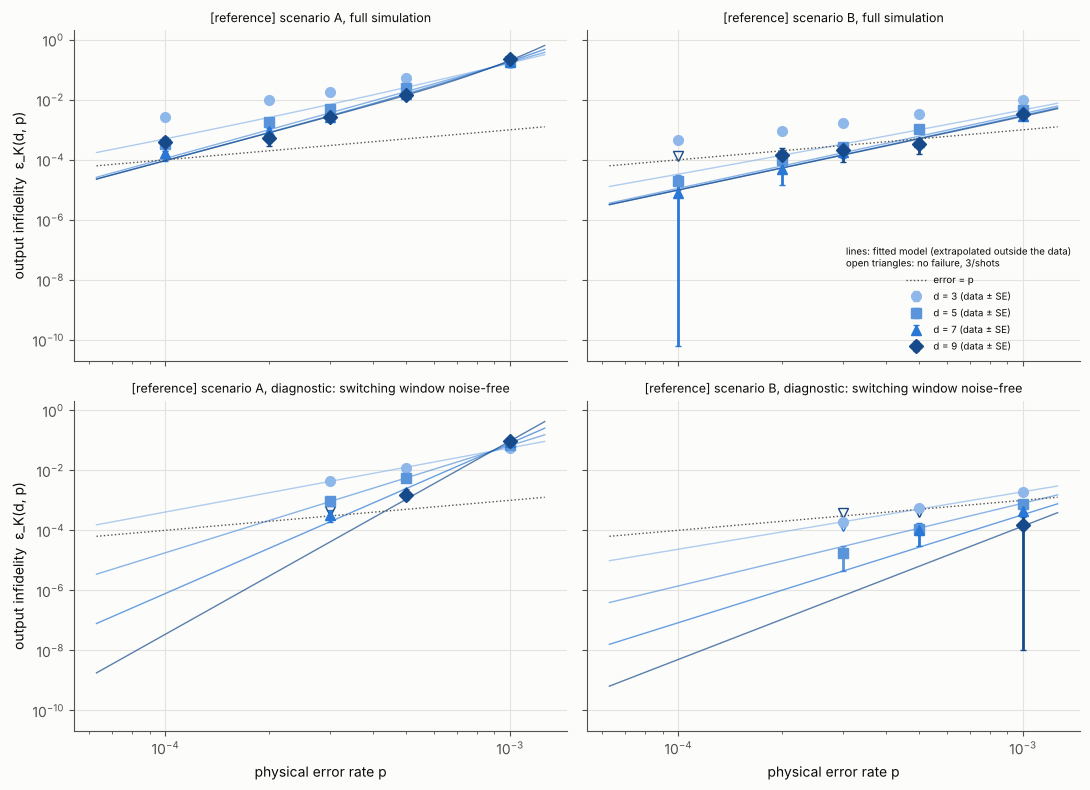

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True)
mk = {3: 'o', 5: 's', 7: '^', 9: 'D'}
cols = {3: '#8fb8ea', 5: '#5a95dc', 7: '#2a78d6', 9: '#174a8a'}
pp = np.logspace(-4.2, -2.9, 40)
for i, (w_, data) in enumerate((('noisy', main), ('quiet', quiet))):
    for j, s in enumerate(SCENARIOS):
        ax = axes[i, j]
        for d in sorted(data.d.unique()):
            m_ = data[(data.scenario == s) & (data.d == d)].sort_values('p')
            pos = m_[m_.n_fail > 0]; zero = m_[m_.n_fail == 0]
            ax.errorbar(pos.p, pos.eps, yerr=pos.stderr, fmt=mk.get(d, 'o'), color=cols.get(d, 'k'), capsize=2,
                        label=f'd = {d} (data ± SE)')
            if len(zero):
                ax.plot(zero.p, 3 / zero.shots, 'v', color=cols.get(d, 'k'), mfc='none')
            ax.plot(pp, [eps_K_model(s, d, x, w_) for x in pp], '-', color=cols.get(d, 'k'), lw=1, alpha=0.7)
        ax.plot(pp, pp, ':', color='#52514e', lw=1, label='error = p')
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f'[{DATA_MODE}] scenario {s}, ' + ('full simulation' if w_ == 'noisy' else
                     'diagnostic: switching window noise-free'), fontsize=9)
        if i == 1: ax.set_xlabel('physical error rate p')
        if j == 0: ax.set_ylabel('output infidelity  ε_K(d, p)')
axes[0, 1].legend(fontsize=7, title='lines: fitted model (extrapolated outside the data)\nopen triangles: no failure, 3/shots',
                  title_fontsize=7)
plt.tight_layout(); plt.savefig(f'{FIGURES}/d4_logical_error{OUT_SUFFIX}.png', dpi=150); plt.show()

### II-3. 資源（同じ回路から数える）
量子ビット数（ピーク）と時間ステップ数を、シミュレーションに使ったのと同じ回路（$\kappa_0=\kappa_{\rm in}=\kappa_{\rm out}=1$）から $d=3,\dots,11$ で数え、$d$ の多項式に当てはめて大きな $d$ に延長する（$d=3..11$ で直接数えた値と一致することを確認）。体積は「各ブロックで使う量子ビット数 × そのブロックの時間ステップ数」の和（雑音なしの最終ラウンドは含めない）。switch-out は $g$ の読み出し 1 ステップ＋補正 CZ の固定スケジュールの層数（測定結果によらない最悪値。シミュレーションの仮想的な遅延測定のモーメントは時間に数えない：`block_steps`）。
**感度**：FSC のラウンドを、検証済みの並列スケジュール（全検査を同時に測る 8 ステップ：`validation.ipynb` N10）で数えた場合の費用も `*_fsc8` として示す。**時間・体積だけの感度**であり、その誤り率はシミュレーションしていない（本研究の flux 復号器では並列スケジュールの方が $\varepsilon_K$ が大きくなったため、本番は 14 ステップのスケジュールでシミュレーションしている：`docs/methods.md` §4.1）。
**含めていない費用**：FSC から通常の回転表面符号パッチへの変換（未構成、[KZH] にも記述なし）、古典処理の待ち時間、フィードフォワードの $X$ 補正（雑音なし・時間 0 の理想化）。一方、測定スケジュールは最適化していない（FSC 14 ステップ/ラウンド、表面符号は 6）。前者は費用の過小評価、後者は過大評価の要因で、全体として一方向に「保守的」とは言えない。

In [43]:
def kobayashi_counts(d, fsc_steps=None):
    """fsc_steps: count every FSC round as this many time steps (sensitivity: 8 = the verified parallel
    schedule, validation N10) instead of the simulated 14-step schedule."""
    circ = D4SwitchingCircuit(d, d, d, d)
    vol, steps = 0, 0
    for blk in circ.blocks:
        if blk['name'][0] == 'FIN':
            continue
        code_ = blk['code']
        if code_ == 'FSC':
            active = set(circ.data_rb) | set(circ.anc['FSC'])
        elif code_ == 'D4':
            active = set(circ.data_all) | set(circ.anc['D4'])
        else:
            active = set(circ.data_all)                   # U and the switch-out
        n_steps = block_steps(circ, blk) if (fsc_steps is None or code_ != 'FSC' or blk['name'][0] == 'FIN') else fsc_steps
        vol += len(active) * n_steps
        steps += n_steps
    return dict(d=d, qubits=circ.nq, time_steps=steps, volume=vol, switch_out_steps=circ.so_steps)
KC = pd.DataFrame([kobayashi_counts(d) for d in (3, 5, 7, 9, 11)])
POLY = {k: np.polyfit(KC.d, KC[k], 3 if k == 'volume' else 2) for k in ('qubits', 'time_steps', 'volume')}
def kobayashi_cost(d):
    return {k: float(np.polyval(POLY[k], d)) for k in POLY}
KC['volume_poly'] = [kobayashi_cost(d)['volume'] for d in KC.d]
assert np.allclose(KC.volume_poly, KC.volume) and np.allclose([kobayashi_cost(d)['time_steps'] for d in KC.d], KC.time_steps)
KC8 = pd.DataFrame([kobayashi_counts(d, fsc_steps=8) for d in (3, 5, 7, 9, 11)])
POLY8 = {k: np.polyfit(KC8.d, KC8[k], 3 if k == 'volume' else 2) for k in ('qubits', 'time_steps', 'volume')}
def kobayashi_cost_fsc8(d):
    return {k: float(np.polyval(POLY8[k], d)) for k in POLY8}
KC['time_steps_fsc8'], KC['volume_fsc8'] = KC8.time_steps, KC8.volume
print({k: np.round(v, 2) for k, v in POLY.items()})
print('with 8-step FSC rounds:', {k: np.round(v, 2) for k, v in POLY8.items()})
KC

{'qubits': array([12.,  4., -1.]), 'time_steps': array([-0., 62., 21.]), 'volume': array([632., 454.,   8., -14.])}
with 8-step FSC rounds: {'qubits': array([12.,  4., -1.]), 'time_steps': array([-0., 50., 20.]), 'volume': array([536., 398.,  16., -13.])}


,d,qubits,time_steps,volume,switch_out_steps,volume_poly,time_steps_fsc8,volume_fsc8
0,3,119,207,21160,2,21160.0,170,18089
1,5,319,331,90376,2,90376.0,270,77017
2,7,615,455,239064,2,239064.0,370,203449
3,9,1007,579,497560,2,497560.0,470,423113
4,11,1495,703,896200,2,896200.0,570,761737


## 第III部 Litinski 方式（誤り予算モデル）
* **GoSC 15-to-1**（Fig. 17c：11 tiles × 11τ、1τ = $d$ cycles）：単一の距離 $d$。
* **GoSC 225-to-1**（Fig. 19：176 tiles × 15τ）：1 段目 $d_1$、2 段目 $d_2$。
* **Litinski 2019 15-to-1** $(d_X,d_Z,d_m)$ と **(15-to-1)×(15-to-1)**：Litinski（2019）の配置と費用式（公開コードと同じ）。
* 入力の魔法状態：確率 $p$ の Pauli 誤り（GoSC Sec. 4 の仮定）。出力誤りは事後選択後の不忠実度、時間は成功確率で割る（期待値）。
* 量子ビット数はデータ＋測定量子ビット（1 tile = $2d^2$）、時間は code cycle × `STEPS_PER_CYCLE`。
* 以下の「最小」は、この格子探索の**候補集合の中の最小**である。

In [44]:
import itertools as _it
def litinski_candidates(p, s):
    pl = PLOG[s]
    out = []
    for d in range(3, 52, 2):
        out.append(gosc_15to1(p, d, pl))
    lvl1 = {d1: run_steps(gosc_15to1_steps(p, d1, pl), out_qubit=4) for d1 in range(3, 26, 2)}
    for d1 in range(3, 26, 2):
        for d2 in range(d1, 52, 2):
            out.append(gosc_225to1(p, d1, d2, pl, level1=lvl1[d1]))
    for dx in range(5, 40, 2):
        for dz in range(3, dx + 1, 2):
            out.append(litinski2019_one_level(p, dx, dz, dz, pl))
    for dx, dz, dx2, dz2, nl1 in _it.product((7, 9, 11, 13), (3, 5), range(13, 42, 2), (5, 7, 9, 11, 13), (4, 6)):
        if dz < dx and dz2 < dx2:
            out.append(litinski2019_two_level(p, dx, dz, dz, dx2, dz2, dz2, nl1, pl))
    df = pd.DataFrame(out)
    df['family'] = df.protocol.str.extract(r'^(GoSC 15-to-1|GoSC 225-to-1|Litinski2019 \(15-to-1\)x|Litinski2019 \(15-to-1\))')[0]
    df['time_steps'] = df.cycles * STEPS_PER_CYCLE
    df['volume_steps'] = df.qubits * df.time_steps
    return df
import time as _time
t0 = _time.time()
LIT = {(s, p): litinski_candidates(p, s) for s in SCENARIOS for p in P_EVAL}
print('evaluated', sum(len(v) for v in LIT.values()), 'factory configurations in %.0f s' % (_time.time() - t0))

evaluated 16320 factory configurations in 97 s


## 第IV部 比較
### IV-1. 出力誤り vs 時空間体積
Litinski 方式は候補の中のパレート前線。Kobayashi 方式は $d=3,\dots,9$ がシミュレーション（マーカー）、線は II-2 のモデル（$d>9$ は外挿）：実線＝本来のシミュレーションのモデル（bulk＋窓の項）、点線＝診断（窓の雑音なし、bulk のみ）。点線は**限界ではなく**、「窓の誤りが無かったら」という診断である。

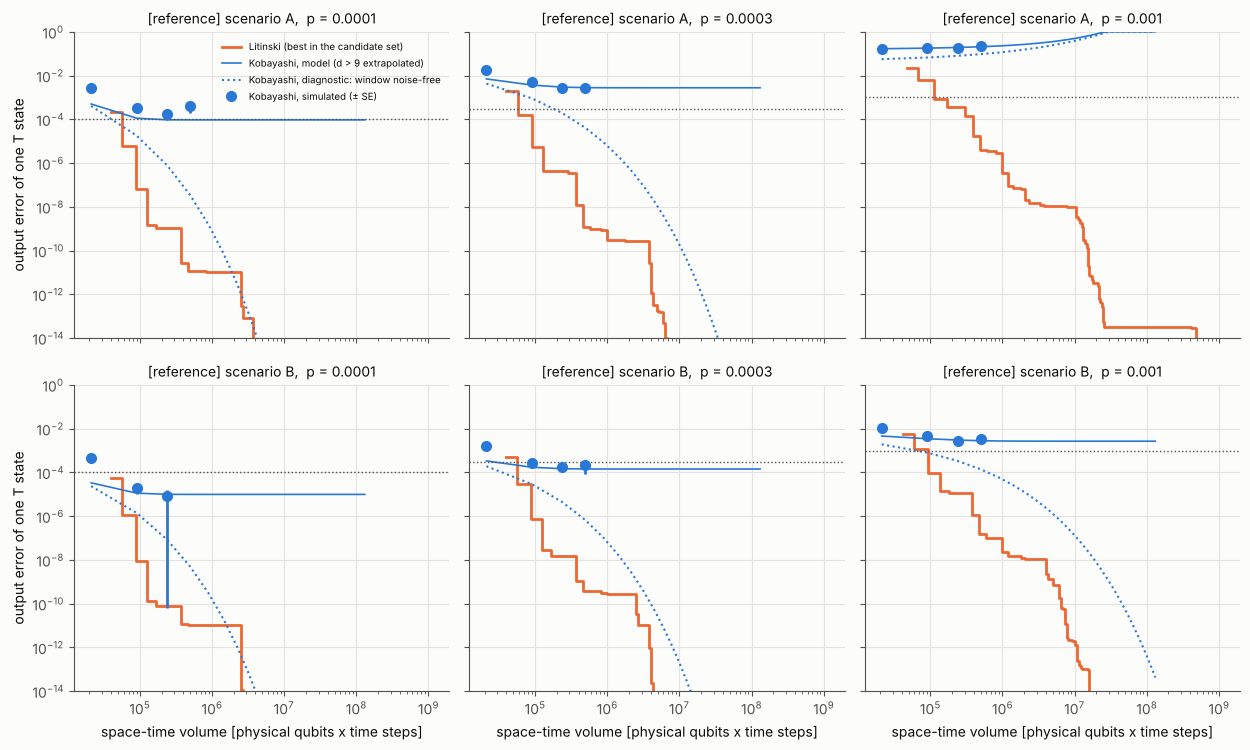

In [45]:
def pareto(df):
    df = df.sort_values('volume_steps')
    best, rows_ = np.inf, []
    for _, r in df.iterrows():
        if r.eps < best:
            best = r.eps; rows_.append(r)
    return pd.DataFrame(rows_)
show_p = [1e-4, 3e-4, 1e-3]
fig, axes = plt.subplots(2, len(show_p), figsize=(4.2 * len(show_p), 7.6), sharex=True, sharey=True)
ds = np.arange(3, 61, 2)
vk = np.array([kobayashi_cost(d)['volume'] for d in ds])
for i, s in enumerate(SCENARIOS):
    for j, p in enumerate(show_p):
        ax = axes[i, j]
        fr = pareto(LIT[(s, p)])
        ax.step(fr.volume_steps, fr.eps, where='post', color=C_LIT, label='Litinski (best in the candidate set)')
        ax.plot(vk, [eps_K_model(s, d, p) for d in ds], '-', color=C_KOB, lw=1.2, label='Kobayashi, model (d > 9 extrapolated)')
        ax.plot(vk, [eps_K_model(s, d, p, 'quiet') for d in ds], ':', color=C_KOB, lw=1.5,
                label='Kobayashi, diagnostic: window noise-free')
        sim = main[(main.scenario == s) & (main.p == p)]
        ax.errorbar([kobayashi_cost(d)['volume'] for d in sim.d], sim.eps, yerr=sim.stderr, fmt='o', color=C_KOB,
                    label='Kobayashi, simulated (± SE)')
        ax.axhline(p, color='#52514e', ls=':', lw=1)
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(1e-14, 1)
        ax.set_title(f'[{DATA_MODE}] scenario {s},  p = {p:g}', fontsize=10)
        if j == 0: ax.set_ylabel('output error of one T state')
        if i == 1: ax.set_xlabel('space-time volume [physical qubits x time steps]')
axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f'{FIGURES}/cost_comparison{OUT_SUFFIX}.png', dpi=150); plt.show()

### IV-2. 要求誤りごとの最小費用
* Litinski 方式：要求を満たす候補のうち体積最小のもの（候補集合内の最小）。
* Kobayashi 方式：要求を満たす最小の $d$（$d\le61$ の範囲で探索）。`kobayashi_*` は本来のシミュレーションのモデル（bulk＋窓の項、`main`）、`kobayashi_diag_*` は診断（窓の雑音なし）、感度として `kobayashi_W5_*`（窓の項を $d\ge5$ に当てはめた場合）と `kobayashi_altW_*`（窓の項の $d$ 依存を許したモデル）。
* `status`：ブートストラップの複製のうち、$d\le61$ で要求に届く割合が 84% 以上なら `reached`、16% 以下なら `not_reached_model`（このモデル・探索範囲では届かない。方式として不可能という意味ではない）、その間は `unresolved`。体積の `_16` / `_84` は届いた複製の体積の 16〜84% 範囲。
* `d_extrapolated`：選ばれた $d$ がシミュレーションした最大の $d$ を超える（$d$ 方向の外挿）。`p_extrapolated`：$p$ が bulk の当てはめに使った最小の $p$ より小さい（$p$ 方向の外挿）。外挿でなくても値はモデルによる推定であり、その要求誤りを直接観測したものではない。
* `kobayashi_diag_volume_fsc8`：同じ $d$ で FSC のラウンドを 8 ステップで数えた体積（時間だけの感度、II-3）。
* 各行に入力データの来歴（`data_mode`, `mc_sha256`, `cal_sha256`, `mc_run_ids`, ...）を記録する。

In [46]:
def dmin(s, p, t, w_='noisy', params=None, variant='main'):
    return next((d for d in range(3, 62, 2) if eps_K_model(s, d, p, w_, params, variant) <= t), None)
def kob_entry(s, p, t, w_, variant='main'):
    dc = dmin(s, p, t, w_, variant=variant)
    db = [dmin(s, p, t, w_, bt, variant) for bt in FITS[s]['boot']]
    reach = [d for d in db if d is not None]
    frac = len(reach) / len(db)
    status = 'reached' if frac >= 0.84 else 'not_reached_model' if frac <= 0.16 else 'unresolved'
    vols = [kobayashi_cost(d)['volume'] for d in reach]
    kc = kobayashi_cost(dc) if dc else None
    return dict(status=status, frac_reached=frac, d=dc if dc else '—',
                d_extrapolated=bool(dc is not None and dc > FITS[s]['d_max_data']),
                qubits=kc['qubits'] if kc else np.nan, time_steps=kc['time_steps'] if kc else np.nan,
                volume=kc['volume'] if kc else np.nan,
                volume_16=np.quantile(vols, 0.16) if vols else np.nan, volume_84=np.quantile(vols, 0.84) if vols else np.nan)
rows = []
for s in SCENARIOS:
    for p in P_EVAL:
        df = LIT[(s, p)]
        for t in TARGETS:
            ok = df[df.eps <= t]
            lit = ok.loc[ok.volume_steps.idxmin()] if len(ok) else None
            r = dict(scenario=s, p=p, target=t, p_extrapolated=bool(p < FITS[s]['p_min_bulk']),
                     litinski_protocol=lit.protocol if lit is not None else 'none in candidate set',
                     litinski_eps=lit.eps if lit is not None else np.nan,
                     litinski_qubits=lit.qubits if lit is not None else np.nan,
                     litinski_time_steps=lit.time_steps if lit is not None else np.nan,
                     litinski_volume=lit.volume_steps if lit is not None else np.nan)
            for pre, w_, var in (('kobayashi', 'noisy', 'main'), ('kobayashi_diag', 'quiet', 'main'),
                                 ('kobayashi_W5', 'noisy', 'W5'), ('kobayashi_altW', 'noisy', 'altW')):
                r.update({f'{pre}_{k}': v for k, v in kob_entry(s, p, t, w_, var).items()})
            rows.append(r)
CMP = pd.DataFrame(rows)
for pre in ('kobayashi', 'kobayashi_diag', 'kobayashi_W5', 'kobayashi_altW'):
    CMP[f'ratio_{pre}_over_litinski'] = CMP[f'{pre}_volume'] / CMP.litinski_volume
CMP['kobayashi_diag_volume_fsc8'] = [kobayashi_cost_fsc8(d)['volume'] if d != '—' else np.nan for d in CMP.kobayashi_diag_d]
CMP['ratio_kobayashi_diag_fsc8_over_litinski'] = CMP.kobayashi_diag_volume_fsc8 / CMP.litinski_volume
for k, v in PROV.items():
    CMP[k] = v
pd.set_option('display.max_colwidth', 40)
CMP[['scenario', 'p', 'target', 'litinski_protocol', 'litinski_volume', 'kobayashi_status', 'kobayashi_volume',
     'ratio_kobayashi_over_litinski', 'kobayashi_W5_status', 'kobayashi_altW_status', 'kobayashi_diag_status', 'kobayashi_diag_d', 'kobayashi_diag_d_extrapolated', 'p_extrapolated',
     'ratio_kobayashi_diag_over_litinski', 'kobayashi_diag_volume_16', 'kobayashi_diag_volume_84',
     'ratio_kobayashi_diag_fsc8_over_litinski']]

,scenario,p,target,litinski_protocol,litinski_volume,kobayashi_status,kobayashi_volume,ratio_kobayashi_over_litinski,kobayashi_W5_status,kobayashi_altW_status,kobayashi_diag_status,kobayashi_diag_d,kobayashi_diag_d_extrapolated,p_extrapolated,ratio_kobayashi_diag_over_litinski,kobayashi_diag_volume_16,kobayashi_diag_volume_84,ratio_kobayashi_diag_fsc8_over_litinski
0,A,0.0001,1.000000e-04,"Litinski2019 (15-to-1)_{5,3,3}",5.652679e+04,unresolved,239064.0,4.229216,not_reached_model,reached,reached,5,False,True,1.598817,90376.0,90376.00,1.362487
1,A,0.0001,1.000000e-06,"Litinski2019 (15-to-1)_{7,3,3}",8.776721e+04,not_reached_model,NaN,NaN,not_reached_model,unresolved,reached,7,False,True,2.723842,239064.0,239064.00,2.318053
2,A,0.0001,1.000000e-08,"Litinski2019 (15-to-1)_{9,3,3}",1.242564e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,11,True,True,7.212508,896200.0,896200.00,6.130366
3,A,0.0001,1.000000e-10,"Litinski2019 (15-to-1)_{11,5,5}",3.722678e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,13,True,True,3.936198,1465320.0,2235256.00,3.344498
4,A,0.0002,1.000000e-04,"Litinski2019 (15-to-1)_{5,3,3}",5.686821e+04,not_reached_model,NaN,NaN,not_reached_model,reached,reached,7,False,True,4.203825,239064.0,239064.00,3.577552
5,A,0.0002,1.000000e-06,"Litinski2019 (15-to-1)_{9,3,3}",1.254819e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,11,True,True,7.142067,896200.0,896200.00,6.070494
6,A,0.0002,1.000000e-08,"Litinski2019 (15-to-1)_{11,5,5}",3.727508e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,15,True,True,5.996649,2235256.0,2235256.00,5.093958
7,A,0.0002,1.000000e-10,"Litinski2019 (15-to-1)_{15,7,7}",9.842734e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,19,True,True,4.570803,4498920.0,6053320.00,3.881435
8,A,0.0003,1.000000e-04,"Litinski2019 (15-to-1)_{7,3,3}",8.956031e+04,not_reached_model,NaN,NaN,not_reached_model,reached,reached,9,False,False,5.555586,497560.0,497560.00,4.724336
9,A,0.0003,1.000000e-06,"Litinski2019 (15-to-1)_{9,3,3}",1.274665e+05,not_reached_model,NaN,NaN,not_reached_model,not_reached_model,reached,15,True,False,17.536032,2235256.0,2235256.00,14.896287


### IV-3. Kobayashi 方式が同じ体積に収まるために必要な改善（診断値）
要求誤りごとに、Litinski 方式の最小体積以下に収まる Kobayashi 方式の最大の $d$（$d_{\max}$）を求め、そこでの $\varepsilon_K(d_{\max},p)$（本来のシミュレーションのモデル）が要求誤りの何倍か（`required_improvement`）を示す。**現在の費用モデルを固定した場合の目安**であり、復号器やスケジュールを変えれば量子ビット数・時間も変わるので、この倍率の改善で必ず同じ費用に並ぶという保証ではない。

In [47]:
rows = []
for _, r in CMP.iterrows():
    if not np.isfinite(r.litinski_volume):
        continue
    ds_ = [d for d in range(3, 62, 2) if kobayashi_cost(d)['volume'] <= r.litinski_volume]
    dmax = max(ds_) if ds_ else None
    ek = eps_K_model(r.scenario, dmax, r.p) if dmax else np.nan
    rows.append(dict(scenario=r.scenario, p=r.p, target=r.target, litinski_volume=r.litinski_volume,
                     kobayashi_d_max=dmax, eps_K_at_d_max=ek, required_improvement=ek / r.target if dmax else np.nan))
IMP = pd.DataFrame(rows)
CMP = CMP.merge(IMP[['scenario', 'p', 'target', 'kobayashi_d_max', 'required_improvement']], how='left',
                on=['scenario', 'p', 'target'])
CMP.to_csv(f'{RESULTS}/cost_comparison{OUT_SUFFIX}.csv', index=False)
print('wrote', f'{RESULTS}/cost_comparison{OUT_SUFFIX}.csv', '| data_mode =', DATA_MODE)
IMP.round({'eps_K_at_d_max': 8, 'required_improvement': 1})

wrote results/cost_comparison.csv | data_mode = reference


,scenario,p,target,litinski_volume,kobayashi_d_max,eps_K_at_d_max,required_improvement
0,A,0.0001,1.000000e-04,5.652679e+04,3,0.000501,5.000000e+00
1,A,0.0001,1.000000e-06,8.776721e+04,3,0.000501,5.007000e+02
2,A,0.0001,1.000000e-08,1.242564e+05,5,0.000112,1.118880e+04
3,A,0.0001,1.000000e-10,3.722678e+05,7,0.000095,9.479609e+05
4,A,0.0002,1.000000e-04,5.686821e+04,3,0.002583,2.580000e+01
5,A,0.0002,1.000000e-06,1.254819e+05,5,0.001005,1.005300e+03
6,A,0.0002,1.000000e-08,3.727508e+05,7,0.000818,8.180390e+04
7,A,0.0002,1.000000e-10,9.842734e+05,11,0.000793,7.931591e+06
8,A,0.0003,1.000000e-04,8.956031e+04,3,0.007018,7.020000e+01
9,A,0.0003,1.000000e-06,1.274665e+05,5,0.003664,3.663800e+03


## 結論
本研究で構成した回路・スケジュール・復号器と、§II-2 のモデル（外挿を含む）に基づく結論。データ：`production-20261029T150244Z-88b3f1`（379 万ショット）。数値は `results/cost_comparison.csv`。

1. **改良（第 4 回レビュー後）の効果**：$U$ の直前の $Z$ 検査を 2 ラウンドにしたことで、切り替えの窓の単一故障の一次の係数は B で $d=5$：$3.1\to0.27$、$d=7$：$3.9\to0$ になり（`validation.ipynb` N5）、シナリオ B の出力誤りは $d$ とともに下がるようになった（$p=10^{-4}$ で $d=5$：$2\times10^{-5}$、$d=7$：$8\times10^{-6}$、$d=9$：22,360 ショットで失敗 0）。
2. **残る窓の項**：本来のシミュレーションと窓の雑音を除いた診断の差は、$d=7$ と $d=9$ でほぼ同じで、$p$ について 2 次以上（B で $\propto p^{2.4}$ 程度）。窓の誤りを 2 個以上の故障が起こす経路が残っている（窓の実効的な故障距離が $d$ とともに伸びていない）と解釈できる。これを $d$ によらない項とするモデル（`main`）では、Kobayashi 方式が要求に届くのは**シナリオ B・要求 $10^{-4}$・$p\le2\times10^{-4}$** で、体積は Litinski 方式（候補集合内の最小）の **0.54 倍**（$p=10^{-4}$、$d=3$）と 1.6 倍（$p=2\times10^{-4}$、$d=5$）。要求 $10^{-6}$ 以下には届かない（このモデルの範囲で）。窓の項の $d$ 依存を許した感度モデル（`altW`）では B・要求 $10^{-6}$・$p\le3\times10^{-4}$ で届くが、体積は 180〜860 倍。シナリオ A（アイドル雑音あり）はほぼ全ての条件で届かない。
3. **窓の雑音を除いた診断**（同じ復号器）：要求 $10^{-6}$ 以下で、Kobayashi 方式の体積は Litinski 方式の B で 1.8〜13 倍、A で 2.7〜39 倍（$p=10^{-3}$・A は届かない）。FSC のラウンドを検証済みの 8 ステップで数えると（時間だけの感度）B で 1.5〜11 倍。要求 $10^{-4}$ では B で 0.37〜9.6 倍（$p\le2\times10^{-4}$ で 1 未満）。診断は最適な復号器の性能の限界ではない。
4. **解釈**：Kobayashi 方式が有利になりうるのは、アイドル雑音が小さく、物理誤り率が低く（$p\lesssim2\times10^{-4}$）、要求精度が緩い（$\sim10^{-4}$）領域である。実用的な精度（$10^{-6}$ 以下）では、本研究の実装では切り替えの窓の 2 次の誤りと、D4 相のラウンドの長さ（体積 $\approx632d^3$）のため蒸留の方が体積が小さい。いずれも**本研究の回路・復号器と外挿の範囲での結果**であり、最適化された D4 方式に対する一般的な優劣を示すものではない。
5. **結論を変えうる要因**（未解決）：窓の 2 次の誤りを除く復号・回路（JIT decoder [Dav]、CCZ ガジェットの flag 化など）、回路レベルの誤りモデルを持つ flux 復号器（並列スケジュールを使えるようにする）、CCZ の実際の誤り率、FSC → 通常パッチの変換と Litinski 側の状態注入（どちらも未計上）、Litinski 側を回路レベルでシミュレーションした場合との差。